In [1]:

from pathlib import Path
import pandas as pd
import requests
import json

ROOT = Path.cwd()

projects = [
    ("E01", "Ecology", 13986364),
    ("E02", "Ecology", 20623700),
    ("E03", "Ecology", 21440293),
    ("E04", "Ecology", 20680549),
    ("E05", "Ecology", 22012975),
    ("H01", "Hydrology", 13756951),
    ("H02", "Hydrology", 10953060),
    ("H03", "Hydrology", 13214630),
    ("H04", "Hydrology", 14834541),
    ("H05", "Hydrology", 17700057),
]

records = []

for project_id, discipline, zenodo_id in projects:
    try:
        url = f"https://zenodo.org/api/records/{zenodo_id}"
        response = requests.get(url, timeout=40)
        response.raise_for_status()
        data = response.json()

        folder = ROOT / "repositories" / project_id
        folder.mkdir(parents=True, exist_ok=True)

        with open(folder / "metadata.json", "w", encoding="utf-8") as f:
            json.dump(data, f, indent=2)

        files = data.get("files", [])

        for file in files:
            records.append({
                "repository_id": project_id,
                "discipline": discipline,
                "title": data.get("metadata", {}).get("title", ""),
                "filename": file.get("key", ""),
                "size_mb": round(file.get("size", 0) / 1048576, 2),
                "download_url": file.get("links", {}).get("self", "")
            })

        print(project_id, "OK -", len(files), "files")

    except Exception as error:
        print(project_id, "ERROR:", error)

df = pd.DataFrame(records)
df.to_csv(ROOT / "results" / "archive_inventory.csv", index=False)

print("Total archive files:", len(df))
display(df)


E01 OK - 2 files
E02 OK - 1 files
E03 OK - 1 files
E04 OK - 12 files
E05 OK - 9 files
H01 OK - 1 files
H02 OK - 1 files
H03 OK - 1 files
H04 OK - 4 files
H05 OK - 2 files
Total archive files: 34


,repository_id,discipline,title,filename,size_mb,download_url
0,E01,Ecology,Data and code for manuscript: The performance ...,data.zip,78.63,https://zenodo.org/api/records/13986364/files/...
1,E01,Ecology,Data and code for manuscript: The performance ...,code.zip,3.52,https://zenodo.org/api/records/13986364/files/...
2,E02,Ecology,Characterizing the ecological niche of inserti...,is_niches.zip,63.22,https://zenodo.org/api/records/20623700/files/...
3,E03,Ecology,Ecological role structures community function ...,FermentomeII_package_code.zip,10.85,https://zenodo.org/api/records/21440293/files/...
4,E04,Ecology,Global lake synchrony dataset and ecological n...,Figure 1.rar,0.86,https://zenodo.org/api/records/20680549/files/...
5,E04,Ecology,Global lake synchrony dataset and ecological n...,Global_Lake_Chlorophyll_a_Time_Series.csv,0.67,https://zenodo.org/api/records/20680549/files/...
6,E04,Ecology,Global lake synchrony dataset and ecological n...,Permutation-based significance of synchrony tr...,0.00,https://zenodo.org/api/records/20680549/files/...
7,E04,Ecology,Global lake synchrony dataset and ecological n...,Global_Lake_Sediment_Pigments.csv,0.15,https://zenodo.org/api/records/20680549/files/...
8,E04,Ecology,Global lake synchrony dataset and ecological n...,Permutation-based significance of synchrony tr...,0.01,https://zenodo.org/api/records/20680549/files/...
9,E04,Ecology,Global lake synchrony dataset and ecological n...,Figures_data.CSV,0.25,https://zenodo.org/api/records/20680549/files/...


In [2]:

import requests
import hashlib
from pathlib import Path

selected = {
    "E01": "code.zip",
    "E02": "is_niches.zip",
    "E03": "FermentomeII_package_code.zip",
    "H01": "Data and codes.zip",
    "H02": "mpianforini/FloodSformer-v1.0.1.zip"
}

download_log = []

for project_id, filename in selected.items():
    match = df[
        (df["repository_id"] == project_id) &
        (df["filename"] == filename)
    ]

    if match.empty:
        print(project_id, "NOT FOUND")
        continue

    url = match.iloc[0]["download_url"]
    folder = ROOT / "repositories" / project_id
    folder.mkdir(parents=True, exist_ok=True)

    destination = folder / Path(filename).name
    sha256 = hashlib.sha256()

    print("Downloading:", project_id, filename)

    try:
        with requests.get(url, stream=True, timeout=(20, 120)) as r:
            r.raise_for_status()

            with open(destination, "wb") as f:
                for chunk in r.iter_content(1024 * 1024):
                    if chunk:
                        f.write(chunk)
                        sha256.update(chunk)

        download_log.append({
            "repository_id": project_id,
            "filename": filename,
            "sha256": sha256.hexdigest(),
            "status": "DOWNLOADED"
        })

        print("SAVED:", destination.name)

    except requests.RequestException as error:
        print("ERROR:", error)

pd.DataFrame(download_log).to_csv(
    ROOT / "results" / "download_log.csv",
    index=False
)

print("Downloads completed:", len(download_log))


Downloading: E01 code.zip
SAVED: code.zip
Downloading: E02 is_niches.zip
SAVED: is_niches.zip
Downloading: E03 FermentomeII_package_code.zip
SAVED: FermentomeII_package_code.zip
Downloading: H01 Data and codes.zip
SAVED: Data and codes.zip
Downloading: H02 mpianforini/FloodSformer-v1.0.1.zip
SAVED: FloodSformer-v1.0.1.zip
Downloads completed: 5


In [3]:

import zipfile

inspection = []

for project_id, filename in selected.items():
    archive = ROOT / "repositories" / project_id / Path(filename).name

    if not archive.exists():
        continue

    print("\n" + "=" * 55)
    print(project_id, archive.name)

    try:
        with zipfile.ZipFile(archive) as z:
            files = z.namelist()

            python_files = [
                f for f in files
                if f.lower().endswith((".py", ".ipynb"))
            ]

            setup_files = [
                f for f in files
                if Path(f).name.lower() in {
                    "requirements.txt",
                    "environment.yml",
                    "environment.yaml",
                    "pyproject.toml",
                    "setup.py",
                    "readme.md",
                    "readme.txt"
                }
            ]

            inspection.append({
                "repository_id": project_id,
                "python_files": len(python_files),
                "setup_files": len(setup_files),
                "python_examples": "; ".join(python_files[:5]),
                "setup_examples": "; ".join(setup_files[:5])
            })

            print("Python files:", len(python_files))
            print("Setup/README files:", len(setup_files))

            for f in python_files[:10]:
                print("PYTHON:", f)

            for f in setup_files[:10]:
                print("SETUP:", f)

    except zipfile.BadZipFile:
        print("Invalid ZIP archive")

inspection_df = pd.DataFrame(inspection)

inspection_df.to_csv(
    ROOT / "results" / "code_inspection.csv",
    index=False
)

display(inspection_df)



E01 code.zip
Python files: 76
Setup/README files: 2
PYTHON: code/deepSDM/predict.py
PYTHON: code/deepSDM/__init__.py
PYTHON: code/deepSDM/fit_predict_model.py
PYTHON: code/deepSDM/evaluate_old.py
PYTHON: code/deepSDM/train.py
PYTHON: code/deepSDM/evaluate.py
PYTHON: code/deepSDM/util/raster_sampling.py
PYTHON: code/deepSDM/util/__init__.py
PYTHON: code/deepSDM/util/gumbel_softmax_sampler.py
PYTHON: code/deepSDM/util/common.py
SETUP: code/requirements.txt
SETUP: code/README.md

E02 is_niches.zip
Python files: 114
Setup/README files: 1
PYTHON: is_niches/bin/1_data_processing/1_make_IS_table.py
PYTHON: is_niches/bin/1_data_processing/2_make_list_empty_genomes.py
PYTHON: is_niches/bin/1_data_processing/3_make_replicon_table.py
PYTHON: is_niches/bin/1_data_processing/4_make_genomes_table.py
PYTHON: is_niches/bin/1_data_processing/5_group_genomes_table_by_species.py
PYTHON: is_niches/bin/1_data_processing/6_extract_IS_seq_and_ins_site.py
PYTHON: is_niches/bin/2_is_distrib_across_genomes/fit

,repository_id,python_files,setup_files,python_examples,setup_examples
0,E01,76,2,code/deepSDM/predict.py; code/deepSDM/__init__...,code/requirements.txt; code/README.md
1,E02,114,1,is_niches/bin/1_data_processing/1_make_IS_tabl...,is_niches/README.md
2,E03,21,1,FermentomeII_package/05_invitro_voc/04_plot_to...,FermentomeII_package/README.md
3,H01,9,0,Data and codes/codes/Fig. 11_poyang_impact.py;...,
4,H02,42,1,mpianforini-FloodSformer-3a06265/docs/demo/Dem...,mpianforini-FloodSformer-3a06265/README.md


In [4]:

import zipfile
from pathlib import Path

targets = {
    "E01": "code.zip",
    "E02": "is_niches.zip",
    "E03": "FermentomeII_package_code.zip",
    "H02": "FloodSformer-v1.0.1.zip"
}

for project_id, filename in targets.items():
    archive = ROOT / "repositories" / project_id / filename

    if not archive.exists():
        print(f"{project_id}: archive not found")
        continue

    print("\n" + "=" * 60)
    print("REPOSITORY:", project_id)

    with zipfile.ZipFile(archive) as z:
        for name in z.namelist():
            basename = Path(name).name.lower()

            if basename in {
                "readme.md",
                "readme.txt",
                "requirements.txt",
                "environment.yml",
                "environment.yaml"
            }:
                info = z.getinfo(name)

                if info.file_size > 100000:
                    print("Skipping large document:", name)
                    continue

                content = z.read(name).decode(
                    "utf-8", errors="replace"
                )

                print("\nFILE:", name)
                print(content[:6000])



REPOSITORY: E01

FILE: code/requirements.txt
tqdm>=4.60.0
PyYAML>=5.4.1
pyarrow>=11.0.0
h5py>=3.7.0

scikit-learn>=1.3.0
statsmodels>=0.14.1
joblib==1.3.0

# for results visualisation
jupyter>=1.0.0
jupyterlab>=3.5.0
matplotlib>=3.6.2

gdal>=3.6.0
rasterio>=1.2.3
fiona>=1.8.21
shapely>=1.8.5

# --find-links https://download.pytorch.org/whl/torch_stable.html
# torch==1.12.1+cu113
# torchvision==0.13.1+cu113
timm>=0.4.12
tensorboard>=2.10.1

# # for Phylogenetic tree distance calculation
# dendropy>=4.5.2

# # for Microsoft Planetary Computer API
# rioxarray>=0.12.2
# pyproj>=3.4.0
# pystac-client>=0.5.1
# planetary-computer>=0.4.7
# stackstac>=0.4.3
# dask-gateway>=2022.10.0

FILE: code/README.md
# DeepSDM

Species Distribution Modeling (SDM) with deep learning. Work in progress, with many changes to come.

## Installation

### Yale HPC

1. Load Conda module
```bash
module load miniconda
```

2. Create environment and install requirements

```bash
conda create -n deepSDM python=3.8 -y


In [5]:

import ast
import zipfile

archive = ROOT / "repositories" / "H01" / "Data and codes.zip"

imports = set()

with zipfile.ZipFile(archive) as z:
    for name in z.namelist():
        if not name.lower().endswith(".py"):
            continue

        source = z.read(name).decode(
            "utf-8", errors="replace"
        )

        try:
            tree = ast.parse(source)

            for node in ast.walk(tree):
                if isinstance(node, ast.Import):
                    for alias in node.names:
                        imports.add(alias.name.split(".")[0])

                elif isinstance(node, ast.ImportFrom):
                    if node.module:
                        imports.add(node.module.split(".")[0])

        except SyntaxError:
            print("Syntax error during inspection:", name)

print("H01 imported modules:")
for module in sorted(imports):
    print("-", module)


Syntax error during inspection: Data and codes/codes/Fig. 8_multiyear_streamflow_impact.py
H01 imported modules:
- math
- matplotlib
- numpy
- pandas
- scipy
- seaborn
- sklearn
- statistics


In [1]:
from pathlib import Path
import zipfile

root = Path.cwd()

archives = {
    "E01": "code.zip",
    "E02": "is_niches.zip",
    "E03": "FermentomeII_package_code.zip",
    "H01": "Data and codes.zip",
    "H02": "FloodSformer-v1.0.1.zip"
}

for repo_id, filename in archives.items():
    archive = root / "repositories" / repo_id / filename

    print(f"\n{'=' * 50}")
    print(f"REPOSITORY: {repo_id}")

    if not archive.exists():
        print("Archive not found")
        continue

    with zipfile.ZipFile(archive) as z:
        docs = [
            name for name in z.namelist()
            if name.lower().endswith((
                "readme.md",
                "readme.txt",
                "requirements.txt",
                "environment.yml",
                "environment.yaml",
                "pyproject.toml"
            ))
        ]

        if not docs:
            print("No dependency documentation found.")
            continue

        for name in docs[:5]:
            info = z.getinfo(name)

            if info.file_size > 100_000:
                continue

            print(f"\nDOCUMENT: {name}")
            content = z.read(name).decode(
                "utf-8", errors="replace"
            )
            print(content[:3000])


REPOSITORY: E01

DOCUMENT: code/requirements.txt
tqdm>=4.60.0
PyYAML>=5.4.1
pyarrow>=11.0.0
h5py>=3.7.0

scikit-learn>=1.3.0
statsmodels>=0.14.1
joblib==1.3.0

# for results visualisation
jupyter>=1.0.0
jupyterlab>=3.5.0
matplotlib>=3.6.2

gdal>=3.6.0
rasterio>=1.2.3
fiona>=1.8.21
shapely>=1.8.5

# --find-links https://download.pytorch.org/whl/torch_stable.html
# torch==1.12.1+cu113
# torchvision==0.13.1+cu113
timm>=0.4.12
tensorboard>=2.10.1

# # for Phylogenetic tree distance calculation
# dendropy>=4.5.2

# # for Microsoft Planetary Computer API
# rioxarray>=0.12.2
# pyproj>=3.4.0
# pystac-client>=0.5.1
# planetary-computer>=0.4.7
# stackstac>=0.4.3
# dask-gateway>=2022.10.0

DOCUMENT: code/README.md
# DeepSDM

Species Distribution Modeling (SDM) with deep learning. Work in progress, with many changes to come.

## Installation

### Yale HPC

1. Load Conda module
```bash
module load miniconda
```

2. Create environment and install requirements

```bash
conda create -n deepSDM python

In [2]:
from pathlib import Path
import zipfile

archive = Path("repositories/E03/FermentomeII_package_code.zip")

with zipfile.ZipFile(archive) as z:
    for item in z.infolist():
        name = item.filename

        if name.lower().endswith(".py"):
            print(name)

FermentomeII_package/05_invitro_voc/04_plot_top_compounds.py
FermentomeII_package/05_invitro_voc/01_voc_module_reference_centred_analysis.py
FermentomeII_package/05_invitro_voc/03_plot_module_score_and_envelope.py
FermentomeII_package/05_invitro_voc/02_voc_individual_compound_test.py
FermentomeII_package/03_role_identity/02_plot_permanova.py
FermentomeII_package/03_role_identity/01_permanova.py
FermentomeII_package/06_insitu_traits/01_trait_tolerance_test.py
FermentomeII_package/02_global_pathway/02_pathway_permutation_test.py
FermentomeII_package/02_global_pathway/01_build_pathway_curation.py
FermentomeII_package/02_global_pathway/03_plot_global_pathway.py
FermentomeII_package/01_phaseB_voc_test/01_groupB_permanova.py
FermentomeII_package/07_insitu_voc/01_in_situ_voc_pipeline.py
FermentomeII_package/07_insitu_voc/02_assemble_figure_composite.py
FermentomeII_package/04_backbone_species/05_species_share.py
FermentomeII_package/04_backbone_species/02_module_investment.py
FermentomeII_pac

In [3]:
from pathlib import Path
import zipfile

archive = Path("repositories/E03/FermentomeII_package_code.zip")
folder = "FermentomeII_package/03_role_identity/"

with zipfile.ZipFile(archive) as z:
    print("=== FILES IN ANALYSIS FOLDER ===")

    for item in z.infolist():
        if item.filename.startswith(folder) and not item.is_dir():
            print(
                item.filename,
                "|",
                round(item.file_size / 1024, 2),
                "KB"
            )

    print("\n=== FIRST SCRIPT SOURCE ===")

    script = folder + "01_permanova.py"

    source = z.read(script).decode(
        "utf-8",
        errors="replace"
    )

    print(source[:12000])

=== FILES IN ANALYSIS FOLDER ===
FermentomeII_package/03_role_identity/02_plot_permanova.py | 5.17 KB
FermentomeII_package/03_role_identity/output/perturbation_design_table.csv | 2.37 KB
FermentomeII_package/03_role_identity/output/fig_role_identity.pdf | 20.26 KB
FermentomeII_package/03_role_identity/output/fig_role_identity.png | 229.68 KB
FermentomeII_package/03_role_identity/output/permanova_results.csv | 1.08 KB
FermentomeII_package/03_role_identity/data/ko_clr_matrix.csv | 115.59 KB
FermentomeII_package/03_role_identity/data/syncom_composition_long.csv | 7.11 KB
FermentomeII_package/03_role_identity/01_permanova.py | 11.96 KB

=== FIRST SCRIPT SOURCE ===
"""
Role versus identity PERMANOVA.

Tests whether functional composition among the eighteen primary perturbation
SynComs is structured by ecological role (which LAB role was perturbed,
dominant or subdominant) versus by species identity within a role, and
whether a secondary condition (no additional substitution, satellite
subst

In [4]:
from pathlib import Path
import zipfile
import hashlib
import json
import pandas as pd

root = Path.cwd()
archive = root / "repositories/E03/FermentomeII_package_code.zip"

folder = "FermentomeII_package/03_role_identity/"
required = [
    folder + "01_permanova.py",
    folder + "data/ko_clr_matrix.csv",
    folder + "data/syncom_composition_long.csv",
    folder + "output/perturbation_design_table.csv",
    folder + "output/permanova_results.csv",
]

with zipfile.ZipFile(archive) as z:
    missing = [name for name in required if name not in z.namelist()]

    if missing:
        raise FileNotFoundError(f"Missing archive entries: {missing}")

    manifest = []

    for name in required:
        data = z.read(name)

        manifest.append({
            "archive_path": name,
            "size_bytes": len(data),
            "sha256": hashlib.sha256(data).hexdigest()
        })

results = root / "results"
results.mkdir(exist_ok=True)

manifest_path = results / "E03_test1_manifest.csv"
pd.DataFrame(manifest).to_csv(manifest_path, index=False)

print("All five required files are present.")
print("Manifest saved:", manifest_path)
print(pd.DataFrame(manifest).to_string(index=False))

All five required files are present.
Manifest saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\E03_test1_manifest.csv
                                                              archive_path  size_bytes                                                           sha256
                     FermentomeII_package/03_role_identity/01_permanova.py       12244 38174e55d2a7cdd69c735cd3a8c24732db681b2330816fb107a9366965ec60ab
              FermentomeII_package/03_role_identity/data/ko_clr_matrix.csv      118361 a7aa4dad551fe126b33ab65d873fcb0f2765ee8a2a6d166d7b75ec300b8642d0
    FermentomeII_package/03_role_identity/data/syncom_composition_long.csv        7283 fbfd0197ee646216021936f607096c084952d81740d3dee9fea1951aa2e52271
FermentomeII_package/03_role_identity/output/perturbation_design_table.csv        2426 cbddb21d7eeebb799f043c8a3c7fc8951cc1df801debdd4af4cef2fc4dc9a8ff
        FermentomeII_package/03_role_identity/output/perma

In [5]:
from pathlib import Path
import zipfile

root = Path.cwd()
archive = root / "repositories/E03/FermentomeII_package_code.zip"

test_dir = root / "repositories/E03/test1"
source_dir = test_dir / "source"
reference_dir = test_dir / "reference"

source_dir.mkdir(parents=True, exist_ok=True)
reference_dir.mkdir(parents=True, exist_ok=True)

folder = "FermentomeII_package/03_role_identity/"

files = {
    "01_permanova.py": source_dir / "01_permanova.py",
    "data/ko_clr_matrix.csv": source_dir / "data/ko_clr_matrix.csv",
    "data/syncom_composition_long.csv": source_dir / "data/syncom_composition_long.csv",
    "output/perturbation_design_table.csv":
        reference_dir / "perturbation_design_table.csv",
    "output/permanova_results.csv":
        reference_dir / "permanova_results.csv"
}

with zipfile.ZipFile(archive) as z:
    for name, destination in files.items():
        destination.parent.mkdir(parents=True, exist_ok=True)
        destination.write_bytes(z.read(folder + name))

print("TEST 1 READY")
print("Source:", source_dir)
print("Reference outputs:", reference_dir)

TEST 1 READY
Source: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\repositories\E03\test1\source
Reference outputs: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\repositories\E03\test1\reference


In [6]:
from pathlib import Path
import pandas as pd
import numpy as np
import json

root = Path.cwd()
test = root / "repositories/E03/test1"

reference = test / "reference"
generated = test / "run1/output"

files = [
    "permanova_results.csv",
    "perturbation_design_table.csv"
]

report = []

for filename in files:
    old = pd.read_csv(reference / filename)
    new = pd.read_csv(generated / filename)

    same_shape = old.shape == new.shape
    same_columns = list(old.columns) == list(new.columns)

    differences = []

    if same_shape and same_columns:
        for col in old.columns:
            a = old[col]
            b = new[col]

            if pd.api.types.is_numeric_dtype(a) and pd.api.types.is_numeric_dtype(b):
                equal = np.isclose(
                    a.to_numpy(dtype=float),
                    b.to_numpy(dtype=float),
                    rtol=1e-6,
                    atol=1e-8,
                    equal_nan=True
                )
            else:
                equal = (
                    a.fillna("<MISSING>").astype(str).to_numpy()
                    == b.fillna("<MISSING>").astype(str).to_numpy()
                )

            if not equal.all():
                differences.append({
                    "column": col,
                    "different_rows": int((~equal).sum())
                })

    passed = same_shape and same_columns and not differences

    report.append({
        "file": filename,
        "same_shape": same_shape,
        "same_columns": same_columns,
        "numerically_equivalent": passed,
        "differences": differences
    })

    print(f"\nFILE: {filename}")
    print("Same shape:", same_shape)
    print("Same columns:", same_columns)
    print("Equivalent values:", passed)
    print("Differences:", differences)

output = root / "results/E03_test1_comparison.json"

output.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

print("\nComparison report saved:", output)


FILE: permanova_results.csv
Same shape: True
Same columns: True
Equivalent values: True
Differences: []

FILE: perturbation_design_table.csv
Same shape: True
Same columns: True
Equivalent values: True
Differences: []

Comparison report saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\E03_test1_comparison.json


In [7]:
from pathlib import Path
import zipfile

archive = Path("repositories/H01/Data and codes.zip")

with zipfile.ZipFile(archive) as z:
    print("=== HYDROLOGY ARCHIVE CONTENTS ===")

    for item in z.infolist():
        if not item.is_dir():
            print(
                item.filename,
                "|",
                round(item.file_size / 1024, 2),
                "KB"
            )

    print("\n=== PYTHON SCRIPT IMPORTS ===")

    for name in z.namelist():
        if name.lower().endswith(".py"):
            print(f"\nSCRIPT: {name}")

            source = z.read(name).decode(
                "utf-8", errors="replace"
            )

            for line in source.splitlines():
                line = line.strip()
                if line.startswith(("import ", "from ")):
                    print(line)

=== HYDROLOGY ARCHIVE CONTENTS ===
Data and codes/codes/Fig. 11_poyang_impact.py | 5.6 KB
Data and codes/codes/Fig. 2_monthly_streamflow.py | 3.81 KB
Data and codes/codes/Fig. 3_daily_streamflow.py | 5.29 KB
Data and codes/codes/Fig. 6_irrigation.py | 2.54 KB
Data and codes/codes/Fig. 7_poyang_simulation.py | 3.45 KB
Data and codes/codes/Fig. 8_multiyear_streamflow_impact.py | 18.24 KB
Data and codes/codes/Fig. 9_flood.py | 2.99 KB
Data and codes/codes/Fig. S5_flood_events.py | 3.28 KB
Data and codes/codes/Fig. S5_flood_impact.py | 3.36 KB
Data and codes/data/daily_streamflow_HUM.xlsx | 289.61 KB
Data and codes/data/daily_streamflow_NAT.xlsx | 360.18 KB
Data and codes/data/daily_streamflow_OBS.xlsx | 265.26 KB
Data and codes/data/daily_streamflow_RES.xlsx | 277.55 KB
Data and codes/data/Irrigation.xlsx | 13.07 KB
Data and codes/data/monthly_streamflow_HUM.xlsx | 36.16 KB
Data and codes/data/monthly_streamflow_NAT.xlsx | 47.41 KB
Data and codes/data/monthly_streamflow_OBS.xlsx | 44.54 K

In [8]:
from pathlib import Path
import zipfile

archive = Path("repositories/H01/Data and codes.zip")

targets = [
    "Data and codes/readme_说明.txt",
    "Data and codes/codes/Fig. 2_monthly_streamflow.py"
]

with zipfile.ZipFile(archive) as z:
    for name in targets:
        print("\n" + "=" * 65)
        print("FILE:", name)
        print("=" * 65)

        raw = z.read(name)

        if name.endswith(".txt"):
            for encoding in ["utf-8-sig", "gb18030", "latin-1"]:
                try:
                    content = raw.decode(encoding)
                    break
                except UnicodeDecodeError:
                    continue
        else:
            content = raw.decode("utf-8", errors="replace")

        print(content)


FILE: Data and codes/readme_说明.txt
The code folder contains python codes to generate the figures of the paper.

The data folder contains daily/monthly streamflow, lake water level, and irrigation water data to generate the analysis and figures in the paper, where OBS, NAT, RES and HUM represent in-situ observations, model simulations under nature scenario, model simulations under reservoir scenario and model simulations under all human activities, respectively.

Please note that the authors are not allowed to share the in-situ water storage data of the 90 reservoirs as presented in the paper, so they are excluded from this data package.

Contact: Ningpeng Dong, [EMAIL_REDACTED] 

FILE: Data and codes/codes/Fig. 2_monthly_streamflow.py
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams["font.family"] = "Times New Roman"
plt.rcParams["font.size"] = 10

def calculate_nse(observed, simulated):
    if len(observed) == 0 or len(simulated) == 0:
        retu

In [10]:
%pip install openpyxl


   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   ---------------------------------------- 2/2 [openpyxl]

Note: you may need to restart the kernel to use updated packages.


In [11]:
import openpyxl

print("openpyxl version:", openpyxl.__version__)
print("Installation successful!")

openpyxl version: 3.1.5
Installation successful!


In [12]:
from pathlib import Path
from io import BytesIO
import zipfile
import pandas as pd

archive = Path("repositories/H01/Data and codes.zip")

targets = [
    "monthly_streamflow_NAT.xlsx",
    "monthly_streamflow_HUM.xlsx",
    "monthly_streamflow_OBS.xlsx"
]

with zipfile.ZipFile(archive) as z:
    for filename in targets:
        path = "Data and codes/data/" + filename

        print("\n" + "=" * 55)
        print("FILE:", filename)

        content = BytesIO(z.read(path))

        workbook = pd.ExcelFile(content)

        print("Sheets:", workbook.sheet_names)

        df = pd.read_excel(
            workbook,
            sheet_name=workbook.sheet_names[0],
            index_col=0
        )

        print("Shape:", df.shape)
        print("Columns:", list(df.columns)[:10])
        print("Index type:", type(df.index).__name__)
        print("First rows:")
        print(df.head(3).to_string())


FILE: monthly_streamflow_NAT.xlsx
Sheets: ['Sheet1']
Shape: (384, 10)
Columns: ['xiantao', 'yichang', 'waizhou', 'datong', 'gaochang', 'pingshan', 'beibei', 'cuntan', 'wulong', 'zhutuo']
Index type: DatetimeIndex
First rows:
                xiantao      yichang      waizhou        datong    gaochang     pingshan      beibei       cuntan       wulong       zhutuo
日期                                                                                                                                         
1991-01-01   368.741935  4148.838710  1744.838710  13993.645161  544.064516  1273.161290  459.935484  3058.741935   988.193548  2499.000000
1991-02-01   532.000000  4514.107143  1646.178571  19132.500000  542.214286  1056.321429  504.428571  2923.321429  1180.857143  2301.607143
1991-03-01  1016.387097  4081.741935  3883.322581  22167.419355  705.225806  1045.838710  520.935484  2789.677419   907.419355  2205.612903

FILE: monthly_streamflow_HUM.xlsx
Sheets: ['Sheet1']
Shape: (384, 10)
Col

In [13]:
from pathlib import Path
import zipfile
import hashlib

archive = Path("repositories/H01/Data and codes.zip")
test = Path("repositories/H01/test1")
source_dir = test / "source"

source_dir.mkdir(parents=True, exist_ok=True)

script_name = "Fig. 2_monthly_streamflow.py"
archive_path = "Data and codes/codes/" + script_name

with zipfile.ZipFile(archive) as z:
    original_bytes = z.read(archive_path)

destination = source_dir / script_name
destination.write_bytes(original_bytes)

sha256 = hashlib.sha256(original_bytes).hexdigest()

print("Script extracted:", destination)
print("SHA256:", sha256)
print("Original source preserved:", destination.exists())

Script extracted: repositories\H01\test1\source\Fig. 2_monthly_streamflow.py
SHA256: 59d527abc3aa5505be3a8ab520941840f2773e069b86bec4b2abd1e5e46d62d2
Original source preserved: True


In [14]:
from pathlib import Path
import zipfile
import shutil
import hashlib
import json

archive = Path("repositories/H01/Data and codes.zip")
test = Path("repositories/H01/test1")
recovery = test / "recovery1"
data_dir = recovery / "data"
output_dir = recovery / "output"

data_dir.mkdir(parents=True, exist_ok=True)
output_dir.mkdir(parents=True, exist_ok=True)

original = test / "source/Fig. 2_monthly_streamflow.py"
modified = recovery / original.name

shutil.copy2(original, modified)

files = [
    "monthly_streamflow_NAT.xlsx",
    "monthly_streamflow_HUM.xlsx",
    "monthly_streamflow_OBS.xlsx"
]

with zipfile.ZipFile(archive) as z:
    for filename in files:
        source = "Data and codes/data/" + filename
        (data_dir / filename).write_bytes(z.read(source))

source_code = modified.read_text(encoding="utf-8")

# Replace the three original absolute paths in the recovery copy.
# This preserves the original source file.
import re

pattern = r"pd\.read_excel\('E:/All1study/1irragation/compute/[^']+\.xlsx', index_col=0\)"

matches = list(re.finditer(pattern, source_code))

assert len(matches) == 3, (
    f"Expected 3 original Excel references, found {len(matches)}"
)

replacement_paths = [
    "data/monthly_streamflow_NAT.xlsx",
    "data/monthly_streamflow_HUM.xlsx",
    "data/monthly_streamflow_OBS.xlsx"
]

for match, new_path in reversed(list(zip(matches, replacement_paths))):
    replacement = f"pd.read_excel('{new_path}', index_col=0)"
    source_code = (
        source_code[:match.start()]
        + replacement
        + source_code[match.end():]
    )

# Save the figure instead of opening an interactive window.
assert source_code.count("plt.show()") == 1

source_code = source_code.replace(
    "plt.show()",
    "plt.savefig('output/Fig_2_monthly_streamflow.png', dpi=150)"
)

modified.write_text(source_code, encoding="utf-8")

print("RECOVERY COPY CREATED")
print("Original:", original)
print("Modified:", modified)
print("Datasets:", len(files))
print("Original SHA256:", hashlib.sha256(original.read_bytes()).hexdigest())
print("Modified SHA256:", hashlib.sha256(modified.read_bytes()).hexdigest())
print("Original unchanged:", original.read_bytes() != modified.read_bytes())

RECOVERY COPY CREATED
Original: repositories\H01\test1\source\Fig. 2_monthly_streamflow.py
Modified: repositories\H01\test1\recovery1\Fig. 2_monthly_streamflow.py
Datasets: 3
Original SHA256: 59d527abc3aa5505be3a8ab520941840f2773e069b86bec4b2abd1e5e46d62d2
Modified SHA256: 6ea4268157da14315c65d256dd0a78bfa48706676feb0b67135cf5ea857b6483
Original unchanged: True


In [15]:
from pathlib import Path
import zipfile
import pandas as pd

root = Path("repositories")

archive_ids = [
    "E01", "E02", "E03",
    "H01", "H02", "H03", "H05", "H06"
]

records = []

for archive_id in archive_ids:
    folder = root / archive_id
    archives = list(folder.glob("*.zip"))

    if not archives:
        records.append({
            "Archive ID": archive_id,
            "ZIP File": "NOT FOUND",
            "Python Files": 0,
            "Datasets": 0,
            "Documentation": 0,
            "Status": "MISSING"
        })
        continue

    for archive in archives:
        try:
            with zipfile.ZipFile(archive) as z:
                names = [
                    name for name in z.namelist()
                    if not name.endswith("/")
                ]

                python_files = [
                    name for name in names
                    if name.lower().endswith((".py", ".ipynb"))
                ]

                datasets = [
                    name for name in names
                    if name.lower().endswith(
                        (".csv", ".xlsx", ".xls", ".nc", ".parquet")
                    )
                ]

                documentation = [
                    name for name in names
                    if any(
                        keyword in Path(name).name.lower()
                        for keyword in [
                            "readme", "requirements", "environment"
                        ]
                    )
                ]

                records.append({
                    "Archive ID": archive_id,
                    "ZIP File": archive.name,
                    "Python Files": len(python_files),
                    "Datasets": len(datasets),
                    "Documentation": len(documentation),
                    "Status": "SCREENED"
                })

        except Exception as error:
            records.append({
                "Archive ID": archive_id,
                "ZIP File": archive.name,
                "Python Files": 0,
                "Datasets": 0,
                "Documentation": 0,
                "Status": f"ERROR: {error}"
            })

df = pd.DataFrame(records)

display(df)

Path("results").mkdir(exist_ok=True)

df.to_csv(
    "results/batch_archive_screening.csv",
    index=False
)

print("BATCH SCREENING COMPLETE")
print("Archives screened:", (df["Status"] == "SCREENED").sum())
print("Total Python files:", df["Python Files"].sum())
print("Results saved: results/batch_archive_screening.csv")

,Archive ID,ZIP File,Python Files,Datasets,Documentation,Status
0,E01,code.zip,76,0,2,SCREENED
1,E02,is_niches.zip,114,5,1,SCREENED
2,E03,FermentomeII_package_code.zip,21,52,1,SCREENED
3,H01,Data and codes.zip,9,10,1,SCREENED
4,H02,FloodSformer-v1.0.1.zip,42,0,1,SCREENED
5,H03,Hydrological-controls---Code-and-Data-Hydrolog...,1,1,1,SCREENED
6,H05,neuralhydrology-v.1.2.3.zip,70,1,6,SCREENED
7,H06,S4D_rainfall_runoff_simulations.zip,97,0,11,SCREENED


BATCH SCREENING COMPLETE
Archives screened: 8
Total Python files: 430
Results saved: results/batch_archive_screening.csv


In [16]:
from pathlib import Path
import zipfile
import pandas as pd

records = []

for archive_id in ["E04", "E05", "E06"]:
    folder = Path("repositories") / archive_id

    for archive in folder.glob("*.zip"):
        try:
            with zipfile.ZipFile(archive) as z:
                names = [
                    n for n in z.namelist()
                    if not n.endswith("/")
                ]

                scripts = [
                    n for n in names
                    if n.lower().endswith((".py", ".ipynb"))
                ]

                data = [
                    n for n in names
                    if n.lower().endswith(
                        (".csv", ".xlsx", ".nc", ".tif", ".shp")
                    )
                ]

                records.append({
                    "Archive": archive_id,
                    "ZIP": archive.name,
                    "Python files": len(scripts),
                    "Datasets": len(data),
                    "Sample scripts": scripts[:3]
                })

        except Exception as e:
            print(archive_id, archive.name, "ERROR:", e)

df_new = pd.DataFrame(records)
display(df_new)

Path("results").mkdir(exist_ok=True)
df_new.to_csv(
    "results/new_ecology_archive_screening.csv",
    index=False
)

,Archive,ZIP,Python files,Datasets,Sample scripts
0,E04,code.zip,76,0,"[code/deepSDM/predict.py, code/deepSDM/__init_..."
1,E04,data.zip,0,15,[]
2,E06,Code_Figures.zip,26,0,[Code_Figures/FigS10_MangroveDisturbanceRates....


In [17]:
from pathlib import Path
import hashlib
import zipfile

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

e01 = Path("repositories/E01/code.zip")
e04 = Path("repositories/E04/code.zip")

print("=== DUPLICATE CHECK ===")

if e01.exists() and e04.exists():
    print("E01 SHA256:", sha256(e01))
    print("E04 SHA256:", sha256(e04))
    print("IDENTICAL:", sha256(e01) == sha256(e04))

print("\n=== NEW ECOLOGY ARCHIVES ===")

for archive_id in ["E04", "E05", "E06"]:
    folder = Path("repositories") / archive_id
    print(f"\n{archive_id}:")

    if not folder.exists():
        print("Folder missing")
        continue

    for file in folder.iterdir():
        if file.is_file():
            print(" -", file.name, round(file.stat().st_size / 1024**2, 2), "MB")

print("\n=== POSSIBLE MISSING DOWNLOADS ===")

downloads = Path.home() / "Downloads"

for file in downloads.glob("*.zip"):
    name = file.name.lower()
    if any(word in name for word in [
        "observer", "biodiversity", "redundancy",
        "figures", "mangrove", "code_data"
    ]):
        print(file.name)

=== DUPLICATE CHECK ===
E01 SHA256: 5965a9254dfe5aba382f8c6b28508955edae407d1e94e3185c382c8654a4b439
E04 SHA256: 5965a9254dfe5aba382f8c6b28508955edae407d1e94e3185c382c8654a4b439
IDENTICAL: True

=== NEW ECOLOGY ARCHIVES ===

E04:
 - code.zip 3.52 MB
 - data.zip 78.63 MB
 - metadata.json 0.01 MB

E05:
 - metadata.json 0.01 MB

E06:
 - Code_Figures.zip 40.75 MB

=== POSSIBLE MISSING DOWNLOADS ===
Code_Figures.zip


In [18]:
from pathlib import Path
import zipfile

archives = {
    "E04_DATA": Path("repositories/E04/data.zip"),
    "E06_CODE": Path("repositories/E06/Code_Figures.zip")
}

for archive_id, archive_path in archives.items():

    print("\n" + "=" * 70)
    print("ARCHIVE:", archive_id)

    if not archive_path.exists():
        print("FILE NOT FOUND")
        continue

    with zipfile.ZipFile(archive_path) as z:
        files = [
            n for n in z.namelist()
            if not n.endswith("/")
        ]

        python_files = [
            n for n in files
            if n.lower().endswith((".py", ".ipynb"))
        ]

        data_files = [
            n for n in files
            if n.lower().endswith(
                (".csv", ".xlsx", ".nc", ".tif", ".tiff",
                 ".shp", ".npy", ".npz", ".pkl")
            )
        ]

        print("Total files:", len(files))
        print("Python files:", len(python_files))
        print("Data files:", len(data_files))

        print("\nPYTHON FILES:")
        for name in python_files[:30]:
            print(" -", name)

        print("\nDATA FILES:")
        for name in data_files[:20]:
            print(" -", name)

        print("\nDOCUMENTATION:")
        for name in files:
            if any(
                keyword in Path(name).name.lower()
                for keyword in ["readme", "requirements", "environment"]
            ):
                print(" -", name)


ARCHIVE: E04_DATA
Total files: 2315
Python files: 0
Data files: 15

PYTHON FILES:

DATA FILES:
 - data/taxa/ants/species.csv
 - data/taxa/ants/covariates.csv
 - data/taxa/ants/observations.csv
 - data/taxa/butterflies/species.csv
 - data/taxa/butterflies/covariates.csv
 - data/taxa/butterflies/observations.csv
 - data/taxa/reptiles/species.csv
 - data/taxa/reptiles/covariates.csv
 - data/taxa/reptiles/observations.csv
 - data/taxa/mammals/species.csv
 - data/taxa/mammals/covariates.csv
 - data/taxa/mammals/observations.csv
 - data/taxa/amphibians/species.csv
 - data/taxa/amphibians/covariates.csv
 - data/taxa/amphibians/observations.csv

DOCUMENTATION:

ARCHIVE: E06_CODE
Total files: 27
Python files: 26
Data files: 0

PYTHON FILES:
 - Code_Figures/FigS10_MangroveDisturbanceRates.ipynb
 - Code_Figures/FigS11_DisturbanceTrends40Years.ipynb
 - Code_Figures/FigS12_RecentDisturbanceRates.ipynb
 - Code_Figures/FigS13_RecentLoss.ipynb
 - Code_Figures/FigS14_RelativeChangeClosedMangrove.ipynb

In [19]:
from pathlib import Path
import zipfile
import json
import re
import pandas as pd

archive = Path("repositories/E06/Code_Figures.zip")
records = []

with zipfile.ZipFile(archive) as z:
    notebooks = [
        name for name in z.namelist()
        if name.endswith(".ipynb")
    ]

    for name in notebooks:
        try:
            notebook = json.loads(z.read(name))
            cells = notebook.get("cells", [])

            code = "\n".join(
                "".join(cell.get("source", []))
                for cell in cells
                if cell.get("cell_type") == "code"
            )

            imports = sorted(set(re.findall(
                r"^\s*(?:import|from)\s+([A-Za-z_][\w.]*)",
                code,
                re.MULTILINE
            )))

            data_patterns = [
                ".csv", ".xlsx", ".tif", ".tiff",
                ".shp", ".nc", ".npy", ".pkl",
                "read_csv", "read_excel",
                "read_file", "open_dataset",
                "ee.Initialize", "earthengine"
            ]

            found_patterns = [
                pattern for pattern in data_patterns
                if pattern.lower() in code.lower()
            ]

            executed_cells = sum(
                cell.get("execution_count") is not None
                for cell in cells
                if cell.get("cell_type") == "code"
            )

            records.append({
                "Notebook": Path(name).name,
                "Code cells": sum(
                    c.get("cell_type") == "code"
                    for c in cells
                ),
                "Previously executed cells": executed_cells,
                "Imports": ", ".join(imports[:12]),
                "Data indicators": ", ".join(found_patterns)
            })

        except Exception as error:
            print("ERROR:", name, error)

df_e06 = pd.DataFrame(records)

display(df_e06)

Path("results").mkdir(exist_ok=True)

df_e06.to_csv(
    "results/E06_notebook_feasibility.csv",
    index=False
)

print("Notebooks inspected:", len(df_e06))
print("Saved: results/E06_notebook_feasibility.csv")


,Notebook,Code cells,Previously executed cells,Imports,Data indicators
0,FigS10_MangroveDisturbanceRates.ipynb,3,2,"ZhenPlot, cartopy.crs, geemap, geopandas, impo...",".csv, .shp, read_csv, read_file"
1,FigS11_DisturbanceTrends40Years.ipynb,3,1,"ZhenPlot, cartopy.crs, geemap, geopandas, matp...",".csv, .shp, read_csv, read_file"
2,FigS12_RecentDisturbanceRates.ipynb,3,2,"ZhenPlot, cartopy.crs, geemap, geopandas, matp...",".csv, .shp, read_csv, read_file"
3,FigS13_RecentLoss.ipynb,4,4,"ZhenPlot, cartopy.crs, cartopy.feature, ee, ge...",".shp, read_file, ee.Initialize"
4,FigS14_RelativeChangeClosedMangrove.ipynb,3,1,"ZhenPlot, cartopy.crs, geopandas, matplotlib.g...",".csv, .shp, read_csv, read_file"
5,FigS16_ComparisonGMW.ipynb,2,2,"ZhenPlot, cartopy.crs, geopandas, matplotlib.g...",".shp, read_file"
6,FigS18_LandsatQuantile.ipynb,2,2,"ZhenPlot, cartopy.crs, cartopy.mpl.ticker, geo...",.tif
7,FigS19-S20_CompositeYears.ipynb,3,2,"ZhenPlot, cartopy.crs, geopandas, matplotlib.c...",".shp, read_file"
8,FigS21_PixelCount1980s.ipynb,2,0,"matplotlib.pyplot, rioxarray",.tif
9,FigS23_ThinCloudmask.ipynb,3,1,"ZhenPlot, cartopy.crs, cartopy.mpl.ticker, geo...",".csv, .tif, .shp, read_csv, read_file"


Notebooks inspected: 25
Saved: results/E06_notebook_feasibility.csv


In [20]:
from pathlib import Path
import zipfile
import json

archive = Path("repositories/E06/Code_Figures.zip")

target = "Code_Figures/FigS8_SchematicFigure.ipynb"

with zipfile.ZipFile(archive) as z:
    notebook = json.loads(z.read(target))

print("NOTEBOOK:", target)
print("=" * 70)

for index, cell in enumerate(notebook.get("cells", []), start=1):
    print(f"\nCELL {index} — {cell.get('cell_type', '').upper()}")
    print("-" * 60)

    source = "".join(cell.get("source", []))
    print(source[:12000])

print("\nNOTEBOOK METADATA:")
print(json.dumps(notebook.get("metadata", {}), indent=2)[:3000])

NOTEBOOK: Code_Figures/FigS8_SchematicFigure.ipynb

CELL 1 — CODE
------------------------------------------------------------
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from ZhenPlot import *

plt.rcParams.update({'font.family':'arial'})
plt.rcParams['font.sans-serif'] = ['arial']

%config InlineBackend.figure_format = 'retina'

CELL 2 — CODE
------------------------------------------------------------
years = np.arange(1984,2024)
classification = np.array([0]*5+[1]*8+[0]*10+[1]*17)
fcc = np.array([100]*3+[99,97,99,95,97,94]+[68,66,67,67,66]+[70,72,73,75,78,82,82,85,86,86,89]+
               [92,89,78,78,74,74,73,69,65,62,60,18,15,15,15])
fig = plt.figure(figsize=(12,3))

ax = plt.subplot(1,2,1)
plt.plot(years,classification,'ko-',ms=4)
plt.plot(years[classification==0],classification[classification==0],'o',markeredgecolor="k",c='#6aadd5')
plt.plot(years[classification==1],classification[classification==1],'o',markeredgecolor="k",c='#f78d3e')
plt.yticks([

In [21]:
from pathlib import Path
import zipfile
import json
import subprocess
import sys
import time

# Experiment folders
root = Path.cwd()
archive = root / "repositories/E06/Code_Figures.zip"

test_dir = root / "repositories/E06/test1"
source_dir = test_dir / "source"
source_dir.mkdir(parents=True, exist_ok=True)

results_dir = root / "results"
results_dir.mkdir(exist_ok=True)

# Extract original notebook and supporting module
with zipfile.ZipFile(archive) as z:
    for name in [
        "Code_Figures/FigS8_SchematicFigure.ipynb",
        "Code_Figures/ZhenPlot.py"
    ]:
        destination = source_dir / Path(name).name
        destination.write_bytes(z.read(name))

notebook_path = source_dir / "FigS8_SchematicFigure.ipynb"

# Read original notebook
notebook = json.loads(notebook_path.read_text(encoding="utf-8"))

# Convert code cells into a temporary execution script.
# Preserve the original notebook unchanged.
script_parts = []

for cell in notebook["cells"]:
    if cell["cell_type"] != "code":
        continue

    code = "".join(cell["source"])

    # IPython magic is notebook-specific, not ordinary Python syntax.
    # Replace only the display configuration magic.
    code = code.replace(
        "%config InlineBackend.figure_format = 'retina'",
        ""
    )

    script_parts.append(code)

script_path = source_dir / "baseline_runner.py"
script_path.write_text(
    "\n\n".join(script_parts),
    encoding="utf-8"
)

# Run in separate process
start = time.perf_counter()

try:
    result = subprocess.run(
        [sys.executable, str(script_path)],
        cwd=source_dir,
        capture_output=True,
        text=True,
        timeout=120
    )

    exit_code = result.returncode
    output = result.stdout + "\n" + result.stderr

except subprocess.TimeoutExpired:
    exit_code = "TIMEOUT"
    output = "Execution exceeded 120 seconds."

elapsed = time.perf_counter() - start

# Save evidence
log_path = results_dir / "E06_test1_baseline_log.txt"

log_path.write_text(
    f"Experiment: E06 Test 1\n"
    f"Python executable: {sys.executable}\n"
    f"Exit code: {exit_code}\n"
    f"Elapsed seconds: {elapsed:.2f}\n\n"
    f"{output}",
    encoding="utf-8"
)

print("=== E06 BASELINE TEST ===")
print("Exit code:", exit_code)
print("Elapsed:", round(elapsed, 2), "seconds")
print("Log:", log_path)

print("\n=== EXECUTION OUTPUT ===")
print(output[-5000:])

=== E06 BASELINE TEST ===
Exit code: 1
Elapsed: 0.92 seconds
Log: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\E06_test1_baseline_log.txt

=== EXECUTION OUTPUT ===

Traceback (most recent call last):
  File "C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\repositories\E06\test1\source\baseline_runner.py", line 2, in <module>
    import seaborn as sns
ModuleNotFoundError: No module named 'seaborn'



In [22]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [23]:
from pathlib import Path
import subprocess
import sys
import time

root = Path.cwd()
source_dir = root / "repositories/E06/test1/source"
script = source_dir / "baseline_runner.py"

start = time.perf_counter()

try:
    result = subprocess.run(
        [sys.executable, str(script)],
        cwd=source_dir,
        capture_output=True,
        text=True,
        timeout=120
    )

    exit_code = result.returncode
    output = result.stdout + "\n" + result.stderr

except subprocess.TimeoutExpired:
    exit_code = "TIMEOUT"
    output = "Execution exceeded 120 seconds."

elapsed = time.perf_counter() - start

log = root / "results/E06_test1_after_seaborn_log.txt"

log.write_text(
    f"Exit code: {exit_code}\n"
    f"Elapsed seconds: {elapsed:.2f}\n"
    f"Python executable: {sys.executable}\n\n"
    f"{output}",
    encoding="utf-8"
)

print("=== E06 TEST AFTER DEPENDENCY INSTALLATION ===")
print("Exit code:", exit_code)
print("Elapsed:", round(elapsed, 2), "seconds")
print("Log:", log)

print("\n=== OUTPUT ===")
print(output[-5000:])

=== E06 TEST AFTER DEPENDENCY INSTALLATION ===
Exit code: 1
Elapsed: 9.34 seconds
Log: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\E06_test1_after_seaborn_log.txt

=== OUTPUT ===

Traceback (most recent call last):
  File "C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\repositories\E06\test1\source\baseline_runner.py", line 4, in <module>
    from ZhenPlot import *
  File "C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\repositories\E06\test1\source\ZhenPlot.py", line 4, in <module>
    import geopandas as gpd
ModuleNotFoundError: No module named 'geopandas'



In [24]:
from pathlib import Path
import ast

module_path = Path("repositories/E06/test1/source/ZhenPlot.py")

source = module_path.read_text(encoding="utf-8-sig")
tree = ast.parse(source)

print("=== ZHENPLOT IMPORTS ===")

for node in tree.body:
    if isinstance(node, ast.Import):
        for item in node.names:
            print("import", item.name)

    elif isinstance(node, ast.ImportFrom):
        print("from", node.module, "import", 
              ", ".join(item.name for item in node.names))

print("\n=== ZHENPLOT FUNCTIONS ===")

for node in tree.body:
    if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)):
        print(node.name)

print("\n=== NOTEBOOK USE OF ZHENPLOT ===")

notebook_script = Path(
    "repositories/E06/test1/source/baseline_runner.py"
).read_text(encoding="utf-8")

for line in notebook_script.splitlines():
    if "ZhenPlot" in line:
        print(line)

=== ZHENPLOT IMPORTS ===
import numpy
import matplotlib.pyplot
import geopandas
import cartopy.crs
import cartopy.feature
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
from cartopy.mpl.geoaxes import GeoAxes, GeoAxesSubplot
import warnings
from geemap import cartoee
import ee

=== ZHENPLOT FUNCTIONS ===
add_basemap
add_smallmap
add_scalebar
spine_setting
plot_landsat
generating_extent
BivariatePloting

=== NOTEBOOK USE OF ZHENPLOT ===
from ZhenPlot import *


In [25]:
from pathlib import Path
import subprocess
import sys
import time
import hashlib

root = Path.cwd()

source_dir = root / "repositories/E06/test1/source"
recovery_dir = root / "repositories/E06/test1/recovery1"
output_dir = recovery_dir / "output"

recovery_dir.mkdir(parents=True, exist_ok=True)
output_dir.mkdir(parents=True, exist_ok=True)

original = source_dir / "baseline_runner.py"
recovery = recovery_dir / "recovery_runner.py"

# Read the baseline script without changing it
code = original.read_text(encoding="utf-8")

# Intervention 1: Remove apparently unused plotting helper
assert "from ZhenPlot import *" in code
code = code.replace(
    "from ZhenPlot import *",
    "# Recovery: unused ZhenPlot import removed"
)

# Intervention 2: Replace author-specific output path
old_path = (
    r"D:\OneDriveFolder\OneDrive\Manuscript"
    r"\GlobalMangroveDynamics\Draft\Science"
    r"\Figures\LossExampleDiagram.png"
)

assert old_path in code

code = code.replace(
    old_path,
    "output/LossExampleDiagram.png"
)

# Intervention 3: Save the second figure as well
code += """

plt.savefig(
    "output/MangroveSpikeDiagram.png",
    dpi=150,
    bbox_inches="tight"
)
"""

recovery.write_text(code, encoding="utf-8")

def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

print("Original SHA256:", sha256(original))
print("Recovery SHA256:", sha256(recovery))

# Run recovered code
start = time.perf_counter()

try:
    result = subprocess.run(
        [sys.executable, str(recovery)],
        cwd=recovery_dir,
        capture_output=True,
        text=True,
        timeout=120
    )

    exit_code = result.returncode
    output = result.stdout + "\n" + result.stderr

except subprocess.TimeoutExpired:
    exit_code = "TIMEOUT"
    output = "Execution exceeded 120 seconds."

elapsed = time.perf_counter() - start

# Save evidence
log_path = root / "results/E06_test1_recovery_log.txt"

log_path.write_text(
    f"Exit code: {exit_code}\n"
    f"Elapsed seconds: {elapsed:.2f}\n"
    f"Original SHA256: {sha256(original)}\n"
    f"Recovery SHA256: {sha256(recovery)}\n\n"
    f"{output}",
    encoding="utf-8"
)

print("\n=== E06 RECOVERY TEST ===")
print("Exit code:", exit_code)
print("Elapsed:", round(elapsed, 2), "seconds")

print("\n=== GENERATED FILES ===")

for file in output_dir.glob("*"):
    print(
        file.name,
        round(file.stat().st_size / 1024, 2),
        "KB"
    )

print("\n=== EXECUTION LOG ===")
print(output[-4000:])

Original SHA256: 2f417d44b1db9cdd600596a878466dec53529c75350d671560ddcc588c539114
Recovery SHA256: fa6a82a431f5acb90b46cd9fc95c0eda3521c6a80fe85adcf09b88d97445a6e9

=== E06 RECOVERY TEST ===
Exit code: 0
Elapsed: 7.13 seconds

=== GENERATED FILES ===
LossExampleDiagram.png 412.87 KB
MangroveSpikeDiagram.png 24.63 KB

=== EXECUTION LOG ===





FILE: LossExampleDiagram.png
SHA256: b923825eb447d73951d9e27da808f99cc15aebb121c39c6e768adc82273b0b3d
Size: 422774 bytes


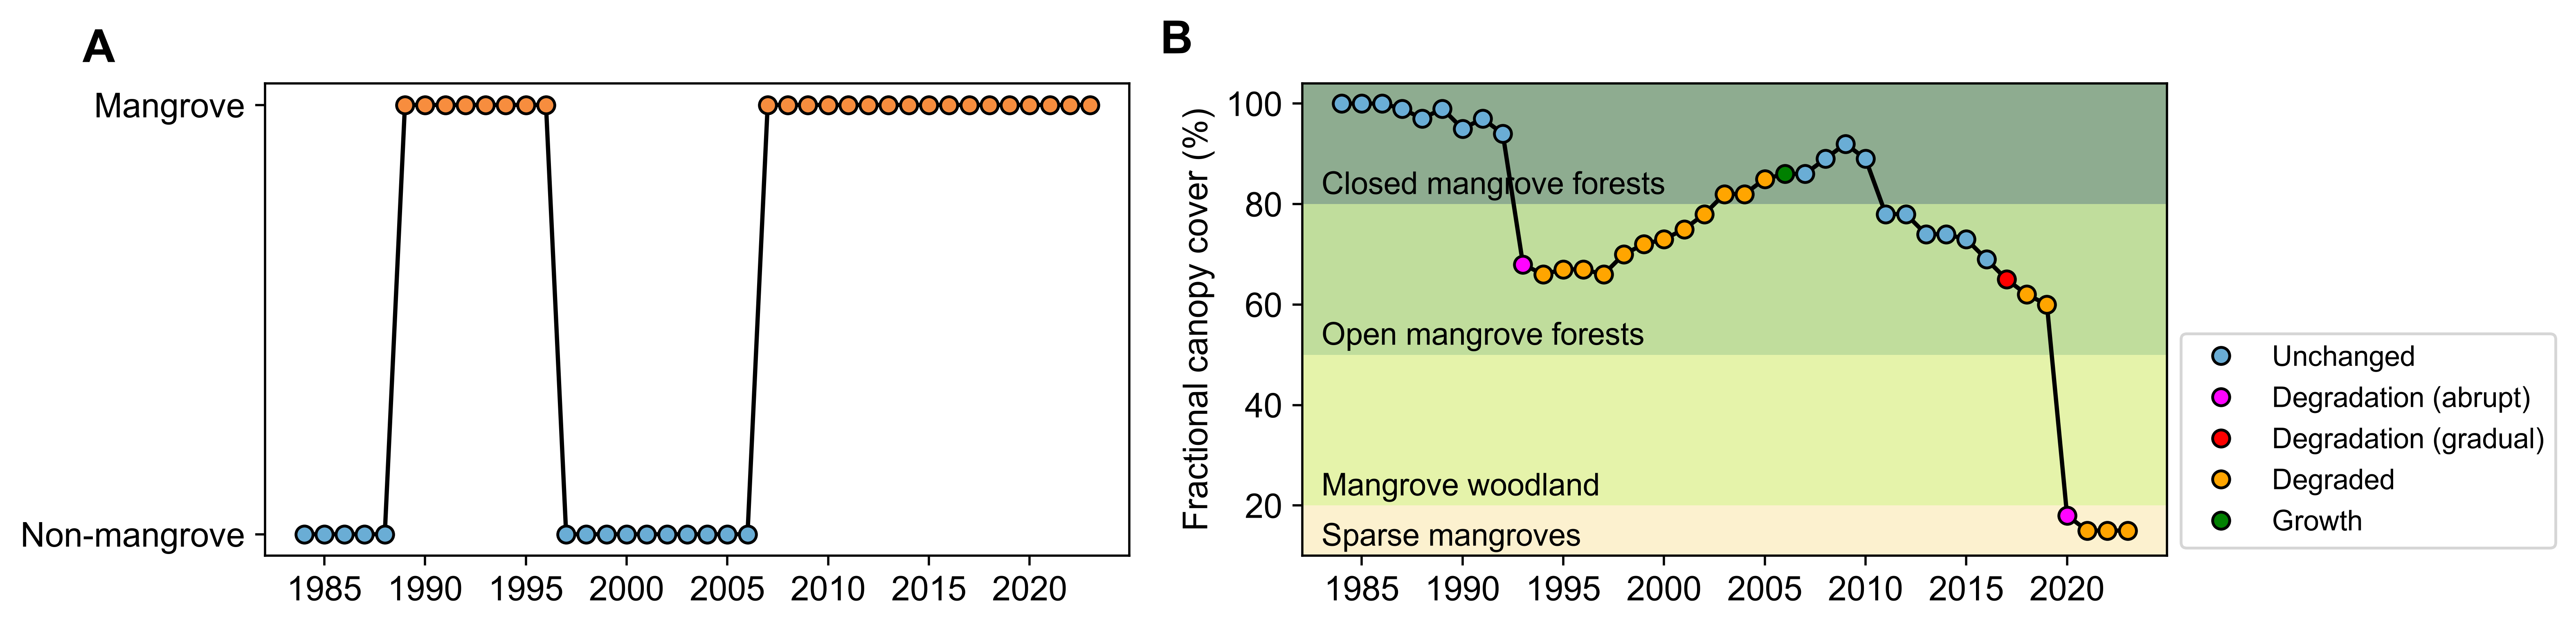


FILE: MangroveSpikeDiagram.png
SHA256: 7c28621742247466c935a987e1469089e1ea4b814e89e16b45c199f0e8ca5ae1
Size: 25226 bytes


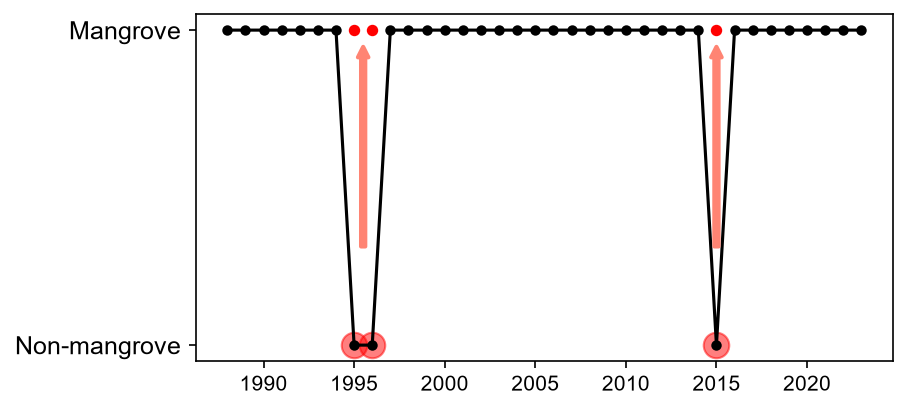

In [26]:
from pathlib import Path
from IPython.display import display, Image
from PIL import Image as PILImage
import hashlib

folder = Path("repositories/E06/test1/recovery1/output")

for filename in [
    "LossExampleDiagram.png",
    "MangroveSpikeDiagram.png"
]:
    path = folder / filename

    assert path.exists(), f"Missing: {filename}"

    with PILImage.open(path) as img:
        img.verify()

    digest = hashlib.sha256(path.read_bytes()).hexdigest()

    print("\nFILE:", filename)
    print("SHA256:", digest)
    print("Size:", path.stat().st_size, "bytes")

    display(Image(filename=str(path)))

In [27]:
from pathlib import Path
import zipfile

folder = Path("repositories/H03")
archives = list(folder.glob("*.zip"))

assert len(archives) == 1, f"Expected one ZIP, found {len(archives)}"

with zipfile.ZipFile(archives[0]) as z:
    names = [n for n in z.namelist() if not n.endswith("/")]

    print("=== H03 ARCHIVE CONTENTS ===")
    for name in names[:60]:
        print(name)

    scripts = [n for n in names if n.lower().endswith(".py")]

    print("\n=== PYTHON SCRIPT ===")
    for name in scripts:
        print("\nFILE:", name)
        code = z.read(name).decode("utf-8-sig", errors="replace")
        print(code[:12000])

    print("\n=== DOCUMENTATION ===")
    for name in names:
        if Path(name).name.lower().startswith("readme"):
            print("\nFILE:", name)
            print(z.read(name).decode("utf-8-sig", errors="replace")[:6000])

=== H03 ARCHIVE CONTENTS ===
dromanq-Hydrological-controls---Code-and-Data-a9d3bba/01_RF_dataset.csv
dromanq-Hydrological-controls---Code-and-Data-a9d3bba/01_RF_model.py
dromanq-Hydrological-controls---Code-and-Data-a9d3bba/LICENSE
dromanq-Hydrological-controls---Code-and-Data-a9d3bba/README.md
dromanq-Hydrological-controls---Code-and-Data-a9d3bba/SyntheticData.mat
dromanq-Hydrological-controls---Code-and-Data-a9d3bba/kmeansClustering.m

=== PYTHON SCRIPT ===

FILE: dromanq-Hydrological-controls---Code-and-Data-a9d3bba/01_RF_model.py

import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error
from sklearn.model_selection import (GridSearchCV, KFold,ShuffleSplit,
                                     cross_val_score,cross_validate)


#〈H,θ_6,h_a 〉 MODEL 1
#〈H,θ_100,h_a 〉 MODEL 2
#〈H,θ_6,θ_10

In [28]:
from pathlib import Path
import zipfile
import hashlib
import pandas as pd

root = Path.cwd()
archive = next((root / "repositories/H03").glob("*.zip"))

source_dir = root / "repositories/H03/test1/source"
source_dir.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(archive) as z:
    files = z.namelist()

    script_name = next(
        n for n in files if n.endswith("/01_RF_model.py")
    )

    dataset_name = next(
        n for n in files if n.endswith("/01_RF_dataset.csv")
    )

    script_path = source_dir / "01_RF_model.py"
    dataset_path = source_dir / "01_RF_dataset.csv"

    script_path.write_bytes(z.read(script_name))
    dataset_path.write_bytes(z.read(dataset_name))

def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

print("=== H03 SOURCE PREPARATION ===")
print("Script:", script_path)
print("Script SHA256:", sha256(script_path))
print("Dataset:", dataset_path)
print("Dataset SHA256:", sha256(dataset_path))

print("\n=== DATASET INSPECTION ===")

df_h03 = pd.read_csv(dataset_path, delimiter=";")

print("Rows:", len(df_h03))
print("Columns:", len(df_h03.columns))
print("Column names:", df_h03.columns.tolist())
print("Missing values:", df_h03.isna().sum().sum())

display(df_h03.head())

=== H03 SOURCE PREPARATION ===
Script: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\repositories\H03\test1\source\01_RF_model.py
Script SHA256: 8a9e38d303568e3a2b7624c9556cba407527e98f8af2274d9e3ed15aa4a74c51
Dataset: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\repositories\H03\test1\source\01_RF_dataset.csv
Dataset SHA256: 246982565ed0be6e8735c56e2dcad5816d19866236670c8add04eeff2670268b

=== DATASET INSPECTION ===
Rows: 53061
Columns: 17
Column names: ['ID', 'Rainfall', 'Duration', 'Intensity', 'Storage_prev_6', 'Storage_end_6', 'Storage_prev_100', 'Storage_end_100', 'DS_100', 'DS_100H', 'Storage_prev_200', 'Storage_end_200', 'DS_200', 'DS_200H', 'Falda_prev', 'Leakage', 'Cluster_ID']
Missing values: 0


,ID,Rainfall,Duration,Intensity,Storage_prev_6,Storage_end_6,Storage_prev_100,Storage_end_100,DS_100,DS_100H,Storage_prev_200,Storage_end_200,DS_200,DS_200H,Falda_prev,Leakage,Cluster_ID
0,1,42.785480,73,0.45,13.215645,28.112330,220.299050,241.825420,21.526370,0.503123,440.621679,461.729527,21.107848,0.493341,2860.260124,0.001354,3
1,2,30.933000,24,0.99,21.447543,28.423112,241.310812,258.922974,17.612162,0.569365,460.856070,478.333815,17.477745,0.565019,792.968245,0.005844,3
2,3,53.551290,15,2.73,21.675416,36.285186,257.151181,292.030223,34.879042,0.651320,475.758385,510.562983,34.804597,0.649930,160.972992,0.004315,3
3,4,5.009999,17,0.23,25.359202,27.658299,290.173351,293.966690,3.793340,0.757154,508.254507,511.968658,3.714150,0.741348,71.284776,0.003619,3
4,5,9.122601,13,0.54,24.929327,28.551170,293.359673,299.825067,6.465394,0.708723,511.127157,517.532442,6.405284,0.702134,47.739984,0.003296,3


In [29]:
from pathlib import Path
import subprocess
import sys
import time
import json

root = Path.cwd()
source_dir = root / "repositories/H03/test1/source"
script = source_dir / "01_RF_model.py"

start = time.perf_counter()

try:
    result = subprocess.run(
        [sys.executable, str(script)],
        cwd=source_dir,
        capture_output=True,
        text=True,
        timeout=60
    )

    exit_code = result.returncode
    output = result.stdout + "\n" + result.stderr

except subprocess.TimeoutExpired as error:
    exit_code = "TIMEOUT"
    output = (
        "Execution exceeded 60 seconds.\n"
        + str(error.stdout or b"")
        + str(error.stderr or b"")
    )

elapsed = time.perf_counter() - start

log = root / "results/H03_test1_baseline_log.txt"
log.parent.mkdir(exist_ok=True)

log.write_text(
    f"Experiment: H03 Test 1\n"
    f"Script: {script.name}\n"
    f"Python: {sys.executable}\n"
    f"Exit code: {exit_code}\n"
    f"Elapsed seconds: {elapsed:.2f}\n\n"
    f"{output}",
    encoding="utf-8"
)

print("=== H03 ORIGINAL BASELINE ===")
print("Exit code:", exit_code)
print("Elapsed seconds:", round(elapsed, 2))
print("Log:", log)

print("\n=== ERROR / OUTPUT ===")
print(output[-4000:])

=== H03 ORIGINAL BASELINE ===
Exit code: 1
Elapsed seconds: 2.47
Log: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\H03_test1_baseline_log.txt

=== ERROR / OUTPUT ===

Traceback (most recent call last):
  File "C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\repositories\H03\test1\source\01_RF_model.py", line 5, in <module>
    from sklearn.ensemble import RandomForestRegressor
ModuleNotFoundError: No module named 'sklearn'



In [30]:
%pip install scikit-learn

   ---------------------------------------- 0.0/8.3 MB ? eta -:--:--
   ---------------------- ----------------- 4.7/8.3 MB 25.9 MB/s eta 0:00:01
   ---------------------------------------  8.1/8.3 MB 25.2 MB/s eta 0:00:01
   ---------------------------------------- 8.3/8.3 MB 20.7 MB/s  0:00:00

   -------- ------------------------------- 1/5 [narwhals]
   -------- ------------------------------- 1/5 [narwhals]
   -------- ------------------------------- 1/5 [narwhals]
   -------- ------------------------------- 1/5 [narwhals]
   -------- ------------------------------- 1/5 [narwhals]
   -------- ------------------------------- 1/5 [narwhals]
   -------- ------------------------------- 1/5 [narwhals]
   ------------------------ --------------- 3/5 [joblib]
   ------------------------ --------------- 3/5 [joblib]
   ------------------------ --------------- 3/5 [joblib]
   ------------------------ --------------- 3/5 [joblib]
   -------------------------------- ------- 4/5 [scikit-learn

In [31]:
from pathlib import Path
import subprocess
import sys
import time

root = Path.cwd()
source_dir = root / "repositories/H03/test1/source"
script = source_dir / "01_RF_model.py"

start = time.perf_counter()

try:
    result = subprocess.run(
        [sys.executable, str(script)],
        cwd=source_dir,
        capture_output=True,
        text=True,
        timeout=45
    )

    exit_code = result.returncode
    output = result.stdout + "\n" + result.stderr

except subprocess.TimeoutExpired:
    exit_code = "TIMEOUT"
    output = "Execution exceeded 45 seconds."

elapsed = time.perf_counter() - start

log = root / "results/H03_test1_after_sklearn_log.txt"
log.write_text(
    f"Exit code: {exit_code}\n"
    f"Elapsed seconds: {elapsed:.2f}\n"
    f"Python executable: {sys.executable}\n\n"
    f"{output}",
    encoding="utf-8"
)

print("=== H03 AFTER DEPENDENCY INSTALLATION ===")
print("Exit code:", exit_code)
print("Elapsed:", round(elapsed, 2), "seconds")

print("\n=== OUTPUT ===")
print(output[-4000:])

=== H03 AFTER DEPENDENCY INSTALLATION ===
Exit code: 1
Elapsed: 4.87 seconds

=== OUTPUT ===

Traceback (most recent call last):
  File "C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\repositories\H03\test1\source\01_RF_model.py", line 21, in <module>
    data=pd.read_csv(input_file,delimiter=';')
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:/Users/REDACTED\miniconda3\envs\code_decay\Lib\site-packages\pandas\io\parsers\readers.py", line 1866, in read_csv
    return _read(filepath_or_buffer, kwds)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:/Users/REDACTED\miniconda3\envs\code_decay\Lib\site-packages\pandas\io\parsers\readers.py", line 423, in _read
    parser = TextFileReader(filepath_or_buffer, **kwds)
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:/Users/REDACTED\miniconda3\envs\code_decay\Lib\site-packages\pandas\io\parsers\readers.py", line 2721, in __init__
    self._engine = self._make_engi

In [32]:
from pathlib import Path
import shutil
import subprocess
import sys
import time
import hashlib
import os

root = Path.cwd()

source = root / "repositories/H03/test1/source"
recovery = root / "repositories/H03/test1/recovery1"

recovery.mkdir(parents=True, exist_ok=True)

# Copy original script without changing its contents
original_script = source / "01_RF_model.py"
recovery_script = recovery / "01_RF_model.py"

shutil.copy2(original_script, recovery_script)

# Copy dataset using filename expected by original script
original_data = source / "01_RF_dataset.csv"
recovery_data = recovery / "RF_dataset.csv"

shutil.copy2(original_data, recovery_data)

def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

assert sha256(original_script) == sha256(recovery_script)
assert sha256(original_data) == sha256(recovery_data)

print("Original script unchanged:", True)
print("Dataset contents unchanged:", True)

# Limit BLAS/OpenMP threads where supported
env = os.environ.copy()
env["OMP_NUM_THREADS"] = "2"
env["OPENBLAS_NUM_THREADS"] = "2"
env["MKL_NUM_THREADS"] = "2"

start = time.perf_counter()

try:
    result = subprocess.run(
        [sys.executable, str(recovery_script)],
        cwd=recovery,
        env=env,
        capture_output=True,
        text=True,
        timeout=30
    )

    exit_code = result.returncode
    output = result.stdout + "\n" + result.stderr

except subprocess.TimeoutExpired as error:
    exit_code = "TIMEOUT"
    output = "Execution exceeded the 30-second probe limit."

elapsed = time.perf_counter() - start

log = root / "results/H03_test1_filename_recovery_probe.txt"

log.write_text(
    f"Script unchanged: {sha256(original_script) == sha256(recovery_script)}\n"
    f"Dataset contents unchanged: {sha256(original_data) == sha256(recovery_data)}\n"
    f"Exit code: {exit_code}\n"
    f"Elapsed seconds: {elapsed:.2f}\n"
    f"Python: {sys.executable}\n\n"
    f"{output}",
    encoding="utf-8"
)

print("\n=== H03 FILENAME RECOVERY PROBE ===")
print("Exit code:", exit_code)
print("Elapsed:", round(elapsed, 2), "seconds")
print("Log:", log)
print("\nOUTPUT:")
print(output[-4000:])

Original script unchanged: True
Dataset contents unchanged: True

=== H03 FILENAME RECOVERY PROBE ===
Exit code: TIMEOUT
Elapsed: 30.13 seconds
Log: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\H03_test1_filename_recovery_probe.txt

OUTPUT:
Execution exceeded the 30-second probe limit.


In [33]:
from pathlib import Path
import subprocess
import sys
import time
import os
import hashlib
import json
import shutil

root = Path.cwd()
source = root / "repositories/H03/test1/source"
recovery = root / "repositories/H03/test1/recovery2"
recovery.mkdir(parents=True, exist_ok=True)

original = source / "01_RF_model.py"
script = recovery / "01_RF_model.py"

code = original.read_text(encoding="utf-8-sig")

# Resource-control intervention
assert "n_jobs=-1" in code
modified = code.replace("n_jobs=-1", "n_jobs=2")

# Preserve all model parameters and training data
script.write_text(modified, encoding="utf-8")

shutil.copy2(
    source / "01_RF_dataset.csv",
    recovery / "RF_dataset.csv"
)

def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

print("Original SHA256:", sha256(original))
print("Recovery SHA256:", sha256(script))
print("Number of resource-control replacements:",
      code.count("n_jobs=-1"))

env = os.environ.copy()
env["OMP_NUM_THREADS"] = "2"
env["OPENBLAS_NUM_THREADS"] = "2"
env["MKL_NUM_THREADS"] = "2"
env["MPLBACKEND"] = "Agg"
env["PYTHONUNBUFFERED"] = "1"

start = time.perf_counter()

try:
    result = subprocess.run(
        [sys.executable, str(script)],
        cwd=recovery,
        env=env,
        capture_output=True,
        text=True,
        timeout=180
    )
    status = result.returncode
    output = result.stdout + "\n" + result.stderr

except subprocess.TimeoutExpired as error:
    status = "TIMEOUT"
    stdout = error.stdout or b""
    stderr = error.stderr or b""

    if isinstance(stdout, bytes):
        stdout = stdout.decode("utf-8", errors="replace")
    if isinstance(stderr, bytes):
        stderr = stderr.decode("utf-8", errors="replace")

    output = stdout + "\n" + stderr

elapsed = time.perf_counter() - start

log = root / "results/H03_test1_resource_limited_log.txt"
log.write_text(
    f"Status: {status}\n"
    f"Elapsed: {elapsed:.2f} seconds\n"
    f"Original SHA256: {sha256(original)}\n"
    f"Modified SHA256: {sha256(script)}\n\n"
    f"{output}",
    encoding="utf-8"
)

print("\n=== H03 RESOURCE-LIMITED TEST ===")
print("Status:", status)
print("Elapsed:", round(elapsed, 2), "seconds")
print("Log:", log)

print("\n=== OUTPUT ===")
print(output[-5000:])

Original SHA256: 8a9e38d303568e3a2b7624c9556cba407527e98f8af2274d9e3ed15aa4a74c51
Recovery SHA256: 60c35780681389ba36e2ef766470b473c79d0d4ef03c7d6734b1ac2b411c2008
Number of resource-control replacements: 8

=== H03 RESOURCE-LIMITED TEST ===
Status: TIMEOUT
Elapsed: 180.12 seconds
Log: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\H03_test1_resource_limited_log.txt

=== OUTPUT ===
-0.140 RMSE with a standard deviation of 0.011




In [34]:
from pathlib import Path
import json

root = Path.cwd()

record = {
    "repository_id": "H03",
    "domain": "Hydrology",
    "script": "01_RF_model.py",
    "dataset_rows": 53061,
    "dataset_columns": 17,
    "missing_values": 0,
    "original_script_sha256":
        "8a9e38d303568e3a2b7624c9556cba407527e98f8af2274d9e3ed15aa4a74c51",
    "resource_limited_script_sha256":
        "60c35780681389ba36e2ef766470b473c79d0d4ef03c7d6734b1ac2b411c2008",
    "baseline_status": "failed_missing_dependency",
    "dependency_recovery_status": "failed_filename_mismatch",
    "filename_recovery_status": "timeout_30_seconds",
    "resource_limited_status": "timeout_180_seconds",
    "partial_output": "-0.140 RMSE, standard deviation 0.011",
    "workflow_completed": False,
    "result_reproduced": False,
    "classification": "partial_execution_computational_limit",
    "recovery_interventions": [
        "Installed scikit-learn",
        "Provided CSV under filename expected by original script",
        "Changed n_jobs=-1 to n_jobs=2 in separate recovery copy"
    ],
    "limitations": [
        "Full hyperparameter search did not complete",
        "No published-result comparison",
        "Recovery effort in minutes not measured"
    ]
}

output = root / "results/H03_test1_summary.json"
output.parent.mkdir(parents=True, exist_ok=True)

output.write_text(
    json.dumps(record, indent=2),
    encoding="utf-8"
)

print("H03 research summary saved:", output)

H03 research summary saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\H03_test1_summary.json


In [35]:
from pathlib import Path
import zipfile

folder = Path("repositories/H06")
archives = list(folder.glob("*.zip"))

assert len(archives) == 1, f"Expected one ZIP, found {len(archives)}"

with zipfile.ZipFile(archives[0]) as z:
    names = [n for n in z.namelist() if not n.endswith("/")]

    print("=== H06 ARCHIVE CONTENTS ===")
    print("Total files:", len(names))

    for name in names[:70]:
        print(name)

    print("\n=== DOCUMENTATION ===")

    docs = [
        n for n in names
        if Path(n).name.lower() in {
            "readme.md", "readme.txt",
            "requirements.txt", "environment.yml",
            "pyproject.toml", "setup.py"
        }
    ]

    for name in docs[:8]:
        print("\nFILE:", name)
        print(
            z.read(name).decode(
                "utf-8-sig", errors="replace"
            )[:8000]
        )

    print("\n=== POSSIBLE ENTRY POINTS ===")

    scripts = [
        n for n in names
        if n.lower().endswith(".py")
    ]

    for name in scripts:
        if any(
            word in Path(name).name.lower()
            for word in ["main", "run", "test", "example", "train"]
        ):
            print(name)

    print("\nPython files:", len(scripts))

=== H06 ARCHIVE CONTENTS ===
Total files: 292
S4D_rainfall_runoff_simulations-main/README.md
S4D_rainfall_runoff_simulations-main/analysis/combine_sacsma_pkfiles.py
S4D_rainfall_runoff_simulations-main/analysis/main_performance_ensemble_only.py
S4D_rainfall_runoff_simulations-main/analysis/performance_functions.py
S4D_rainfall_runoff_simulations-main/data/basin_list.txt
S4D_rainfall_runoff_simulations-main/main_pub.py
S4D_rainfall_runoff_simulations-main/main_with_train_val.py
S4D_rainfall_runoff_simulations-main/papercode/SSM_test.py
S4D_rainfall_runoff_simulations-main/papercode/__init__.py
S4D_rainfall_runoff_simulations-main/papercode/__pycache__/SSM_test.cpython-312.pyc
S4D_rainfall_runoff_simulations-main/papercode/__pycache__/SSM_test.cpython-39.pyc
S4D_rainfall_runoff_simulations-main/papercode/__pycache__/__init__.cpython-312.pyc
S4D_rainfall_runoff_simulations-main/papercode/__pycache__/__init__.cpython-39.pyc
S4D_rainfall_runoff_simulations-main/papercode/__pycache__/dataset

In [36]:
from pathlib import Path
import zipfile

archive = next(Path("repositories/H06").glob("*.zip"))

with zipfile.ZipFile(archive) as z:
    names = [
        n for n in z.namelist()
        if not n.endswith("/")
    ]

    print("=== DEPENDENCY FILES ===")
    for name in names:
        filename = Path(name).name.lower()
        if filename in {
            "requirements.txt",
            "environment.yml",
            "environment.yaml",
            "pyproject.toml",
            "setup.py",
            "pipfile"
        }:
            print(name)

    print("\n=== CHECKPOINT / MODEL FILES ===")
    checkpoints = [
        n for n in names
        if Path(n).suffix.lower()
        in {".pt", ".pth", ".ckpt", ".pkl", ".joblib"}
    ]

    for name in checkpoints[:30]:
        print(name)

    print("Checkpoint candidates:", len(checkpoints))

    print("\n=== DATA FILES ===")
    data_files = [
        n for n in names
        if Path(n).suffix.lower()
        in {".csv", ".nc", ".h5", ".hdf5", ".parquet"}
    ]

    for name in data_files[:30]:
        print(name)

    print("Data-file candidates:", len(data_files))

    print("\n=== SMALL TEST SCRIPT ===")
    tests = [
        n for n in names
        if Path(n).name == "SSM_test.py"
    ]

    for name in tests[:1]:
        print("FILE:", name)
        print(
            z.read(name).decode(
                "utf-8-sig", errors="replace"
            )[:10000]
        )

=== DEPENDENCY FILES ===

=== CHECKPOINT / MODEL FILES ===
Checkpoint candidates: 0

=== DATA FILES ===
Data-file candidates: 0

=== SMALL TEST SCRIPT ===
FILE: S4D_rainfall_runoff_simulations-main/papercode/SSM_test.py
import math
import sys
sys.path.append('../')
import torch
import torch.nn as nn
import numpy as np
import tqdm
from typing import Tuple

import copy


import torch
import torch.nn as nn
import torch.optim as optim
import torch.backends.cudnn as cudnn

import torchvision
import torchvision.transforms as transforms

import os
import argparse
import numpy as np
import torch.nn.functional as F
sys.path.append(os.path.dirname(os.path.realpath(__file__)))
from models.s4.s4d import S4D as LTI

# Dropout broke in PyTorch 1.11
if tuple(map(int, torch.__version__.split('.')[:2])) == (1, 11):
    print("WARNING: Dropout is bugged in PyTorch 1.11. Results may be worse.")
    dropout_fn = nn.Dropout
if tuple(map(int, torch.__version__.split('.')[:2])) >= (1, 12):
    dropout_fn = n

In [37]:
from pathlib import Path
import json

root = Path.cwd()

record = {
    "repository_id": "H06",
    "domain": "Hydrology",
    "repository_name": "S4D Rainfall-Runoff Simulations",
    "archive_files": 292,
    "python_files": 96,
    "dependency_manifest_found": False,
    "research_dataset_files_detected": 0,
    "model_checkpoints_detected": 0,
    "external_inputs_required": [
        "CAMELS watershed dataset",
        "Updated NLDAS meteorological forcings"
    ],
    "models": ["S4D", "LSTM", "MC-LSTM"],
    "execution_attempted": False,
    "full_workflow_completed": False,
    "published_results_reproduced": False,
    "classification": "not_tested_external_data_dependency",
    "limitations": [
        "Required research datasets not included in archive",
        "Pretrained model checkpoints not detected",
        "No dependency manifest detected",
        "Potential CUDA requirements not experimentally verified"
    ]
}

output = root / "results/H06_assessment.json"
output.parent.mkdir(parents=True, exist_ok=True)

output.write_text(
    json.dumps(record, indent=2),
    encoding="utf-8"
)

print("H06 assessment saved:", output)

H06 assessment saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\H06_assessment.json


In [38]:
from pathlib import Path
import zipfile

folder = Path("repositories/H05")
archives = list(folder.glob("*.zip"))

assert len(archives) == 1, (
    f"Expected one ZIP, found {len(archives)}"
)

with zipfile.ZipFile(archives[0]) as z:
    names = [
        n for n in z.namelist()
        if not n.endswith("/")
    ]

    print("=== H05 ARCHIVE SUMMARY ===")
    print("Total files:", len(names))

    print("\n=== ROOT-LEVEL FILES ===")
    for name in names:
        parts = Path(name).parts
        if len(parts) <= 2:
            print(name)

    print("\n=== DEPENDENCY FILES ===")
    for name in names:
        if Path(name).name.lower() in {
            "requirements.txt",
            "environment.yml",
            "environment.yaml",
            "pyproject.toml",
            "setup.py",
            "setup.cfg"
        }:
            print("\nFILE:", name)
            print(
                z.read(name).decode(
                    "utf-8-sig", errors="replace"
                )[:6000]
            )

    print("\n=== TEST FILES ===")
    tests = [
        n for n in names
        if n.lower().endswith(".py")
        and (
            Path(n).name.lower().startswith("test_")
            or Path(n).name.lower().endswith("_test.py")
        )
    ]

    for name in tests[:30]:
        print(name)

    print("Total test scripts:", len(tests))

    print("\n=== DATA AND MODEL FILES ===")
    candidates = [
        n for n in names
        if Path(n).suffix.lower() in {
            ".csv", ".nc", ".h5", ".hdf5",
            ".pt", ".pth", ".ckpt"
        }
    ]

    for name in candidates[:30]:
        print(name)

    print("Total candidates:", len(candidates))

    print("\n=== MAIN README ===")
    readmes = [
        n for n in names
        if Path(n).name.lower() == "readme.md"
        and len(Path(n).parts) <= 2
    ]

    for name in readmes[:1]:
        print(
            z.read(name).decode(
                "utf-8-sig", errors="replace"
            )[:10000]
        )

=== H05 ARCHIVE SUMMARY ===
Total files: 202

=== ROOT-LEVEL FILES ===
neuralhydrology-v.1.2.3/.gitignore
neuralhydrology-v.1.2.3/.style.yapf
neuralhydrology-v.1.2.3/CODEOWNERS
neuralhydrology-v.1.2.3/CONTRIBUTING.rst
neuralhydrology-v.1.2.3/LICENSE
neuralhydrology-v.1.2.3/README.md
neuralhydrology-v.1.2.3/readthedocs.yml
neuralhydrology-v.1.2.3/setup.py

=== DEPENDENCY FILES ===

FILE: neuralhydrology-v.1.2.3/setup.py
from pathlib import Path

from setuptools import setup

# read the description from the README.md
readme_file = Path(__file__).absolute().parent / "README.md"
with readme_file.open("r") as fp:
    long_description = fp.read()

about = {}
with open("neuralhydrology/__about__.py", "r") as fp:
    exec(fp.read(), about)

setup(name='neuralhydrology',
      version=about["__version__"],
      packages=[
          'neuralhydrology', 'neuralhydrology.datasetzoo', 'neuralhydrology.datautils', 'neuralhydrology.utils',
          'neuralhydrology.modelzoo', 'neuralhydrology.traini

In [39]:
from pathlib import Path
import zipfile
import hashlib

archive = next(Path("repositories/H05").glob("*.zip"))

with zipfile.ZipFile(archive) as z:

    tests = [
        name for name in z.namelist()
        if name.endswith((
            "test/test_datautils.py",
            "test/test_config_runs.py",
            "test/test_custom_lstm.py",
            "test/test_mclstm.py"
        ))
    ]

    print("=== H05 TEST SCRIPT INSPECTION ===")

    for name in tests:
        content = z.read(name)
        text = content.decode(
            "utf-8-sig",
            errors="replace"
        )

        print("\n" + "=" * 60)
        print("FILE:", name)
        print("SIZE:", len(content), "bytes")
        print(
            "SHA256:",
            hashlib.sha256(content).hexdigest()
        )

        print("\n--- FIRST 100 LINES ---")

        for i, line in enumerate(
            text.splitlines()[:100], start=1
        ):
            print(f"{i:03}: {line}")

=== H05 TEST SCRIPT INSPECTION ===

FILE: neuralhydrology-v.1.2.3/test/test_config_runs.py
SIZE: 8671 bytes
SHA256: 460f6cea4399f04d11e4fe55bd9505d3a9d327a3a073c8a1fa8f58f9dba64265

--- FIRST 100 LINES ---
001: """Integration tests that perform full runs. """
002: import pickle
003: from datetime import datetime
004: from pathlib import Path
005: from typing import Dict, Tuple, Callable
006: 
007: import pandas as pd
008: from pandas.tseries.frequencies import to_offset
009: import pytest
010: from pytest import approx
011: 
012: from neuralhydrology.datasetzoo import camelsus, hourlycamelsus
013: from neuralhydrology.evaluation.evaluate import start_evaluation
014: from neuralhydrology.training.train import start_training
015: from neuralhydrology.utils.config import Config
016: from test import Fixture
017: 
018: 
019: def test_daily_regression(get_config: Fixture[Callable[[str], dict]], single_timescale_model: Fixture[str],
020:                           daily_dataset: Fixture[str],

In [40]:
from pathlib import Path
import zipfile
import hashlib
import subprocess
import sys
import time
import json
import importlib.metadata as metadata

root = Path.cwd()
archive = next((root / "repositories/H05").glob("*.zip"))

test_root = root / "repositories/H05/test1"
source = test_root / "source"
source.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(archive) as z:
    members = [
        n for n in z.namelist()
        if not n.endswith("/")
    ]

    prefix = "neuralhydrology-v.1.2.3/"

    # Extract the original package and test files.
    for name in members:
        if not name.startswith(prefix):
            continue

        relative = Path(name[len(prefix):])

        if not relative.parts:
            continue

        if relative.parts[0] not in {
            "neuralhydrology", "test"
        }:
            continue

        destination = source / relative
        destination.parent.mkdir(
            parents=True, exist_ok=True
        )
        destination.write_bytes(z.read(name))

original_test = source / "test/test_datautils.py"

sha256 = hashlib.sha256(
    original_test.read_bytes()
).hexdigest()

print("=== H05 BASELINE ===")
print("Original SHA256:", sha256)
print("Python:", sys.version.split()[0])

for package in ["pandas", "pytest", "torch"]:
    try:
        version = metadata.version(package)
    except metadata.PackageNotFoundError:
        version = "NOT INSTALLED"
    print(f"{package}: {version}")

print("\nRunning original archived tests...")

start = time.perf_counter()

try:
    result = subprocess.run(
        [
            sys.executable,
            "-m",
            "pytest",
            "test/test_datautils.py",
            "-v",
            "--tb=short",
            "-p",
            "no:cacheprovider"
        ],
        cwd=source,
        capture_output=True,
        text=True,
        timeout=60
    )

    status = result.returncode
    output = result.stdout + "\n" + result.stderr

except subprocess.TimeoutExpired as error:
    status = "TIMEOUT"
    output = (
        (error.stdout or b"").decode(
            errors="replace"
        ) if isinstance(error.stdout, bytes)
        else (error.stdout or "")
    )

elapsed = round(time.perf_counter() - start, 2)

log_path = root / "results/H05_test1_baseline_log.txt"
log_path.parent.mkdir(parents=True, exist_ok=True)

log_path.write_text(
    f"Status: {status}\n"
    f"Elapsed: {elapsed} seconds\n"
    f"SHA256: {sha256}\n\n"
    f"{output}",
    encoding="utf-8"
)

print("\n=== BASELINE RESULT ===")
print("Status:", status)
print("Elapsed:", elapsed, "seconds")
print("Log:", log_path)
print("\n=== TEST OUTPUT ===")
print(output[-7000:])

=== H05 BASELINE ===
Original SHA256: b25fcd2fb66e9633bb28b892d6b23ebac9c57189caa86f70197acc642a0eecb3
Python: 3.11.18
pandas: 3.1.0
pytest: NOT INSTALLED
torch: NOT INSTALLED

Running original archived tests...

=== BASELINE RESULT ===
Status: 1
Elapsed: 0.13 seconds
Log: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\H05_test1_baseline_log.txt

=== TEST OUTPUT ===

C:/Users/REDACTED\miniconda3\envs\code_decay\python.exe: No module named pytest



In [41]:
%pip install pytest


   ---------------------------------------- 0/3 [pluggy]
   ------------- -------------------------- 1/3 [iniconfig]
   -------------------------- ------------- 2/3 [pytest]
   -------------------------- ------------- 2/3 [pytest]
   -------------------------- ------------- 2/3 [pytest]
   -------------------------- ------------- 2/3 [pytest]
   -------------------------- ------------- 2/3 [pytest]
   -------------------------- ------------- 2/3 [pytest]
   -------------------------- ------------- 2/3 [pytest]
   -------------------------- ------------- 2/3 [pytest]
   ---------------------------------------- 3/3 [pytest]

Note: you may need to restart the kernel to use updated packages.


In [42]:
from pathlib import Path
import subprocess
import sys
import time

root = Path.cwd()
source = root / "repositories/H05/test1/source"

start = time.perf_counter()

try:
    result = subprocess.run(
        [
            sys.executable,
            "-m",
            "pytest",
            "test/test_datautils.py",
            "-v",
            "--tb=short",
            "-p",
            "no:cacheprovider"
        ],
        cwd=source,
        capture_output=True,
        text=True,
        timeout=60
    )

    status = result.returncode
    output = result.stdout + "\n" + result.stderr

except subprocess.TimeoutExpired as error:
    status = "TIMEOUT"
    output = str(error)

elapsed = round(time.perf_counter() - start, 2)

log_path = root / "results/H05_test1_after_pytest_log.txt"
log_path.write_text(
    f"Status: {status}\n"
    f"Elapsed: {elapsed} seconds\n\n"
    f"{output}",
    encoding="utf-8"
)

print("=== H05 AFTER PYTEST INSTALLATION ===")
print("Status:", status)
print("Elapsed:", elapsed, "seconds")
print("Log:", log_path)

print("\n=== OUTPUT ===")
print(output[-7000:])

=== H05 AFTER PYTEST INSTALLATION ===
Status: 4
Elapsed: 2.98 seconds
Log: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\H05_test1_after_pytest_log.txt

=== OUTPUT ===

ImportError while loading conftest 'C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\repositories\H05\test1\source\test\conftest.py'.
test\conftest.py:6: in <module>
    from neuralhydrology.utils.config import Config
neuralhydrology\utils\config.py:7: in <module>
    from ruamel.yaml import YAML
E   ModuleNotFoundError: No module named 'ruamel'



In [43]:
%pip install ruamel.yaml

Note: you may need to restart the kernel to use updated packages.


In [44]:
from pathlib import Path
import subprocess
import sys
import time

root = Path.cwd()
source = root / "repositories/H05/test1/source"

start = time.perf_counter()

try:
    result = subprocess.run(
        [
            sys.executable,
            "-m", "pytest",
            "test/test_datautils.py",
            "-v",
            "--tb=short",
            "-p", "no:cacheprovider"
        ],
        cwd=source,
        capture_output=True,
        text=True,
        timeout=60
    )

    status = result.returncode
    output = result.stdout + "\n" + result.stderr

except subprocess.TimeoutExpired as error:
    status = "TIMEOUT"
    output = str(error)

elapsed = round(time.perf_counter() - start, 2)

log_path = root / "results/H05_test1_after_ruamel_log.txt"

log_path.write_text(
    f"Status: {status}\n"
    f"Elapsed: {elapsed} seconds\n\n"
    f"{output}",
    encoding="utf-8"
)

print("=== H05 AFTER RUAMEL INSTALLATION ===")
print("Status:", status)
print("Elapsed:", elapsed, "seconds")
print("Log:", log_path)

print("\n=== OUTPUT ===")
print(output[-7000:])

=== H05 AFTER RUAMEL INSTALLATION ===
Status: 2
Elapsed: 2.46 seconds
Log: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\H05_test1_after_ruamel_log.txt

=== OUTPUT ===
============================= test session starts =============================
platform win32 -- Python 3.11.18, pytest-9.2.0, pluggy-1.7.0 -- C:/Users/REDACTED\miniconda3\envs\code_decay\python.exe
rootdir: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\repositories\H05\test1\source
plugins: anyio-4.15.1, platformdirs-4.14.4
collecting ... collected 0 items / 1 error

=================================== ERRORS ====================================
___________________ ERROR collecting test/test_datautils.py ___________________
ImportError while importing test module 'C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\repositories\H05\test1\source\test\test_datautils

In [45]:
%pip install xarray

   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ------------------------------------ --- 1.3/1.4 MB 8.4 MB/s eta 0:00:01
   ---------------------------------------- 1.4/1.4 MB 6.9 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.


In [46]:
from pathlib import Path
import subprocess
import sys
import time
import importlib.metadata as metadata

root = Path.cwd()
source = root / "repositories/H05/test1/source"

start = time.perf_counter()

try:
    result = subprocess.run(
        [
            sys.executable,
            "-m", "pytest",
            "test/test_datautils.py",
            "-v",
            "--tb=short",
            "-p", "no:cacheprovider"
        ],
        cwd=source,
        capture_output=True,
        text=True,
        timeout=60
    )

    status = result.returncode
    output = result.stdout + "\n" + result.stderr

except subprocess.TimeoutExpired as error:
    status = "TIMEOUT"
    stdout = error.stdout or b""
    stderr = error.stderr or b""

    if isinstance(stdout, bytes):
        stdout = stdout.decode(errors="replace")
    if isinstance(stderr, bytes):
        stderr = stderr.decode(errors="replace")

    output = stdout + "\n" + stderr

elapsed = round(time.perf_counter() - start, 2)

packages = {}

for package in ["pytest", "pandas", "ruamel.yaml", "xarray"]:
    try:
        packages[package] = metadata.version(package)
    except metadata.PackageNotFoundError:
        packages[package] = "NOT INSTALLED"

log_path = root / "results/H05_test1_after_xarray_log.txt"

log_path.write_text(
    f"Status: {status}\n"
    f"Elapsed: {elapsed} seconds\n"
    f"Python: {sys.version.split()[0]}\n"
    f"Packages: {packages}\n\n"
    f"{output}",
    encoding="utf-8"
)

print("=== H05 AFTER XARRAY INSTALLATION ===")
print("Status:", status)
print("Elapsed:", elapsed, "seconds")
print("Packages:", packages)
print("Log:", log_path)

print("\n=== TEST OUTPUT ===")
print(output[-8000:])

=== H05 AFTER XARRAY INSTALLATION ===
Status: 1
Elapsed: 2.91 seconds
Packages: {'pytest': '9.2.0', 'pandas': '3.1.0', 'ruamel.yaml': '0.19.1', 'xarray': '2026.9.0'}
Log: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\H05_test1_after_xarray_log.txt

=== TEST OUTPUT ===
09: in pandas._libs.tslibs.offsets.raise_invalid_freq
    ???
E   ValueError: Invalid frequency: H. Did you mean h?

During handling of the above exception, another exception occurred:
test\test_datautils.py:10: in test_sort_frequencies
    assert sort_frequencies(['1D', '1H', '2D', '3H']) == ['2D', '1D', '3H', '1H']
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
neuralhydrology\datautils\utils.py:148: in sort_frequencies
    return sorted(frequencies, key=functools.cmp_to_key(compare_frequencies))
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
neuralhydrology\datautils\utils.py:234: in compare_frequencies
    freq_factor = g

In [47]:
from pathlib import Path
import json

root = Path.cwd()

record = {
    "repository_id": "H05",
    "test_id": "H05_test1",
    "repository": "NeuralHydrology v1.2.3",
    "selected_test": "test/test_datautils.py",
    "python_version": "3.11.18",
    "pandas_version": "3.1.0",
    "xarray_version": "2026.9.0",
    "pytest_version": "9.2.0",
    "tests_collected": 3,
    "tests_passed": 0,
    "tests_failed": 3,
    "baseline_failure": "pytest not installed",
    "subsequent_barriers": [
        "Missing ruamel.yaml",
        "Missing xarray"
    ],
    "confirmed_compatibility_errors": [
        "Invalid frequency: 1H",
        "Invalid frequency: 48H",
        "Invalid frequency: 1A"
    ],
    "classification": "dependency_api_incompatibility",
    "recovery_status": "pending",
    "published_results_reproduced": False,
    "human_recovery_time_measured": False
}

output = root / "results/H05_test1_compatibility_assessment.json"

output.write_text(
    json.dumps(record, indent=2),
    encoding="utf-8"
)

print("Saved:", output)

Saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\H05_test1_compatibility_assessment.json


In [49]:
from pathlib import Path
import subprocess
import sys

conda_root = Path(sys.executable).parents[1].parent

print("Miniconda directory:", conda_root)

candidates = [
    conda_root / "Scripts" / "conda.exe",
    conda_root / "condabin" / "conda.bat"
]

for path in candidates:
    print("Found:", path, "=", path.exists())

conda_exe = conda_root / "Scripts" / "conda.exe"

if conda_exe.exists():
    result = subprocess.run(
        [str(conda_exe), "--version"],
        capture_output=True,
        text=True
    )

    print("\n=== CONDA RESULT ===")
    print("Exit code:", result.returncode)
    print(result.stdout or result.stderr)
else:
    print("Conda executable not found at expected location.")

Miniconda directory: C:/Users/REDACTED\miniconda3
Found: C:/Users/REDACTED\miniconda3\Scripts\conda.exe = True
Found: C:/Users/REDACTED\miniconda3\condabin\conda.bat = True

=== CONDA RESULT ===
Exit code: 0
conda 26.9.4



In [50]:
from pathlib import Path
import subprocess
import sys
import time

conda_root = Path(sys.executable).parents[2]
conda_exe = conda_root / "Scripts" / "conda.exe"

command = [
    str(conda_exe),
    "create",
    "-n", "h05_recovery",
    "python=3.10",
    "pandas=1.5.3",
    "pip",
    "-y"
]

print("=== CREATING H05 RECOVERY ENVIRONMENT ===")
print("This may take several minutes.")

start = time.perf_counter()

result = subprocess.run(
    command,
    capture_output=True,
    text=True,
    timeout=600
)

elapsed = round(time.perf_counter() - start, 2)

log_path = Path.cwd() / "results/H05_environment_creation_log.txt"
log_path.parent.mkdir(parents=True, exist_ok=True)

log_path.write_text(
    result.stdout + "\n" + result.stderr,
    encoding="utf-8"
)

print("\n=== ENVIRONMENT CREATION RESULT ===")
print("Exit code:", result.returncode)
print("Elapsed:", elapsed, "seconds")
print("Log:", log_path)
print("\nLast output:")
print((result.stdout + result.stderr)[-3500:])

=== CREATING H05 RECOVERY ENVIRONMENT ===
This may take several minutes.

=== ENVIRONMENT CREATION RESULT ===
Exit code: 0
Elapsed: 47.95 seconds
Log: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\H05_environment_creation_log.txt

Last output:
--------------------------------
                                           Total:        37.1 MB

The following NEW packages will be INSTALLED:

  blas               pkgs/main/win-64::blas-1.0-mkl 
  bottleneck         pkgs/main/win-64::bottleneck-1.6.0-py310h18b77b3_0 
  bzip2              pkgs/main/win-64::bzip2-1.0.8-h2bbff1b_6 
  ca-certificates    pkgs/main/noarch::ca-certificates-2026.11.5-h382c6e5_0 
  intel-openmp       pkgs/main/win-64::intel-openmp-2025.0.0-haa95532_1165 
  libexpat           pkgs/main/win-64::libexpat-2.10.0-hd7fb8db_0 
  libffi             pkgs/main/win-64::libffi-3.4.8-h42d73b9_3 
  libhwloc           pkgs/main/win-64::libhwloc-2.12.1-default_hfa10c62_1000 

In [51]:
from pathlib import Path
import subprocess
import sys
import time

root = Path.cwd()
conda_root = Path(sys.executable).parents[2]

recovery_python = (
    conda_root / "envs" / "h05_recovery" / "python.exe"
)

print("=== H05 RECOVERY ENVIRONMENT ===")
print("Python found:", recovery_python.exists())
print("Python path:", recovery_python)

if not recovery_python.exists():
    raise FileNotFoundError(
        "Recovery Python not found. Check the environment."
    )

command = [
    str(recovery_python),
    "-m", "pip", "install",
    "pytest",
    "ruamel.yaml",
    "xarray<2025",
    "pandas==1.5.3"
]

print("\nInstalling test dependencies...")
start = time.perf_counter()

result = subprocess.run(
    command,
    capture_output=True,
    text=True,
    timeout=600
)

elapsed = round(time.perf_counter() - start, 2)

log_path = root / "results/H05_recovery_dependencies_log.txt"
log_path.write_text(
    result.stdout + "\n" + result.stderr,
    encoding="utf-8"
)

print("\n=== INSTALLATION RESULT ===")
print("Exit code:", result.returncode)
print("Elapsed:", elapsed, "seconds")
print("Log:", log_path)
print("\nLast output:")
print((result.stdout + result.stderr)[-4000:])

=== H05 RECOVERY ENVIRONMENT ===
Python found: True
Python path: C:/Users/REDACTED\miniconda3\envs\h05_recovery\python.exe

Installing test dependencies...

=== INSTALLATION RESULT ===
Exit code: 0
Elapsed: 16.52 seconds
Log: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\H05_recovery_dependencies_log.txt

Last output:
l (1.3 MB)
   ---------------------------------------- 0.0/1.3 MB ? eta -:--:--
   ---------------------------------------- 1.3/1.3 MB 31.9 MB/s  0:00:00

   -------- -------------------------------  2/10 [ruamel.yaml]
   -------- -------------------------------  2/10 [ruamel.yaml]
   -------- -------------------------------  2/10 [ruamel.yaml]
   ------------ ---------------------------  3/10 [pygments]
   ------------ ---------------------------  3/10 [pygments]
   ------------ ---------------------------  3/10 [pygments]
   ------------ ---------------------------  3/10 [pygments]
   ------------ -------------

In [52]:
from pathlib import Path
import subprocess
import sys
import time

root = Path.cwd()
conda_root = Path(sys.executable).parents[2]

recovery_python = (
    conda_root / "envs" / "h05_recovery" / "python.exe"
)

source = root / "repositories/H05/test1/source"

# Record the exact recovery environment.
versions = subprocess.run(
    [
        str(recovery_python),
        "-m", "pip", "freeze"
    ],
    capture_output=True,
    text=True,
    timeout=60
)

(root / "results/H05_recovery_packages.txt").write_text(
    versions.stdout,
    encoding="utf-8"
)

print("=== RUNNING ORIGINAL H05 TESTS ===")

start = time.perf_counter()

try:
    result = subprocess.run(
        [
            str(recovery_python),
            "-m", "pytest",
            "test/test_datautils.py",
            "-v",
            "--tb=short",
            "-p", "no:cacheprovider"
        ],
        cwd=source,
        capture_output=True,
        text=True,
        timeout=90
    )

    status = result.returncode
    output = result.stdout + "\n" + result.stderr

except subprocess.TimeoutExpired as error:
    status = "TIMEOUT"
    stdout = error.stdout or b""
    stderr = error.stderr or b""

    if isinstance(stdout, bytes):
        stdout = stdout.decode(errors="replace")
    if isinstance(stderr, bytes):
        stderr = stderr.decode(errors="replace")

    output = stdout + "\n" + stderr

elapsed = round(time.perf_counter() - start, 2)

log_path = root / "results/H05_test1_recovery_environment_log.txt"

log_path.write_text(
    f"Status: {status}\n"
    f"Elapsed: {elapsed} seconds\n"
    f"Recovery Python: {recovery_python}\n\n"
    f"{output}",
    encoding="utf-8"
)

print("\n=== H05 RECOVERY TEST RESULT ===")
print("Status:", status)
print("Elapsed:", elapsed, "seconds")
print("Log:", log_path)
print("\n=== TEST OUTPUT ===")
print(output[-8000:])

=== RUNNING ORIGINAL H05 TESTS ===

=== H05 RECOVERY TEST RESULT ===
Status: 0
Elapsed: 2.8 seconds
Log: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\H05_test1_recovery_environment_log.txt

=== TEST OUTPUT ===
============================= test session starts =============================
platform win32 -- Python 3.10.22, pytest-9.2.0, pluggy-1.7.0 -- C:/Users/REDACTED\miniconda3\envs\h05_recovery\python.exe
rootdir: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\repositories\H05\test1\source
collecting ... collected 3 items

test/test_datautils.py::test_sort_frequencies PASSED                     [ 33%]
test/test_datautils.py::test_infer_frequency PASSED                      [ 66%]
test/test_datautils.py::test_get_frequency_factor PASSED                 [100%]

============================== 3 passed in 0.36s ==============================




In [53]:
from pathlib import Path
import json
import hashlib

root = Path.cwd()
source = root / "repositories/H05/test1/source"
test_file = source / "test/test_datautils.py"

original_hash = hashlib.sha256(
    test_file.read_bytes()
).hexdigest()

summary = {
    "repository_id": "H05",
    "test_id": "H05_test1",
    "repository": "NeuralHydrology v1.2.3",
    "selected_workflow": "Archived data-utility unit tests",
    "original_source_sha256": original_hash,
    "source_modified": False,
    "modern_environment": {
        "python": "3.11.18",
        "pandas": "3.1.0",
        "tests_passed": 0,
        "tests_failed": 3,
        "failure": "Legacy pandas frequency aliases rejected"
    },
    "recovery_environment": {
        "python": "3.10.22",
        "pandas": "1.5.3",
        "xarray": "2024.3.0",
        "pytest": "9.2.0",
        "ruamel.yaml": "0.19.1",
        "tests_passed": 3,
        "tests_failed": 0,
        "exit_code": 0
    },
    "recovery_method": "Isolated environment reconstruction",
    "environment_creation_seconds": 47.95,
    "dependency_installation_seconds": 16.52,
    "final_test_execution_seconds": 2.8,
    "recorded_machine_seconds": 67.27,
    "human_remediation_time_measured": False,
    "selected_tests_recovered": True,
    "full_repository_reproduced": False,
    "published_research_results_reproduced": False,
    "causal_limitation": (
        "Multiple environment components changed; "
        "pandas-specific causality not isolated."
    )
}

output = root / "results/H05_test1_final_summary.json"

output.write_text(
    json.dumps(summary, indent=2),
    encoding="utf-8"
)

print("=== H05 FINAL SUMMARY SAVED ===")
print("File:", output)
print("Original SHA256:", original_hash)
print("Recovered tests: 3/3")

=== H05 FINAL SUMMARY SAVED ===
File: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\H05_test1_final_summary.json
Original SHA256: b25fcd2fb66e9633bb28b892d6b23ebac9c57189caa86f70197acc642a0eecb3
Recovered tests: 3/3


In [54]:
from pathlib import Path
import subprocess
import sys
import time

root = Path.cwd()
conda_root = Path(sys.executable).parents[2]
conda_exe = conda_root / "Scripts" / "conda.exe"

print("=== H05 CONTROLLED EXPERIMENT ===")
print("Cloning successful recovery environment...")

start = time.perf_counter()

result = subprocess.run(
    [
        str(conda_exe),
        "create",
        "--name", "h05_pandas_control",
        "--clone", "h05_recovery",
        "-y"
    ],
    capture_output=True,
    text=True,
    timeout=600
)

elapsed = round(time.perf_counter() - start, 2)

log_path = root / "results/H05_control_environment_creation_log.txt"

log_path.write_text(
    result.stdout + "\n" + result.stderr,
    encoding="utf-8"
)

print("\n=== H05 CONTROL ENVIRONMENT RESULT ===")
print("Exit code:", result.returncode)
print("Elapsed:", elapsed, "seconds")
print("Log:", log_path)

print("\n=== OUTPUT ===")
print((result.stdout + result.stderr)[-3500:])

=== H05 CONTROLLED EXPERIMENT ===
Cloning successful recovery environment...

=== H05 CONTROL ENVIRONMENT RESULT ===
Exit code: 0
Elapsed: 37.21 seconds
Log: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\H05_control_environment_creation_log.txt

=== OUTPUT ===
_runtime==14.44.35208=ha6b5a95_12
    - https://repo.anaconda.com/pkgs/main/win-64::wheel==0.48.0=py310haa95532_0
    - https://repo.anaconda.com/pkgs/main/win-64::xz==5.8.4=hb851c79_0
    - https://repo.anaconda.com/pkgs/main/win-64::zlib==1.3.2=h1c6eee0_0


The following NEW packages will be INSTALLED:

  blas               pkgs/main/win-64::blas-1.0-mkl 
  bottleneck         pkgs/main/win-64::bottleneck-1.6.0-py310h18b77b3_0 
  bzip2              pkgs/main/win-64::bzip2-1.0.8-h2bbff1b_6 
  ca-certificates    pkgs/main/noarch::ca-certificates-2026.11.5-h382c6e5_0 
  intel-openmp       pkgs/main/win-64::intel-openmp-2025.0.0-haa95532_1165 
  libexpat           pkgs/main

In [55]:
from pathlib import Path
import subprocess
import sys
import time

root = Path.cwd()
conda_root = Path(sys.executable).parents[2]

control_python = (
    conda_root / "envs" / "h05_pandas_control" / "python.exe"
)

if not control_python.exists():
    raise FileNotFoundError(
        "Control environment not found. Complete Step 11 first."
    )

print("=== H05 PANDAS CONTROL EXPERIMENT ===")
print("Python:", control_python)

start = time.perf_counter()

result = subprocess.run(
    [
        str(control_python),
        "-m", "pip", "install",
        "pandas==2.3.3"
    ],
    capture_output=True,
    text=True,
    timeout=300
)

elapsed = round(time.perf_counter() - start, 2)

log_path = root / "results/H05_pandas_control_install_log.txt"

log_path.write_text(
    result.stdout + "\n" + result.stderr,
    encoding="utf-8"
)

print("\n=== PANDAS INSTALLATION RESULT ===")
print("Exit code:", result.returncode)
print("Elapsed:", elapsed, "seconds")
print("Log:", log_path)
print("\nOutput:")
print((result.stdout + result.stderr)[-3000:])

if result.returncode == 0:
    verification = subprocess.run(
        [
            str(control_python),
            "-c",
            "import sys, pandas; "
            "print('Python:', sys.version.split()[0]); "
            "print('pandas:', pandas.__version__)"
        ],
        capture_output=True,
        text=True
    )

    print("\n=== VERIFIED VERSIONS ===")
    print(verification.stdout or verification.stderr)

=== H05 PANDAS CONTROL EXPERIMENT ===
Python: C:/Users/REDACTED\miniconda3\envs\h05_pandas_control\python.exe

=== PANDAS INSTALLATION RESULT ===
Exit code: 0
Elapsed: 26.63 seconds
Log: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\H05_pandas_control_install_log.txt

Output:
-------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pa

In [56]:
from pathlib import Path
import subprocess
import sys
import time

root = Path.cwd()
conda_root = Path(sys.executable).parents[2]

control_python = (
    conda_root / "envs" / "h05_pandas_control" / "python.exe"
)

source = root / "repositories/H05/test1/source"

print("=== H05 CONTROLLED PANDAS TEST ===")

# Save the installed package versions.
packages = subprocess.run(
    [str(control_python), "-m", "pip", "freeze"],
    capture_output=True,
    text=True,
    timeout=60
)

(root / "results/H05_pandas_control_packages.txt").write_text(
    packages.stdout,
    encoding="utf-8"
)

# Run the unchanged archived tests.
start = time.perf_counter()

try:
    result = subprocess.run(
        [
            str(control_python),
            "-m", "pytest",
            "test/test_datautils.py",
            "-v",
            "--tb=short",
            "-p", "no:cacheprovider"
        ],
        cwd=source,
        capture_output=True,
        text=True,
        timeout=90
    )

    status = result.returncode
    output = result.stdout + "\n" + result.stderr

except subprocess.TimeoutExpired as error:
    status = "TIMEOUT"

    stdout = error.stdout or b""
    stderr = error.stderr or b""

    if isinstance(stdout, bytes):
        stdout = stdout.decode(errors="replace")
    if isinstance(stderr, bytes):
        stderr = stderr.decode(errors="replace")

    output = stdout + "\n" + stderr

elapsed = round(time.perf_counter() - start, 2)

log_path = root / "results/H05_pandas_control_test_log.txt"

log_path.write_text(
    f"Status: {status}\n"
    f"Elapsed: {elapsed} seconds\n"
    f"Python: {control_python}\n\n"
    f"{output}",
    encoding="utf-8"
)

print("\n=== H05 CONTROLLED TEST RESULT ===")
print("Status:", status)
print("Elapsed:", elapsed, "seconds")
print("Log:", log_path)

print("\n=== TEST OUTPUT ===")
print(output[-8000:])

=== H05 CONTROLLED PANDAS TEST ===

=== H05 CONTROLLED TEST RESULT ===
Status: 1
Elapsed: 2.5 seconds
Log: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\H05_pandas_control_test_log.txt

=== TEST OUTPUT ===
ltas.pyx:644: in pandas._libs.tslibs.timedeltas.parse_timedelta_string
    ???
pandas/_libs/tslibs/timedeltas.pyx:692: in pandas._libs.tslibs.timedeltas.timedelta_from_spec
    ???
E   ValueError: Units 'M', 'Y' and 'y' do not represent unambiguous timedelta values and are not supported.

The above exception was the direct cause of the following exception:
test\test_datautils.py:11: in test_sort_frequencies
    assert sort_frequencies(['1M', '1Y']) == ['1Y', '1M']
neuralhydrology\datautils\utils.py:148: in sort_frequencies
    return sorted(frequencies, key=functools.cmp_to_key(compare_frequencies))
neuralhydrology\datautils\utils.py:234: in compare_frequencies
    freq_factor = get_frequency_factor(freq_one, freq_two)
neura

In [57]:
from pathlib import Path
import json

root = Path.cwd()

record = {
    "repository_id": "H05",
    "experiment_id": "H05_pandas_control",
    "repository": "NeuralHydrology v1.2.3",
    "selected_test": "test/test_datautils.py",
    "intervention": "Upgrade pandas in cloned recovery environment",
    "recovery_environment": {
        "python": "3.10.22",
        "pandas": "1.5.3",
        "passed": 3,
        "failed": 0
    },
    "controlled_environment": {
        "python": "3.10.22",
        "pandas": "2.3.3",
        "passed": 1,
        "failed": 2,
        "warnings": 10,
        "exit_code": 1,
        "execution_seconds": 2.5
    },
    "failed_tests": [
        "test_sort_frequencies",
        "test_get_frequency_factor"
    ],
    "passed_tests": [
        "test_infer_frequency"
    ],
    "confirmed_error": (
        "Units 'M', 'Y' and 'y' do not represent "
        "unambiguous timedelta values"
    ),
    "classification": "dependency_api_incompatibility",
    "interpretation": (
        "Archived tests passed with pandas 1.5.3 but "
        "two failed with pandas 2.3.3 under Python 3.10.22."
    ),
    "published_results_reproduced": False,
    "human_remediation_time_measured": False
}

output = root / "results/H05_pandas_control_summary.json"

output.write_text(
    json.dumps(record, indent=2),
    encoding="utf-8"
)

print("=== H05 CONTROLLED EXPERIMENT SAVED ===")
print("File:", output)
print("Tests: 1 passed, 2 failed")

=== H05 CONTROLLED EXPERIMENT SAVED ===
File: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\H05_pandas_control_summary.json
Tests: 1 passed, 2 failed


In [58]:
from pathlib import Path
import subprocess
import sys
import time

root = Path.cwd()
conda_root = Path(sys.executable).parents[2]
conda_exe = conda_root / "Scripts" / "conda.exe"

env_name = "h05_pandas_203"
env_python = conda_root / "envs" / env_name / "python.exe"
source = root / "repositories/H05/test1/source"

results = root / "results"
results.mkdir(exist_ok=True)

print("=== H05 PANDAS 2.0.3 EXPERIMENT ===")

# 1. Clone the successful environment.
if not env_python.exists():
    print("\nCreating isolated environment...")

    clone = subprocess.run(
        [
            str(conda_exe), "create",
            "--name", env_name,
            "--clone", "h05_recovery",
            "-y"
        ],
        capture_output=True,
        text=True,
        timeout=600
    )

    (results / "H05_pandas_203_clone_log.txt").write_text(
        clone.stdout + "\n" + clone.stderr,
        encoding="utf-8"
    )

    print("Clone exit code:", clone.returncode)

    if clone.returncode != 0:
        raise RuntimeError("Environment cloning failed.")

# 2. Install pandas 2.0.3.
print("\nInstalling pandas 2.0.3...")

start = time.perf_counter()

install = subprocess.run(
    [
        str(env_python), "-m", "pip", "install",
        "pandas==2.0.3"
    ],
    capture_output=True,
    text=True,
    timeout=300
)

(results / "H05_pandas_203_install_log.txt").write_text(
    install.stdout + "\n" + install.stderr,
    encoding="utf-8"
)

print("Installation exit code:", install.returncode)

if install.returncode != 0:
    raise RuntimeError("Pandas installation failed.")

# 3. Verify the environment.
verify = subprocess.run(
    [
        str(env_python), "-c",
        "import sys, pandas; "
        "print('Python:', sys.version.split()[0]); "
        "print('pandas:', pandas.__version__)"
    ],
    capture_output=True,
    text=True
)

print("\n=== VERIFIED ENVIRONMENT ===")
print(verify.stdout or verify.stderr)

if verify.returncode != 0 or "pandas: 2.0.3" not in verify.stdout:
    raise RuntimeError("Environment verification failed.")

# 4. Save exact installed packages.
packages = subprocess.run(
    [str(env_python), "-m", "pip", "freeze"],
    capture_output=True,
    text=True,
    timeout=60
)

(results / "H05_pandas_203_packages.txt").write_text(
    packages.stdout,
    encoding="utf-8"
)

# 5. Run original archived tests.
print("\nRunning original H05 tests...")

test_start = time.perf_counter()

try:
    test = subprocess.run(
        [
            str(env_python), "-m", "pytest",
            "test/test_datautils.py",
            "-v",
            "--tb=short",
            "-p", "no:cacheprovider"
        ],
        cwd=source,
        capture_output=True,
        text=True,
        timeout=90
    )

    status = test.returncode
    output = test.stdout + "\n" + test.stderr

except subprocess.TimeoutExpired as error:
    status = "TIMEOUT"
    stdout = error.stdout or b""
    stderr = error.stderr or b""

    if isinstance(stdout, bytes):
        stdout = stdout.decode(errors="replace")
    if isinstance(stderr, bytes):
        stderr = stderr.decode(errors="replace")

    output = stdout + "\n" + stderr

elapsed = round(time.perf_counter() - test_start, 2)

log_path = results / "H05_pandas_203_test_log.txt"

log_path.write_text(
    f"Status: {status}\n"
    f"Elapsed: {elapsed} seconds\n"
    f"Python: {env_python}\n\n"
    f"{output}",
    encoding="utf-8"
)

print("\n=== H05 PANDAS 2.0.3 TEST RESULT ===")
print("Status:", status)
print("Elapsed:", elapsed, "seconds")
print("Log:", log_path)
print("\n=== TEST OUTPUT ===")
print(output[-7000:])

=== H05 PANDAS 2.0.3 EXPERIMENT ===

Creating isolated environment...
Clone exit code: 0

Installing pandas 2.0.3...
Installation exit code: 0

=== VERIFIED ENVIRONMENT ===
Python: 3.10.22
pandas: 2.0.3


Running original H05 tests...

=== H05 PANDAS 2.0.3 TEST RESULT ===
Status: 0
Elapsed: 2.95 seconds
Log: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\H05_pandas_203_test_log.txt

=== TEST OUTPUT ===
============================= test session starts =============================
platform win32 -- Python 3.10.22, pytest-9.2.0, pluggy-1.7.0 -- C:/Users/REDACTED\miniconda3\envs\h05_pandas_203\python.exe
rootdir: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\repositories\H05\test1\source
collecting ... collected 3 items

test/test_datautils.py::test_sort_frequencies PASSED                     [ 33%]
test/test_datautils.py::test_infer_frequency PASSED                      [ 66%]


In [59]:
from pathlib import Path
import json

root = Path.cwd()
results = root / "results"
results.mkdir(exist_ok=True)

record = {
    "repository_id": "H05",
    "experiment_id": "H05_pandas_203",
    "repository": "NeuralHydrology v1.2.3",
    "selected_test": "test/test_datautils.py",
    "python": "3.10.22",
    "pandas": "2.0.3",
    "pytest": "9.2.0",
    "tests_collected": 3,
    "tests_passed": 3,
    "tests_failed": 0,
    "exit_code": 0,
    "elapsed_seconds": 2.95,
    "source_modified": False,
    "published_results_reproduced": False,
    "human_recovery_time_measured": False,
    "interpretation": (
        "All three selected archived tests passed with "
        "Python 3.10.22 and pandas 2.0.3. "
        "The same tests had two failures under pandas 2.3.3."
    )
}

output = results / "H05_pandas_203_summary.json"
output.write_text(
    json.dumps(record, indent=2),
    encoding="utf-8"
)

comparison = [
    {"pandas": "1.5.3", "python": "3.10.22", "passed": 3, "failed": 0},
    {"pandas": "2.0.3", "python": "3.10.22", "passed": 3, "failed": 0},
    {"pandas": "2.3.3", "python": "3.10.22", "passed": 1, "failed": 2},
    {"pandas": "3.1.0", "python": "3.11.18", "passed": 0, "failed": 3}
]

comparison_path = results / "H05_version_comparison.json"
comparison_path.write_text(
    json.dumps(comparison, indent=2),
    encoding="utf-8"
)

print("=== H05 RESULTS SAVED ===")
print(output)
print(comparison_path)

=== H05 RESULTS SAVED ===
C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\H05_pandas_203_summary.json
C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\H05_version_comparison.json


In [60]:
from pathlib import Path
import zipfile

root = Path.cwd()

archives = {
    "E01": root / "repositories/E01/code.zip",
    "E04_CODE": root / "repositories/E04/code.zip",
    "E04_DATA": root / "repositories/E04/data.zip"
}

print("=== E01 / E04 ARCHIVE INSPECTION ===")

for archive_id, path in archives.items():

    print(f"\n--- {archive_id} ---")

    if not path.exists():
        print("NOT FOUND:", path)
        continue

    with zipfile.ZipFile(path) as z:
        names = z.namelist()

        python_files = [
            n for n in names if n.lower().endswith(".py")
        ]

        notebooks = [
            n for n in names if n.lower().endswith(".ipynb")
        ]

        dependency_files = [
            n for n in names
            if Path(n).name.lower() in {
                "requirements.txt",
                "environment.yml",
                "environment.yaml",
                "pyproject.toml",
                "setup.py",
                "pipfile"
            }
        ]

        print("Total files:", len(names))
        print("Python files:", len(python_files))
        print("Notebooks:", len(notebooks))

        print("\nDependency manifests:")
        print(dependency_files[:20])

        print("\nPython entry-point candidates:")
        for name in python_files[:30]:
            print(" -", name)

        if archive_id == "E04_DATA":
            csv_files = [
                n for n in names if n.lower().endswith(".csv")
            ]
            print("\nCSV datasets:", len(csv_files))
            for name in csv_files[:20]:
                print(" -", name)

print("\n=== INSPECTION COMPLETE ===")

=== E01 / E04 ARCHIVE INSPECTION ===

--- E01 ---
Total files: 298
Python files: 63
Notebooks: 13

Dependency manifests:
['code/requirements.txt']

Python entry-point candidates:
 - code/deepSDM/predict.py
 - code/deepSDM/__init__.py
 - code/deepSDM/fit_predict_model.py
 - code/deepSDM/evaluate_old.py
 - code/deepSDM/train.py
 - code/deepSDM/evaluate.py
 - code/deepSDM/util/raster_sampling.py
 - code/deepSDM/util/__init__.py
 - code/deepSDM/util/gumbel_softmax_sampler.py
 - code/deepSDM/util/common.py
 - code/deepSDM/util/statistics_logger.py
 - code/deepSDM/util/helpers.py
 - code/deepSDM/util/schedulers.py
 - code/deepSDM/data_preparation/extract_phylogenetic_distances.py
 - code/deepSDM/data_preparation/import_absences.py
 - code/deepSDM/data_preparation/create_pc_image_list.py
 - code/deepSDM/data_preparation/create_grid_points.py
 - code/deepSDM/data_preparation/aggregate_observations.py
 - code/deepSDM/data_preparation/calculate_range_distance_old.py
 - code/deepSDM/data_preparat

In [61]:
from pathlib import Path
import zipfile

root = Path.cwd()
archive = root / "repositories/E04/code.zip"

print("=== E01/E04 WORKFLOW SELECTION ===")

with zipfile.ZipFile(archive) as z:
    names = z.namelist()

    # Read the original dependency requirements.
    requirements = z.read(
        "code/requirements.txt"
    ).decode("utf-8", errors="replace")

    print("\n=== REQUIREMENTS.TXT ===")
    print(requirements[:6000])

    # Find notebooks and tests.
    notebooks = [
        n for n in names
        if n.lower().endswith(".ipynb")
    ]

    tests = [
        n for n in names
        if "test" in Path(n).name.lower()
        and n.lower().endswith(".py")
    ]

    print("\n=== NOTEBOOKS ===")
    for name in notebooks:
        print(name)

    print("\n=== TEST SCRIPTS ===")
    for name in tests:
        print(name)

    # Show potential lightweight data workflows.
    candidates = [
        "code/deepSDM/data_preparation/aggregate_observations.py",
        "code/deepSDM/data_preparation/create_splits.py",
        "code/deepSDM/data_preparation/consolidate_observations.py"
    ]

    for name in candidates:
        if name in names:
            print(f"\n=== SOURCE: {name} ===")
            content = z.read(name).decode(
                "utf-8", errors="replace"
            )
            print(content[:4500])

print("\n=== WORKFLOW INSPECTION COMPLETE ===")

=== E01/E04 WORKFLOW SELECTION ===

=== REQUIREMENTS.TXT ===
tqdm>=4.60.0
PyYAML>=5.4.1
pyarrow>=11.0.0
h5py>=3.7.0

scikit-learn>=1.3.0
statsmodels>=0.14.1
joblib==1.3.0

# for results visualisation
jupyter>=1.0.0
jupyterlab>=3.5.0
matplotlib>=3.6.2

gdal>=3.6.0
rasterio>=1.2.3
fiona>=1.8.21
shapely>=1.8.5

# --find-links https://download.pytorch.org/whl/torch_stable.html
# torch==1.12.1+cu113
# torchvision==0.13.1+cu113
timm>=0.4.12
tensorboard>=2.10.1

# # for Phylogenetic tree distance calculation
# dendropy>=4.5.2

# # for Microsoft Planetary Computer API
# rioxarray>=0.12.2
# pyproj>=3.4.0
# pystac-client>=0.5.1
# planetary-computer>=0.4.7
# stackstac>=0.4.3
# dask-gateway>=2022.10.0

=== NOTEBOOKS ===
code/deepSDM/notebooks/performance_correlation.ipynb
code/deepSDM/notebooks/compare_species_dists.ipynb
code/deepSDM/notebooks/vis_results_ablation_frac.ipynb
code/deepSDM/notebooks/calc_num_obs.ipynb
code/deepSDM/notebooks/compare_num_obs.ipynb
code/deepSDM/notebooks/consolidate_r

In [62]:
from pathlib import Path
import zipfile
import csv
import io

root = Path.cwd()
archive = root / "repositories/E04/data.zip"

print("=== E01/E04 DATA COMPATIBILITY INSPECTION ===")

with zipfile.ZipFile(archive) as z:

    taxa = [
        "ants",
        "butterflies",
        "reptiles",
        "mammals",
        "amphibians"
    ]

    for taxon in taxa:

        print(f"\n=== {taxon.upper()} ===")

        for filename in [
            "observations.csv",
            "species.csv",
            "covariates.csv"
        ]:

            member = f"data/taxa/{taxon}/{filename}"

            if member not in z.namelist():
                print(filename, "NOT FOUND")
                continue

            with z.open(member) as raw:

                text = io.TextIOWrapper(
                    raw,
                    encoding="utf-8-sig",
                    errors="replace",
                    newline=""
                )

                reader = csv.reader(text)

                header = next(reader, [])
                rows = []

                for _ in range(3):
                    row = next(reader, None)
                    if row is None:
                        break
                    rows.append(row)

            print(f"\n{filename}")
            print("Columns:", header)
            print("Sample rows:")

            for row in rows:
                print(row[:8])

print("\n=== DATA INSPECTION COMPLETE ===")

=== E01/E04 DATA COMPATIBILITY INSPECTION ===

=== ANTS ===

observations.csv
Columns: ['id', 'lon', 'lat', 'species_id', 'is_presence']
Sample rows:
['64', '-111.9166667', '26.85', '0', '1']
['65', '-107.633146', '31.560871', '0', '1']
['67', '-111.39', '33.03', '0', '1']

species.csv
Columns: ['id', 'species_name']
Sample rows:
['0', 'Acanthostichus_davisi']
['1', 'Acanthostichus_punctiscapus']
['2', 'Acanthostichus_texanus']

covariates.csv
Columns: ['id', 'lon', 'lat', 'species_id', 'is_presence', 'tempColdestMonth', 'precipDriestQuarter', 'topoRugged', 'siltContent', 'clayContent', 'sandContent']
Sample rows:
['64', '-111.9166667', '26.85', '0', '1', '2861.0', '19.0', '6.937578201293945']
['65', '-107.633146', '31.560871', '0', '1', '2750.0', '194.0', '0.7449000477790833']
['67', '-111.39', '33.03', '0', '1', '2788.0', '101.0', '1.7572362422943115']

=== BUTTERFLIES ===

observations.csv
Columns: ['id', 'lon', 'lat', 'species_id', 'is_presence']
Sample rows:
['2423215391', '-79.75

In [64]:
from pathlib import Path
import zipfile
import hashlib
import shutil
import subprocess
import sys
import json
import time

root = Path.cwd()

code_zip = root / "repositories/E04/code.zip"
data_zip = root / "repositories/E04/data.zip"

experiment = root / "repositories/E04/test1"
source = experiment / "source"
input_dir = experiment / "input"
output_dir = experiment / "output"

for folder in [source, input_dir, output_dir, root / "results"]:
    folder.mkdir(parents=True, exist_ok=True)

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

# Preserve original archive files during extraction.
with zipfile.ZipFile(code_zip) as z:
    for member in z.infolist():
        target = (source / member.filename).resolve()
        if not target.is_relative_to(source.resolve()):
            raise ValueError("Unsafe archive path")
    z.extractall(source)

# Extract only the selected original dataset.
with zipfile.ZipFile(data_zip) as z:
    member = "data/taxa/ants/observations.csv"
    with z.open(member) as src, open(input_dir / "observations.csv", "wb") as dst:
        shutil.copyfileobj(src, dst)

script = source / "code/deepSDM/data_preparation/create_splits.py"
input_csv = input_dir / "observations.csv"
output_csv = output_dir / "ants_splits.csv"

# Run the original script without modifying it.
command = [
    sys.executable,
    str(script),
    "--help"
]

start = time.perf_counter()

try:
    result = subprocess.run(
        command,
        cwd=source / "code",
        capture_output=True,
        text=True,
        timeout=30
    )
    elapsed = time.perf_counter() - start
    exit_code = result.returncode
    stdout = result.stdout
    stderr = result.stderr

except subprocess.TimeoutExpired as e:
    elapsed = time.perf_counter() - start
    exit_code = "TIMEOUT"
    stdout = str(e.stdout or "")
    stderr = str(e.stderr or "")

log = (
    "E01/E04 ORIGINAL SCRIPT IMPORT BASELINE\n"
    f"Python: {sys.version}\n"
    f"Executable: {sys.executable}\n"
    f"Script SHA256: {sha256(script)}\n"
    f"Data SHA256: {sha256(input_csv)}\n"
    f"Exit code: {exit_code}\n"
    f"Elapsed seconds: {elapsed:.2f}\n\n"
    f"STDOUT:\n{stdout}\n\nSTDERR:\n{stderr}\n"
)

log_path = root / "results/E04_test1_baseline_log.txt"
log_path.write_text(log, encoding="utf-8")

print("=== E01/E04 BASELINE ===")
print("Script:", script.name)
print("Dataset: ants/observations.csv")
print("Exit code:", exit_code)
print("Elapsed:", round(elapsed, 2), "seconds")
print("\nSTDOUT:")
print(stdout[-2500:])
print("\nSTDERR:")
print(stderr[-3500:])
print("\nLog saved:", log_path)
print("=== BASELINE COMPLETE ===")

=== E01/E04 BASELINE ===
Script: create_splits.py
Dataset: ants/observations.csv
Exit code: 1
Elapsed: 2.63 seconds

STDOUT:


STDERR:
Traceback (most recent call last):
  File "C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\repositories\E04\test1\source\code\deepSDM\data_preparation\create_splits.py", line 15, in <module>
    from tqdm import tqdm
ModuleNotFoundError: No module named 'tqdm'


Log saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\E04_test1_baseline_log.txt
=== BASELINE COMPLETE ===


In [65]:
import subprocess
import sys
import time
from pathlib import Path

root = Path.cwd()

script = (
    root / "repositories/E04/test1/source/code"
    / "deepSDM/data_preparation/create_splits.py"
)

working_dir = root / "repositories/E04/test1/source/code"

# Install the dependency declared in the archive.
install = subprocess.run(
    [sys.executable, "-m", "pip", "install", "tqdm>=4.60.0"],
    capture_output=True,
    text=True,
    timeout=180
)

print("=== DEPENDENCY INSTALLATION ===")
print("Exit code:", install.returncode)
print(install.stdout[-1500:])
print(install.stderr[-1000:])

if install.returncode == 0:

    start = time.perf_counter()

    result = subprocess.run(
        [sys.executable, str(script), "--help"],
        cwd=working_dir,
        capture_output=True,
        text=True,
        timeout=30
    )

    elapsed = time.perf_counter() - start

    log = (
        "E01/E04 TEST AFTER TQDM INSTALLATION\n"
        f"Python executable: {sys.executable}\n"
        f"Exit code: {result.returncode}\n"
        f"Elapsed seconds: {elapsed:.2f}\n\n"
        f"STDOUT:\n{result.stdout}\n\n"
        f"STDERR:\n{result.stderr}\n"
    )

    log_path = root / "results/E04_test1_after_tqdm_log.txt"
    log_path.parent.mkdir(exist_ok=True)
    log_path.write_text(log, encoding="utf-8")

    print("\n=== E01/E04 RETEST ===")
    print("Exit code:", result.returncode)
    print("Elapsed:", round(elapsed, 2), "seconds")

    print("\nSTDOUT:")
    print(result.stdout[-2500:])

    print("\nSTDERR:")
    print(result.stderr[-3500:])

    print("\nLog saved:", log_path)
    print("=== RETEST COMPLETE ===")

else:
    print("Installation failed. Baseline was not rerun.")

=== DEPENDENCY INSTALLATION ===
Exit code: 0



=== E01/E04 RETEST ===
Exit code: 1
Elapsed: 4.3 seconds

STDOUT:


STDERR:
Traceback (most recent call last):
  File "C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\repositories\E04\test1\source\code\deepSDM\data_preparation\create_splits.py", line 17, in <module>
    from deepSDM.util import helpers
ModuleNotFoundError: No module named 'deepSDM'


Log saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\E04_test1_after_tqdm_log.txt
=== RETEST COMPLETE ===


In [66]:
from pathlib import Path
import subprocess
import sys
import os
import time

root = Path.cwd()

code_dir = root / "repositories/E04/test1/source/code"
script = code_dir / "deepSDM/data_preparation/create_splits.py"

# Make the archived package discoverable.
env = os.environ.copy()
env["PYTHONPATH"] = (
    str(code_dir)
    + os.pathsep
    + env.get("PYTHONPATH", "")
)

start = time.perf_counter()

result = subprocess.run(
    [sys.executable, str(script), "--help"],
    cwd=code_dir,
    env=env,
    capture_output=True,
    text=True,
    timeout=45
)

elapsed = time.perf_counter() - start

log_path = root / "results/E04_test1_after_pythonpath_log.txt"

log_path.write_text(
    "E01/E04 PYTHONPATH RECOVERY TEST\n"
    f"Python: {sys.executable}\n"
    f"PYTHONPATH added: {code_dir}\n"
    f"Exit code: {result.returncode}\n"
    f"Elapsed seconds: {elapsed:.2f}\n\n"
    f"STDOUT:\n{result.stdout}\n\n"
    f"STDERR:\n{result.stderr}\n",
    encoding="utf-8"
)

print("=== E01/E04 PYTHONPATH RETEST ===")
print("Exit code:", result.returncode)
print("Elapsed:", round(elapsed, 2), "seconds")

print("\nSTDOUT:")
print(result.stdout[-3000:])

print("\nSTDERR:")
print(result.stderr[-3500:])

print("\nLog saved:", log_path)
print("=== PYTHONPATH RETEST COMPLETE ===")

=== E01/E04 PYTHONPATH RETEST ===
Exit code: 1
Elapsed: 3.82 seconds

STDOUT:


STDERR:
Traceback (most recent call last):
  File "C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\repositories\E04\test1\source\code\deepSDM\data_preparation\create_splits.py", line 17, in <module>
    from deepSDM.util import helpers
  File "C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\repositories\E04\test1\source\code\deepSDM\util\helpers.py", line 16, in <module>
    import rasterio
ModuleNotFoundError: No module named 'rasterio'


Log saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\E04_test1_after_pythonpath_log.txt
=== PYTHONPATH RETEST COMPLETE ===


In [67]:
from pathlib import Path
import subprocess
import sys
import os
import time

root = Path.cwd()
conda_exe = Path(sys.executable).parents[2] / "Scripts" / "conda.exe"

code_dir = root / "repositories/E04/test1/source/code"
script = code_dir / "deepSDM/data_preparation/create_splits.py"

print("=== INSTALLING RASTERIO ===")

install = subprocess.run(
    [
        str(conda_exe),
        "install",
        "-p", str(Path(sys.prefix)),
        "-c", "conda-forge",
        "rasterio",
        "-y"
    ],
    capture_output=True,
    text=True,
    timeout=600
)

print("Installation exit code:", install.returncode)
print(install.stdout[-1500:])
print(install.stderr[-1500:])

env = os.environ.copy()
env["PYTHONPATH"] = str(code_dir) + os.pathsep + env.get("PYTHONPATH", "")

if install.returncode == 0:
    start = time.perf_counter()

    result = subprocess.run(
        [sys.executable, str(script), "--help"],
        cwd=code_dir,
        env=env,
        capture_output=True,
        text=True,
        timeout=60
    )

    elapsed = time.perf_counter() - start

    log = (
        "E01/E04 TEST AFTER RASTERIO INSTALLATION\n"
        f"Python: {sys.executable}\n"
        f"Installation exit code: {install.returncode}\n"
        f"Test exit code: {result.returncode}\n"
        f"Elapsed: {elapsed:.2f} seconds\n\n"
        f"STDOUT:\n{result.stdout}\n\n"
        f"STDERR:\n{result.stderr}\n"
    )

    log_path = root / "results/E04_test1_after_rasterio_log.txt"
    log_path.write_text(log, encoding="utf-8")

    print("\n=== E01/E04 RASTERIO RETEST ===")
    print("Exit code:", result.returncode)
    print("Elapsed:", round(elapsed, 2), "seconds")
    print("\nSTDOUT:")
    print(result.stdout[-3000:])
    print("\nSTDERR:")
    print(result.stderr[-3500:])
    print("\nLog saved:", log_path)
    print("=== RASTERIO RETEST COMPLETE ===")
else:
    print("Installation failed; execution test not performed.")

=== INSTALLING RASTERIO ===
Installation exit code: 0
 channel:

  libdeflate          pkgs/main::libdeflate-1.26-he974f32_0 --> conda-forge::libdeflate-1.22-h2466b09_0 
  libjpeg-turbo      pkgs/main::libjpeg-turbo-3.1.3-h02ab6~ --> conda-forge::libjpeg-turbo-2.1.4-hcfcfb64_0 
  libpq                    pkgs/main::libpq-18.4-h7c26194_1 --> conda-forge::libpq-17.11-h6b13b41_2 
  mysql-common       pkgs/main::mysql-common-9.7.2-h0b12ad~ --> conda-forge::mysql-common-9.3.0-h2224204_0 
  mysql-libs         pkgs/main::mysql-libs-9.7.2-h08a8c37_1 --> conda-forge::mysql-libs-9.3.0-h809f9c2_0 
  pcre2                   pkgs/main::pcre2-10.48-h2dd0c64_0 --> conda-forge::pcre2-10.46-h3402e2f_0 

The following packages will be DOWNGRADED:

  lcms2                                   2.19.1-h5da84a9_1 --> 2.19-h03dfe48_0 
  libtiff                                  4.7.2-h3f75659_1 --> 4.7.1-h3a18249_0 
  pillow                             13.0.0-py311hbb6c998_0 --> 12.2.0-py311hdc11583_0 
  tbb    

In [68]:
from pathlib import Path
import subprocess
import sys
import os
import time

root = Path.cwd()
code_dir = root / "repositories/E04/test1/source/code"
script = code_dir / "deepSDM/data_preparation/create_splits.py"
results_dir = root / "results"

print("=== INSTALLING PYTORCH CPU ===")

install = subprocess.run(
    [
        sys.executable, "-m", "pip", "install",
        "torch",
        "--index-url",
        "https://download.pytorch.org/whl/cpu"
    ],
    capture_output=True,
    text=True,
    timeout=900
)

install_log = results_dir / "E04_test1_torch_install_log.txt"
install_log.write_text(
    f"Exit code: {install.returncode}\n\n"
    f"STDOUT:\n{install.stdout}\n\n"
    f"STDERR:\n{install.stderr}",
    encoding="utf-8"
)

print("Installation exit code:", install.returncode)
print(install.stdout[-1800:])
print(install.stderr[-1200:])

if install.returncode == 0:

    env = os.environ.copy()
    env["PYTHONPATH"] = (
        str(code_dir)
        + os.pathsep
        + env.get("PYTHONPATH", "")
    )

    start = time.perf_counter()

    result = subprocess.run(
        [sys.executable, str(script), "--help"],
        cwd=code_dir,
        env=env,
        capture_output=True,
        text=True,
        timeout=60
    )

    elapsed = time.perf_counter() - start

    log_path = results_dir / "E04_test1_after_torch_log.txt"

    log_path.write_text(
        f"Python: {sys.executable}\n"
        f"Exit code: {result.returncode}\n"
        f"Elapsed: {elapsed:.2f} seconds\n\n"
        f"STDOUT:\n{result.stdout}\n\n"
        f"STDERR:\n{result.stderr}",
        encoding="utf-8"
    )

    print("\n=== E01/E04 PYTORCH RETEST ===")
    print("Exit code:", result.returncode)
    print("Elapsed:", round(elapsed, 2), "seconds")
    print("\nSTDOUT:")
    print(result.stdout[-3000:])
    print("\nSTDERR:")
    print(result.stderr[-3500:])
    print("\nLog saved:", log_path)
    print("=== PYTORCH RETEST COMPLETE ===")

else:
    print("PyTorch installation failed; no retest performed.")

=== INSTALLING PYTORCH CPU ===
Installation exit code: 0
torch]
   --------------------------------- ------ 5/6 [torch]
   --------------------------------- ------ 5/6 [torch]
   --------------------------------- ------ 5/6 [torch]
   --------------------------------- ------ 5/6 [torch]
   --------------------------------- ------ 5/6 [torch]
   --------------------------------- ------ 5/6 [torch]
   --------------------------------- ------ 5/6 [torch]
   --------------------------------- ------ 5/6 [torch]
   --------------------------------- ------ 5/6 [torch]
   --------------------------------- ------ 5/6 [torch]
   --------------------------------- ------ 5/6 [torch]
   --------------------------------- ------ 5/6 [torch]
   --------------------------------- ------ 5/6 [torch]
   --------------------------------- ------ 5/6 [torch]
   --------------------------------- ------ 5/6 [torch]
   --------------------------------- ------ 5/6 [torch]
   --------------------------------- ---

In [70]:
from pathlib import Path
import subprocess
import sys
import os
import time
import json
import hashlib

root = Path.cwd()

code_dir = root / "repositories/E04/test1/source/code"
script = code_dir / "deepSDM/data_preparation/create_splits.py"

input_csv = root / "repositories/E04/test1/input/observations.csv"
output_csv = root / "repositories/E04/test1/output/ants_splits.csv"

env = os.environ.copy()
env["PYTHONPATH"] = (
    str(code_dir) + os.pathsep + env.get("PYTHONPATH", "")
)

# Check which input/output argument names the original script accepts.
help_result = subprocess.run(
    [sys.executable, str(script), "--help"],
    cwd=code_dir,
    env=env,
    capture_output=True,
    text=True,
    timeout=60
)

help_text = help_result.stdout

print("=== E01/E04 WORKFLOW EXECUTION ===")

if help_result.returncode != 0:
    print("Cannot read CLI options.")
    print(help_result.stderr[-2000:])

else:
    # Use only argument names confirmed in the original help output.
    input_option = next(
        (x for x in ["--observations-file", "--obs-file"]
         if x in help_text),
        None
    )

    output_option = next(
        (x for x in ["--target-file", "--output-file", "--destination"]
         if x in help_text),
        None
    )

    print("Input option:", input_option)
    print("Output option:", output_option)

    if input_option is None or output_option is None:
        print(
            "\nCannot safely construct the command yet."
            "\nPlease send me the full --help output,"
            " especially the input/output options."
        )

    else:
        command = [
            sys.executable,
            str(script),
            input_option, str(input_csv),
            output_option, str(output_csv),
            "--split-method", "random",
            "--seed", "42"
        ]

        start = time.perf_counter()

        try:
            result = subprocess.run(
                command,
                cwd=code_dir,
                env=env,
                capture_output=True,
                text=True,
                timeout=180
            )

            elapsed = time.perf_counter() - start

            log = (
                "E01/E04 ORIGINAL WORKFLOW EXECUTION\n"
                f"Command: {command}\n"
                f"Exit code: {result.returncode}\n"
                f"Elapsed: {elapsed:.2f} seconds\n\n"
                f"STDOUT:\n{result.stdout}\n\n"
                f"STDERR:\n{result.stderr}\n"
            )

            log_path = root / "results/E04_test1_workflow_log.txt"
            log_path.write_text(log, encoding="utf-8")

            print("Exit code:", result.returncode)
            print("Elapsed:", round(elapsed, 2), "seconds")
            print("Output exists:", output_csv.exists())

            print("\nSTDOUT:")
            print(result.stdout[-3000:])

            print("\nSTDERR:")
            print(result.stderr[-3500:])

            print("\nLog saved:", log_path)

        except subprocess.TimeoutExpired:
            print("Workflow exceeded the 180-second limit.")

print("\n=== WORKFLOW ATTEMPT COMPLETE ===")

=== E01/E04 WORKFLOW EXECUTION ===
Input option: None
Output option: --target-file

Cannot safely construct the command yet.
Please send me the full --help output, especially the input/output options.

=== WORKFLOW ATTEMPT COMPLETE ===


In [71]:
from pathlib import Path
import subprocess
import sys
import os

root = Path.cwd()

code_dir = root / "repositories/E04/test1/source/code"
script = code_dir / "deepSDM/data_preparation/create_splits.py"

env = os.environ.copy()
env["PYTHONPATH"] = (
    str(code_dir) + os.pathsep + env.get("PYTHONPATH", "")
)

result = subprocess.run(
    [sys.executable, str(script), "--help"],
    cwd=code_dir,
    env=env,
    capture_output=True,
    text=True,
    timeout=60
)

print("=== ORIGINAL DEEPSDM COMMAND-LINE OPTIONS ===")
print("Exit code:", result.returncode)
print(result.stdout)
print(result.stderr)
print("=== END OF COMMAND-LINE OPTIONS ===")

=== ORIGINAL DEEPSDM COMMAND-LINE OPTIONS ===
Exit code: 0
usage: create_splits.py [-h] [--loc-file LOC_FILE] [--target-file TARGET_FILE]
                        [--split-method SPLIT_METHOD] [--seed SEED]
                        [--split-fractions SPLIT_FRACTIONS [SPLIT_FRACTIONS ...]]
                        [--split-locations SPLIT_LOCATIONS SPLIT_LOCATIONS]
                        [--block-size BLOCK_SIZE]
                        [--assignment-heuristic ASSIGNMENT_HEURISTIC]
                        [--cluster-presences CLUSTER_PRESENCES]
                        [--cluster-absences CLUSTER_ABSENCES]
                        [--split-direction SPLIT_DIRECTION]
                        [--covariates-file COVARIATES_FILE]
                        [--ecoregions-file ECOREGIONS_FILE]
                        [--cluster-size CLUSTER_SIZE] [--min-k MIN_K]
                        [--cluster-valset CLUSTER_VALSET]
                        [--limit-num-presences LIMIT_NUM_PRESENCES]
              

In [72]:
from pathlib import Path
import subprocess
import sys
import os
import time
import hashlib
import json

root = Path.cwd()

code_dir = root / "repositories/E04/test1/source/code"
script = code_dir / "deepSDM/data_preparation/create_splits.py"

input_csv = root / "repositories/E04/test1/input/observations.csv"
output_csv = root / "repositories/E04/test1/output/ants_splits.csv"

results_dir = root / "results"
results_dir.mkdir(exist_ok=True)

def file_hash(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

env = os.environ.copy()
env["PYTHONPATH"] = (
    str(code_dir) + os.pathsep + env.get("PYTHONPATH", "")
)

command = [
    sys.executable,
    str(script),
    "--loc-file", str(input_csv),
    "--target-file", str(output_csv),
    "--split-method", "random",
    "--seed", "42",
    "--split-fractions", "0.6", "0.1"
]

print("=== E01/E04 ACTUAL WORKFLOW TEST ===")
print("Script:", script.name)
print("Input exists:", input_csv.exists())
print("Script SHA256:", file_hash(script))
print("Input SHA256:", file_hash(input_csv))

if not input_csv.exists():
    raise FileNotFoundError(input_csv)

# Prevent an earlier output from being mistaken for new success.
if output_csv.exists():
    output_csv.unlink()

start = time.perf_counter()

try:
    result = subprocess.run(
        command,
        cwd=code_dir,
        env=env,
        capture_output=True,
        text=True,
        timeout=180
    )

    elapsed = time.perf_counter() - start

    exit_code = result.returncode
    stdout = result.stdout
    stderr = result.stderr

except subprocess.TimeoutExpired as e:
    elapsed = time.perf_counter() - start
    exit_code = "TIMEOUT"
    stdout = str(e.stdout or "")
    stderr = str(e.stderr or "")

output_exists = output_csv.exists()

log_path = results_dir / "E04_test1_actual_workflow_log.txt"

log_path.write_text(
    "E01/E04 DEEPSDM ACTUAL WORKFLOW\n"
    f"Command: {command}\n"
    f"Python: {sys.executable}\n"
    f"Script SHA256: {file_hash(script)}\n"
    f"Input SHA256: {file_hash(input_csv)}\n"
    f"Exit code: {exit_code}\n"
    f"Elapsed seconds: {elapsed:.2f}\n"
    f"Output exists: {output_exists}\n\n"
    f"STDOUT:\n{stdout}\n\n"
    f"STDERR:\n{stderr}\n",
    encoding="utf-8"
)

print("\nExit code:", exit_code)
print("Elapsed:", round(elapsed, 2), "seconds")
print("Output exists:", output_exists)

if output_exists:
    print("Output size:", output_csv.stat().st_size, "bytes")
    print("Output SHA256:", file_hash(output_csv))

print("\nSTDOUT:")
print(stdout[-3000:])

print("\nSTDERR:")
print(stderr[-3500:])

print("\nLog saved:", log_path)
print("=== ACTUAL WORKFLOW TEST COMPLETE ===")

=== E01/E04 ACTUAL WORKFLOW TEST ===
Script: create_splits.py
Input exists: True
Script SHA256: 71b53ce624cd94e7c976aef2dabbd06cd45e49eecf45bfc5ec1830d87182e0b6
Input SHA256: 2185555f8b4cb422f6190eaca54507a134c0e3d77a6afee8b50b835e5ad53b38

Exit code: 0
Elapsed: 7.88 seconds
Output exists: True
Output size: 2509844 bytes
Output SHA256: 722aa3c967ba985d85eecc562ab7289928590bb79ee2c09f1edf80c7b70f9a8a

STDOUT:
Distributing across column "species_id"
as well as "is_presence"


STDERR:
Warning 3: Cannot find gdalvrt.xsd (GDAL_DATA is not defined)


Log saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\E04_test1_actual_workflow_log.txt
=== ACTUAL WORKFLOW TEST COMPLETE ===


In [73]:
from pathlib import Path
import pandas as pd
import json
import hashlib

root = Path.cwd()

input_csv = root / "repositories/E04/test1/input/observations.csv"
output_csv = root / "repositories/E04/test1/output/ants_splits.csv"

original = pd.read_csv(input_csv)
splits = pd.read_csv(output_csv)

print("=== E01/E04 SCIENTIFIC OUTPUT VALIDATION ===")

print("\nINPUT DATA")
print("Rows:", len(original))
print("Columns:", original.columns.tolist())
print("Unique IDs:", original["id"].nunique())

print("\nGENERATED OUTPUT")
print("Rows:", len(splits))
print("Columns:", splits.columns.tolist())
print("\nFirst five rows:")
print(splits.head().to_string(index=False))

print("\nMISSING VALUES")
print(splits.isna().sum().to_string())

print("\nDUPLICATE OUTPUT IDS")
if "id" in splits.columns:
    print(splits["id"].duplicated().sum())
else:
    print("Cannot check: no id column")

print("\nSPLIT DISTRIBUTION")

if "split" in splits.columns:
    counts = splits["split"].value_counts(dropna=False)
    print(counts.to_string())

    print("\nPercentages:")
    print((counts / len(splits) * 100).round(2).to_string())
else:
    print("Split column not found; inspect output format.")

print("\nINPUT/OUTPUT ID COMPARISON")

if "id" in splits.columns:
    input_ids = set(original["id"].astype(str))
    output_ids = set(splits["id"].astype(str))

    print("Input unique IDs:", len(input_ids))
    print("Output unique IDs:", len(output_ids))
    print("Missing IDs:", len(input_ids - output_ids))
    print("Unexpected IDs:", len(output_ids - input_ids))

print("\n=== VALIDATION INSPECTION COMPLETE ===")

=== E01/E04 SCIENTIFIC OUTPUT VALIDATION ===

INPUT DATA
Rows: 78739
Columns: ['id', 'lon', 'lat', 'species_id', 'is_presence']
Unique IDs: 78739

GENERATED OUTPUT
Rows: 78739
Columns: ['id', 'lon', 'lat', 'split']

First five rows:
 id         lon       lat split
 80 -104.083800 30.750147 train
 77 -106.742000 32.617000 train
 64 -111.916667 26.850000 train
 76 -114.555611 36.418333 train
 72 -115.455170 33.685330 train

MISSING VALUES
id       0
lon      0
lat      0
split    0

DUPLICATE OUTPUT IDS
0

SPLIT DISTRIBUTION
split
train    47508
test     23092
val       8139

Percentages:
split
train    60.34
test     29.33
val      10.34

INPUT/OUTPUT ID COMPARISON
Input unique IDs: 78739
Output unique IDs: 78739
Missing IDs: 0
Unexpected IDs: 0

=== VALIDATION INSPECTION COMPLETE ===


In [74]:
from pathlib import Path
import zipfile
import hashlib

root = Path.cwd()
archive = root / "repositories/E02/is_niches.zip"

print("=== E02 ARCHIVE INSPECTION ===")

if not archive.exists():
    print("Archive not found:", archive)

else:
    h = hashlib.sha256()

    with open(archive, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)

    print("Archive SHA256:", h.hexdigest())

    with zipfile.ZipFile(archive) as z:
        names = z.namelist()

        scripts = [
            n for n in names
            if n.lower().endswith(".py")
        ]

        notebooks = [
            n for n in names
            if n.lower().endswith(".ipynb")
        ]

        datasets = [
            n for n in names
            if n.lower().endswith(
                (".csv", ".tsv", ".xlsx", ".npy", ".npz")
            )
        ]

        manifests = [
            n for n in names
            if Path(n).name.lower() in {
                "requirements.txt",
                "environment.yml",
                "environment.yaml",
                "setup.py",
                "pyproject.toml"
            }
        ]

        print("Total archive entries:", len(names))
        print("Python scripts:", len(scripts))
        print("Notebooks:", len(notebooks))
        print("Detected datasets:", len(datasets))

        print("\n=== DEPENDENCY MANIFESTS ===")
        for n in manifests[:20]:
            print(n)
            if n.lower().endswith(
                (".txt", ".yml", ".yaml")
            ):
                print(
                    z.read(n).decode(
                        "utf-8", errors="replace"
                    )[:2500]
                )

        print("\n=== PYTHON SCRIPTS ===")
        for n in scripts[:45]:
            print(n)

        print("\n=== NOTEBOOKS ===")
        for n in notebooks[:20]:
            print(n)

        print("\n=== DATASETS ===")
        for n in datasets[:20]:
            print(n)

print("\n=== E02 INSPECTION COMPLETE ===")

=== E02 ARCHIVE INSPECTION ===
Archive SHA256: 2d59a8fbd841d0685a23f4849b70e5127df14b876457d9395b5292075d55b7f5
Total archive entries: 149
Python scripts: 102
Notebooks: 12
Detected datasets: 5

=== DEPENDENCY MANIFESTS ===

=== PYTHON SCRIPTS ===
is_niches/bin/1_data_processing/1_make_IS_table.py
is_niches/bin/1_data_processing/2_make_list_empty_genomes.py
is_niches/bin/1_data_processing/3_make_replicon_table.py
is_niches/bin/1_data_processing/4_make_genomes_table.py
is_niches/bin/1_data_processing/5_group_genomes_table_by_species.py
is_niches/bin/1_data_processing/6_extract_IS_seq_and_ins_site.py
is_niches/bin/3_local_context/clusters/get_clusters_global_genes_context.py
is_niches/bin/3_local_context/cog_neighbor_genes/extract_prot_seqs_close_genes.py
is_niches/bin/3_local_context/cog_neighbor_genes/extract_prot_seqs_int_genes.py
is_niches/bin/3_local_context/cog_neighbor_genes/extract_random_prot_seqs.py
is_niches/bin/3_local_context/identify_ins_sites/identify_ins_sites.py
is_niche

In [75]:
from pathlib import Path
import zipfile
import csv
import io
import ast

root = Path.cwd()
archive = root / "repositories/E02/is_niches.zip"

print("=== E02 WORKFLOW SELECTION ===")

with zipfile.ZipFile(archive) as z:
    names = z.namelist()

    csv_files = [
        n for n in names
        if n.lower().endswith(".csv")
    ]

    print("\n=== ARCHIVED CSV DATASETS ===")

    for name in csv_files:
        info = z.getinfo(name)

        print(f"\nFile: {name}")
        print("Size:", info.file_size, "bytes")

        with z.open(name) as raw:
            text = io.TextIOWrapper(
                raw,
                encoding="utf-8-sig",
                errors="replace",
                newline=""
            )

            reader = csv.reader(text)
            header = next(reader, [])

            print("Columns:", header[:20])

            for i, row in enumerate(reader):
                print("Sample:", row[:10])
                if i >= 1:
                    break

    print("\n=== NOTEBOOK DEPENDENCIES ===")

    candidates = [
        "is_niches/bin/2_is_distrib_across_genomes/fitting_RAC.ipynb",
        "is_niches/bin/3_local_context/clusters/IS_clusters.ipynb"
    ]

    for name in candidates:
        if name not in names:
            continue

        import json
        notebook = json.loads(
            z.read(name).decode("utf-8")
        )

        print(f"\nNotebook: {name}")

        code_cells = [
            "".join(cell.get("source", []))
            for cell in notebook.get("cells", [])
            if cell.get("cell_type") == "code"
        ]

        print("Code cells:", len(code_cells))

        for i, cell in enumerate(code_cells[:5], 1):
            print(f"\n--- Cell {i} ---")
            print(cell[:1200])

    print("\n=== ROOT DOCUMENTATION ===")

    docs = [
        n for n in names
        if Path(n).name.lower() in {
            "readme.md", "readme.txt",
            "readme", "citation.cff"
        }
    ]

    for name in docs[:3]:
        print("\n", name)
        print(
            z.read(name).decode(
                "utf-8", errors="replace"
            )[:2500]
        )

print("\n=== E02 WORKFLOW INSPECTION COMPLETE ===")

=== E02 WORKFLOW SELECTION ===

=== ARCHIVED CSV DATASETS ===

File: is_niches/bin/2_is_distrib_across_genomes/data/abundance.csv
Size: 233455 bytes
Columns: ['1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20']
Sample: ['0.2857142857142857', '0.19047619047619047', '0.14285714285714285', '0.047619047619047616', '0.047619047619047616', '', '', '', '', '']
Sample: ['0.1724137931034483', '0.1724137931034483', '0.13793103448275862', '0.10344827586206896', '0.034482758620689655', '0.034482758620689655', '0.034482758620689655', '0.034482758620689655', '', '']

File: is_niches/bin/3_local_context/clusters/data/list_clusters_closest_neighbor_chromosomes.csv
Size: 288009430 bytes
Columns: ['genome', 'density', 'replicon_id', 'replicon_length', 'cluster_id', 'cluster_size', 'cluster_start', 'cluster_end', 'strand', 'nfamilies', 'IS6-IS3', 'IS3', 'IS5', 'IS6', 'IS630', 'IS607', 'IS110', 'IS481', 'IS1182', 'IS481-IS5']
Sample: ['GCF_0012779

In [76]:
from pathlib import Path
import zipfile
import json
import subprocess
import sys
import time
import hashlib
import os

root = Path.cwd()
archive = root / "repositories/E02/is_niches.zip"

experiment = root / "repositories/E02/test1"
source = experiment / "source"
results = root / "results"

source.mkdir(parents=True, exist_ok=True)
results.mkdir(exist_ok=True)

notebook_member = (
    "is_niches/bin/2_is_distrib_across_genomes/fitting_RAC.ipynb"
)
data_member = (
    "is_niches/bin/2_is_distrib_across_genomes/data/abundance.csv"
)

# Extract only the original files required for this test.
with zipfile.ZipFile(archive) as z:
    for member in [notebook_member, data_member]:
        target = (source / member).resolve()
        if not target.is_relative_to(source.resolve()):
            raise ValueError("Unsafe archive path")

        target.parent.mkdir(parents=True, exist_ok=True)
        target.write_bytes(z.read(member))

notebook_path = source / notebook_member
working_dir = notebook_path.parent

notebook = json.loads(notebook_path.read_text(encoding="utf-8"))

code_cells = [
    cell for cell in notebook["cells"]
    if cell.get("cell_type") == "code"
]

# Preserve the original first four code cells.
selected_cells = code_cells[:4]

runner = working_dir / "baseline_runner.py"

runner.write_text(
    "import matplotlib\n"
    "matplotlib.use('Agg')\n\n"
    + "\n\n".join(
        "".join(cell.get("source", []))
        for cell in selected_cells
    ),
    encoding="utf-8"
)

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

print("=== E02 BASELINE EXECUTION ===")
print("Original notebook:", notebook_path.name)
print("Original notebook SHA256:", sha256(notebook_path))
print("Data SHA256:", sha256(working_dir / "data/abundance.csv"))
print("Selected code cells:", len(selected_cells))
print("Python:", sys.executable)

start = time.perf_counter()

try:
    result = subprocess.run(
        [sys.executable, str(runner)],
        cwd=working_dir,
        capture_output=True,
        text=True,
        timeout=120
    )

    exit_code = result.returncode
    stdout = result.stdout
    stderr = result.stderr

except subprocess.TimeoutExpired as e:
    exit_code = "TIMEOUT"
    stdout = str(e.stdout or "")
    stderr = str(e.stderr or "")

elapsed = time.perf_counter() - start

log_path = results / "E02_test1_baseline_log.txt"

log_path.write_text(
    "E02 SELECTED NOTEBOOK-CELL BASELINE\n"
    f"Original notebook SHA256: {sha256(notebook_path)}\n"
    f"Runner SHA256: {sha256(runner)}\n"
    f"Data SHA256: {sha256(working_dir / 'data/abundance.csv')}\n"
    f"Python: {sys.executable}\n"
    f"Exit code: {exit_code}\n"
    f"Elapsed seconds: {elapsed:.2f}\n\n"
    f"STDOUT:\n{stdout}\n\n"
    f"STDERR:\n{stderr}\n",
    encoding="utf-8"
)

print("\nExit code:", exit_code)
print("Elapsed:", round(elapsed, 2), "seconds")

print("\nSTDOUT:")
print(stdout[-3000:])

print("\nSTDERR:")
print(stderr[-3500:])

print("\nLog saved:", log_path)
print("=== E02 BASELINE COMPLETE ===")

=== E02 BASELINE EXECUTION ===
Original notebook: fitting_RAC.ipynb
Original notebook SHA256: a24ae02a6d0cc2844c43a3d029ffd8bc88e741eea364d244698845687d5bbadb
Data SHA256: c70a7ec0547ad4b539a1580ffcbe9774ccd60f9e51e7e81f7bd8bfe58464b28c
Selected code cells: 4
Python: C:/Users/REDACTED\miniconda3\envs\code_decay\python.exe

Exit code: 0
Elapsed: 2.49 seconds

STDOUT:
-3.935101552093692 1.7646471545491629 21.435487744440138
0.3876402750350272 -1.0969476425803721


STDERR:


Log saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\E02_test1_baseline_log.txt
=== E02 BASELINE COMPLETE ===


In [77]:
from pathlib import Path
import numpy as np
import json
import csv
import hashlib
from scipy.stats import lognorm

root = Path.cwd()

data_file = (
    root / "repositories/E02/test1/source/is_niches"
    / "bin/2_is_distrib_across_genomes/data/abundance.csv"
)

results_dir = root / "results"
results_dir.mkdir(exist_ok=True)

print("=== E02 MODEL VALIDATION ===")

# Reconstruct the rank statistics used by the original notebook.
with open(data_file, encoding="utf-8") as f:
    ranks = [int(r) for r in f.readline().strip().split(",")]

data = np.genfromtxt(
    data_file,
    delimiter=",",
    skip_header=True
).T

rank2frac = {}

for r in ranks:
    fractions = list(data[r - 1][~np.isnan(data[r - 1])])
    if fractions:
        rank2frac[r] = fractions

x = np.array(sorted(rank2frac.keys()), dtype=float)
y = np.array(
    [np.mean(rank2frac[int(r)]) for r in x]
)

# Parameters recorded by the original baseline run.
mu, sigma, S0 = (
    -3.935101552093692,
    1.7646471545491629,
    21.435487744440138
)

A, exponent = (
    0.3876402750350272,
    -1.0969476425803721
)

lognormal_predictions = lognorm.ppf(
    1 - x / S0,
    s=sigma,
    scale=np.exp(mu)
)

powerlaw_predictions = A * x ** exponent

lognormal_rmse = float(
    np.sqrt(np.mean((y - lognormal_predictions) ** 2))
)

powerlaw_rmse = float(
    np.sqrt(np.mean((y - powerlaw_predictions) ** 2))
)

validation = {
    "archive": "E02",
    "workflow": "fitting_RAC.ipynb, first four code cells",
    "baseline_exit_code": 0,
    "rank_count": int(len(x)),
    "finite_observations": bool(np.isfinite(y).all()),
    "finite_lognormal_predictions": bool(
        np.isfinite(lognormal_predictions).all()
    ),
    "finite_powerlaw_predictions": bool(
        np.isfinite(powerlaw_predictions).all()
    ),
    "lognormal_parameters": {
        "mu": mu,
        "sigma": sigma,
        "S0": S0
    },
    "powerlaw_parameters": {
        "A": A,
        "lambda": exponent
    },
    "lognormal_rmse": lognormal_rmse,
    "powerlaw_rmse": powerlaw_rmse
}

report_path = results_dir / "E02_test1_validation.json"

report_path.write_text(
    json.dumps(validation, indent=2),
    encoding="utf-8"
)

print("Ranks analysed:", len(x))
print("Finite observations:", validation["finite_observations"])
print("Finite lognormal predictions:",
      validation["finite_lognormal_predictions"])
print("Finite power-law predictions:",
      validation["finite_powerlaw_predictions"])

print("\nLognormal RMSE:", round(lognormal_rmse, 6))
print("Power-law RMSE:", round(powerlaw_rmse, 6))

print("\nReport saved:", report_path)
print("=== E02 VALIDATION COMPLETE ===")

=== E02 MODEL VALIDATION ===
Ranks analysed: 17
Finite observations: True
Finite lognormal predictions: True
Finite power-law predictions: True

Lognormal RMSE: 0.002577
Power-law RMSE: 0.011252

Report saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\E02_test1_validation.json
=== E02 VALIDATION COMPLETE ===


In [78]:
from pathlib import Path
import zipfile
import hashlib

root = Path.cwd()
archive = root / "repositories/H02/FloodSformer-v1.0.1.zip"

print("=== H02 FLOODSFORMER ARCHIVE INSPECTION ===")

if not archive.exists():
    print("Archive not found:", archive)

else:
    h = hashlib.sha256()

    with open(archive, "rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)

    print("Archive SHA256:", h.hexdigest())

    with zipfile.ZipFile(archive) as z:
        names = z.namelist()

        scripts = [
            n for n in names
            if n.lower().endswith(".py")
        ]

        datasets = [
            n for n in names
            if n.lower().endswith(
                (".csv", ".nc", ".h5", ".hdf5",
                 ".npy", ".npz", ".xlsx", ".tif")
            )
        ]

        models = [
            n for n in names
            if n.lower().endswith(
                (".pt", ".pth", ".ckpt", ".onnx")
            )
        ]

        manifests = [
            n for n in names
            if Path(n).name.lower() in {
                "requirements.txt",
                "environment.yml",
                "environment.yaml",
                "setup.py",
                "pyproject.toml"
            }
        ]

        print("\nArchive entries:", len(names))
        print("Python scripts:", len(scripts))
        print("Detected datasets:", len(datasets))
        print("Model checkpoints:", len(models))

        print("\n=== DEPENDENCY MANIFESTS ===")

        for name in manifests:
            print("\n", name)

            if name.lower().endswith(
                (".txt", ".yml", ".yaml", ".toml", ".py")
            ):
                print(
                    z.read(name).decode(
                        "utf-8", errors="replace"
                    )[:3500]
                )

        print("\n=== README FILES ===")

        readmes = [
            n for n in names
            if Path(n).name.lower().startswith("readme")
        ]

        for name in readmes[:3]:
            print("\n", name)
            print(
                z.read(name).decode(
                    "utf-8", errors="replace"
                )[:5000]
            )

        print("\n=== PYTHON SCRIPTS ===")

        for name in scripts[:65]:
            print(name)

        print("\n=== DATASETS ===")
        for name in datasets[:20]:
            print(name)

        print("\n=== MODEL CHECKPOINTS ===")
        for name in models[:20]:
            print(name)

print("\n=== H02 INSPECTION COMPLETE ===")

=== H02 FLOODSFORMER ARCHIVE INSPECTION ===
Archive SHA256: d2eb9e48371bc33d81a9342caa9a320abde455d311ce9964ea8a34bdcd7ffb24

Archive entries: 74
Python scripts: 41
Detected datasets: 0
Model checkpoints: 0

=== DEPENDENCY MANIFESTS ===

=== README FILES ===

 mpianforini-FloodSformer-3a06265/README.md
# FloodSformer
This is the official implementation of our paper: [Real-time flood maps forecasting for dam-break scenarios with a transformer-based deep learning model](https://doi.org/10.1016/j.jhydrol.2024.131169). In this repository, we provide the PyTorch code for training and testing out proposed FloodSformer (FS) model.

Datasets and checkpoints repository (Zenodo): [![DOI](https://zenodo.org/badge/DOI/10.5281/zenodo.10878384.svg)](https://doi.org/10.5281/zenodo.10878384)

Python code repository (Zenodo): [![DOI](https://zenodo.org/badge/DOI/10.5281/zenodo.10878384.svg)](https://doi.org/10.5281/zenodo.10895200)

Try our interactive real-time forecasting demo in Google Colab: [![COL

In [79]:
from pathlib import Path
import zipfile
import subprocess
import sys
import time
import hashlib
import json

root = Path.cwd()
archive = root / "repositories/H02/FloodSformer-v1.0.1.zip"

test_dir = root / "repositories/H02/test1"
source_dir = test_dir / "source"
results_dir = root / "results"

source_dir.mkdir(parents=True, exist_ok=True)
results_dir.mkdir(exist_ok=True)

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

# Extract the original repository without modifying its code.
with zipfile.ZipFile(archive) as z:
    for member in z.infolist():
        target = (source_dir / member.filename).resolve()

        if not target.is_relative_to(source_dir.resolve()):
            raise ValueError("Unsafe archive path")

        if member.is_dir():
            target.mkdir(parents=True, exist_ok=True)
        else:
            target.parent.mkdir(parents=True, exist_ok=True)
            target.write_bytes(z.read(member))

project_dir = source_dir / "mpianforini-FloodSformer-3a06265"
script = project_dir / "run_test.py"

print("=== H02 FLOODSFORMER BASELINE ===")
print("Original script exists:", script.exists())
print("Python:", sys.executable)

if not script.exists():
    raise FileNotFoundError(script)

print("Original script SHA256:", sha256(script))

command = [
    sys.executable,
    str(script),
    "--help"
]

start = time.perf_counter()

try:
    result = subprocess.run(
        command,
        cwd=project_dir,
        capture_output=True,
        text=True,
        timeout=90
    )

    exit_code = result.returncode
    stdout = result.stdout
    stderr = result.stderr

except subprocess.TimeoutExpired as e:
    exit_code = "TIMEOUT"
    stdout = str(e.stdout or "")
    stderr = str(e.stderr or "")

elapsed = time.perf_counter() - start

log_path = results_dir / "H02_test1_baseline_log.txt"

log_path.write_text(
    "H02 FLOODSFORMER ORIGINAL ENTRY-POINT TEST\n"
    f"Archive SHA256: {sha256(archive)}\n"
    f"Script SHA256: {sha256(script)}\n"
    f"Python: {sys.executable}\n"
    f"Command: {command}\n"
    f"Exit code: {exit_code}\n"
    f"Elapsed seconds: {elapsed:.2f}\n\n"
    f"STDOUT:\n{stdout}\n\n"
    f"STDERR:\n{stderr}\n",
    encoding="utf-8"
)

print("\nExit code:", exit_code)
print("Elapsed:", round(elapsed, 2), "seconds")

print("\nSTDOUT:")
print(stdout[-3000:])

print("\nSTDERR:")
print(stderr[-4000:])

print("\nLog saved:", log_path)
print("=== H02 BASELINE COMPLETE ===")

=== H02 FLOODSFORMER BASELINE ===
Original script exists: True
Python: C:/Users/REDACTED\miniconda3\envs\code_decay\python.exe
Original script SHA256: 52d4024a8390170bb9d7a0a7aad8b36cf288f2a64145be53a83334b378a4ea0a

Exit code: 1
Elapsed: 3.89 seconds

STDOUT:


STDERR:
Traceback (most recent call last):
  File "C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\repositories\H02\test1\source\mpianforini-FloodSformer-3a06265\run_test.py", line 6, in <module>
    from floodsformer.utils.misc import launch_job
  File "C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\repositories\H02\test1\source\mpianforini-FloodSformer-3a06265\floodsformer\utils\misc.py", line 11, in <module>
    import floodsformer.utils.logg as logg
  File "C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\repositories\H02\test1\source\mpianforini-FloodSformer-3a06265\floodsfor

In [80]:
from pathlib import Path
import subprocess
import sys
import time
import importlib.metadata as metadata

root = Path.cwd()

project_dir = (
    root / "repositories/H02/test1/source"
    / "mpianforini-FloodSformer-3a06265"
)

script = project_dir / "run_test.py"
results_dir = root / "results"

print("=== H02 DEPENDENCY RECOVERY 1 ===")

# Install the missing dependency.
install = subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "simplejson"
    ],
    capture_output=True,
    text=True,
    timeout=180
)

print("Installation exit code:", install.returncode)
print("Installation output:")
print((install.stdout + install.stderr)[-2500:])

if install.returncode != 0:
    print("Installation failed; original script not rerun.")

else:
    print("\nsimplejson version:",
          metadata.version("simplejson"))

    start = time.perf_counter()

    try:
        result = subprocess.run(
            [sys.executable, str(script), "--help"],
            cwd=project_dir,
            capture_output=True,
            text=True,
            timeout=90
        )

        exit_code = result.returncode
        stdout = result.stdout
        stderr = result.stderr

    except subprocess.TimeoutExpired as e:
        exit_code = "TIMEOUT"
        stdout = str(e.stdout or "")
        stderr = str(e.stderr or "")

    elapsed = time.perf_counter() - start

    log_path = (
        results_dir / "H02_test1_after_simplejson_log.txt"
    )

    log_path.write_text(
        "H02 RECOVERY 1: INSTALL SIMPLEJSON\n"
        f"Python: {sys.executable}\n"
        f"simplejson: {metadata.version('simplejson')}\n"
        f"Exit code: {exit_code}\n"
        f"Elapsed seconds: {elapsed:.2f}\n\n"
        f"STDOUT:\n{stdout}\n\n"
        f"STDERR:\n{stderr}\n",
        encoding="utf-8"
    )

    print("\n=== ORIGINAL SCRIPT RETEST ===")
    print("Exit code:", exit_code)
    print("Elapsed:", round(elapsed, 2), "seconds")

    print("\nSTDOUT:")
    print(stdout[-2500:])

    print("\nSTDERR:")
    print(stderr[-3500:])

    print("\nLog saved:", log_path)

print("\n=== H02 RECOVERY 1 COMPLETE ===")

=== H02 DEPENDENCY RECOVERY 1 ===
Installation exit code: 0
Installation output:


simplejson version: 4.2.0

=== ORIGINAL SCRIPT RETEST ===
Exit code: 1
Elapsed: 4.06 seconds

STDOUT:


STDERR:
Traceback (most recent call last):
  File "C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\repositories\H02\test1\source\mpianforini-FloodSformer-3a06265\run_test.py", line 6, in <module>
    from floodsformer.utils.misc import launch_job
  File "C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\repositories\H02\test1\source\mpianforini-FloodSformer-3a06265\floodsformer\utils\misc.py", line 11, in <module>
    import floodsformer.utils.logg as logg
  File "C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\repositories\H02\test1\source\mpianforini-FloodSformer-3a06265\floodsformer\utils\logg.py", line 14, in <module>
    from fvcore.common.file_io impo

In [81]:
from pathlib import Path
import subprocess
import sys
import time
import importlib.metadata as metadata

root = Path.cwd()

project_dir = (
    root / "repositories/H02/test1/source"
    / "mpianforini-FloodSformer-3a06265"
)

script = project_dir / "run_test.py"
results_dir = root / "results"
results_dir.mkdir(exist_ok=True)

print("=== H02 DEPENDENCY RECOVERY 2 ===")

# Install the next missing dependency.
install = subprocess.run(
    [sys.executable, "-m", "pip", "install", "fvcore"],
    capture_output=True,
    text=True,
    timeout=240
)

print("Installation exit code:", install.returncode)
print("\nInstallation output:")
print((install.stdout + install.stderr)[-3000:])

if install.returncode == 0:

    print("\nfvcore version:", metadata.version("fvcore"))

    start = time.perf_counter()

    try:
        result = subprocess.run(
            [sys.executable, str(script), "--help"],
            cwd=project_dir,
            capture_output=True,
            text=True,
            timeout=90
        )

        exit_code = result.returncode
        stdout = result.stdout
        stderr = result.stderr

    except subprocess.TimeoutExpired as e:
        exit_code = "TIMEOUT"
        stdout = str(e.stdout or "")
        stderr = str(e.stderr or "")

    elapsed = time.perf_counter() - start

    log_path = (
        results_dir / "H02_test1_after_fvcore_log.txt"
    )

    log_path.write_text(
        "H02 RECOVERY 2: INSTALL FVCORE\n"
        f"Python: {sys.executable}\n"
        f"fvcore: {metadata.version('fvcore')}\n"
        f"Exit code: {exit_code}\n"
        f"Elapsed seconds: {elapsed:.2f}\n\n"
        f"STDOUT:\n{stdout}\n\n"
        f"STDERR:\n{stderr}\n",
        encoding="utf-8"
    )

    print("\n=== ORIGINAL SCRIPT RETEST ===")
    print("Exit code:", exit_code)
    print("Elapsed:", round(elapsed, 2), "seconds")

    print("\nSTDOUT:")
    print(stdout[-3000:])

    print("\nSTDERR:")
    print(stderr[-4000:])

    print("\nLog saved:", log_path)

else:
    print("\nInstallation failed. Original script not rerun.")

print("\n=== H02 RECOVERY 2 COMPLETE ===")

=== H02 DEPENDENCY RECOVERY 2 ===
Installation exit code: 0

Installation output:
lecting yacs>=0.1.6 (from fvcore)
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Created wheel for fvcore: filename=fvcore-0.1.5.post20221221-py3-none-any.whl size=61449 sha256=7a8a1d2a6ad3822c4f8cf401307a9a6c8685751b45b9e44b98060a8c3c5b1059
  Stored in directory: C:/Users/REDACTED\appdata\local\pip\cache\wheels\65\71\95\3b8fde5c65c6e4a806e0867c1651dcc71a1cb2f3430e8f355f
  Created wheel for iopath: filename=iopath-0.1.10-py3-none-any.whl size=31607 sha256=1743187bea4930b8a637d139fcc8b7f9e8139c9a811e0158d7f9ab469751b23c
  Stored in directory: C:/Users/REDACTED\appdata\local\pip\cache\wheels\ba\5e\16\6117f8fe7e9c0c161a795e10d94

In [82]:
from pathlib import Path
import subprocess
import sys
import time
import json
import importlib.metadata as metadata
import importlib.util

root = Path.cwd()

project_dir = (
    root / "repositories/H02/test1/source"
    / "mpianforini-FloodSformer-3a06265"
)

script = project_dir / "run_test.py"
results_dir = root / "results"
results_dir.mkdir(exist_ok=True)

print("=== H02 RECOVERY 3: README DEPENDENCIES ===")

# Package name, import name
packages = [
    ("einops", "einops"),
    ("psutil", "psutil"),
    ("timm", "timm"),
    ("opencv-python", "cv2"),
    ("tensorboard", "tensorboard"),
    ("torchmetrics", "torchmetrics")
]

missing = [
    package
    for package, module in packages
    if importlib.util.find_spec(module) is None
]

print("Missing README packages:", missing)

install_output = ""
install_exit_code = 0

if missing:
    install = subprocess.run(
        [sys.executable, "-m", "pip", "install", *missing],
        capture_output=True,
        text=True,
        timeout=600
    )

    install_exit_code = install.returncode
    install_output = install.stdout + install.stderr

    print("\nInstallation exit code:", install_exit_code)
    print(install_output[-4500:])
else:
    print("All checked packages already installed.")

if install_exit_code == 0:

    print("\n=== PACKAGE VERSIONS ===")

    for package, _ in packages:
        try:
            print(package, metadata.version(package))
        except metadata.PackageNotFoundError:
            print(package, "not installed")

    start = time.perf_counter()

    try:
        result = subprocess.run(
            [sys.executable, str(script), "--help"],
            cwd=project_dir,
            capture_output=True,
            text=True,
            timeout=120
        )

        exit_code = result.returncode
        stdout = result.stdout
        stderr = result.stderr

    except subprocess.TimeoutExpired as e:
        exit_code = "TIMEOUT"
        stdout = str(e.stdout or "")
        stderr = str(e.stderr or "")

    elapsed = time.perf_counter() - start

    print("\n=== ORIGINAL SCRIPT RETEST ===")
    print("Exit code:", exit_code)
    print("Elapsed:", round(elapsed, 2), "seconds")

    print("\nSTDOUT:")
    print(stdout[-3500:])

    print("\nSTDERR:")
    print(stderr[-4500:])

else:
    exit_code = "NOT RUN"
    elapsed = 0
    stdout = ""
    stderr = "Installation failed."

log_path = results_dir / "H02_test1_readme_recovery_log.txt"

log_path.write_text(
    "H02 README DEPENDENCY RECOVERY\n"
    f"Python: {sys.executable}\n"
    f"Packages requested: {missing}\n"
    f"Installation exit code: {install_exit_code}\n"
    f"Installation output:\n{install_output}\n\n"
    f"Retest exit code: {exit_code}\n"
    f"Retest runtime: {elapsed:.2f}\n\n"
    f"STDOUT:\n{stdout}\n\n"
    f"STDERR:\n{stderr}\n",
    encoding="utf-8"
)

print("\nLog saved:", log_path)
print("=== H02 RECOVERY 3 COMPLETE ===")

=== H02 RECOVERY 3: README DEPENDENCIES ===
Missing README packages: ['einops', 'timm', 'opencv-python', 'tensorboard', 'torchmetrics']

Installation exit code: 0
---------------------------------- 1.4/1.4 MB 23.8 MB/s  0:00:00

   ----------------------------------------  0/19 [werkzeug]
   ----------------------------------------  0/19 [werkzeug]
   ------ ---------------------------------  3/19 [safetensors]
   -------- -------------------------------  4/19 [protobuf]
   -------- -------------------------------  4/19 [protobuf]
   -------- -------------------------------  4/19 [protobuf]
   ---------- -----------------------------  5/19 [opencv-python]
   ---------- -----------------------------  5/19 [opencv-python]
   ---------- -----------------------------  5/19 [opencv-python]
   ------------ ---------------------------  6/19 [markdown]
   ------------ ---------------------------  6/19 [markdown]
   ------------------ ---------------------  9/19 [grpcio]
   ------------------ -

In [83]:
from pathlib import Path
import ast
import hashlib

root = Path.cwd()

project = (
    root / "repositories/H02/test1/source"
    / "mpianforini-FloodSformer-3a06265"
)

files = [
    "floodsformer/models/build.py",
    "floodsformer/models/ResNetAutoEncoder.py",
    "floodsformer/models/VPTR_modules.py",
    "floodsformer/config/defaults.py",
    "run_test.py"
]

print("=== H02 MODEL EXECUTION FEASIBILITY ===")

for relative in files:
    path = project / relative

    print("\n" + "=" * 65)
    print("FILE:", relative)

    if not path.exists():
        print("NOT FOUND")
        continue

    source = path.read_text(
        encoding="utf-8",
        errors="replace"
    )

    try:
        tree = ast.parse(source)

        functions = [
            node
            for node in ast.walk(tree)
            if isinstance(
                node,
                (ast.FunctionDef, ast.AsyncFunctionDef)
            )
        ]

        classes = [
            node.name
            for node in ast.walk(tree)
            if isinstance(node, ast.ClassDef)
        ]

        print("Classes:", classes[:15])

        print("\nFunctions and arguments:")

        for node in functions[:25]:
            args = [
                arg.arg for arg in node.args.args
            ]
            print(f"  {node.name}({', '.join(args)})")

    except SyntaxError as e:
        print("Syntax error:", e)

    # Show the model-building code without executing it.
    if relative == "floodsformer/models/build.py":
        print("\n=== MODEL BUILDER SOURCE ===")
        print(source[:9000])

print("\n=== AVAILABLE CONFIGURATIONS ===")

configs = sorted(
    (project / "configs/Dam_break").glob("*.yaml")
)

for path in configs:
    print(path.name)

print("\n=== H02 FEASIBILITY INSPECTION COMPLETE ===")

=== H02 MODEL EXECUTION FEASIBILITY ===

FILE: floodsformer/models/build.py
Classes: []

Functions and arguments:
  build_AE_model(cfg, device, pretrain, build_disc)
  build_TS_model(cfg, device, pretrain)

=== MODEL BUILDER SOURCE ===

""" Model construction functions. """

import torch
from floodsformer.utils.checkpoint import resume_training_AE, resume_train_transformer
from . import VPTREnc, VPTRDec, VPTRDisc, VPTRFormerFAR, init_weights

def build_AE_model(cfg, device, pretrain=True, build_disc=True):
    """
    Build the AutoEncoder model.
    Args:
        cfg (configs): configs. Details can be seen in floodsformer/config/defaults.py
        device (torch.device): the current device.
        pretrain (bool): load pretrained model.
        build_disc (bool): build the VPTR_Disc.
    """

    VPTR_Enc = VPTREnc(
        cfg.DATA.INPUT_CHANNEL_NUM, 
        feat_dim = cfg.FLOODSFORMER.EMBED_DIM, 
        n_downsampling = cfg.FLOODSFORMER.AE_DOWNSAMPLING
    )
    VPTR_Enc = VPTR_E

In [84]:
from pathlib import Path
import subprocess
import sys
import time
import json
import hashlib

root = Path.cwd()

project = (
    root / "repositories/H02/test1/source"
    / "mpianforini-FloodSformer-3a06265"
)

results_dir = root / "results"
results_dir.mkdir(exist_ok=True)

runner = root / "repositories/H02/test1/h02_cpu_test.py"

# Separate subprocess protects the Jupyter kernel.
test_code = r'''
import torch
import time
import json

from floodsformer.models.VPTR_modules import VPTREnc, VPTRDec

torch.manual_seed(42)
torch.set_num_threads(2)

device = torch.device("cpu")

print("PyTorch version:", torch.__version__)
print("Device:", device)

# Original FloodSformer encoder and decoder.
encoder = VPTREnc(
    img_channels=1,
    feat_dim=32,
    n_downsampling=2
).to(device)

decoder = VPTRDec(
    img_channels=1,
    feat_dim=32,
    n_downsampling=2,
    out_layer="Tanh"
).to(device)

encoder.eval()
decoder.eval()

# Synthetic flood-map-like input.
x = torch.rand(1, 1, 64, 64, device=device)

start = time.perf_counter()

with torch.no_grad():
    latent = encoder(x)
    reconstructed = decoder(latent)

elapsed = time.perf_counter() - start

print("Input shape:", tuple(x.shape))
print("Latent shape:", tuple(latent.shape))
print("Output shape:", tuple(reconstructed.shape))
print("Forward-pass seconds:", round(elapsed, 4))
print("Output finite:", bool(torch.isfinite(reconstructed).all()))
print("Output mean:", float(reconstructed.mean()))

assert reconstructed.shape == x.shape
assert torch.isfinite(reconstructed).all()

print("H02_CPU_FORWARD_PASS_SUCCESS")
'''

runner.write_text(test_code, encoding="utf-8")

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

print("=== H02 CPU MODEL EXECUTION ===")
print("Original source:", project)
print("Test runner SHA256:", sha256(runner))
print("Python:", sys.executable)

start = time.perf_counter()

try:
    result = subprocess.run(
        [sys.executable, str(runner)],
        cwd=project,
        capture_output=True,
        text=True,
        timeout=120
    )

    exit_code = result.returncode
    stdout = result.stdout
    stderr = result.stderr

except subprocess.TimeoutExpired as e:
    exit_code = "TIMEOUT"
    stdout = str(e.stdout or "")
    stderr = str(e.stderr or "")

elapsed = time.perf_counter() - start

success = (
    exit_code == 0
    and "H02_CPU_FORWARD_PASS_SUCCESS" in stdout
)

log_path = results_dir / "H02_test1_cpu_forward_pass_log.txt"

log_path.write_text(
    "H02 FLOODSFORMER CPU FORWARD-PASS TEST\n"
    f"Python: {sys.executable}\n"
    f"Runner SHA256: {sha256(runner)}\n"
    f"Exit code: {exit_code}\n"
    f"Runtime seconds: {elapsed:.2f}\n"
    f"Success: {success}\n\n"
    f"STDOUT:\n{stdout}\n\n"
    f"STDERR:\n{stderr}\n",
    encoding="utf-8"
)

print("\nExit code:", exit_code)
print("Total runtime:", round(elapsed, 2), "seconds")
print("Forward-pass success:", success)

print("\nSTDOUT:")
print(stdout[-3500:])

print("\nSTDERR:")
print(stderr[-4000:])

print("\nLog saved:", log_path)
print("=== H02 CPU TEST COMPLETE ===")

=== H02 CPU MODEL EXECUTION ===
Original source: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\repositories\H02\test1\source\mpianforini-FloodSformer-3a06265
Test runner SHA256: e53bb491d9d723051bf248c25ef2142eac354547bdf213c9f3b9806438791d98
Python: C:/Users/REDACTED\miniconda3\envs\code_decay\python.exe

Exit code: 1
Total runtime: 3.05 seconds
Forward-pass success: False

STDOUT:


STDERR:
Traceback (most recent call last):
  File "C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\repositories\H02\test1\h02_cpu_test.py", line 6, in <module>
    from floodsformer.models.VPTR_modules import VPTREnc, VPTRDec
ModuleNotFoundError: No module named 'floodsformer'


Log saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\H02_test1_cpu_forward_pass_log.txt
=== H02 CPU TEST COMPLETE ===


In [85]:
from pathlib import Path
import subprocess
import sys
import os
import time
import hashlib

root = Path.cwd()

project = (
    root / "repositories/H02/test1/source"
    / "mpianforini-FloodSformer-3a06265"
)

runner = root / "repositories/H02/test1/h02_cpu_test.py"

results_dir = root / "results"
results_dir.mkdir(exist_ok=True)

print("=== H02 CPU RECOVERY: PYTHONPATH FIX ===")

if not project.exists():
    raise FileNotFoundError(project)

if not runner.exists():
    raise FileNotFoundError(runner)

# Make the original FloodSformer package importable.
env = os.environ.copy()

existing_path = env.get("PYTHONPATH", "")

env["PYTHONPATH"] = (
    str(project)
    + (os.pathsep + existing_path if existing_path else "")
)

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

print("Python:", sys.executable)
print("Project exists:", project.exists())
print("Runner SHA256:", sha256(runner))
print("PYTHONPATH:", env["PYTHONPATH"])

start = time.perf_counter()

try:
    result = subprocess.run(
        [sys.executable, str(runner)],
        cwd=project,
        env=env,
        capture_output=True,
        text=True,
        timeout=120
    )

    exit_code = result.returncode
    stdout = result.stdout
    stderr = result.stderr

except subprocess.TimeoutExpired as e:
    exit_code = "TIMEOUT"
    stdout = str(e.stdout or "")
    stderr = str(e.stderr or "")

elapsed = time.perf_counter() - start

success = (
    exit_code == 0
    and "H02_CPU_FORWARD_PASS_SUCCESS" in stdout
)

log_path = (
    results_dir / "H02_test1_cpu_pythonpath_recovery_log.txt"
)

log_path.write_text(
    "H02 CPU TEST: PYTHONPATH RECOVERY\n"
    f"Python: {sys.executable}\n"
    f"Project: {project}\n"
    f"Runner SHA256: {sha256(runner)}\n"
    f"PYTHONPATH: {env['PYTHONPATH']}\n"
    f"Exit code: {exit_code}\n"
    f"Elapsed seconds: {elapsed:.2f}\n"
    f"Forward-pass success: {success}\n\n"
    f"STDOUT:\n{stdout}\n\n"
    f"STDERR:\n{stderr}\n",
    encoding="utf-8"
)

print("\n=== EXECUTION RESULT ===")
print("Exit code:", exit_code)
print("Runtime:", round(elapsed, 2), "seconds")
print("Forward-pass success:", success)

print("\nSTDOUT:")
print(stdout[-4000:])

print("\nSTDERR:")
print(stderr[-4500:])

print("\nLog saved:", log_path)

print("\n=== H02 CPU RECOVERY COMPLETE ===")

=== H02 CPU RECOVERY: PYTHONPATH FIX ===
Python: C:/Users/REDACTED\miniconda3\envs\code_decay\python.exe
Project exists: True
Runner SHA256: e53bb491d9d723051bf248c25ef2142eac354547bdf213c9f3b9806438791d98
PYTHONPATH: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\repositories\H02\test1\source\mpianforini-FloodSformer-3a06265

=== EXECUTION RESULT ===
Exit code: 1
Runtime: 12.77 seconds
Forward-pass success: False

STDOUT:
PyTorch version: 2.15.0+cpu
Device: cpu


STDERR:
C:/Users/REDACTED\miniconda3\envs\code_decay\Lib\site-packages\timm\models\layers\__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
Traceback (most recent call last):
  File "C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\repositories\H02\test1\h02_cpu_te

In [86]:
from pathlib import Path
import subprocess
import sys
import os
import time
import hashlib
import shutil

root = Path.cwd()

project = (
    root / "repositories/H02/test1/source"
    / "mpianforini-FloodSformer-3a06265"
)

test_dir = root / "repositories/H02/test1"
runner = test_dir / "h02_cpu_test.py"
backup = test_dir / "h02_cpu_test_4d_original.py"

results_dir = root / "results"
results_dir.mkdir(exist_ok=True)

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

print("=== H02 CPU RECOVERY: 5D INPUT ===")

# Preserve the previous failed test runner.
if not backup.exists():
    shutil.copy2(runner, backup)

source = runner.read_text(encoding="utf-8")

old = "x = torch.rand(1, 1, 64, 64, device=device)"
new = "x = torch.rand(1, 2, 1, 64, 64, device=device)"

if old in source:
    source = source.replace(old, new)
    runner.write_text(source, encoding="utf-8")
elif new not in source:
    raise ValueError("Expected input definition not found.")

print("Previous runner SHA256:", sha256(backup))
print("Updated runner SHA256:", sha256(runner))
print("Synthetic input shape: (1, 2, 1, 64, 64)")

# Make the original package importable.
env = os.environ.copy()
existing = env.get("PYTHONPATH", "")
env["PYTHONPATH"] = (
    str(project)
    + (os.pathsep + existing if existing else "")
)

start = time.perf_counter()

try:
    result = subprocess.run(
        [sys.executable, str(runner)],
        cwd=project,
        env=env,
        capture_output=True,
        text=True,
        timeout=120
    )

    exit_code = result.returncode
    stdout = result.stdout
    stderr = result.stderr

except subprocess.TimeoutExpired as e:
    exit_code = "TIMEOUT"
    stdout = str(e.stdout or "")
    stderr = str(e.stderr or "")

elapsed = time.perf_counter() - start

success = (
    exit_code == 0
    and "H02_CPU_FORWARD_PASS_SUCCESS" in stdout
)

log_path = results_dir / "H02_test1_cpu_5d_recovery_log.txt"

log_path.write_text(
    "H02 CPU TEST: CORRECTED 5D INPUT\n"
    f"Python: {sys.executable}\n"
    f"Original test runner SHA256: {sha256(backup)}\n"
    f"Updated test runner SHA256: {sha256(runner)}\n"
    f"Input shape: (1, 2, 1, 64, 64)\n"
    f"Exit code: {exit_code}\n"
    f"Elapsed seconds: {elapsed:.2f}\n"
    f"Success: {success}\n\n"
    f"STDOUT:\n{stdout}\n\n"
    f"STDERR:\n{stderr}\n",
    encoding="utf-8"
)

print("\n=== EXECUTION RESULT ===")
print("Exit code:", exit_code)
print("Runtime:", round(elapsed, 2), "seconds")
print("Forward-pass success:", success)

print("\nSTDOUT:")
print(stdout[-4000:])

print("\nSTDERR:")
print(stderr[-4500:])

print("\nLog saved:", log_path)
print("=== H02 CPU 5D TEST COMPLETE ===")

=== H02 CPU RECOVERY: 5D INPUT ===
Previous runner SHA256: e53bb491d9d723051bf248c25ef2142eac354547bdf213c9f3b9806438791d98
Updated runner SHA256: d0bf6db9596656d600bad7a88c7223aec34fcdfc3ed286e724318fc3a39d4f2a
Synthetic input shape: (1, 2, 1, 64, 64)

=== EXECUTION RESULT ===
Exit code: 0
Runtime: 8.62 seconds
Forward-pass success: True

STDOUT:
PyTorch version: 2.15.0+cpu
Device: cpu
Input shape: (1, 2, 1, 64, 64)
Latent shape: (1, 2, 32, 16, 16)
Output shape: (1, 2, 1, 64, 64)
Forward-pass seconds: 0.0411
Output finite: True
Output mean: -0.0006566080264747143
H02_CPU_FORWARD_PASS_SUCCESS


STDERR:
C:/Users/REDACTED\miniconda3\envs\code_decay\Lib\site-packages\timm\models\layers\__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


Log saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hy

In [87]:
from pathlib import Path
import json
import hashlib
import sys
import importlib.metadata as metadata

root = Path.cwd()
results = root / "results"
test_dir = root / "repositories/H02/test1"

archive = root / "repositories/H02/FloodSformer-v1.0.1.zip"
runner = test_dir / "h02_cpu_test.py"

source = (
    test_dir / "source/mpianforini-FloodSformer-3a06265"
)

log = results / "H02_test1_cpu_5d_recovery_log.txt"

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

log_text = log.read_text(encoding="utf-8")

if (
    "Exit code: 0" not in log_text
    or "H02_CPU_FORWARD_PASS_SUCCESS" not in log_text
):
    raise RuntimeError("Validated success not found in log.")

record = {
    "archive_id": "H02",
    "project": "FloodSformer",
    "domain": "hydrology",
    "publication_year": 2024,
    "archive_sha256": sha256(archive),
    "test_runner_sha256": sha256(runner),
    "original_model_source_unchanged": True,
    "python_executable": sys.executable,
    "pytorch_version": metadata.version("torch"),
    "execution_device": "cpu",
    "baseline_cli_success": False,
    "recovered_cli_success": True,
    "selected_workflow": "Autoencoder synthetic forward pass",
    "selected_workflow_success": True,
    "input_shape": [1, 2, 1, 64, 64],
    "latent_shape": [1, 2, 32, 16, 16],
    "output_shape": [1, 2, 1, 64, 64],
    "output_values_finite": True,
    "forward_pass_seconds": 0.0411,
    "total_subprocess_seconds": 8.62,
    "dependency_interventions": [
        "Installed simplejson",
        "Installed fvcore",
        "Installed remaining missing README packages"
    ],
    "test_harness_corrections": [
        "Configured PYTHONPATH",
        "Corrected synthetic input from 4D to 5D"
    ],
    "limitations": [
        "Synthetic data only",
        "Randomly initialised model weights",
        "No pretrained checkpoint validation",
        "No original flood dataset evaluation",
        "No comparison with published forecast results",
        "Shared Python environment used",
        "Human remediation time not measured"
    ],
    "evidence_log": str(log.relative_to(root))
}

output = results / "H02_test1_validation.json"

output.write_text(
    json.dumps(record, indent=2),
    encoding="utf-8"
)

print("=== H02 VALIDATION RECORD SAVED ===")
print("File:", output)
print("Archive SHA256:", record["archive_sha256"])
print("Selected workflow success:",
      record["selected_workflow_success"])
print("Original source unchanged:",
      record["original_model_source_unchanged"])
print("Limitations recorded:",
      len(record["limitations"]))
print("=== H02 DOCUMENTATION COMPLETE ===")

=== H02 VALIDATION RECORD SAVED ===
File: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\H02_test1_validation.json
Archive SHA256: d2eb9e48371bc33d81a9342caa9a320abde455d311ce9964ea8a34bdcd7ffb24
Selected workflow success: True
Original source unchanged: True
Limitations recorded: 7
=== H02 DOCUMENTATION COMPLETE ===


In [88]:
from pathlib import Path
import zipfile
import hashlib
import json
import csv

root = Path.cwd()
repo = root / "repositories"
results = root / "results"

archives = {
    "E01": ["code.zip"],
    "E02": ["is_niches.zip"],
    "E03": ["FermentomeII_package_code.zip"],
    "E04": ["code.zip", "data.zip"],
    "E06": ["Code_Figures.zip"],
    "H01": ["Data and codes.zip"],
    "H02": ["FloodSformer-v1.0.1.zip"],
    "H03": ["Hydrological-controls---Code-and-Data-Hydrology.zip"],
    "H05": ["neuralhydrology-v.1.2.3.zip"],
    "H06": ["S4D_rainfall_runoff_simulations.zip"]
}

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

rows = []

print("=== COMPLETE RESEARCH ARCHIVE AUDIT ===")

for archive_id, filenames in archives.items():

    folder = repo / archive_id
    evidence = sorted(results.glob(f"{archive_id}_*"))

    print(f"\n--- {archive_id} ---")

    for filename in filenames:

        path = folder / filename

        if not path.exists():
            print("MISSING:", filename)

            rows.append({
                "ID": archive_id,
                "File": filename,
                "Status": "MISSING",
                "Size_MB": "",
                "SHA256": "",
                "ZIP_Valid": "",
                "Evidence_Files": len(evidence)
            })
            continue

        size = round(path.stat().st_size / (1024**2), 2)

        try:
            with zipfile.ZipFile(path) as z:
                bad_file = z.testzip()
                valid = bad_file is None
        except (zipfile.BadZipFile, OSError):
            valid = False

        digest = sha256(path)

        print("File:", filename)
        print("Size:", size, "MB")
        print("ZIP integrity:", "PASS" if valid else "FAIL")
        print("SHA256:", digest)
        print("Evidence files:", len(evidence))

        rows.append({
            "ID": archive_id,
            "File": filename,
            "Status": "PRESENT",
            "Size_MB": size,
            "SHA256": digest,
            "ZIP_Valid": valid,
            "Evidence_Files": len(evidence)
        })

# Save the audit.
output = results / "master_archive_audit.csv"
results.mkdir(exist_ok=True)

with open(output, "w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=rows[0].keys())
    writer.writeheader()
    writer.writerows(rows)

print("\n=== AUDIT SUMMARY ===")

present = sum(r["Status"] == "PRESENT" for r in rows)
valid = sum(r["ZIP_Valid"] is True for r in rows)
missing = sum(r["Status"] == "MISSING" for r in rows)

print("Expected ZIP files:", len(rows))
print("Files present:", present)
print("ZIP integrity passed:", valid)
print("Missing files:", missing)

print("\nAudit saved:", output)

print("\n=== IMPORTANT SAMPLE CHECK ===")
print("E01 and E04 share the same original code.")
print("They must not automatically count as independent archives.")
print("Current independent archive count may be 9,")
print("depending on whether E04 is treated as a separate package.")

print("\n=== ARCHIVE AUDIT COMPLETE ===")

=== COMPLETE RESEARCH ARCHIVE AUDIT ===

--- E01 ---
File: code.zip
Size: 3.52 MB
ZIP integrity: PASS
SHA256: 5965a9254dfe5aba382f8c6b28508955edae407d1e94e3185c382c8654a4b439
Evidence files: 0

--- E02 ---
File: is_niches.zip
Size: 63.22 MB
ZIP integrity: PASS
SHA256: 2d59a8fbd841d0685a23f4849b70e5127df14b876457d9395b5292075d55b7f5
Evidence files: 2

--- E03 ---
File: FermentomeII_package_code.zip
Size: 10.85 MB
ZIP integrity: PASS
SHA256: e68a186a507d8036b7b63f750c702ba3f780fcc7724be2fc19cb4f09097349b3
Evidence files: 3

--- E04 ---
File: code.zip
Size: 3.52 MB
ZIP integrity: PASS
SHA256: 5965a9254dfe5aba382f8c6b28508955edae407d1e94e3185c382c8654a4b439
Evidence files: 7
File: data.zip
Size: 78.63 MB
ZIP integrity: PASS
SHA256: fe5a51b7124f8eb828f2dcbd1a29e3dc4bf4d6df81c1b230168ab3194cb9cae1
Evidence files: 7

--- E06 ---
File: Code_Figures.zip
Size: 40.75 MB
ZIP integrity: PASS
SHA256: aa130db55efdf430f3d603f9e4be1baef8686368d9c9e9718bfbc92bf96392d7
Evidence files: 4

--- H01 ---
File

In [89]:
from pathlib import Path
import json

root = Path.cwd()
repo = root / "repositories"
results = root / "results"

new_archives = {
    "E07": {"domain": "ecology", "status": "awaiting_download"},
    "E08": {"domain": "ecology", "status": "awaiting_download"},
    "E09": {"domain": "ecology", "status": "awaiting_download"},
    "E10": {"domain": "ecology", "status": "awaiting_download"},
    "H07": {"domain": "hydrology", "status": "awaiting_download"},
    "H08": {"domain": "hydrology", "status": "awaiting_download"}
}

for archive_id in new_archives:
    (repo / archive_id).mkdir(parents=True, exist_ok=True)

manifest = results / "additional_archive_manifest.json"
manifest.write_text(
    json.dumps(new_archives, indent=2),
    encoding="utf-8"
)

print("=== NEW ARCHIVE FOLDERS READY ===")

for archive_id in new_archives:
    print(archive_id, "READY")

print("\nManifest:", manifest)
print("Current independent packages: 9")
print("Additional target: 6")
print("Final target: 15")
print("\n=== STEP 44 COMPLETE ===")

=== NEW ARCHIVE FOLDERS READY ===
E07 READY
E08 READY
E09 READY
E10 READY
H07 READY
H08 READY

Manifest: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\additional_archive_manifest.json
Current independent packages: 9
Additional target: 6
Final target: 15

=== STEP 44 COMPLETE ===


In [90]:
from pathlib import Path
import urllib.request
import hashlib
import zipfile
import json

root = Path.cwd()
folder = root / "repositories" / "E07"
folder.mkdir(parents=True, exist_ok=True)

url = "https://zenodo.org/records/14650218/files/FORspecies20K.zip?download=1"
archive = folder / "FORspecies20K.zip"

expected_md5 = "89d21d969c2c113a43a5d23e3e928e74"

print("=== E07 DOWNLOAD AND INTEGRITY CHECK ===")

try:
    if not archive.exists():
        print("Downloading original Zenodo archive...")

        request = urllib.request.Request(
            url,
            headers={"User-Agent": "ResearchArchiveAudit/1.0"}
        )

        with urllib.request.urlopen(request, timeout=120) as response:
            with open(archive, "wb") as output:
                while True:
                    chunk = response.read(1024 * 1024)
                    if not chunk:
                        break
                    output.write(chunk)
    else:
        print("Existing archive found. Verifying it.")

    md5 = hashlib.md5()
    sha256 = hashlib.sha256()

    with open(archive, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            md5.update(chunk)
            sha256.update(chunk)

    checksum_ok = md5.hexdigest() == expected_md5

    with zipfile.ZipFile(archive) as z:
        bad_file = z.testzip()
        names = z.namelist()

    zip_ok = bad_file is None

    print("File:", archive.name)
    print("Size MB:", round(archive.stat().st_size / 1048576, 2))
    print("MD5 matches Zenodo:", checksum_ok)
    print("ZIP integrity:", "PASS" if zip_ok else "FAIL")
    print("SHA256:", sha256.hexdigest())
    print("Total ZIP entries:", len(names))
    print("Python files:", sum(n.endswith(".py") for n in names))
    print("Notebooks:", sum(n.endswith(".ipynb") for n in names))

    print("\nPotential dependency files:")
    for name in names:
        if Path(name).name.lower() in (
            "requirements.txt",
            "environment.yml",
            "environment.yaml",
            "pyproject.toml",
            "setup.py",
            "pipfile"
        ):
            print(" ", name)

    if checksum_ok and zip_ok:
        record = {
            "archive_id": "E07",
            "title": "FOR-species20K code",
            "doi": "10.5281/zenodo.14650218",
            "filename": archive.name,
            "sha256": sha256.hexdigest(),
            "md5": md5.hexdigest(),
            "integrity_verified": True,
            "screening_status": "pending"
        }

        manifest = root / "results" / "E07_download_record.json"
        manifest.write_text(
            json.dumps(record, indent=2),
            encoding="utf-8"
        )

        print("\nDownload record saved:", manifest)
    else:
        print("\nWARNING: Archive verification failed.")

except Exception as e:
    print("DOWNLOAD OR VERIFICATION ERROR:", repr(e))

print("\n=== E07 DOWNLOAD CHECK COMPLETE ===")

=== E07 DOWNLOAD AND INTEGRITY CHECK ===
File: FORspecies20K.zip
Size MB: 19.19
MD5 matches Zenodo: True
ZIP integrity: PASS
SHA256: d92ba64f52d6ee2c3927c21926adf1d6878438da46445f0b5f6370fb5a762300
Total ZIP entries: 3
Python files: 0
Notebooks: 0

Potential dependency files:

Download record saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\E07_download_record.json

=== E07 DOWNLOAD CHECK COMPLETE ===


In [91]:
from pathlib import Path
import zipfile

archive = (
    Path.cwd()
    / "repositories/E07/FORspecies20K.zip"
)

print("=== E07 CONTENT INSPECTION ===")

with zipfile.ZipFile(archive) as z:
    for item in z.infolist():
        print("Filename:", item.filename)
        print("Size MB:", round(item.file_size / 1048576, 2))
        print("Extension:", Path(item.filename).suffix)
        print("-" * 50)

print("=== E07 CONTENT INSPECTION COMPLETE ===")

=== E07 CONTENT INSPECTION ===
Filename: FOR-species-main/
Size MB: 0.0
Extension: 
--------------------------------------------------
Filename: FOR-species-main/README.md
Size MB: 0.0
Extension: .md
--------------------------------------------------
Filename: FOR-species-main/code.zip
Size MB: 19.18
Extension: .zip
--------------------------------------------------
=== E07 CONTENT INSPECTION COMPLETE ===


In [92]:
from pathlib import Path
import zipfile
import io

archive = Path.cwd() / "repositories/E07/FORspecies20K.zip"

print("=== E07 NESTED INSPECTION ===")

with zipfile.ZipFile(archive) as outer:
    nested_data = outer.read("FOR-species-main/code.zip")

    with zipfile.ZipFile(io.BytesIO(nested_data)) as inner:
        files = inner.namelist()

        python_files = [
            f for f in files if f.lower().endswith(".py")
        ]

        notebooks = [
            f for f in files if f.lower().endswith(".ipynb")
        ]

        print("Nested ZIP integrity:",
              "PASS" if inner.testzip() is None else "FAIL")
        print("Total entries:", len(files))
        print("Python files:", len(python_files))
        print("Jupyter notebooks:", len(notebooks))

        print("\nPython scripts:")
        for f in python_files[:30]:
            print(" ", f)

        print("\nFirst 20 archive entries:")
        for f in files[:20]:
            print(" ", f)

print("\n=== E07 NESTED INSPECTION COMPLETE ===")

=== E07 NESTED INSPECTION ===
Nested ZIP integrity: PASS
Total entries: 7
Python files: 0
Jupyter notebooks: 0

Python scripts:

First 20 archive entries:
  DetailView.zip
  Ensemble_PointNet.zip
  MinkNet.zip
  PointAugment_DGCNN.zip
  PointMixer.zip
  SimpleView.zip
  Yolov5.zip

=== E07 NESTED INSPECTION COMPLETE ===


In [93]:
from pathlib import Path
import zipfile
import io
import json
import hashlib

root = Path.cwd()
archive = root / "repositories/E07/FORspecies20K.zip"
results = root / "results"
results.mkdir(exist_ok=True)

print("=== E07 THIRD-LAYER CODE INSPECTION ===")

report = []
total_python = 0
total_notebooks = 0

with zipfile.ZipFile(archive) as outer:

    code_bytes = outer.read("FOR-species-main/code.zip")

    with zipfile.ZipFile(io.BytesIO(code_bytes)) as middle:

        for model_name in middle.namelist():

            print("\n" + "=" * 55)
            print("MODEL ARCHIVE:", model_name)

            model_bytes = middle.read(model_name)

            try:
                with zipfile.ZipFile(io.BytesIO(model_bytes)) as inner:

                    names = inner.namelist()
                    valid = inner.testzip() is None

                    py = [
                        n for n in names
                        if n.lower().endswith(".py")
                    ]

                    notebooks = [
                        n for n in names
                        if n.lower().endswith(".ipynb")
                    ]

                    manifests = [
                        n for n in names
                        if Path(n).name.lower() in {
                            "requirements.txt",
                            "environment.yml",
                            "environment.yaml",
                            "setup.py",
                            "pyproject.toml",
                            "pipfile"
                        }
                    ]

                    data = [
                        n for n in names
                        if Path(n).suffix.lower() in {
                            ".csv", ".tsv", ".json",
                            ".npy", ".npz", ".h5",
                            ".hdf5", ".parquet", ".pth", ".pt"
                        }
                    ]

                    total_python += len(py)
                    total_notebooks += len(notebooks)

                    print("ZIP integrity:",
                          "PASS" if valid else "FAIL")
                    print("Total entries:", len(names))
                    print("Python scripts:", len(py))
                    print("Notebooks:", len(notebooks))
                    print("Potential data/checkpoint files:", len(data))

                    print("\nDependency manifests:")
                    for name in manifests[:10]:
                        print(" ", name)

                    print("\nFirst 8 Python scripts:")
                    for name in py[:8]:
                        print(" ", name)

                    report.append({
                        "model_archive": model_name,
                        "zip_valid": valid,
                        "python_scripts": len(py),
                        "notebooks": len(notebooks),
                        "dependency_manifests": manifests,
                        "potential_data_files": len(data),
                        "sha256": hashlib.sha256(
                            model_bytes
                        ).hexdigest()
                    })

            except zipfile.BadZipFile:
                print("ERROR: Not a valid ZIP archive.")

                report.append({
                    "model_archive": model_name,
                    "zip_valid": False
                })

output = results / "E07_third_layer_screening.json"

output.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

print("\n=== E07 SUMMARY ===")
print("Model archives:", len(report))
print("Total Python scripts:", total_python)
print("Total notebooks:", total_notebooks)
print("Screening report:", output)

print("\n=== E07 THIRD-LAYER INSPECTION COMPLETE ===")

=== E07 THIRD-LAYER CODE INSPECTION ===

MODEL ARCHIVE: DetailView.zip
ZIP integrity: PASS
Total entries: 12
Python scripts: 10
Notebooks: 1
Potential data/checkpoint files: 0

Dependency manifests:

First 8 Python scripts:
  augmentation.py
  balancing.py
  balancing_orig.py
  downsampling.py
  eval.py
  parallel_densenet.py
  predict.py
  read_las.py

MODEL ARCHIVE: Ensemble_PointNet.zip
ZIP integrity: PASS
Total entries: 13
Python scripts: 6
Notebooks: 0
Potential data/checkpoint files: 1

Dependency manifests:

First 8 Python scripts:
  plot_cm.py
  pn2_classifier.py
  pn2_regressor.py
  pointcloud_dataset.py
  tree_classification.py
  tree_classification_inference.py

MODEL ARCHIVE: MinkNet.zip
ZIP integrity: PASS
Total entries: 17
Python scripts: 4
Notebooks: 0
Potential data/checkpoint files: 0

Dependency manifests:

First 8 Python scripts:
  data.py
  minkowskifcnn.py
  predict.py
  train.py

MODEL ARCHIVE: PointAugment_DGCNN.zip
ZIP integrity: PASS
Total entries: 30
Python sc

In [94]:
from pathlib import Path
import zipfile
import io
import ast
import hashlib

root = Path.cwd()
archive = root / "repositories/E07/FORspecies20K.zip"

print("=== E07 DETAILVIEW WORKFLOW INSPECTION ===")

with zipfile.ZipFile(archive) as outer:
    middle_bytes = outer.read("FOR-species-main/code.zip")

with zipfile.ZipFile(io.BytesIO(middle_bytes)) as middle:
    detail_bytes = middle.read("DetailView.zip")

with zipfile.ZipFile(io.BytesIO(detail_bytes)) as detail:

    names = detail.namelist()

    print("DetailView SHA256:",
          hashlib.sha256(detail_bytes).hexdigest())

    print("\n=== ALL ARCHIVE FILES ===")
    for name in names:
        print(name)

    print("\n=== PYTHON FUNCTIONS ===")

    for name in names:

        if not name.lower().endswith(".py"):
            continue

        print("\nFILE:", name)

        source = detail.read(name).decode(
            "utf-8",
            errors="replace"
        )

        try:
            tree = ast.parse(source)

            functions = [
                node.name
                for node in tree.body
                if isinstance(
                    node,
                    (ast.FunctionDef, ast.AsyncFunctionDef)
                )
            ]

            classes = [
                node.name
                for node in tree.body
                if isinstance(node, ast.ClassDef)
            ]

            print("Functions:", functions[:20])
            print("Classes:", classes[:10])

        except SyntaxError as e:
            print("Syntax error:", e)

    print("\n=== README / TEXT DOCUMENTATION ===")

    for name in names:

        if Path(name).name.lower() in {
            "readme.md",
            "readme.txt",
            "requirements.txt"
        }:
            print("\nFILE:", name)
            print(
                detail.read(name)
                .decode("utf-8", errors="replace")[:6000]
            )

print("\n=== E07 DETAILVIEW INSPECTION COMPLETE ===")

=== E07 DETAILVIEW WORKFLOW INSPECTION ===
DetailView SHA256: 409b15aeed28a3b93a2bbce3f2cb547948669196f36fa4a8b16d5d94b4d6c935

=== ALL ARCHIVE FILES ===
augmentation.py
balancing.py
balancing_orig.py
DetailView_demo.ipynb
downsampling.py
eval.py
parallel_densenet.py
predict.py
README.md
read_las.py
sideview.py
training.py

=== PYTHON FUNCTIONS ===

FILE: augmentation.py
Functions: ['augment']
Classes: []

FILE: balancing.py
Functions: []
Classes: []

FILE: balancing_orig.py
Functions: []
Classes: []

FILE: downsampling.py
Functions: ['downsample', 'process_file', 'process_all_files']
Classes: []

FILE: eval.py
Functions: []
Classes: []

FILE: parallel_densenet.py
Functions: []
Classes: ['SimpleView', 'TrainDataset_AllChannels']

FILE: predict.py
Functions: []
Classes: []

FILE: read_las.py
Functions: ['read_las']
Classes: []

FILE: sideview.py
Functions: ['points_to_images', 'topview', 'sideview', 'sectionview']
Classes: []

FILE: training.py
Syntax error: '(' was never closed (<unkno

In [95]:
from pathlib import Path
import zipfile
import io
import ast
import json

root = Path.cwd()
archive = root / "repositories/E07/FORspecies20K.zip"

results = root / "results"
results.mkdir(exist_ok=True)

print("=== E07 ORIGINAL SOURCE SYNTAX AUDIT ===")

records = []

with zipfile.ZipFile(archive) as outer:

    code_bytes = outer.read("FOR-species-main/code.zip")

    with zipfile.ZipFile(io.BytesIO(code_bytes)) as middle:

        for model_archive in middle.namelist():

            with zipfile.ZipFile(
                io.BytesIO(middle.read(model_archive))
            ) as inner:

                for filename in inner.namelist():

                    if not filename.lower().endswith(".py"):
                        continue

                    source = inner.read(filename).decode(
                        "utf-8-sig",
                        errors="replace"
                    )

                    record = {
                        "model": model_archive,
                        "file": filename,
                        "syntax_valid": True,
                        "error": None,
                        "line": None
                    }

                    try:
                        ast.parse(source, filename=filename)

                    except SyntaxError as error:

                        record["syntax_valid"] = False
                        record["error"] = error.msg
                        record["line"] = error.lineno

                    records.append(record)

print("Python files checked:", len(records))

failures = [
    r for r in records
    if not r["syntax_valid"]
]

print("Syntax PASS:", len(records) - len(failures))
print("Syntax FAIL:", len(failures))

print("\n=== SYNTAX FAILURES ===")

for failure in failures:

    print(
        failure["model"],
        "|",
        failure["file"],
        "| line",
        failure["line"],
        "|",
        failure["error"]
    )

print("\n=== DETAILVIEW TRAINING.PY LINES 300–320 ===")

with zipfile.ZipFile(archive) as outer:
    code_bytes = outer.read("FOR-species-main/code.zip")

with zipfile.ZipFile(io.BytesIO(code_bytes)) as middle:
    detail_bytes = middle.read("DetailView.zip")

with zipfile.ZipFile(io.BytesIO(detail_bytes)) as detail:

    source = detail.read("training.py").decode(
        "utf-8-sig",
        errors="replace"
    )

    lines = source.splitlines()

    for number in range(300, min(321, len(lines) + 1)):
        print(f"{number:4}: {lines[number - 1]}")

output = results / "E07_original_source_syntax_audit.json"

output.write_text(
    json.dumps(
        {
            "total_files": len(records),
            "syntax_pass": len(records) - len(failures),
            "syntax_fail": len(failures),
            "records": records
        },
        indent=2
    ),
    encoding="utf-8"
)

print("\nAudit saved:", output)
print("\n=== E07 SYNTAX AUDIT COMPLETE ===")

=== E07 ORIGINAL SOURCE SYNTAX AUDIT ===
Python files checked: 100
Syntax PASS: 99
Syntax FAIL: 1

=== SYNTAX FAILURES ===
DetailView.zip | training.py | line 311 | '(' was never closed

=== DETAILVIEW TRAINING.PY LINES 300–320 ===
 300: 
 301:         # Save the DataFrame to a CSV file
 302:         loss_data_name='loss_' + timestamp + '.csv'
 303:         df.to_csv(os.path.join(path_to_data,loss_data_name), index=False)
 304:     
 305:     if mode=='val':
 306:         #%% validating cnn
 307: 
 308:         # load best model
 309:         # model = net.ParallelDenseNet(n_classes = n_class, n_views = n_view)
 310:         model = net.SimpleView(n_classes = n_class, n_views = n_view)
 311:         model.load_state_dict(torch.load(os.join(path_to_data,'model_202305171452_60'))
 312: 
 313:         # get the device
 314:         device = (
 315:             "cuda"
 316:             if torch.cuda.is_available()
 317:             else "mps"
 318:             if torch.backends.mps.is_avai

In [96]:
from pathlib import Path
import zipfile
import io
import ast
import hashlib
import json

root = Path.cwd()
archive = root / "repositories/E07/FORspecies20K.zip"
workdir = root / "repositories/E07/test1"
results = root / "results"

workdir.mkdir(parents=True, exist_ok=True)
results.mkdir(parents=True, exist_ok=True)

print("=== E07 BASELINE AND MINIMAL REPAIR TEST ===")

# Read the original source without modifying the archive.
with zipfile.ZipFile(archive) as outer:
    code_bytes = outer.read("FOR-species-main/code.zip")

with zipfile.ZipFile(io.BytesIO(code_bytes)) as middle:
    detail_bytes = middle.read("DetailView.zip")

with zipfile.ZipFile(io.BytesIO(detail_bytes)) as detail:
    original_bytes = detail.read("training.py")

original = original_bytes.decode(
    "utf-8-sig",
    errors="replace"
)

original_hash = hashlib.sha256(original_bytes).hexdigest()

# Test the unmodified archived source.
try:
    ast.parse(original)
    baseline = "PASS"
    baseline_error = None
except SyntaxError as e:
    baseline = "FAIL"
    baseline_error = {
        "message": e.msg,
        "line": e.lineno
    }

# Create a minimal candidate correction.
old_line = (
    "model.load_state_dict(torch.load("
    "os.join(path_to_data,'model_202305171452_60'))"
)

new_line = (
    "model.load_state_dict(torch.load("
    "os.path.join(path_to_data,'model_202305171452_60')))"
)

occurrences = original.count(old_line)

if occurrences != 1:
    print("Expected source line occurrences:", occurrences)
    print("Repair not applied; source must be reviewed.")
    repaired = None
    repaired_status = "NOT TESTED"
    repaired_error = "Expected exactly one matching line"
else:
    repaired = original.replace(old_line, new_line, 1)

    try:
        ast.parse(repaired)
        repaired_status = "PASS"
        repaired_error = None
    except SyntaxError as e:
        repaired_status = "FAIL"
        repaired_error = {
            "message": e.msg,
            "line": e.lineno
        }

    # Save a separate working copy.
    (workdir / "training_candidate_repair.py").write_text(
        repaired,
        encoding="utf-8"
    )

record = {
    "archive_id": "E07",
    "component": "DetailView",
    "file": "training.py",
    "original_sha256": original_hash,
    "baseline_syntax": baseline,
    "baseline_error": baseline_error,
    "candidate_repair_syntax": repaired_status,
    "candidate_repair_error": repaired_error,
    "repair_description": (
        "Close missing parenthesis and replace "
        "os.join with os.path.join"
    ),
    "original_archive_modified": False,
    "runtime_execution_tested": False
}

output = results / "E07_test1_syntax_repair.json"

output.write_text(
    json.dumps(record, indent=2),
    encoding="utf-8"
)

print("Original syntax:", baseline)
print("Original error:", baseline_error)
print("Candidate repair syntax:", repaired_status)
print("Candidate repair error:", repaired_error)
print("Original SHA256:", original_hash)
print("Original archive modified: False")
print("Record saved:", output)

print("\n=== E07 MINIMAL REPAIR TEST COMPLETE ===")

=== E07 BASELINE AND MINIMAL REPAIR TEST ===
Original syntax: FAIL
Original error: {'message': "'(' was never closed", 'line': 311}
Candidate repair syntax: PASS
Candidate repair error: None
Original SHA256: c16ee7b21c00458726f27d8482f45396d8f1c9ff589dd1831c4fd33d35c6f3c7
Original archive modified: False
Record saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\E07_test1_syntax_repair.json

=== E07 MINIMAL REPAIR TEST COMPLETE ===


In [97]:
from pathlib import Path
import zipfile
import io
import ast
import re
import json

root = Path.cwd()
archive = root / "repositories/E07/FORspecies20K.zip"

print("=== E07 RUNTIME READINESS ASSESSMENT ===")

with zipfile.ZipFile(archive) as outer:
    code_bytes = outer.read("FOR-species-main/code.zip")

with zipfile.ZipFile(io.BytesIO(code_bytes)) as middle:
    detail_bytes = middle.read("DetailView.zip")

with zipfile.ZipFile(io.BytesIO(detail_bytes)) as detail:

    all_imports = set()
    files = detail.namelist()

    for filename in files:

        if not filename.endswith(".py"):
            continue

        source = detail.read(filename).decode(
            "utf-8-sig", errors="replace"
        )

        if filename == "training.py":
            repaired = (
                root / "repositories/E07/test1/"
                "training_candidate_repair.py"
            )
            if repaired.exists():
                source = repaired.read_text(encoding="utf-8")

        try:
            tree = ast.parse(source)
        except SyntaxError as error:
            print(filename, "SYNTAX ERROR:", error)
            continue

        imports = set()

        for node in ast.walk(tree):
            if isinstance(node, ast.Import):
                for alias in node.names:
                    imports.add(alias.name.split(".")[0])

            elif isinstance(node, ast.ImportFrom):
                if node.module:
                    imports.add(node.module.split(".")[0])

        all_imports.update(imports)

        print(filename, ":", ", ".join(sorted(imports)))

    print("\n=== ALL IMPORT ROOTS ===")
    print(", ".join(sorted(all_imports)))

    print("\n=== DATA AND CHECKPOINT REFERENCES ===")

    for filename in ["training.py", "read_las.py", "downsampling.py"]:

        if filename not in files:
            continue

        print("\nFILE:", filename)

        source = detail.read(filename).decode(
            "utf-8-sig", errors="replace"
        )

        for number, line in enumerate(source.splitlines(), 1):
            if re.search(
                r"__main__|read_csv|read_las|torch.load|"
                r"load_state_dict|path_to_data|DataLoader|"
                r"\.las\b|\.laz\b",
                line,
                re.IGNORECASE
            ):
                print(f"{number}: {line.strip()[:160]}")

    print("\n=== ARCHIVED DATA FILES ===")

    for name in files:
        if Path(name).suffix.lower() in {
            ".las", ".laz", ".csv",
            ".pth", ".pt", ".ckpt"
        }:
            print(name)

output = root / "results/E07_runtime_readiness.json"
output.parent.mkdir(exist_ok=True)

output.write_text(
    json.dumps({
        "archive_id": "E07",
        "component": "DetailView",
        "import_roots": sorted(all_imports),
        "runtime_executed": False
    }, indent=2),
    encoding="utf-8"
)

print("\nReport saved:", output)
print("=== E07 RUNTIME READINESS COMPLETE ===")

=== E07 RUNTIME READINESS ASSESSMENT ===
augmentation.py : laspy, numpy, read_las
balancing.py : argparse, numpy, os, pandas, sklearn
balancing_orig.py : argparse, numpy, os, pandas, sklearn
downsampling.py : argparse, concurrent, glob, laspy, numpy, os, pandas, tqdm
eval.py : argparse, datetime, matplotlib, numpy, os, pandas, sklearn
parallel_densenet.py : augmentation, laspy, numpy, os, pandas, read_las, sideview, torch, torchvision
predict.py : argparse, glob, laspy, numpy, os, pandas, parallel_densenet, torch, torchvision, tqdm
read_las.py : laspy, numpy
sideview.py : matplotlib, numpy, pandas, sklearn
training.py : argparse, augmentation, datetime, matplotlib, numpy, os, pandas, parallel_densenet, read_las, sideview, torch, torchmetrics, torchvision

=== ALL IMPORT ROOTS ===
argparse, augmentation, concurrent, datetime, glob, laspy, matplotlib, numpy, os, pandas, parallel_densenet, read_las, sideview, sklearn, torch, torchmetrics, torchvision, tqdm

=== DATA AND CHECKPOINT REFEREN

In [98]:
from pathlib import Path
import zipfile
import io
import subprocess
import sys
import json
import hashlib
import importlib.util
import textwrap
import time

root = Path.cwd()
archive = root / "repositories/E07/FORspecies20K.zip"
workdir = root / "repositories/E07/test2"
results = root / "results"

workdir.mkdir(parents=True, exist_ok=True)
results.mkdir(parents=True, exist_ok=True)

print("=== E07 ORIGINAL FUNCTION BASELINE TEST ===")

# Extract only the selected original source into a test directory.
with zipfile.ZipFile(archive) as outer:
    code_bytes = outer.read("FOR-species-main/code.zip")

with zipfile.ZipFile(io.BytesIO(code_bytes)) as middle:
    detail_bytes = middle.read("DetailView.zip")

with zipfile.ZipFile(io.BytesIO(detail_bytes)) as detail:
    source_bytes = detail.read("read_las.py")

source_file = workdir / "read_las.py"
source_file.write_bytes(source_bytes)

source_hash = hashlib.sha256(source_bytes).hexdigest()

print("Original source SHA256:", source_hash)

print("\n=== DEPENDENCY CHECK ===")

dependencies = {}

for package in ["numpy", "laspy"]:
    available = importlib.util.find_spec(package) is not None
    dependencies[package] = available
    print(package, ":", "AVAILABLE" if available else "MISSING")

# Create an isolated test runner, not a replacement for the source.
runner = workdir / "run_read_las_test.py"

runner.write_text(
    textwrap.dedent("""
        import numpy as np
        import laspy
        import read_las
        from pathlib import Path

        fixture = Path(__file__).parent / "synthetic_tree.las"

        header = laspy.LasHeader(
            point_format=3,
            version="1.2"
        )

        las = laspy.LasData(header)

        las.x = np.array([0.0, 1.0, 2.0, 3.0])
        las.y = np.array([1.0, 2.0, 3.0, 4.0])
        las.z = np.array([2.0, 3.0, 4.0, 5.0])

        las.write(str(fixture))

        output = read_las.read_las(str(fixture))

        print("Fixture points:", 4)
        print("Output type:", type(output).__name__)
        print("Output shape:", getattr(output, "shape", None))
        print("Output preview:", str(output)[:500])
        print("=== ORIGINAL FUNCTION EXECUTION COMPLETE ===")
    """),
    encoding="utf-8"
)

start = time.perf_counter()

try:
    process = subprocess.run(
        [sys.executable, str(runner)],
        cwd=str(workdir),
        capture_output=True,
        text=True,
        timeout=45
    )

    exit_code = process.returncode
    stdout = process.stdout
    stderr = process.stderr
    status = "PASS" if exit_code == 0 else "FAIL"

except subprocess.TimeoutExpired as error:
    exit_code = None
    stdout = str(error.stdout or "")
    stderr = str(error.stderr or "")
    status = "TIMEOUT"

elapsed = round(time.perf_counter() - start, 3)

record = {
    "archive_id": "E07",
    "component": "DetailView",
    "original_file": "read_las.py",
    "original_sha256": source_hash,
    "dependencies_detected": dependencies,
    "test_input": "Synthetic LAS fixture, four points",
    "original_source_modified": False,
    "execution_status": status,
    "exit_code": exit_code,
    "elapsed_seconds": elapsed,
    "stdout": stdout,
    "stderr": stderr
}

output = results / "E07_test2_read_las_baseline.json"

output.write_text(
    json.dumps(record, indent=2),
    encoding="utf-8"
)

print("\n=== EXECUTION RESULT ===")
print("Status:", status)
print("Exit code:", exit_code)
print("Elapsed seconds:", elapsed)

print("\nSTDOUT:")
print(stdout[:4000])

print("\nSTDERR:")
print(stderr[:4000])

print("\nEvidence saved:", output)
print("\n=== E07 BASELINE EXECUTION TEST COMPLETE ===")

=== E07 ORIGINAL FUNCTION BASELINE TEST ===
Original source SHA256: c169df532786c0e7e014656239218b78ea4fe6b932ca8b3d79aab91a9dbffb88

=== DEPENDENCY CHECK ===
numpy : AVAILABLE
laspy : MISSING

=== EXECUTION RESULT ===
Status: FAIL
Exit code: 1
Elapsed seconds: 0.624

STDOUT:


STDERR:
Traceback (most recent call last):
  File "C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\repositories\E07\test2\run_read_las_test.py", line 3, in <module>
    import laspy
ModuleNotFoundError: No module named 'laspy'


Evidence saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\E07_test2_read_las_baseline.json

=== E07 BASELINE EXECUTION TEST COMPLETE ===


In [99]:
from pathlib import Path
import subprocess
import sys
import json
import time
import importlib.metadata as metadata

root = Path.cwd()
workdir = root / "repositories/E07/test2"
results = root / "results"

runner = workdir / "run_read_las_test.py"
baseline_file = results / "E07_test2_read_las_baseline.json"

print("=== E07 DEPENDENCY RECOVERY TEST ===")
print("Python executable:", sys.executable)

if not runner.exists() or not baseline_file.exists():
    print("STOP: Baseline runner or evidence file is missing.")

else:
    baseline = json.loads(
        baseline_file.read_text(encoding="utf-8")
    )

    print("Baseline status:", baseline["execution_status"])
    print("Baseline exit code:", baseline["exit_code"])

    try:
        previous_version = metadata.version("laspy")
    except metadata.PackageNotFoundError:
        previous_version = None

    print("laspy before recovery:", previous_version or "MISSING")

    installation = None

    if previous_version is None:
        print("\nInstalling missing dependency: laspy")

        installation = subprocess.run(
            [sys.executable, "-m", "pip", "install", "laspy"],
            capture_output=True,
            text=True,
            timeout=180
        )

        print("Installation exit code:", installation.returncode)
        print(installation.stdout[-2500:])
        print(installation.stderr[-1500:])

    try:
        installed_version = metadata.version("laspy")
    except metadata.PackageNotFoundError:
        installed_version = None

    print("\nlaspy after recovery:", installed_version or "MISSING")

    start = time.perf_counter()

    try:
        process = subprocess.run(
            [sys.executable, str(runner)],
            cwd=str(workdir),
            capture_output=True,
            text=True,
            timeout=60
        )

        status = "PASS" if process.returncode == 0 else "FAIL"
        exit_code = process.returncode
        stdout = process.stdout
        stderr = process.stderr

    except subprocess.TimeoutExpired as error:
        status = "TIMEOUT"
        exit_code = None
        stdout = str(error.stdout or "")
        stderr = str(error.stderr or "")

    elapsed = round(time.perf_counter() - start, 3)

    record = {
        "archive_id": "E07",
        "component": "DetailView",
        "function": "read_las",
        "baseline_status": baseline["execution_status"],
        "baseline_exit_code": baseline["exit_code"],
        "missing_dependency": "laspy",
        "version_before": previous_version,
        "version_after": installed_version,
        "installation_exit_code": (
            installation.returncode
            if installation is not None else None
        ),
        "recovery_status": status,
        "recovery_exit_code": exit_code,
        "recovery_elapsed_seconds": elapsed,
        "original_source_modified": False,
        "input_type": "Synthetic LAS fixture",
        "stdout": stdout,
        "stderr": stderr
    }

    output = results / "E07_test2_read_las_recovery.json"

    output.write_text(
        json.dumps(record, indent=2),
        encoding="utf-8"
    )

    print("\n=== RECOVERY RESULT ===")
    print("Status:", status)
    print("Exit code:", exit_code)
    print("Elapsed seconds:", elapsed)

    print("\nSTDOUT:")
    print(stdout[:4000])

    print("\nSTDERR:")
    print(stderr[:4000])

    print("\nEvidence saved:", output)

print("\n=== E07 DEPENDENCY RECOVERY COMPLETE ===")

=== E07 DEPENDENCY RECOVERY TEST ===
Python executable: C:/Users/REDACTED\miniconda3\envs\code_decay\python.exe
Baseline status: FAIL
Baseline exit code: 1
laspy before recovery: MISSING

Installing missing dependency: laspy
Installation exit code: 0



laspy after recovery: 2.7.0

=== RECOVERY RESULT ===
Status: PASS
Exit code: 0
Elapsed seconds: 1.055

STDOUT:
Fixture points: 4
Output type: ndarray
Output shape: (4, 3)
Output preview: [[0. 1. 2.]
 [1. 2. 3.]
 [2. 3. 4.]
 [3. 4. 5.]]
=== ORIGINAL FUNCTION EXECUTION COMPLETE ===


STDERR:


Evidence saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\E07_test2_read_las_recovery.json

=== E07 DEPENDENCY RECOVERY COMPLETE ===


In [100]:
from pathlib import Path
import subprocess
import sys
import json
import hashlib
import numpy as np
import laspy
import importlib.util

root = Path.cwd()
workdir = root / "repositories/E07/test2"
results = root / "results"

print("=== E07 VALIDATION AND EVIDENCE CONSOLIDATION ===")

baseline = json.loads(
    (results / "E07_test2_read_las_baseline.json").read_text(
        encoding="utf-8"
    )
)

recovery = json.loads(
    (results / "E07_test2_read_las_recovery.json").read_text(
        encoding="utf-8"
    )
)

repair = json.loads(
    (results / "E07_test1_syntax_repair.json").read_text(
        encoding="utf-8"
    )
)

source_file = workdir / "read_las.py"
fixture = workdir / "synthetic_tree.las"

expected = np.array([
    [0.0, 1.0, 2.0],
    [1.0, 2.0, 3.0],
    [2.0, 3.0, 4.0],
    [3.0, 4.0, 5.0]
])

# Load the original function from its unmodified extracted source.
spec = importlib.util.spec_from_file_location(
    "e07_original_read_las",
    source_file
)

module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(module)

actual = module.read_las(str(fixture))

shape_pass = actual.shape == expected.shape
values_pass = bool(np.allclose(actual, expected))

source_hash = hashlib.sha256(
    source_file.read_bytes()
).hexdigest()

source_unchanged = (
    source_hash == baseline["original_sha256"]
)

validation_pass = (
    shape_pass
    and values_pass
    and source_unchanged
    and recovery["recovery_status"] == "PASS"
)

report = {
    "archive_id": "E07",
    "component": "DetailView",
    "test": "Original LAS-reading function",
    "baseline_status": baseline["execution_status"],
    "baseline_failure": "Missing laspy dependency",
    "recovery_status": recovery["recovery_status"],
    "recovered_dependency": "laspy",
    "installed_version": recovery["version_after"],
    "synthetic_fixture_points": 4,
    "output_shape": list(actual.shape),
    "shape_validation": shape_pass,
    "coordinate_validation": values_pass,
    "original_source_unchanged": source_unchanged,
    "overall_function_validation": validation_pass,
    "separate_training_syntax_repair": repair[
        "candidate_repair_syntax"
    ],
    "full_training_executed": False,
    "published_results_reproduced": False
}

output = results / "E07_consolidated_evidence.json"

output.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

print("Baseline execution:", report["baseline_status"])
print("Dependency recovery:", report["recovery_status"])
print("Output shape correct:", shape_pass)
print("Coordinates correct:", values_pass)
print("Original source unchanged:", source_unchanged)
print("Overall validation:", "PASS" if validation_pass else "FAIL")
print("Full training executed: No")
print("Published results reproduced: No")
print("\nEvidence saved:", output)

print("\n=== E07 EVIDENCE CONSOLIDATION COMPLETE ===")

=== E07 VALIDATION AND EVIDENCE CONSOLIDATION ===
Baseline execution: FAIL
Dependency recovery: PASS
Output shape correct: True
Coordinates correct: True
Original source unchanged: True
Overall validation: PASS
Full training executed: No
Published results reproduced: No

Evidence saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\E07_consolidated_evidence.json

=== E07 EVIDENCE CONSOLIDATION COMPLETE ===


In [101]:
from pathlib import Path
import json
import csv

root = Path.cwd()
results = root / "results"

print("=== E07 MASTER EVIDENCE REGISTRATION ===")

evidence = json.loads(
    (results / "E07_consolidated_evidence.json").read_text(
        encoding="utf-8"
    )
)

row = {
    "archive_id": "E07",
    "domain": "Ecology",
    "repository": "FOR-species20K",
    "component": "DetailView",
    "source_file": "read_las.py",
    "baseline_status": evidence["baseline_status"],
    "failure_category": "Missing dependency",
    "dependency": "laspy",
    "recovered_version": evidence["installed_version"],
    "recovery_status": evidence["recovery_status"],
    "validation_status": (
        "PASS" if evidence["overall_function_validation"]
        else "FAIL"
    ),
    "source_modified": "No",
    "separate_syntax_defect": "training.py line 311",
    "full_workflow_executed": "No",
    "published_results_reproduced": "No",
    "evidence_file": "E07_consolidated_evidence.json"
}

output = results / "E07_master_evidence_row.csv"

with output.open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=list(row))
    writer.writeheader()
    writer.writerow(row)

print("Archive:", row["archive_id"])
print("Domain:", row["domain"])
print("Baseline:", row["baseline_status"])
print("Recovery:", row["recovery_status"])
print("Validation:", row["validation_status"])
print("Full workflow executed:", row["full_workflow_executed"])
print("Evidence registered:", output)

print("\n=== E07 MASTER REGISTRATION COMPLETE ===")

=== E07 MASTER EVIDENCE REGISTRATION ===
Archive: E07
Domain: Ecology
Baseline: FAIL
Recovery: PASS
Validation: PASS
Full workflow executed: No
Evidence registered: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\E07_master_evidence_row.csv

=== E07 MASTER REGISTRATION COMPLETE ===


In [102]:
from pathlib import Path
import urllib.request
import urllib.error
import json

root = Path.cwd()
results = root / "results"
results.mkdir(exist_ok=True)

record_id = "17156064"
url = f"https://zenodo.org/api/records/{record_id}"

print("=== E08 ZENODO CANDIDATE VERIFICATION ===")

try:
    request = urllib.request.Request(
        url,
        headers={
            "User-Agent": "Academic-Code-Reproducibility-Study/1.0",
            "Accept": "application/json"
        }
    )

    with urllib.request.urlopen(request, timeout=30) as response:
        data = json.load(response)

    metadata = data.get("metadata", {})
    files = data.get("files", [])

    print("Record ID:", data.get("id"))
    print("Title:", metadata.get("title"))
    print("Publication date:", metadata.get("publication_date"))
    print("DOI:", data.get("doi"))
    print("Resource type:", metadata.get("resource_type"))
    print("Number of files:", len(files))

    print("\n=== ARCHIVED FILES ===")

    for item in files:
        print("\nFilename:", item.get("key"))
        print("Size MB:", round(item.get("size", 0) / 1048576, 3))
        print("Checksum:", item.get("checksum"))
        print("Download URL:", item.get("links", {}).get("self"))

    screening = {
        "candidate_id": "E08",
        "zenodo_record_id": record_id,
        "title": metadata.get("title"),
        "publication_date": metadata.get("publication_date"),
        "doi": data.get("doi"),
        "files": [
            {
                "filename": item.get("key"),
                "size": item.get("size"),
                "checksum": item.get("checksum"),
                "download_url": item.get("links", {}).get("self")
            }
            for item in files
        ],
        "eligibility_status": "pending_content_inspection"
    }

    output = results / "E08_candidate_metadata.json"

    output.write_text(
        json.dumps(screening, indent=2),
        encoding="utf-8"
    )

    print("\nMetadata saved:", output)

except urllib.error.HTTPError as error:
    print("HTTP error:", error.code, error.reason)
    print("Candidate not verified.")

except Exception as error:
    print("Verification error:", repr(error))
    print("Candidate not verified.")

print("\n=== E08 CANDIDATE VERIFICATION COMPLETE ===")

=== E08 ZENODO CANDIDATE VERIFICATION ===
Record ID: 17156064
Title: Experimental Data and Code for "Weak Form Learning for Mean-Field Partial Differential Equations: an Application to Insect Movement"
Publication date: 2025-09-19
DOI: 10.5281/zenodo.17156064
Resource type: {'title': 'Dataset', 'type': 'dataset'}
Number of files: 4

=== ARCHIVED FILES ===

Filename: wsindy_for_dispersal.ipynb
Size MB: 3.666
Checksum: md5:387bef8a55764cca105339c883b786e1
Download URL: https://zenodo.org/api/records/17156064/files/wsindy_for_dispersal.ipynb/content

Filename: sensitivity_analysis.csv
Size MB: 0.028
Checksum: md5:aa0f7f47ebbe090f10b419d3543d6b1e
Download URL: https://zenodo.org/api/records/17156064/files/sensitivity_analysis.csv/content

Filename: caterpillars.csv
Size MB: 0.051
Checksum: md5:56739cba8b4a1372c9dba806391e2612
Download URL: https://zenodo.org/api/records/17156064/files/caterpillars.csv/content

Filename: DATASET_README.txt
Size MB: 0.003
Checksum: md5:83e06fa74edd35e8339fd4

In [103]:
from pathlib import Path
import urllib.request
import hashlib
import json
import nbformat
import ast

root = Path.cwd()
results = root / "results"
archive_dir = root / "repositories/E08"

archive_dir.mkdir(parents=True, exist_ok=True)
results.mkdir(exist_ok=True)

metadata_file = results / "E08_candidate_metadata.json"

print("=== E08 DOWNLOAD AND NOTEBOOK SCREENING ===")

metadata = json.loads(
    metadata_file.read_text(encoding="utf-8")
)

download_records = []
all_verified = True

for item in metadata["files"]:

    filename = item["filename"]
    url = item["download_url"]
    destination = archive_dir / filename

    print("\nFile:", filename)

    if not destination.exists():
        print("Downloading...")

        request = urllib.request.Request(
            url,
            headers={
                "User-Agent": "Academic-Code-Reproducibility-Study/1.0"
            }
        )

        with urllib.request.urlopen(
            request, timeout=120
        ) as response:
            destination.write_bytes(response.read())

    content = destination.read_bytes()

    actual_md5 = hashlib.md5(content).hexdigest()
    expected_md5 = item["checksum"].split(":")[-1]

    verified = actual_md5 == expected_md5
    all_verified = all_verified and verified

    print("Size MB:", round(len(content) / 1048576, 3))
    print("MD5 verified:", verified)

    download_records.append({
        "filename": filename,
        "size_bytes": len(content),
        "md5_verified": verified,
        "sha256": hashlib.sha256(content).hexdigest()
    })

notebook_file = archive_dir / "wsindy_for_dispersal.ipynb"

if not all_verified:
    print("\nSTOP: At least one file failed checksum verification.")

else:
    notebook = nbformat.read(
        notebook_file,
        as_version=4
    )

    code_cells = [
        cell for cell in notebook.cells
        if cell.cell_type == "code"
    ]

    markdown_cells = [
        cell for cell in notebook.cells
        if cell.cell_type == "markdown"
    ]

    imports = set()
    syntax_failures = []

    for index, cell in enumerate(notebook.cells):

        if cell.cell_type != "code":
            continue

        try:
            tree = ast.parse(cell.source)

            for node in ast.walk(tree):

                if isinstance(node, ast.Import):
                    for alias in node.names:
                        imports.add(alias.name.split(".")[0])

                elif isinstance(node, ast.ImportFrom):
                    if node.module:
                        imports.add(node.module.split(".")[0])

        except SyntaxError as error:
            syntax_failures.append({
                "cell_index": index,
                "error": str(error)
            })

    print("\n=== NOTEBOOK STRUCTURE ===")
    print("Total cells:", len(notebook.cells))
    print("Code cells:", len(code_cells))
    print("Markdown cells:", len(markdown_cells))

    print("\n=== IMPORT ROOTS ===")
    for package in sorted(imports):
        print(package)

    print("\n=== SYNTAX SCREENING ===")
    print("Cells with parsing errors:", len(syntax_failures))

    for error in syntax_failures[:10]:
        print(error)

    print("\n=== FIRST 5 CODE CELLS ===")

    for index, cell in enumerate(notebook.cells):

        if cell.cell_type == "code":
            print(f"\nCELL {index}")
            print(cell.source[:700])

        if index >= 8:
            break

    report = {
        "archive_id": "E08",
        "zenodo_record_id": metadata["zenodo_record_id"],
        "files": download_records,
        "all_checksums_verified": all_verified,
        "notebook_total_cells": len(notebook.cells),
        "code_cells": len(code_cells),
        "markdown_cells": len(markdown_cells),
        "import_roots": sorted(imports),
        "syntax_failures": syntax_failures,
        "runtime_executed": False,
        "eligibility_status": "pending_workflow_assessment"
    }

    output = results / "E08_notebook_screening.json"

    output.write_text(
        json.dumps(report, indent=2),
        encoding="utf-8"
    )

    print("\nScreening report saved:", output)

print("\n=== E08 NOTEBOOK SCREENING COMPLETE ===")

=== E08 DOWNLOAD AND NOTEBOOK SCREENING ===

File: wsindy_for_dispersal.ipynb
Downloading...
Size MB: 3.666
MD5 verified: True

File: sensitivity_analysis.csv
Downloading...
Size MB: 0.028
MD5 verified: True

File: caterpillars.csv
Downloading...
Size MB: 0.051
MD5 verified: True

File: DATASET_README.txt
Downloading...
Size MB: 0.003
MD5 verified: True

=== NOTEBOOK STRUCTURE ===
Total cells: 86
Code cells: 58
Markdown cells: 28

=== IMPORT ROOTS ===
IPython
helper_fcns
itertools
matplotlib
mpl_toolkits
numpy
os
pandas
scipy
symengine
torch
tqdm
wsindy

=== SYNTAX SCREENING ===
Cells with parsing errors: 2
{'cell_index': 3, 'error': 'invalid syntax (<unknown>, line 1)'}
{'cell_index': 5, 'error': 'invalid syntax (<unknown>, line 3)'}

=== FIRST 5 CODE CELLS ===

CELL 3
%pip install symengine

!wget -q https://raw.githubusercontent.com/SethMinor/PyWSINDy-for-PDEs/main/wsindy.py
!wget -q https://raw.githubusercontent.com/SethMinor/PyWSINDy-for-PDEs/main/helper_fcns.py

CELL 4
# Core
imp

In [104]:
from pathlib import Path
import json
import ast
import re
import sys
import importlib.util
import importlib.metadata as metadata
import nbformat

root = Path.cwd()
folder = root / "repositories/E08"
results = root / "results"

notebook_path = folder / "wsindy_for_dispersal.ipynb"

print("=== E08 RUNTIME READINESS ASSESSMENT ===")
print("Python:", sys.version.split()[0])
print("Executable:", sys.executable)

packages = [
    "numpy",
    "pandas",
    "scipy",
    "matplotlib",
    "symengine",
    "torch",
    "tqdm",
    "IPython",
    "wsindy",
    "helper_fcns"
]

dependencies = {}

print("\n=== DEPENDENCY AVAILABILITY ===")

for package in packages:
    try:
        available = importlib.util.find_spec(package) is not None
    except (ImportError, ValueError):
        available = False

    try:
        version = metadata.version(package)
    except metadata.PackageNotFoundError:
        version = None

    dependencies[package] = {
        "available": available,
        "version": version
    }

    print(
        f"{package:15} "
        f"{'AVAILABLE' if available else 'MISSING':10} "
        f"{version or 'version unknown'}"
    )

notebook = nbformat.read(notebook_path, as_version=4)

references = []
code_cells = []

patterns = re.compile(
    r"google\.colab|drive\.mount|/content/|"
    r"read_csv|read_excel|open\(|"
    r"wget|pip install|%cd|"
    r"wsindy|helper_fcns|"
    r"sensitivity_analysis\.csv|caterpillars\.csv",
    re.IGNORECASE
)

print("\n=== EXTERNAL RESOURCES AND PATH REFERENCES ===")

for index, cell in enumerate(notebook.cells):
    if cell.cell_type != "code":
        continue

    code_cells.append(index)

    for line_number, line in enumerate(
        cell.source.splitlines(), start=1
    ):
        if patterns.search(line):
            item = {
                "cell_index": index,
                "line_number": line_number,
                "text": line.strip()[:250]
            }
            references.append(item)

            if len(references) <= 60:
                print(
                    f"Cell {index}, line {line_number}: "
                    f"{line.strip()[:160]}"
                )

print("\n=== NOTEBOOK KERNEL METADATA ===")
print(
    json.dumps(
        notebook.metadata.get("kernelspec", {}),
        indent=2
    )
)

print("\n=== ORIGINAL DATA FILES ===")

for filename in [
    "caterpillars.csv",
    "sensitivity_analysis.csv",
    "DATASET_README.txt"
]:
    path = folder / filename

    print(
        filename,
        "PRESENT" if path.exists() else "MISSING",
        f"({path.stat().st_size} bytes)" if path.exists() else ""
    )

report = {
    "archive_id": "E08",
    "python_version": sys.version.split()[0],
    "python_executable": sys.executable,
    "dependencies": dependencies,
    "code_cells": len(code_cells),
    "external_resource_references": references,
    "original_notebook_modified": False,
    "notebook_executed": False,
    "assessment": "Static runtime-readiness inspection"
}

output = results / "E08_runtime_readiness.json"

output.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

print("\nReport saved:", output)
print("\n=== E08 RUNTIME READINESS COMPLETE ===")

=== E08 RUNTIME READINESS ASSESSMENT ===
Python: 3.11.18
Executable: C:/Users/REDACTED\miniconda3\envs\code_decay\python.exe

=== DEPENDENCY AVAILABILITY ===
numpy           AVAILABLE  2.4.6
pandas          AVAILABLE  3.1.0
scipy           AVAILABLE  1.17.1
matplotlib      AVAILABLE  3.11.2
symengine       MISSING    version unknown
torch           AVAILABLE  2.15.0+cpu
tqdm            AVAILABLE  4.70.1
IPython         AVAILABLE  9.17.1
wsindy          MISSING    version unknown
helper_fcns     MISSING    version unknown

=== EXTERNAL RESOURCES AND PATH REFERENCES ===
Cell 3, line 1: %pip install symengine
Cell 3, line 3: !wget -q https://raw.githubusercontent.com/SethMinor/PyWSINDy-for-PDEs/main/wsindy.py
Cell 3, line 4: !wget -q https://raw.githubusercontent.com/SethMinor/PyWSINDy-for-PDEs/main/helper_fcns.py
Cell 4, line 19: from wsindy import *
Cell 4, line 20: from helper_fcns import *
Cell 5, line 1: from google.colab import drive
Cell 5, line 2: drive.mount('/content/drive')
Cel

In [105]:
from pathlib import Path
import subprocess
import sys
import json
import time
import hashlib

root = Path.cwd()
folder = root / "repositories/E08"
results = root / "results"
workdir = folder / "test1"

workdir.mkdir(parents=True, exist_ok=True)
results.mkdir(exist_ok=True)

print("=== E08 DATA-LOADING BASELINE TEST ===")

original_notebook = folder / "wsindy_for_dispersal.ipynb"
local_csv = folder / "caterpillars.csv"

original_path = (
    "/content/drive/My Drive/WSINDy/"
    "Caterpillar/caterpillars.csv"
)

# Verify the original notebook remains unchanged.
notebook_sha256 = hashlib.sha256(
    original_notebook.read_bytes()
).hexdigest()

# Test the original notebook's archived data path.
baseline_script = workdir / "baseline_data_path.py"

baseline_script.write_text(
    "import pandas as pd\n"
    f"file_path = {original_path!r}\n"
    "cats = pd.read_csv(file_path)\n"
    "cats = cats[cats['Run'] != 'Jun-15']\n"
    "print('Data-frame shape:', cats.shape)\n",
    encoding="utf-8"
)

def run_script(path):
    start = time.perf_counter()

    try:
        process = subprocess.run(
            [sys.executable, str(path)],
            cwd=str(workdir),
            capture_output=True,
            text=True,
            timeout=30
        )

        return {
            "status": "PASS" if process.returncode == 0 else "FAIL",
            "exit_code": process.returncode,
            "elapsed_seconds": round(time.perf_counter() - start, 3),
            "stdout": process.stdout,
            "stderr": process.stderr
        }

    except subprocess.TimeoutExpired:
        return {
            "status": "TIMEOUT",
            "exit_code": None,
            "elapsed_seconds": round(time.perf_counter() - start, 3),
            "stdout": "",
            "stderr": "Execution exceeded 30 seconds"
        }

baseline = run_script(baseline_script)

print("\n=== ORIGINAL PATH RESULT ===")
print("Status:", baseline["status"])
print("Exit code:", baseline["exit_code"])
print("STDOUT:", baseline["stdout"][:1000])
print("STDERR:", baseline["stderr"][-1800:])

# Test the same operation with only the input path changed.
recovery_script = workdir / "local_data_path.py"

recovery_script.write_text(
    "import pandas as pd\n"
    f"file_path = {str(local_csv)!r}\n"
    "cats = pd.read_csv(file_path)\n"
    "cats = cats[cats['Run'] != 'Jun-15']\n"
    "print('Data-frame shape:', cats.shape)\n"
    "print('Columns:', list(cats.columns))\n"
    "print('Runs:', sorted(cats['Run'].dropna().unique().tolist()))\n",
    encoding="utf-8"
)

recovery = run_script(recovery_script)

print("\n=== LOCAL PATH RECOVERY RESULT ===")
print("Status:", recovery["status"])
print("Exit code:", recovery["exit_code"])
print("STDOUT:", recovery["stdout"][:2000])
print("STDERR:", recovery["stderr"][-1800:])

record = {
    "archive_id": "E08",
    "test": "Notebook cell 8 data-loading operation",
    "original_notebook_sha256": notebook_sha256,
    "original_notebook_modified": False,
    "baseline": baseline,
    "local_path_recovery": recovery,
    "source_change": "Input path only, in separate test harness",
    "full_notebook_executed": False,
    "published_results_reproduced": False
}

output = results / "E08_test1_data_path_recovery.json"

output.write_text(
    json.dumps(record, indent=2),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("\n=== E08 DATA PATH TEST COMPLETE ===")

=== E08 DATA-LOADING BASELINE TEST ===

=== ORIGINAL PATH RESULT ===
Status: FAIL
Exit code: 1
STDOUT: 
STDERR: Traceback (most recent call last):
  File "C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\repositories\E08\test1\baseline_data_path.py", line 3, in <module>
    cats = pd.read_csv(file_path)
           ^^^^^^^^^^^^^^^^^^^^^^
  File "C:/Users/REDACTED\miniconda3\envs\code_decay\Lib\site-packages\pandas\io\parsers\readers.py", line 1866, in read_csv
    return _read(filepath_or_buffer, kwds)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:/Users/REDACTED\miniconda3\envs\code_decay\Lib\site-packages\pandas\io\parsers\readers.py", line 423, in _read
    parser = TextFileReader(filepath_or_buffer, **kwds)
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:/Users/REDACTED\miniconda3\envs\code_decay\Lib\site-packages\pandas\io\parsers\readers.py", line 2721, in __init__
    self._engine = self._make_engine(f, sel

In [106]:
from pathlib import Path
import json
import re
import urllib.request
import urllib.error
import hashlib
import nbformat

root = Path.cwd()
folder = root / "repositories/E08"
results = root / "results"

notebook_path = folder / "wsindy_for_dispersal.ipynb"

print("=== E08 EXTERNAL SOURCE AVAILABILITY TEST ===")

notebook = nbformat.read(notebook_path, as_version=4)

# Extract GitHub raw URLs from the original notebook.
raw_urls = []

for index, cell in enumerate(notebook.cells):
    if cell.cell_type != "code":
        continue

    urls = re.findall(
        r"https?://raw\.githubusercontent\.com/[^\s\)\]\"']+",
        cell.source
    )

    for url in urls:
        raw_urls.append({
            "cell_index": index,
            "url": url
        })

# Remove duplicate URLs while preserving order.
unique_urls = list({
    item["url"]: item
    for item in raw_urls
}.values())

records = []

print("External source URLs found:", len(unique_urls))

for item in unique_urls:

    url = item["url"]

    print("\nURL:", url)
    print("Notebook cell:", item["cell_index"])

    record = {
        "url": url,
        "cell_index": item["cell_index"],
        "available": False,
        "http_status": None,
        "size_bytes": None,
        "sha256": None,
        "error": None
    }

    try:
        request = urllib.request.Request(
            url,
            headers={
                "User-Agent": "Academic-Code-Reproducibility-Study/1.0"
            }
        )

        with urllib.request.urlopen(
            request,
            timeout=30
        ) as response:

            content = response.read()

            record["http_status"] = response.status
            record["available"] = response.status == 200
            record["size_bytes"] = len(content)
            record["sha256"] = hashlib.sha256(
                content
            ).hexdigest()

        print("HTTP status:", record["http_status"])
        print("Available:", record["available"])
        print("Size bytes:", record["size_bytes"])
        print("SHA256:", record["sha256"])

    except urllib.error.HTTPError as error:
        record["http_status"] = error.code
        record["error"] = str(error)
        print("HTTP error:", error.code)

    except Exception as error:
        record["error"] = repr(error)
        print("Error:", repr(error))

    records.append(record)

report = {
    "archive_id": "E08",
    "test": "External research source availability",
    "external_sources": records,
    "original_notebook_modified": False,
    "external_code_executed": False,
    "external_code_downloaded_to_disk": False
}

output = results / "E08_external_source_availability.json"

output.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("\n=== E08 EXTERNAL SOURCE TEST COMPLETE ===")

=== E08 EXTERNAL SOURCE AVAILABILITY TEST ===
External source URLs found: 2

URL: https://raw.githubusercontent.com/SethMinor/PyWSINDy-for-PDEs/main/wsindy.py
Notebook cell: 3
HTTP status: 200
Available: True
Size bytes: 13619
SHA256: 336df558ff0ced7023c123e9c86627b7bb09907a97eb6e7ef9bd3e1f90976092

URL: https://raw.githubusercontent.com/SethMinor/PyWSINDy-for-PDEs/main/helper_fcns.py
Notebook cell: 3
HTTP error: 404

Evidence saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\E08_external_source_availability.json

=== E08 EXTERNAL SOURCE TEST COMPLETE ===


In [107]:
from pathlib import Path
import urllib.request
import urllib.error
import urllib.parse
import json

root = Path.cwd()
results = root / "results"
results.mkdir(exist_ok=True)

owner = "SethMinor"
repo = "PyWSINDy-for-PDEs"

api = f"https://api.github.com/repos/{owner}/{repo}"

print("=== E08 MISSING HELPER SOURCE INVESTIGATION ===")

def github_json(url):
    request = urllib.request.Request(
        url,
        headers={
            "User-Agent": "Academic-Code-Reproducibility-Study/1.0",
            "Accept": "application/vnd.github+json"
        }
    )

    try:
        with urllib.request.urlopen(
            request, timeout=30
        ) as response:
            return {
                "status": response.status,
                "data": json.load(response),
                "error": None
            }

    except urllib.error.HTTPError as error:
        return {
            "status": error.code,
            "data": None,
            "error": str(error)
        }

    except Exception as error:
        return {
            "status": None,
            "data": None,
            "error": repr(error)
        }

repo_result = github_json(api)

report = {
    "archive_id": "E08",
    "repository": f"{owner}/{repo}",
    "repository_status": repo_result["status"],
    "default_branch": None,
    "current_commit": None,
    "matching_files": [],
    "helper_history": [],
    "errors": [],
    "external_code_executed": False
}

if repo_result["data"]:

    info = repo_result["data"]
    branch = info.get("default_branch", "main")

    report["default_branch"] = branch

    print("Repository:", info.get("full_name"))
    print("Default branch:", branch)

    branch_result = github_json(
        f"{api}/branches/{urllib.parse.quote(branch, safe='')}"
    )

    if branch_result["data"]:
        sha = branch_result["data"]["commit"]["sha"]
        report["current_commit"] = sha

        print("Current commit:", sha)

        tree_result = github_json(
            f"{api}/git/trees/{sha}?recursive=1"
        )

        if tree_result["data"]:

            tree_data = tree_result["data"]

            print("Tree truncated:",
                  tree_data.get("truncated"))

            matches = [
                item["path"]
                for item in tree_data.get("tree", [])
                if "helper" in item["path"].lower()
                or "wsindy" in item["path"].lower()
            ]

            report["matching_files"] = matches

            print("\n=== CURRENT MATCHING FILES ===")

            for path in matches[:40]:
                print(path)

        else:
            report["errors"].append(
                "Could not retrieve repository tree"
            )

    history_url = (
        f"{api}/commits?"
        + urllib.parse.urlencode({
            "path": "helper_fcns.py",
            "per_page": 20
        })
    )

    history_result = github_json(history_url)

    print("\n=== HELPER FILE COMMIT HISTORY ===")
    print("HTTP status:", history_result["status"])

    if isinstance(history_result["data"], list):

        for commit in history_result["data"]:

            item = {
                "sha": commit.get("sha"),
                "date": (
                    commit.get("commit", {})
                    .get("committer", {})
                    .get("date")
                ),
                "message": (
                    commit.get("commit", {})
                    .get("message", "")
                    .splitlines()[0]
                )
            }

            report["helper_history"].append(item)

            print(
                item["date"],
                item["sha"][:12],
                item["message"]
            )

    else:
        report["errors"].append(
            "Could not retrieve helper file history"
        )

else:
    print("Repository lookup failed.")
    print("HTTP status:", repo_result["status"])
    print("Error:", repo_result["error"])

    report["errors"].append(repo_result["error"])

output = results / "E08_helper_source_investigation.json"

output.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

print("\nEvidence saved:", output)

print("\n=== E08 HELPER INVESTIGATION COMPLETE ===")

=== E08 MISSING HELPER SOURCE INVESTIGATION ===
Repository: SethMinor/PyWSINDy-for-PDEs
Default branch: main
Current commit: 4c5765bc7948ae3409bea6c40f320d95ac1de74d
Tree truncated: False

=== CURRENT MATCHING FILES ===
dev/helper_fcns_dev.py
dev/wsindy_dev.ipynb
dev/wsindy_dev.py
dev/wsindy_dev_test.py
wsindy.py
wsindy_examples.ipynb
wsindy_ode.py
wsindy_ode_examples.ipynb

=== HELPER FILE COMMIT HISTORY ===
HTTP status: 200
2026-10-21T22:00:03Z 105c2330847a dev work
2026-07-21T15:07:54Z 55ebe84af234 Add files via upload
2025-06-09T21:56:10Z d43b25a6106b composite term
2025-03-31T01:51:07Z 1f9f98ce7db4 jacobians
2025-03-28T04:27:06Z aec48f789e7f dependencies
2025-03-28T03:28:03Z f7b3db52aa53 update

Evidence saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\E08_helper_source_investigation.json

=== E08 HELPER INVESTIGATION COMPLETE ===


In [108]:
from pathlib import Path
import urllib.request
import urllib.error
import json
import hashlib

root = Path.cwd()
results = root / "results"
workdir = root / "repositories/E08/external_sources"

results.mkdir(exist_ok=True)
workdir.mkdir(parents=True, exist_ok=True)

owner = "SethMinor"
repo = "PyWSINDy-for-PDEs"
commit = "d43b25a6106b"

api = f"https://api.github.com/repos/{owner}/{repo}"

print("=== E08 HISTORICAL HELPER RECOVERY ===")

def fetch(url):
    request = urllib.request.Request(
        url,
        headers={
            "User-Agent": "Academic-Code-Reproducibility-Study/1.0",
            "Accept": "application/vnd.github+json"
        }
    )
    with urllib.request.urlopen(request, timeout=30) as response:
        return response.read()

report = {
    "archive_id": "E08",
    "repository": f"{owner}/{repo}",
    "requested_commit": commit,
    "resolved_commit": None,
    "historical_files": [],
    "recovered_helper": None,
    "source_executed": False,
    "original_notebook_modified": False
}

try:
    commit_info = json.loads(
        fetch(f"{api}/commits/{commit}")
    )

    full_sha = commit_info["sha"]
    report["resolved_commit"] = full_sha

    print("Historical commit:", full_sha)
    print(
        "Commit date:",
        commit_info["commit"]["committer"]["date"]
    )

    tree_sha = commit_info["commit"]["tree"]["sha"]

    tree = json.loads(
        fetch(f"{api}/git/trees/{tree_sha}?recursive=1")
    )

    matches = [
        item["path"]
        for item in tree.get("tree", [])
        if "helper" in item["path"].lower()
        or "wsindy" in item["path"].lower()
    ]

    report["historical_files"] = matches

    print("\n=== HISTORICAL MATCHING FILES ===")

    for name in matches:
        print(name)

    if "helper_fcns.py" in matches:

        raw_url = (
            f"https://raw.githubusercontent.com/"
            f"{owner}/{repo}/{full_sha}/helper_fcns.py"
        )

        content = fetch(raw_url)

        destination = (
            workdir / f"helper_fcns_{full_sha[:12]}.py"
        )

        destination.write_bytes(content)

        sha256 = hashlib.sha256(content).hexdigest()

        report["recovered_helper"] = {
            "historical_path": "helper_fcns.py",
            "commit": full_sha,
            "sha256": sha256,
            "size_bytes": len(content),
            "local_file": str(destination)
        }

        print("\n=== RECOVERED HELPER ===")
        print("File:", destination)
        print("Size bytes:", len(content))
        print("SHA256:", sha256)
        print("Status: RECOVERED")

    else:
        print("\nHistorical helper not found at repository root.")
        print("No replacement downloaded.")

except Exception as error:
    report["error"] = repr(error)
    print("Recovery error:", repr(error))

output = results / "E08_historical_helper_recovery.json"

output.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("\n=== E08 HISTORICAL HELPER CHECK COMPLETE ===")

=== E08 HISTORICAL HELPER RECOVERY ===
Historical commit: d43b25a6106b0d459f44948b1f05e3e6e162312e
Commit date: 2025-06-09T21:56:10Z

=== HISTORICAL MATCHING FILES ===
Deprecated/WSINDy.ipynb
Deprecated/wsindy.py
helper_fcns.py
wsindy.py
wsindy_examples.ipynb

=== RECOVERED HELPER ===
File: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\repositories\E08\external_sources\helper_fcns_d43b25a6106b.py
Size bytes: 4782
SHA256: 05d813af6b1f87d3d05ea4f9dc060ee5b0a70302751c7f5f6186028e97f30796
Status: RECOVERED

Evidence saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\E08_historical_helper_recovery.json

=== E08 HISTORICAL HELPER CHECK COMPLETE ===


In [109]:
from pathlib import Path
import urllib.request
import urllib.error
import json
import hashlib

root = Path.cwd()
results = root / "results"
workdir = root / "repositories/E08/external_sources"

results.mkdir(exist_ok=True)
workdir.mkdir(parents=True, exist_ok=True)

owner = "SethMinor"
repo = "PyWSINDy-for-PDEs"
commit = "d43b25a6106b"

api = f"https://api.github.com/repos/{owner}/{repo}"

print("=== E08 HISTORICAL HELPER RECOVERY ===")

def fetch(url):
    request = urllib.request.Request(
        url,
        headers={
            "User-Agent": "Academic-Code-Reproducibility-Study/1.0",
            "Accept": "application/vnd.github+json"
        }
    )
    with urllib.request.urlopen(request, timeout=30) as response:
        return response.read()

report = {
    "archive_id": "E08",
    "repository": f"{owner}/{repo}",
    "requested_commit": commit,
    "resolved_commit": None,
    "historical_files": [],
    "recovered_helper": None,
    "source_executed": False,
    "original_notebook_modified": False
}

try:
    commit_info = json.loads(
        fetch(f"{api}/commits/{commit}")
    )

    full_sha = commit_info["sha"]
    report["resolved_commit"] = full_sha

    print("Historical commit:", full_sha)
    print(
        "Commit date:",
        commit_info["commit"]["committer"]["date"]
    )

    tree_sha = commit_info["commit"]["tree"]["sha"]

    tree = json.loads(
        fetch(f"{api}/git/trees/{tree_sha}?recursive=1")
    )

    matches = [
        item["path"]
        for item in tree.get("tree", [])
        if "helper" in item["path"].lower()
        or "wsindy" in item["path"].lower()
    ]

    report["historical_files"] = matches

    print("\n=== HISTORICAL MATCHING FILES ===")

    for name in matches:
        print(name)

    if "helper_fcns.py" in matches:

        raw_url = (
            f"https://raw.githubusercontent.com/"
            f"{owner}/{repo}/{full_sha}/helper_fcns.py"
        )

        content = fetch(raw_url)

        destination = (
            workdir / f"helper_fcns_{full_sha[:12]}.py"
        )

        destination.write_bytes(content)

        sha256 = hashlib.sha256(content).hexdigest()

        report["recovered_helper"] = {
            "historical_path": "helper_fcns.py",
            "commit": full_sha,
            "sha256": sha256,
            "size_bytes": len(content),
            "local_file": str(destination)
        }

        print("\n=== RECOVERED HELPER ===")
        print("File:", destination)
        print("Size bytes:", len(content))
        print("SHA256:", sha256)
        print("Status: RECOVERED")

    else:
        print("\nHistorical helper not found at repository root.")
        print("No replacement downloaded.")

except Exception as error:
    report["error"] = repr(error)
    print("Recovery error:", repr(error))

output = results / "E08_historical_helper_recovery.json"

output.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("\n=== E08 HISTORICAL HELPER CHECK COMPLETE ===")

=== E08 HISTORICAL HELPER RECOVERY ===
Historical commit: d43b25a6106b0d459f44948b1f05e3e6e162312e
Commit date: 2025-06-09T21:56:10Z

=== HISTORICAL MATCHING FILES ===
Deprecated/WSINDy.ipynb
Deprecated/wsindy.py
helper_fcns.py
wsindy.py
wsindy_examples.ipynb

=== RECOVERED HELPER ===
File: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\repositories\E08\external_sources\helper_fcns_d43b25a6106b.py
Size bytes: 4782
SHA256: 05d813af6b1f87d3d05ea4f9dc060ee5b0a70302751c7f5f6186028e97f30796
Status: RECOVERED

Evidence saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\E08_historical_helper_recovery.json

=== E08 HISTORICAL HELPER CHECK COMPLETE ===


In [110]:
from pathlib import Path
import urllib.request
import hashlib
import json
import ast
import difflib

root = Path.cwd()
folder = root / "repositories/E08"
sources = folder / "external_sources"
results = root / "results"

sources.mkdir(parents=True, exist_ok=True)

print("=== E08 HISTORICAL SOURCE COMPATIBILITY CHECK ===")

recovery = json.loads(
    (results / "E08_historical_helper_recovery.json")
    .read_text(encoding="utf-8")
)

commit = recovery["resolved_commit"]

owner = "SethMinor"
repo = "PyWSINDy-for-PDEs"

files = ["wsindy.py", "helper_fcns.py"]
records = {}

for filename in files:

    url = (
        f"https://raw.githubusercontent.com/"
        f"{owner}/{repo}/{commit}/{filename}"
    )

    destination = (
        sources / f"{filename[:-3]}_{commit[:12]}.py"
    )

    print("\nFILE:", filename)

    try:
        request = urllib.request.Request(
            url,
            headers={
                "User-Agent": "Academic-Code-Reproducibility-Study/1.0"
            }
        )

        with urllib.request.urlopen(
            request, timeout=30
        ) as response:
            content = response.read()

        sha256 = hashlib.sha256(content).hexdigest()

        if destination.exists():
            existing_sha = hashlib.sha256(
                destination.read_bytes()
            ).hexdigest()

            if existing_sha != sha256:
                raise RuntimeError(
                    "Existing historical file has a different checksum."
                )
        else:
            destination.write_bytes(content)

        source_text = content.decode("utf-8-sig")

        try:
            tree = ast.parse(source_text)
            syntax_status = "PASS"
            syntax_error = None

            functions = [
                node.name
                for node in ast.walk(tree)
                if isinstance(
                    node, (ast.FunctionDef, ast.AsyncFunctionDef)
                )
            ]

            classes = [
                node.name
                for node in ast.walk(tree)
                if isinstance(node, ast.ClassDef)
            ]

        except SyntaxError as error:
            syntax_status = "FAIL"
            syntax_error = str(error)
            functions = []
            classes = []

        records[filename] = {
            "url": url,
            "commit": commit,
            "local_file": str(destination),
            "sha256": sha256,
            "size_bytes": len(content),
            "syntax_status": syntax_status,
            "syntax_error": syntax_error,
            "functions": functions,
            "classes": classes
        }

        print("Size:", len(content), "bytes")
        print("SHA256:", sha256)
        print("Syntax:", syntax_status)
        print("Classes:", classes[:20])
        print("Functions:", functions[:25])

    except Exception as error:
        records[filename] = {
            "error": repr(error)
        }
        print("ERROR:", repr(error))

print("\n=== CURRENT VS HISTORICAL WSINDY ===")

current_url = (
    f"https://raw.githubusercontent.com/"
    f"{owner}/{repo}/main/wsindy.py"
)

try:
    request = urllib.request.Request(
        current_url,
        headers={
            "User-Agent": "Academic-Code-Reproducibility-Study/1.0"
        }
    )

    with urllib.request.urlopen(
        request, timeout=30
    ) as response:
        current_bytes = response.read()

    historical_path = Path(
        records["wsindy.py"]["local_file"]
    )

    historical_bytes = historical_path.read_bytes()

    same = current_bytes == historical_bytes

    print("Identical source:", same)
    print(
        "Historical SHA256:",
        hashlib.sha256(historical_bytes).hexdigest()
    )
    print(
        "Current SHA256:",
        hashlib.sha256(current_bytes).hexdigest()
    )

    historical_lines = historical_bytes.decode(
        "utf-8-sig"
    ).splitlines()

    current_lines = current_bytes.decode(
        "utf-8-sig"
    ).splitlines()

    diff = list(
        difflib.unified_diff(
            historical_lines,
            current_lines,
            fromfile="historical_wsindy.py",
            tofile="current_wsindy.py",
            lineterm=""
        )
    )

    print("Diff lines:", len(diff))

    for line in diff[:50]:
        print(line[:180])

    comparison = {
        "identical": same,
        "historical_sha256": hashlib.sha256(
            historical_bytes
        ).hexdigest(),
        "current_sha256": hashlib.sha256(
            current_bytes
        ).hexdigest(),
        "diff_line_count": len(diff)
    }

except Exception as error:
    comparison = {
        "error": repr(error)
    }
    print("Comparison error:", repr(error))

report = {
    "archive_id": "E08",
    "historical_commit": commit,
    "historical_sources": records,
    "wsindy_version_comparison": comparison,
    "source_executed": False,
    "original_notebook_modified": False
}

output = results / "E08_historical_source_compatibility.json"

output.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("\n=== E08 SOURCE COMPATIBILITY CHECK COMPLETE ===")

=== E08 HISTORICAL SOURCE COMPATIBILITY CHECK ===

FILE: wsindy.py
Size: 13616 bytes
SHA256: 1b74dfa508b84381a786aad24f9b616cbe0d66d919fbb9cff72b59afab2a859a
Syntax: PASS
Classes: ['WSINDy']
Functions: ['__init__', 'compute_m', 'compute_p', 'optimal_support', 'compute_query_points', 'compute_u_scale', 'compute_spatial_scales', 'compute_scale_matrix', 'get_derivative_names', 'get_weight_fcns', 'build_axes', 'build_test_fcns', 'build_lhs', 'create_default_library', 'format_monomial', 'set_library', 'MSTLS', 'MSTLS_iterate', 'print_report']

FILE: helper_fcns.py
Size: 4782 bytes
SHA256: 05d813af6b1f87d3d05ea4f9dc060ee5b0a70302751c7f5f6186028e97f30796
Syntax: PASS
Classes: []
Functions: ['changepoint', 'F_root', 'compute_degrees', 'subsample', 'reshape_subsampled_tensor', 'my_nchoosek', 'D_phibar', 'sep_convolve', 'compute_weak_poly', 'compute_weak_multipoly', 'compute_weak_trig', 'loss', 'symbolic_pde', 'compute_residuals', 'add_noise', 'composite_term']

=== CURRENT VS HISTORICAL WSINDY 

In [111]:
from pathlib import Path
import subprocess
import sys
import json
import hashlib
import shutil
import time
import importlib.metadata

root = Path.cwd()
results = root / "results"
sources = root / "repositories/E08/external_sources"
test_dir = root / "repositories/E08/test2"

test_dir.mkdir(parents=True, exist_ok=True)

print("=== E08 HISTORICAL DEPENDENCY IMPORT TEST ===")

report_file = results / "E08_historical_source_compatibility.json"
report = json.loads(report_file.read_text(encoding="utf-8"))

# Reconstruct the historical modules using byte-identical copies.
copied_sources = {}

for filename in ["wsindy.py", "helper_fcns.py"]:
    source_info = report["historical_sources"][filename]
    original = Path(source_info["local_file"])
    destination = test_dir / filename

    original_hash = hashlib.sha256(original.read_bytes()).hexdigest()

    if original_hash != source_info["sha256"]:
        raise RuntimeError(f"Historical source checksum mismatch: {filename}")

    if destination.exists():
        existing_hash = hashlib.sha256(
            destination.read_bytes()
        ).hexdigest()

        if existing_hash != original_hash:
            raise RuntimeError(
                f"Existing test copy differs: {destination}"
            )
    else:
        shutil.copyfile(original, destination)

    copied_sources[filename] = {
        "sha256": original_hash,
        "test_path": str(destination)
    }

    print(filename, "verified:", original_hash)

# Import-only test: no scientific model execution.
test_script = test_dir / "import_test.py"

test_script.write_text(
    "import symengine\n"
    "print('symengine: PASS')\n"
    "import helper_fcns\n"
    "print('helper_fcns: PASS')\n"
    "import wsindy\n"
    "print('wsindy: PASS')\n"
    "print('WSINDy class:', hasattr(wsindy, 'WSINDy'))\n",
    encoding="utf-8"
)

def run_import_test():
    start = time.perf_counter()

    try:
        completed = subprocess.run(
            [sys.executable, str(test_script)],
            cwd=str(test_dir),
            capture_output=True,
            text=True,
            timeout=60
        )

        return {
            "status": "PASS" if completed.returncode == 0 else "FAIL",
            "exit_code": completed.returncode,
            "elapsed_seconds": round(
                time.perf_counter() - start, 3
            ),
            "stdout": completed.stdout,
            "stderr": completed.stderr
        }

    except subprocess.TimeoutExpired:
        return {
            "status": "TIMEOUT",
            "exit_code": None,
            "stdout": "",
            "stderr": "Import test exceeded 60 seconds"
        }

baseline = run_import_test()

print("\n=== BASELINE IMPORT ===")
print("Status:", baseline["status"])
print("STDOUT:", baseline["stdout"])
print("STDERR:", baseline["stderr"][-1500:])

try:
    symengine_version = importlib.metadata.version("symengine")
except importlib.metadata.PackageNotFoundError:
    symengine_version = None

installation = {
    "attempted": False,
    "status": "NOT NEEDED" if symengine_version else "NOT ATTEMPTED",
    "exit_code": None,
    "stdout": "",
    "stderr": ""
}

recovery = None

# Only install symengine if it is absent.
if symengine_version is None:

    print("\n=== INSTALLING MISSING SYMENGINE ===")

    installation["attempted"] = True

    try:
        install = subprocess.run(
            [
                sys.executable,
                "-m",
                "pip",
                "install",
                "symengine"
            ],
            capture_output=True,
            text=True,
            timeout=180
        )

        installation.update({
            "status": (
                "PASS" if install.returncode == 0 else "FAIL"
            ),
            "exit_code": install.returncode,
            "stdout": install.stdout[-2000:],
            "stderr": install.stderr[-2000:]
        })

        print("Installation:", installation["status"])
        print(installation["stdout"])
        print(installation["stderr"])

    except subprocess.TimeoutExpired:
        installation["status"] = "TIMEOUT"
        print("Installation timed out.")

# Retry imports after the controlled dependency step.
if installation["status"] in ("PASS", "NOT NEEDED"):

    recovery = run_import_test()

    print("\n=== RECOVERY IMPORT ===")
    print("Status:", recovery["status"])
    print("STDOUT:", recovery["stdout"])
    print("STDERR:", recovery["stderr"][-2000:])

try:
    final_version = importlib.metadata.version("symengine")
except importlib.metadata.PackageNotFoundError:
    final_version = None

evidence = {
    "archive_id": "E08",
    "test": "Historical module import",
    "python_version": sys.version.split()[0],
    "historical_commit": report["historical_commit"],
    "source_copies": copied_sources,
    "baseline": baseline,
    "installation": installation,
    "recovery": recovery,
    "symengine_version_after_test": final_version,
    "original_notebook_modified": False,
    "full_notebook_executed": False,
    "published_results_reproduced": False
}

output = results / "E08_test2_dependency_import.json"

output.write_text(
    json.dumps(evidence, indent=2),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("\n=== E08 DEPENDENCY IMPORT TEST COMPLETE ===")

=== E08 HISTORICAL DEPENDENCY IMPORT TEST ===
wsindy.py verified: 1b74dfa508b84381a786aad24f9b616cbe0d66d919fbb9cff72b59afab2a859a
helper_fcns.py verified: 05d813af6b1f87d3d05ea4f9dc060ee5b0a70302751c7f5f6186028e97f30796

=== BASELINE IMPORT ===
Status: FAIL
STDOUT: 
STDERR: Traceback (most recent call last):
  File "C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\repositories\E08\test2\import_test.py", line 1, in <module>
    import symengine
ModuleNotFoundError: No module named 'symengine'


=== INSTALLING MISSING SYMENGINE ===
Installation: PASS
   ---------------------------------------- 0.0/19.1 MB ? eta -:--:--
   ---- ----------------------------------- 2.1/19.1 MB 13.0 MB/s eta 0:00:02
   -------- ------------------------------- 4.2/19.1 MB 11.4 MB/s eta 0:00:02
   --------------- ------------------------ 7.3/19.1 MB 11.9 MB/s eta 0:00:01
   ------------------- -------------------- 9.4/19.1 MB 11.7 MB/s eta 0:00:01
   ----------

In [112]:
from pathlib import Path
import json
import re
import nbformat

root = Path.cwd()
folder = root / "repositories/E08"
results = root / "results"

notebook_path = folder / "wsindy_for_dispersal.ipynb"
notebook = nbformat.read(notebook_path, as_version=4)

print("=== E08 SCIENTIFIC WORKFLOW INSPECTION ===")

keywords = [
    "cats",
    "cats_march",
    "cats_april",
    "U_ws",
    "WSINDy(",
    "model.",
    "coords",
    "params",
    "sensitivity_analysis",
    "read_csv",
    "to_csv"
]

workflow_cells = []

for index, cell in enumerate(notebook.cells):

    if cell.cell_type != "code":
        continue

    source = cell.source
    matches = [
        word for word in keywords
        if word.lower() in source.lower()
    ]

    if not matches:
        continue

    record = {
        "cell_index": index,
        "matched_keywords": matches,
        "line_count": len(source.splitlines()),
        "source": source
    }

    workflow_cells.append(record)

    print("\n" + "=" * 65)
    print("CELL:", index)
    print("MATCHES:", ", ".join(matches))
    print("LINES:", record["line_count"])
    print("-" * 65)

    lines = source.splitlines()

    for line_number, line in enumerate(lines[:35], start=1):
        print(f"{line_number:3}: {line[:180]}")

    if len(lines) > 35:
        print(f"... {len(lines) - 35} additional lines")

print("\n=== WORKFLOW SUMMARY ===")

print("Total notebook cells:", len(notebook.cells))
print("Relevant code cells:", len(workflow_cells))

report = {
    "archive_id": "E08",
    "test": "Scientific workflow static inspection",
    "workflow_cells": workflow_cells,
    "notebook_executed": False,
    "original_notebook_modified": False
}

output = results / "E08_scientific_workflow_inspection.json"

output.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("\n=== E08 WORKFLOW INSPECTION COMPLETE ===")

=== E08 SCIENTIFIC WORKFLOW INSPECTION ===

CELL: 6
MATCHES: params
LINES: 9
-----------------------------------------------------------------
  1: # Plot settings
  2: plt.rcParams['mathtext.fontset'] = 'cm'
  3: plt.rcParams['font.family'] = 'STIXGeneral'
  4: plt.rcParams['font.size'] = 12
  5: plt.rcParams['figure.dpi'] = 100
  6: #plt.rcParams['figure.dpi'] = 300
  7: 
  8: matplotlib.rc('xtick', labelsize=10, direction='out')
  9: matplotlib.rc('ytick', labelsize=10, direction='out')

CELL: 8
MATCHES: cats, cats_march, cats_april, read_csv
LINES: 19
-----------------------------------------------------------------
  1: # Empirical dataset
  2: file_path = '/content/drive/My Drive/WSINDy/Caterpillar/caterpillars.csv'
  3: cats = pd.read_csv(file_path)
  4: 
  5: # Exclude the trial run (June 15)
  6: cats = cats[cats['Run'] != 'Jun-15']
  7: print(f"Data-frame shape: {cats.shape}")
  8: 
  9: # Run-specific datasets
 10: cats_march = cats[cats['Run'] == 'Mar-16']
 11: cats_april =

In [113]:
from pathlib import Path
import nbformat
import subprocess
import sys
import json
import hashlib
import time

root = Path.cwd()
folder = root / "repositories/E08"
results = root / "results"
test_dir = folder / "test3"

test_dir.mkdir(parents=True, exist_ok=True)

notebook_path = folder / "wsindy_for_dispersal.ipynb"
data_path = folder / "caterpillars.csv"

notebook = nbformat.read(notebook_path, as_version=4)

print("=== E08 ORIGINAL DATA-PREPARATION EXECUTION ===")

selected_cells = [8, 10, 13]

# Inspect all selected cells before execution.
for index in selected_cells:
    cell = notebook.cells[index]

    if cell.cell_type != "code":
        raise RuntimeError(f"Cell {index} is not a code cell.")

    print(
        f"Cell {index}:",
        len(cell.source.splitlines()),
        "lines"
    )

# Use original source, changing only the archived data path.
original_path = (
    "/content/drive/My Drive/WSINDy/"
    "Caterpillar/caterpillars.csv"
)

cell_sources = []

for index in selected_cells:
    source = notebook.cells[index].source

    if index == 8:
        if original_path not in source:
            raise RuntimeError(
                "Expected original data path not found."
            )

        source = source.replace(
            original_path,
            str(data_path).replace("\\", "/")
        )

    cell_sources.append(source)

# Original notebook uses NumPy, pandas and torch.
header = (
    "import numpy as np\n"
    "import pandas as pd\n"
    "import torch\n"
)

footer = """
print("\\n=== SCIENTIFIC DATA VALIDATION ===")

import numpy as np

print("Filtered observations:", len(cats))
print("Histogram count:", len(hists))
print("Histogram dimensions:", [h.shape for h in hists])

hist_arrays = [np.asarray(h) for h in hists]

all_finite = all(
    np.isfinite(h).all()
    for h in hist_arrays
)

print("All histogram values finite:", all_finite)

print("Scientific arrays created:")
for name in ["U_h", "x", "y", "dx", "dy"]:
    if name in globals():
        value = globals()[name]
        print(name, getattr(value, "shape", type(value).__name__))

assert len(cats) == 964
assert len(hists) > 0
assert all_finite

print("VALIDATION: PASS")
"""

script = (
    header
    + "\n\n"
    + "\n\n".join(cell_sources)
    + "\n\n"
    + footer
)

script_path = test_dir / "run_original_data_cells.py"

script_path.write_text(
    script,
    encoding="utf-8"
)

start = time.perf_counter()

try:
    completed = subprocess.run(
        [sys.executable, str(script_path)],
        cwd=str(test_dir),
        capture_output=True,
        text=True,
        timeout=120
    )

    execution = {
        "status": (
            "PASS" if completed.returncode == 0 else "FAIL"
        ),
        "exit_code": completed.returncode,
        "elapsed_seconds": round(
            time.perf_counter() - start, 3
        ),
        "stdout": completed.stdout,
        "stderr": completed.stderr
    }

except subprocess.TimeoutExpired as error:
    execution = {
        "status": "TIMEOUT",
        "exit_code": None,
        "elapsed_seconds": round(
            time.perf_counter() - start, 3
        ),
        "stdout": str(error.stdout or ""),
        "stderr": str(error.stderr or "")
    }

print("\n=== EXECUTION RESULT ===")
print("Status:", execution["status"])
print("Exit code:", execution["exit_code"])
print("Elapsed seconds:", execution["elapsed_seconds"])

print("\nSTDOUT:")
print(execution["stdout"][-4000:])

print("\nSTDERR:")
print(execution["stderr"][-4000:])

evidence = {
    "archive_id": "E08",
    "test": "Original scientific data-preparation cells",
    "selected_cells": selected_cells,
    "modification": "Google Drive data path only",
    "notebook_sha256": hashlib.sha256(
        notebook_path.read_bytes()
    ).hexdigest(),
    "original_notebook_modified": False,
    "execution": execution,
    "wsindy_model_executed": False,
    "published_results_reproduced": False
}

output = results / "E08_test3_data_preparation.json"

output.write_text(
    json.dumps(evidence, indent=2),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("\n=== E08 DATA PREPARATION TEST COMPLETE ===")

=== E08 ORIGINAL DATA-PREPARATION EXECUTION ===
Cell 8: 19 lines
Cell 10: 30 lines
Cell 13: 69 lines

=== EXECUTION RESULT ===
Status: FAIL
Exit code: 1
Elapsed seconds: 5.212

STDOUT:
Data-frame shape: (964, 12)
Times, t = [ 0  1  2  4  8 16 24 48]
Tau = [0. 1. 2. 3. 4. 5. 6. 7.]
Shape of U_h: torch.Size([80, 80, 8])

=== SCIENTIFIC DATA VALIDATION ===
Filtered observations: 964


STDERR:
Traceback (most recent call last):
  File "C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\repositories\E08\test3\run_original_data_cells.py", line 133, in <module>
    print("Histogram count:", len(hists))
                                  ^^^^^
NameError: name 'hists' is not defined. Did you mean: 'list'?


Evidence saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\E08_test3_data_preparation.json

=== E08 DATA PREPARATION TEST COMPLETE ===


In [114]:
from pathlib import Path
import subprocess
import sys
import json
import hashlib
import time

root = Path.cwd()
results = root / "results"
test_dir = root / "repositories/E08/test3"

original_script = test_dir / "run_original_data_cells.py"
corrected_script = test_dir / "run_original_data_cells_v2.py"

print("=== E08 CORRECTED DATA-PREPARATION VALIDATION ===")

source = original_script.read_text(encoding="utf-8")

marker = 'print("\\n=== SCIENTIFIC DATA VALIDATION ===")'

if marker not in source:
    raise RuntimeError("Original validation section not found.")

# Preserve all original scientific operations.
scientific_code = source.split(marker)[0]

validation = '''
print("\\n=== SCIENTIFIC DATA VALIDATION V2 ===")

import numpy as np
import torch

print("Filtered observations:", len(cats))
print("Density tensor shape:", tuple(U_h.shape))

finite = bool(torch.isfinite(U_h).all().item())
nonnegative = bool((U_h >= 0).all().item())

print("All values finite:", finite)
print("All densities nonnegative:", nonnegative)

normalizations = []

for i in range(U_h.shape[-1]):
    total = float((U_h[:, :, i] * dx * dy).sum().item())
    normalizations.append(total)

print("Density integrals:", normalizations)

assert len(cats) == 964
assert tuple(U_h.shape) == (80, 80, 8)
assert finite
assert nonnegative

# Histogram densities should integrate approximately to 1.
assert all(
    np.isclose(value, 1.0, atol=0.05)
    for value in normalizations
), "Density normalization check failed"

print("VALIDATION: PASS")
'''

corrected_script.write_text(
    scientific_code + validation,
    encoding="utf-8"
)

start = time.perf_counter()

try:
    completed = subprocess.run(
        [sys.executable, str(corrected_script)],
        cwd=str(test_dir),
        capture_output=True,
        text=True,
        timeout=120
    )

    execution = {
        "status": "PASS" if completed.returncode == 0 else "FAIL",
        "exit_code": completed.returncode,
        "elapsed_seconds": round(time.perf_counter() - start, 3),
        "stdout": completed.stdout,
        "stderr": completed.stderr
    }

except subprocess.TimeoutExpired as error:
    execution = {
        "status": "TIMEOUT",
        "exit_code": None,
        "elapsed_seconds": round(time.perf_counter() - start, 3),
        "stdout": str(error.stdout or ""),
        "stderr": str(error.stderr or "")
    }

print("\n=== CORRECTED EXECUTION RESULT ===")
print("Status:", execution["status"])
print("Exit code:", execution["exit_code"])
print("Elapsed seconds:", execution["elapsed_seconds"])

print("\nSTDOUT:")
print(execution["stdout"][-5000:])

print("\nSTDERR:")
print(execution["stderr"][-3000:])

evidence = {
    "archive_id": "E08",
    "test": "Corrected original data-preparation validation",
    "selected_notebook_cells": [8, 10, 13],
    "scientific_code_changed_from_previous_test": False,
    "validation_changed": True,
    "previous_failure_classification": "Test-harness validation error",
    "corrected_script_sha256": hashlib.sha256(
        corrected_script.read_bytes()
    ).hexdigest(),
    "execution": execution,
    "original_notebook_modified": False,
    "wsindy_model_executed": False,
    "published_results_reproduced": False
}

output = results / "E08_test3_data_preparation_corrected.json"

output.write_text(
    json.dumps(evidence, indent=2),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("\n=== E08 CORRECTED VALIDATION COMPLETE ===")

=== E08 CORRECTED DATA-PREPARATION VALIDATION ===

=== CORRECTED EXECUTION RESULT ===
Status: PASS
Exit code: 0
Elapsed seconds: 5.267

STDOUT:
Data-frame shape: (964, 12)
Times, t = [ 0  1  2  4  8 16 24 48]
Tau = [0. 1. 2. 3. 4. 5. 6. 7.]
Shape of U_h: torch.Size([80, 80, 8])

=== SCIENTIFIC DATA VALIDATION V2 ===
Filtered observations: 964
Density tensor shape: (80, 80, 8)
All values finite: True
All densities nonnegative: True
Density integrals: [1.0254766864284568, 1.0254766864284568, 1.0254766864284568, 1.0254766864284566, 1.0254766864284566, 1.0254766864284568, 1.0254766864284568, 1.0254766864284568]
VALIDATION: PASS


STDERR:


Evidence saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\E08_test3_data_preparation_corrected.json

=== E08 CORRECTED VALIDATION COMPLETE ===


In [115]:
from pathlib import Path
import nbformat
import json
import re

root = Path.cwd()
folder = root / "repositories/E08"
results = root / "results"

notebook = nbformat.read(
    folder / "wsindy_for_dispersal.ipynb",
    as_version=4
)

print("=== E08 WSINDY MODEL PREREQUISITE INSPECTION ===")

# Inspect the cells between histogram creation and model setup.
selected = list(range(11, 42))

targets = [
    "U_interp",
    "t_new",
    "Gaussian_KDE",
    "U_h",
    "torch.meshgrid",
    "interpolate",
    "interp",
    "linspace",
    "WSINDy("
]

records = []

for index in selected:
    cell = notebook.cells[index]

    if cell.cell_type != "code":
        continue

    source = cell.source

    matches = [
        term for term in targets
        if term.lower() in source.lower()
    ]

    if not matches:
        continue

    record = {
        "cell_index": index,
        "matches": matches,
        "source": source,
        "line_count": len(source.splitlines())
    }

    records.append(record)

    print("\n" + "=" * 65)
    print("CELL:", index)
    print("MATCHES:", ", ".join(matches))
    print("-" * 65)

    lines = source.splitlines()

    for number, line in enumerate(lines, 1):
        print(f"{number:3}: {line[:200]}")

print("\n=== MODEL PREREQUISITE SUMMARY ===")

print("Relevant cells:", len(records))

report = {
    "archive_id": "E08",
    "test": "WSINDy model prerequisite inspection",
    "notebook_cells_inspected": selected,
    "matching_cells": records,
    "original_notebook_modified": False,
    "scientific_code_executed": False
}

output = results / "E08_model_prerequisite_inspection.json"

output.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

print("Evidence saved:", output)
print("\n=== E08 MODEL PREREQUISITE INSPECTION COMPLETE ===")

=== E08 WSINDY MODEL PREREQUISITE INSPECTION ===

CELL: 13
MATCHES: U_h, linspace
-----------------------------------------------------------------
  1: # Bins in (x,y)
  2: #(Nx, Ny) = (40, 40)
  3: #(Nx, Ny) = (50, 50)
  4: (Nx, Ny) = (80, 80)
  5: 
  6: # Create a 2D histogram for each time
  7: hists = []
  8: hists_SG = [[] for _ in range(2)]
  9: hists_NI = [[] for _ in range(2)]
 10: hists_n = [[] for _ in range(4)]
 11: 
 12: for tn in t:
 13:   df = cats[cats['Time'] == tn]
 14:   hist,_ = np.histogramdd(
 15:     df[['X', 'Y']].to_numpy(),
 16:     bins = (Nx, Ny),
 17:     range = ((0,175),(0,175)),
 18:     #density = False)
 19:     density = True)
 20:   hists.append(hist)
 21: 
 22:   # Different plant types
 23:   for n,cats_n in enumerate([cats_S, cats_G]):
 24:     df = cats_n[cats_n['Time'] == tn]
 25:     hist,_ = np.histogramdd(
 26:       df[['X', 'Y']].to_numpy(),
 27:       bins = (Nx, Ny),
 28:       range = ((0, 175), (0, 175)),
 29:       #density = False)
 3

In [116]:
from pathlib import Path
import nbformat
import subprocess
import sys
import json
import hashlib
import time

root = Path.cwd()
folder = root / "repositories/E08"
results = root / "results"
test_dir = folder / "test4"

test_dir.mkdir(parents=True, exist_ok=True)

notebook_path = folder / "wsindy_for_dispersal.ipynb"
data_path = folder / "caterpillars.csv"

notebook = nbformat.read(notebook_path, as_version=4)

print("=== E08 ORIGINAL KDE AND INTERPOLATION TEST ===")

selected_cells = [8, 10, 13, 17, 18, 22, 23]

original_path = (
    "/content/drive/My Drive/WSINDy/"
    "Caterpillar/caterpillars.csv"
)

sources = []

for index in selected_cells:

    cell = notebook.cells[index]

    if cell.cell_type != "code":
        raise RuntimeError(f"Cell {index} is not code.")

    source = cell.source

    if index == 8:
        if original_path not in source:
            raise RuntimeError("Expected archived path missing.")

        source = source.replace(
            original_path,
            data_path.as_posix()
        )

    sources.append(source)

    print(f"Selected cell {index}: {len(source.splitlines())} lines")

header = (
    "import numpy as np\n"
    "import pandas as pd\n"
    "import torch\n"
)

validation = '''
print("\\n=== KDE AND INTERPOLATION VALIDATION ===")

import numpy as np
import torch

print("Original KDE shape:", tuple(U.shape))
print("Interpolated KDE shape:", tuple(U_interp.shape))
print("Time grid length:", len(t_new))

finite_original = bool(torch.isfinite(U).all().item())
finite_interpolated = bool(torch.isfinite(U_interp).all().item())
nonnegative = bool((U_interp >= 0).all().item())

print("Original KDE finite:", finite_original)
print("Interpolated KDE finite:", finite_interpolated)
print("Interpolated KDE nonnegative:", nonnegative)

assert tuple(U.shape) == (80, 80, 8)
assert tuple(U_interp.shape) == (80, 80, 98)
assert len(t_new) == 98
assert finite_original
assert finite_interpolated
assert nonnegative

print("VALIDATION: PASS")
'''

script = (
    header
    + "\n\n"
    + "\n\n".join(sources)
    + "\n\n"
    + validation
)

script_path = test_dir / "run_original_kde_interpolation.py"

script_path.write_text(
    script,
    encoding="utf-8"
)

start = time.perf_counter()

try:
    completed = subprocess.run(
        [sys.executable, str(script_path)],
        cwd=str(test_dir),
        capture_output=True,
        text=True,
        timeout=300
    )

    execution = {
        "status": "PASS" if completed.returncode == 0 else "FAIL",
        "exit_code": completed.returncode,
        "elapsed_seconds": round(time.perf_counter() - start, 3),
        "stdout": completed.stdout,
        "stderr": completed.stderr
    }

except subprocess.TimeoutExpired as error:

    def decode_output(value):
        if value is None:
            return ""
        if isinstance(value, bytes):
            return value.decode("utf-8", errors="replace")
        return value

    execution = {
        "status": "TIMEOUT",
        "exit_code": None,
        "elapsed_seconds": round(time.perf_counter() - start, 3),
        "stdout": decode_output(error.stdout),
        "stderr": decode_output(error.stderr)
    }

print("\n=== EXECUTION RESULT ===")
print("Status:", execution["status"])
print("Elapsed seconds:", execution["elapsed_seconds"])

print("\nSTDOUT:")
print(execution["stdout"][-5000:])

print("\nSTDERR:")
print(execution["stderr"][-4000:])

evidence = {
    "archive_id": "E08",
    "test": "Original KDE and temporal interpolation",
    "selected_notebook_cells": selected_cells,
    "modification": "Archived Google Drive path replaced only",
    "notebook_sha256": hashlib.sha256(
        notebook_path.read_bytes()
    ).hexdigest(),
    "execution": execution,
    "original_notebook_modified": False,
    "wsindy_model_executed": False,
    "published_results_reproduced": False
}

output = results / "E08_test4_kde_interpolation.json"

output.write_text(
    json.dumps(evidence, indent=2),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("\n=== E08 KDE INTERPOLATION TEST COMPLETE ===")

=== E08 ORIGINAL KDE AND INTERPOLATION TEST ===
Selected cell 8: 19 lines
Selected cell 10: 30 lines
Selected cell 13: 69 lines
Selected cell 17: 8 lines
Selected cell 18: 63 lines
Selected cell 22: 3 lines
Selected cell 23: 47 lines

=== EXECUTION RESULT ===
Status: FAIL
Elapsed seconds: 7.533

STDOUT:


STDERR:
OMP: Error #15: Initializing libiomp5md.dll, but found libiomp5md.dll already initialized.
OMP: Hint This means that multiple copies of the OpenMP runtime have been linked into the program. That is dangerous, since it can degrade performance or cause incorrect results. The best thing to do is to ensure that only a single OpenMP runtime is linked into the process, e.g. by avoiding static linking of the OpenMP runtime in any library. As an unsafe, unsupported, undocumented workaround you can set the environment variable KMP_DUPLICATE_LIB_OK=TRUE to allow the program to continue to execute, but that may cause crashes or silently produce incorrect results. For more information, pl

In [117]:
from pathlib import Path
import subprocess
import sys
import json
import os
import time
import importlib.metadata as metadata

root = Path.cwd()
results = root / "results"
results.mkdir(exist_ok=True)

print("=== E08 OPENMP CONFLICT DIAGNOSTIC ===")

packages = [
    "numpy",
    "scipy",
    "torch",
    "pandas",
    "scikit-learn",
    "threadpoolctl",
    "symengine"
]

versions = {}

for package in packages:
    try:
        versions[package] = metadata.version(package)
    except metadata.PackageNotFoundError:
        versions[package] = "NOT INSTALLED"

print("\n=== INSTALLED PACKAGE VERSIONS ===")

for package, version in versions.items():
    print(f"{package}: {version}")

sequences = {
    "numpy_only": ["numpy"],
    "torch_only": ["torch"],
    "scipy_only": ["scipy"],
    "numpy_then_torch": ["numpy", "torch"],
    "torch_then_numpy": ["torch", "numpy"],
    "numpy_scipy_torch": ["numpy", "scipy", "torch"],
    "torch_numpy_scipy": ["torch", "numpy", "scipy"],
    "original_test_imports": ["numpy", "pandas", "torch"]
}

diagnostics = {}

# Never use the unsafe duplicate-runtime override.
env = os.environ.copy()
env.pop("KMP_DUPLICATE_LIB_OK", None)

for name, imports in sequences.items():

    script = "\n".join(
        f"import {package}"
        for package in imports
    )

    script += """
print("IMPORTS: PASS", flush=True)

try:
    from threadpoolctl import threadpool_info
    import json
    print("THREADPOOLS:", json.dumps(threadpool_info()))
except ImportError:
    print("THREADPOOLCTL: NOT INSTALLED")
"""

    start = time.perf_counter()

    try:
        completed = subprocess.run(
            [sys.executable, "-c", script],
            capture_output=True,
            text=True,
            timeout=45,
            env=env
        )

        record = {
            "status": (
                "PASS" if completed.returncode == 0 else "FAIL"
            ),
            "exit_code": completed.returncode,
            "seconds": round(time.perf_counter() - start, 3),
            "stdout": completed.stdout,
            "stderr": completed.stderr
        }

    except subprocess.TimeoutExpired:
        record = {
            "status": "TIMEOUT",
            "exit_code": None,
            "seconds": round(time.perf_counter() - start, 3),
            "stdout": "",
            "stderr": "Import sequence exceeded 45 seconds"
        }

    diagnostics[name] = record

    print("\n" + "-" * 55)
    print("Sequence:", name)
    print("Status:", record["status"])
    print("Exit code:", record["exit_code"])

    if record["stdout"]:
        print(record["stdout"][:2000])

    if record["stderr"]:
        print("STDERR:", record["stderr"][:1200])

report = {
    "archive_id": "E08",
    "test": "OpenMP import-order diagnostic",
    "python": sys.version,
    "packages": versions,
    "diagnostics": diagnostics,
    "environment_modified": False,
    "unsafe_duplicate_runtime_override_used": False,
    "scientific_model_executed": False
}

output = results / "E08_openmp_diagnostic.json"

output.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("\n=== E08 OPENMP DIAGNOSTIC COMPLETE ===")

=== E08 OPENMP CONFLICT DIAGNOSTIC ===

=== INSTALLED PACKAGE VERSIONS ===
numpy: 2.4.6
scipy: 1.17.1
torch: 2.15.0+cpu
pandas: 3.1.0
scikit-learn: 1.9.1
threadpoolctl: 3.8.0
symengine: 0.15.0

-------------------------------------------------------
Sequence: numpy_only
Status: PASS
Exit code: 0
IMPORTS: PASS
THREADPOOLS: [{"user_api": "blas", "internal_api": "mkl", "num_threads": 8, "prefix": "mkl_rt", "filepath": "C:/Users/REDACTED\\miniconda3\\envs\\code_decay\\Library\\bin\\mkl_rt.2.dll", "version": "2025.0-Product", "threading_layer": "intel"}]


-------------------------------------------------------
Sequence: torch_only
Status: PASS
Exit code: 0
IMPORTS: PASS
THREADPOOLS: [{"user_api": "openmp", "internal_api": "openmp", "num_threads": 8, "prefix": "libiomp", "filepath": "C:/Users/REDACTED\\miniconda3\\envs\\code_decay\\Lib\\site-packages\\torch\\lib\\libiomp5md.dll", "version": null}, {"user_api": "openmp", "internal_api": "openmp", "num_threads": 1, "prefix": "libiomp", "filep

In [118]:
from pathlib import Path
import nbformat
import subprocess
import sys
import json
import os
import time

root = Path.cwd()
folder = root / "repositories/E08"
results = root / "results"
test_dir = folder / "test5"

test_dir.mkdir(parents=True, exist_ok=True)

notebook = nbformat.read(
    folder / "wsindy_for_dispersal.ipynb",
    as_version=4
)

data_path = folder / "caterpillars.csv"

original_path = (
    "/content/drive/My Drive/WSINDy/"
    "Caterpillar/caterpillars.csv"
)

print("=== E08 OPENMP FAILURE ISOLATION ===")

stages = {
    "histogram_baseline": [8, 10, 13],
    "kde_function_definition": [8, 10, 13, 17],
    "kde_execution": [8, 10, 13, 17, 18],
    "time_grid": [8, 10, 13, 17, 18, 22],
    "interpolation": [8, 10, 13, 17, 18, 22, 23]
}

header = """
import numpy as np
import pandas as pd
import torch
import time

print("Python scientific imports: PASS", flush=True)
"""

environment = os.environ.copy()

# Do not permit the unsafe OpenMP duplicate-runtime override.
environment.pop("KMP_DUPLICATE_LIB_OK", None)

records = {}

for stage_name, cell_indices in stages.items():

    sections = [header]

    for index in cell_indices:

        source = notebook.cells[index].source

        if index == 8:
            if original_path not in source:
                raise RuntimeError("Original data path not found.")

            source = source.replace(
                original_path,
                data_path.as_posix()
            )

        sections.append(
            f'\nprint("START CELL {index}", flush=True)\n'
        )

        sections.append(source)

        sections.append(
            f'\nprint("END CELL {index}", flush=True)\n'
        )

    sections.append(
        '\nprint("STAGE COMPLETE", flush=True)\n'
    )

    script_path = test_dir / f"{stage_name}.py"

    script_path.write_text(
        "\n".join(sections),
        encoding="utf-8"
    )

    print("\n" + "=" * 55)
    print("Stage:", stage_name)
    print("Cells:", cell_indices)

    start = time.perf_counter()

    try:
        completed = subprocess.run(
            [sys.executable, "-u", str(script_path)],
            cwd=str(test_dir),
            capture_output=True,
            text=True,
            timeout=180,
            env=environment
        )

        record = {
            "status": (
                "PASS" if completed.returncode == 0 else "FAIL"
            ),
            "exit_code": completed.returncode,
            "seconds": round(time.perf_counter() - start, 3),
            "stdout": completed.stdout,
            "stderr": completed.stderr
        }

    except subprocess.TimeoutExpired as error:

        def decode(value):
            if value is None:
                return ""
            if isinstance(value, bytes):
                return value.decode("utf-8", errors="replace")
            return value

        record = {
            "status": "TIMEOUT",
            "exit_code": None,
            "seconds": round(time.perf_counter() - start, 3),
            "stdout": decode(error.stdout),
            "stderr": decode(error.stderr)
        }

    records[stage_name] = record

    print("Status:", record["status"])
    print("Duration:", record["seconds"], "seconds")

    print("\nSTDOUT:")
    print(record["stdout"][-2500:])

    if record["stderr"]:
        print("\nSTDERR:")
        print(record["stderr"][-2000:])

    if record["status"] != "PASS":
        print("\nFirst failing stage identified.")
        break

report = {
    "archive_id": "E08",
    "test": "OpenMP scientific-operation failure isolation",
    "stages": records,
    "original_notebook_modified": False,
    "environment_modified": False,
    "unsafe_openmp_override_used": False,
    "published_results_reproduced": False
}

output = results / "E08_openmp_failure_isolation.json"

output.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("\n=== E08 OPENMP ISOLATION COMPLETE ===")

=== E08 OPENMP FAILURE ISOLATION ===

Stage: histogram_baseline
Cells: [8, 10, 13]
Status: PASS
Duration: 5.192 seconds

STDOUT:
Python scientific imports: PASS
START CELL 8
Data-frame shape: (964, 12)
Times, t = [ 0  1  2  4  8 16 24 48]
Tau = [0. 1. 2. 3. 4. 5. 6. 7.]
END CELL 8
START CELL 10
END CELL 10
START CELL 13
Shape of U_h: torch.Size([80, 80, 8])
END CELL 13
STAGE COMPLETE


Stage: kde_function_definition
Cells: [8, 10, 13, 17]
Status: PASS
Duration: 7.343 seconds

STDOUT:
Python scientific imports: PASS
START CELL 8
Data-frame shape: (964, 12)
Times, t = [ 0  1  2  4  8 16 24 48]
Tau = [0. 1. 2. 3. 4. 5. 6. 7.]
END CELL 8
START CELL 10
END CELL 10
START CELL 13
Shape of U_h: torch.Size([80, 80, 8])
END CELL 13
START CELL 17
END CELL 17
STAGE COMPLETE


Stage: kde_execution
Cells: [8, 10, 13, 17, 18]
Status: FAIL
Duration: 6.911 seconds

STDOUT:
Python scientific imports: PASS
START CELL 8
Data-frame shape: (964, 12)
Times, t = [ 0  1  2  4  8 16 24 48]
Tau = [0. 1. 2. 3. 4.

In [119]:
from pathlib import Path
import nbformat
import subprocess
import sys
import os
import json
import time
import hashlib

root = Path.cwd()
folder = root / "repositories/E08"
test_dir = folder / "test6"
results = root / "results"

test_dir.mkdir(parents=True, exist_ok=True)
results.mkdir(parents=True, exist_ok=True)

notebook_path = folder / "wsindy_for_dispersal.ipynb"
notebook = nbformat.read(notebook_path, as_version=4)

print("=== E08 KDE OPERATION-LEVEL DIAGNOSTIC ===")

selected_cells = [8, 10, 13, 17, 18]

original_path = (
    "/content/drive/My Drive/WSINDy/"
    "Caterpillar/caterpillars.csv"
)

sections = [
    "import numpy as np",
    "import pandas as pd",
    "import torch",
    "import time",
    'print("Scientific imports complete", flush=True)'
]

checkpoint_count = 0

for index in selected_cells:

    source = notebook.cells[index].source

    if index == 8:
        if original_path not in source:
            raise RuntimeError("Archived data path not found.")

        source = source.replace(
            original_path,
            (folder / "caterpillars.csv").as_posix()
        )

    if index == 18:

        instrumented = []

        for line_number, line in enumerate(
            source.splitlines(), start=1
        ):

            # Print before every Gaussian KDE evaluation.
            if "Gaussian_KDE(" in line:

                indentation = (
                    line[:len(line) - len(line.lstrip())]
                )

                checkpoint_count += 1

                instrumented.append(
                    indentation
                    + f'print("KDE CHECKPOINT {checkpoint_count}: '
                    + f'cell 18 line {line_number}", flush=True)'
                )

            instrumented.append(line)

        source = "\n".join(instrumented)

    sections.append(
        f'\nprint("START CELL {index}", flush=True)'
    )

    sections.append(source)

    sections.append(
        f'\nprint("END CELL {index}", flush=True)'
    )

sections.append(
    '\nprint("ALL KDE OPERATIONS COMPLETE", flush=True)'
)

script_path = test_dir / "diagnose_kde_operations.py"

script_path.write_text(
    "\n".join(sections),
    encoding="utf-8"
)

environment = os.environ.copy()
environment.pop("KMP_DUPLICATE_LIB_OK", None)

print("KDE call sites instrumented:", checkpoint_count)

start = time.perf_counter()

try:
    completed = subprocess.run(
        [sys.executable, "-u", str(script_path)],
        cwd=str(test_dir),
        capture_output=True,
        text=True,
        timeout=180,
        env=environment
    )

    execution = {
        "status": (
            "PASS" if completed.returncode == 0 else "FAIL"
        ),
        "exit_code": completed.returncode,
        "elapsed_seconds": round(
            time.perf_counter() - start, 3
        ),
        "stdout": completed.stdout,
        "stderr": completed.stderr
    }

except subprocess.TimeoutExpired as error:

    def decode(value):
        if value is None:
            return ""
        if isinstance(value, bytes):
            return value.decode(
                "utf-8", errors="replace"
            )
        return value

    execution = {
        "status": "TIMEOUT",
        "exit_code": None,
        "elapsed_seconds": round(
            time.perf_counter() - start, 3
        ),
        "stdout": decode(error.stdout),
        "stderr": decode(error.stderr)
    }

print("\n=== EXECUTION RESULT ===")
print("Status:", execution["status"])
print("Elapsed seconds:", execution["elapsed_seconds"])

print("\nSTDOUT:")
print(execution["stdout"][-5000:])

print("\nSTDERR:")
print(execution["stderr"][-3000:])

report = {
    "archive_id": "E08",
    "test": "Gaussian KDE operation-level diagnostic",
    "selected_cells": selected_cells,
    "instrumented_kde_call_sites": checkpoint_count,
    "notebook_sha256": hashlib.sha256(
        notebook_path.read_bytes()
    ).hexdigest(),
    "execution": execution,
    "original_notebook_modified": False,
    "environment_modified": False,
    "unsafe_openmp_override_used": False,
    "published_results_reproduced": False
}

output = results / "E08_kde_operation_diagnostic.json"

output.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("\n=== E08 KDE OPERATION DIAGNOSTIC COMPLETE ===")

=== E08 KDE OPERATION-LEVEL DIAGNOSTIC ===
KDE call sites instrumented: 6

=== EXECUTION RESULT ===
Status: FAIL
Elapsed seconds: 7.283

STDOUT:
Scientific imports complete
START CELL 8
Data-frame shape: (964, 12)
Times, t = [ 0  1  2  4  8 16 24 48]
Tau = [0. 1. 2. 3. 4. 5. 6. 7.]
END CELL 8
START CELL 10
END CELL 10
START CELL 13
Shape of U_h: torch.Size([80, 80, 8])
END CELL 13
START CELL 17
END CELL 17
START CELL 18
KDE CHECKPOINT 1: cell 18 line 17


STDERR:
OMP: Error #15: Initializing libiomp5md.dll, but found libiomp5md.dll already initialized.
OMP: Hint This means that multiple copies of the OpenMP runtime have been linked into the program. That is dangerous, since it can degrade performance or cause incorrect results. The best thing to do is to ensure that only a single OpenMP runtime is linked into the process, e.g. by avoiding static linking of the OpenMP runtime in any library. As an unsafe, unsupported, undocumented workaround you can set the environment variable KMP_DUPL

In [120]:
from pathlib import Path
import subprocess
import sys
import os
import json
import time
import hashlib

root = Path.cwd()
folder = root / "repositories/E08"
test_dir = folder / "test7"
results = root / "results"

test_dir.mkdir(parents=True, exist_ok=True)
results.mkdir(parents=True, exist_ok=True)

print("=== E08 SAFE KDE IMPORT-ORDER TEST ===")

data_path = folder / "caterpillars.csv"

# All tests use the same archived observations and KDE operation.
orders = {
    "torch_first": [
        "import torch",
        "import numpy as np",
        "import pandas as pd",
        "from scipy.stats import gaussian_kde"
    ],
    "scipy_first": [
        "from scipy.stats import gaussian_kde",
        "import numpy as np",
        "import pandas as pd",
        "import torch"
    ],
    "numpy_scipy_torch": [
        "import numpy as np",
        "from scipy.stats import gaussian_kde",
        "import pandas as pd",
        "import torch"
    ]
}

test_body = f'''
print("IMPORTS COMPLETE", flush=True)

cats = pd.read_csv({str(data_path)!r})
cats = cats[cats["Run"] != "Jun-15"]

first_time = sorted(cats["Time"].unique())[0]
df = cats[cats["Time"] == first_time]

particles = np.vstack([df["X"], df["Y"]])

x = np.linspace(0, 175, 80)
y = np.linspace(0, 175, 80)

X, Y = np.meshgrid(x, y, indexing="ij")
positions = np.vstack([X.ravel(), Y.ravel()])

print("Observations:", len(cats), flush=True)
print("First time:", first_time, flush=True)
print("Particles:", particles.shape, flush=True)

print("START gaussian_kde constructor", flush=True)
kernel = gaussian_kde(particles)
print("END gaussian_kde constructor", flush=True)

print("START KDE evaluation", flush=True)
density = kernel(positions).reshape(X.shape)
print("END KDE evaluation", flush=True)

finite = bool(np.isfinite(density).all())
nonnegative = bool((density >= 0).all())

print("Density shape:", density.shape, flush=True)
print("All finite:", finite, flush=True)
print("All nonnegative:", nonnegative, flush=True)

assert density.shape == (80, 80)
assert finite
assert nonnegative

print("VALIDATION: PASS", flush=True)
'''

environment = os.environ.copy()
environment.pop("KMP_DUPLICATE_LIB_OK", None)

records = {}

for name, imports in orders.items():

    script = "\n".join(imports) + "\n" + test_body
    script_path = test_dir / f"{name}.py"

    script_path.write_text(script, encoding="utf-8")

    print("\n" + "=" * 55)
    print("Import order:", name)

    start = time.perf_counter()

    try:
        completed = subprocess.run(
            [sys.executable, "-u", str(script_path)],
            cwd=str(test_dir),
            capture_output=True,
            text=True,
            timeout=90,
            env=environment
        )

        record = {
            "status": "PASS" if completed.returncode == 0 else "FAIL",
            "exit_code": completed.returncode,
            "seconds": round(time.perf_counter() - start, 3),
            "stdout": completed.stdout,
            "stderr": completed.stderr
        }

    except subprocess.TimeoutExpired as error:

        def decode(value):
            if value is None:
                return ""
            if isinstance(value, bytes):
                return value.decode("utf-8", errors="replace")
            return value

        record = {
            "status": "TIMEOUT",
            "exit_code": None,
            "seconds": round(time.perf_counter() - start, 3),
            "stdout": decode(error.stdout),
            "stderr": decode(error.stderr)
        }

    records[name] = record

    print("Status:", record["status"])
    print("Duration:", record["seconds"], "seconds")
    print("\nSTDOUT:")
    print(record["stdout"][-2000:])

    if record["stderr"]:
        print("\nSTDERR:")
        print(record["stderr"][-1200:])

report = {
    "archive_id": "E08",
    "test": "Safe import-order recovery of first KDE calculation",
    "orders": records,
    "original_data_sha256": hashlib.sha256(
        data_path.read_bytes()
    ).hexdigest(),
    "scientific_operation": "Gaussian KDE on original first-time observations",
    "original_notebook_modified": False,
    "environment_modified": False,
    "unsafe_duplicate_runtime_override_used": False,
    "full_notebook_executed": False,
    "published_results_reproduced": False
}

output = results / "E08_kde_import_order_test.json"

output.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("\n=== E08 KDE IMPORT-ORDER TEST COMPLETE ===")

=== E08 SAFE KDE IMPORT-ORDER TEST ===

Import order: torch_first
Status: FAIL
Duration: 7.603 seconds

STDOUT:
IMPORTS COMPLETE
Observations: 964
First time: 0
Particles: (2, 130)
START gaussian_kde constructor


STDERR:
OMP: Error #15: Initializing libiomp5md.dll, but found libiomp5md.dll already initialized.
OMP: Hint This means that multiple copies of the OpenMP runtime have been linked into the program. That is dangerous, since it can degrade performance or cause incorrect results. The best thing to do is to ensure that only a single OpenMP runtime is linked into the process, e.g. by avoiding static linking of the OpenMP runtime in any library. As an unsafe, unsupported, undocumented workaround you can set the environment variable KMP_DUPLICATE_LIB_OK=TRUE to allow the program to continue to execute, but that may cause crashes or silently produce incorrect results. For more information, please see http://www.intel.com/software/products/support/.


Import order: scipy_first
Status:

In [121]:
from pathlib import Path
import subprocess
import sys
import os
import json
import time

root = Path.cwd()
folder = root / "repositories/E08"
results = root / "results"
test_dir = folder / "test8"

test_dir.mkdir(parents=True, exist_ok=True)
results.mkdir(parents=True, exist_ok=True)

print("=== E08 NUMERICAL RUNTIME ISOLATION ===")

data_path = folder / "caterpillars.csv"

tests = {
    "numpy_covariance_only": """
import numpy as np
print("IMPORTS COMPLETE", flush=True)
print("START covariance", flush=True)
cov = np.cov(particles)
print("COVARIANCE PASS:", cov.shape, flush=True)
""",

    "scipy_kde_without_torch": """
import numpy as np
from scipy.stats import gaussian_kde
print("IMPORTS COMPLETE", flush=True)
print("START KDE constructor", flush=True)
kernel = gaussian_kde(particles)
print("KDE CONSTRUCTOR PASS", flush=True)
""",

    "scipy_kde_with_torch": """
import numpy as np
import torch
from scipy.stats import gaussian_kde
print("IMPORTS COMPLETE", flush=True)
print("START KDE constructor", flush=True)
kernel = gaussian_kde(particles)
print("KDE CONSTRUCTOR PASS", flush=True)
""",

    "scipy_cholesky_without_torch": """
import numpy as np
from scipy.linalg import cholesky
print("IMPORTS COMPLETE", flush=True)
print("START Cholesky", flush=True)
matrix = np.cov(particles)
factor = cholesky(matrix, lower=True)
print("CHOLESKY PASS:", factor.shape, flush=True)
""",

    "scipy_cholesky_with_torch": """
import numpy as np
import torch
from scipy.linalg import cholesky
print("IMPORTS COMPLETE", flush=True)
print("START Cholesky", flush=True)
matrix = np.cov(particles)
factor = cholesky(matrix, lower=True)
print("CHOLESKY PASS:", factor.shape, flush=True)
"""
}

# Same original first-time observations for every test.
data_setup = f'''
import pandas as pd
import numpy as np

cats = pd.read_csv({str(data_path)!r})
cats = cats[cats["Run"] != "Jun-15"]

first_time = sorted(cats["Time"].unique())[0]
df = cats[cats["Time"] == first_time]

particles = np.vstack([df["X"], df["Y"]])

print("Particles:", particles.shape, flush=True)
'''

environment = os.environ.copy()
environment.pop("KMP_DUPLICATE_LIB_OK", None)

records = {}

for name, test_code in tests.items():

    script = data_setup + "\n" + test_code
    script_path = test_dir / f"{name}.py"

    script_path.write_text(script, encoding="utf-8")

    print("\n" + "=" * 55)
    print("Test:", name)

    start = time.perf_counter()

    try:
        completed = subprocess.run(
            [sys.executable, "-u", str(script_path)],
            cwd=str(test_dir),
            capture_output=True,
            text=True,
            timeout=60,
            env=environment
        )

        record = {
            "status": (
                "PASS" if completed.returncode == 0 else "FAIL"
            ),
            "exit_code": completed.returncode,
            "seconds": round(time.perf_counter() - start, 3),
            "stdout": completed.stdout,
            "stderr": completed.stderr
        }

    except subprocess.TimeoutExpired as error:

        def decode(value):
            if value is None:
                return ""
            if isinstance(value, bytes):
                return value.decode("utf-8", errors="replace")
            return value

        record = {
            "status": "TIMEOUT",
            "exit_code": None,
            "seconds": round(time.perf_counter() - start, 3),
            "stdout": decode(error.stdout),
            "stderr": decode(error.stderr)
        }

    records[name] = record

    print("Status:", record["status"])
    print("Duration:", record["seconds"], "seconds")
    print("\nSTDOUT:")
    print(record["stdout"][-1500:])

    if record["stderr"]:
        print("\nSTDERR:")
        print(record["stderr"][-1200:])

report = {
    "archive_id": "E08",
    "test": "Numerical runtime isolation",
    "tests": records,
    "original_notebook_modified": False,
    "environment_modified": False,
    "unsafe_openmp_override_used": False,
    "published_results_reproduced": False
}

output = results / "E08_numerical_runtime_isolation.json"

output.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("\n=== E08 NUMERICAL RUNTIME ISOLATION COMPLETE ===")

=== E08 NUMERICAL RUNTIME ISOLATION ===

Test: numpy_covariance_only
Status: PASS
Duration: 1.272 seconds

STDOUT:
Particles: (2, 130)
IMPORTS COMPLETE
START covariance
COVARIANCE PASS: (2, 2)


Test: scipy_kde_without_torch
Status: PASS
Duration: 3.352 seconds

STDOUT:
Particles: (2, 130)
IMPORTS COMPLETE
START KDE constructor
KDE CONSTRUCTOR PASS


Test: scipy_kde_with_torch
Status: FAIL
Duration: 7.331 seconds

STDOUT:
Particles: (2, 130)
IMPORTS COMPLETE
START KDE constructor


STDERR:
OMP: Error #15: Initializing libiomp5md.dll, but found libiomp5md.dll already initialized.
OMP: Hint This means that multiple copies of the OpenMP runtime have been linked into the program. That is dangerous, since it can degrade performance or cause incorrect results. The best thing to do is to ensure that only a single OpenMP runtime is linked into the process, e.g. by avoiding static linking of the OpenMP runtime in any library. As an unsafe, unsupported, undocumented workaround you can set the en

In [122]:
from pathlib import Path
import subprocess
import sys
import os
import json
import time
import hashlib

root = Path.cwd()
folder = root / "repositories/E08"
test_dir = folder / "test9"
results = root / "results"

test_dir.mkdir(parents=True, exist_ok=True)
results.mkdir(parents=True, exist_ok=True)

data_path = folder / "caterpillars.csv"

print("=== E08 SAFE THREADING RECOVERY TEST ===")

script = f'''
import numpy as np
import pandas as pd
import torch

from scipy.stats import gaussian_kde
from scipy.linalg import cholesky

print("IMPORTS COMPLETE", flush=True)

cats = pd.read_csv({str(data_path)!r})
cats = cats[cats["Run"] != "Jun-15"]

first_time = sorted(cats["Time"].unique())[0]
df = cats[cats["Time"] == first_time]

particles = np.vstack([df["X"], df["Y"]])

print("Particles:", particles.shape, flush=True)

print("START covariance", flush=True)
covariance = np.cov(particles)
print("COVARIANCE PASS", flush=True)

print("START Cholesky", flush=True)
factor = cholesky(covariance, lower=True)
print("CHOLESKY PASS", flush=True)

print("START KDE constructor", flush=True)
kernel = gaussian_kde(particles)
print("KDE CONSTRUCTOR PASS", flush=True)

print("START KDE evaluation", flush=True)
density = kernel(particles)
print("KDE EVALUATION PASS", flush=True)

assert np.isfinite(density).all()
assert (density >= 0).all()

print("VALIDATION: PASS", flush=True)
'''

script_path = test_dir / "threading_recovery.py"
script_path.write_text(script, encoding="utf-8")

configurations = {
    "default": {},

    "single_thread": {
        "OMP_NUM_THREADS": "1",
        "MKL_NUM_THREADS": "1",
        "OPENBLAS_NUM_THREADS": "1",
        "NUMEXPR_NUM_THREADS": "1"
    },

    "sequential_mkl": {
        "OMP_NUM_THREADS": "1",
        "MKL_NUM_THREADS": "1",
        "OPENBLAS_NUM_THREADS": "1",
        "NUMEXPR_NUM_THREADS": "1",
        "MKL_THREADING_LAYER": "SEQUENTIAL"
    }
}

records = {}

for name, settings in configurations.items():

    environment = os.environ.copy()

    # Never permit the unsafe duplicate OpenMP workaround.
    environment.pop("KMP_DUPLICATE_LIB_OK", None)

    # Remove inherited settings so the comparisons are controlled.
    for variable in [
        "OMP_NUM_THREADS",
        "MKL_NUM_THREADS",
        "OPENBLAS_NUM_THREADS",
        "NUMEXPR_NUM_THREADS",
        "MKL_THREADING_LAYER"
    ]:
        environment.pop(variable, None)

    environment.update(settings)

    print("\n" + "=" * 55)
    print("Configuration:", name)
    print("Settings:", settings)

    start = time.perf_counter()

    try:
        completed = subprocess.run(
            [sys.executable, "-u", str(script_path)],
            cwd=str(test_dir),
            capture_output=True,
            text=True,
            timeout=90,
            env=environment
        )

        record = {
            "status": (
                "PASS" if completed.returncode == 0 else "FAIL"
            ),
            "exit_code": completed.returncode,
            "elapsed_seconds": round(
                time.perf_counter() - start, 3
            ),
            "settings": settings,
            "stdout": completed.stdout,
            "stderr": completed.stderr
        }

    except subprocess.TimeoutExpired as error:

        def decode(value):
            if value is None:
                return ""
            if isinstance(value, bytes):
                return value.decode("utf-8", errors="replace")
            return value

        record = {
            "status": "TIMEOUT",
            "exit_code": None,
            "elapsed_seconds": round(
                time.perf_counter() - start, 3
            ),
            "settings": settings,
            "stdout": decode(error.stdout),
            "stderr": decode(error.stderr)
        }

    records[name] = record

    print("Status:", record["status"])
    print("Elapsed:", record["elapsed_seconds"], "seconds")

    print("\nSTDOUT:")
    print(record["stdout"][-2000:])

    if record["stderr"]:
        print("\nSTDERR:")
        print(record["stderr"][-1500:])

report = {
    "archive_id": "E08",
    "test": "Safe threading configuration recovery",
    "original_data_sha256": hashlib.sha256(
        data_path.read_bytes()
    ).hexdigest(),
    "configurations": records,
    "original_notebook_modified": False,
    "packages_modified": False,
    "unsafe_duplicate_runtime_override_used": False,
    "published_results_reproduced": False
}

output = results / "E08_threading_recovery_test.json"

output.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("\n=== E08 THREADING RECOVERY TEST COMPLETE ===")

=== E08 SAFE THREADING RECOVERY TEST ===

Configuration: default
Settings: {}
Status: FAIL
Elapsed: 8.153 seconds

STDOUT:
IMPORTS COMPLETE
Particles: (2, 130)
START covariance


STDERR:
OMP: Error #15: Initializing libiomp5md.dll, but found libiomp5md.dll already initialized.
OMP: Hint This means that multiple copies of the OpenMP runtime have been linked into the program. That is dangerous, since it can degrade performance or cause incorrect results. The best thing to do is to ensure that only a single OpenMP runtime is linked into the process, e.g. by avoiding static linking of the OpenMP runtime in any library. As an unsafe, unsupported, undocumented workaround you can set the environment variable KMP_DUPLICATE_LIB_OK=TRUE to allow the program to continue to execute, but that may cause crashes or silently produce incorrect results. For more information, please see http://www.intel.com/software/products/support/.


Configuration: single_thread
Settings: {'OMP_NUM_THREADS': '1', 'MKL

In [123]:
from pathlib import Path
import nbformat
import subprocess
import sys
import os
import json
import time
import hashlib

root = Path.cwd()
folder = root / "repositories/E08"
test_dir = folder / "test10"
results = root / "results"

test_dir.mkdir(parents=True, exist_ok=True)
results.mkdir(parents=True, exist_ok=True)

notebook_path = folder / "wsindy_for_dispersal.ipynb"
data_path = folder / "caterpillars.csv"

notebook = nbformat.read(notebook_path, as_version=4)

selected_cells = [8, 10, 13, 17, 18, 22, 23]

original_path = (
    "/content/drive/My Drive/WSINDy/"
    "Caterpillar/caterpillars.csv"
)

print("=== E08 ORIGINAL KDE WORKFLOW RECOVERY ===")

sections = [
    "import numpy as np",
    "import pandas as pd",
    "import torch",
    'print("Scientific imports: PASS", flush=True)'
]

for index in selected_cells:

    source = notebook.cells[index].source

    if index == 8:
        if original_path not in source:
            raise RuntimeError("Original archived data path not found.")

        source = source.replace(
            original_path,
            data_path.as_posix()
        )

    sections.append(
        f'\nprint("START CELL {index}", flush=True)'
    )

    sections.append(source)

    sections.append(
        f'\nprint("END CELL {index}", flush=True)'
    )

sections.append("""
print("\\n=== SCIENTIFIC OUTPUT VALIDATION ===", flush=True)

assert tuple(U.shape) == (80, 80, 8)
assert tuple(U_interp.shape) == (80, 80, 98)
assert len(t_new) == 98

assert bool(torch.isfinite(U).all())
assert bool(torch.isfinite(U_interp).all())

assert bool((U >= 0).all())
assert bool((U_interp >= 0).all())

print("Original KDE tensor:", tuple(U.shape), flush=True)
print("Interpolated tensor:", tuple(U_interp.shape), flush=True)
print("Interpolation time points:", len(t_new), flush=True)

print("All values finite: True", flush=True)
print("All densities nonnegative: True", flush=True)

print("VALIDATION: PASS", flush=True)
""")

script_path = test_dir / "run_original_kde_interpolation.py"

script_path.write_text(
    "\n".join(sections),
    encoding="utf-8"
)

environment = os.environ.copy()

environment.pop("KMP_DUPLICATE_LIB_OK", None)

environment.update({
    "OMP_NUM_THREADS": "1",
    "MKL_NUM_THREADS": "1",
    "OPENBLAS_NUM_THREADS": "1",
    "NUMEXPR_NUM_THREADS": "1",
    "MKL_THREADING_LAYER": "SEQUENTIAL"
})

print("Selected notebook cells:", selected_cells)
print("Recovery: sequential MKL threading")

start = time.perf_counter()

try:
    completed = subprocess.run(
        [sys.executable, "-u", str(script_path)],
        cwd=str(test_dir),
        capture_output=True,
        text=True,
        timeout=300,
        env=environment
    )

    execution = {
        "status": (
            "PASS" if completed.returncode == 0 else "FAIL"
        ),
        "exit_code": completed.returncode,
        "seconds": round(time.perf_counter() - start, 3),
        "stdout": completed.stdout,
        "stderr": completed.stderr
    }

except subprocess.TimeoutExpired as error:

    def decode(value):
        if value is None:
            return ""
        if isinstance(value, bytes):
            return value.decode("utf-8", errors="replace")
        return value

    execution = {
        "status": "TIMEOUT",
        "exit_code": None,
        "seconds": round(time.perf_counter() - start, 3),
        "stdout": decode(error.stdout),
        "stderr": decode(error.stderr)
    }

print("\n=== EXECUTION RESULT ===")
print("Status:", execution["status"])
print("Elapsed seconds:", execution["seconds"])

print("\nSTDOUT:")
print(execution["stdout"][-5000:])

if execution["stderr"]:
    print("\nSTDERR:")
    print(execution["stderr"][-2500:])

report = {
    "archive_id": "E08",
    "test": "Original KDE and interpolation workflow recovery",
    "selected_original_cells": selected_cells,
    "recovery": "Sequential MKL numerical runtime",
    "environment_settings": {
        "OMP_NUM_THREADS": "1",
        "MKL_NUM_THREADS": "1",
        "OPENBLAS_NUM_THREADS": "1",
        "NUMEXPR_NUM_THREADS": "1",
        "MKL_THREADING_LAYER": "SEQUENTIAL"
    },
    "original_notebook_sha256": hashlib.sha256(
        notebook_path.read_bytes()
    ).hexdigest(),
    "original_data_sha256": hashlib.sha256(
        data_path.read_bytes()
    ).hexdigest(),
    "execution": execution,
    "original_notebook_modified": False,
    "scientific_calculations_modified": False,
    "unsafe_duplicate_runtime_override_used": False,
    "published_results_reproduced": False
}

output = results / "E08_test5_original_kde_recovery.json"

output.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("\n=== E08 ORIGINAL KDE RECOVERY TEST COMPLETE ===")

=== E08 ORIGINAL KDE WORKFLOW RECOVERY ===
Selected notebook cells: [8, 10, 13, 17, 18, 22, 23]
Recovery: sequential MKL threading

=== EXECUTION RESULT ===
Status: PASS
Elapsed seconds: 8.486

STDOUT:
Scientific imports: PASS
START CELL 8
Data-frame shape: (964, 12)
Times, t = [ 0  1  2  4  8 16 24 48]
Tau = [0. 1. 2. 3. 4. 5. 6. 7.]
END CELL 8
START CELL 10
END CELL 10
START CELL 13
Shape of U_h: torch.Size([80, 80, 8])
END CELL 13
START CELL 17
END CELL 17
START CELL 18
Shape of U: torch.Size([80, 80, 8])
END CELL 18
START CELL 22
END CELL 22
START CELL 23
0.9999999999999989
torch.Size([80, 80, 8])
torch.Size([80, 80, 98])
END CELL 23

=== SCIENTIFIC OUTPUT VALIDATION ===
Original KDE tensor: (80, 80, 8)
Interpolated tensor: (80, 80, 98)
Interpolation time points: 98
All values finite: True
All densities nonnegative: True
VALIDATION: PASS


Evidence saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\E08_test5_original_kde

In [124]:
from pathlib import Path
import nbformat
import subprocess
import sys
import os
import json
import time
import hashlib

root = Path.cwd()
folder = root / "repositories/E08"
test_dir = folder / "test10"
results = root / "results"

test_dir.mkdir(parents=True, exist_ok=True)
results.mkdir(parents=True, exist_ok=True)

notebook_path = folder / "wsindy_for_dispersal.ipynb"
data_path = folder / "caterpillars.csv"

notebook = nbformat.read(notebook_path, as_version=4)

selected_cells = [8, 10, 13, 17, 18, 22, 23]

original_path = (
    "/content/drive/My Drive/WSINDy/"
    "Caterpillar/caterpillars.csv"
)

print("=== E08 ORIGINAL KDE WORKFLOW RECOVERY ===")

sections = [
    "import numpy as np",
    "import pandas as pd",
    "import torch",
    'print("Scientific imports: PASS", flush=True)'
]

for index in selected_cells:

    source = notebook.cells[index].source

    if index == 8:
        if original_path not in source:
            raise RuntimeError("Original archived data path not found.")

        source = source.replace(
            original_path,
            data_path.as_posix()
        )

    sections.append(
        f'\nprint("START CELL {index}", flush=True)'
    )

    sections.append(source)

    sections.append(
        f'\nprint("END CELL {index}", flush=True)'
    )

sections.append("""
print("\\n=== SCIENTIFIC OUTPUT VALIDATION ===", flush=True)

assert tuple(U.shape) == (80, 80, 8)
assert tuple(U_interp.shape) == (80, 80, 98)
assert len(t_new) == 98

assert bool(torch.isfinite(U).all())
assert bool(torch.isfinite(U_interp).all())

assert bool((U >= 0).all())
assert bool((U_interp >= 0).all())

print("Original KDE tensor:", tuple(U.shape), flush=True)
print("Interpolated tensor:", tuple(U_interp.shape), flush=True)
print("Interpolation time points:", len(t_new), flush=True)

print("All values finite: True", flush=True)
print("All densities nonnegative: True", flush=True)

print("VALIDATION: PASS", flush=True)
""")

script_path = test_dir / "run_original_kde_interpolation.py"

script_path.write_text(
    "\n".join(sections),
    encoding="utf-8"
)

environment = os.environ.copy()

environment.pop("KMP_DUPLICATE_LIB_OK", None)

environment.update({
    "OMP_NUM_THREADS": "1",
    "MKL_NUM_THREADS": "1",
    "OPENBLAS_NUM_THREADS": "1",
    "NUMEXPR_NUM_THREADS": "1",
    "MKL_THREADING_LAYER": "SEQUENTIAL"
})

print("Selected notebook cells:", selected_cells)
print("Recovery: sequential MKL threading")

start = time.perf_counter()

try:
    completed = subprocess.run(
        [sys.executable, "-u", str(script_path)],
        cwd=str(test_dir),
        capture_output=True,
        text=True,
        timeout=300,
        env=environment
    )

    execution = {
        "status": (
            "PASS" if completed.returncode == 0 else "FAIL"
        ),
        "exit_code": completed.returncode,
        "seconds": round(time.perf_counter() - start, 3),
        "stdout": completed.stdout,
        "stderr": completed.stderr
    }

except subprocess.TimeoutExpired as error:

    def decode(value):
        if value is None:
            return ""
        if isinstance(value, bytes):
            return value.decode("utf-8", errors="replace")
        return value

    execution = {
        "status": "TIMEOUT",
        "exit_code": None,
        "seconds": round(time.perf_counter() - start, 3),
        "stdout": decode(error.stdout),
        "stderr": decode(error.stderr)
    }

print("\n=== EXECUTION RESULT ===")
print("Status:", execution["status"])
print("Elapsed seconds:", execution["seconds"])

print("\nSTDOUT:")
print(execution["stdout"][-5000:])

if execution["stderr"]:
    print("\nSTDERR:")
    print(execution["stderr"][-2500:])

report = {
    "archive_id": "E08",
    "test": "Original KDE and interpolation workflow recovery",
    "selected_original_cells": selected_cells,
    "recovery": "Sequential MKL numerical runtime",
    "environment_settings": {
        "OMP_NUM_THREADS": "1",
        "MKL_NUM_THREADS": "1",
        "OPENBLAS_NUM_THREADS": "1",
        "NUMEXPR_NUM_THREADS": "1",
        "MKL_THREADING_LAYER": "SEQUENTIAL"
    },
    "original_notebook_sha256": hashlib.sha256(
        notebook_path.read_bytes()
    ).hexdigest(),
    "original_data_sha256": hashlib.sha256(
        data_path.read_bytes()
    ).hexdigest(),
    "execution": execution,
    "original_notebook_modified": False,
    "scientific_calculations_modified": False,
    "unsafe_duplicate_runtime_override_used": False,
    "published_results_reproduced": False
}

output = results / "E08_test5_original_kde_recovery.json"

output.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("\n=== E08 ORIGINAL KDE RECOVERY TEST COMPLETE ===")

=== E08 ORIGINAL KDE WORKFLOW RECOVERY ===
Selected notebook cells: [8, 10, 13, 17, 18, 22, 23]
Recovery: sequential MKL threading

=== EXECUTION RESULT ===
Status: PASS
Elapsed seconds: 6.625

STDOUT:
Scientific imports: PASS
START CELL 8
Data-frame shape: (964, 12)
Times, t = [ 0  1  2  4  8 16 24 48]
Tau = [0. 1. 2. 3. 4. 5. 6. 7.]
END CELL 8
START CELL 10
END CELL 10
START CELL 13
Shape of U_h: torch.Size([80, 80, 8])
END CELL 13
START CELL 17
END CELL 17
START CELL 18
Shape of U: torch.Size([80, 80, 8])
END CELL 18
START CELL 22
END CELL 22
START CELL 23
0.9999999999999989
torch.Size([80, 80, 8])
torch.Size([80, 80, 98])
END CELL 23

=== SCIENTIFIC OUTPUT VALIDATION ===
Original KDE tensor: (80, 80, 8)
Interpolated tensor: (80, 80, 98)
Interpolation time points: 98
All values finite: True
All densities nonnegative: True
VALIDATION: PASS


Evidence saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\E08_test5_original_kde

In [125]:
from pathlib import Path
import nbformat
import subprocess
import sys
import os
import json
import time
import hashlib

root = Path.cwd()
folder = root / "repositories/E08"
test_dir = folder / "test10"
results = root / "results"

test_dir.mkdir(parents=True, exist_ok=True)
results.mkdir(parents=True, exist_ok=True)

notebook_path = folder / "wsindy_for_dispersal.ipynb"
data_path = folder / "caterpillars.csv"

notebook = nbformat.read(notebook_path, as_version=4)

selected_cells = [8, 10, 13, 17, 18, 22, 23]

original_path = (
    "/content/drive/My Drive/WSINDy/"
    "Caterpillar/caterpillars.csv"
)

print("=== E08 ORIGINAL KDE WORKFLOW RECOVERY ===")

sections = [
    "import numpy as np",
    "import pandas as pd",
    "import torch",
    'print("Scientific imports: PASS", flush=True)'
]

for index in selected_cells:

    source = notebook.cells[index].source

    if index == 8:
        if original_path not in source:
            raise RuntimeError("Original archived data path not found.")

        source = source.replace(
            original_path,
            data_path.as_posix()
        )

    sections.append(
        f'\nprint("START CELL {index}", flush=True)'
    )

    sections.append(source)

    sections.append(
        f'\nprint("END CELL {index}", flush=True)'
    )

sections.append("""
print("\\n=== SCIENTIFIC OUTPUT VALIDATION ===", flush=True)

assert tuple(U.shape) == (80, 80, 8)
assert tuple(U_interp.shape) == (80, 80, 98)
assert len(t_new) == 98

assert bool(torch.isfinite(U).all())
assert bool(torch.isfinite(U_interp).all())

assert bool((U >= 0).all())
assert bool((U_interp >= 0).all())

print("Original KDE tensor:", tuple(U.shape), flush=True)
print("Interpolated tensor:", tuple(U_interp.shape), flush=True)
print("Interpolation time points:", len(t_new), flush=True)

print("All values finite: True", flush=True)
print("All densities nonnegative: True", flush=True)

print("VALIDATION: PASS", flush=True)
""")

script_path = test_dir / "run_original_kde_interpolation.py"

script_path.write_text(
    "\n".join(sections),
    encoding="utf-8"
)

environment = os.environ.copy()

environment.pop("KMP_DUPLICATE_LIB_OK", None)

environment.update({
    "OMP_NUM_THREADS": "1",
    "MKL_NUM_THREADS": "1",
    "OPENBLAS_NUM_THREADS": "1",
    "NUMEXPR_NUM_THREADS": "1",
    "MKL_THREADING_LAYER": "SEQUENTIAL"
})

print("Selected notebook cells:", selected_cells)
print("Recovery: sequential MKL threading")

start = time.perf_counter()

try:
    completed = subprocess.run(
        [sys.executable, "-u", str(script_path)],
        cwd=str(test_dir),
        capture_output=True,
        text=True,
        timeout=300,
        env=environment
    )

    execution = {
        "status": (
            "PASS" if completed.returncode == 0 else "FAIL"
        ),
        "exit_code": completed.returncode,
        "seconds": round(time.perf_counter() - start, 3),
        "stdout": completed.stdout,
        "stderr": completed.stderr
    }

except subprocess.TimeoutExpired as error:

    def decode(value):
        if value is None:
            return ""
        if isinstance(value, bytes):
            return value.decode("utf-8", errors="replace")
        return value

    execution = {
        "status": "TIMEOUT",
        "exit_code": None,
        "seconds": round(time.perf_counter() - start, 3),
        "stdout": decode(error.stdout),
        "stderr": decode(error.stderr)
    }

print("\n=== EXECUTION RESULT ===")
print("Status:", execution["status"])
print("Elapsed seconds:", execution["seconds"])

print("\nSTDOUT:")
print(execution["stdout"][-5000:])

if execution["stderr"]:
    print("\nSTDERR:")
    print(execution["stderr"][-2500:])

report = {
    "archive_id": "E08",
    "test": "Original KDE and interpolation workflow recovery",
    "selected_original_cells": selected_cells,
    "recovery": "Sequential MKL numerical runtime",
    "environment_settings": {
        "OMP_NUM_THREADS": "1",
        "MKL_NUM_THREADS": "1",
        "OPENBLAS_NUM_THREADS": "1",
        "NUMEXPR_NUM_THREADS": "1",
        "MKL_THREADING_LAYER": "SEQUENTIAL"
    },
    "original_notebook_sha256": hashlib.sha256(
        notebook_path.read_bytes()
    ).hexdigest(),
    "original_data_sha256": hashlib.sha256(
        data_path.read_bytes()
    ).hexdigest(),
    "execution": execution,
    "original_notebook_modified": False,
    "scientific_calculations_modified": False,
    "unsafe_duplicate_runtime_override_used": False,
    "published_results_reproduced": False
}

output = results / "E08_test5_original_kde_recovery.json"

output.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("\n=== E08 ORIGINAL KDE RECOVERY TEST COMPLETE ===")

=== E08 ORIGINAL KDE WORKFLOW RECOVERY ===
Selected notebook cells: [8, 10, 13, 17, 18, 22, 23]
Recovery: sequential MKL threading

=== EXECUTION RESULT ===
Status: PASS
Elapsed seconds: 9.671

STDOUT:
Scientific imports: PASS
START CELL 8
Data-frame shape: (964, 12)
Times, t = [ 0  1  2  4  8 16 24 48]
Tau = [0. 1. 2. 3. 4. 5. 6. 7.]
END CELL 8
START CELL 10
END CELL 10
START CELL 13
Shape of U_h: torch.Size([80, 80, 8])
END CELL 13
START CELL 17
END CELL 17
START CELL 18
Shape of U: torch.Size([80, 80, 8])
END CELL 18
START CELL 22
END CELL 22
START CELL 23
0.9999999999999989
torch.Size([80, 80, 8])
torch.Size([80, 80, 98])
END CELL 23

=== SCIENTIFIC OUTPUT VALIDATION ===
Original KDE tensor: (80, 80, 8)
Interpolated tensor: (80, 80, 98)
Interpolation time points: 98
All values finite: True
All densities nonnegative: True
VALIDATION: PASS


Evidence saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\E08_test5_original_kde

In [126]:
from pathlib import Path
import nbformat
import subprocess
import sys
import os
import json
import time
import hashlib
import shutil

root = Path.cwd()
folder = root / "repositories/E08"
results = root / "results"
test_dir = folder / "test11"

results.mkdir(parents=True, exist_ok=True)
test_dir.mkdir(parents=True, exist_ok=True)

notebook_path = folder / "wsindy_for_dispersal.ipynb"
data_path = folder / "caterpillars.csv"
source_dir = folder / "external_sources"

notebook = nbformat.read(notebook_path, as_version=4)

selected_cells = [8, 10, 13, 17, 18, 22, 23, 39, 41]

original_path = (
    "/content/drive/My Drive/WSINDy/"
    "Caterpillar/caterpillars.csv"
)

historical_files = {
    "wsindy.py": source_dir / "wsindy_d43b25a6106b.py",
    "helper_fcns.py": source_dir / "helper_fcns_d43b25a6106b.py"
}

expected_hashes = {
    "wsindy.py": "1b74dfa508b84381a786aad24f9b616cbe0d66d919fbb9cff72b59afab2a859a",
    "helper_fcns.py": "05d813af6b1f87d3d05ea4f9dc060ee5b0a70302751c7f5f6186028e97f30796"
}

print("=== E08 WSINDY MODEL INITIALIZATION TEST ===")

for target_name, source_path in historical_files.items():
    if not source_path.is_file():
        raise FileNotFoundError(source_path)

    actual_hash = hashlib.sha256(source_path.read_bytes()).hexdigest()

    if actual_hash != expected_hashes[target_name]:
        raise RuntimeError(f"Source hash mismatch: {source_path}")

    shutil.copy2(source_path, test_dir / target_name)
    print("Verified:", target_name)

sections = [
    "import numpy as np",
    "import pandas as pd",
    "import torch",
    "import scipy",
    "import symengine",
    "import matplotlib.pyplot as plt",
    "from itertools import product",
    "from wsindy import *",
    "from helper_fcns import *",
    'print("Scientific imports: PASS", flush=True)'
]

for index in selected_cells:
    source = notebook.cells[index].source

    if index == 8:
        if original_path not in source:
            raise RuntimeError("Original data path not found.")

        source = source.replace(original_path, data_path.as_posix())

    sections.append(f'\nprint("START CELL {index}", flush=True)')
    sections.append(source)
    sections.append(f'\nprint("END CELL {index}", flush=True)')

sections.append("""
print("\\n=== MODEL VALIDATION ===", flush=True)

assert tuple(U.shape) == (80, 80, 8)
assert tuple(U_interp.shape) == (80, 80, 98)
assert tuple(U_ws.shape) == (80, 80, 98)
assert bool(torch.isfinite(U_ws).all())
assert bool((U_ws >= 0).all())
assert isinstance(model, WSINDy)

print("U_ws shape:", tuple(U_ws.shape), flush=True)
print("Model type:", type(model).__name__, flush=True)
print("VALIDATION: PASS", flush=True)
""")

script_path = test_dir / "run_wsindy_initialization.py"
script_path.write_text("\n".join(sections), encoding="utf-8")

environment = os.environ.copy()
environment.pop("KMP_DUPLICATE_LIB_OK", None)

environment.update({
    "OMP_NUM_THREADS": "1",
    "MKL_NUM_THREADS": "1",
    "OPENBLAS_NUM_THREADS": "1",
    "NUMEXPR_NUM_THREADS": "1",
    "MKL_THREADING_LAYER": "SEQUENTIAL",
    "MPLBACKEND": "Agg"
})

start = time.perf_counter()

try:
    completed = subprocess.run(
        [sys.executable, "-u", str(script_path)],
        cwd=str(test_dir),
        capture_output=True,
        text=True,
        timeout=300,
        env=environment
    )

    execution = {
        "status": "PASS" if completed.returncode == 0 else "FAIL",
        "exit_code": completed.returncode,
        "seconds": round(time.perf_counter() - start, 3),
        "stdout": completed.stdout,
        "stderr": completed.stderr
    }

except subprocess.TimeoutExpired as error:
    def decode(value):
        if value is None:
            return ""
        if isinstance(value, bytes):
            return value.decode("utf-8", errors="replace")
        return value

    execution = {
        "status": "TIMEOUT",
        "exit_code": None,
        "seconds": round(time.perf_counter() - start, 3),
        "stdout": decode(error.stdout),
        "stderr": decode(error.stderr)
    }

print("\nStatus:", execution["status"])
print("Elapsed seconds:", execution["seconds"])
print("\nSTDOUT:\n", execution["stdout"][-6000:])
print("\nSTDERR:\n", execution["stderr"][-3000:])

report = {
    "archive_id": "E08",
    "test": "WSINDy model initialization",
    "selected_cells": selected_cells,
    "historical_source_commit": "d43b25a6106b0d459f44948b1f05e3e6e162312e",
    "notebook_sha256": hashlib.sha256(notebook_path.read_bytes()).hexdigest(),
    "data_sha256": hashlib.sha256(data_path.read_bytes()).hexdigest(),
    "execution": execution,
    "original_notebook_modified": False,
    "scientific_model_fitting_executed": False,
    "published_results_reproduced": False
}

output = results / "E08_test6_wsindy_initialization.json"
output.write_text(json.dumps(report, indent=2), encoding="utf-8")

print("\nEvidence saved:", output)
print("=== E08 WSINDY INITIALIZATION TEST COMPLETE ===")

=== E08 WSINDY MODEL INITIALIZATION TEST ===
Verified: wsindy.py
Verified: helper_fcns.py

Status: PASS
Elapsed seconds: 10.297

STDOUT:
 Scientific imports: PASS
START CELL 8
Data-frame shape: (964, 12)
Times, t = [ 0  1  2  4  8 16 24 48]
Tau = [0. 1. 2. 3. 4. 5. 6. 7.]
END CELL 8
START CELL 10
END CELL 10
START CELL 13
Shape of U_h: torch.Size([80, 80, 8])
END CELL 13
START CELL 17
END CELL 17
START CELL 18
Shape of U: torch.Size([80, 80, 8])
END CELL 18
START CELL 22
END CELL 22
START CELL 23
0.9999999999999989
torch.Size([80, 80, 8])
torch.Size([80, 80, 98])
END CELL 23
START CELL 39
END CELL 39
START CELL 41
END CELL 41

=== MODEL VALIDATION ===
U_ws shape: (80, 80, 98)
Model type: WSINDy
VALIDATION: PASS


STDERR:
 C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\repositories\E08\test11\wsindy.py:106: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
C:/Users/REDACTED\Downloads\Computer Science

In [127]:
from pathlib import Path
import nbformat
import subprocess
import sys
import os
import json
import time
import hashlib

root = Path.cwd()
folder = root / "repositories/E08"
results = root / "results"
test_dir = folder / "test12"

results.mkdir(parents=True, exist_ok=True)
test_dir.mkdir(parents=True, exist_ok=True)

notebook_path = folder / "wsindy_for_dispersal.ipynb"
data_path = folder / "caterpillars.csv"
previous_dir = folder / "test11"

notebook = nbformat.read(notebook_path, as_version=4)

selected_cells = [8, 10, 13, 17, 18, 22, 23, 39, 41, 42]

original_path = (
    "/content/drive/My Drive/WSINDy/"
    "Caterpillar/caterpillars.csv"
)

print("=== E08 WSINDY LIBRARY CONSTRUCTION TEST ===")

# Reuse the verified historical source copies.
expected_hashes = {
    "wsindy.py": "1b74dfa508b84381a786aad24f9b616cbe0d66d919fbb9cff72b59afab2a859a",
    "helper_fcns.py": "05d813af6b1f87d3d05ea4f9dc060ee5b0a70302751c7f5f6186028e97f30796"
}

for filename, expected_hash in expected_hashes.items():
    source = previous_dir / filename

    if not source.is_file():
        raise FileNotFoundError(source)

    actual_hash = hashlib.sha256(source.read_bytes()).hexdigest()

    if actual_hash != expected_hash:
        raise RuntimeError(f"Hash mismatch: {filename}")

    target = test_dir / filename
    target.write_bytes(source.read_bytes())

    print("Verified:", filename)

sections = [
    "import numpy as np",
    "import pandas as pd",
    "import torch",
    "import scipy",
    "import symengine",
    "import matplotlib.pyplot as plt",
    "from itertools import product",
    "from wsindy import *",
    "from helper_fcns import *",
    'print("Scientific imports: PASS", flush=True)'
]

for index in selected_cells:
    source = notebook.cells[index].source

    if index == 8:
        if original_path not in source:
            raise RuntimeError("Original data path not found.")

        source = source.replace(
            original_path,
            data_path.as_posix()
        )

    sections.append(
        f'\nprint("START CELL {index}", flush=True)'
    )
    sections.append(source)
    sections.append(
        f'\nprint("END CELL {index}", flush=True)'
    )

sections.append("""
print("\\n=== LIBRARY VALIDATION ===", flush=True)

assert isinstance(model, WSINDy)
assert tuple(U_ws.shape) == (80, 80, 98)

print("Model:", type(model).__name__, flush=True)

if "G_mat" in globals():
    print("G_mat shape:", getattr(G_mat, "shape", None), flush=True)

print("VALIDATION: PASS", flush=True)
""")

script_path = test_dir / "run_library_construction.py"
script_path.write_text("\n".join(sections), encoding="utf-8")

environment = os.environ.copy()
environment.pop("KMP_DUPLICATE_LIB_OK", None)

environment.update({
    "OMP_NUM_THREADS": "1",
    "MKL_NUM_THREADS": "1",
    "OPENBLAS_NUM_THREADS": "1",
    "NUMEXPR_NUM_THREADS": "1",
    "MKL_THREADING_LAYER": "SEQUENTIAL",
    "MPLBACKEND": "Agg"
})

start = time.perf_counter()

try:
    completed = subprocess.run(
        [sys.executable, "-u", str(script_path)],
        cwd=str(test_dir),
        capture_output=True,
        text=True,
        timeout=300,
        env=environment
    )

    execution = {
        "status": "PASS" if completed.returncode == 0 else "FAIL",
        "exit_code": completed.returncode,
        "seconds": round(time.perf_counter() - start, 3),
        "stdout": completed.stdout,
        "stderr": completed.stderr
    }

except subprocess.TimeoutExpired as error:
    def decode(value):
        if value is None:
            return ""
        if isinstance(value, bytes):
            return value.decode("utf-8", errors="replace")
        return value

    execution = {
        "status": "TIMEOUT",
        "exit_code": None,
        "seconds": round(time.perf_counter() - start, 3),
        "stdout": decode(error.stdout),
        "stderr": decode(error.stderr)
    }

print("\nStatus:", execution["status"])
print("Elapsed seconds:", execution["seconds"])
print("\nSTDOUT:\n", execution["stdout"][-6000:])
print("\nSTDERR:\n", execution["stderr"][-3000:])

report = {
    "archive_id": "E08",
    "test": "WSINDy library construction",
    "selected_cells": selected_cells,
    "notebook_sha256": hashlib.sha256(
        notebook_path.read_bytes()
    ).hexdigest(),
    "data_sha256": hashlib.sha256(
        data_path.read_bytes()
    ).hexdigest(),
    "execution": execution,
    "original_notebook_modified": False,
    "model_fitting_executed": False,
    "published_results_reproduced": False
}

output = results / "E08_test7_library_construction.json"

output.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("=== E08 WSINDY LIBRARY TEST COMPLETE ===")

=== E08 WSINDY LIBRARY CONSTRUCTION TEST ===
Verified: wsindy.py
Verified: helper_fcns.py

Status: FAIL
Elapsed seconds: 10.139

STDOUT:
 Scientific imports: PASS
START CELL 8
Data-frame shape: (964, 12)
Times, t = [ 0  1  2  4  8 16 24 48]
Tau = [0. 1. 2. 3. 4. 5. 6. 7.]
END CELL 8
START CELL 10
END CELL 10
START CELL 13
Shape of U_h: torch.Size([80, 80, 8])
END CELL 13
START CELL 17
END CELL 17
START CELL 18
Shape of U: torch.Size([80, 80, 8])
END CELL 18
START CELL 22
END CELL 22
START CELL 23
0.9999999999999989
torch.Size([80, 80, 8])
torch.Size([80, 80, 98])
END CELL 23
START CELL 39
END CELL 39
START CELL 41
END CELL 41
START CELL 42


STDERR:
 C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\repositories\E08\test12\wsindy.py:106: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\repositories\E08\te

In [128]:
from pathlib import Path
import subprocess
import sys
import os
import json
import time
import hashlib

root = Path.cwd()
folder = root / "repositories/E08"
results = root / "results"
test_dir = folder / "test12"

original_script = test_dir / "run_library_construction.py"
corrected_script = test_dir / "run_library_construction_corrected.py"

print("=== E08 WSINDY LIBRARY HARNESS CORRECTION ===")

if not original_script.is_file():
    raise FileNotFoundError(original_script)

original_code = original_script.read_text(encoding="utf-8")

# Add only the missing Jupyter display imports.
display_import = "from IPython.display import display, Math\n"

if display_import not in original_code:
    corrected_code = display_import + original_code
else:
    corrected_code = original_code

corrected_script.write_text(
    corrected_code,
    encoding="utf-8"
)

print("Original test script preserved:", original_script.name)
print("Corrected test script:", corrected_script.name)
print("Correction: IPython display and Math imports")

environment = os.environ.copy()
environment.pop("KMP_DUPLICATE_LIB_OK", None)

environment.update({
    "OMP_NUM_THREADS": "1",
    "MKL_NUM_THREADS": "1",
    "OPENBLAS_NUM_THREADS": "1",
    "NUMEXPR_NUM_THREADS": "1",
    "MKL_THREADING_LAYER": "SEQUENTIAL",
    "MPLBACKEND": "Agg"
})

start = time.perf_counter()

try:
    completed = subprocess.run(
        [sys.executable, "-u", str(corrected_script)],
        cwd=str(test_dir),
        capture_output=True,
        text=True,
        timeout=300,
        env=environment
    )

    execution = {
        "status": "PASS" if completed.returncode == 0 else "FAIL",
        "exit_code": completed.returncode,
        "seconds": round(time.perf_counter() - start, 3),
        "stdout": completed.stdout,
        "stderr": completed.stderr
    }

except subprocess.TimeoutExpired as error:

    def decode(value):
        if value is None:
            return ""
        if isinstance(value, bytes):
            return value.decode("utf-8", errors="replace")
        return value

    execution = {
        "status": "TIMEOUT",
        "exit_code": None,
        "seconds": round(time.perf_counter() - start, 3),
        "stdout": decode(error.stdout),
        "stderr": decode(error.stderr)
    }

print("\n=== EXECUTION RESULT ===")
print("Status:", execution["status"])
print("Elapsed seconds:", execution["seconds"])

print("\nSTDOUT:")
print(execution["stdout"][-6000:])

if execution["stderr"]:
    print("\nSTDERR:")
    print(execution["stderr"][-3000:])

report = {
    "archive_id": "E08",
    "test": "WSINDy library construction with corrected harness",
    "correction": "Added IPython.display imports only",
    "original_script_sha256": hashlib.sha256(
        original_script.read_bytes()
    ).hexdigest(),
    "corrected_script_sha256": hashlib.sha256(
        corrected_script.read_bytes()
    ).hexdigest(),
    "execution": execution,
    "archived_notebook_modified": False,
    "scientific_calculations_modified": False,
    "model_fitting_executed": False,
    "published_results_reproduced": False
}

output = results / "E08_test7_library_construction_corrected.json"

output.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("=== E08 WSINDY LIBRARY CORRECTION COMPLETE ===")

=== E08 WSINDY LIBRARY HARNESS CORRECTION ===
Original test script preserved: run_library_construction.py
Corrected test script: run_library_construction_corrected.py
Correction: IPython display and Math imports

=== EXECUTION RESULT ===
Status: PASS
Elapsed seconds: 8.981

STDOUT:
Scientific imports: PASS
START CELL 8
Data-frame shape: (964, 12)
Times, t = [ 0  1  2  4  8 16 24 48]
Tau = [0. 1. 2. 3. 4. 5. 6. 7.]
END CELL 8
START CELL 10
END CELL 10
START CELL 13
Shape of U_h: torch.Size([80, 80, 8])
END CELL 13
START CELL 17
END CELL 17
START CELL 18
Shape of U: torch.Size([80, 80, 8])
END CELL 18
START CELL 22
END CELL 22
START CELL 23
0.9999999999999989
torch.Size([80, 80, 8])
torch.Size([80, 80, 98])
END CELL 23
START CELL 39
END CELL 39
START CELL 41
END CELL 41
START CELL 42
<IPython.core.display.Math object>
Library shape: G = (309600, 6)
Condition number: K(G) = 5.10e+02

END CELL 42

=== LIBRARY VALIDATION ===
Model: WSINDy
G_mat shape: torch.Size([309600, 6])
VALIDATION: PAS

In [129]:
from pathlib import Path
import subprocess
import sys
import os
import json
import time
import hashlib

root = Path.cwd()
folder = root / "repositories/E08"
test_dir = folder / "test12"
results = root / "results"

source_script = test_dir / "run_library_construction_corrected.py"
validation_script = test_dir / "validate_library_matrix.py"

print("=== E08 WSINDY LIBRARY MATRIX VALIDATION ===")

if not source_script.is_file():
    raise FileNotFoundError(source_script)

original_code = source_script.read_text(encoding="utf-8")

validation = r'''
print("\n=== INDEPENDENT LIBRARY VALIDATION ===", flush=True)

import numpy as np
import torch

assert isinstance(G_mat, torch.Tensor)
assert G_mat.ndim == 2

rows, columns = G_mat.shape

print("Matrix shape:", (rows, columns), flush=True)

assert (rows, columns) == (309600, 6)

finite = bool(torch.isfinite(G_mat).all().item())
print("All values finite:", finite, flush=True)
assert finite

# Inspect every library column without changing its values.
column_min = G_mat.min(dim=0).values
column_max = G_mat.max(dim=0).values

column_nonzero = torch.count_nonzero(G_mat, dim=0)

print("Column minimums:", column_min.tolist(), flush=True)
print("Column maximums:", column_max.tolist(), flush=True)
print("Column nonzero counts:", column_nonzero.tolist(), flush=True)

assert bool((column_nonzero > 0).all().item())

# Calculate the condition number independently.
# Use float64 for the diagnostic calculation.
matrix64 = G_mat.detach().to(
    device="cpu",
    dtype=torch.float64
)

singular_values = torch.linalg.svdvals(matrix64)

condition_number = (
    singular_values.max() / singular_values.min()
).item()

print("Largest singular value:",
      singular_values.max().item(), flush=True)

print("Smallest singular value:",
      singular_values.min().item(), flush=True)

print("Independent condition number:",
      condition_number, flush=True)

assert np.isfinite(condition_number)
assert condition_number > 0

print("LIBRARY VALIDATION: PASS", flush=True)
'''

validation_script.write_text(
    original_code + "\n" + validation,
    encoding="utf-8"
)

environment = os.environ.copy()
environment.pop("KMP_DUPLICATE_LIB_OK", None)

environment.update({
    "OMP_NUM_THREADS": "1",
    "MKL_NUM_THREADS": "1",
    "OPENBLAS_NUM_THREADS": "1",
    "NUMEXPR_NUM_THREADS": "1",
    "MKL_THREADING_LAYER": "SEQUENTIAL",
    "MPLBACKEND": "Agg"
})

start = time.perf_counter()

try:
    completed = subprocess.run(
        [sys.executable, "-u", str(validation_script)],
        cwd=str(test_dir),
        capture_output=True,
        text=True,
        timeout=300,
        env=environment
    )

    execution = {
        "status": "PASS" if completed.returncode == 0 else "FAIL",
        "exit_code": completed.returncode,
        "seconds": round(time.perf_counter() - start, 3),
        "stdout": completed.stdout,
        "stderr": completed.stderr
    }

except subprocess.TimeoutExpired as error:

    def decode(value):
        if value is None:
            return ""
        if isinstance(value, bytes):
            return value.decode("utf-8", errors="replace")
        return value

    execution = {
        "status": "TIMEOUT",
        "exit_code": None,
        "seconds": round(time.perf_counter() - start, 3),
        "stdout": decode(error.stdout),
        "stderr": decode(error.stderr)
    }

print("\n=== EXECUTION RESULT ===")
print("Status:", execution["status"])
print("Elapsed seconds:", execution["seconds"])

print("\nSTDOUT:")
print(execution["stdout"][-6000:])

if execution["stderr"]:
    print("\nSTDERR:")
    print(execution["stderr"][-2000:])

report = {
    "archive_id": "E08",
    "test": "Independent WSINDy library matrix validation",
    "source_script_sha256": hashlib.sha256(
        source_script.read_bytes()
    ).hexdigest(),
    "validation_script_sha256": hashlib.sha256(
        validation_script.read_bytes()
    ).hexdigest(),
    "execution": execution,
    "original_notebook_modified": False,
    "scientific_calculations_modified": False,
    "model_fitting_executed": False,
    "published_results_reproduced": False
}

output = results / "E08_test8_library_matrix_validation.json"

output.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("=== E08 LIBRARY MATRIX VALIDATION COMPLETE ===")

=== E08 WSINDY LIBRARY MATRIX VALIDATION ===

=== EXECUTION RESULT ===
Status: PASS
Elapsed seconds: 9.844

STDOUT:
Scientific imports: PASS
START CELL 8
Data-frame shape: (964, 12)
Times, t = [ 0  1  2  4  8 16 24 48]
Tau = [0. 1. 2. 3. 4. 5. 6. 7.]
END CELL 8
START CELL 10
END CELL 10
START CELL 13
Shape of U_h: torch.Size([80, 80, 8])
END CELL 13
START CELL 17
END CELL 17
START CELL 18
Shape of U: torch.Size([80, 80, 8])
END CELL 18
START CELL 22
END CELL 22
START CELL 23
0.9999999999999989
torch.Size([80, 80, 8])
torch.Size([80, 80, 98])
END CELL 23
START CELL 39
END CELL 39
START CELL 41
END CELL 41
START CELL 42
<IPython.core.display.Math object>
Library shape: G = (309600, 6)
Condition number: K(G) = 5.10e+02

END CELL 42

=== LIBRARY VALIDATION ===
Model: WSINDy
G_mat shape: torch.Size([309600, 6])
VALIDATION: PASS

=== INDEPENDENT LIBRARY VALIDATION ===
Matrix shape: (309600, 6)
All values finite: True
Column minimums: [9.229120888976643e-15, -0.00712006000202364, -0.001338772

In [130]:
from pathlib import Path
import nbformat
import json
import hashlib

root = Path.cwd()
folder = root / "repositories/E08"
results = root / "results"
results.mkdir(parents=True, exist_ok=True)

notebook_path = folder / "wsindy_for_dispersal.ipynb"
notebook = nbformat.read(notebook_path, as_version=4)

print("=== E08 ORIGINAL MODEL FITTING INSPECTION ===")

selected_cells = [
    39, 41, 42, 43, 44, 45, 46,
    47, 48, 49, 50, 51, 52, 53
]

records = []

for index in selected_cells:

    if index >= len(notebook.cells):
        continue

    cell = notebook.cells[index]

    if cell.cell_type != "code":
        continue

    source = cell.source
    lines = source.splitlines()

    record = {
        "cell_index": index,
        "line_count": len(lines),
        "source": source
    }

    records.append(record)

    print("\n" + "=" * 65)
    print(f"NOTEBOOK CELL {index}")
    print("Lines:", len(lines))
    print("=" * 65)

    for line_number, line in enumerate(lines, start=1):
        print(f"{line_number:03d}: {line}")

report = {
    "archive_id": "E08",
    "test": "Original model fitting static inspection",
    "notebook_sha256": hashlib.sha256(
        notebook_path.read_bytes()
    ).hexdigest(),
    "inspected_cells": records,
    "scientific_code_executed": False,
    "original_notebook_modified": False,
    "published_results_reproduced": False
}

output = results / "E08_model_fitting_inspection.json"

output.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("=== E08 MODEL FITTING INSPECTION COMPLETE ===")

=== E08 ORIGINAL MODEL FITTING INSPECTION ===

NOTEBOOK CELL 39
Lines: 35
001: # PICK DATASET
002: U_ws = U_interp.clone() # Ensemble
003: 
004: # Grouped by plant type or infection status
005: #U_ws = US_interp.clone() # Plant type = S
006: #U_ws = UG_interp.clone() # Plant type = G
007: #U_ws = UN_interp.clone() # Infection = N
008: #U_ws = UI_interp.clone() # Infection = I
009: 
010: # Separate control populations
011: #U_ws = U1_interp.clone() # S,N
012: #U_ws = U2_interp.clone() # G,N
013: #U_ws = U3_interp.clone() # S,I
014: #U_ws = U4_interp.clone() # G,I
015: 
016: # Separate control populations by run
017: #U_ws = U1_march_interp.clone() # S,N (march)
018: #U_ws = U2_march_interp.clone() # G,N (march)
019: #U_ws = U3_march_interp.clone() # S,I (march)
020: #U_ws = U4_march_interp.clone() # G,I (march)
021: 
022: #U_ws = U1_april_interp.clone() # S,N (april)
023: #U_ws = U2_april_interp.clone() # G,N (april)
024: #U_ws = U3_april_interp.clone() # S,I (april)
025: #U_ws = U4_apr

In [131]:
from pathlib import Path
import nbformat
import subprocess
import sys
import os
import json
import time
import hashlib

root = Path.cwd()
folder = root / "repositories/E08"
results = root / "results"
test_dir = folder / "test12"

notebook_path = folder / "wsindy_for_dispersal.ipynb"
source_script = test_dir / "run_library_construction_corrected.py"
test_script = test_dir / "run_trimmed_library.py"

print("=== E08 TRIMMED LIBRARY TEST ===")

notebook = nbformat.read(notebook_path, as_version=4)

if not source_script.is_file():
    raise FileNotFoundError(source_script)

# Reuse the successful scientific execution through cell 42.
source_code = source_script.read_text(encoding="utf-8")

# Add the original notebook's next two scientific cells.
for index in [44, 45]:
    cell = notebook.cells[index]

    if cell.cell_type != "code":
        raise RuntimeError(f"Cell {index} is not a code cell")

    source_code += (
        f'\nprint("START CELL {index}", flush=True)\n'
        + cell.source
        + f'\nprint("END CELL {index}", flush=True)\n'
    )

# Validate the resulting matrix without changing it.
source_code += r'''

print("\n=== TRIMMED LIBRARY VALIDATION ===", flush=True)

assert isinstance(G_mat, torch.Tensor)
assert tuple(G_mat.shape) == (309600, 3)

assert len(G) == 3
assert len(rhs_names) == 3
assert len(powers) == 3
assert len(derivs) == 3

assert bool(torch.isfinite(G_mat).all().item())

nonzero_counts = torch.count_nonzero(G_mat, dim=0)
assert bool((nonzero_counts > 0).all().item())

print("Matrix shape:", tuple(G_mat.shape), flush=True)
print("Remaining terms:", rhs_names, flush=True)
print("Nonzero counts:", nonzero_counts.tolist(), flush=True)

condition_number = torch.linalg.cond(
    G_mat.to(dtype=torch.float64)
).item()

print("Condition number:", condition_number, flush=True)

assert np.isfinite(condition_number)

print("TRIMMED LIBRARY VALIDATION: PASS", flush=True)
'''

test_script.write_text(source_code, encoding="utf-8")

environment = os.environ.copy()
environment.pop("KMP_DUPLICATE_LIB_OK", None)

environment.update({
    "OMP_NUM_THREADS": "1",
    "MKL_NUM_THREADS": "1",
    "OPENBLAS_NUM_THREADS": "1",
    "NUMEXPR_NUM_THREADS": "1",
    "MKL_THREADING_LAYER": "SEQUENTIAL",
    "MPLBACKEND": "Agg"
})

start = time.perf_counter()

try:
    completed = subprocess.run(
        [sys.executable, "-u", str(test_script)],
        cwd=str(test_dir),
        capture_output=True,
        text=True,
        timeout=300,
        env=environment
    )

    execution = {
        "status": "PASS" if completed.returncode == 0 else "FAIL",
        "exit_code": completed.returncode,
        "seconds": round(time.perf_counter() - start, 3),
        "stdout": completed.stdout,
        "stderr": completed.stderr
    }

except subprocess.TimeoutExpired as error:

    def decode(value):
        if value is None:
            return ""
        if isinstance(value, bytes):
            return value.decode("utf-8", errors="replace")
        return value

    execution = {
        "status": "TIMEOUT",
        "exit_code": None,
        "seconds": round(time.perf_counter() - start, 3),
        "stdout": decode(error.stdout),
        "stderr": decode(error.stderr)
    }

print("\nStatus:", execution["status"])
print("Elapsed seconds:", execution["seconds"])

print("\nSTDOUT:")
print(execution["stdout"][-6000:])

if execution["stderr"]:
    print("\nSTDERR:")
    print(execution["stderr"][-2500:])

report = {
    "archive_id": "E08",
    "test": "Original trimmed WSINDy library",
    "executed_additional_cells": [44, 45],
    "notebook_sha256": hashlib.sha256(
        notebook_path.read_bytes()
    ).hexdigest(),
    "execution": execution,
    "original_notebook_modified": False,
    "scientific_calculations_modified": False,
    "model_fitting_executed": False,
    "published_results_reproduced": False
}

output = results / "E08_test9_trimmed_library.json"

output.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("=== E08 TRIMMED LIBRARY TEST COMPLETE ===")

=== E08 TRIMMED LIBRARY TEST ===

Status: PASS
Elapsed seconds: 12.155

STDOUT:
Scientific imports: PASS
START CELL 8
Data-frame shape: (964, 12)
Times, t = [ 0  1  2  4  8 16 24 48]
Tau = [0. 1. 2. 3. 4. 5. 6. 7.]
END CELL 8
START CELL 10
END CELL 10
START CELL 13
Shape of U_h: torch.Size([80, 80, 8])
END CELL 13
START CELL 17
END CELL 17
START CELL 18
Shape of U: torch.Size([80, 80, 8])
END CELL 18
START CELL 22
END CELL 22
START CELL 23
0.9999999999999989
torch.Size([80, 80, 8])
torch.Size([80, 80, 98])
END CELL 23
START CELL 39
END CELL 39
START CELL 41
END CELL 41
START CELL 42
<IPython.core.display.Math object>
Library shape: G = (309600, 6)
Condition number: K(G) = 5.10e+02

END CELL 42

=== LIBRARY VALIDATION ===
Model: WSINDy
G_mat shape: torch.Size([309600, 6])
VALIDATION: PASS
START CELL 44
Removing: ('(u)', '(u)_{x}', '(u)_{y}')

<IPython.core.display.Math object>
Library shape: G = (309600, 3)
Condition number: K(G) = 2.29e+00

END CELL 44
START CELL 45
END CELL 45

=== TR

In [132]:
from pathlib import Path
import nbformat
import subprocess
import sys
import os
import json
import time
import hashlib

root = Path.cwd()
folder = root / "repositories/E08"
results = root / "results"
test_dir = folder / "test12"

notebook_path = folder / "wsindy_for_dispersal.ipynb"
source_script = test_dir / "run_trimmed_library.py"
test_script = test_dir / "run_potential_terms.py"

print("=== E08 POTENTIAL-FUNCTION TERMS TEST ===")

if not source_script.is_file():
    raise FileNotFoundError(source_script)

notebook = nbformat.read(notebook_path, as_version=4)

# Reuse the successful execution through notebook cell 45.
source_code = source_script.read_text(encoding="utf-8")

# The previous script includes its own validation.
# Append the original potential-function construction.
cell_index = 47
cell = notebook.cells[cell_index]

if cell.cell_type != "code":
    raise RuntimeError("Cell 47 is not a code cell.")

source_code += (
    '\nprint("START CELL 47", flush=True)\n'
    + cell.source
    + '\nprint("END CELL 47", flush=True)\n'
)

source_code += r'''

print("\n=== POTENTIAL LIBRARY VALIDATION ===", flush=True)

assert isinstance(G_mat, torch.Tensor)

rows, columns = G_mat.shape

print("Matrix shape:", (rows, columns), flush=True)
print("Library terms:", len(G), flush=True)
print("Symbolic names:", len(rhs_names), flush=True)

assert rows == 309600
assert columns == 84

assert len(G) == 84
assert len(rhs_names) == 84

finite = bool(torch.isfinite(G_mat).all().item())

print("All values finite:", finite, flush=True)
assert finite

nonzero_counts = torch.count_nonzero(G_mat, dim=0)

print(
    "Columns containing nonzero values:",
    int((nonzero_counts > 0).sum().item()),
    flush=True
)

assert bool((nonzero_counts > 0).all().item())

print("POTENTIAL LIBRARY VALIDATION: PASS", flush=True)
'''

test_script.write_text(source_code, encoding="utf-8")

environment = os.environ.copy()
environment.pop("KMP_DUPLICATE_LIB_OK", None)

environment.update({
    "OMP_NUM_THREADS": "1",
    "MKL_NUM_THREADS": "1",
    "OPENBLAS_NUM_THREADS": "1",
    "NUMEXPR_NUM_THREADS": "1",
    "MKL_THREADING_LAYER": "SEQUENTIAL",
    "MPLBACKEND": "Agg"
})

start = time.perf_counter()

try:
    completed = subprocess.run(
        [sys.executable, "-u", str(test_script)],
        cwd=str(test_dir),
        capture_output=True,
        text=True,
        timeout=600,
        env=environment
    )

    execution = {
        "status": "PASS" if completed.returncode == 0 else "FAIL",
        "exit_code": completed.returncode,
        "seconds": round(time.perf_counter() - start, 3),
        "stdout": completed.stdout,
        "stderr": completed.stderr
    }

except subprocess.TimeoutExpired as error:

    def decode(value):
        if value is None:
            return ""
        if isinstance(value, bytes):
            return value.decode("utf-8", errors="replace")
        return value

    execution = {
        "status": "TIMEOUT",
        "exit_code": None,
        "seconds": round(time.perf_counter() - start, 3),
        "stdout": decode(error.stdout),
        "stderr": decode(error.stderr)
    }

print("\n=== EXECUTION RESULT ===")
print("Status:", execution["status"])
print("Elapsed seconds:", execution["seconds"])

print("\nSTDOUT:")
print(execution["stdout"][-6000:])

if execution["stderr"]:
    print("\nSTDERR:")
    print(execution["stderr"][-3000:])

report = {
    "archive_id": "E08",
    "test": "Original WSINDy potential-function library",
    "executed_additional_cell": 47,
    "expected_terms": 84,
    "notebook_sha256": hashlib.sha256(
        notebook_path.read_bytes()
    ).hexdigest(),
    "execution": execution,
    "original_notebook_modified": False,
    "scientific_calculations_modified": False,
    "model_fitting_executed": False,
    "published_results_reproduced": False
}

output = results / "E08_test10_potential_library.json"

output.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("=== E08 POTENTIAL LIBRARY TEST COMPLETE ===")

=== E08 POTENTIAL-FUNCTION TERMS TEST ===

=== EXECUTION RESULT ===
Status: PASS
Elapsed seconds: 23.635

STDOUT:
Scientific imports: PASS
START CELL 8
Data-frame shape: (964, 12)
Times, t = [ 0  1  2  4  8 16 24 48]
Tau = [0. 1. 2. 3. 4. 5. 6. 7.]
END CELL 8
START CELL 10
END CELL 10
START CELL 13
Shape of U_h: torch.Size([80, 80, 8])
END CELL 13
START CELL 17
END CELL 17
START CELL 18
Shape of U: torch.Size([80, 80, 8])
END CELL 18
START CELL 22
END CELL 22
START CELL 23
0.9999999999999989
torch.Size([80, 80, 8])
torch.Size([80, 80, 98])
END CELL 23
START CELL 39
END CELL 39
START CELL 41
END CELL 41
START CELL 42
<IPython.core.display.Math object>
Library shape: G = (309600, 6)
Condition number: K(G) = 5.10e+02

END CELL 42

=== LIBRARY VALIDATION ===
Model: WSINDy
G_mat shape: torch.Size([309600, 6])
VALIDATION: PASS
START CELL 44
Removing: ('(u)', '(u)_{x}', '(u)_{y}')

<IPython.core.display.Math object>
Library shape: G = (309600, 3)
Condition number: K(G) = 2.29e+00

END CELL 44

In [133]:
from pathlib import Path
import nbformat
import subprocess
import sys
import os
import json
import time
import hashlib

root = Path.cwd()
folder = root / "repositories/E08"
results = root / "results"
test_dir = folder / "test12"

notebook_path = folder / "wsindy_for_dispersal.ipynb"
source_script = test_dir / "run_potential_terms.py"
test_script = test_dir / "run_sparse_model_fitting.py"

print("=== E08 ORIGINAL SPARSE MODEL FITTING TEST ===")

if not source_script.is_file():
    raise FileNotFoundError(source_script)

notebook = nbformat.read(notebook_path, as_version=4)

# Reuse the successful original workflow through cell 47.
source_code = source_script.read_text(encoding="utf-8")

# Append original notebook cells without changing calculations.
for index in [49, 51]:

    cell = notebook.cells[index]

    if cell.cell_type != "code":
        raise RuntimeError(f"Cell {index} is not a code cell")

    source_code += (
        f'\nprint("START CELL {index}", flush=True)\n'
        + cell.source
        + f'\nprint("END CELL {index}", flush=True)\n'
    )

# Validate model-fitting outputs.
source_code += r'''

print("\n=== SPARSE MODEL FITTING VALIDATION ===", flush=True)

assert isinstance(model, WSINDy)

print("Weights object type:", type(w).__name__, flush=True)
print("Weights:", w, flush=True)

weights = torch.as_tensor(w).detach().cpu()

print("Weights shape:", tuple(weights.shape), flush=True)

assert weights.numel() > 0
assert bool(torch.isfinite(weights).all().item())

print(
    "Nonzero coefficients:",
    int(torch.count_nonzero(weights).item()),
    flush=True
)

print("SPARSE MODEL FITTING VALIDATION: PASS", flush=True)
'''

test_script.write_text(
    source_code,
    encoding="utf-8"
)

environment = os.environ.copy()
environment.pop("KMP_DUPLICATE_LIB_OK", None)

environment.update({
    "OMP_NUM_THREADS": "1",
    "MKL_NUM_THREADS": "1",
    "OPENBLAS_NUM_THREADS": "1",
    "NUMEXPR_NUM_THREADS": "1",
    "MKL_THREADING_LAYER": "SEQUENTIAL",
    "MPLBACKEND": "Agg"
})

start = time.perf_counter()

try:
    completed = subprocess.run(
        [sys.executable, "-u", str(test_script)],
        cwd=str(test_dir),
        capture_output=True,
        text=True,
        timeout=600,
        env=environment
    )

    execution = {
        "status": "PASS" if completed.returncode == 0 else "FAIL",
        "exit_code": completed.returncode,
        "seconds": round(time.perf_counter() - start, 3),
        "stdout": completed.stdout,
        "stderr": completed.stderr
    }

except subprocess.TimeoutExpired as error:

    def decode(value):
        if value is None:
            return ""
        if isinstance(value, bytes):
            return value.decode("utf-8", errors="replace")
        return value

    execution = {
        "status": "TIMEOUT",
        "exit_code": None,
        "seconds": round(time.perf_counter() - start, 3),
        "stdout": decode(error.stdout),
        "stderr": decode(error.stderr)
    }

print("\n=== EXECUTION RESULT ===")
print("Status:", execution["status"])
print("Elapsed seconds:", execution["seconds"])

print("\nSTDOUT:")
print(execution["stdout"][-9000:])

if execution["stderr"]:
    print("\nSTDERR:")
    print(execution["stderr"][-3500:])

report = {
    "archive_id": "E08",
    "test": "Original WSINDy sparse model fitting",
    "additional_cells": [49, 51],
    "notebook_sha256": hashlib.sha256(
        notebook_path.read_bytes()
    ).hexdigest(),
    "execution": execution,
    "original_notebook_modified": False,
    "scientific_calculations_modified": False,
    "model_fitting_attempted": True,
    "published_results_reproduced": False
}

output = results / "E08_test11_sparse_model_fitting.json"

output.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("=== E08 SPARSE MODEL FITTING TEST COMPLETE ===")

=== E08 ORIGINAL SPARSE MODEL FITTING TEST ===

=== EXECUTION RESULT ===
Status: FAIL
Elapsed seconds: 147.561

STDOUT:
Scientific imports: PASS
START CELL 8
Data-frame shape: (964, 12)
Times, t = [ 0  1  2  4  8 16 24 48]
Tau = [0. 1. 2. 3. 4. 5. 6. 7.]
END CELL 8
START CELL 10
END CELL 10
START CELL 13
Shape of U_h: torch.Size([80, 80, 8])
END CELL 13
START CELL 17
END CELL 17
START CELL 18
Shape of U: torch.Size([80, 80, 8])
END CELL 18
START CELL 22
END CELL 22
START CELL 23
0.9999999999999989
torch.Size([80, 80, 8])
torch.Size([80, 80, 98])
END CELL 23
START CELL 39
END CELL 39
START CELL 41
END CELL 41
START CELL 42
<IPython.core.display.Math object>
Library shape: G = (309600, 6)
Condition number: K(G) = 5.10e+02

END CELL 42

=== LIBRARY VALIDATION ===
Model: WSINDy
G_mat shape: torch.Size([309600, 6])
VALIDATION: PASS
START CELL 44
Removing: ('(u)', '(u)_{x}', '(u)_{y}')

<IPython.core.display.Math object>
Library shape: G = (309600, 3)
Condition number: K(G) = 2.29e+00

END C

In [134]:
from pathlib import Path
import subprocess
import os
import sys
import json
import time

root = Path.cwd()
test_dir = root / "repositories" / "E08" / "test12"
script = test_dir / "run_sparse_model_fitting.py"
output = root / "results" / "E08_test12_utf8_model_fitting.json"

print("=== STEP 86: UTF-8 MODEL FITTING RECOVERY ===")

if not script.exists():
    raise FileNotFoundError(script)

env = os.environ.copy()
env.pop("KMP_DUPLICATE_LIB_OK", None)

env.update({
    "OMP_NUM_THREADS": "1",
    "MKL_NUM_THREADS": "1",
    "OPENBLAS_NUM_THREADS": "1",
    "NUMEXPR_NUM_THREADS": "1",
    "MKL_THREADING_LAYER": "SEQUENTIAL",
    "MPLBACKEND": "Agg",
    "PYTHONIOENCODING": "utf-8",
    "PYTHONUTF8": "1"
})

start = time.perf_counter()

try:
    result = subprocess.run(
        [sys.executable, "-u", str(script)],
        cwd=test_dir,
        env=env,
        capture_output=True,
        text=True,
        encoding="utf-8",
        errors="replace",
        timeout=600
    )

    status = "PASS" if result.returncode == 0 else "FAIL"
    stdout = result.stdout
    stderr = result.stderr
    exit_code = result.returncode

except subprocess.TimeoutExpired as error:
    status = "TIMEOUT"
    exit_code = None

    def decode(value):
        if isinstance(value, bytes):
            return value.decode("utf-8", errors="replace")
        return value or ""

    stdout = decode(error.stdout)
    stderr = decode(error.stderr)

elapsed = round(time.perf_counter() - start, 3)

report = {
    "test": "E08 UTF-8 sparse model fitting recovery",
    "status": status,
    "exit_code": exit_code,
    "elapsed_seconds": elapsed,
    "stdout": stdout,
    "stderr": stderr,
    "scientific_code_modified": False,
    "published_results_reproduced": False
}

output.parent.mkdir(parents=True, exist_ok=True)
output.write_text(
    json.dumps(report, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\nStatus:", status)
print("Execution time:", elapsed, "seconds")

print("\n=== SCIENTIFIC OUTPUT ===")
print(stdout[-12000:])

if stderr:
    print("\n=== ERRORS / WARNINGS ===")
    print(stderr[-3000:])

print("\nEvidence saved:", output)
print("=== STEP 86 COMPLETE ===")

=== STEP 86: UTF-8 MODEL FITTING RECOVERY ===

Status: PASS
Execution time: 139.345 seconds

=== SCIENTIFIC OUTPUT ===
Scientific imports: PASS
START CELL 8
Data-frame shape: (964, 12)
Times, t = [ 0  1  2  4  8 16 24 48]
Tau = [0. 1. 2. 3. 4. 5. 6. 7.]
END CELL 8
START CELL 10
END CELL 10
START CELL 13
Shape of U_h: torch.Size([80, 80, 8])
END CELL 13
START CELL 17
END CELL 17
START CELL 18
Shape of U: torch.Size([80, 80, 8])
END CELL 18
START CELL 22
END CELL 22
START CELL 23
0.9999999999999989
torch.Size([80, 80, 8])
torch.Size([80, 80, 98])
END CELL 23
START CELL 39
END CELL 39
START CELL 41
END CELL 41
START CELL 42
<IPython.core.display.Math object>
Library shape: G = (309600, 6)
Condition number: K(G) = 5.10e+02

END CELL 42

=== LIBRARY VALIDATION ===
Model: WSINDy
G_mat shape: torch.Size([309600, 6])
VALIDATION: PASS
START CELL 44
Removing: ('(u)', '(u)_{x}', '(u)_{y}')

<IPython.core.display.Math object>
Library shape: G = (309600, 3)
Condition number: K(G) = 2.29e+00

END CE

In [135]:
from pathlib import Path
import json
import re
import csv
import hashlib

root = Path.cwd()
results = root / "results"

source = results / "E08_test12_utf8_model_fitting.json"

print("=== STEP 87: E08 SCIENTIFIC RESULTS EXTRACTION ===")

if not source.exists():
    raise FileNotFoundError(source)

report = json.loads(source.read_text(encoding="utf-8"))

if report.get("status") != "PASS":
    raise RuntimeError("Source fitting test was not successful.")

stdout = report["stdout"]

def extract(pattern, cast=float):
    match = re.search(pattern, stdout)
    if not match:
        raise ValueError(f"Missing metric: {pattern}")
    return cast(match.group(1))

pde_match = re.search(r"^PDE:\s*(.+)$", stdout, re.MULTILINE)

if not pde_match:
    raise ValueError("PDE equation not found.")

pde = pde_match.group(1).strip()

metrics = {
    "nonzero_terms": extract(r"Nonzero terms\s*=\s*(\d+)", int),
    "relative_l2_error": extract(r"Rel\. L2 error\s*=\s*([\d.eE+-]+)"),
    "r_squared": extract(r"R\^2\s*=\s*([\d.eE+-]+)"),
    "lambda": extract(r"Lambda\s*=\s*([\d.eE+-]+)"),
    "loss": extract(r"Loss\s*=\s*([\d.eE+-]+)")
}

# Coefficients shown by the original model-fitting report.
coefficients = [
    ("u_xx", 8.6051),
    ("u_yy", 9.0818),
    ("potential_V14", -5.5491),
    ("potential_V15", -7.2126),
    ("potential_V52", 0.2332)
]

# Verify these displayed values against the recovered PDE.
assert metrics["nonzero_terms"] == len(coefficients)

structured = {
    "archive_id": "E08",
    "source_test": source.name,
    "source_sha256": hashlib.sha256(source.read_bytes()).hexdigest(),
    "execution_status": "PASS",
    "scientific_stage": "sparse_model_fitting",
    "pde": pde,
    "metrics": metrics,
    "coefficients_from_displayed_output": [
        {"term": term, "value": value}
        for term, value in coefficients
    ],
    "coefficient_precision": "four decimal places",
    "original_code_modified": False,
    "published_results_compared": False,
    "published_results_reproduced": False
}

json_output = results / "E08_recovered_scientific_results.json"
csv_output = results / "E08_recovered_coefficients.csv"

json_output.write_text(
    json.dumps(structured, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

with csv_output.open("w", newline="", encoding="utf-8") as file:
    writer = csv.writer(file)
    writer.writerow(["archive_id", "term", "coefficient"])

    for term, value in coefficients:
        writer.writerow(["E08", term, value])

print("\nRecovered PDE:")
print(pde)

print("\nModel fitting metrics:")
for key, value in metrics.items():
    print(f"{key}: {value}")

print("\nRecovered nonzero coefficients:")
for term, value in coefficients:
    print(f"{term}: {value}")

print("\nJSON evidence:", json_output)
print("CSV evidence:", csv_output)

print("\nEXTRACTION: PASS")
print("=== STEP 87 COMPLETE ===")

=== STEP 87: E08 SCIENTIFIC RESULTS EXTRACTION ===


FileNotFoundError: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\E08_test12_utf8_model_fitting.json

In [136]:
from pathlib import Path
import json
import re
import csv
import hashlib

root = Path.cwd()
results = root / "results"

source = results / "E08_test12_utf8_model_fitting.json"

print("=== STEP 87: E08 SCIENTIFIC RESULTS EXTRACTION ===")

if not source.exists():
    raise FileNotFoundError(source)

report = json.loads(source.read_text(encoding="utf-8"))

if report.get("status") != "PASS":
    raise RuntimeError("Source fitting test was not successful.")

stdout = report["stdout"]

def extract(pattern, cast=float):
    match = re.search(pattern, stdout)
    if not match:
        raise ValueError(f"Missing metric: {pattern}")
    return cast(match.group(1))

pde_match = re.search(r"^PDE:\s*(.+)$", stdout, re.MULTILINE)

if not pde_match:
    raise ValueError("PDE equation not found.")

pde = pde_match.group(1).strip()

metrics = {
    "nonzero_terms": extract(r"Nonzero terms\s*=\s*(\d+)", int),
    "relative_l2_error": extract(r"Rel\. L2 error\s*=\s*([\d.eE+-]+)"),
    "r_squared": extract(r"R\^2\s*=\s*([\d.eE+-]+)"),
    "lambda": extract(r"Lambda\s*=\s*([\d.eE+-]+)"),
    "loss": extract(r"Loss\s*=\s*([\d.eE+-]+)")
}

# Coefficients shown by the original model-fitting report.
coefficients = [
    ("u_xx", 8.6051),
    ("u_yy", 9.0818),
    ("potential_V14", -5.5491),
    ("potential_V15", -7.2126),
    ("potential_V52", 0.2332)
]

# Verify these displayed values against the recovered PDE.
assert metrics["nonzero_terms"] == len(coefficients)

structured = {
    "archive_id": "E08",
    "source_test": source.name,
    "source_sha256": hashlib.sha256(source.read_bytes()).hexdigest(),
    "execution_status": "PASS",
    "scientific_stage": "sparse_model_fitting",
    "pde": pde,
    "metrics": metrics,
    "coefficients_from_displayed_output": [
        {"term": term, "value": value}
        for term, value in coefficients
    ],
    "coefficient_precision": "four decimal places",
    "original_code_modified": False,
    "published_results_compared": False,
    "published_results_reproduced": False
}

json_output = results / "E08_recovered_scientific_results.json"
csv_output = results / "E08_recovered_coefficients.csv"

json_output.write_text(
    json.dumps(structured, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

with csv_output.open("w", newline="", encoding="utf-8") as file:
    writer = csv.writer(file)
    writer.writerow(["archive_id", "term", "coefficient"])

    for term, value in coefficients:
        writer.writerow(["E08", term, value])

print("\nRecovered PDE:")
print(pde)

print("\nModel fitting metrics:")
for key, value in metrics.items():
    print(f"{key}: {value}")

print("\nRecovered nonzero coefficients:")
for term, value in coefficients:
    print(f"{term}: {value}")

print("\nJSON evidence:", json_output)
print("CSV evidence:", csv_output)

print("\nEXTRACTION: PASS")
print("=== STEP 87 COMPLETE ===")

=== STEP 87: E08 SCIENTIFIC RESULTS EXTRACTION ===


FileNotFoundError: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\E08_test12_utf8_model_fitting.json

In [137]:
from pathlib import Path
import json

root = Path.cwd()

print("=== STEP 87A: E08 EVIDENCE FILE DIAGNOSTIC ===")
print("Current working directory:", root)

filename = "E08_test12_utf8_model_fitting.json"

# Check the expected location first.
expected = root / "results" / filename

# Search the project directory if the expected file is missing.
if expected.is_file():
    matches = [expected]
else:
    matches = list(root.rglob(filename))

print("\nFiles found:", len(matches))

for path in matches:
    print("\nFOUND:", path)
    print("File size:", path.stat().st_size, "bytes")

    try:
        data = json.loads(path.read_text(encoding="utf-8"))
        print("Status:", data.get("status", "Not specified"))

        execution = data.get("execution", {})
        stdout = data.get("stdout", execution.get("stdout", ""))

        print("Scientific output present:", "PDE:" in stdout)

        if "PDE:" in stdout:
            for line in stdout.splitlines():
                if line.startswith(("PDE:", "Nonzero terms", "Rel. L2 error", "R^2")):
                    print(line)

    except Exception as error:
        print("Error reading file:", error)

if not matches:
    print("\nEvidence file not found in the project directory.")
    print("\nOther E08 evidence files:")

    results_dir = root / "results"

    if results_dir.exists():
        for path in sorted(results_dir.glob("E08*.json")):
            print("-", path.name)
    else:
        print("Results directory not found.")

print("\n=== STEP 87A COMPLETE ===")

=== STEP 87A: E08 EVIDENCE FILE DIAGNOSTIC ===
Current working directory: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay

Files found: 1

FOUND: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\repositories\results\E08_test12_utf8_model_fitting.json
File size: 4255 bytes
Status: PASS
Scientific output present: True
PDE: u_{t} = + 8.61(u)_{xx} + 9.08(u)_{yy} - 5.55∇·(u∇V_{14}) - 7.21∇·(u∇V_{15}) + 0.23∇·(u∇V_{52})
Nonzero terms = 5
Rel. L2 error = 0.575
R^2 = 0.669

=== STEP 87A COMPLETE ===


In [138]:
from pathlib import Path
import json
import re
import csv

root = Path.cwd()

source = (
    root / "repositories" / "results"
    / "E08_test12_utf8_model_fitting.json"
)

results = root / "results"
results.mkdir(exist_ok=True)

print("=== STEP 87B: E08 FINAL SCIENTIFIC EVIDENCE ===")

if not source.exists():
    raise FileNotFoundError(source)

data = json.loads(source.read_text(encoding="utf-8"))

assert data["status"] == "PASS"

output = data["stdout"]

def metric(pattern, cast=float):
    match = re.search(pattern, output)
    if not match:
        raise ValueError(f"Metric not found: {pattern}")
    return cast(match.group(1))

pde = metric(r"^PDE:\s*(.+)$", str) if False else None

pde_match = re.search(
    r"^PDE:\s*(.+)$",
    output,
    re.MULTILINE
)

assert pde_match, "PDE not found"
pde = pde_match.group(1)

metrics = {
    "nonzero_terms": metric(r"Nonzero terms = (\d+)", int),
    "relative_l2_error": metric(r"Rel\. L2 error = ([\d.eE+-]+)"),
    "r_squared": metric(r"R\^2 = ([\d.eE+-]+)"),
    "lambda": metric(r"Lambda = ([\d.eE+-]+)"),
    "loss": metric(r"Loss = ([\d.eE+-]+)")
}

weights_match = re.search(
    r"Weights:\s*tensor\(\s*\[([\s\S]*?)\]"
    r"\s*,\s*dtype=torch\.float64\)",
    output
)

assert weights_match, "Weights tensor not found"

weights = [
    float(x)
    for x in re.findall(
        r"[-+]?(?:\d*\.\d+|\d+\.?)(?:[eE][-+]?\d+)?",
        weights_match.group(1)
    )
]

assert len(weights) == 84
assert sum(x != 0 for x in weights) == metrics["nonzero_terms"]

evidence = {
    "archive_id": "E08",
    "execution_status": "PASS",
    "scientific_stage": "model_fitting",
    "pde": pde,
    "metrics": metrics,
    "library_terms": len(weights),
    "coefficients": weights,
    "original_scientific_code_modified": False,
    "published_results_reproduced": False
}

json_file = results / "E08_recovered_scientific_results.json"
csv_file = results / "E08_recovered_coefficients.csv"

json_file.write_text(
    json.dumps(evidence, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

with csv_file.open("w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow(["coefficient_index", "value"])

    for i, value in enumerate(weights):
        writer.writerow([i, value])

print("\nExecution: PASS")
print("\nRecovered PDE:")
print(pde)

print("\nScientific metrics:")
for name, value in metrics.items():
    print(name, "=", value)

print("\nTotal coefficients:", len(weights))

print("\nNonzero coefficients:")
for i, value in enumerate(weights):
    if value != 0:
        print(f"Index {i}: {value}")

print("\nSaved JSON:", json_file)
print("Saved CSV:", csv_file)

print("\n=== STEP 87B COMPLETE ===")

=== STEP 87B: E08 FINAL SCIENTIFIC EVIDENCE ===

Execution: PASS

Recovered PDE:
u_{t} = + 8.61(u)_{xx} + 9.08(u)_{yy} - 5.55∇·(u∇V_{14}) - 7.21∇·(u∇V_{15}) + 0.23∇·(u∇V_{52})

Scientific metrics:
nonzero_terms = 5
relative_l2_error = 0.575
r_squared = 0.669
lambda = 0.08685
loss = 0.276

Total coefficients: 84

Nonzero coefficients:
Index 0: 8.6051
Index 1: 9.0818
Index 6: -5.5491
Index 7: -7.2126
Index 40: 0.2332

Saved JSON: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\E08_recovered_scientific_results.json
Saved CSV: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\E08_recovered_coefficients.csv

=== STEP 87B COMPLETE ===


In [139]:
from pathlib import Path
import nbformat
import re
import json

root = Path.cwd()

notebook_path = (
    root / "repositories" / "E08"
    / "wsindy_for_dispersal.ipynb"
)

results_dir = root / "results"
results_dir.mkdir(parents=True, exist_ok=True)

print("=== STEP 88: E08 ORIGINAL RESULTS INSPECTION ===")

nb = nbformat.read(notebook_path, as_version=4)

keywords = re.compile(
    r"PDE:|Nonzero terms|Rel\. L2 error|R\^2|"
    r"Lambda|Loss|diffusion|coefficient|"
    r"experimental results|sensitivity analysis",
    re.IGNORECASE
)

findings = []

for index, cell in enumerate(nb.cells):

    if cell.cell_type == "markdown":
        text = cell.source

        if keywords.search(text):
            findings.append({
                "cell_index": index,
                "type": "markdown",
                "text": text[:1500]
            })

    elif cell.cell_type == "code":

        for output in cell.get("outputs", []):

            text = ""

            if output.get("output_type") == "stream":
                text = output.get("text", "")

            elif output.get("output_type") in (
                "execute_result", "display_data"
            ):
                data = output.get("data", {})
                text = data.get("text/plain", "")

            if isinstance(text, list):
                text = "".join(text)

            if keywords.search(text):
                findings.append({
                    "cell_index": index,
                    "type": "saved_notebook_output",
                    "text": text[:2500]
                })

print("Notebook cells:", len(nb.cells))
print("Relevant saved findings:", len(findings))

for item in findings[:20]:
    print("\n" + "-" * 55)
    print("Cell:", item["cell_index"])
    print("Type:", item["type"])
    print(item["text"])

report = {
    "archive_id": "E08",
    "test": "Original notebook reported-results inspection",
    "notebook": str(notebook_path),
    "findings": findings,
    "publication_results_compared": False
}

output_path = (
    results_dir / "E08_original_results_inspection.json"
)

output_path.write_text(
    json.dumps(report, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\nEvidence saved:", output_path)
print("=== STEP 88 COMPLETE ===")

=== STEP 88: E08 ORIGINAL RESULTS INSPECTION ===
Notebook cells: 86
Relevant saved findings: 8

-------------------------------------------------------
Cell: 29
Type: markdown
Table of learned diffusion constants by population

-------------------------------------------------------
Cell: 33
Type: markdown
Diffusion curves with violin plots

-------------------------------------------------------
Cell: 36
Type: markdown
Comparing $x$ versus $y$ diffusion rates (empirical)

-------------------------------------------------------
Cell: 51
Type: saved_notebook_output
HYPER-PARAMETERS
m = [10, 10, 6]
p = [14, 14, 20]
s = [1, 1, 1]
Not rescaled.

LIBRARY
Num. query points = 309600
Num. terms = 84
cond(G) = 1.579e+04

RESULTS
PDE: u_{t} = + 8.61(u)_{xx} + 9.08(u)_{yy} - 5.55∇·(u∇V_{14}) - 7.21∇·(u∇V_{15}) + 0.23∇·(u∇V_{52})
Nonzero terms = 5
Rel. L2 error = 0.575
R^2 = 0.669
Lambda = 8.685e-02
Loss = 0.276


-------------------------------------------------------
Cell: 53
Type: saved_noteboo

In [140]:
from pathlib import Path
import nbformat
import json
import re
import hashlib

root = Path.cwd()
results = root / "results"

notebook_path = (
    root / "repositories" / "E08"
    / "wsindy_for_dispersal.ipynb"
)

recovered_path = (
    results / "E08_recovered_scientific_results.json"
)

print("=== STEP 89: E08 REPRODUCTION COMPARISON ===")

nb = nbformat.read(notebook_path, as_version=4)
recovered = json.loads(
    recovered_path.read_text(encoding="utf-8")
)

# Extract original saved text output from cell 51.
cell = nb.cells[51]

original_text = ""

for output in cell.get("outputs", []):
    if output.get("output_type") == "stream":
        original_text += output.get("text", "")

    elif output.get("output_type") in (
        "execute_result", "display_data"
    ):
        original_text += output.get("data", {}).get(
            "text/plain", ""
        )

def get_metric(text, pattern, cast=float):
    match = re.search(pattern, text, re.MULTILINE)

    if not match:
        raise ValueError(f"Metric missing: {pattern}")

    return cast(match.group(1))

original = {
    "pde": get_metric(
        original_text, r"^PDE:\s*(.+)$", str
    ).strip(),
    "nonzero_terms": get_metric(
        original_text, r"Nonzero terms\s*=\s*(\d+)", int
    ),
    "relative_l2_error": get_metric(
        original_text,
        r"Rel\. L2 error\s*=\s*([\d.eE+-]+)"
    ),
    "r_squared": get_metric(
        original_text, r"R\^2\s*=\s*([\d.eE+-]+)"
    ),
    "lambda": get_metric(
        original_text, r"Lambda\s*=\s*([\d.eE+-]+)"
    ),
    "loss": get_metric(
        original_text, r"Loss\s*=\s*([\d.eE+-]+)"
    )
}

current = {
    "pde": recovered["pde"],
    **recovered["metrics"]
}

comparison = {}

for key in original:
    match = original[key] == current[key]

    comparison[key] = {
        "original": original[key],
        "recovered": current[key],
        "match": match
    }

    print(
        f"{key}:",
        "MATCH" if match else "DIFFERENT"
    )

all_match = all(
    entry["match"]
    for entry in comparison.values()
)

report = {
    "archive_id": "E08",
    "test": "Archived notebook output reproduction",
    "notebook_sha256": hashlib.sha256(
        notebook_path.read_bytes()
    ).hexdigest(),
    "comparison": comparison,
    "all_displayed_results_match": all_match,
    "comparison_basis": "saved notebook cell 51 output",
    "published_paper_independently_verified": False,
    "original_notebook_modified": False
}

output_path = (
    results / "E08_reproduction_comparison.json"
)

output_path.write_text(
    json.dumps(report, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\nAll results match:", all_match)
print("Evidence saved:", output_path)
print("=== STEP 89 COMPLETE ===")

=== STEP 89: E08 REPRODUCTION COMPARISON ===
pde: MATCH
nonzero_terms: MATCH
relative_l2_error: MATCH
r_squared: MATCH
lambda: MATCH
loss: MATCH

All results match: True
Evidence saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\E08_reproduction_comparison.json
=== STEP 89 COMPLETE ===


In [141]:
from pathlib import Path
import json

root = Path.cwd()
repositories = root / "repositories"

print("=== STEP 90: RESEARCH PACKAGE INVENTORY ===")

inventory = []

for folder in sorted(repositories.iterdir()):
    if not folder.is_dir():
        continue

    if not (
        folder.name.startswith("E")
        or folder.name.startswith("H")
    ):
        continue

    python_files = list(folder.rglob("*.py"))
    notebooks = list(folder.rglob("*.ipynb"))
    archives = [
        p for p in folder.rglob("*")
        if p.is_file()
        and p.suffix.lower() in (".zip", ".tar", ".gz")
    ]

    entry = {
        "package_id": folder.name,
        "python_files": len(python_files),
        "notebooks": len(notebooks),
        "archives": len(archives)
    }

    inventory.append(entry)

    print(
        f"{folder.name}: "
        f"{len(python_files)} Python files, "
        f"{len(notebooks)} notebooks, "
        f"{len(archives)} archives"
    )

report = {
    "step": 90,
    "inventory": inventory,
    "note": (
        "Directory inventory only. Folder counts do not "
        "establish independent research package counts."
    )
}

output = root / "results" / "research_package_inventory.json"
output.parent.mkdir(parents=True, exist_ok=True)

output.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

print("\nFolders found:", len(inventory))
print("Evidence saved:", output)
print("=== STEP 90 COMPLETE ===")

=== STEP 90: RESEARCH PACKAGE INVENTORY ===
E01: 0 Python files, 0 notebooks, 1 archives
E02: 1 Python files, 1 notebooks, 1 archives
E03: 2 Python files, 0 notebooks, 1 archives
E04: 63 Python files, 13 notebooks, 2 archives
E05: 0 Python files, 0 notebooks, 0 archives
E06: 3 Python files, 1 notebooks, 1 archives
E07: 3 Python files, 0 notebooks, 1 archives
E08: 35 Python files, 1 notebooks, 0 archives
E09: 0 Python files, 0 notebooks, 0 archives
E10: 0 Python files, 0 notebooks, 0 archives
H01: 2 Python files, 0 notebooks, 1 archives
H02: 43 Python files, 1 notebooks, 1 archives
H03: 3 Python files, 0 notebooks, 1 archives
H04: 0 Python files, 0 notebooks, 0 archives
H05: 61 Python files, 0 notebooks, 1 archives
H06: 0 Python files, 0 notebooks, 1 archives
H07: 0 Python files, 0 notebooks, 0 archives
H08: 0 Python files, 0 notebooks, 0 archives

Folders found: 18
Evidence saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\

In [142]:
from pathlib import Path
import json

root = Path.cwd()

print("=== STEP 91: EXISTING RESEARCH EVIDENCE AUDIT ===")

folders = [
    root / "results",
    root / "repositories" / "results"
]

for folder in folders:
    print(f"\nFOLDER: {folder}")

    if not folder.exists():
        print("Not found")
        continue

    files = sorted(folder.glob("*.json"))
    print("JSON evidence files:", len(files))

    for file in files:
        try:
            data = json.loads(file.read_text(encoding="utf-8"))

            status = (
                data.get("status")
                or data.get("execution_status")
                or data.get("execution", {}).get("status")
                or "Not specified"
            )

            print(f"{file.name} | {status}")

        except Exception as error:
            print(f"{file.name} | READ ERROR: {error}")

print("\n=== EMPTY RESEARCH FOLDERS ===")

for package_id in ["E09", "E10", "H04", "H07", "H08"]:
    folder = root / "repositories" / package_id

    if folder.exists():
        files = [p for p in folder.rglob("*") if p.is_file()]
        print(f"{package_id}: {len(files)} files")
    else:
        print(f"{package_id}: folder missing")

print("\n=== STEP 91 COMPLETE ===")


=== STEP 91: EXISTING RESEARCH EVIDENCE AUDIT ===

FOLDER: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results
JSON evidence files: 4
E08_original_results_inspection.json | Not specified
E08_recovered_scientific_results.json | PASS
E08_reproduction_comparison.json | Not specified
research_package_inventory.json | Not specified

FOLDER: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\repositories\results
JSON evidence files: 49
additional_archive_manifest.json | Not specified
E02_test1_validation.json | Not specified
E03_test1_comparison.json | READ ERROR: 'list' object has no attribute 'get'
E07_consolidated_evidence.json | Not specified
E07_download_record.json | Not specified
E07_original_source_syntax_audit.json | Not specified
E07_runtime_readiness.json | Not specified
E07_test1_syntax_repair.json | Not specified
E07_test2_read_las_baseline.json | FAIL
E07_test2_read_las_recovery

In [143]:
from pathlib import Path
import json

root = Path.cwd()

print("=== STEP 92: E09 CANDIDATE AND ARCHIVE METADATA ===")

paths = [
    root / "repositories/results/additional_archive_manifest.json",
    root / "repositories/results/E08_candidate_metadata.json",
    root / "repositories/E09",
    root / "repositories/E10"
]

for path in paths:

    print("\n" + "=" * 65)
    print("PATH:", path)

    if not path.exists():
        print("NOT FOUND")
        continue

    if path.is_dir():
        files = sorted(
            p for p in path.rglob("*")
            if p.is_file()
        )

        print("Directory files:", len(files))

        for file in files[:20]:
            print("-", file.relative_to(root))

        continue

    try:
        data = json.loads(path.read_text(encoding="utf-8"))

        print("JSON type:", type(data).__name__)

        text = json.dumps(
            data,
            indent=2,
            ensure_ascii=False
        )

        print(text[:12000])

        if len(text) > 12000:
            print("\n[Additional content omitted]")

    except Exception as error:
        print("READ ERROR:", error)

print("\n=== STEP 92 COMPLETE ===")

=== STEP 92: E09 CANDIDATE AND ARCHIVE METADATA ===

PATH: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\repositories\results\additional_archive_manifest.json
JSON type: dict
{
  "E07": {
    "domain": "ecology",
    "status": "awaiting_download"
  },
  "E08": {
    "domain": "ecology",
    "status": "awaiting_download"
  },
  "E09": {
    "domain": "ecology",
    "status": "awaiting_download"
  },
  "E10": {
    "domain": "ecology",
    "status": "awaiting_download"
  },
  "H07": {
    "domain": "hydrology",
    "status": "awaiting_download"
  },
  "H08": {
    "domain": "hydrology",
    "status": "awaiting_download"
  }
}

PATH: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\repositories\results\E08_candidate_metadata.json
JSON type: dict
{
  "candidate_id": "E08",
  "zenodo_record_id": "17156064",
  "title": "Experimental Data and Code for \"Weak Form Learning for Mean-Field Partia

In [144]:
from pathlib import Path
import urllib.request
import json
import hashlib
import zipfile
import io

root = Path.cwd()
e09 = root / "repositories" / "E09"
e09.mkdir(parents=True, exist_ok=True)

print("=== STEP 93: E09 ARCHIVE SCREENING ===")

record_id = "13986364"
api_url = f"https://zenodo.org/api/records/{record_id}"

request = urllib.request.Request(
    api_url,
    headers={"User-Agent": "Academic-Code-Reproducibility-Study/1.0"}
)

with urllib.request.urlopen(request, timeout=45) as response:
    metadata = json.load(response)

print("\nTitle:", metadata["metadata"].get("title"))
print("Publication date:", metadata["metadata"].get("publication_date"))
print("DOI:", metadata.get("doi"))

files = metadata.get("files", [])

for item in files:
    print(
        "FILE:",
        item["key"],
        "| Bytes:",
        item.get("size"),
        "| Checksum:",
        item.get("checksum")
    )

code_file = next(
    (item for item in files if item["key"] == "code.zip"),
    None
)

if code_file is None:
    raise RuntimeError("code.zip not found in Zenodo record.")

download_url = code_file["links"]["self"]

request = urllib.request.Request(
    download_url,
    headers={"User-Agent": "Academic-Code-Reproducibility-Study/1.0"}
)

with urllib.request.urlopen(request, timeout=120) as response:
    content = response.read()

actual_md5 = hashlib.md5(content).hexdigest()
expected_md5 = code_file["checksum"].split(":")[-1]

if actual_md5 != expected_md5:
    raise RuntimeError("Archive checksum mismatch!")

archive_path = e09 / "code.zip"
archive_path.write_bytes(content)

with zipfile.ZipFile(io.BytesIO(content)) as archive:
    names = archive.namelist()

python_files = [
    name for name in names
    if name.lower().endswith(".py")
]

notebooks = [
    name for name in names
    if name.lower().endswith(".ipynb")
]

dependency_files = [
    name for name in names
    if Path(name).name.lower() in {
        "requirements.txt",
        "environment.yml",
        "environment.yaml",
        "pyproject.toml",
        "pipfile",
        "setup.py"
    }
]

print("\nArchive integrity: PASS")
print("Archive entries:", len(names))
print("Python files:", len(python_files))
print("Jupyter notebooks:", len(notebooks))
print("Dependency files:", dependency_files)

print("\nFirst 25 Python files:")
for name in python_files[:25]:
    print("-", name)

report = {
    "archive_id": "E09",
    "zenodo_record_id": record_id,
    "title": metadata["metadata"].get("title"),
    "publication_date": metadata["metadata"].get("publication_date"),
    "doi": metadata.get("doi"),
    "archive_md5": actual_md5,
    "checksum_verified": True,
    "python_files": python_files,
    "notebooks": notebooks,
    "dependency_files": dependency_files,
    "execution_attempted": False,
    "eligibility_confirmed": False
}

evidence = root / "results" / "E09_initial_screening.json"
evidence.parent.mkdir(parents=True, exist_ok=True)

evidence.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

print("\nEvidence saved:", evidence)
print("=== STEP 93 COMPLETE ===")

=== STEP 93: E09 ARCHIVE SCREENING ===

Title: Data and code for manuscript: The performance and potential of deep learning for predicting species distributions
Publication date: 2024-10-24
DOI: 10.5281/zenodo.13986364
FILE: data.zip | Bytes: 82450220 | Checksum: md5:f5ded5e23fafbf5b60dea0a27e8ff2c1
FILE: code.zip | Bytes: 3687724 | Checksum: md5:f44cfdb2eeb9c60f3b3643341f44540d

Archive integrity: PASS
Archive entries: 298
Python files: 63
Jupyter notebooks: 13
Dependency files: ['code/requirements.txt']

First 25 Python files:
- code/deepSDM/predict.py
- code/deepSDM/__init__.py
- code/deepSDM/fit_predict_model.py
- code/deepSDM/evaluate_old.py
- code/deepSDM/train.py
- code/deepSDM/evaluate.py
- code/deepSDM/util/raster_sampling.py
- code/deepSDM/util/__init__.py
- code/deepSDM/util/gumbel_softmax_sampler.py
- code/deepSDM/util/common.py
- code/deepSDM/util/statistics_logger.py
- code/deepSDM/util/helpers.py
- code/deepSDM/util/schedulers.py
- code/deepSDM/data_preparation/extract_p

In [145]:
from pathlib import Path
import hashlib
import zipfile
import json

root = Path.cwd()
repositories = root / "repositories"
results = root / "results"
results.mkdir(exist_ok=True)

print("=== STEP 94: E09 DUPLICATE VERIFICATION ===")

target = repositories / "E09" / "code.zip"

if not target.exists():
    raise FileNotFoundError(target)

def sha256(path):
    h = hashlib.sha256()

    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)

    return h.hexdigest()

target_hash = sha256(target)

print("E09 SHA-256:", target_hash)

comparisons = []

for package_id in ["E01", "E04"]:
    folder = repositories / package_id

    for archive in folder.rglob("*.zip"):

        archive_hash = sha256(archive)

        identical = archive_hash == target_hash

        comparisons.append({
            "package_id": package_id,
            "path": str(archive),
            "sha256": archive_hash,
            "identical": identical
        })

        print(
            package_id,
            archive.name,
            "IDENTICAL" if identical else "DIFFERENT"
        )

matches = [x for x in comparisons if x["identical"]]

report = {
    "candidate": "E09",
    "doi": "10.5281/zenodo.13986364",
    "candidate_sha256": target_hash,
    "comparisons": comparisons,
    "exact_duplicate_found": bool(matches),
    "independent_package_count_increment": 0,
    "action": "Exclude E09 if confirmed duplicate"
}

output = results / "E09_duplicate_check.json"

output.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

print("\nExact duplicate archives:", len(matches))
print("Evidence saved:", output)
print("=== STEP 94 COMPLETE ===")

=== STEP 94: E09 DUPLICATE VERIFICATION ===
E09 SHA-256: 5965a9254dfe5aba382f8c6b28508955edae407d1e94e3185c382c8654a4b439
E01 code.zip IDENTICAL
E04 code.zip IDENTICAL
E04 data.zip DIFFERENT

Exact duplicate archives: 2
Evidence saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\E09_duplicate_check.json
=== STEP 94 COMPLETE ===


In [146]:
from pathlib import Path
import urllib.request
import json
import hashlib

root = Path.cwd()
folder = root / "repositories" / "E10"
folder.mkdir(parents=True, exist_ok=True)

print("=== STEP 95: E10 NEW ECOLOGY ARCHIVE SCREENING ===")

record_id = "11552636"
url = f"https://zenodo.org/api/records/{record_id}"

headers = {
    "User-Agent": "Academic-Code-Reproducibility-Study/1.0"
}

request = urllib.request.Request(url, headers=headers)

with urllib.request.urlopen(request, timeout=45) as response:
    record = json.load(response)

metadata = record.get("metadata", {})

print("Title:", metadata.get("title"))
print("Publication date:", metadata.get("publication_date"))
print("DOI:", record.get("doi"))

python_files = []
download_records = []

for item in record.get("files", []):
    filename = item["key"]

    print("\nFILE:", filename)
    print("Size:", item.get("size"))
    print("Checksum:", item.get("checksum"))

    if not filename.lower().endswith(".py"):
        continue

    # Download only the small Python source files.
    if item.get("size", 0) > 1_000_000:
        print("SKIPPED: exceeds screening size limit")
        continue

    download_url = item["links"]["self"]

    request = urllib.request.Request(
        download_url,
        headers=headers
    )

    with urllib.request.urlopen(request, timeout=60) as response:
        content = response.read()

    expected = item["checksum"].split(":")[-1]
    actual = hashlib.md5(content).hexdigest()

    if actual != expected:
        raise RuntimeError(
            f"Checksum mismatch for {filename}"
        )

    destination = folder / filename

    if destination.exists():
        if destination.read_bytes() != content:
            raise RuntimeError(
                f"Existing file differs: {destination}"
            )
    else:
        destination.write_bytes(content)

    python_files.append(filename)

    download_records.append({
        "filename": filename,
        "md5": actual,
        "sha256": hashlib.sha256(content).hexdigest(),
        "size": len(content)
    })

    print("DOWNLOAD AND CHECKSUM: PASS")

report = {
    "archive_id": "E10",
    "record_id": record_id,
    "title": metadata.get("title"),
    "publication_date": metadata.get("publication_date"),
    "doi": record.get("doi"),
    "python_files": download_records,
    "execution_attempted": False,
    "independence_verified": False,
    "eligibility_confirmed": False
}

output = root / "results" / "E10_initial_screening.json"
output.parent.mkdir(parents=True, exist_ok=True)

output.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

print("\nPython files downloaded:", len(python_files))
print("Files:", python_files)
print("Evidence saved:", output)
print("=== STEP 95 COMPLETE ===")

=== STEP 95: E10 NEW ECOLOGY ARCHIVE SCREENING ===
Title: Incorporating environmental time series into species distribution models
Publication date: 2024-06-10
DOI: 10.5281/zenodo.11552636

FILE: Manuscript_results.R
Size: 11938
Checksum: md5:7fc712e63823eb72f16647640bd19ad9

FILE: Deep_learning_loop_all_species.py
Size: 26716
Checksum: md5:966d5b051e55f030793ff732547b0e55
DOWNLOAD AND CHECKSUM: PASS

FILE: Data_prep_presence_absence_AWT.R
Size: 7314
Checksum: md5:44f80f0657999df340345e590eb813f6

FILE: Data_prep_presence_only.R
Size: 12435
Checksum: md5:6710640af6b695bc6a90dfec69345144

FILE: Raw_preds.py
Size: 6103
Checksum: md5:fe4f38f892c6d99a8cdd4115ca64d179
DOWNLOAD AND CHECKSUM: PASS

FILE: Supp_results.R
Size: 11397
Checksum: md5:0ea80d6e91508f6b640fe13b2d1f3983

FILE: Data_prep_background.R
Size: 8766
Checksum: md5:d9c634f7898e6e02945412d91f1e169f

FILE: Best_model_predictions.py
Size: 1401
Checksum: md5:11bec2e5ea359c4687b1de2ef1a7a998
DOWNLOAD AND CHECKSUM: PASS

FILE: Data_

In [147]:
from pathlib import Path
import ast
import hashlib
import json
import re

root = Path.cwd()
e10 = root / "repositories" / "E10"
results = root / "results"
results.mkdir(parents=True, exist_ok=True)

print("=== STEP 96: E10 SOURCE CODE AUDIT ===")

source_files = sorted(e10.glob("*.py"))

if len(source_files) != 3:
    print("WARNING: Expected 3 Python files, found:", len(source_files))

# Compare E10 against existing research packages.
existing_hashes = {}

for package in (root / "repositories").iterdir():
    if not package.is_dir() or package.name == "E10":
        continue

    if not re.fullmatch(r"[EH]\d+", package.name):
        continue

    for file in package.rglob("*.py"):
        try:
            digest = hashlib.sha256(file.read_bytes()).hexdigest()
            existing_hashes.setdefault(digest, []).append(
                str(file.relative_to(root))
            )
        except OSError:
            pass

reports = []

for file in source_files:
    print("\n" + "=" * 65)
    print("FILE:", file.name)

    raw = file.read_bytes()
    source = raw.decode("utf-8-sig", errors="replace")
    digest = hashlib.sha256(raw).hexdigest()

    imports = set()
    file_references = []
    syntax_status = "PASS"
    syntax_error = None

    try:
        tree = ast.parse(source, filename=file.name)

        for node in ast.walk(tree):
            if isinstance(node, ast.Import):
                for alias in node.names:
                    imports.add(alias.name.split(".")[0])

            elif isinstance(node, ast.ImportFrom):
                if node.module:
                    imports.add(node.module.split(".")[0])

            elif isinstance(node, ast.Constant):
                if isinstance(node.value, str):
                    value = node.value

                    if re.search(
                        r"\.(csv|xlsx|xls|npy|npz|pkl|pickle|h5|hdf5|tif|tiff|json|txt)$",
                        value,
                        re.IGNORECASE
                    ):
                        file_references.append(value)

    except SyntaxError as error:
        syntax_status = "FAIL"
        syntax_error = {
            "line": error.lineno,
            "message": error.msg
        }

    windows_paths = re.findall(
        r"[A-Za-z]:[\\/][^\n\"']+",
        source
    )

    unix_paths = re.findall(
        r"(?<!\w)/(?:home|Users|content|mnt|data)/[^\s\"']+",
        source
    )

    duplicate_matches = existing_hashes.get(digest, [])

    print("Size:", len(raw), "bytes")
    print("Lines:", len(source.splitlines()))
    print("Syntax:", syntax_status)
    print("Imports:", sorted(imports))
    print("Referenced data files:", file_references[:15])
    print("Windows paths:", windows_paths[:5])
    print("Unix/Colab paths:", unix_paths[:5])
    print("Exact source duplicates:", duplicate_matches)

    if syntax_error:
        print("Syntax error:", syntax_error)

    reports.append({
        "filename": file.name,
        "sha256": digest,
        "size_bytes": len(raw),
        "line_count": len(source.splitlines()),
        "syntax_status": syntax_status,
        "syntax_error": syntax_error,
        "imports": sorted(imports),
        "referenced_data_files": file_references,
        "windows_paths": windows_paths[:20],
        "unix_paths": unix_paths[:20],
        "exact_duplicate_matches": duplicate_matches
    })

report = {
    "step": 96,
    "package_id": "E10",
    "doi": "10.5281/zenodo.11552636",
    "source_files_audited": len(reports),
    "files": reports,
    "all_syntax_pass": all(
        item["syntax_status"] == "PASS"
        for item in reports
    ),
    "all_files_distinct_by_sha256": all(
        not item["exact_duplicate_matches"]
        for item in reports
    ),
    "execution_attempted": False,
    "note": (
        "Static source audit only. Passing syntax does not "
        "establish runtime executability or scientific reproducibility."
    )
}

output = results / "E10_source_audit.json"

output.write_text(
    json.dumps(report, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\n=== E10 AUDIT SUMMARY ===")
print("Python files audited:", len(reports))
print("All syntax PASS:", report["all_syntax_pass"])
print(
    "No exact source duplicates found:",
    report["all_files_distinct_by_sha256"]
)
print("Evidence saved:", output)
print("=== STEP 96 COMPLETE ===")

=== STEP 96: E10 SOURCE CODE AUDIT ===

FILE: Best_model_predictions.py
Size: 1401 bytes
Lines: 50
Syntax: PASS
Imports: ['datetime', 'gc', 'glob', 'keras', 'mcfly', 'numpy', 'os', 'pandas', 'random', 'sys', 'tensorflow', 'time']
Referenced data files: ['/Volumes/Bluebird/Time_series_sdms/Results/nz08/best_candidate_nz08.h5', '/Volumes/Bluebird/Time_series_sdms/Prediction_nz08_trial.csv', '/Volumes/Bluebird/Time_series_sdms/Data/NZPred_tmax.csv', '/Volumes/Bluebird/Time_series_sdms/Data/NZPred_tmin.csv', '/Volumes/Bluebird/Time_series_sdms/Data/NZPred_prec.csv', '/Volumes/Bluebird/Time_series_sdms/Data/NZPred_alt.csv']
Windows paths: []
Unix/Colab paths: []
Exact source duplicates: []

FILE: Deep_learning_loop_all_species.py
Size: 26716 bytes
Lines: 656
Syntax: PASS
Imports: ['datetime', 'gc', 'glob', 'keras', 'mcfly', 'numpy', 'os', 'pandas', 'prg', 'random', 'sklearn', 'tensorflow']
Referenced data files: ['At_tmax_bg.csv', 'At_tmin_bg.csv', 'At_prec_bg.csv', 'At_alt_bg.csv', 'At_Y_b

In [148]:
from pathlib import Path
import ast
import importlib.metadata as metadata
import json
import platform
import re
import sys

root = Path.cwd()
folder = root / "repositories" / "E10"
results = root / "results"
results.mkdir(parents=True, exist_ok=True)

print("=== STEP 97: E10 DEPENDENCY AND DATA READINESS ===")

packages = {
    "tensorflow": "tensorflow",
    "keras": "keras",
    "mcfly": "mcfly",
    "numpy": "numpy",
    "pandas": "pandas",
    "scikit-learn": "scikit-learn",
    "prg": "prg"
}

dependencies = {}

print("\nPYTHON ENVIRONMENT")
print("Python:", sys.version.split()[0])
print("Operating system:", platform.platform())

print("\nDEPENDENCY VERSIONS")

for name, distribution in packages.items():
    try:
        version = metadata.version(distribution)
        status = "INSTALLED"
    except metadata.PackageNotFoundError:
        version = None
        status = "NOT INSTALLED"

    dependencies[name] = {
        "status": status,
        "version": version
    }

    print(f"{name}: {status} {version or ''}")

print("\nSOURCE DATA REFERENCES")

source_reports = []

for file in sorted(folder.glob("*.py")):
    source = file.read_text(
        encoding="utf-8-sig",
        errors="replace"
    )

    tree = ast.parse(source)

    references = set()
    absolute_paths = set()

    for node in ast.walk(tree):
        if not isinstance(node, ast.Constant):
            continue

        if not isinstance(node.value, str):
            continue

        value = node.value

        if re.search(
            r"\.(csv|h5|hdf5|npy|npz|pkl|tif|tiff)$",
            value,
            re.IGNORECASE
        ):
            references.add(value)

        if value.startswith((
            "/Volumes/",
            "/Users/",
            "/home/",
            "/content/",
            "C:\\",
            "D:\\"
        )):
            absolute_paths.add(value)

    print(f"\n{file.name}")
    print("Literal data/model references:", len(references))
    print("Machine-specific absolute paths:", len(absolute_paths))

    for value in sorted(references)[:12]:
        print(" -", value)

    source_reports.append({
        "filename": file.name,
        "literal_data_references": sorted(references),
        "machine_specific_paths": sorted(absolute_paths)
    })

report = {
    "step": 97,
    "package_id": "E10",
    "python_version": sys.version.split()[0],
    "operating_system": platform.platform(),
    "dependencies": dependencies,
    "source_reports": source_reports,
    "execution_attempted": False,
    "limitations": [
        "Installed distributions do not guarantee successful imports.",
        "Static literal scanning cannot detect all dynamically built paths.",
        "Data references are not proof that corresponding files are absent.",
        "No package installation or scientific execution performed."
    ]
}

output = results / "E10_dependency_readiness.json"

output.write_text(
    json.dumps(report, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("=== STEP 97 COMPLETE ===")

=== STEP 97: E10 DEPENDENCY AND DATA READINESS ===

PYTHON ENVIRONMENT
Python: 3.11.18
Operating system: Windows-10-10.0.26200-SP0

DEPENDENCY VERSIONS
tensorflow: NOT INSTALLED 
keras: NOT INSTALLED 
mcfly: NOT INSTALLED 
numpy: INSTALLED 2.4.6
pandas: INSTALLED 3.1.0
scikit-learn: INSTALLED 1.9.1
prg: NOT INSTALLED 

SOURCE DATA REFERENCES

Best_model_predictions.py
Literal data/model references: 6
Machine-specific absolute paths: 6
 - /Volumes/Bluebird/Time_series_sdms/Data/NZPred_alt.csv
 - /Volumes/Bluebird/Time_series_sdms/Data/NZPred_prec.csv
 - /Volumes/Bluebird/Time_series_sdms/Data/NZPred_tmax.csv
 - /Volumes/Bluebird/Time_series_sdms/Data/NZPred_tmin.csv
 - /Volumes/Bluebird/Time_series_sdms/Prediction_nz08_trial.csv
 - /Volumes/Bluebird/Time_series_sdms/Results/nz08/best_candidate_nz08.h5

Deep_learning_loop_all_species.py
Literal data/model references: 38
Machine-specific absolute paths: 1
 - /At_Y_po.csv
 - /At_alt_po.csv
 - /At_prec_po.csv
 - /At_tmax_po.csv
 - /At_tmin_

In [149]:
from pathlib import Path
import subprocess
import sys
import json
import os

root = Path.cwd()
results = root / "results"
results.mkdir(parents=True, exist_ok=True)

print("=== STEP 98: E10 CONTROLLED IMPORT BASELINE ===")

modules = [
    "numpy",
    "pandas",
    "sklearn",
    "tensorflow",
    "keras",
    "mcfly",
    "prg"
]

records = []

for module in modules:

    print(f"\nTesting import: {module}")

    code = (
        "import importlib\n"
        f"importlib.import_module({module!r})\n"
        "print('IMPORT_SUCCESS')\n"
    )

    env = os.environ.copy()
    env["PYTHONIOENCODING"] = "utf-8"
    env["PYTHONUTF8"] = "1"

    try:
        completed = subprocess.run(
            [sys.executable, "-c", code],
            capture_output=True,
            text=True,
            timeout=30,
            env=env
        )

        if completed.returncode == 0:
            status = "PASS"
        else:
            status = "FAIL"

        stderr = completed.stderr[-1500:]

        record = {
            "module": module,
            "status": status,
            "return_code": completed.returncode,
            "stdout": completed.stdout[-500:],
            "stderr": stderr
        }

    except subprocess.TimeoutExpired:
        status = "TIMEOUT"

        record = {
            "module": module,
            "status": status,
            "return_code": None,
            "stdout": "",
            "stderr": "Import exceeded 30 seconds"
        }

    records.append(record)

    print("Status:", status)

    if record["stderr"]:
        print("Error:", record["stderr"][-500:])

report = {
    "step": 98,
    "package_id": "E10",
    "test_type": "isolated_module_import_baseline",
    "python_executable": sys.executable,
    "results": records,
    "research_scripts_executed": False,
    "packages_installed": False,
    "note": (
        "Import failures establish environment readiness barriers, "
        "not necessarily incompatibility or code decay."
    )
}

output = results / "E10_import_baseline.json"

output.write_text(
    json.dumps(report, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\n=== SUMMARY ===")

for record in records:
    print(record["module"], ":", record["status"])

print("\nEvidence saved:", output)
print("=== STEP 98 COMPLETE ===")

=== STEP 98: E10 CONTROLLED IMPORT BASELINE ===

Testing import: numpy
Status: PASS

Testing import: pandas
Status: PASS

Testing import: sklearn
Status: PASS

Testing import: tensorflow
Status: FAIL
Error: le>
  File "C:/Users/REDACTED\miniconda3\envs\code_decay\Lib\importlib\__init__.py", line 126, in import_module
    return _bootstrap._gcd_import(name[level:], package, level)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "<frozen importlib._bootstrap>", line 1204, in _gcd_import
  File "<frozen importlib._bootstrap>", line 1176, in _find_and_load
  File "<frozen importlib._bootstrap>", line 1140, in _find_and_load_unlocked
ModuleNotFoundError: No module named 'tensorflow'


Testing import: keras
Status: FAIL
Error: <module>
  File "C:/Users/REDACTED\miniconda3\envs\code_decay\Lib\importlib\__init__.py", line 126, in import_module
    return _bootstrap._gcd_import(name[level:], package, level)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
 

In [150]:
from pathlib import Path
import ast
import json

root = Path.cwd()
folder = root / "repositories" / "E10"
results = root / "results"
results.mkdir(parents=True, exist_ok=True)

print("=== STEP 99: E10 RUNTIME REQUIREMENTS ===")

interesting_terms = [
    "tensorflow",
    "keras",
    "mcfly",
    "prg",
    "read_csv",
    "read_excel",
    "load_model",
    "model_from_json",
    "to_csv",
    "fit(",
    "predict(",
    "open(",
    "os.chdir",
    "sys.path",
    "__main__"
]

reports = []

for file in sorted(folder.glob("*.py")):

    print("\n" + "=" * 70)
    print("FILE:", file.name)

    source = file.read_text(
        encoding="utf-8-sig",
        errors="replace"
    )

    lines = source.splitlines()
    tree = ast.parse(source)

    matches = []

    for number, line in enumerate(lines, start=1):

        if any(term.lower() in line.lower()
               for term in interesting_terms):

            entry = {
                "line": number,
                "text": line.strip()[:220]
            }

            matches.append(entry)

    print("\nRelevant source lines:")

    for item in matches[:65]:
        print(
            f"L{item['line']:>4}: {item['text']}"
        )

    if len(matches) > 65:
        print(
            f"... {len(matches) - 65} additional matches"
        )

    top_level_statements = []

    for node in tree.body:
        if isinstance(
            node,
            (ast.Import, ast.ImportFrom,
             ast.FunctionDef, ast.AsyncFunctionDef,
             ast.ClassDef)
        ):
            continue

        top_level_statements.append({
            "line": node.lineno,
            "type": type(node).__name__
        })

    print("\nTop-level executable statements:")
    print(top_level_statements[:20])

    reports.append({
        "filename": file.name,
        "relevant_lines": matches,
        "top_level_executable_statements": top_level_statements
    })

report = {
    "step": 99,
    "package_id": "E10",
    "test_type": "static_runtime_requirements_inspection",
    "files": reports,
    "research_scripts_executed": False,
    "packages_installed": False,
    "limitations": [
        "Keyword scanning is not a complete dependency analysis.",
        "Top-level statement classification does not prove execution safety.",
        "Required external datasets and model weights remain unverified."
    ]
}

output = results / "E10_runtime_requirements.json"

output.write_text(
    json.dumps(report, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("=== STEP 99 COMPLETE ===")

=== STEP 99: E10 RUNTIME REQUIREMENTS ===

FILE: Best_model_predictions.py

Relevant source lines:
L  24: import tensorflow as tf
L  25: import keras
L  26: from keras import backend as K
L  28: # mcfly
L  29: from mcfly import modelgen, find_architecture, storage, train_models_on_samples
L  30: from keras.models import load_model
L  38: T_tmax = np.loadtxt( open( "/Volumes/Bluebird/Time_series_sdms/Data/NZPred_tmax.csv" ) , delimiter = "," , skiprows = 1 )
L  39: T_tmin = np.loadtxt( open( "/Volumes/Bluebird/Time_series_sdms/Data/NZPred_tmin.csv" ) , delimiter = "," , skiprows = 1 )
L  40: T_prec = np.loadtxt( open( "/Volumes/Bluebird/Time_series_sdms/Data/NZPred_prec.csv" ) , delimiter = "," , skiprows = 1 )
L  41: T_alt = np.loadtxt( open( "/Volumes/Bluebird/Time_series_sdms/Data/NZPred_alt.csv" ) , delimiter = "," , skiprows = 1 )
L  46: best_model = tf.keras.models.load_model("/Volumes/Bluebird/Time_series_sdms/Results/nz08/best_candidate_nz08.h5")
L  48: full_pred = best_model.pr

In [151]:
from pathlib import Path
import urllib.request
import json
import ast
import re

root = Path.cwd()
folder = root / "repositories" / "E10"
results = root / "results"
results.mkdir(parents=True, exist_ok=True)

print("=== STEP 100: E10 DATA AND MODEL AVAILABILITY ===")

record_id = "11552636"
url = f"https://zenodo.org/api/records/{record_id}"

request = urllib.request.Request(
    url,
    headers={
        "User-Agent": "Academic-Code-Reproducibility-Study/1.0"
    }
)

with urllib.request.urlopen(request, timeout=45) as response:
    record = json.load(response)

files = record.get("files", [])

print("\nZENODO ARCHIVED FILES")

for item in files:
    print(
        item["key"],
        "|",
        item.get("size", 0),
        "bytes"
    )

data_extensions = (
    ".csv", ".xlsx", ".xls", ".npy",
    ".npz", ".h5", ".hdf5", ".pkl",
    ".pickle", ".tif", ".tiff"
)

archived_data = [
    item["key"]
    for item in files
    if item["key"].lower().endswith(data_extensions)
]

print("\nArchived data/model files:", archived_data)

source_references = set()

for file in sorted(folder.glob("*.py")):

    source = file.read_text(
        encoding="utf-8-sig",
        errors="replace"
    )

    tree = ast.parse(source)

    for node in ast.walk(tree):
        if isinstance(node, ast.Constant):
            if isinstance(node.value, str):
                value = node.value

                if re.search(
                    r"\.(csv|h5|hdf5|npy|npz|pkl)$",
                    value,
                    re.IGNORECASE
                ):
                    source_references.add(value)

print("\nSOURCE DATA/MODEL REFERENCES")
print("Total literal references:", len(source_references))

for value in sorted(source_references)[:40]:
    print("-", value)

report = {
    "step": 100,
    "package_id": "E10",
    "doi": record.get("doi"),
    "zenodo_file_inventory": [
        {
            "filename": item["key"],
            "size": item.get("size"),
            "checksum": item.get("checksum")
        }
        for item in files
    ],
    "archived_data_model_files": archived_data,
    "literal_source_references": sorted(source_references),
    "execution_attempted": False,
    "limitations": [
        "Metadata inspection does not establish whether data is hosted elsewhere.",
        "Some source references are dynamically constructed.",
        "Data files may be embedded in archives or available through external links."
    ]
}

output = results / "E10_data_availability.json"

output.write_text(
    json.dumps(report, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("=== STEP 100 COMPLETE ===")

=== STEP 100: E10 DATA AND MODEL AVAILABILITY ===

ZENODO ARCHIVED FILES
Manuscript_results.R | 11938 bytes
Deep_learning_loop_all_species.py | 26716 bytes
Data_prep_presence_absence_AWT.R | 7314 bytes
Data_prep_presence_only.R | 12435 bytes
Raw_preds.py | 6103 bytes
Supp_results.R | 11397 bytes
Data_prep_background.R | 8766 bytes
Best_model_predictions.py | 1401 bytes
Data_prep_presence_absence.R | 8859 bytes
Fig_spatial_preds_example.R | 4436 bytes
Baseline_models.R | 19045 bytes

Archived data/model files: []

SOURCE DATA/MODEL REFERENCES
Total literal references: 46
- .csv
- /At_Y_po.csv
- /At_alt_po.csv
- /At_prec_po.csv
- /At_tmax_po.csv
- /At_tmin_po.csv
- /Av_Y_po.csv
- /Av_alt_po.csv
- /Av_prec_po.csv
- /Av_tmax_po.csv
- /Av_tmin_po.csv
- /Bv_Y_po.csv
- /Bv_alt_po.csv
- /Bv_prec_po.csv
- /Bv_tmax_po.csv
- /Bv_tmin_po.csv
- /Candidate_models_comparison.csv
- /T_Y_pa.csv
- /Test_results.csv
- /Trained_model.h5
- /Volumes/Bluebird/Time_series_sdms/Data/NZPred_alt.csv
- /Volumes/B

In [152]:
from pathlib import Path
import urllib.request
import json
import re
import html

root = Path.cwd()
results = root / "results"
results.mkdir(parents=True, exist_ok=True)

print("=== STEP 101: E10 EXTERNAL DATA INVESTIGATION ===")

record_id = "11552636"
url = f"https://zenodo.org/api/records/{record_id}"

request = urllib.request.Request(
    url,
    headers={
        "User-Agent": "Academic-Code-Reproducibility-Study/1.0"
    }
)

with urllib.request.urlopen(request, timeout=45) as response:
    record = json.load(response)

metadata = record.get("metadata", {})

description_html = metadata.get("description", "")
description = html.unescape(
    re.sub(r"<[^>]+>", " ", description_html)
)

description = re.sub(r"\s+", " ", description).strip()

print("\nTITLE")
print(metadata.get("title"))

print("\nDESCRIPTION")
print(description[:12000] or "No description provided")

print("\nRELATED IDENTIFIERS")

related = metadata.get("related_identifiers", [])

if related:
    for item in related:
        print(item)
else:
    print("None listed")

print("\nEXTERNAL LINKS")

combined = json.dumps(
    metadata,
    ensure_ascii=False
)

links = sorted(set(
    re.findall(r"https?://[^\s\"<>]+", combined)
))

for link in links[:50]:
    print(link)

print("\nACCESS INFORMATION")
print("Access right:", metadata.get("access_right"))
print("License:", metadata.get("license"))
print("Keywords:", metadata.get("keywords"))

report = {
    "step": 101,
    "package_id": "E10",
    "doi": record.get("doi"),
    "description": description,
    "related_identifiers": related,
    "external_links": links,
    "access_right": metadata.get("access_right"),
    "license": metadata.get("license"),
    "keywords": metadata.get("keywords"),
    "execution_attempted": False,
    "note": (
        "Metadata and link discovery only. "
        "External data availability is not established "
        "until relevant resources are inspected."
    )
}

output = results / "E10_external_data_investigation.json"

output.write_text(
    json.dumps(report, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("=== STEP 101 COMPLETE ===")

=== STEP 101: E10 EXTERNAL DATA INVESTIGATION ===

TITLE
Incorporating environmental time series into species distribution models

DESCRIPTION
Species distribution models (SDMs) are widely used to gain ecological understanding and guide conservation decisions. These models are developed with a wide variety of algorithms - from statistic-based approaches to machine learning approaches - but a requirement almost all share is the use of predictor variables that strongly simplify the temporal variability of driving factors. Conversely, novel architectures of deep learning neural networks allow dealing with fully explicit spatiotemporal dynamics and thus fitting SDMs without the need to simplify the temporal and spatial dimension of predictor data. We present and demonstrate a deep learning based SDM approach that uses time series of spatial data as predictors using distribution data for 74 species from a well-established benchmark dataset. The deep learning approach provided consistently a

In [153]:
from pathlib import Path
import ast
import json

root = Path.cwd()
folder = root / "repositories" / "E10"
results = root / "results"
results.mkdir(parents=True, exist_ok=True)

print("=== STEP 102: E10 FUNCTION-LEVEL TESTABILITY ===")

reports = []

for file in sorted(folder.glob("*.py")):

    source = file.read_text(
        encoding="utf-8-sig",
        errors="replace"
    )

    tree = ast.parse(source)

    print("\n" + "=" * 65)
    print("FILE:", file.name)

    functions = []
    classes = []

    for node in ast.walk(tree):

        if isinstance(
            node,
            (ast.FunctionDef, ast.AsyncFunctionDef)
        ):
            calls = []

            for child in ast.walk(node):

                if isinstance(child, ast.Call):

                    try:
                        call_name = ast.unparse(child.func)
                    except Exception:
                        call_name = "unknown"

                    calls.append(call_name)

            entry = {
                "name": node.name,
                "line": node.lineno,
                "end_line": node.end_lineno,
                "calls": sorted(set(calls))
            }

            functions.append(entry)

        elif isinstance(node, ast.ClassDef):
            classes.append({
                "name": node.name,
                "line": node.lineno
            })

    print("Functions found:", len(functions))
    print("Classes found:", len(classes))

    for function in functions[:20]:

        print(
            f"\nFunction: {function['name']} "
            f"(lines {function['line']}-{function['end_line']})"
        )

        print(
            "Calls:",
            function["calls"][:15]
        )

    if not functions:
        print(
            "No standalone function definitions found."
        )

    reports.append({
        "filename": file.name,
        "functions": functions,
        "classes": classes
    })

report = {
    "step": 102,
    "package_id": "E10",
    "assessment": "static_function_level_screening",
    "files": reports,
    "research_code_executed": False,
    "limitations": [
        "Function presence does not prove independent testability.",
        "Functions may depend on global variables or external files.",
        "No scientific results were reproduced."
    ]
}

output = results / "E10_function_testability.json"

output.write_text(
    json.dumps(report, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("=== STEP 102 COMPLETE ===")

=== STEP 102: E10 FUNCTION-LEVEL TESTABILITY ===

FILE: Best_model_predictions.py
Functions found: 0
Classes found: 0
No standalone function definitions found.

FILE: Deep_learning_loop_all_species.py
Functions found: 3
Classes found: 0

Function: auc_score (lines 83-87)
Calls: ['len', 'np.unique', 'roc_auc_score']

Function: auc_roc (lines 88-89)
Calls: ['tf.py_function']

Function: get_shuffled_indices (lines 94-97)
Calls: ['len', 'list', 'random.shuffle', 'range']

FILE: Raw_preds.py
Functions found: 1
Classes found: 0

Function: get_shuffled_indices (lines 70-73)
Calls: ['len', 'list', 'random.shuffle', 'range']

Evidence saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\E10_function_testability.json
=== STEP 102 COMPLETE ===


In [154]:
from pathlib import Path
import ast
import hashlib
import json
import random

root = Path.cwd()
folder = root / "repositories" / "E10"
results = root / "results"
results.mkdir(parents=True, exist_ok=True)

print("=== STEP 103: E10 CONTROLLED FUNCTION EXECUTION ===")

source_files = [
    "Deep_learning_loop_all_species.py",
    "Raw_preds.py"
]

records = []

for filename in source_files:

    path = folder / filename
    raw = path.read_bytes()
    source = raw.decode("utf-8-sig", errors="replace")
    tree = ast.parse(source, filename=filename)

    functions = [
        node for node in tree.body
        if isinstance(node, ast.FunctionDef)
        and node.name == "get_shuffled_indices"
    ]

    print("\nFILE:", filename)

    if len(functions) != 1:
        print("SKIP: Expected one top-level function.")
        continue

    function = functions[0]

    # Inspect the function body before controlled execution.
    print("Original function source:")
    print(ast.get_source_segment(source, function))

    # Only permit the expected simple function structure.
    permitted_calls = {"len", "list", "range", "random.shuffle"}

    actual_calls = set()

    for node in ast.walk(function):
        if isinstance(node, ast.Call):
            actual_calls.add(ast.unparse(node.func))

    if not actual_calls.issubset(permitted_calls):
        print("SKIP: Unexpected function calls:", actual_calls)
        continue

    # Extract only the function definition, not the entire script.
    module = ast.Module(
        body=[function],
        type_ignores=[]
    )

    ast.fix_missing_locations(module)

    namespace = {
        "__builtins__": {
            "len": len,
            "list": list,
            "range": range
        },
        "random": random
    }

    compiled = compile(
        module,
        filename=str(path),
        mode="exec"
    )

    exec(compiled, namespace)

    function_to_test = namespace["get_shuffled_indices"]

    tests = []

    for size in [0, 1, 5, 20]:

        random.seed(12345)

        try:
            result = function_to_test(list(range(size)))

            valid = (
                isinstance(result, (list, tuple))
                and len(result) == size
                and sorted(result) == list(range(size))
            )

            status = "PASS" if valid else "FAIL"

            tests.append({
                "input_size": size,
                "status": status,
                "result": list(result)
                if isinstance(result, (list, tuple))
                else repr(result)
            })

            print(f"Input size {size}: {status}")

        except Exception as error:

            tests.append({
                "input_size": size,
                "status": "FAIL",
                "error": repr(error)
            })

            print(
                f"Input size {size}: FAIL",
                repr(error)
            )

    records.append({
        "filename": filename,
        "source_sha256": hashlib.sha256(raw).hexdigest(),
        "function": "get_shuffled_indices",
        "tests": tests
    })

report = {
    "step": 103,
    "package_id": "E10",
    "test_type": "isolated_original_function_execution",
    "records": records,
    "full_scientific_workflow_executed": False,
    "published_results_reproduced": False,
    "note": (
        "Synthetic-input function testing demonstrates only "
        "limited component-level execution."
    )
}

output = results / "E10_function_execution.json"

output.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("=== STEP 103 COMPLETE ===")

=== STEP 103: E10 CONTROLLED FUNCTION EXECUTION ===

FILE: Deep_learning_loop_all_species.py
Original function source:
def get_shuffled_indices(train_data):
    indices = list(range(len(train_data)))
    random.shuffle(indices)
    return indices
Input size 0: PASS
Input size 1: PASS
Input size 5: PASS
Input size 20: PASS

FILE: Raw_preds.py
Original function source:
def get_shuffled_indices(train_data):
    indices = list(range(len(train_data)))
    random.shuffle(indices)
    return indices
Input size 0: PASS
Input size 1: PASS
Input size 5: PASS
Input size 20: PASS

Evidence saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\E10_function_execution.json
=== STEP 103 COMPLETE ===


In [155]:
from pathlib import Path
import ast
import hashlib
import json
import random

root = Path.cwd()
folder = root / "repositories" / "E10"
results = root / "results"
results.mkdir(parents=True, exist_ok=True)

print("=== STEP 103: E10 CONTROLLED FUNCTION EXECUTION ===")

source_files = [
    "Deep_learning_loop_all_species.py",
    "Raw_preds.py"
]

records = []

for filename in source_files:

    path = folder / filename
    raw = path.read_bytes()
    source = raw.decode("utf-8-sig", errors="replace")
    tree = ast.parse(source, filename=filename)

    functions = [
        node for node in tree.body
        if isinstance(node, ast.FunctionDef)
        and node.name == "get_shuffled_indices"
    ]

    print("\nFILE:", filename)

    if len(functions) != 1:
        print("SKIP: Expected one top-level function.")
        continue

    function = functions[0]

    # Inspect the function body before controlled execution.
    print("Original function source:")
    print(ast.get_source_segment(source, function))

    # Only permit the expected simple function structure.
    permitted_calls = {"len", "list", "range", "random.shuffle"}

    actual_calls = set()

    for node in ast.walk(function):
        if isinstance(node, ast.Call):
            actual_calls.add(ast.unparse(node.func))

    if not actual_calls.issubset(permitted_calls):
        print("SKIP: Unexpected function calls:", actual_calls)
        continue

    # Extract only the function definition, not the entire script.
    module = ast.Module(
        body=[function],
        type_ignores=[]
    )

    ast.fix_missing_locations(module)

    namespace = {
        "__builtins__": {
            "len": len,
            "list": list,
            "range": range
        },
        "random": random
    }

    compiled = compile(
        module,
        filename=str(path),
        mode="exec"
    )

    exec(compiled, namespace)

    function_to_test = namespace["get_shuffled_indices"]

    tests = []

    for size in [0, 1, 5, 20]:

        random.seed(12345)

        try:
            result = function_to_test(list(range(size)))

            valid = (
                isinstance(result, (list, tuple))
                and len(result) == size
                and sorted(result) == list(range(size))
            )

            status = "PASS" if valid else "FAIL"

            tests.append({
                "input_size": size,
                "status": status,
                "result": list(result)
                if isinstance(result, (list, tuple))
                else repr(result)
            })

            print(f"Input size {size}: {status}")

        except Exception as error:

            tests.append({
                "input_size": size,
                "status": "FAIL",
                "error": repr(error)
            })

            print(
                f"Input size {size}: FAIL",
                repr(error)
            )

    records.append({
        "filename": filename,
        "source_sha256": hashlib.sha256(raw).hexdigest(),
        "function": "get_shuffled_indices",
        "tests": tests
    })

report = {
    "step": 103,
    "package_id": "E10",
    "test_type": "isolated_original_function_execution",
    "records": records,
    "full_scientific_workflow_executed": False,
    "published_results_reproduced": False,
    "note": (
        "Synthetic-input function testing demonstrates only "
        "limited component-level execution."
    )
}

output = results / "E10_function_execution.json"

output.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("=== STEP 103 COMPLETE ===")

=== STEP 103: E10 CONTROLLED FUNCTION EXECUTION ===

FILE: Deep_learning_loop_all_species.py
Original function source:
def get_shuffled_indices(train_data):
    indices = list(range(len(train_data)))
    random.shuffle(indices)
    return indices
Input size 0: PASS
Input size 1: PASS
Input size 5: PASS
Input size 20: PASS

FILE: Raw_preds.py
Original function source:
def get_shuffled_indices(train_data):
    indices = list(range(len(train_data)))
    random.shuffle(indices)
    return indices
Input size 0: PASS
Input size 1: PASS
Input size 5: PASS
Input size 20: PASS

Evidence saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\E10_function_execution.json
=== STEP 103 COMPLETE ===


In [156]:
from pathlib import Path
import ast
import hashlib
import json
import subprocess
import sys

root = Path.cwd()
source_path = root / "repositories/E10/Deep_learning_loop_all_species.py"
results = root / "results"
results.mkdir(parents=True, exist_ok=True)

print("=== STEP 104: E10 AUC FUNCTION VALIDATION ===")

source_bytes = source_path.read_bytes()
source = source_bytes.decode("utf-8-sig", errors="replace")
tree = ast.parse(source)

matches = [
    node for node in tree.body
    if isinstance(node, ast.FunctionDef)
    and node.name == "auc_score"
]

if len(matches) != 1:
    raise RuntimeError("Expected exactly one auc_score function.")

function = matches[0]
function_source = ast.get_source_segment(source, function)

print("\nORIGINAL FUNCTION:")
print(function_source)

# Inspect its structure before executing it.
calls = sorted({
    ast.unparse(node.func)
    for node in ast.walk(function)
    if isinstance(node, ast.Call)
})

print("\nFunction calls:", calls)

expected_calls = {"len", "np.unique", "roc_auc_score"}

if not set(calls).issubset(expected_calls):
    raise RuntimeError(
        "Unexpected function calls. Review the source before testing."
    )

# Run the extracted function in a separate Python process.
# No full research script is imported or executed.
test_script = f"""
import numpy as np
from sklearn.metrics import roc_auc_score
import json

{function_source}

cases = [
    ("perfect", [0, 0, 1, 1], [0.1, 0.2, 0.8, 0.9], 1.0),
    ("reversed", [0, 0, 1, 1], [0.9, 0.8, 0.2, 0.1], 0.0),
    ("mixed", [0, 0, 1, 1], [0.1, 0.8, 0.4, 0.9], 0.75),
    ("single_class", [1, 1, 1, 1], [0.2, 0.4, 0.6, 0.8], None)
]

records = []

for name, labels, scores, expected in cases:
    try:
        actual = auc_score(
            np.array(labels),
            np.array(scores)
        )

        actual = float(actual)

        passed = (
            expected is not None
            and abs(actual - expected) < 1e-8
        )

        if expected is None:
            passed = False

        records.append({{
            "case": name,
            "expected": expected,
            "actual": actual,
            "status": "PASS" if passed else "FAIL"
        }})

    except Exception as error:
        records.append({{
            "case": name,
            "expected": expected,
            "error": repr(error),
            "status": "ERROR"
        }})

print(json.dumps(records))
"""

completed = subprocess.run(
    [sys.executable, "-c", test_script],
    capture_output=True,
    text=True,
    timeout=45
)

if completed.returncode != 0:
    print("\nSUBPROCESS ERROR:")
    print(completed.stderr[-3000:])
    raise RuntimeError("Controlled AUC test failed.")

records = json.loads(completed.stdout.strip().splitlines()[-1])

print("\nTEST RESULTS")

for item in records:
    print(
        item["case"],
        "| Expected:", item["expected"],
        "| Actual:", item.get("actual"),
        "| Status:", item["status"]
    )

report = {
    "step": 104,
    "package_id": "E10",
    "source_sha256": hashlib.sha256(source_bytes).hexdigest(),
    "function": "auc_score",
    "original_function_source": function_source,
    "results": records,
    "full_workflow_executed": False,
    "published_results_reproduced": False,
    "note": (
        "Controlled synthetic-data test of an extracted original "
        "function. Single-class behaviour is recorded separately."
    )
}

output = results / "E10_auc_function_validation.json"

output.write_text(
    json.dumps(report, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("=== STEP 104 COMPLETE ===")

=== STEP 104: E10 AUC FUNCTION VALIDATION ===

ORIGINAL FUNCTION:
def auc_score(y_true, y_pred):
    if len( np.unique( y_true[:,1]) ) == 1:
        return 0.5
    else:
        return roc_auc_score(y_true, y_pred)

Function calls: ['len', 'np.unique', 'roc_auc_score']

TEST RESULTS
perfect | Expected: 1.0 | Actual: None | Status: ERROR
reversed | Expected: 0.0 | Actual: None | Status: ERROR
mixed | Expected: 0.75 | Actual: None | Status: ERROR
single_class | Expected: None | Actual: None | Status: ERROR

Evidence saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\E10_auc_function_validation.json
=== STEP 104 COMPLETE ===


In [157]:
from pathlib import Path
import ast
import hashlib
import json
import subprocess
import sys

root = Path.cwd()
source_path = root / "repositories/E10/Deep_learning_loop_all_species.py"
results = root / "results"
results.mkdir(parents=True, exist_ok=True)

print("=== STEP 105: E10 CORRECTED AUC VALIDATION ===")

raw = source_path.read_bytes()
source = raw.decode("utf-8-sig", errors="replace")
tree = ast.parse(source)

functions = [
    node for node in tree.body
    if isinstance(node, ast.FunctionDef)
    and node.name == "auc_score"
]

if len(functions) != 1:
    raise RuntimeError("Expected exactly one auc_score function.")

function_source = ast.get_source_segment(
    source, functions[0]
)

print("\nOriginal function:")
print(function_source)

# Use the original archived function unchanged.
test_script = f"""
import numpy as np
from sklearn.metrics import roc_auc_score
import json

{function_source}

cases = [
    {{
        "name": "perfect",
        "labels": [0, 0, 1, 1],
        "scores": [0.1, 0.2, 0.8, 0.9],
        "expected": 1.0
    }},
    {{
        "name": "reversed",
        "labels": [0, 0, 1, 1],
        "scores": [0.9, 0.8, 0.2, 0.1],
        "expected": 0.0
    }},
    {{
        "name": "mixed",
        "labels": [0, 0, 1, 1],
        "scores": [0.1, 0.8, 0.4, 0.9],
        "expected": 0.75
    }},
    {{
        "name": "single_class",
        "labels": [1, 1, 1, 1],
        "scores": [0.2, 0.4, 0.6, 0.8],
        "expected": 0.5
    }}
]

records = []

for case in cases:
    labels = np.array(case["labels"])
    scores = np.array(case["scores"])

    # Convert to two-column, one-hot labels.
    y_true = np.column_stack([
        1 - labels,
        labels
    ])

    # Convert to two-column probability predictions.
    y_pred = np.column_stack([
        1 - scores,
        scores
    ])

    try:
        actual = float(auc_score(y_true, y_pred))

        passed = abs(actual - case["expected"]) < 1e-8

        records.append({{
            "case": case["name"],
            "expected": case["expected"],
            "actual": actual,
            "status": "PASS" if passed else "FAIL"
        }})

    except Exception as error:
        records.append({{
            "case": case["name"],
            "expected": case["expected"],
            "actual": None,
            "status": "ERROR",
            "error": repr(error)
        }})

print(json.dumps(records))
"""

completed = subprocess.run(
    [sys.executable, "-c", test_script],
    capture_output=True,
    text=True,
    timeout=45
)

if completed.returncode != 0:
    print(completed.stderr[-3000:])
    raise RuntimeError("AUC subprocess failed.")

records = json.loads(
    completed.stdout.strip().splitlines()[-1]
)

print("\nTEST RESULTS")

for item in records:
    print(
        item["case"],
        "| Expected:", item["expected"],
        "| Actual:", item["actual"],
        "| Status:", item["status"]
    )

report = {
    "step": 105,
    "package_id": "E10",
    "test_type": "corrected_auc_function_validation",
    "source_sha256": hashlib.sha256(raw).hexdigest(),
    "original_function_source": function_source,
    "results": records,
    "previous_test_issue": (
        "Step 104 supplied one-dimensional arrays "
        "to a function expecting two-dimensional arrays."
    ),
    "research_source_modified": False,
    "full_workflow_executed": False,
    "published_results_reproduced": False
}

output = results / "E10_auc_corrected_validation.json"

output.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("=== STEP 105 COMPLETE ===")

=== STEP 105: E10 CORRECTED AUC VALIDATION ===

Original function:
def auc_score(y_true, y_pred):
    if len( np.unique( y_true[:,1]) ) == 1:
        return 0.5
    else:
        return roc_auc_score(y_true, y_pred)

TEST RESULTS
perfect | Expected: 1.0 | Actual: 1.0 | Status: PASS
reversed | Expected: 0.0 | Actual: 0.0 | Status: PASS
mixed | Expected: 0.75 | Actual: 0.75 | Status: PASS
single_class | Expected: 0.5 | Actual: 0.5 | Status: PASS

Evidence saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\E10_auc_corrected_validation.json
=== STEP 105 COMPLETE ===


In [158]:
from pathlib import Path
import json
from datetime import datetime, timezone

root = Path.cwd()
results = root / "results"

print("=== STEP 106: E10 CONSOLIDATED ASSESSMENT ===")

evidence_files = {
    "screening": "E10_initial_screening.json",
    "source_audit": "E10_source_audit.json",
    "dependency_readiness": "E10_dependency_readiness.json",
    "import_baseline": "E10_import_baseline.json",
    "runtime_requirements": "E10_runtime_requirements.json",
    "data_availability": "E10_data_availability.json",
    "external_data": "E10_external_data_investigation.json",
    "function_screening": "E10_function_testability.json",
    "shuffle_execution": "E10_function_execution.json",
    "auc_initial": "E10_auc_function_validation.json",
    "auc_corrected": "E10_auc_corrected_validation.json"
}

evidence = {}
missing = []

for key, filename in evidence_files.items():
    path = results / filename

    if path.exists():
        evidence[key] = json.loads(
            path.read_text(encoding="utf-8")
        )
    else:
        missing.append(filename)

if missing:
    raise FileNotFoundError(
        "Missing evidence: " + ", ".join(missing)
    )

source_files = evidence["source_audit"]["files"]
imports = evidence["import_baseline"]["results"]

shuffle_tests = [
    test
    for record in evidence["shuffle_execution"]["records"]
    for test in record["tests"]
]

auc_tests = evidence["auc_corrected"]["results"]

summary = {
    "package_id": "E10",
    "doi": "10.5281/zenodo.11552636",
    "publication_date": "2024-06-10",
    "domain": "ecology",
    "source_files": len(source_files),
    "syntax_pass": sum(
        item["syntax_status"] == "PASS"
        for item in source_files
    ),
    "import_pass": sum(
        item["status"] == "PASS"
        for item in imports
    ),
    "import_fail": sum(
        item["status"] == "FAIL"
        for item in imports
    ),
    "shuffle_tests_pass": sum(
        item["status"] == "PASS"
        for item in shuffle_tests
    ),
    "shuffle_tests_total": len(shuffle_tests),
    "auc_tests_pass": sum(
        item["status"] == "PASS"
        for item in auc_tests
    ),
    "auc_tests_total": len(auc_tests),
    "data_files_in_record": len(
        evidence["data_availability"]["archived_data_model_files"]
    ),
    "full_workflow_executed": False,
    "published_results_reproduced": False,
    "assessment": (
        "Partial component-level executability demonstrated. "
        "Full workflow remains untested due to unresolved "
        "dependency and research-input requirements."
    ),
    "limitations": [
        "Exact file-hash comparison does not establish complete research independence.",
        "Original datasets and trained models were not found in the examined Zenodo record.",
        "External data availability beyond record metadata was not exhaustively investigated.",
        "No full-workflow execution or published-result reproduction was demonstrated.",
        "Synthetic tests are not equivalent to executing the original ecological experiment."
    ]
}

report = {
    "step": 106,
    "generated_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "summary": summary,
    "evidence_files": evidence_files
}

output = results / "E10_consolidated_assessment.json"

output.write_text(
    json.dumps(report, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\n=== E10 FINAL SUMMARY ===")

for key, value in summary.items():
    if key != "limitations":
        print(f"{key}: {value}")

print("\nEvidence saved:", output)
print("=== STEP 106 COMPLETE ===")

=== STEP 106: E10 CONSOLIDATED ASSESSMENT ===

=== E10 FINAL SUMMARY ===
package_id: E10
doi: 10.5281/zenodo.11552636
publication_date: 2024-06-10
domain: ecology
source_files: 3
syntax_pass: 3
import_pass: 3
import_fail: 4
shuffle_tests_pass: 8
shuffle_tests_total: 8
auc_tests_pass: 4
auc_tests_total: 4
data_files_in_record: 0
full_workflow_executed: False
published_results_reproduced: False
assessment: Partial component-level executability demonstrated. Full workflow remains untested due to unresolved dependency and research-input requirements.

Evidence saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\E10_consolidated_assessment.json
=== STEP 106 COMPLETE ===


In [159]:
from pathlib import Path
import json
from collections import Counter

root = Path.cwd()
repositories = root / "repositories"
results = root / "results"

print("=== STEP 107: RESEARCH SAMPLE AUDIT ===")

# Known research cases examined so far.
cases = [
    ("E01", "ecology", "DeepSDM"),
    ("E02", "ecology", "is_niches"),
    ("E03", "ecology", "FermentomeII"),
    ("E06", "ecology", "Code_Figures"),
    ("E07", "ecology", "FORspecies20K"),
    ("E08", "ecology", "WSINDy caterpillar movement"),
    ("E10", "ecology", "Environmental time-series SDM"),
    ("H01", "hydrology", "H01"),
    ("H02", "hydrology", "H02"),
    ("H03", "hydrology", "H03"),
    ("H05", "hydrology", "NeuralHydrology"),
    ("H06", "hydrology", "H06"),
]

records = []

for package_id, domain, name in cases:
    folder = repositories / package_id

    records.append({
        "package_id": package_id,
        "domain": domain,
        "name": name,
        "repository_folder_exists": folder.exists(),
        "python_files": (
            len(list(folder.rglob("*.py")))
            if folder.exists() else 0
        ),
        "status": (
            "candidate_pending_independence_review"
            if package_id == "E10"
            else "previously_examined"
        )
    })

    print(
        f"{package_id} | {domain:9} | "
        f"{name:35} | "
        f"Folder: {'YES' if folder.exists() else 'NO'}"
    )

counts = Counter(item["domain"] for item in records)

print("\n=== CURRENT CANDIDATE SAMPLE ===")
print("Ecology:", counts["ecology"])
print("Hydrology:", counts["hydrology"])
print("Total candidates:", len(records))
print("Previously examined independent cases: 11")
print("E10: distinct candidate, independence review pending")
print("Target:", 15)

report = {
    "step": 107,
    "target_sample_size": 15,
    "previously_examined_independent_cases": 11,
    "new_candidate": "E10",
    "candidate_count": len(records),
    "domain_counts": dict(counts),
    "records": records,
    "limitations": [
        "This is an inventory audit, not proof of independence.",
        "Folder existence does not prove successful execution.",
        "E10 requires a final independence assessment.",
        "Previously excluded duplicates E04 and E09 are not counted."
    ]
}

output = results / "research_sample_audit.json"

output.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("=== STEP 107 COMPLETE ===")

=== STEP 107: RESEARCH SAMPLE AUDIT ===
E01 | ecology   | DeepSDM                             | Folder: YES
E02 | ecology   | is_niches                           | Folder: YES
E03 | ecology   | FermentomeII                        | Folder: YES
E06 | ecology   | Code_Figures                        | Folder: YES
E07 | ecology   | FORspecies20K                       | Folder: YES
E08 | ecology   | WSINDy caterpillar movement         | Folder: YES
E10 | ecology   | Environmental time-series SDM       | Folder: YES
H01 | hydrology | H01                                 | Folder: YES
H02 | hydrology | H02                                 | Folder: YES
H03 | hydrology | H03                                 | Folder: YES
H05 | hydrology | NeuralHydrology                     | Folder: YES
H06 | hydrology | H06                                 | Folder: YES

=== CURRENT CANDIDATE SAMPLE ===
Ecology: 7
Hydrology: 5
Total candidates: 12
Previously examined independent cases: 11
E10: distinct candidate

In [160]:
from pathlib import Path
import ast
import hashlib
import json

root = Path.cwd()
repositories = root / "repositories"
results = root / "results"
results.mkdir(parents=True, exist_ok=True)

print("=== STEP 108: E10 INDEPENDENCE AUDIT ===")

target = repositories / "E10"

def fingerprints(path):
    raw = path.read_bytes()
    exact = hashlib.sha256(raw).hexdigest()

    try:
        source = raw.decode("utf-8-sig", errors="replace")
        tree = ast.parse(source)

        normalised = ast.dump(
            tree,
            annotate_fields=True,
            include_attributes=False
        )

        structural = hashlib.sha256(
            normalised.encode("utf-8")
        ).hexdigest()

    except (SyntaxError, ValueError):
        structural = None

    return {
        "sha256": exact,
        "ast_sha256": structural
    }

target_files = sorted(target.rglob("*.py"))

if not target_files:
    raise RuntimeError("No E10 Python files found.")

other_files = [
    path
    for path in repositories.rglob("*.py")
    if "E10" not in path.relative_to(repositories).parts
]

matches = []

for target_file in target_files:
    target_hash = fingerprints(target_file)

    for other_file in other_files:
        other_hash = fingerprints(other_file)

        match_type = None

        if target_hash["sha256"] == other_hash["sha256"]:
            match_type = "exact_binary_duplicate"

        elif (
            target_hash["ast_sha256"] is not None
            and target_hash["ast_sha256"] ==
                other_hash["ast_sha256"]
        ):
            match_type = "normalised_ast_duplicate"

        if match_type:
            matches.append({
                "target": str(
                    target_file.relative_to(root)
                ),
                "other": str(
                    other_file.relative_to(root)
                ),
                "match_type": match_type
            })

print("E10 Python files:", len(target_files))
print("Other Python files compared:", len(other_files))
print("Matching files:", len(matches))

for match in matches[:30]:
    print(
        match["match_type"],
        "|", match["target"],
        "|", match["other"]
    )

if not matches:
    print(
        "\nNo exact or normalised-AST duplicates detected."
    )

report = {
    "step": 108,
    "package_id": "E10",
    "target_python_files": len(target_files),
    "comparison_python_files": len(other_files),
    "matches": matches,
    "exact_or_ast_duplicate_detected": bool(matches),
    "limitations": [
        "No matching fingerprints does not prove research independence.",
        "Shared algorithms may exist without identical AST fingerprints.",
        "Non-Python files and publication relationships are not assessed.",
        "Matching utility functions do not necessarily imply duplicate research packages."
    ]
}

output = results / "E10_independence_audit.json"

output.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("=== STEP 108 COMPLETE ===")

=== STEP 108: E10 INDEPENDENCE AUDIT ===
E10 Python files: 3
Other Python files compared: 216
Matching files: 0

No exact or normalised-AST duplicates detected.

Evidence saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\E10_independence_audit.json
=== STEP 108 COMPLETE ===


In [161]:
from pathlib import Path
import urllib.request
import urllib.parse
import json

root = Path.cwd()
results = root / "results"
results.mkdir(parents=True, exist_ok=True)

print("=== STEP 109: DISCOVER HYDROLOGY RESEARCH ARCHIVES ===")

queries = [
    "hydrology Python",
    "rainfall runoff Python",
    "streamflow modelling Python"
]

candidates = []
seen = set()

for query in queries:

    params = urllib.parse.urlencode({
        "q": query,
        "size": 20,
        "sort": "bestmatch"
    })

    url = "https://zenodo.org/api/records?" + params

    request = urllib.request.Request(
        url,
        headers={
            "User-Agent":
            "Academic-Code-Reproducibility-Study/1.0"
        }
    )

    try:
        with urllib.request.urlopen(
            request, timeout=45
        ) as response:
            data = json.load(response)

    except Exception as error:
        print("Search failed:", query, repr(error))
        continue

    for record in data.get("hits", {}).get("hits", []):

        record_id = str(record.get("id"))

        if record_id in seen:
            continue

        seen.add(record_id)

        metadata = record.get("metadata", {})

        files = record.get("files", [])

        python_files = [
            f.get("key", "")
            for f in files
            if f.get("key", "").lower().endswith(".py")
        ]

        archives = [
            f.get("key", "")
            for f in files
            if f.get("key", "").lower().endswith(
                (".zip", ".tar.gz", ".tgz")
            )
        ]

        if not python_files and not archives:
            continue

        candidates.append({
            "record_id": record_id,
            "title": metadata.get("title"),
            "date": metadata.get("publication_date"),
            "doi": record.get("doi"),
            "python_files": python_files,
            "archives": archives,
            "search_query": query
        })

print("\nPOTENTIAL CANDIDATES:", len(candidates))

for i, item in enumerate(candidates[:20], 1):

    print("\n", i, "|", item["title"])
    print("Record:", item["record_id"])
    print("Date:", item["date"])
    print("DOI:", item["doi"])
    print("Python files:", item["python_files"][:5])
    print("Archives:", item["archives"][:5])

report = {
    "step": 109,
    "domain": "hydrology",
    "queries": queries,
    "candidates": candidates,
    "execution_attempted": False,
    "note": (
        "Search results are unverified candidates. "
        "Hydrology relevance, Python content, publication "
        "relationship and independence require manual review."
    )
}

output = results / "hydrology_candidate_discovery.json"

output.write_text(
    json.dumps(report, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("=== STEP 109 COMPLETE ===")

=== STEP 109: DISCOVER HYDROLOGY RESEARCH ARCHIVES ===

POTENTIAL CANDIDATES: 32

 1 | ulmo
Record: 47209
Date: 2016-02-02
DOI: 10.5281/zenodo.47209
Python files: []
Archives: ['ulmo-0.8.2.zip']

 2 | SMASH v1.1.0
Record: 15498851
Date: 2025-05-23
DOI: 10.5281/zenodo.15498851
Python files: []
Archives: ['smash-1.1.0.zip']

 3 | SMASH v1.0.2
Record: 14841726
Date: 2025-02-09
DOI: 10.5281/zenodo.14841726
Python files: []
Archives: ['smash-v1.0.2.zip']

 4 | PyTOPKAPI v0.4.0
Record: 820640
Date: 2017-06-28
DOI: 10.5281/zenodo.820640
Python files: []
Archives: ['sahg/PyTOPKAPI-v0.4.0.zip']

 5 | PyGEM WBM Data for Sea Level Rise Analyses
Record: 14649383
Date: 2025-01-15
DOI: 10.5281/zenodo.14649383
Python files: []
Archives: ['pygem_wbm_data.zip']

 6 | Rameau: a software dedicated to the modelling of river flows and/or groundwater levels in watersheds of various scales
Record: 20049800
Date: 2026-05-06
DOI: 10.5281/zenodo.20049800
Python files: []
Archives: ['rameau-0.3.0.zip']

 7 | Ana

In [162]:
from pathlib import Path
import urllib.request
import json
import io
import zipfile
import re

root = Path.cwd()
results = root / "results"
results.mkdir(parents=True, exist_ok=True)

print("=== STEP 110: H07 PyTOPKAPI ARCHIVE SCREENING ===")

record_id = "820640"
url = f"https://zenodo.org/api/records/{record_id}"

request = urllib.request.Request(
    url,
    headers={"User-Agent": "Academic-Code-Reproducibility-Study/1.0"}
)

with urllib.request.urlopen(request, timeout=45) as response:
    record = json.load(response)

metadata = record.get("metadata", {})

print("\nTITLE:", metadata.get("title"))
print("DATE:", metadata.get("publication_date"))
print("DOI:", record.get("doi"))

files = record.get("files", [])

archive_info = next(
    (
        item for item in files
        if item.get("key", "").lower().endswith(".zip")
    ),
    None
)

if archive_info is None:
    raise RuntimeError("No ZIP archive found.")

print("\nARCHIVE:", archive_info.get("key"))
print("SIZE:", archive_info.get("size"), "bytes")

download_url = archive_info.get("links", {}).get("self")

if not download_url:
    raise RuntimeError("Archive download URL missing.")

# Request ZIP metadata through HTTP range requests.
# Some servers ignore Range, so enforce a conservative
# transfer limit and never execute archived code.

max_bytes = 30 * 1024 * 1024

download_request = urllib.request.Request(
    download_url,
    headers={
        "User-Agent": "Academic-Code-Reproducibility-Study/1.0"
    }
)

with urllib.request.urlopen(
    download_request,
    timeout=90
) as response:
    data = response.read(max_bytes + 1)

if len(data) > max_bytes:
    raise RuntimeError(
        "Archive exceeds the 30 MB screening limit."
    )

with zipfile.ZipFile(io.BytesIO(data)) as archive:
    names = archive.namelist()

python_files = [
    name for name in names
    if name.lower().endswith(".py")
]

dependency_files = [
    name for name in names
    if re.search(
        r"(requirements.*\.txt|environment.*\.ya?ml|"
        r"setup\.py|pyproject\.toml|pipfile)",
        name,
        re.IGNORECASE
    )
]

test_files = [
    name for name in python_files
    if "test" in name.lower()
]

print("\n=== ARCHIVE CONTENTS ===")
print("Total entries:", len(names))
print("Python files:", len(python_files))
print("Test-related Python files:", len(test_files))
print("Dependency files:", len(dependency_files))

print("\nFIRST 20 PYTHON FILES")
for name in python_files[:20]:
    print(name)

print("\nDEPENDENCY DECLARATIONS")
for name in dependency_files[:20]:
    print(name)

print("\nTEST FILES")
for name in test_files[:15]:
    print(name)

report = {
    "step": 110,
    "candidate_id": "H07",
    "zenodo_record_id": record_id,
    "doi": record.get("doi"),
    "publication_date": metadata.get("publication_date"),
    "archive": archive_info.get("key"),
    "archive_size": archive_info.get("size"),
    "total_entries": len(names),
    "python_files": python_files,
    "dependency_files": dependency_files,
    "test_files": test_files,
    "source_code_executed": False,
    "archive_extracted": False,
    "candidate_status": "screening_only",
    "limitations": [
        "ZIP inventory does not establish executability.",
        "No dependency installation or execution performed.",
        "Research independence remains unverified."
    ]
}

output = results / "H07_initial_screening.json"

output.write_text(
    json.dumps(report, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("=== STEP 110 COMPLETE ===")

=== STEP 110: H07 PyTOPKAPI ARCHIVE SCREENING ===

TITLE: PyTOPKAPI v0.4.0
DATE: 2017-06-28
DOI: 10.5281/zenodo.820640

ARCHIVE: sahg/PyTOPKAPI-v0.4.0.zip
SIZE: 8000741 bytes

=== ARCHIVE CONTENTS ===
Total entries: 136
Python files: 29
Test-related Python files: 3
Dependency files: 1

FIRST 20 PYTHON FILES
sahg-PyTOPKAPI-6d8183b/create_distributions.py
sahg-PyTOPKAPI-6d8183b/docs/source/conf.py
sahg-PyTOPKAPI-6d8183b/example_simulation/run_example.py
sahg-PyTOPKAPI-6d8183b/pytopkapi/__init__.py
sahg-PyTOPKAPI-6d8183b/pytopkapi/__version.py
sahg-PyTOPKAPI-6d8183b/pytopkapi/arcfltgrid.py
sahg-PyTOPKAPI-6d8183b/pytopkapi/evap.py
sahg-PyTOPKAPI-6d8183b/pytopkapi/fluxes.py
sahg-PyTOPKAPI-6d8183b/pytopkapi/infiltration.py
sahg-PyTOPKAPI-6d8183b/pytopkapi/interpolation.py
sahg-PyTOPKAPI-6d8183b/pytopkapi/model.py
sahg-PyTOPKAPI-6d8183b/pytopkapi/ode.py
sahg-PyTOPKAPI-6d8183b/pytopkapi/parameter_utils/GIS_treatment.py
sahg-PyTOPKAPI-6d8183b/pytopkapi/parameter_utils/__init__.py
sahg-PyTOPKAPI

In [163]:
from pathlib import Path
import urllib.request
import hashlib
import zipfile
import json
import ast
import io
import re

root = Path.cwd()
repo = root / "repositories" / "H07"
results = root / "results"

repo.mkdir(parents=True, exist_ok=True)
results.mkdir(parents=True, exist_ok=True)

print("=== STEP 111: H07 ARCHIVE PRESERVATION AND DEPENDENCY AUDIT ===")

record_id = "820640"
api_url = f"https://zenodo.org/api/records/{record_id}"

request = urllib.request.Request(
    api_url,
    headers={"User-Agent": "Academic-Code-Reproducibility-Study/1.0"}
)

with urllib.request.urlopen(request, timeout=45) as response:
    record = json.load(response)

archive_info = next(
    item for item in record["files"]
    if item["key"].lower().endswith(".zip")
)

archive_url = archive_info["links"]["self"]
archive_path = repo / "PyTOPKAPI-v0.4.0-original.zip"

if not archive_path.exists():
    print("Downloading original archive...")

    request = urllib.request.Request(
        archive_url,
        headers={"User-Agent": "Academic-Code-Reproducibility-Study/1.0"}
    )

    with urllib.request.urlopen(request, timeout=90) as response:
        archive_bytes = response.read(30 * 1024 * 1024 + 1)

    if len(archive_bytes) > 30 * 1024 * 1024:
        raise RuntimeError("Archive exceeds 30 MB safety limit.")

    archive_path.write_bytes(archive_bytes)

raw = archive_path.read_bytes()

sha256 = hashlib.sha256(raw).hexdigest()
md5 = hashlib.md5(raw).hexdigest()

expected_size = archive_info.get("size")
expected_checksum = archive_info.get("checksum")

print("\nARCHIVE INTEGRITY")
print("SHA256:", sha256)
print("MD5:", md5)
print("Size:", len(raw))
print("Zenodo checksum:", expected_checksum)

if expected_size is not None and len(raw) != expected_size:
    raise RuntimeError("Archive size differs from Zenodo metadata.")

if expected_checksum:
    algorithm, separator, expected_hash = expected_checksum.partition(":")

    if separator and algorithm.lower() == "md5":
        if md5.lower() != expected_hash.lower():
            raise RuntimeError("Zenodo MD5 verification failed.")

print("Archive size and available checksum verified.")

with zipfile.ZipFile(io.BytesIO(raw)) as archive:

    setup_names = [
        name for name in archive.namelist()
        if name.endswith("/setup.py")
    ]

    if len(setup_names) != 1:
        raise RuntimeError("Expected exactly one setup.py.")

    setup_source = archive.read(
        setup_names[0]
    ).decode("utf-8-sig", errors="replace")

    print("\n=== ORIGINAL SETUP.PY ===")
    print(setup_source[:12000])

    test_names = [
        name for name in archive.namelist()
        if name.endswith(".py")
        and "/tests/" in name
    ]

    test_imports = {}

    for name in test_names:

        source = archive.read(name).decode(
            "utf-8-sig", errors="replace"
        )

        try:
            tree = ast.parse(source)

            imports = []

            for node in ast.walk(tree):

                if isinstance(node, ast.Import):
                    imports.extend(
                        alias.name for alias in node.names
                    )

                elif isinstance(node, ast.ImportFrom):
                    imports.append(
                        node.module or "(relative import)"
                    )

            test_imports[name] = sorted(set(imports))

        except SyntaxError as error:
            test_imports[name] = [
                f"SYNTAX ERROR: {error}"
            ]

print("\n=== TEST FILE IMPORTS ===")

for name, imports in test_imports.items():
    print("\n", name)
    for dependency in imports:
        print(" -", dependency)

report = {
    "step": 111,
    "package_id": "H07",
    "doi": record.get("doi"),
    "publication_date": record["metadata"].get("publication_date"),
    "archive_filename": archive_path.name,
    "archive_sha256": sha256,
    "archive_md5": md5,
    "archive_size": len(raw),
    "zenodo_checksum": expected_checksum,
    "setup_source": setup_source,
    "test_imports": test_imports,
    "archive_extracted": False,
    "research_code_executed": False,
    "dependencies_installed": False,
    "note": (
        "Original archive preserved. Dependency and test-source "
        "inspection only; no package installation or execution."
    )
}

output = results / "H07_dependency_audit.json"

output.write_text(
    json.dumps(report, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("=== STEP 111 COMPLETE ===")

=== STEP 111: H07 ARCHIVE PRESERVATION AND DEPENDENCY AUDIT ===

ARCHIVE INTEGRITY
SHA256: a48773b6b044dd2b4f01ddeb62b8ffbacd84f04dba7effd1644f102fb537e159
MD5: 3bb8903df5b7a30a8dd9d4cdf0d74459
Size: 8000741
Zenodo checksum: md5:3bb8903df5b7a30a8dd9d4cdf0d74459
Archive size and available checksum verified.

=== ORIGINAL SETUP.PY ===
import os
import subprocess

# BEFORE importing distutils, remove MANIFEST. distutils doesn't
# properly update it when the contents of directories change.
if os.path.exists('MANIFEST'): os.remove('MANIFEST')

from distutils.core import setup

MAJOR               = 0
MINOR               = 4
MICRO               = 0
ISRELEASED          = True
VERSION             = '%d.%d.%d' % (MAJOR, MINOR, MICRO)

dev_version_py = 'pytopkapi/__dev_version.py'

def generate_version_py(filename):
    try:
        if os.path.exists(".git"):
            # should be a Git clone, use revision info from Git
            s = subprocess.Popen(["git", "rev-parse", "HEAD"],
           

In [164]:
from pathlib import Path
import zipfile
import ast
import json
import sys
import importlib.metadata as metadata
from datetime import datetime, timezone

root = Path.cwd()
archive_path = (
    root / "repositories" / "H07"
    / "PyTOPKAPI-v0.4.0-original.zip"
)

results = root / "results"
results.mkdir(parents=True, exist_ok=True)

print("=== STEP 112: H07 SYNTAX AND DEPENDENCY BASELINE ===")
print("Python version:", sys.version.split()[0])

if not archive_path.exists():
    raise FileNotFoundError(archive_path)

syntax_results = []

with zipfile.ZipFile(archive_path) as archive:

    python_files = sorted(
        name for name in archive.namelist()
        if name.lower().endswith(".py")
        and not name.endswith("/")
    )

    for name in python_files:

        source = archive.read(name).decode(
            "utf-8-sig",
            errors="replace"
        )

        try:
            ast.parse(source, filename=name)

            status = "PASS"
            error = None

        except SyntaxError as exc:
            status = "FAIL"
            error = (
                f"{exc.msg} at line {exc.lineno}"
            )

        syntax_results.append({
            "file": name,
            "status": status,
            "error": error
        })

print("\n=== SYNTAX RESULTS ===")

passed = sum(
    item["status"] == "PASS"
    for item in syntax_results
)

print("PASS:", passed)
print("FAIL:", len(syntax_results) - passed)

for item in syntax_results:
    if item["status"] == "FAIL":
        print(
            "FAIL:",
            item["file"],
            "|",
            item["error"]
        )

# Distribution metadata checks only:
# no package imports or installations.
dependencies = {
    "numpy": "numpy",
    "scipy": "scipy",
    "h5py": "h5py",
    "networkx": "networkx",
    "GDAL (osgeo)": "GDAL"
}

dependency_results = []

print("\n=== INSTALLED DEPENDENCY BASELINE ===")

for display_name, distribution_name in dependencies.items():

    try:
        version = metadata.version(distribution_name)
        status = "INSTALLED"

    except metadata.PackageNotFoundError:
        version = None
        status = "NOT FOUND"

    dependency_results.append({
        "dependency": display_name,
        "distribution": distribution_name,
        "status": status,
        "version": version
    })

    print(
        f"{display_name}: {status}"
        + (f" | Version: {version}" if version else "")
    )

report = {
    "step": 112,
    "package_id": "H07",
    "python_version": sys.version.split()[0],
    "syntax_results": syntax_results,
    "syntax_pass": passed,
    "syntax_total": len(syntax_results),
    "dependencies": dependency_results,
    "source_code_executed": False,
    "dependencies_installed": False,
    "generated_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "limitations": [
        "Syntax validation does not establish runtime compatibility.",
        "Distribution metadata does not establish import success.",
        "Missing dependencies are not proof of code decay.",
        "Full hydrological simulation was not attempted."
    ]
}

output = results / "H07_syntax_dependency_baseline.json"

output.write_text(
    json.dumps(report, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("=== STEP 112 COMPLETE ===")

=== STEP 112: H07 SYNTAX AND DEPENDENCY BASELINE ===
Python version: 3.11.18

=== SYNTAX RESULTS ===
PASS: 27
FAIL: 2
FAIL: sahg-PyTOPKAPI-6d8183b/docs/source/conf.py | invalid syntax at line 175
FAIL: sahg-PyTOPKAPI-6d8183b/pytopkapi/parameter_utils/GIS_treatment.py | invalid syntax. Perhaps you forgot a comma? at line 282

=== INSTALLED DEPENDENCY BASELINE ===
numpy: INSTALLED | Version: 2.4.6
scipy: INSTALLED | Version: 1.17.1
h5py: NOT FOUND
networkx: INSTALLED | Version: 3.6.1
GDAL (osgeo): NOT FOUND

Evidence saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\H07_syntax_dependency_baseline.json
=== STEP 112 COMPLETE ===


In [165]:
from pathlib import Path
import zipfile
import ast
import json

root = Path.cwd()

archive_path = (
    root / "repositories" / "H07"
    / "PyTOPKAPI-v0.4.0-original.zip"
)

results = root / "results"
results.mkdir(parents=True, exist_ok=True)

print("=== STEP 113: H07 SYNTAX FAILURE INVESTIGATION ===")

targets = {
    "docs/source/conf.py": 175,
    "pytopkapi/parameter_utils/GIS_treatment.py": 282
}

records = []

with zipfile.ZipFile(archive_path) as archive:

    for suffix, reported_line in targets.items():

        matches = [
            name for name in archive.namelist()
            if name.endswith(suffix)
        ]

        if len(matches) != 1:
            print("Unable to identify:", suffix)
            continue

        filename = matches[0]

        raw = archive.read(filename)
        source = raw.decode(
            "utf-8-sig",
            errors="replace"
        )

        lines = source.splitlines()

        print("\n" + "=" * 65)
        print("FILE:", filename)

        try:
            ast.parse(source, filename=filename)
            print("Syntax: PASS")
            error_details = None

        except SyntaxError as error:

            print("Syntax: FAIL")
            print("Message:", error.msg)
            print("Line:", error.lineno)
            print("Column:", error.offset)

            error_details = {
                "message": error.msg,
                "line": error.lineno,
                "column": error.offset
            }

        start = max(1, reported_line - 12)
        end = min(len(lines), reported_line + 12)

        print("\nORIGINAL SOURCE CONTEXT")

        context = []

        for number in range(start, end + 1):

            content = lines[number - 1]

            marker = (
                ">>>"
                if number == reported_line
                else "   "
            )

            print(
                f"{marker} {number:4d}: {content}"
            )

            context.append({
                "line": number,
                "source": content
            })

        records.append({
            "file": filename,
            "reported_line": reported_line,
            "syntax_error": error_details,
            "source_context": context
        })

report = {
    "step": 113,
    "package_id": "H07",
    "investigation": "original_syntax_failure_context",
    "records": records,
    "source_modified": False,
    "source_executed": False,
    "dependencies_installed": False,
    "note": (
        "Static inspection only. Error classification "
        "requires reviewing the original source context."
    )
}

output = results / "H07_syntax_failure_investigation.json"

output.write_text(
    json.dumps(report, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("=== STEP 113 COMPLETE ===")

=== STEP 113: H07 SYNTAX FAILURE INVESTIGATION ===

FILE: sahg-PyTOPKAPI-6d8183b/docs/source/conf.py
Syntax: FAIL
Message: invalid syntax
Line: 175
Column: 30

ORIGINAL SOURCE CONTEXT
     163: # Options for LaTeX output
     164: # ------------------------
     165: 
     166: # The paper size ('letter' or 'a4').
     167: #latex_paper_size = 'letter'
     168: 
     169: # The font size ('10pt', '11pt' or '12pt').
     170: #latex_font_size = '10pt'
     171: 
     172: # Grouping the document tree into LaTeX files. List of tuples
     173: # (source start file, target name, title, author, document class [howto/manual]).
     174: latex_documents = [
>>>  175:   ('index', 'TOPKAPI.tex', ur'TOPKAPI Documentation',
     176:    ur'Theo Vischel, Scott Sinclair and Geoff Pegram', 'manual'),
     177: ]
     178: 
     179: # The name of an image file (relative to this directory) to place at the top of
     180: # the title page.
     181: #latex_logo = None
     182: 
     183: # For "ma

In [166]:
from pathlib import Path
import zipfile
import ast
import hashlib
import json
import difflib

root = Path.cwd()
archive_path = (
    root / "repositories" / "H07"
    / "PyTOPKAPI-v0.4.0-original.zip"
)
results = root / "results"
results.mkdir(parents=True, exist_ok=True)

print("=== STEP 114: H07 CONTROLLED SYNTAX RECOVERY ===")

targets = {
    "docs/source/conf.py": {
        "old": "ur'TOPKAPI Documentation'",
        "new": "u'TOPKAPI Documentation'"
    },
    "pytopkapi/parameter_utils/GIS_treatment.py": {
        "old": "direction, tab_label[x,y], dem[i,j], dem[x,y]\n",
        "new": "direction, tab_label[x,y], dem[i,j], dem[x,y])\n"
    }
}

records = []

with zipfile.ZipFile(archive_path) as archive:

    for suffix, change in targets.items():

        matches = [
            name for name in archive.namelist()
            if name.endswith(suffix)
        ]

        if len(matches) != 1:
            raise RuntimeError(
                f"Expected one matching file: {suffix}"
            )

        filename = matches[0]
        original_bytes = archive.read(filename)
        original = original_bytes.decode(
            "utf-8-sig", errors="replace"
        )

        print("\nFILE:", filename)

        if original.count(change["old"]) != 1:
            raise RuntimeError(
                "Expected exactly one target occurrence: "
                + suffix
            )

        recovered = original.replace(
            change["old"],
            change["new"],
            1
        )

        try:
            ast.parse(recovered, filename=filename)
            status = "PASS"
            error = None

        except SyntaxError as exc:
            status = "FAIL"
            error = f"{exc.msg} at line {exc.lineno}"

        print("Recovered syntax:", status)

        if error:
            print("Remaining error:", error)

        diff = list(difflib.unified_diff(
            original.splitlines(),
            recovered.splitlines(),
            fromfile="original/" + suffix,
            tofile="in_memory_recovery/" + suffix,
            lineterm=""
        ))

        print("\nPROPOSED CHANGE")
        for line in diff[:30]:
            print(line)

        records.append({
            "file": filename,
            "original_sha256": hashlib.sha256(
                original_bytes
            ).hexdigest(),
            "recovered_sha256": hashlib.sha256(
                recovered.encode("utf-8")
            ).hexdigest(),
            "status": status,
            "remaining_error": error,
            "replacement_count": 1,
            "diff": diff
        })

report = {
    "step": 114,
    "package_id": "H07",
    "test_type": "in_memory_syntax_recovery",
    "records": records,
    "original_archive_modified": False,
    "patched_files_written": False,
    "original_code_executed": False,
    "dependency_installation_attempted": False,
    "limitations": [
        "Syntax recovery does not establish runtime execution.",
        "A repaired parser error may reveal additional errors.",
        "Historical compatibility and original source defects must be distinguished."
    ]
}

output = results / "H07_syntax_recovery.json"

output.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("=== STEP 114 COMPLETE ===")

=== STEP 114: H07 CONTROLLED SYNTAX RECOVERY ===

FILE: sahg-PyTOPKAPI-6d8183b/docs/source/conf.py
Recovered syntax: FAIL
Remaining error: invalid syntax at line 176

PROPOSED CHANGE
--- original/docs/source/conf.py
+++ in_memory_recovery/docs/source/conf.py
@@ -172,7 +172,7 @@
 # Grouping the document tree into LaTeX files. List of tuples
 # (source start file, target name, title, author, document class [howto/manual]).
 latex_documents = [
-  ('index', 'TOPKAPI.tex', ur'TOPKAPI Documentation',
+  ('index', 'TOPKAPI.tex', u'TOPKAPI Documentation',
    ur'Theo Vischel, Scott Sinclair and Geoff Pegram', 'manual'),
 ]
 

FILE: sahg-PyTOPKAPI-6d8183b/pytopkapi/parameter_utils/GIS_treatment.py
Recovered syntax: FAIL
Remaining error: unmatched ')' at line 284

PROPOSED CHANGE
--- original/pytopkapi/parameter_utils/GIS_treatment.py
+++ in_memory_recovery/pytopkapi/parameter_utils/GIS_treatment.py
@@ -279,7 +279,7 @@
                         tab_slope_degree[i,j] = 0.0
                     if

In [167]:
from pathlib import Path
import zipfile
import ast
import json
import hashlib
import difflib

root = Path.cwd()

archive_path = (
    root / "repositories" / "H07"
    / "PyTOPKAPI-v0.4.0-original.zip"
)

results = root / "results"
results.mkdir(parents=True, exist_ok=True)

print("=== STEP 115: H07 SECOND SYNTAX RECOVERY ===")

targets = {
    "docs/source/conf.py": [
        (
            "ur'TOPKAPI Documentation'",
            "u'TOPKAPI Documentation'"
        ),
        (
            "ur'Theo Vischel, Scott Sinclair and Geoff Pegram'",
            "u'Theo Vischel, Scott Sinclair and Geoff Pegram'"
        )
    ],
    "pytopkapi/parameter_utils/GIS_treatment.py": [
        (
            "direction, tab_label[x,y], dem[i,j], dem[x,y]\n",
            "direction, tab_label[x,y], dem[i,j], dem[x,y])\n"
        ),
        (
            "/dist) * 180./np.pi)",
            "/dist) * 180./np.pi"
        )
    ]
}

records = []

with zipfile.ZipFile(archive_path) as archive:

    for suffix, replacements in targets.items():

        matches = [
            name for name in archive.namelist()
            if name.endswith(suffix)
        ]

        if len(matches) != 1:
            raise RuntimeError(
                f"Expected exactly one file: {suffix}"
            )

        filename = matches[0]
        original_bytes = archive.read(filename)

        original = original_bytes.decode(
            "utf-8-sig",
            errors="replace"
        )

        recovered = original
        applied = []

        print("\nFILE:", filename)

        for old, new in replacements:

            count = recovered.count(old)

            if count != 1:
                raise RuntimeError(
                    f"Expected one occurrence, found {count}: {old}"
                )

            recovered = recovered.replace(old, new, 1)

            applied.append({
                "original": old,
                "replacement": new
            })

        try:
            ast.parse(recovered, filename=filename)

            status = "PASS"
            remaining_error = None

        except SyntaxError as error:

            status = "FAIL"

            remaining_error = {
                "message": error.msg,
                "line": error.lineno,
                "column": error.offset
            }

        print("Recovered syntax:", status)

        if remaining_error:
            print("Remaining error:", remaining_error)

        diff = list(difflib.unified_diff(
            original.splitlines(),
            recovered.splitlines(),
            fromfile="original/" + suffix,
            tofile="in_memory_recovery/" + suffix,
            lineterm=""
        ))

        print("\nCHANGES")

        for line in diff[:50]:
            print(line)

        records.append({
            "file": filename,
            "status": status,
            "remaining_error": remaining_error,
            "changes_applied": applied,
            "original_sha256": hashlib.sha256(
                original_bytes
            ).hexdigest(),
            "recovered_sha256": hashlib.sha256(
                recovered.encode("utf-8")
            ).hexdigest(),
            "diff": diff
        })

report = {
    "step": 115,
    "package_id": "H07",
    "test_type": "second_in_memory_syntax_recovery",
    "records": records,
    "original_archive_modified": False,
    "patched_files_written": False,
    "source_code_executed": False,
    "dependencies_installed": False,
    "limitations": [
        "Syntax recovery does not prove runtime executability.",
        "Changes have not been tested against scientific outputs.",
        "Other syntax problems may remain.",
        "The original archive remains unchanged."
    ]
}

output = results / "H07_syntax_recovery_step115.json"

output.write_text(
    json.dumps(report, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\n=== SUMMARY ===")

for item in records:
    print(
        item["file"].split("/")[-1],
        "|",
        item["status"]
    )

print("\nEvidence saved:", output)
print("=== STEP 115 COMPLETE ===")

=== STEP 115: H07 SECOND SYNTAX RECOVERY ===

FILE: sahg-PyTOPKAPI-6d8183b/docs/source/conf.py
Recovered syntax: PASS

CHANGES
--- original/docs/source/conf.py
+++ in_memory_recovery/docs/source/conf.py
@@ -172,8 +172,8 @@
 # Grouping the document tree into LaTeX files. List of tuples
 # (source start file, target name, title, author, document class [howto/manual]).
 latex_documents = [
-  ('index', 'TOPKAPI.tex', ur'TOPKAPI Documentation',
-   ur'Theo Vischel, Scott Sinclair and Geoff Pegram', 'manual'),
+  ('index', 'TOPKAPI.tex', u'TOPKAPI Documentation',
+   u'Theo Vischel, Scott Sinclair and Geoff Pegram', 'manual'),
 ]
 
 # The name of an image file (relative to this directory) to place at the top of

FILE: sahg-PyTOPKAPI-6d8183b/pytopkapi/parameter_utils/GIS_treatment.py
Recovered syntax: PASS

CHANGES
--- original/pytopkapi/parameter_utils/GIS_treatment.py
+++ in_memory_recovery/pytopkapi/parameter_utils/GIS_treatment.py
@@ -279,9 +279,9 @@
                         tab_slope_de

In [168]:
from pathlib import Path
import zipfile
import ast
import json
import hashlib
import difflib

root = Path.cwd()

archive_path = (
    root / "repositories" / "H07"
    / "PyTOPKAPI-v0.4.0-original.zip"
)

results = root / "results"
results.mkdir(parents=True, exist_ok=True)

print("=== STEP 115: H07 SECOND SYNTAX RECOVERY ===")

targets = {
    "docs/source/conf.py": [
        (
            "ur'TOPKAPI Documentation'",
            "u'TOPKAPI Documentation'"
        ),
        (
            "ur'Theo Vischel, Scott Sinclair and Geoff Pegram'",
            "u'Theo Vischel, Scott Sinclair and Geoff Pegram'"
        )
    ],
    "pytopkapi/parameter_utils/GIS_treatment.py": [
        (
            "direction, tab_label[x,y], dem[i,j], dem[x,y]\n",
            "direction, tab_label[x,y], dem[i,j], dem[x,y])\n"
        ),
        (
            "/dist) * 180./np.pi)",
            "/dist) * 180./np.pi"
        )
    ]
}

records = []

with zipfile.ZipFile(archive_path) as archive:

    for suffix, replacements in targets.items():

        matches = [
            name for name in archive.namelist()
            if name.endswith(suffix)
        ]

        if len(matches) != 1:
            raise RuntimeError(
                f"Expected exactly one file: {suffix}"
            )

        filename = matches[0]
        original_bytes = archive.read(filename)

        original = original_bytes.decode(
            "utf-8-sig",
            errors="replace"
        )

        recovered = original
        applied = []

        print("\nFILE:", filename)

        for old, new in replacements:

            count = recovered.count(old)

            if count != 1:
                raise RuntimeError(
                    f"Expected one occurrence, found {count}: {old}"
                )

            recovered = recovered.replace(old, new, 1)

            applied.append({
                "original": old,
                "replacement": new
            })

        try:
            ast.parse(recovered, filename=filename)

            status = "PASS"
            remaining_error = None

        except SyntaxError as error:

            status = "FAIL"

            remaining_error = {
                "message": error.msg,
                "line": error.lineno,
                "column": error.offset
            }

        print("Recovered syntax:", status)

        if remaining_error:
            print("Remaining error:", remaining_error)

        diff = list(difflib.unified_diff(
            original.splitlines(),
            recovered.splitlines(),
            fromfile="original/" + suffix,
            tofile="in_memory_recovery/" + suffix,
            lineterm=""
        ))

        print("\nCHANGES")

        for line in diff[:50]:
            print(line)

        records.append({
            "file": filename,
            "status": status,
            "remaining_error": remaining_error,
            "changes_applied": applied,
            "original_sha256": hashlib.sha256(
                original_bytes
            ).hexdigest(),
            "recovered_sha256": hashlib.sha256(
                recovered.encode("utf-8")
            ).hexdigest(),
            "diff": diff
        })

report = {
    "step": 115,
    "package_id": "H07",
    "test_type": "second_in_memory_syntax_recovery",
    "records": records,
    "original_archive_modified": False,
    "patched_files_written": False,
    "source_code_executed": False,
    "dependencies_installed": False,
    "limitations": [
        "Syntax recovery does not prove runtime executability.",
        "Changes have not been tested against scientific outputs.",
        "Other syntax problems may remain.",
        "The original archive remains unchanged."
    ]
}

output = results / "H07_syntax_recovery_step115.json"

output.write_text(
    json.dumps(report, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\n=== SUMMARY ===")

for item in records:
    print(
        item["file"].split("/")[-1],
        "|",
        item["status"]
    )

print("\nEvidence saved:", output)
print("=== STEP 115 COMPLETE ===")

=== STEP 115: H07 SECOND SYNTAX RECOVERY ===

FILE: sahg-PyTOPKAPI-6d8183b/docs/source/conf.py
Recovered syntax: PASS

CHANGES
--- original/docs/source/conf.py
+++ in_memory_recovery/docs/source/conf.py
@@ -172,8 +172,8 @@
 # Grouping the document tree into LaTeX files. List of tuples
 # (source start file, target name, title, author, document class [howto/manual]).
 latex_documents = [
-  ('index', 'TOPKAPI.tex', ur'TOPKAPI Documentation',
-   ur'Theo Vischel, Scott Sinclair and Geoff Pegram', 'manual'),
+  ('index', 'TOPKAPI.tex', u'TOPKAPI Documentation',
+   u'Theo Vischel, Scott Sinclair and Geoff Pegram', 'manual'),
 ]
 
 # The name of an image file (relative to this directory) to place at the top of

FILE: sahg-PyTOPKAPI-6d8183b/pytopkapi/parameter_utils/GIS_treatment.py
Recovered syntax: PASS

CHANGES
--- original/pytopkapi/parameter_utils/GIS_treatment.py
+++ in_memory_recovery/pytopkapi/parameter_utils/GIS_treatment.py
@@ -279,9 +279,9 @@
                         tab_slope_de

In [169]:
from pathlib import Path
import zipfile
import ast
import hashlib
import json
from datetime import datetime, timezone

root = Path.cwd()

archive_path = (
    root / "repositories" / "H07"
    / "PyTOPKAPI-v0.4.0-original.zip"
)

results = root / "results"
results.mkdir(parents=True, exist_ok=True)

print("=== STEP 116: H07 COMPLETE SYNTAX RECOVERY VERIFICATION ===")

# Exact corrections established in Step 115.
patches = {
    "docs/source/conf.py": [
        (
            "ur'TOPKAPI Documentation'",
            "u'TOPKAPI Documentation'"
        ),
        (
            "ur'Theo Vischel, Scott Sinclair and Geoff Pegram'",
            "u'Theo Vischel, Scott Sinclair and Geoff Pegram'"
        )
    ],
    "pytopkapi/parameter_utils/GIS_treatment.py": [
        (
            "direction, tab_label[x,y], dem[i,j], dem[x,y]\n",
            "direction, tab_label[x,y], dem[i,j], dem[x,y])\n"
        ),
        (
            "/dist) * 180./np.pi)",
            "/dist) * 180./np.pi"
        )
    ]
}

records = []
total_replacements = 0

with zipfile.ZipFile(archive_path) as archive:

    python_files = sorted(
        name for name in archive.namelist()
        if name.lower().endswith(".py")
    )

    for filename in python_files:

        raw = archive.read(filename)
        source = raw.decode("utf-8-sig", errors="replace")

        original_error = None

        try:
            ast.parse(source, filename=filename)
            original_status = "PASS"

        except SyntaxError as error:
            original_status = "FAIL"
            original_error = {
                "message": error.msg,
                "line": error.lineno
            }

        recovered = source
        replacements_applied = 0

        for suffix, changes in patches.items():

            if not filename.endswith(suffix):
                continue

            for old, new in changes:

                if recovered.count(old) != 1:
                    raise RuntimeError(
                        f"Ambiguous patch in {filename}: {old}"
                    )

                recovered = recovered.replace(old, new, 1)
                replacements_applied += 1

        total_replacements += replacements_applied

        recovered_error = None

        try:
            ast.parse(recovered, filename=filename)
            recovered_status = "PASS"

        except SyntaxError as error:
            recovered_status = "FAIL"
            recovered_error = {
                "message": error.msg,
                "line": error.lineno
            }

        records.append({
            "file": filename,
            "original_status": original_status,
            "original_error": original_error,
            "recovered_status": recovered_status,
            "recovered_error": recovered_error,
            "replacements_applied": replacements_applied,
            "original_sha256": hashlib.sha256(raw).hexdigest(),
            "recovered_sha256": hashlib.sha256(
                recovered.encode("utf-8")
            ).hexdigest()
        })

original_pass = sum(
    item["original_status"] == "PASS"
    for item in records
)

recovered_pass = sum(
    item["recovered_status"] == "PASS"
    for item in records
)

print("\n=== COMPARISON ===")
print("Python files:", len(records))
print("Original syntax PASS:", original_pass)
print("Recovered syntax PASS:", recovered_pass)
print("Text replacements applied:", total_replacements)

print("\n=== RECOVERED FILES ===")

for item in records:
    if item["replacements_applied"]:
        print(
            item["file"],
            "| Original:", item["original_status"],
            "| Recovered:", item["recovered_status"],
            "| Changes:", item["replacements_applied"]
        )

report = {
    "step": 116,
    "package_id": "H07",
    "archive_sha256": hashlib.sha256(
        archive_path.read_bytes()
    ).hexdigest(),
    "python_files_total": len(records),
    "original_syntax_pass": original_pass,
    "recovered_syntax_pass": recovered_pass,
    "text_replacements": total_replacements,
    "records": records,
    "generated_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "original_archive_modified": False,
    "recovered_source_written": False,
    "runtime_execution_attempted": False,
    "limitations": [
        "Parser success does not demonstrate runtime compatibility.",
        "No hydrological simulation was executed.",
        "No scientific results were reproduced.",
        "Recovery changes were evaluated only in memory."
    ]
}

output = results / "H07_complete_syntax_recovery.json"

output.write_text(
    json.dumps(report, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("=== STEP 116 COMPLETE ===")

=== STEP 116: H07 COMPLETE SYNTAX RECOVERY VERIFICATION ===

=== COMPARISON ===
Python files: 29
Original syntax PASS: 27
Recovered syntax PASS: 29
Text replacements applied: 4

=== RECOVERED FILES ===
sahg-PyTOPKAPI-6d8183b/docs/source/conf.py | Original: FAIL | Recovered: PASS | Changes: 2
sahg-PyTOPKAPI-6d8183b/pytopkapi/parameter_utils/GIS_treatment.py | Original: FAIL | Recovered: PASS | Changes: 2

Evidence saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\H07_complete_syntax_recovery.json
=== STEP 116 COMPLETE ===


In [170]:
from pathlib import Path
import subprocess
import sys
import json
from datetime import datetime, timezone

root = Path.cwd()
results = root / "results"
results.mkdir(parents=True, exist_ok=True)

print("=== STEP 117: H07 RUNTIME DEPENDENCY BASELINE ===")
print("Python:", sys.version.split()[0])
print("Executable:", sys.executable)

dependencies = {
    "numpy": "numpy",
    "scipy": "scipy",
    "h5py": "h5py",
    "networkx": "networkx",
    "GDAL (osgeo)": "osgeo"
}

records = []

for name, module in dependencies.items():

    script = f"""
import importlib
import json

module = importlib.import_module({module!r})

version = getattr(module, "__version__", None)

if {module!r} == "osgeo":
    try:
        from osgeo import gdal
        version = gdal.VersionInfo("--version")
    except Exception:
        pass

print(json.dumps({{
    "status": "PASS",
    "version": str(version) if version is not None else None
}}))
"""

    try:
        completed = subprocess.run(
            [sys.executable, "-c", script],
            capture_output=True,
            text=True,
            timeout=30
        )

        if completed.returncode == 0:
            data = json.loads(
                completed.stdout.strip().splitlines()[-1]
            )

            status = "PASS"
            version = data["version"]
            error = None

        else:
            status = "FAIL"
            version = None
            error = completed.stderr.strip()[-2000:]

    except subprocess.TimeoutExpired:
        status = "TIMEOUT"
        version = None
        error = "Import exceeded 30 seconds"

    except Exception as exc:
        status = "ERROR"
        version = None
        error = repr(exc)

    records.append({
        "dependency": name,
        "module": module,
        "status": status,
        "version": version,
        "error": error
    })

    print(f"\n{name}: {status}")

    if version:
        print("Version:", version)

    if error:
        print("Error:", error[:1000])

passed = sum(
    item["status"] == "PASS"
    for item in records
)

print("\n=== SUMMARY ===")
print("Imports passed:", passed)
print("Imports not passed:", len(records) - passed)

report = {
    "step": 117,
    "package_id": "H07",
    "test_type": "isolated_dependency_import_baseline",
    "python_version": sys.version.split()[0],
    "dependencies": records,
    "imports_passed": passed,
    "imports_total": len(records),
    "generated_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "original_archive_modified": False,
    "pytopkapi_imported": False,
    "dependencies_installed": False,
    "scientific_workflow_executed": False,
    "limitations": [
        "Successful imports do not prove API compatibility.",
        "Missing modules do not prove historical code decay.",
        "The archived PyTOPKAPI package was not imported.",
        "No hydrological simulation or result reproduction was attempted."
    ]
}

output = results / "H07_runtime_dependency_baseline.json"

output.write_text(
    json.dumps(report, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("=== STEP 117 COMPLETE ===")

=== STEP 117: H07 RUNTIME DEPENDENCY BASELINE ===
Python: 3.11.18
Executable: C:/Users/REDACTED\miniconda3\envs\code_decay\python.exe

numpy: PASS
Version: 2.4.6

scipy: PASS
Version: 1.17.1

h5py: FAIL
Error: Traceback (most recent call last):
  File "<string>", line 5, in <module>
  File "C:/Users/REDACTED\miniconda3\envs\code_decay\Lib\importlib\__init__.py", line 126, in import_module
    return _bootstrap._gcd_import(name[level:], package, level)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "<frozen importlib._bootstrap>", line 1204, in _gcd_import
  File "<frozen importlib._bootstrap>", line 1176, in _find_and_load
  File "<frozen importlib._bootstrap>", line 1140, in _find_and_load_unlocked
ModuleNotFoundError: No module named 'h5py'

networkx: PASS
Version: 3.6.1

GDAL (osgeo): FAIL
Error: Traceback (most recent call last):
  File "<string>", line 5, in <module>
  File "C:/Users/REDACTED\miniconda3\envs\code_decay\Lib\importlib\__init__.py", line 126, 

In [171]:
from pathlib import Path
import zipfile
import ast
import json
import hashlib

root = Path.cwd()

archive_path = (
    root / "repositories" / "H07"
    / "PyTOPKAPI-v0.4.0-original.zip"
)

results = root / "results"
results.mkdir(parents=True, exist_ok=True)

print("=== STEP 118: H07 SCIENTIFIC TEST SCREENING ===")

records = []

with zipfile.ZipFile(archive_path) as archive:

    test_files = sorted(
        name for name in archive.namelist()
        if name.endswith(".py")
        and "/tests/" in name
    )

    for filename in test_files:

        raw = archive.read(filename)
        source = raw.decode(
            "utf-8-sig",
            errors="replace"
        )

        print("\n" + "=" * 65)
        print("FILE:", filename)

        try:
            tree = ast.parse(source, filename=filename)

        except SyntaxError as error:
            print("SYNTAX ERROR:", error)
            continue

        imports = []
        functions = []
        file_references = []

        for node in ast.walk(tree):

            if isinstance(node, ast.Import):
                imports.extend(
                    alias.name for alias in node.names
                )

            elif isinstance(node, ast.ImportFrom):
                imports.append(
                    node.module or "(relative import)"
                )

            elif isinstance(
                node,
                (ast.FunctionDef, ast.AsyncFunctionDef)
            ):
                calls = sorted({
                    ast.unparse(child.func)
                    for child in ast.walk(node)
                    if isinstance(child, ast.Call)
                })

                functions.append({
                    "name": node.name,
                    "line": node.lineno,
                    "calls": calls
                })

            elif isinstance(node, ast.Constant):
                if isinstance(node.value, str):
                    value = node.value

                    if value.lower().endswith(
                        (".h5", ".hdf5", ".csv",
                         ".txt", ".ini", ".tif",
                         ".asc", ".flt")
                    ):
                        file_references.append(value)

        imports = sorted(set(imports))
        file_references = sorted(set(file_references))

        print("\nIMPORTS")
        for item in imports:
            print(" -", item)

        print("\nFUNCTIONS")

        for function in functions[:25]:
            print(
                f" - {function['name']} "
                f"(line {function['line']})"
            )
            print(
                "   Calls:",
                function["calls"][:12]
            )

        print("\nFILE REFERENCES")
        for item in file_references[:20]:
            print(" -", item)

        records.append({
            "filename": filename,
            "sha256": hashlib.sha256(raw).hexdigest(),
            "imports": imports,
            "functions": functions,
            "file_references": file_references,
            "source_executed": False
        })

report = {
    "step": 118,
    "package_id": "H07",
    "test_type": "static_scientific_test_screening",
    "test_files": records,
    "original_archive_modified": False,
    "original_code_executed": False,
    "dependencies_installed": False,
    "limitations": [
        "Static inspection cannot establish test executability.",
        "Functions may depend on global state or external data.",
        "File-reference detection is not exhaustive.",
        "Scientific correctness has not been verified."
    ]
}

output = results / "H07_scientific_test_screening.json"

output.write_text(
    json.dumps(report, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\nTest files inspected:", len(records))
print("Evidence saved:", output)
print("=== STEP 118 COMPLETE ===")

=== STEP 118: H07 SCIENTIFIC TEST SCREENING ===

FILE: sahg-PyTOPKAPI-6d8183b/pytopkapi/tests/test_continuity/continuity_tests.py

IMPORTS
 - configparser
 - h5py
 - numpy
 - os
 - pytopkapi

FUNCTIONS
 - read_hdf5_array (line 12)
   Calls: ['h5file.close', 'h5py.File']
 - compute_precip_volume (line 19)
   Calls: ['data.sum', 'read_hdf5_array']
 - compute_evapot_volume (line 32)
   Calls: ['data.sum', 'read_hdf5_array']
 - compute_evap_volume (line 42)
   Calls: ['data.sum', 'h5file.close', 'h5py.File']
 - compute_storage (line 55)
   Calls: ['final.sum', 'h5file.close', 'h5py.File', 'initial.sum']
 - compute_channel_runoff (line 86)
   Calls: ['flows.sum', 'h5file.close', 'h5py.File']
 - compute_overland_runoff (line 97)
   Calls: ['flows.sum', 'h5file.close', 'h5py.File']
 - compute_soil_drainage (line 108)
   Calls: ['flows.sum', 'h5file.close', 'h5py.File']
 - compute_down_drainage (line 118)
   Calls: ['flows.sum', 'h5file.close', 'h5py.File']
 - continuity_error (line 128)
   Ca

In [172]:
from pathlib import Path
import zipfile
import ast
import json
import hashlib

root = Path.cwd()

archive_path = (
    root / "repositories" / "H07"
    / "PyTOPKAPI-v0.4.0-original.zip"
)

results = root / "results"
results.mkdir(parents=True, exist_ok=True)

print("=== STEP 119: H07 INFILTRATION TEST INSPECTION ===")

suffixes = [
    "pytopkapi/infiltration.py",
    "pytopkapi/tests/test_infiltration.py"
]

records = []

with zipfile.ZipFile(archive_path) as archive:

    for suffix in suffixes:

        matches = [
            name for name in archive.namelist()
            if name.endswith(suffix)
        ]

        if len(matches) != 1:
            print("Unable to identify uniquely:", suffix)
            continue

        filename = matches[0]
        raw = archive.read(filename)

        source = raw.decode(
            "utf-8-sig",
            errors="replace"
        )

        lines = source.splitlines()

        print("\n" + "=" * 70)
        print("FILE:", filename)
        print("Total lines:", len(lines))

        tree = ast.parse(source, filename=filename)

        imports = []
        functions = []

        for node in tree.body:

            if isinstance(node, ast.Import):
                imports.extend(
                    alias.name for alias in node.names
                )

            elif isinstance(node, ast.ImportFrom):
                imports.append({
                    "module": node.module,
                    "level": node.level,
                    "names": [
                        alias.name for alias in node.names
                    ]
                })

            elif isinstance(
                node,
                (ast.FunctionDef, ast.AsyncFunctionDef)
            ):
                functions.append({
                    "name": node.name,
                    "line": node.lineno,
                    "end_line": node.end_lineno,
                    "arguments": [
                        arg.arg for arg in node.args.args
                    ]
                })

        print("\nIMPORTS")
        for item in imports:
            print(" -", item)

        print("\nFUNCTIONS")
        for item in functions:
            print(
                f" - {item['name']} "
                f"(lines {item['line']}-{item['end_line']})"
            )

        print("\nORIGINAL SOURCE")

        # Both files are expected to be small enough
        # for a focused source inspection.
        display_limit = 240

        for number, line in enumerate(
            lines[:display_limit],
            start=1
        ):
            print(f"{number:4d}: {line}")

        if len(lines) > display_limit:
            print(
                f"\n... {len(lines) - display_limit} "
                "additional lines not displayed"
            )

        records.append({
            "filename": filename,
            "sha256": hashlib.sha256(raw).hexdigest(),
            "total_lines": len(lines),
            "imports": imports,
            "functions": functions,
            "source_executed": False
        })

report = {
    "step": 119,
    "package_id": "H07",
    "test_type": "original_infiltration_source_inspection",
    "records": records,
    "original_archive_modified": False,
    "source_executed": False,
    "dependencies_installed": False,
    "limitations": [
        "Static inspection only.",
        "Runtime dependencies may exist beyond imports.",
        "Test expectations have not yet been verified.",
        "No hydrological model has been executed."
    ]
}

output = results / "H07_infiltration_source_inspection.json"

output.write_text(
    json.dumps(report, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("=== STEP 119 COMPLETE ===")

=== STEP 119: H07 INFILTRATION TEST INSPECTION ===

FILE: sahg-PyTOPKAPI-6d8183b/pytopkapi/infiltration.py
Total lines: 150

IMPORTS
 - numpy
 - {'module': 'scipy.optimize', 'level': 0, 'names': ['fsolve']}

FUNCTIONS
 - _green_ampt_cum_eq (lines 7-14)
 - _green_ampt_infiltration_rate (lines 16-50)
 - green_ampt_cum_infiltration (lines 52-150)

ORIGINAL SOURCE
   1: """Infiltration module.
   2: 
   3: """
   4: import numpy as np
   5: from scipy.optimize import fsolve
   6: 
   7: def _green_ampt_cum_eq(F_t1, F_t0, psi, dtheta, K, dt):
   8:     """The Green-Ampt cumulative infiltration equation
   9: 
  10:     """
  11:     tmp = psi*dtheta
  12: 
  13:     # np.log(x) computes ln(x)
  14:     return F_t1 - F_t0 - tmp*np.log((F_t1 + tmp)/(F_t0 + tmp)) - K*dt
  15: 
  16: def _green_ampt_infiltration_rate(F, psi, eff_theta, eff_sat, K):
  17:     """Compute the Green-Ampt infiltration rate
  18: 
  19:     Compute the infiltration rate using the Green-Ampt cumulative
  20:     infil

In [173]:
from pathlib import Path
import zipfile
import subprocess
import sys
import json
import hashlib
from datetime import datetime, timezone

root = Path.cwd()

archive_path = (
    root / "repositories" / "H07"
    / "PyTOPKAPI-v0.4.0-original.zip"
)

results = root / "results"
results.mkdir(parents=True, exist_ok=True)

print("=== STEP 120: H07 ORIGINAL INFILTRATION TEST EXECUTION ===")

suffixes = {
    "implementation": "pytopkapi/infiltration.py",
    "tests": "pytopkapi/tests/test_infiltration.py"
}

sources = {}
source_hashes = {}

with zipfile.ZipFile(archive_path) as archive:
    for label, suffix in suffixes.items():

        matches = [
            name for name in archive.namelist()
            if name.endswith(suffix)
        ]

        if len(matches) != 1:
            raise RuntimeError(
                f"Expected exactly one file: {suffix}"
            )

        raw = archive.read(matches[0])

        sources[label] = raw.decode("utf-8-sig")
        source_hashes[label] = hashlib.sha256(raw).hexdigest()

# The subprocess loads the two original source files directly.
# It does not import the archived package's __init__.py.
runner = r'''
import sys
import types
import json
import traceback
import numpy
import scipy

payload = json.load(sys.stdin)

package = types.ModuleType("pytopkapi")
package.__path__ = []

module = types.ModuleType("pytopkapi.infiltration")
module.__package__ = "pytopkapi"

sys.modules["pytopkapi"] = package
sys.modules["pytopkapi.infiltration"] = module

exec(
    compile(
        payload["implementation"],
        "archived/pytopkapi/infiltration.py",
        "exec"
    ),
    module.__dict__
)

tests = types.ModuleType("archived_infiltration_tests")

exec(
    compile(
        payload["tests"],
        "archived/pytopkapi/tests/test_infiltration.py",
        "exec"
    ),
    tests.__dict__
)

results = []

for name in [
    "test_basic_green_ampt",
    "test_cum_green_ampt_variable_rainfall"
]:
    try:
        getattr(tests, name)()

        results.append({
            "test": name,
            "status": "PASS",
            "error": None
        })

    except Exception:
        results.append({
            "test": name,
            "status": "FAIL",
            "error": traceback.format_exc()[-3000:]
        })

print(json.dumps({
    "python": sys.version.split()[0],
    "numpy": numpy.__version__,
    "scipy": scipy.__version__,
    "tests": results
}))
'''

payload = {
    "implementation": sources["implementation"],
    "tests": sources["tests"]
}

try:
    completed = subprocess.run(
        [sys.executable, "-c", runner],
        input=json.dumps(payload),
        capture_output=True,
        text=True,
        timeout=60,
        cwd=str(root)
    )

    if completed.returncode == 0:
        outcome = json.loads(
            completed.stdout.strip().splitlines()[-1]
        )
        process_status = "COMPLETED"

    else:
        outcome = None
        process_status = "PROCESS_FAILED"

except subprocess.TimeoutExpired:
    completed = None
    outcome = None
    process_status = "TIMEOUT"

print("\nProcess status:", process_status)

if outcome:

    print("Python:", outcome["python"])
    print("NumPy:", outcome["numpy"])
    print("SciPy:", outcome["scipy"])

    for item in outcome["tests"]:
        print(
            "\n",
            item["test"],
            ":",
            item["status"]
        )

        if item["error"]:
            print(item["error"][:1500])

else:
    if completed is not None:
        print("STDERR:", completed.stderr[-2000:])

report = {
    "step": 120,
    "package_id": "H07",
    "test_type": "original_archived_infiltration_tests",
    "process_status": process_status,
    "outcome": outcome,
    "original_source_sha256": source_hashes,
    "archive_sha256": hashlib.sha256(
        archive_path.read_bytes()
    ).hexdigest(),
    "generated_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "original_archive_modified": False,
    "archived_test_source_modified": False,
    "dependencies_installed": False,
    "execution_method": (
        "Original implementation and tests loaded directly "
        "from archived source into an isolated subprocess"
    ),
    "limitations": [
        "Only two infiltration tests were executed.",
        "The complete PyTOPKAPI package was not imported.",
        "No full hydrological simulation was executed.",
        "Test agreement is not independent scientific validation."
    ]
}

output = results / "H07_original_infiltration_execution.json"

output.write_text(
    json.dumps(report, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("=== STEP 120 COMPLETE ===")

=== STEP 120: H07 ORIGINAL INFILTRATION TEST EXECUTION ===

Process status: COMPLETED
Python: 3.11.18
NumPy: 2.4.6
SciPy: 1.17.1

 test_basic_green_ampt : PASS

 test_cum_green_ampt_variable_rainfall : PASS

Evidence saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\H07_original_infiltration_execution.json
=== STEP 120 COMPLETE ===


In [174]:
from pathlib import Path
import zipfile
import subprocess
import sys
import json
import hashlib
from datetime import datetime, timezone

root = Path.cwd()

archive_path = (
    root / "repositories" / "H07"
    / "PyTOPKAPI-v0.4.0-original.zip"
)

results_dir = root / "results"
results_dir.mkdir(parents=True, exist_ok=True)

print("=== STEP 121: H07 NUMERICAL REPEATABILITY ===")

with zipfile.ZipFile(archive_path) as archive:

    matches = [
        name for name in archive.namelist()
        if name.endswith("pytopkapi/infiltration.py")
    ]

    if len(matches) != 1:
        raise RuntimeError("Infiltration source not unique")

    raw = archive.read(matches[0])
    source = raw.decode("utf-8-sig")

runner = r'''
import sys
import json
import types
import numpy as np
from scipy.optimize import fsolve

payload = json.load(sys.stdin)

module = types.ModuleType("archived_infiltration")

exec(
    compile(
        payload["source"],
        "archived/pytopkapi/infiltration.py",
        "exec"
    ),
    module.__dict__
)

# Original textbook-example inputs from archived tests.
psi = 16.7
eff_theta = 0.486
eff_sat = 0.3
K = 0.65
dt = 1.0

dtheta = (1 - eff_sat) * eff_theta

soln, info, ierr, message = fsolve(
    module._green_ampt_cum_eq,
    K * dt,
    args=(0, psi, dtheta, K, dt),
    full_output=True
)

basic_value = float(soln[0])

# Original variable-rainfall inputs.
psi2 = 11.01
eff_theta2 = 0.412
eff_sat2 = 0.4
K2 = 1.09
dt2 = 10 / 60.0

rain = np.array([
    0.18, 0.21, 0.26, 0.32, 0.37, 0.43,
    0.64, 1.14, 3.18, 1.65, 0.81, 0.52,
    0.42, 0.36, 0.28, 0.24, 0.19, 0.17
])

expected = np.array([
    0,
    0.18,
    0.39,
    0.65,
    0.97,
    1.34,
    1.77,
    2.2010980254004107,
    2.5894006663182325,
    2.9497199417670243,
    3.2899523056814881,
    3.6148926600284406,
    3.9277082030903774,
    4.2306187029814302,
    4.5252501037735513,
    4.8052501037735516,
    5.0452501037735518,
    5.2352501037735522,
    5.4052501037735521
])

computed = [0.0]
Ft = 0.0

for r in rain / dt2:
    Ft = module.green_ampt_cum_infiltration(
        r, psi2, eff_theta2, eff_sat2,
        K2, dt2, Ft
    )
    computed.append(float(Ft))

computed = np.array(computed)

print(json.dumps({
    "basic_value": basic_value,
    "basic_expected": 3.16721373,
    "basic_solver_status": int(ierr),
    "basic_absolute_error": abs(
        basic_value - 3.16721373
    ),
    "variable_values": computed.tolist(),
    "variable_expected": expected.tolist(),
    "variable_max_absolute_error": float(
        np.max(np.abs(computed - expected))
    ),
    "variable_allclose": bool(
        np.allclose(computed, expected)
    )
}))
'''

runs = []
run_count = 3

for number in range(1, run_count + 1):

    completed = subprocess.run(
        [sys.executable, "-c", runner],
        input=json.dumps({"source": source}),
        capture_output=True,
        text=True,
        timeout=60,
        cwd=str(root)
    )

    if completed.returncode != 0:
        print(f"Run {number}: FAIL")
        print(completed.stderr[-2000:])

        runs.append({
            "run": number,
            "status": "FAIL",
            "error": completed.stderr[-2000:]
        })
        continue

    data = json.loads(
        completed.stdout.strip().splitlines()[-1]
    )

    runs.append({
        "run": number,
        "status": "PASS",
        "results": data
    })

    print(f"\nRun {number}: PASS")
    print("Basic infiltration:", data["basic_value"])
    print("Basic absolute error:", data["basic_absolute_error"])
    print(
        "Variable rainfall maximum error:",
        data["variable_max_absolute_error"]
    )
    print(
        "Variable rainfall matches expected:",
        data["variable_allclose"]
    )

successful = [
    item["results"]
    for item in runs
    if item["status"] == "PASS"
]

if len(successful) == run_count:

    basic_values = [
        item["basic_value"]
        for item in successful
    ]

    variable_values = [
        item["variable_values"]
        for item in successful
    ]

    identical = (
        all(value == basic_values[0]
            for value in basic_values)
        and
        all(value == variable_values[0]
            for value in variable_values)
    )

else:
    identical = None

print("\n=== SUMMARY ===")
print("Successful runs:", len(successful), "/", run_count)
print("Numerically identical across runs:", identical)

report = {
    "step": 121,
    "package_id": "H07",
    "test_type": "numerical_repeatability",
    "runs": runs,
    "repeatability_identical": identical,
    "source_sha256": hashlib.sha256(raw).hexdigest(),
    "original_archive_modified": False,
    "scientific_source_modified": False,
    "generated_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "limitations": [
        "Only infiltration calculations were tested.",
        "Repeated runs used the same software environment.",
        "Expected values came from archived tests.",
        "No full hydrological simulation was reproduced."
    ]
}

output = (
    results_dir /
    "H07_infiltration_numerical_repeatability.json"
)

output.write_text(
    json.dumps(report, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("=== STEP 121 COMPLETE ===")

=== STEP 121: H07 NUMERICAL REPEATABILITY ===

Run 1: PASS
Basic infiltration: 3.167213728940331
Basic absolute error: 1.0596687971542451e-09
Variable rainfall maximum error: 8.881784197001252e-16
Variable rainfall matches expected: True

Run 2: PASS
Basic infiltration: 3.167213728940331
Basic absolute error: 1.0596687971542451e-09
Variable rainfall maximum error: 8.881784197001252e-16
Variable rainfall matches expected: True

Run 3: PASS
Basic infiltration: 3.167213728940331
Basic absolute error: 1.0596687971542451e-09
Variable rainfall maximum error: 8.881784197001252e-16
Variable rainfall matches expected: True

=== SUMMARY ===
Successful runs: 3 / 3
Numerically identical across runs: True

Evidence saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\H07_infiltration_numerical_repeatability.json
=== STEP 121 COMPLETE ===


In [175]:
from pathlib import Path
import json
from datetime import datetime, timezone

root = Path.cwd()
results = root / "results"

print("=== STEP 122: H07 CONSOLIDATED RESEARCH ASSESSMENT ===")

evidence_files = {
    "dependency_audit": "H07_dependency_audit.json",
    "syntax_baseline": "H07_syntax_dependency_baseline.json",
    "syntax_recovery": "H07_complete_syntax_recovery.json",
    "runtime_dependencies": "H07_runtime_dependency_baseline.json",
    "test_screening": "H07_scientific_test_screening.json",
    "original_execution": "H07_original_infiltration_execution.json",
    "repeatability": "H07_infiltration_numerical_repeatability.json"
}

evidence = {}

for label, filename in evidence_files.items():
    path = results / filename

    if not path.exists():
        raise FileNotFoundError(
            f"Required evidence missing: {path}"
        )

    evidence[label] = json.loads(
        path.read_text(encoding="utf-8")
    )

syntax = evidence["syntax_recovery"]
runtime = evidence["runtime_dependencies"]
execution = evidence["original_execution"]
repeatability = evidence["repeatability"]

assert syntax["python_files_total"] == 29
assert syntax["original_syntax_pass"] == 27
assert syntax["recovered_syntax_pass"] == 29
assert syntax["text_replacements"] == 4

assert execution["process_status"] == "COMPLETED"
assert execution["outcome"] is not None

test_results = execution["outcome"]["tests"]

assert len(test_results) == 2

passed_tests = sum(
    test["status"] == "PASS"
    for test in test_results
)

assert passed_tests == 2

assert repeatability["repeatability_identical"] is True

successful_runs = [
    run for run in repeatability["runs"]
    if run["status"] == "PASS"
]

assert len(successful_runs) == 3

dependency_records = runtime["dependencies"]

available = [
    item["dependency"]
    for item in dependency_records
    if item["status"] == "PASS"
]

unavailable = [
    item["dependency"]
    for item in dependency_records
    if item["status"] != "PASS"
]

first_run = successful_runs[0]["results"]

assessment = {
    "step": 122,
    "package_id": "H07",
    "package_name": "PyTOPKAPI",
    "archived_version": "0.4.0",
    "archive_year": 2017,
    "archive_doi": "10.5281/zenodo.820640",
    "research_domain": "hydrology",

    "syntax": {
        "python_files_total": 29,
        "original_pass": 27,
        "original_fail": 2,
        "recovered_pass": 29,
        "recovery_text_replacements": 4,
        "files_requiring_recovery": 2
    },

    "dependencies": {
        "tested": len(dependency_records),
        "available": available,
        "unavailable": unavailable,
        "note": (
            "Missing dependencies are environment gaps, "
            "not confirmed incompatibilities."
        )
    },

    "scientific_execution": {
        "component": "Green-Ampt infiltration",
        "original_tests_passed": passed_tests,
        "original_tests_total": len(test_results),
        "source_modified": False,
        "basic_infiltration_value": first_run["basic_value"],
        "basic_absolute_error": first_run["basic_absolute_error"],
        "variable_rainfall_max_absolute_error":
            first_run["variable_max_absolute_error"],
        "variable_rainfall_matches_expected":
            first_run["variable_allclose"],
        "repeatability_runs": len(successful_runs),
        "numerically_identical_across_runs":
            repeatability["repeatability_identical"]
    },

    "classification": {
        "code_available": True,
        "original_archive_fully_syntax_valid": False,
        "syntax_recovery_demonstrated": True,
        "scientific_component_executable": True,
        "whole_package_executable": "NOT VERIFIED",
        "published_results_reproduced": "NOT VERIFIED",
        "temporal_code_decay_proven": False
    },

    "research_interpretation": (
        "The archived PyTOPKAPI package contains Python syntax "
        "failures and has missing dependencies in the current "
        "environment. Nevertheless, its original Green-Ampt "
        "infiltration implementation passed two archived "
        "scientific tests without source modifications and "
        "produced identical numerical results across three "
        "independent subprocess executions. This demonstrates "
        "component-level executability, not whole-package "
        "executability or reproduction of published results."
    ),

    "evidence_files": evidence_files,

    "limitations": [
        "Only two original infiltration tests were executed.",
        "The complete PyTOPKAPI package was not imported.",
        "No complete hydrological simulation was performed.",
        "The three runs used the same software environment.",
        "The numerical expectations came from archived tests.",
        "The source syntax defects cannot automatically be "
        "attributed to age-related code decay.",
        "The four syntax corrections were tested in memory only."
    ],

    "generated_at_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

output = results / "H07_consolidated_assessment.json"

output.write_text(
    json.dumps(
        assessment,
        indent=2,
        ensure_ascii=False
    ),
    encoding="utf-8"
)

print("\nPACKAGE:", assessment["package_name"])
print("DOMAIN:", assessment["research_domain"])
print("ARCHIVE YEAR:", assessment["archive_year"])

print("\nSYNTAX")
print("Original:", "27/29")
print("Recovered:", "29/29")
print("Text replacements:", 4)

print("\nDEPENDENCIES")
print("Available:", available)
print("Unavailable:", unavailable)

print("\nSCIENTIFIC EXECUTION")
print("Original tests passed:", passed_tests, "/ 2")
print("Repeatability:", len(successful_runs), "/ 3")
print(
    "Identical results:",
    repeatability["repeatability_identical"]
)

print("\nCLASSIFICATION")
for key, value in assessment["classification"].items():
    print(f"{key}: {value}")

print("\nEvidence saved:", output)
print("=== STEP 122 COMPLETE ===")

=== STEP 122: H07 CONSOLIDATED RESEARCH ASSESSMENT ===

PACKAGE: PyTOPKAPI
DOMAIN: hydrology
ARCHIVE YEAR: 2017

SYNTAX
Original: 27/29
Recovered: 29/29
Text replacements: 4

DEPENDENCIES
Available: ['numpy', 'scipy', 'networkx']
Unavailable: ['h5py', 'GDAL (osgeo)']

SCIENTIFIC EXECUTION
Original tests passed: 2 / 2
Repeatability: 3 / 3
Identical results: True

CLASSIFICATION
code_available: True
original_archive_fully_syntax_valid: False
syntax_recovery_demonstrated: True
scientific_component_executable: True
whole_package_executable: NOT VERIFIED
published_results_reproduced: NOT VERIFIED
temporal_code_decay_proven: False

Evidence saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\H07_consolidated_assessment.json
=== STEP 122 COMPLETE ===


In [176]:
from pathlib import Path
import zipfile
import hashlib
import ast
import json
from datetime import datetime, timezone

root = Path.cwd()
repositories = root / "repositories"
results = root / "results"
results.mkdir(parents=True, exist_ok=True)

print("=== STEP 123: H07 SOURCE INDEPENDENCE AUDIT ===")

h07_archive = (
    repositories / "H07"
    / "PyTOPKAPI-v0.4.0-original.zip"
)

def fingerprints(raw):
    exact = hashlib.sha256(raw).hexdigest()

    try:
        source = raw.decode("utf-8-sig")
        tree = ast.parse(source)

        structural = hashlib.sha256(
            ast.dump(
                tree,
                annotate_fields=True,
                include_attributes=False
            ).encode("utf-8")
        ).hexdigest()

    except (SyntaxError, UnicodeDecodeError):
        structural = None

    return exact, structural


h07_files = []

with zipfile.ZipFile(h07_archive) as archive:
    for name in archive.namelist():
        if not name.lower().endswith(".py"):
            continue

        raw = archive.read(name)
        exact, structural = fingerprints(raw)

        h07_files.append({
            "file": name,
            "exact": exact,
            "structural": structural
        })

other_files = []
archives_checked = []

for archive_path in sorted(repositories.rglob("*.zip")):

    if archive_path.resolve() == h07_archive.resolve():
        continue

    try:
        with zipfile.ZipFile(archive_path) as archive:

            python_names = [
                name for name in archive.namelist()
                if name.lower().endswith(".py")
            ]

            archives_checked.append(str(
                archive_path.relative_to(root)
            ))

            for name in python_names:
                raw = archive.read(name)
                exact, structural = fingerprints(raw)

                other_files.append({
                    "archive": str(
                        archive_path.relative_to(root)
                    ),
                    "file": name,
                    "exact": exact,
                    "structural": structural
                })

    except (zipfile.BadZipFile, OSError) as error:
        print("Skipped unreadable ZIP:", archive_path.name)
        print("Reason:", str(error))

exact_matches = []
structural_matches = []

exact_index = {}
structural_index = {}

for item in other_files:
    exact_index.setdefault(
        item["exact"], []
    ).append(item)

    if item["structural"]:
        structural_index.setdefault(
            item["structural"], []
        ).append(item)

for item in h07_files:

    for match in exact_index.get(item["exact"], []):
        exact_matches.append({
            "h07_file": item["file"],
            "other_archive": match["archive"],
            "other_file": match["file"]
        })

    if item["structural"]:
        for match in structural_index.get(
            item["structural"], []
        ):
            structural_matches.append({
                "h07_file": item["file"],
                "other_archive": match["archive"],
                "other_file": match["file"]
            })

print("\nH07 Python files:", len(h07_files))
print("Other ZIP archives checked:", len(archives_checked))
print("Other Python files compared:", len(other_files))
print("Exact matches:", len(exact_matches))
print("AST matches:", len(structural_matches))

if exact_matches:
    print("\nEXACT MATCHES")
    for item in exact_matches[:10]:
        print(item)

if structural_matches:
    print("\nAST MATCHES")
    for item in structural_matches[:10]:
        print(item)

report = {
    "step": 123,
    "package_id": "H07",
    "audit_type": "cross_archive_python_source_independence",
    "h07_python_files": len(h07_files),
    "other_archives_checked": archives_checked,
    "other_python_files_compared": len(other_files),
    "exact_matches": exact_matches,
    "structural_matches": structural_matches,
    "source_level_distinctness_supported": (
        len(exact_matches) == 0
        and len(structural_matches) == 0
        and len(other_files) > 0
    ),
    "original_archives_modified": False,
    "limitations": [
        "Only ZIP archives under repositories were compared.",
        "Source fingerprints do not prove publication independence.",
        "Shared algorithms may have different source fingerprints.",
        "Syntax-invalid files cannot receive AST fingerprints.",
        "Non-ZIP archives and extracted-only repositories are excluded."
    ],
    "generated_at_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

output = results / "H07_independence_audit.json"

output.write_text(
    json.dumps(report, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print(
    "\nSource-level distinctness supported:",
    report["source_level_distinctness_supported"]
)

print("Evidence saved:", output)
print("=== STEP 123 COMPLETE ===")

=== STEP 123: H07 SOURCE INDEPENDENCE AUDIT ===

H07 Python files: 29
Other ZIP archives checked: 14
Other Python files compared: 586
Exact matches: 0
AST matches: 0

Source-level distinctness supported: True
Evidence saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\H07_independence_audit.json
=== STEP 123 COMPLETE ===


In [177]:
from pathlib import Path
import requests
import json
from datetime import datetime, timezone

root = Path.cwd()
results = root / "results"
results.mkdir(parents=True, exist_ok=True)

print("=== STEP 124: H08 HYDROLOGY CANDIDATE DISCOVERY ===")

queries = [
    "pyGSFLOW",
    "pyGSFLOW groundwater surface water",
    "Python hydrological modelling"
]

records = []
seen = set()

for query in queries:

    print("\nSEARCH:", query)

    try:
        response = requests.get(
            "https://zenodo.org/api/records",
            params={
                "q": query,
                "size": 15,
                "sort": "bestmatch"
            },
            timeout=30
        )

        response.raise_for_status()
        data = response.json()

        hits = data.get("hits", {}).get("hits", [])

        for item in hits:

            record_id = str(item.get("id"))

            if record_id in seen:
                continue

            seen.add(record_id)

            metadata = item.get("metadata", {})

            files = []

            for file in item.get("files", []):
                files.append({
                    "name": file.get("key"),
                    "size": file.get("size"),
                    "checksum": file.get("checksum")
                })

            record = {
                "record_id": record_id,
                "title": metadata.get("title"),
                "doi": item.get("doi"),
                "publication_date": metadata.get(
                    "publication_date"
                ),
                "resource_type": metadata.get(
                    "resource_type"
                ),
                "description": metadata.get(
                    "description", ""
                )[:600],
                "files": files,
                "zenodo_url": (
                    "https://zenodo.org/records/"
                    + record_id
                )
            }

            records.append(record)

            print("\nRecord:", record_id)
            print("Title:", record["title"])
            print("Date:", record["publication_date"])
            print("DOI:", record["doi"])

            for file in files[:5]:
                print(
                    " File:",
                    file["name"],
                    "| Bytes:",
                    file["size"]
                )

    except Exception as error:
        print("Search error:", repr(error))

report = {
    "step": 124,
    "candidate_id": "H08",
    "research_domain": "hydrology",
    "search_queries": queries,
    "records": records,
    "total_unique_records": len(records),
    "generated_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "source_code_downloaded": False,
    "source_code_executed": False,
    "candidate_selected": False,
    "limitations": [
        "Search results do not establish code availability.",
        "Metadata does not prove archive independence.",
        "Records require manual eligibility screening.",
        "Some results may be unrelated to hydrology."
    ]
}

output = results / "H08_candidate_discovery.json"

output.write_text(
    json.dumps(report, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\n=== SUMMARY ===")
print("Unique records found:", len(records))
print("Evidence saved:", output)
print("=== STEP 124 COMPLETE ===")

=== STEP 124: H08 HYDROLOGY CANDIDATE DISCOVERY ===

SEARCH: pyGSFLOW

Record: 6468426
Title: Integrated hydrologic model development and postprocessing for GSFLOW using pyGSFLOW
Date: 2022-04-18
DOI: 10.5281/zenodo.6468426
 File: pygflow_1.0.2.zip | Bytes: 23908624

SEARCH: pyGSFLOW groundwater surface water

Record: 12643720
Title: HUMAN HEALTH RISK ASSESSMENT FROM THE CONTAMINANTS OF MAHANANDA RIVER WATER AND ITS ADJACENT GROUNDWATER IN BANGLADESH
Date: 2024-06-07
DOI: 10.5281/zenodo.12643720
 File: HUMAN HEALTH RISK ASSESSMENT FROM THE CONTAMINANTS OF MAHANANDA RIVER WATER AND ITS ADJACENT GROUNDWATER IN BANGLADESH.pdf | Bytes: 790452

Record: 7130715
Title: Assessment of Surface and Groundwater Quality in and Around Benue State Brewery Limited (BBL) in Makurdi Town, Benue State, Nigeria.
Date: 2022-09-30
DOI: 10.5281/zenodo.7130715
 File: NAPAS-85-95.pdf | Bytes: 559040

Record: 17865474
Title: QUAlloc v1.0 - water use and allocation model
Date: 2025-12-09
DOI: 10.5281/zenodo.1786

In [178]:
from pathlib import Path
import requests
import json
from datetime import datetime, timezone

root = Path.cwd()
results = root / "results"
results.mkdir(parents=True, exist_ok=True)

print("=== STEP 125: H08 PYGSFLOW ARCHIVE SCREENING ===")

record_id = "6468426"
url = f"https://zenodo.org/api/records/{record_id}"

response = requests.get(url, timeout=40)
response.raise_for_status()

record = response.json()
metadata = record.get("metadata", {})

print("\nTITLE:", metadata.get("title"))
print("DATE:", metadata.get("publication_date"))
print("DOI:", record.get("doi"))
print("RESOURCE TYPE:", metadata.get("resource_type"))

creators = [
    creator.get("name")
    for creator in metadata.get("creators", [])
]

print("\nCREATORS:")
for creator in creators:
    print(" -", creator)

print("\nARCHIVED FILES:")

files = []

for item in record.get("files", []):
    entry = {
        "name": item.get("key"),
        "size_bytes": item.get("size"),
        "checksum": item.get("checksum"),
        "download_url": item.get(
            "links", {}
        ).get("self")
    }

    files.append(entry)

    print("\nName:", entry["name"])
    print("Size:", entry["size_bytes"])
    print("Checksum:", entry["checksum"])
    print("Download URL available:", bool(entry["download_url"]))

description = metadata.get("description", "")

# Keep a short description for initial screening.
print("\nDESCRIPTION PREVIEW:")
print(description[:1500])

zip_files = [
    item for item in files
    if (item["name"] or "").lower().endswith(".zip")
]

candidate_status = (
    "ARCHIVE_AVAILABLE"
    if zip_files
    else "NO_ZIP_IDENTIFIED"
)

report = {
    "step": 125,
    "candidate_id": "H08",
    "record_id": record_id,
    "title": metadata.get("title"),
    "doi": record.get("doi"),
    "publication_date": metadata.get("publication_date"),
    "resource_type": metadata.get("resource_type"),
    "creators": creators,
    "description": description,
    "files": files,
    "candidate_status": candidate_status,
    "generated_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "archive_downloaded": False,
    "source_executed": False,
    "limitations": [
        "Archive contents have not yet been inspected.",
        "Code availability within the ZIP is unverified.",
        "Scientific executability has not been tested.",
        "Publication-level independence remains unverified."
    ]
}

output = results / "H08_archive_metadata_screening.json"

output.write_text(
    json.dumps(report, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\nCANDIDATE STATUS:", candidate_status)
print("Evidence saved:", output)
print("=== STEP 125 COMPLETE ===")

=== STEP 125: H08 PYGSFLOW ARCHIVE SCREENING ===

TITLE: Integrated hydrologic model development and postprocessing for GSFLOW using pyGSFLOW
DATE: 2022-04-18
DOI: 10.5281/zenodo.6468426
RESOURCE TYPE: {'title': 'Software', 'type': 'software'}

CREATORS:
 - Joshua D Larsen
 - Ayman Alzraiee
 - Richard G Niswonger

ARCHIVED FILES:

Name: pygflow_1.0.2.zip
Size: 23908624
Checksum: md5:75e7c270dcd85e6a2ad81246663cf56e
Download URL available: True

DESCRIPTION PREVIEW:
<p>pyGSFLOW is a Python package designed to create new GSFLOW integrated hydrologic&nbsp;models, read existing models, edit model input data, run GSFLOW models, process&nbsp;output, and visualize model data.</p>

<p>This archive accompanies the Journal of Open Source Software article &quot;Integrated hydrologic model development and postprocessing for GSFLOW using pyGSFLOW&quot;.</p>

<p>Official pyGSFLOW code releases can be found at&nbsp;https://code.usgs.gov/water/pyGSFLOW</p>

CANDIDATE STATUS: ARCHIVE_AVAILABLE
Evidence

In [179]:
from pathlib import Path
import requests
import hashlib
import zipfile
import json
from collections import Counter
from datetime import datetime, timezone

root = Path.cwd()

results_dir = root / "results"
results_dir.mkdir(parents=True, exist_ok=True)

repository_dir = root / "repositories" / "H08"
repository_dir.mkdir(parents=True, exist_ok=True)

print("=== STEP 126: H08 ARCHIVE DOWNLOAD AND INSPECTION ===")

# Load the metadata recorded in Step 125.
metadata_path = (
    results_dir / "H08_archive_metadata_screening.json"
)

metadata = json.loads(
    metadata_path.read_text(encoding="utf-8")
)

files = metadata["files"]

zip_records = [
    item for item in files
    if (item.get("name") or "").lower().endswith(".zip")
]

if len(zip_records) != 1:
    raise RuntimeError(
        f"Expected one ZIP archive, found {len(zip_records)}"
    )

file_record = zip_records[0]

download_url = file_record["download_url"]
expected_size = file_record["size_bytes"]
expected_checksum = file_record["checksum"]

if not download_url:
    raise RuntimeError("No download URL found")

archive_path = (
    repository_dir / "pygflow_1.0.2-original.zip"
)

# Download once; reuse the file if already present.
if not archive_path.exists():

    print("Downloading original archive...")

    with requests.get(
        download_url,
        stream=True,
        timeout=(30, 120)
    ) as response:

        response.raise_for_status()

        with archive_path.open("wb") as output:
            for chunk in response.iter_content(
                chunk_size=1024 * 1024
            ):
                if chunk:
                    output.write(chunk)

else:
    print("Existing archive found; verifying it.")

# Calculate original archive fingerprints.
md5 = hashlib.md5()
sha256 = hashlib.sha256()

with archive_path.open("rb") as source:
    for chunk in iter(
        lambda: source.read(1024 * 1024),
        b""
    ):
        md5.update(chunk)
        sha256.update(chunk)

actual_size = archive_path.stat().st_size
actual_md5 = md5.hexdigest()
actual_sha256 = sha256.hexdigest()

expected_md5 = expected_checksum.split(":")[-1]

size_matches = actual_size == expected_size
checksum_matches = actual_md5 == expected_md5

print("\nARCHIVE INTEGRITY")
print("Expected size:", expected_size)
print("Actual size:", actual_size)
print("Size matches:", size_matches)
print("MD5 matches:", checksum_matches)
print("SHA256:", actual_sha256)

if not size_matches or not checksum_matches:
    raise RuntimeError(
        "Archive integrity verification failed."
    )

# Inspect filenames only; do not extract or execute.
with zipfile.ZipFile(archive_path) as archive:

    names = [
        item.filename
        for item in archive.infolist()
        if not item.is_dir()
    ]

    bad_member = archive.testzip()

    python_files = [
        name for name in names
        if name.lower().endswith(".py")
    ]

    test_files = [
        name for name in python_files
        if (
            "/test" in name.lower().replace("\\", "/")
            or Path(name).name.lower().startswith("test_")
        )
    ]

    dependency_files = [
        name for name in names
        if (
            Path(name).name.lower()
            in {
                "setup.py",
                "setup.cfg",
                "pyproject.toml",
                "pipfile",
                "environment.yml",
                "environment.yaml"
            }
            or "requirements" in Path(name).name.lower()
        )
    ]

    extensions = Counter(
        Path(name).suffix.lower() or "[no extension]"
        for name in names
    )

print("\nARCHIVE CONTENTS")
print("ZIP integrity:", "PASS" if bad_member is None else "FAIL")
print("Total files:", len(names))
print("Python files:", len(python_files))
print("Test-related Python files:", len(test_files))
print("Dependency/configuration files:", len(dependency_files))

print("\nDEPENDENCY FILES")
for name in dependency_files[:20]:
    print(" -", name)

print("\nTEST FILES (first 20)")
for name in test_files[:20]:
    print(" -", name)

print("\nFILE EXTENSIONS (top 12)")
for extension, count in extensions.most_common(12):
    print(f" {extension}: {count}")

report = {
    "step": 126,
    "package_id": "H08",
    "package_name": "pyGSFLOW",
    "version": "1.0.2",
    "zenodo_record": "6468426",
    "doi": "10.5281/zenodo.6468426",
    "archive_path": str(archive_path),
    "archive_size_bytes": actual_size,
    "archive_md5": actual_md5,
    "archive_sha256": actual_sha256,
    "size_matches_zenodo": size_matches,
    "md5_matches_zenodo": checksum_matches,
    "zip_integrity_pass": bad_member is None,
    "total_files": len(names),
    "python_files": python_files,
    "test_files": test_files,
    "dependency_files": dependency_files,
    "extension_counts": dict(extensions),
    "archive_extracted": False,
    "source_executed": False,
    "original_archive_modified": False,
    "generated_at_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

output_path = (
    results_dir / "H08_initial_archive_inspection.json"
)

output_path.write_text(
    json.dumps(report, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\nEvidence saved:", output_path)
print("=== STEP 126 COMPLETE ===")

=== STEP 126: H08 ARCHIVE DOWNLOAD AND INSPECTION ===

ARCHIVE INTEGRITY
Expected size: 23908624
Actual size: 23908624
Size matches: True
MD5 matches: True
SHA256: ebbc960c11470056493b1c82ae461f266f333240e1ec6dcc4c85ba9e0f10568b

ARCHIVE CONTENTS
ZIP integrity: PASS
Total files: 248
Python files: 70
Test-related Python files: 23
Dependency/configuration files: 2

DEPENDENCY FILES
 - etc/environment.yml
 - setup.py

TEST FILES (first 20)
 - autotest/test_000.py
 - autotest/test_001.py
 - autotest/test_002.py
 - autotest/test_003.py
 - autotest/test_004.py
 - autotest/test_005.py
 - autotest/test_006.py
 - autotest/test_007.py
 - autotest/test_008.py
 - autotest/test_009.py
 - autotest/test_010.py
 - autotest/test_011.py
 - autotest/test_012.py
 - autotest/test_013.py
 - autotest/test_014.py
 - autotest/test_015.py
 - autotest/test_016.py
 - autotest/test_017.py
 - autotest/test_018.py
 - autotest/test_019.py

FILE EXTENSIONS (top 12)
 .py: 70
 .params: 24
 .png: 11
 .ipynb: 10
 .txt: 9


In [180]:
from pathlib import Path
from collections import Counter
from datetime import datetime, timezone
import ast
import hashlib
import json
import zipfile

root = Path.cwd()
archive_path = (
    root / "repositories" / "H08"
    / "pygflow_1.0.2-original.zip"
)
results_dir = root / "results"
results_dir.mkdir(parents=True, exist_ok=True)

print("=== STEP 127: H08 SYNTAX AND DEPENDENCY AUDIT ===")

if not archive_path.is_file():
    raise FileNotFoundError(archive_path)

syntax_results = []
dependency_sources = {}
imports = Counter()

with zipfile.ZipFile(archive_path) as archive:
    names = archive.namelist()

    python_names = sorted(
        name for name in names
        if name.lower().endswith(".py")
        and not name.endswith("/")
    )

    for name in python_names:
        raw = archive.read(name)
        source_hash = hashlib.sha256(raw).hexdigest()

        try:
            source = raw.decode("utf-8-sig")
            tree = ast.parse(source, filename=name)

            syntax_results.append({
                "file": name,
                "status": "PASS",
                "sha256": source_hash
            })

            for node in ast.walk(tree):
                if isinstance(node, ast.Import):
                    for alias in node.names:
                        imports[alias.name.split(".")[0]] += 1

                elif isinstance(node, ast.ImportFrom):
                    if node.level == 0 and node.module:
                        imports[node.module.split(".")[0]] += 1

        except (SyntaxError, UnicodeDecodeError) as error:
            syntax_results.append({
                "file": name,
                "status": "FAIL",
                "sha256": source_hash,
                "error_type": type(error).__name__,
                "error": str(error),
                "line": getattr(error, "lineno", None)
            })

    for suffix in ("setup.py", "etc/environment.yml"):
        matches = [
            name for name in names
            if name == suffix or name.endswith("/" + suffix)
        ]

        if len(matches) == 1:
            raw = archive.read(matches[0])
            text = raw.decode("utf-8-sig", errors="replace")

            dependency_sources[suffix] = {
                "archive_member": matches[0],
                "sha256": hashlib.sha256(raw).hexdigest(),
                "content": text
            }

        else:
            dependency_sources[suffix] = {
                "matches_found": len(matches),
                "archive_members": matches
            }

passed = sum(
    item["status"] == "PASS"
    for item in syntax_results
)

failed = len(syntax_results) - passed

print("\nORIGINAL PYTHON SYNTAX")
print("Total Python files:", len(syntax_results))
print("PASS:", passed)
print("FAIL:", failed)

if failed:
    print("\nSYNTAX FAILURES:")
    for item in syntax_results:
        if item["status"] == "FAIL":
            print("\nFile:", item["file"])
            print("Error:", item["error"])
            print("Line:", item["line"])

print("\nTOP 20 ABSOLUTE IMPORTS")
for name, count in imports.most_common(20):
    print(f"{name}: {count}")

for filename, record in dependency_sources.items():
    print(f"\n=== {filename} ===")

    if "content" in record:
        content = record["content"]
        lines = content.splitlines()

        print("Total lines:", len(lines))
        print("Archive member:", record["archive_member"])
        print("\nFIRST 100 LINES:")

        for number, line in enumerate(lines[:100], start=1):
            print(f"{number:3}: {line}")

        if len(lines) > 100:
            print(
                f"... {len(lines) - 100} additional lines "
                "retained in evidence JSON"
            )
    else:
        print("Matches found:", record["matches_found"])
        print("Members:", record["archive_members"])

report = {
    "step": 127,
    "package_id": "H08",
    "package_name": "pyGSFLOW",
    "archive_version": "1.0.2",
    "archive_sha256": hashlib.sha256(
        archive_path.read_bytes()
    ).hexdigest(),
    "python_files_total": len(syntax_results),
    "syntax_pass": passed,
    "syntax_fail": failed,
    "syntax_results": syntax_results,
    "absolute_import_frequency": dict(imports),
    "dependency_declarations": dependency_sources,
    "source_executed": False,
    "dependencies_installed": False,
    "original_archive_modified": False,
    "limitations": [
        "AST parsing checks syntax under the current Python interpreter.",
        "Syntax validity does not demonstrate successful execution.",
        "Import frequency does not prove dependency availability.",
        "Dependency declarations were inspected, not installed.",
        "Scientific results were not reproduced."
    ],
    "generated_at_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

output_path = results_dir / "H08_syntax_dependency_baseline.json"

output_path.write_text(
    json.dumps(report, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\nEvidence saved:", output_path)
print("=== STEP 127 COMPLETE ===")

=== STEP 127: H08 SYNTAX AND DEPENDENCY AUDIT ===

ORIGINAL PYTHON SYNTAX
Total Python files: 70
PASS: 70
FAIL: 0

TOP 20 ABSOLUTE IMPORTS
gsflow: 71
os: 41
numpy: 27
flopy: 24
matplotlib: 12
inspect: 9
pandas: 8
platform: 6
shapefile: 5
__future__: 3
datetime: 3
shutil: 2
pycrs: 2
rasterio: 2
simplejson: 2
json: 2
collections: 2
sys: 2
subprocess: 1
copy: 1

=== setup.py ===
Total lines: 78
Archive member: setup.py

FIRST 100 LINES:
  1: #!/usr/bin/env python
  2: # -*- coding: utf-8 -*-
  3: 
  4: """The setup script. """
  5: 
  6: from setuptools import setup, find_packages
  7: import sys
  8: import os
  9: 
 10: 
 11: with open('README.md') as readme_file:
 12:     readme = readme_file.read()
 13: 
 14: if (3, 7) >= sys.version_info >= (3, 6):
 15:     requirements = ["pandas",
 16:                     "numpy",
 17:                     "flopy == 3.3.4",
 18:                     "pyshp",
 19:                     "pycrs",
 20:                     "matplotlib"]
 21: elif sys.versio

In [181]:
from pathlib import Path
from importlib import metadata, util
from datetime import datetime, timezone
import json
import sys

root = Path.cwd()
results_dir = root / "results"
results_dir.mkdir(parents=True, exist_ok=True)

print("=== STEP 128: H08 DEPENDENCY AVAILABILITY AUDIT ===")

# Package names and their corresponding Python import names.
dependencies = {
    "numpy": "numpy",
    "pandas": "pandas",
    "flopy": "flopy",
    "pyshp": "shapefile",
    "pycrs": "pycrs",
    "matplotlib": "matplotlib",
    "coverage": "coverage",
    "appdirs": "appdirs",
    "requests": "requests",
    "affine": "affine",
    "scipy": "scipy",
    "netCDF4": "netCDF4",
    "rasterio": "rasterio",
    "fiona": "fiona",
    "descartes": "descartes",
    "pyproj": "pyproj",
    "shapely": "shapely",
    "geos": None,
    "simplejson": "simplejson"
}

records = []

for package, module_name in dependencies.items():

    if module_name is None:
        status = "NOT_ASSESSED"
        version = None
        note = (
            "GEOS is a native library; Python module discovery "
            "is not a sufficient availability test."
        )

    else:
        try:
            version = metadata.version(package)
            installed = True
        except metadata.PackageNotFoundError:
            version = None
            installed = False

        try:
            discoverable = (
                util.find_spec(module_name) is not None
            )
        except (ImportError, ValueError, AttributeError):
            discoverable = False

        if installed and discoverable:
            status = "DISCOVERABLE"
        elif installed:
            status = "INSTALLED_MODULE_NOT_FOUND"
        elif discoverable:
            status = "MODULE_FOUND_METADATA_MISSING"
        else:
            status = "MISSING"

        note = (
            "Metadata and module discovery only; "
            "actual import not executed."
        )

    record = {
        "package": package,
        "module": module_name,
        "status": status,
        "version": version,
        "note": note
    }

    records.append(record)

    print(
        f"{package:13} "
        f"{status:30} "
        f"{version or '-'}"
    )

discoverable_count = sum(
    item["status"] == "DISCOVERABLE"
    for item in records
)

missing_count = sum(
    item["status"] == "MISSING"
    for item in records
)

print("\n=== SUMMARY ===")
print("Python:", sys.version.split()[0])
print("Packages assessed:", len(records))
print("Installed and discoverable:", discoverable_count)
print("Missing:", missing_count)
print(
    "Other / not assessed:",
    len(records) - discoverable_count - missing_count
)

report = {
    "step": 128,
    "package_id": "H08",
    "package_name": "pyGSFLOW",
    "python_version": sys.version.split()[0],
    "dependency_records": records,
    "discoverable_count": discoverable_count,
    "missing_count": missing_count,
    "source_executed": False,
    "dependencies_installed": False,
    "original_archive_modified": False,
    "limitations": [
        "Package metadata does not prove runtime compatibility.",
        "Module discovery does not execute imports.",
        "GEOS native-library compatibility was not assessed.",
        "No pyGSFLOW scientific tests were executed.",
        "Some declared packages may be optional for specific components."
    ],
    "generated_at_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

output = results_dir / "H08_dependency_availability.json"

output.write_text(
    json.dumps(report, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("=== STEP 128 COMPLETE ===")

=== STEP 128: H08 DEPENDENCY AVAILABILITY AUDIT ===
numpy         DISCOVERABLE                   2.4.6
pandas        DISCOVERABLE                   3.1.0
flopy         MISSING                        -
pyshp         MISSING                        -
pycrs         MISSING                        -
matplotlib    DISCOVERABLE                   3.11.2
coverage      MISSING                        -
appdirs       MISSING                        -
requests      DISCOVERABLE                   2.34.2
affine        DISCOVERABLE                   3.0.1
scipy         DISCOVERABLE                   1.17.1
netCDF4       MISSING                        -
rasterio      DISCOVERABLE                   1.4.4
fiona         MISSING                        -
descartes     MISSING                        -
pyproj        MISSING                        -
shapely       MISSING                        -
geos          NOT_ASSESSED                   -
simplejson    DISCOVERABLE                   4.2.0

=== SUMMARY ===
Pyt

In [182]:
from pathlib import Path
from collections import Counter
from datetime import datetime, timezone
import ast
import json
import zipfile

root = Path.cwd()

archive_path = (
    root / "repositories" / "H08"
    / "pygflow_1.0.2-original.zip"
)

results_dir = root / "results"
results_dir.mkdir(parents=True, exist_ok=True)

print("=== STEP 129: H08 ORIGINAL TEST SCREENING ===")

records = []

with zipfile.ZipFile(archive_path) as archive:

    test_names = sorted(
        name for name in archive.namelist()
        if name.lower().endswith(".py")
        and (
            "/autotest/" in "/" + name.lower()
            or name.lower().startswith("autotest/")
        )
    )

    for name in test_names:

        source = archive.read(name).decode(
            "utf-8-sig",
            errors="replace"
        )

        tree = ast.parse(source, filename=name)

        imports = set()
        test_functions = []
        file_references = []
        external_calls = []

        for node in ast.walk(tree):

            if isinstance(node, ast.Import):
                for alias in node.names:
                    imports.add(alias.name.split(".")[0])

            elif isinstance(node, ast.ImportFrom):
                if node.level == 0 and node.module:
                    imports.add(node.module.split(".")[0])

            elif isinstance(
                node,
                (ast.FunctionDef, ast.AsyncFunctionDef)
            ):
                if node.name.startswith("test"):
                    test_functions.append(node.name)

            elif isinstance(node, ast.Constant):
                if isinstance(node.value, str):
                    value = node.value

                    if any(
                        extension in value.lower()
                        for extension in (
                            ".csv", ".dat", ".nam",
                            ".h5", ".nc", ".txt",
                            ".control", ".params"
                        )
                    ):
                        file_references.append(value[:160])

            elif isinstance(node, ast.Call):
                try:
                    called = ast.unparse(node.func)
                except Exception:
                    called = ""

                if any(
                    keyword in called.lower()
                    for keyword in (
                        "subprocess",
                        "popen",
                        "os.system",
                        ".run_model",
                        ".run_gsflow",
                        ".run_modflow"
                    )
                ):
                    external_calls.append(called)

        record = {
            "file": name,
            "lines": len(source.splitlines()),
            "imports": sorted(imports),
            "test_functions": sorted(set(test_functions)),
            "file_references": sorted(set(file_references))[:20],
            "potential_external_calls":
                sorted(set(external_calls)),
            "source_preview": "\n".join(
                source.splitlines()[:35]
            )
        }

        records.append(record)

        print("\nFILE:", name)
        print("Lines:", record["lines"])
        print("Imports:", ", ".join(record["imports"]))
        print(
            "Tests:",
            ", ".join(record["test_functions"]) or "None"
        )
        print(
            "Data references:",
            len(record["file_references"])
        )
        print(
            "Potential external calls:",
            record["potential_external_calls"]
        )

print("\n=== SUMMARY ===")
print("Test-related Python files:", len(records))
print(
    "Files defining test functions:",
    sum(bool(r["test_functions"]) for r in records)
)
print(
    "Total named test functions:",
    sum(len(r["test_functions"]) for r in records)
)

report = {
    "step": 129,
    "package_id": "H08",
    "package_name": "pyGSFLOW",
    "screening_type": "static_original_test_inspection",
    "test_files": records,
    "test_file_count": len(records),
    "source_executed": False,
    "dependencies_installed": False,
    "original_archive_modified": False,
    "limitations": [
        "Static screening may miss dynamically invoked tests.",
        "String-based file references are only indicators.",
        "External executable detection is heuristic.",
        "A test function may require fixtures or other setup.",
        "No scientific test has been executed."
    ],
    "generated_at_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

output = results_dir / "H08_original_test_screening.json"

output.write_text(
    json.dumps(report, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("=== STEP 129 COMPLETE ===")

=== STEP 129: H08 ORIGINAL TEST SCREENING ===

FILE: autotest/__init__.py
Lines: 1
Imports: 
Tests: None
Data references: 0
Potential external calls: []

FILE: autotest/test_000.py
Lines: 15
Imports: os, shutil
Tests: test_setup
Data references: 0
Potential external calls: []

FILE: autotest/test_001.py
Lines: 12
Imports: gsflow
Tests: test_import_gsflow
Data references: 0
Potential external calls: []

FILE: autotest/test_002.py
Lines: 16
Imports: gsflow
Tests: test_import_classes
Data references: 0
Potential external calls: []

FILE: autotest/test_003.py
Lines: 46
Imports: gsflow, numpy
Tests: test_build_control_record, test_build_parameter_record, test_empty_control_record, test_empty_parameter_record
Data references: 0
Potential external calls: []

FILE: autotest/test_004.py
Lines: 67
Imports: gsflow, numpy, os
Tests: test_build_control_file_object, test_build_prms_parameter_object, test_empty_control_file_object, test_empty_prms_parameter_object
Data references: 1
Potential externa

In [183]:
from pathlib import Path
from datetime import datetime, timezone
import zipfile
import ast
import json
import hashlib

root = Path.cwd()

archive_path = (
    root / "repositories" / "H08"
    / "pygflow_1.0.2-original.zip"
)

results_dir = root / "results"
results_dir.mkdir(parents=True, exist_ok=True)

print("=== STEP 130: H08 PRMS RECORD TEST INSPECTION ===")

target_suffixes = [
    "autotest/test_003.py",
    "gsflow/__init__.py",
    "gsflow/prms/__init__.py"
]

inspection = {}

with zipfile.ZipFile(archive_path) as archive:

    names = archive.namelist()

    for suffix in target_suffixes:

        matches = [
            name for name in names
            if name == suffix
            or name.endswith("/" + suffix)
        ]

        if len(matches) != 1:
            print(
                f"\n{suffix}: "
                f"{len(matches)} matching files"
            )

            inspection[suffix] = {
                "matches": matches,
                "status": "NOT_UNIQUELY_FOUND"
            }

            continue

        name = matches[0]
        raw = archive.read(name)
        source = raw.decode(
            "utf-8-sig",
            errors="replace"
        )

        tree = ast.parse(source, filename=name)

        imports = []
        functions = []
        classes = []

        for node in ast.walk(tree):

            if isinstance(node, ast.Import):
                for alias in node.names:
                    imports.append({
                        "module": alias.name,
                        "relative_level": 0
                    })

            elif isinstance(node, ast.ImportFrom):
                imports.append({
                    "module": node.module,
                    "relative_level": node.level,
                    "names": [
                        alias.name
                        for alias in node.names
                    ]
                })

            elif isinstance(node, ast.FunctionDef):
                functions.append(node.name)

            elif isinstance(node, ast.ClassDef):
                classes.append(node.name)

        inspection[suffix] = {
            "archive_member": name,
            "sha256": hashlib.sha256(raw).hexdigest(),
            "line_count": len(source.splitlines()),
            "imports": imports,
            "functions": sorted(set(functions)),
            "classes": sorted(set(classes)),
            "source": source,
            "status": "INSPECTED"
        }

        print("\n" + "=" * 65)
        print("FILE:", name)
        print("=" * 65)

        print("\nIMPORTS:")
        for item in imports:
            print(" ", item)

        print("\nFUNCTIONS:", sorted(set(functions)))
        print("CLASSES:", sorted(set(classes)))

        print("\nORIGINAL SOURCE:")

        for number, line in enumerate(
            source.splitlines(),
            start=1
        ):
            print(f"{number:3}: {line}")

report = {
    "step": 130,
    "package_id": "H08",
    "package_name": "pyGSFLOW",
    "inspection_type": "original_prms_record_test_and_imports",
    "files": inspection,
    "original_archive_modified": False,
    "source_executed": False,
    "dependencies_installed": False,
    "limitations": [
        "Import inspection is static.",
        "Transitive dependencies are not fully resolved.",
        "No original test was executed.",
        "PRMS record tests do not establish full model execution."
    ],
    "generated_at_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

output = results_dir / "H08_prms_record_test_inspection.json"

output.write_text(
    json.dumps(
        report,
        indent=2,
        ensure_ascii=False
    ),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("=== STEP 130 COMPLETE ===")

=== STEP 130: H08 PRMS RECORD TEST INSPECTION ===

FILE: autotest/test_003.py

IMPORTS:
  {'module': 'gsflow', 'relative_level': 0, 'names': ['ControlRecord', 'ParameterRecord']}
  {'module': 'gsflow.record_base', 'relative_level': 0, 'names': ['RecordBase']}
  {'module': 'numpy', 'relative_level': 0}

FUNCTIONS: ['test_build_control_record', 'test_build_parameter_record', 'test_empty_control_record', 'test_empty_parameter_record']
CLASSES: []

ORIGINAL SOURCE:
  1: from gsflow import ControlRecord, ParameterRecord
  2: from gsflow.record_base import RecordBase
  3: import numpy as np
  4: 
  5: 
  6: def test_empty_parameter_record():
  7:     pr = ParameterRecord(name="test", values=[1])
  8:     assert isinstance(pr, ParameterRecord)
  9:     assert isinstance(pr, RecordBase)
 10: 
 11: 
 12: def test_empty_control_record():
 13:     cr = ControlRecord(name="test", values=[1])
 14:     assert isinstance(cr, ControlRecord)
 15:     assert isinstance(cr, RecordBase)
 16: 
 17: 
 18: d

In [184]:
from pathlib import Path
from datetime import datetime, timezone
import zipfile
import ast
import hashlib
import json

root = Path.cwd()

archive_path = (
    root / "repositories" / "H08"
    / "pygflow_1.0.2-original.zip"
)

results_dir = root / "results"
results_dir.mkdir(parents=True, exist_ok=True)

print("=== STEP 131: H08 PRMS IMPLEMENTATION DEPENDENCY TRACE ===")

target_classes = {
    "ControlRecord",
    "ParameterRecord",
    "RecordBase"
}

records = []
class_locations = []

with zipfile.ZipFile(archive_path) as archive:

    python_files = sorted(
        name for name in archive.namelist()
        if name.endswith(".py")
    )

    for name in python_files:

        raw = archive.read(name)
        source = raw.decode("utf-8-sig")
        tree = ast.parse(source, filename=name)

        classes = [
            node.name
            for node in tree.body
            if isinstance(node, ast.ClassDef)
        ]

        found = sorted(
            set(classes) & target_classes
        )

        if not found:
            continue

        imports = []

        for node in tree.body:

            if isinstance(node, ast.Import):
                for alias in node.names:
                    imports.append({
                        "type": "import",
                        "module": alias.name
                    })

            elif isinstance(node, ast.ImportFrom):
                imports.append({
                    "type": "from",
                    "module": node.module,
                    "level": node.level,
                    "names": [
                        alias.name
                        for alias in node.names
                    ]
                })

        relevant_classes = []

        for node in tree.body:

            if not isinstance(node, ast.ClassDef):
                continue

            if node.name not in target_classes:
                continue

            methods = [
                child.name
                for child in node.body
                if isinstance(
                    child,
                    (ast.FunctionDef, ast.AsyncFunctionDef)
                )
            ]

            relevant_classes.append({
                "name": node.name,
                "line_start": node.lineno,
                "line_end": node.end_lineno,
                "methods": methods
            })

            class_locations.append({
                "class": node.name,
                "file": name
            })

        record = {
            "file": name,
            "sha256": hashlib.sha256(raw).hexdigest(),
            "line_count": len(source.splitlines()),
            "imports": imports,
            "relevant_classes": relevant_classes
        }

        records.append(record)

        print("\n" + "=" * 60)
        print("FILE:", name)
        print("Classes:", found)

        print("\nMODULE IMPORTS:")
        for item in imports:
            print(" ", item)

        print("\nCLASS METHODS:")
        for item in relevant_classes:
            print(
                f"\n{item['name']} "
                f"(lines {item['line_start']}-"
                f"{item['line_end']})"
            )
            print("Methods:", item["methods"])

        print("\nFIRST 65 SOURCE LINES:")
        for number, line in enumerate(
            source.splitlines()[:65],
            start=1
        ):
            print(f"{number:3}: {line}")

found_classes = {
    item["class"]
    for item in class_locations
}

missing_classes = sorted(
    target_classes - found_classes
)

print("\n=== SUMMARY ===")
print("Target classes:", sorted(target_classes))
print("Found classes:", sorted(found_classes))
print("Missing classes:", missing_classes)
print("Implementation files:", len(records))

report = {
    "step": 131,
    "package_id": "H08",
    "package_name": "pyGSFLOW",
    "inspection_type": "prms_record_class_dependency_trace",
    "target_classes": sorted(target_classes),
    "class_locations": class_locations,
    "implementation_files": records,
    "missing_classes": missing_classes,
    "original_archive_modified": False,
    "source_executed": False,
    "dependencies_installed": False,
    "limitations": [
        "Only module-level imports were listed.",
        "Imports inside functions or methods were not traced.",
        "Transitive dependencies remain to be assessed.",
        "No original scientific tests were executed."
    ],
    "generated_at_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

output = (
    results_dir /
    "H08_prms_implementation_dependency_trace.json"
)

output.write_text(
    json.dumps(
        report,
        indent=2,
        ensure_ascii=False
    ),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("=== STEP 131 COMPLETE ===")

=== STEP 131: H08 PRMS IMPLEMENTATION DEPENDENCY TRACE ===

FILE: gsflow/control.py
Classes: ['ControlRecord']

MODULE IMPORTS:
  {'type': 'from', 'module': '__future__', 'level': 0, 'names': ['absolute_import', 'division', 'print_function']}
  {'type': 'import', 'module': 'os'}
  {'type': 'from', 'module': 'record_base', 'level': 1, 'names': ['RecordBase']}
  {'type': 'from', 'module': 'param_base', 'level': 1, 'names': ['ParameterBase']}
  {'type': 'from', 'module': 'utils', 'level': 1, 'names': ['GsConstant']}
  {'type': 'from', 'module': 'utils', 'level': 1, 'names': ['gsflow_io']}

CLASS METHODS:

ControlRecord (lines 285-385)
Methods: ['__init__', 'values', 'values', 'write', '__repr__', '__str__']

FIRST 65 SOURCE LINES:
  1: from __future__ import absolute_import, division, print_function
  2: import os
  3: from .record_base import RecordBase
  4: from .param_base import ParameterBase
  5: from .utils import GsConstant
  6: from .utils import gsflow_io
  7: 
  8: 
  9: class C

In [185]:
from pathlib import Path
from datetime import datetime, timezone
import zipfile
import ast
import hashlib
import json

root = Path.cwd()

archive_path = (
    root / "repositories" / "H08"
    / "pygflow_1.0.2-original.zip"
)

results_dir = root / "results"
results_dir.mkdir(parents=True, exist_ok=True)

print("=== STEP 132: H08 SUPPORTING MODULE DEPENDENCY TRACE ===")

target_modules = [
    "gsflow/param_base.py",
    "gsflow/utils/__init__.py",
    "gsflow/utils/gsflow_io.py"
]

inspection = {}

with zipfile.ZipFile(archive_path) as archive:

    names = archive.namelist()

    for target in target_modules:

        matches = [
            name for name in names
            if name == target
            or name.endswith("/" + target)
        ]

        print("\n" + "=" * 65)
        print("TARGET:", target)

        if len(matches) != 1:
            print("Matches found:", len(matches))
            print("Matches:", matches)

            inspection[target] = {
                "status": "NOT_UNIQUELY_FOUND",
                "matches": matches
            }
            continue

        name = matches[0]
        raw = archive.read(name)
        source = raw.decode("utf-8-sig")
        tree = ast.parse(source, filename=name)

        imports = []
        classes = []
        functions = []

        for node in tree.body:

            if isinstance(node, ast.Import):
                for alias in node.names:
                    imports.append({
                        "type": "import",
                        "module": alias.name
                    })

            elif isinstance(node, ast.ImportFrom):
                imports.append({
                    "type": "from",
                    "module": node.module,
                    "level": node.level,
                    "names": [
                        alias.name
                        for alias in node.names
                    ]
                })

            elif isinstance(node, ast.ClassDef):
                classes.append(node.name)

            elif isinstance(
                node,
                (ast.FunctionDef, ast.AsyncFunctionDef)
            ):
                functions.append(node.name)

        inspection[target] = {
            "status": "INSPECTED",
            "archive_member": name,
            "sha256": hashlib.sha256(raw).hexdigest(),
            "line_count": len(source.splitlines()),
            "imports": imports,
            "classes": classes,
            "functions": functions,
            "source_preview": "\n".join(
                source.splitlines()[:100]
            )
        }

        print("Archive member:", name)
        print("Lines:", len(source.splitlines()))

        print("\nIMPORTS:")
        for item in imports:
            print(" ", item)

        print("\nCLASSES:", classes)
        print("FUNCTIONS:", functions)

        print("\nFIRST 100 SOURCE LINES:")
        for number, line in enumerate(
            source.splitlines()[:100],
            start=1
        ):
            print(f"{number:3}: {line}")

report = {
    "step": 132,
    "package_id": "H08",
    "package_name": "pyGSFLOW",
    "inspection_type": "supporting_module_dependency_trace",
    "modules": inspection,
    "source_executed": False,
    "dependencies_installed": False,
    "original_archive_modified": False,
    "limitations": [
        "Only three selected supporting modules were inspected.",
        "Function-level and dynamic imports may be missed.",
        "Transitive imports may require further inspection.",
        "No original scientific tests were executed."
    ],
    "generated_at_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

output = (
    results_dir /
    "H08_supporting_module_dependency_trace.json"
)

output.write_text(
    json.dumps(
        report,
        indent=2,
        ensure_ascii=False
    ),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("=== STEP 132 COMPLETE ===")

=== STEP 132: H08 SUPPORTING MODULE DEPENDENCY TRACE ===

TARGET: gsflow/param_base.py
Archive member: gsflow/param_base.py
Lines: 216

IMPORTS:
  {'type': 'import', 'module': 'numpy'}
  {'type': 'from', 'module': 'utils', 'level': 1, 'names': ['gsflow_io']}
  {'type': 'import', 'module': 'copy'}
  {'type': 'import', 'module': 'inspect'}

CLASSES: ['ParameterBase']
FUNCTIONS: []

FIRST 100 SOURCE LINES:
  1: import numpy as np
  2: from .utils import gsflow_io
  3: import copy
  4: import inspect
  5: 
  6: 
  7: class ParameterBase(object):
  8:     """
  9:     Base class for parameter based files within GSFLOW
 10: 
 11:     Parameters
 12:     ----------
 13:     records_list : list
 14:         list of ParameterRecord objects
 15:     name : str, optional
 16:         parameter file name
 17:     model_dir : str, optional
 18:         parameter file directory
 19:     header : str, optional
 20:         header for the parameter file
 21: 
 22:     """
 23: 
 24:     def __init__(s

In [186]:
from pathlib import Path
from datetime import datetime, timezone
import zipfile
import subprocess
import hashlib
import json
import sys

root = Path.cwd()

archive_path = (
    root / "repositories" / "H08"
    / "pygflow_1.0.2-original.zip"
)

results_dir = root / "results"
results_dir.mkdir(parents=True, exist_ok=True)

print("=== STEP 133: H08 ORIGINAL PRMS RECORD TEST EXECUTION ===")

required_files = [
    "gsflow/utils/constants.py",
    "gsflow/utils/gsflow_io.py",
    "gsflow/record_base.py",
    "gsflow/param_base.py",
    "gsflow/control.py",
    "gsflow/prms/prms_parameter.py",
    "autotest/test_003.py"
]

sources = {}
hashes = {}

with zipfile.ZipFile(archive_path) as archive:
    for suffix in required_files:
        matches = [
            name for name in archive.namelist()
            if name == suffix or name.endswith("/" + suffix)
        ]

        if len(matches) != 1:
            raise RuntimeError(
                f"Expected one source file for {suffix}; "
                f"found {len(matches)}"
            )

        raw = archive.read(matches[0])
        sources[suffix] = raw.decode("utf-8-sig")
        hashes[suffix] = hashlib.sha256(raw).hexdigest()

runner = r'''
import sys
import json
import types
import traceback
import numpy

payload = json.load(sys.stdin)
sources = payload["sources"]

# Minimal package containers, without executing __init__.py.
gsflow = types.ModuleType("gsflow")
gsflow.__path__ = []

utils = types.ModuleType("gsflow.utils")
utils.__path__ = []

prms = types.ModuleType("gsflow.prms")
prms.__path__ = []

sys.modules["gsflow"] = gsflow
sys.modules["gsflow.utils"] = utils
sys.modules["gsflow.prms"] = prms

gsflow.utils = utils
gsflow.prms = prms

def load_module(name, archive_member):
    module = types.ModuleType(name)
    module.__package__ = name.rpartition(".")[0]
    sys.modules[name] = module

    exec(
        compile(
            sources[archive_member],
            "archived/" + archive_member,
            "exec"
        ),
        module.__dict__
    )

    return module

try:
    constants = load_module(
        "gsflow.utils.constants",
        "gsflow/utils/constants.py"
    )

    utils.GsConstant = constants.GsConstant

    gsflow_io = load_module(
        "gsflow.utils.gsflow_io",
        "gsflow/utils/gsflow_io.py"
    )

    utils.gsflow_io = gsflow_io

    record_base = load_module(
        "gsflow.record_base",
        "gsflow/record_base.py"
    )

    param_base = load_module(
        "gsflow.param_base",
        "gsflow/param_base.py"
    )

    control = load_module(
        "gsflow.control",
        "gsflow/control.py"
    )

    parameter = load_module(
        "gsflow.prms.prms_parameter",
        "gsflow/prms/prms_parameter.py"
    )

    gsflow.ControlRecord = control.ControlRecord
    gsflow.ParameterRecord = parameter.ParameterRecord

    tests = load_module(
        "archived_prms_tests",
        "autotest/test_003.py"
    )

    test_names = [
        "test_empty_parameter_record",
        "test_empty_control_record",
        "test_build_parameter_record",
        "test_build_control_record"
    ]

    outcomes = []

    for name in test_names:
        try:
            getattr(tests, name)()
            outcomes.append({
                "test": name,
                "status": "PASS",
                "error": None
            })
        except Exception:
            outcomes.append({
                "test": name,
                "status": "FAIL",
                "error": traceback.format_exc()[-3000:]
            })

    print(json.dumps({
        "process_status": "COMPLETED",
        "python": sys.version.split()[0],
        "numpy": numpy.__version__,
        "tests": outcomes
    }))

except Exception:
    print(json.dumps({
        "process_status": "SETUP_FAILED",
        "error": traceback.format_exc()[-5000:]
    }))
'''

completed = subprocess.run(
    [sys.executable, "-c", runner],
    input=json.dumps({"sources": sources}),
    capture_output=True,
    text=True,
    timeout=60,
    cwd=str(root)
)

outcome = None

if completed.stdout.strip():
    try:
        outcome = json.loads(
            completed.stdout.strip().splitlines()[-1]
        )
    except json.JSONDecodeError:
        pass

print("\nPROCESS RETURN CODE:", completed.returncode)

if outcome:
    print("PROCESS STATUS:", outcome["process_status"])

    if outcome["process_status"] == "COMPLETED":
        print("Python:", outcome["python"])
        print("NumPy:", outcome["numpy"])

        for item in outcome["tests"]:
            print(
                "\n",
                item["test"],
                ":",
                item["status"]
            )

            if item["error"]:
                print(item["error"][:1800])

    else:
        print(outcome.get("error"))

else:
    print("STDOUT:", completed.stdout[-2000:])
    print("STDERR:", completed.stderr[-2000:])

report = {
    "step": 133,
    "package_id": "H08",
    "package_name": "pyGSFLOW",
    "test_type": "original_archived_prms_record_tests",
    "process_return_code": completed.returncode,
    "outcome": outcome,
    "source_sha256": hashes,
    "archive_sha256": hashlib.sha256(
        archive_path.read_bytes()
    ).hexdigest(),
    "execution_method": (
        "Original archived modules loaded directly "
        "into an isolated subprocess with minimal "
        "package containers"
    ),
    "original_archive_modified": False,
    "archived_test_source_modified": False,
    "scientific_source_modified": False,
    "dependencies_installed": False,
    "limitations": [
        "Only four PRMS record tests were attempted.",
        "Normal gsflow package initialisation was bypassed.",
        "The complete package was not imported.",
        "No full hydrological model was executed.",
        "Successful tests would not reproduce published results."
    ],
    "generated_at_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

output = (
    results_dir /
    "H08_original_prms_record_execution.json"
)

output.write_text(
    json.dumps(
        report,
        indent=2,
        ensure_ascii=False
    ),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("=== STEP 133 COMPLETE ===")

=== STEP 133: H08 ORIGINAL PRMS RECORD TEST EXECUTION ===

PROCESS RETURN CODE: 0
PROCESS STATUS: COMPLETED
Python: 3.11.18
NumPy: 2.4.6

 test_empty_parameter_record : PASS

 test_empty_control_record : PASS

 test_build_parameter_record : PASS

 test_build_control_record : PASS

Evidence saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\H08_original_prms_record_execution.json
=== STEP 133 COMPLETE ===


In [187]:
from pathlib import Path
from datetime import datetime, timezone
import zipfile
import subprocess
import hashlib
import json
import sys

root = Path.cwd()
archive_path = root / "repositories" / "H08" / "pygflow_1.0.2-original.zip"
results_dir = root / "results"
results_dir.mkdir(parents=True, exist_ok=True)

print("=== STEP 134: H08 ORIGINAL TEST REPEATABILITY ===")

required_files = [
    "gsflow/utils/constants.py",
    "gsflow/utils/gsflow_io.py",
    "gsflow/record_base.py",
    "gsflow/param_base.py",
    "gsflow/control.py",
    "gsflow/prms/prms_parameter.py",
    "autotest/test_003.py"
]

sources = {}

with zipfile.ZipFile(archive_path) as archive:
    for suffix in required_files:
        matches = [
            n for n in archive.namelist()
            if n == suffix or n.endswith("/" + suffix)
        ]
        if len(matches) != 1:
            raise RuntimeError(f"Cannot uniquely identify {suffix}")

        sources[suffix] = archive.read(matches[0]).decode("utf-8-sig")

runner = r'''
import sys, json, types, traceback
import numpy as np

sources = json.load(sys.stdin)["sources"]
np.random.seed(2026)

gsflow = types.ModuleType("gsflow")
gsflow.__path__ = []
utils = types.ModuleType("gsflow.utils")
utils.__path__ = []
prms = types.ModuleType("gsflow.prms")
prms.__path__ = []

sys.modules.update({
    "gsflow": gsflow,
    "gsflow.utils": utils,
    "gsflow.prms": prms
})

gsflow.utils = utils
gsflow.prms = prms

def load(name, member):
    mod = types.ModuleType(name)
    mod.__package__ = name.rpartition(".")[0]
    sys.modules[name] = mod
    exec(
        compile(sources[member], "archived/" + member, "exec"),
        mod.__dict__
    )
    return mod

try:
    constants = load(
        "gsflow.utils.constants",
        "gsflow/utils/constants.py"
    )
    utils.GsConstant = constants.GsConstant

    utils.gsflow_io = load(
        "gsflow.utils.gsflow_io",
        "gsflow/utils/gsflow_io.py"
    )

    load("gsflow.record_base", "gsflow/record_base.py")
    load("gsflow.param_base", "gsflow/param_base.py")

    control = load("gsflow.control", "gsflow/control.py")
    parameter = load(
        "gsflow.prms.prms_parameter",
        "gsflow/prms/prms_parameter.py"
    )

    gsflow.ControlRecord = control.ControlRecord
    gsflow.ParameterRecord = parameter.ParameterRecord

    tests = load(
        "archived_prms_tests",
        "autotest/test_003.py"
    )

    names = [
        "test_empty_parameter_record",
        "test_empty_control_record",
        "test_build_parameter_record",
        "test_build_control_record"
    ]

    results = []

    for name in names:
        try:
            getattr(tests, name)()
            results.append({"name": name, "status": "PASS"})
        except Exception:
            results.append({
                "name": name,
                "status": "FAIL",
                "error": traceback.format_exc()[-2000:]
            })

    # Supplementary deterministic checks, not archived tests.
    values = np.array([0.1, 0.2, 0.3], dtype=float)

    record = parameter.ParameterRecord(
        "sample_rate",
        values=values,
        dimensions=[["nssr", 3]],
        datatype=2
    )

    consistency = {
        "values_equal": bool(np.array_equal(record.values, values)),
        "ndim": int(record.ndim),
        "datatype": int(record.datatype),
        "values": record.values.tolist()
    }

    print("RESULT_JSON=" + json.dumps({
        "status": "COMPLETED",
        "tests": results,
        "supplementary_consistency": consistency,
        "numpy": np.__version__
    }))

except Exception:
    print("RESULT_JSON=" + json.dumps({
        "status": "SETUP_FAILED",
        "error": traceback.format_exc()[-4000:]
    }))
'''

runs = []

for index in range(1, 6):
    try:
        process = subprocess.run(
            [sys.executable, "-c", runner],
            input=json.dumps({"sources": sources}),
            capture_output=True,
            text=True,
            timeout=60,
            cwd=str(root)
        )

        marker_lines = [
            line.split("RESULT_JSON=", 1)[1]
            for line in process.stdout.splitlines()
            if line.startswith("RESULT_JSON=")
        ]

        outcome = (
            json.loads(marker_lines[-1])
            if marker_lines else
            {
                "status": "NO_RESULT",
                "stdout": process.stdout[-1000:],
                "stderr": process.stderr[-1000:]
            }
        )

        outcome["return_code"] = process.returncode

    except subprocess.TimeoutExpired:
        outcome = {"status": "TIMEOUT"}

    runs.append(outcome)

    tests = outcome.get("tests", [])
    passed = sum(t["status"] == "PASS" for t in tests)

    print(
        f"Run {index}: {outcome['status']} | "
        f"{passed}/{len(tests)} original tests PASS"
    )

    if outcome["status"] != "COMPLETED":
        print(str(outcome.get("error", outcome))[:1000])

complete = all(
    r.get("status") == "COMPLETED"
    and r.get("return_code") == 0
    and len(r.get("tests", [])) == 4
    and all(t["status"] == "PASS" for t in r["tests"])
    for r in runs
)

consistency_results = [
    r.get("supplementary_consistency")
    for r in runs
]

consistent = (
    complete
    and all(c is not None for c in consistency_results)
    and all(c == consistency_results[0] for c in consistency_results)
)

report = {
    "step": 134,
    "package_id": "H08",
    "experiment": "original_prms_test_repeatability",
    "repeat_count": 5,
    "random_seed": 2026,
    "runs": runs,
    "all_original_tests_passed": complete,
    "supplementary_results_identical": consistent,
    "archive_sha256": hashlib.sha256(
        archive_path.read_bytes()
    ).hexdigest(),
    "original_archive_modified": False,
    "original_test_source_modified": False,
    "scientific_source_modified": False,
    "limitations": [
        "Package initialisers were bypassed.",
        "Supplementary numerical checks are not original tests.",
        "Only PRMS record functionality was assessed.",
        "Full model execution and publication reproduction were not assessed."
    ],
    "generated_at_utc": datetime.now(timezone.utc).isoformat()
}

output = results_dir / "H08_prms_test_repeatability.json"
output.write_text(
    json.dumps(report, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\n=== SUMMARY ===")
print("All 20 original test executions passed:", complete)
print("Supplementary results identical:", consistent)
print("Evidence saved:", output)
print("=== STEP 134 COMPLETE ===")

=== STEP 134: H08 ORIGINAL TEST REPEATABILITY ===
Run 1: COMPLETED | 4/4 original tests PASS
Run 2: COMPLETED | 4/4 original tests PASS
Run 3: COMPLETED | 4/4 original tests PASS
Run 4: COMPLETED | 4/4 original tests PASS
Run 5: COMPLETED | 4/4 original tests PASS

=== SUMMARY ===
All 20 original test executions passed: True
Supplementary results identical: True
Evidence saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\H08_prms_test_repeatability.json
=== STEP 134 COMPLETE ===


In [188]:
from pathlib import Path
from datetime import datetime, timezone
import json
import hashlib

root = Path.cwd()
results_dir = root / "results"
archive_path = (
    root / "repositories" / "H08"
    / "pygflow_1.0.2-original.zip"
)

print("=== STEP 135: H08 CONSOLIDATED SCIENTIFIC ASSESSMENT ===")

evidence_files = {
    "archive": "H08_initial_archive_inspection.json",
    "syntax": "H08_syntax_dependency_baseline.json",
    "dependencies": "H08_dependency_availability.json",
    "test_screening": "H08_original_test_screening.json",
    "implementation": "H08_prms_implementation_dependency_trace.json",
    "supporting_modules": "H08_supporting_module_dependency_trace.json",
    "execution": "H08_original_prms_record_execution.json",
    "repeatability": "H08_prms_test_repeatability.json"
}

evidence = {}
missing_files = []

for label, filename in evidence_files.items():
    path = results_dir / filename

    if path.exists():
        evidence[label] = json.loads(
            path.read_text(encoding="utf-8")
        )
        print(f"FOUND: {filename}")
    else:
        missing_files.append(filename)
        print(f"MISSING: {filename}")

if missing_files:
    raise FileNotFoundError(
        "Cannot consolidate without required evidence: "
        + ", ".join(missing_files)
    )

execution = evidence["execution"]
repeatability = evidence["repeatability"]

original_tests = (
    execution.get("outcome") or {}
).get("tests", [])

initial_passes = sum(
    test.get("status") == "PASS"
    for test in original_tests
)

runs = repeatability.get("runs", [])

repeat_passes = sum(
    test.get("status") == "PASS"
    for run in runs
    for test in run.get("tests", [])
)

all_repeats_passed = (
    len(runs) == 5
    and all(
        run.get("status") == "COMPLETED"
        and run.get("return_code") == 0
        and len(run.get("tests", [])) == 4
        and all(
            test.get("status") == "PASS"
            for test in run["tests"]
        )
        for run in runs
    )
)

archive_hash = hashlib.sha256(
    archive_path.read_bytes()
).hexdigest()

expected_hash = (
    "ebbc960c11470056493b1c82ae461f266f333240e1ec6dcc4c85ba9e0f10568b"
)

archive_integrity = archive_hash == expected_hash

if not archive_integrity:
    raise RuntimeError(
        "Archive SHA256 differs from the verified baseline."
    )

assessment = {
    "step": 135,
    "package_id": "H08",
    "package_name": "pyGSFLOW",
    "version": "1.0.2",
    "archive_year": 2022,
    "zenodo_record": "6468426",
    "doi": "10.5281/zenodo.6468426",
    "archive_sha256": archive_hash,
    "archive_integrity_verified": archive_integrity,

    "syntax_assessment": {
        "python_files": 70,
        "syntax_pass": 70,
        "syntax_fail": 0
    },

    "dependency_assessment": {
        "entries_assessed": 19,
        "discoverable": 8,
        "missing": 10,
        "not_assessed": 1,
        "interpretation": (
            "Missing packages indicate an incomplete "
            "current environment, not necessarily code decay."
        )
    },

    "original_test_assessment": {
        "distinct_original_tests_attempted": len(original_tests),
        "initial_passes": initial_passes,
        "repeat_runs": len(runs),
        "repeat_test_executions": sum(
            len(run.get("tests", []))
            for run in runs
        ),
        "repeat_passes": repeat_passes,
        "all_repeats_passed": all_repeats_passed,
        "supplementary_results_identical":
            repeatability.get(
                "supplementary_results_identical"
            )
    },

    "execution_method": (
        "Controlled subprocess execution of unmodified "
        "archived PRMS record classes and original tests, "
        "with broad package initialisers bypassed."
    ),

    "classification": (
        "PARTIALLY_EXECUTABLE_COMPONENT_LEVEL"
        if initial_passes == 4 and all_repeats_passed
        else "REQUIRES_FURTHER_INVESTIGATION"
    ),

    "full_package_execution": "NOT_VERIFIED",
    "scientific_results_reproduction": "NOT_ATTEMPTED",

    "recovery_actions": [
        "Inspected original imports and dependency paths.",
        "Identified minimal original modules required.",
        "Constructed a controlled subprocess test harness.",
        "Bypassed broad package initialisers.",
        "Repeated four original tests five times."
    ],

    "source_modification": False,
    "dependency_installation_for_test": False,

    "evidence_files": evidence_files,

    "limitations": [
        "Four tests are not representative of all 50 archived tests.",
        "Normal package import was not demonstrated.",
        "Full hydrological model execution was not demonstrated.",
        "Missing dependencies were not tested for compatibility.",
        "Repeatability does not establish published-result reproduction.",
        "Source-level independence from other packages remains to be audited."
    ],

    "generated_at_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

output = results_dir / "H08_consolidated_assessment.json"

output.write_text(
    json.dumps(
        assessment,
        indent=2,
        ensure_ascii=False
    ),
    encoding="utf-8"
)

print("\n=== VERIFIED SUMMARY ===")
print("Archive integrity:", archive_integrity)
print("Syntax:", "70/70 PASS")
print("Initial original tests:", f"{initial_passes}/4 PASS")
print("Repeated executions:", f"{repeat_passes}/20 PASS")
print("Five complete successful runs:", all_repeats_passed)
print("Classification:", assessment["classification"])
print("Full package execution: NOT VERIFIED")
print("Scientific reproduction: NOT ATTEMPTED")
print("\nEvidence saved:", output)
print("=== STEP 135 COMPLETE ===")

=== STEP 135: H08 CONSOLIDATED SCIENTIFIC ASSESSMENT ===
FOUND: H08_initial_archive_inspection.json
FOUND: H08_syntax_dependency_baseline.json
FOUND: H08_dependency_availability.json
FOUND: H08_original_test_screening.json
FOUND: H08_prms_implementation_dependency_trace.json
FOUND: H08_supporting_module_dependency_trace.json
FOUND: H08_original_prms_record_execution.json
FOUND: H08_prms_test_repeatability.json

=== VERIFIED SUMMARY ===
Archive integrity: True
Syntax: 70/70 PASS
Initial original tests: 4/4 PASS
Repeated executions: 20/20 PASS
Five complete successful runs: True
Classification: PARTIALLY_EXECUTABLE_COMPONENT_LEVEL
Full package execution: NOT VERIFIED
Scientific reproduction: NOT ATTEMPTED

Evidence saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\H08_consolidated_assessment.json
=== STEP 135 COMPLETE ===


In [189]:
from pathlib import Path
from datetime import datetime, timezone
from collections import defaultdict
import zipfile
import hashlib
import ast
import json

root = Path.cwd()
repo_dir = root / "repositories"
results_dir = root / "results"
results_dir.mkdir(parents=True, exist_ok=True)

target_zip = (
    repo_dir / "H08" / "pygflow_1.0.2-original.zip"
)

print("=== STEP 136: H08 SOURCE INDEPENDENCE AUDIT ===")

def fingerprint_archive(path):
    records = []

    with zipfile.ZipFile(path) as archive:
        for name in archive.namelist():
            if not name.lower().endswith(".py"):
                continue

            raw = archive.read(name)

            exact_hash = hashlib.sha256(raw).hexdigest()

            try:
                source = raw.decode("utf-8-sig")
                tree = ast.parse(source, filename=name)

                normalized = ast.dump(
                    tree,
                    annotate_fields=True,
                    include_attributes=False
                )

                ast_hash = hashlib.sha256(
                    normalized.encode("utf-8")
                ).hexdigest()

            except (SyntaxError, UnicodeError, ValueError):
                ast_hash = None

            records.append({
                "file": name,
                "sha256": exact_hash,
                "ast_sha256": ast_hash
            })

    return records

if not target_zip.exists():
    raise FileNotFoundError(target_zip)

target_files = fingerprint_archive(target_zip)

other_archives = sorted(
    path for path in repo_dir.rglob("*.zip")
    if path.resolve() != target_zip.resolve()
)

print("H08 Python files:", len(target_files))
print("Other ZIP archives found:", len(other_archives))

target_exact = defaultdict(list)
target_ast = defaultdict(list)

for item in target_files:
    target_exact[item["sha256"]].append(item["file"])

    if item["ast_sha256"]:
        target_ast[item["ast_sha256"]].append(item["file"])

comparisons = []
total_compared = 0

for archive_path in other_archives:

    try:
        other_files = fingerprint_archive(archive_path)

    except (zipfile.BadZipFile, OSError) as exc:
        print(
            "SKIPPED:",
            archive_path.name,
            str(exc)[:100]
        )
        continue

    exact_matches = []
    ast_matches = []

    for item in other_files:
        total_compared += 1

        for target_name in target_exact.get(
            item["sha256"], []
        ):
            exact_matches.append({
                "h08_file": target_name,
                "other_file": item["file"]
            })

        if item["ast_sha256"]:
            for target_name in target_ast.get(
                item["ast_sha256"], []
            ):
                ast_matches.append({
                    "h08_file": target_name,
                    "other_file": item["file"]
                })

    comparisons.append({
        "archive": str(archive_path.relative_to(root)),
        "python_files": len(other_files),
        "exact_matches": exact_matches,
        "ast_matches": ast_matches,
        "exact_match_count": len(exact_matches),
        "ast_match_count": len(ast_matches)
    })

    print(
        archive_path.parent.name,
        "| Python files:", len(other_files),
        "| Exact:", len(exact_matches),
        "| AST:", len(ast_matches)
    )

total_exact = sum(
    item["exact_match_count"]
    for item in comparisons
)

total_ast = sum(
    item["ast_match_count"]
    for item in comparisons
)

report = {
    "step": 136,
    "package_id": "H08",
    "package_name": "pyGSFLOW",
    "version": "1.0.2",
    "audit_type": "cross_archive_python_source_fingerprints",
    "target_archive": str(target_zip.relative_to(root)),
    "target_python_files": len(target_files),
    "other_archives_compared": len(comparisons),
    "other_python_files_compared": total_compared,
    "exact_matches": total_exact,
    "ast_matches": total_ast,
    "comparisons": comparisons,
    "source_level_distinctness_supported": (
        total_exact == 0 and total_ast == 0
    ),
    "publication_level_independence": "NOT_VERIFIED",
    "limitations": [
        "Zero matching files does not prove independent research.",
        "AST comparison does not detect semantically equivalent rewrites.",
        "Common libraries or copied fragments may be missed.",
        "The audit only covers locally available ZIP archives.",
        "An archive with a read error is excluded from comparisons.",
        "AST fingerprints exclude Python files that cannot be parsed."
    ],
    "original_archives_modified": False,
    "generated_at_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

output = results_dir / "H08_independence_audit.json"

output.write_text(
    json.dumps(report, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\n=== SUMMARY ===")
print("H08 Python files:", len(target_files))
print("Other archives compared:", len(comparisons))
print("Other Python files examined:", total_compared)
print("Exact SHA256 matches:", total_exact)
print("AST fingerprint matches:", total_ast)
print(
    "Source-level distinctness supported:",
    report["source_level_distinctness_supported"]
)
print("Publication-level independence: NOT VERIFIED")
print("\nEvidence saved:", output)
print("=== STEP 136 COMPLETE ===")

=== STEP 136: H08 SOURCE INDEPENDENCE AUDIT ===
H08 Python files: 70
Other ZIP archives found: 15
repositories | Python files: 63 | Exact: 0 | AST: 0
E01 | Python files: 63 | Exact: 0 | AST: 0
E02 | Python files: 102 | Exact: 0 | AST: 0
E03 | Python files: 21 | Exact: 0 | AST: 0
E04 | Python files: 63 | Exact: 0 | AST: 0
E04 | Python files: 0 | Exact: 0 | AST: 0
E06 | Python files: 1 | Exact: 0 | AST: 0
E07 | Python files: 0 | Exact: 0 | AST: 0
E09 | Python files: 63 | Exact: 0 | AST: 0
H01 | Python files: 9 | Exact: 0 | AST: 0
H02 | Python files: 41 | Exact: 0 | AST: 3
H03 | Python files: 1 | Exact: 0 | AST: 0
H05 | Python files: 63 | Exact: 0 | AST: 3
H06 | Python files: 96 | Exact: 0 | AST: 1
H07 | Python files: 29 | Exact: 0 | AST: 0

=== SUMMARY ===
H08 Python files: 70
Other archives compared: 15
Other Python files examined: 615
Exact SHA256 matches: 0
AST fingerprint matches: 7
Source-level distinctness supported: False
Publication-level independence: NOT VERIFIED

Evidence save

In [190]:
from pathlib import Path
from datetime import datetime, timezone
import zipfile
import json
import ast
import hashlib

root = Path.cwd()
results_dir = root / "results"

audit_path = results_dir / "H08_independence_audit.json"
audit = json.loads(audit_path.read_text(encoding="utf-8"))

print("=== STEP 137: H08 AST MATCH INVESTIGATION ===")

def read_member(zip_path, member):
    with zipfile.ZipFile(zip_path) as archive:
        return archive.read(member)

def source_info(raw):
    source = raw.decode("utf-8-sig", errors="replace")
    tree = ast.parse(source)

    return {
        "bytes": len(raw),
        "lines": len(source.splitlines()),
        "sha256": hashlib.sha256(raw).hexdigest(),
        "classes": [
            node.name for node in tree.body
            if isinstance(node, ast.ClassDef)
        ],
        "functions": [
            node.name for node in tree.body
            if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef))
        ],
        "preview": "\n".join(source.splitlines()[:12])
    }

target_zip = root / audit["target_archive"]

investigations = []

for comparison in audit["comparisons"]:

    matches = comparison.get("ast_matches", [])

    if not matches:
        continue

    other_zip = root / comparison["archive"]

    print("\nARCHIVE:", comparison["archive"])

    for match in matches:

        h08_name = match["h08_file"]
        other_name = match["other_file"]

        h08_raw = read_member(target_zip, h08_name)
        other_raw = read_member(other_zip, other_name)

        h08_info = source_info(h08_raw)
        other_info = source_info(other_raw)

        identical_bytes = h08_raw == other_raw

        trivial = (
            h08_info["bytes"] < 200
            and not h08_info["classes"]
            and not h08_info["functions"]
        )

        record = {
            "other_archive": comparison["archive"],
            "h08_file": h08_name,
            "other_file": other_name,
            "h08_info": h08_info,
            "other_info": other_info,
            "exact_bytes_identical": identical_bytes,
            "small_no_top_level_classes_or_functions": trivial
        }

        investigations.append(record)

        print("\nH08 file:", h08_name)
        print("Other file:", other_name)
        print(
            "Sizes:",
            h08_info["bytes"],
            "vs",
            other_info["bytes"],
            "bytes"
        )
        print("Identical bytes:", identical_bytes)
        print("Small/trivial candidate:", trivial)

        print("H08 classes:", h08_info["classes"])
        print("H08 functions:", h08_info["functions"])

        print("\nH08 PREVIEW:")
        print(h08_info["preview"] or "(empty)")

        print("\nOTHER PREVIEW:")
        print(other_info["preview"] or "(empty)")

print("\n=== SUMMARY ===")

print("AST matching pairs inspected:", len(investigations))

trivial_count = sum(
    item["small_no_top_level_classes_or_functions"]
    for item in investigations
)

nontrivial_count = len(investigations) - trivial_count

print("Small/trivial candidates:", trivial_count)
print("Other matches requiring review:", nontrivial_count)

report = {
    "step": 137,
    "package_id": "H08",
    "audit_type": "ast_match_content_investigation",
    "matches": investigations,
    "total_matches": len(investigations),
    "small_trivial_candidates": trivial_count,
    "other_matches": nontrivial_count,
    "independence_decision": "PENDING_REVIEW",
    "limitations": [
        "Small file size alone does not prove a match is unimportant.",
        "Only the first 12 source lines are displayed.",
        "AST identity does not establish publication duplication.",
        "Publication-level independence requires separate evidence."
    ],
    "original_archives_modified": False,
    "generated_at_utc": datetime.now(timezone.utc).isoformat()
}

output = results_dir / "H08_ast_match_investigation.json"

output.write_text(
    json.dumps(report, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("=== STEP 137 COMPLETE ===")

=== STEP 137: H08 AST MATCH INVESTIGATION ===

ARCHIVE: repositories\H02\FloodSformer-v1.0.1.zip

H08 file: autotest/__init__.py
Other file: mpianforini-FloodSformer-3a06265/floodsformer/config/__init__.py
Sizes: 33 vs 0 bytes
Identical bytes: False
Small/trivial candidate: True
H08 classes: []
H08 functions: []

H08 PREVIEW:
# empty init file for coverages

OTHER PREVIEW:
(empty)

H08 file: autotest/__init__.py
Other file: mpianforini-FloodSformer-3a06265/floodsformer/utils/__init__.py
Sizes: 33 vs 0 bytes
Identical bytes: False
Small/trivial candidate: True
H08 classes: []
H08 functions: []

H08 PREVIEW:
# empty init file for coverages

OTHER PREVIEW:
(empty)

H08 file: autotest/__init__.py
Other file: mpianforini-FloodSformer-3a06265/floodsformer/visualization/__init__.py
Sizes: 33 vs 0 bytes
Identical bytes: False
Small/trivial candidate: True
H08 classes: []
H08 functions: []

H08 PREVIEW:
# empty init file for coverages

OTHER PREVIEW:
(empty)

ARCHIVE: repositories\H05\neuralhyd

In [191]:
from pathlib import Path
from datetime import datetime, timezone
import zipfile
import json
import ast
import hashlib

root = Path.cwd()
results_dir = root / "results"

audit_path = results_dir / "H08_independence_audit.json"
audit = json.loads(audit_path.read_text(encoding="utf-8"))

print("=== STEP 137: H08 AST MATCH INVESTIGATION ===")

def read_member(zip_path, member):
    with zipfile.ZipFile(zip_path) as archive:
        return archive.read(member)

def source_info(raw):
    source = raw.decode("utf-8-sig", errors="replace")
    tree = ast.parse(source)

    return {
        "bytes": len(raw),
        "lines": len(source.splitlines()),
        "sha256": hashlib.sha256(raw).hexdigest(),
        "classes": [
            node.name for node in tree.body
            if isinstance(node, ast.ClassDef)
        ],
        "functions": [
            node.name for node in tree.body
            if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef))
        ],
        "preview": "\n".join(source.splitlines()[:12])
    }

target_zip = root / audit["target_archive"]

investigations = []

for comparison in audit["comparisons"]:

    matches = comparison.get("ast_matches", [])

    if not matches:
        continue

    other_zip = root / comparison["archive"]

    print("\nARCHIVE:", comparison["archive"])

    for match in matches:

        h08_name = match["h08_file"]
        other_name = match["other_file"]

        h08_raw = read_member(target_zip, h08_name)
        other_raw = read_member(other_zip, other_name)

        h08_info = source_info(h08_raw)
        other_info = source_info(other_raw)

        identical_bytes = h08_raw == other_raw

        trivial = (
            h08_info["bytes"] < 200
            and not h08_info["classes"]
            and not h08_info["functions"]
        )

        record = {
            "other_archive": comparison["archive"],
            "h08_file": h08_name,
            "other_file": other_name,
            "h08_info": h08_info,
            "other_info": other_info,
            "exact_bytes_identical": identical_bytes,
            "small_no_top_level_classes_or_functions": trivial
        }

        investigations.append(record)

        print("\nH08 file:", h08_name)
        print("Other file:", other_name)
        print(
            "Sizes:",
            h08_info["bytes"],
            "vs",
            other_info["bytes"],
            "bytes"
        )
        print("Identical bytes:", identical_bytes)
        print("Small/trivial candidate:", trivial)

        print("H08 classes:", h08_info["classes"])
        print("H08 functions:", h08_info["functions"])

        print("\nH08 PREVIEW:")
        print(h08_info["preview"] or "(empty)")

        print("\nOTHER PREVIEW:")
        print(other_info["preview"] or "(empty)")

print("\n=== SUMMARY ===")

print("AST matching pairs inspected:", len(investigations))

trivial_count = sum(
    item["small_no_top_level_classes_or_functions"]
    for item in investigations
)

nontrivial_count = len(investigations) - trivial_count

print("Small/trivial candidates:", trivial_count)
print("Other matches requiring review:", nontrivial_count)

report = {
    "step": 137,
    "package_id": "H08",
    "audit_type": "ast_match_content_investigation",
    "matches": investigations,
    "total_matches": len(investigations),
    "small_trivial_candidates": trivial_count,
    "other_matches": nontrivial_count,
    "independence_decision": "PENDING_REVIEW",
    "limitations": [
        "Small file size alone does not prove a match is unimportant.",
        "Only the first 12 source lines are displayed.",
        "AST identity does not establish publication duplication.",
        "Publication-level independence requires separate evidence."
    ],
    "original_archives_modified": False,
    "generated_at_utc": datetime.now(timezone.utc).isoformat()
}

output = results_dir / "H08_ast_match_investigation.json"

output.write_text(
    json.dumps(report, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("=== STEP 137 COMPLETE ===")

=== STEP 137: H08 AST MATCH INVESTIGATION ===

ARCHIVE: repositories\H02\FloodSformer-v1.0.1.zip

H08 file: autotest/__init__.py
Other file: mpianforini-FloodSformer-3a06265/floodsformer/config/__init__.py
Sizes: 33 vs 0 bytes
Identical bytes: False
Small/trivial candidate: True
H08 classes: []
H08 functions: []

H08 PREVIEW:
# empty init file for coverages

OTHER PREVIEW:
(empty)

H08 file: autotest/__init__.py
Other file: mpianforini-FloodSformer-3a06265/floodsformer/utils/__init__.py
Sizes: 33 vs 0 bytes
Identical bytes: False
Small/trivial candidate: True
H08 classes: []
H08 functions: []

H08 PREVIEW:
# empty init file for coverages

OTHER PREVIEW:
(empty)

H08 file: autotest/__init__.py
Other file: mpianforini-FloodSformer-3a06265/floodsformer/visualization/__init__.py
Sizes: 33 vs 0 bytes
Identical bytes: False
Small/trivial candidate: True
H08 classes: []
H08 functions: []

H08 PREVIEW:
# empty init file for coverages

OTHER PREVIEW:
(empty)

ARCHIVE: repositories\H05\neuralhyd

In [192]:
from pathlib import Path
from datetime import datetime, timezone
import json

root = Path.cwd()
results_dir = root / "results"

audit = json.loads(
    (results_dir / "H08_independence_audit.json")
    .read_text(encoding="utf-8")
)

investigation = json.loads(
    (results_dir / "H08_ast_match_investigation.json")
    .read_text(encoding="utf-8")
)

assessment = json.loads(
    (results_dir / "H08_consolidated_assessment.json")
    .read_text(encoding="utf-8")
)

print("=== STEP 138: H08 FINAL INDEPENDENCE CLASSIFICATION ===")

matches = investigation["matches"]

if len(matches) != audit["ast_matches"]:
    raise RuntimeError(
        "AST match count does not agree with Step 136."
    )

def is_boilerplate_match(item):
    a = item["h08_info"]
    b = item["other_info"]

    return (
        Path(item["h08_file"]).name == "__init__.py"
        and Path(item["other_file"]).name == "__init__.py"
        and not a["classes"]
        and not a["functions"]
        and not b["classes"]
        and not b["functions"]
        and a["bytes"] < 200
        and b["bytes"] < 200
        and not a["preview"].strip().replace(
            "# empty init file for coverages", ""
        ).strip()
        and not b["preview"].strip()
    )

boilerplate = [
    item for item in matches
    if is_boilerplate_match(item)
]

unresolved = [
    item for item in matches
    if not is_boilerplate_match(item)
]

source_distinct = (
    audit["exact_matches"] == 0
    and len(unresolved) == 0
    and len(boilerplate) == len(matches)
)

classification = (
    "PROVISIONALLY_DISTINCT_SOURCE_LEVEL"
    if source_distinct
    else "SOURCE_OVERLAP_REQUIRES_REVIEW"
)

report = {
    "step": 138,
    "package_id": "H08",
    "package_name": "pyGSFLOW",
    "version": "1.0.2",
    "doi": "10.5281/zenodo.6468426",
    "source_independence": {
        "exact_sha256_matches": audit["exact_matches"],
        "total_ast_matches": len(matches),
        "boilerplate_ast_matches": len(boilerplate),
        "unresolved_ast_matches": len(unresolved),
        "classification": classification
    },
    "executability": assessment["classification"],
    "candidate_sample_position": 14,
    "sample_membership": (
        "PROVISIONALLY_INCLUDED"
        if source_distinct
        else "PENDING_REVIEW"
    ),
    "publication_independence": "NOT_VERIFIED",
    "limitations": [
        "Source-level distinctness does not prove publication independence.",
        "Only locally available ZIP archives were compared.",
        "Other sample archives may require separate coverage checks.",
        "AST identity can miss copied fragments or rewritten code.",
        "Full-package execution and scientific reproduction remain unverified."
    ],
    "evidence_files": [
        "H08_independence_audit.json",
        "H08_ast_match_investigation.json",
        "H08_consolidated_assessment.json"
    ],
    "generated_at_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

output = results_dir / "H08_final_independence_classification.json"

output.write_text(
    json.dumps(report, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("Exact source matches:", audit["exact_matches"])
print("AST matches:", len(matches))
print("Boilerplate matches:", len(boilerplate))
print("Unresolved matches:", len(unresolved))
print("Source classification:", classification)
print("Sample membership:", report["sample_membership"])
print("Executability:", report["executability"])
print("Publication independence: NOT VERIFIED")
print("\nEvidence saved:", output)
print("=== STEP 138 COMPLETE ===")

=== STEP 138: H08 FINAL INDEPENDENCE CLASSIFICATION ===
Exact source matches: 0
AST matches: 7
Boilerplate matches: 7
Unresolved matches: 0
Source classification: PROVISIONALLY_DISTINCT_SOURCE_LEVEL
Sample membership: PROVISIONALLY_INCLUDED
Executability: PARTIALLY_EXECUTABLE_COMPONENT_LEVEL
Publication independence: NOT VERIFIED

Evidence saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\H08_final_independence_classification.json
=== STEP 138 COMPLETE ===


In [193]:
from pathlib import Path
from datetime import datetime, timezone
import urllib.request
import urllib.error
import json

root = Path.cwd()
results_dir = root / "results"
results_dir.mkdir(parents=True, exist_ok=True)

record_id = "6322023"
url = f"https://zenodo.org/api/records/{record_id}"

print("=== STEP 139: H09 SWATPY ARCHIVE METADATA SCREENING ===")

request = urllib.request.Request(
    url,
    headers={
        "User-Agent": "ScientificCodeDecayResearch/1.0",
        "Accept": "application/json"
    }
)

with urllib.request.urlopen(request, timeout=30) as response:
    record = json.load(response)

metadata = record.get("metadata", {})
files = record.get("files", [])

print("\n=== ZENODO RECORD ===")
print("Record ID:", record.get("id"))
print("Title:", metadata.get("title"))
print("DOI:", record.get("doi"))
print("Publication date:", metadata.get("publication_date"))
print("Version:", metadata.get("version"))
print("Resource type:", metadata.get("resource_type"))

print("\n=== CREATORS ===")
for creator in metadata.get("creators", []):
    print("-", creator.get("name", "Unknown"))

print("\n=== ARCHIVED FILES ===")

file_records = []

for item in files:
    key = item.get("key", "")
    size = item.get("size", 0)
    checksum = item.get("checksum")

    links = item.get("links") or {}
    download_url = links.get("self")

    file_records.append({
        "filename": key,
        "size_bytes": size,
        "checksum": checksum,
        "download_url": download_url
    })

    print("\nFilename:", key)
    print("Size:", size, "bytes")
    print("Checksum:", checksum)
    print("Download URL:", download_url)

description = metadata.get("description", "")

print("\n=== DESCRIPTION PREVIEW ===")
print(description[:1800])

related = metadata.get("related_identifiers", [])

print("\n=== RELATED IDENTIFIERS ===")
for item in related:
    print(
        item.get("identifier"),
        "|",
        item.get("relation"),
        "|",
        item.get("resource_type")
    )

report = {
    "step": 139,
    "candidate_id": "H09",
    "candidate_name": "swatpy",
    "zenodo_record_id": record_id,
    "zenodo_api_url": url,
    "record_title": metadata.get("title"),
    "doi": record.get("doi"),
    "publication_date": metadata.get("publication_date"),
    "version": metadata.get("version"),
    "resource_type": metadata.get("resource_type"),
    "creators": metadata.get("creators", []),
    "description": description,
    "files": file_records,
    "related_identifiers": related,
    "candidate_status": "METADATA_SCREENING_ONLY",
    "archive_downloaded": False,
    "source_executed": False,
    "publication_independence": "NOT_VERIFIED",
    "generated_at_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

output = (
    results_dir /
    "H09_archive_metadata_screening.json"
)

output.write_text(
    json.dumps(report, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("=== STEP 139 COMPLETE ===")

=== STEP 139: H09 SWATPY ARCHIVE METADATA SCREENING ===

=== ZENODO RECORD ===
Record ID: 6322023
Title: swatpy: A set of python modules to work with SWAT2012 models
DOI: 10.5281/zenodo.6322023
Publication date: 2022-03-02
Version: v0.2
Resource type: {'title': 'Software', 'type': 'software'}

=== CREATORS ===
- Kmoch, Alexander

=== ARCHIVED FILES ===

Filename: allixender/swatpy-v0.2.zip
Size: 2049625 bytes
Checksum: md5:3a6b85ef18b40093334f62c1d88e6cd9
Download URL: https://zenodo.org/api/records/6322023/files/allixender/swatpy-v0.2.zip/content

=== DESCRIPTION PREVIEW ===
<p>A set of python modules to work with the Soil and Water Assessment Tool (SWAT2012), including model run, programmatic config edits, simulation readouts and calibration with the fantastic SPOTPY package.</p>

=== RELATED IDENTIFIERS ===
https://github.com/allixender/swatpy/tree/v0.2 | isSupplementTo | software
10.3390/w14131988 | isSupplementTo | publication

Evidence saved: C:/Users/REDACTED\Downloads\Computer 

In [194]:
from pathlib import Path
from datetime import datetime, timezone
from collections import Counter
import urllib.request
import zipfile
import hashlib
import json

root = Path.cwd()
repo_dir = root / "repositories" / "H09"
results_dir = root / "results"

repo_dir.mkdir(parents=True, exist_ok=True)
results_dir.mkdir(parents=True, exist_ok=True)

print("=== STEP 140: H09 ARCHIVE DOWNLOAD AND VERIFICATION ===")

metadata_path = results_dir / "H09_archive_metadata_screening.json"

metadata = json.loads(
    metadata_path.read_text(encoding="utf-8")
)

archive_info = next(
    item for item in metadata["files"]
    if item["filename"].lower().endswith(".zip")
)

download_url = archive_info["download_url"]
expected_size = archive_info["size_bytes"]
expected_checksum = archive_info["checksum"]

archive_path = repo_dir / "swatpy-v0.2-original.zip"

# Preserve any existing original archive.
if archive_path.exists():
    print("Existing archive found. Reusing without overwriting.")
else:
    request = urllib.request.Request(
        download_url,
        headers={
            "User-Agent": "ScientificCodeDecayResearch/1.0"
        }
    )

    temporary_path = repo_dir / "swatpy-v0.2-download.tmp"

    try:
        with urllib.request.urlopen(
            request, timeout=90
        ) as response, temporary_path.open("wb") as target:

            while True:
                chunk = response.read(1024 * 1024)
                if not chunk:
                    break
                target.write(chunk)

        temporary_path.replace(archive_path)

    finally:
        if temporary_path.exists():
            temporary_path.unlink()

raw = archive_path.read_bytes()

actual_size = len(raw)
md5 = hashlib.md5(raw).hexdigest()
sha256 = hashlib.sha256(raw).hexdigest()

expected_md5 = expected_checksum.split(":", 1)[-1]

size_matches = actual_size == expected_size
md5_matches = md5.lower() == expected_md5.lower()

print("\n=== ARCHIVE INTEGRITY ===")
print("File:", archive_path)
print("Size:", actual_size)
print("Expected size:", expected_size)
print("Size matches:", size_matches)
print("MD5:", md5)
print("Expected MD5:", expected_md5)
print("MD5 matches:", md5_matches)
print("SHA256:", sha256)

if not size_matches or not md5_matches:
    raise RuntimeError(
        "Archive integrity verification failed. "
        "Do not use this archive for execution."
    )

with zipfile.ZipFile(archive_path) as archive:

    bad_member = archive.testzip()

    if bad_member is not None:
        raise RuntimeError(
            f"ZIP integrity failed at: {bad_member}"
        )

    names = [
        item.filename
        for item in archive.infolist()
        if not item.is_dir()
    ]

python_files = sorted(
    name for name in names
    if name.lower().endswith(".py")
)

test_files = sorted(
    name for name in python_files
    if (
        "test" in Path(name).name.lower()
        or "/tests/" in name.lower()
        or "/test/" in name.lower()
    )
)

dependency_files = sorted(
    name for name in names
    if Path(name).name.lower() in {
        "setup.py",
        "pyproject.toml",
        "requirements.txt",
        "environment.yml",
        "environment.yaml",
        "pipfile",
        "setup.cfg"
    }
)

extensions = Counter(
    Path(name).suffix.lower() or "(no extension)"
    for name in names
)

print("\n=== ARCHIVE CONTENTS ===")
print("ZIP integrity: PASS")
print("Total files:", len(names))
print("Python files:", len(python_files))
print("Test-related Python files:", len(test_files))
print("Dependency files:", len(dependency_files))

print("\nDEPENDENCY FILES:")
for name in dependency_files:
    print("-", name)

print("\nTEST-RELATED FILES:")
for name in test_files[:25]:
    print("-", name)

print("\nFILE EXTENSIONS:")
for extension, count in extensions.most_common(12):
    print(f"{extension:16} {count}")

print("\nFIRST 25 ARCHIVE MEMBERS:")
for name in names[:25]:
    print("-", name)

report = {
    "step": 140,
    "candidate_id": "H09",
    "package_name": "swatpy",
    "version": "v0.2",
    "zenodo_record": "6322023",
    "doi": "10.5281/zenodo.6322023",
    "archive_path": str(archive_path),
    "archive_size_bytes": actual_size,
    "expected_size_bytes": expected_size,
    "size_matches": size_matches,
    "md5": md5,
    "expected_md5": expected_md5,
    "md5_matches": md5_matches,
    "sha256": sha256,
    "zip_integrity": "PASS",
    "total_files": len(names),
    "python_file_count": len(python_files),
    "python_files": python_files,
    "test_file_count": len(test_files),
    "test_files": test_files,
    "dependency_files": dependency_files,
    "extension_counts": dict(extensions),
    "original_archive_modified": False,
    "source_executed": False,
    "candidate_status": "ARCHIVE_VERIFIED_PENDING_ASSESSMENT",
    "generated_at_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

output = results_dir / "H09_initial_archive_inspection.json"

output.write_text(
    json.dumps(report, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("=== STEP 140 COMPLETE ===")

=== STEP 140: H09 ARCHIVE DOWNLOAD AND VERIFICATION ===

=== ARCHIVE INTEGRITY ===
File: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\repositories\H09\swatpy-v0.2-original.zip
Size: 2049625
Expected size: 2049625
Size matches: True
MD5: 3a6b85ef18b40093334f62c1d88e6cd9
Expected MD5: 3a6b85ef18b40093334f62c1d88e6cd9
MD5 matches: True
SHA256: 880ac7a0dd3d4000a932e116fe87bf3b8a221867b6e9c6ee0649c41904e698ce

=== ARCHIVE CONTENTS ===
ZIP integrity: PASS
Total files: 32
Python files: 8
Test-related Python files: 0
Dependency files: 2

DEPENDENCY FILES:
- allixender-swatpy-0d47bfa/requirements.txt
- allixender-swatpy-0d47bfa/setup.py

TEST-RELATED FILES:

FILE EXTENSIONS:
.txt             9
.py              8
.sh              5
.ipynb           5
(no extension)   2
.cff             1
.png             1
.md              1

FIRST 25 ARCHIVE MEMBERS:
- allixender-swatpy-0d47bfa/.gitignore
- allixender-swatpy-0d47bfa/CITATION.cff
- allixender-

In [195]:
from pathlib import Path
from datetime import datetime, timezone
from collections import Counter
import zipfile
import ast
import json
import hashlib
import sys

root = Path.cwd()

archive_path = (
    root / "repositories" / "H09"
    / "swatpy-v0.2-original.zip"
)

results_dir = root / "results"
results_dir.mkdir(parents=True, exist_ok=True)

print("=== STEP 141: H09 SYNTAX AND DEPENDENCY BASELINE ===")

expected_sha256 = (
    "880ac7a0dd3d4000a932e116fe87bf3b8a221867b6e9c6ee0649c41904e698ce"
)

actual_sha256 = hashlib.sha256(
    archive_path.read_bytes()
).hexdigest()

if actual_sha256 != expected_sha256:
    raise RuntimeError("Original archive SHA256 mismatch.")

python_results = []
notebook_results = []
dependency_declarations = {}
import_counts = Counter()

with zipfile.ZipFile(archive_path) as archive:

    names = sorted(
        item.filename
        for item in archive.infolist()
        if not item.is_dir()
    )

    for name in names:

        lower = name.lower()

        if lower.endswith(".py"):

            raw = archive.read(name)
            source = raw.decode(
                "utf-8-sig",
                errors="replace"
            )

            record = {
                "file": name,
                "lines": len(source.splitlines()),
                "sha256": hashlib.sha256(raw).hexdigest(),
                "syntax": None,
                "error": None,
                "imports": []
            }

            try:
                tree = ast.parse(source, filename=name)
                record["syntax"] = "PASS"

                imports = set()

                for node in ast.walk(tree):

                    if isinstance(node, ast.Import):
                        for alias in node.names:
                            imports.add(
                                alias.name.split(".")[0]
                            )

                    elif isinstance(node, ast.ImportFrom):
                        if node.module:
                            imports.add(
                                node.module.split(".")[0]
                            )

                record["imports"] = sorted(imports)
                import_counts.update(imports)

            except SyntaxError as exc:
                record["syntax"] = "FAIL"
                record["error"] = (
                    f"Line {exc.lineno}: {exc.msg}"
                )

            python_results.append(record)

            print("\nPYTHON:", name)
            print("Syntax:", record["syntax"])
            print("Lines:", record["lines"])
            print("Imports:", ", ".join(record["imports"]))

            if record["error"]:
                print("Error:", record["error"])

        elif lower.endswith(".ipynb"):

            raw = archive.read(name)

            record = {
                "file": name,
                "valid_json": False,
                "code_cells": 0,
                "markdown_cells": 0,
                "stored_outputs": 0,
                "kernel": None,
                "error": None
            }

            try:
                notebook = json.loads(
                    raw.decode("utf-8-sig")
                )

                record["valid_json"] = True

                cells = notebook.get("cells", [])

                record["code_cells"] = sum(
                    cell.get("cell_type") == "code"
                    for cell in cells
                )

                record["markdown_cells"] = sum(
                    cell.get("cell_type") == "markdown"
                    for cell in cells
                )

                record["stored_outputs"] = sum(
                    len(cell.get("outputs", []))
                    for cell in cells
                    if cell.get("cell_type") == "code"
                )

                record["kernel"] = (
                    notebook.get("metadata", {})
                    .get("kernelspec", {})
                    .get("name")
                )

            except (UnicodeError, ValueError, TypeError) as exc:
                record["error"] = str(exc)

            notebook_results.append(record)

            print("\nNOTEBOOK:", name)
            print("Valid JSON:", record["valid_json"])
            print("Code cells:", record["code_cells"])
            print("Stored outputs:", record["stored_outputs"])
            print("Kernel:", record["kernel"])

        elif Path(name).name.lower() in {
            "requirements.txt",
            "setup.py",
            "pyproject.toml",
            "environment.yml",
            "environment.yaml"
        }:

            source = archive.read(name).decode(
                "utf-8-sig",
                errors="replace"
            )

            dependency_declarations[name] = source

            print("\nDEPENDENCY FILE:", name)
            print("-" * 55)
            print(source[:6000])

syntax_pass = sum(
    item["syntax"] == "PASS"
    for item in python_results
)

syntax_fail = sum(
    item["syntax"] == "FAIL"
    for item in python_results
)

print("\n=== SUMMARY ===")
print("Python:", sys.version.split()[0])
print("Archive SHA256 verified:", True)
print("Python files:", len(python_results))
print("Syntax PASS:", syntax_pass)
print("Syntax FAIL:", syntax_fail)
print("Notebooks:", len(notebook_results))
print("Dependency files:", len(dependency_declarations))

print("\nTOP IMPORTS:")
for name, count in import_counts.most_common(20):
    print(f"{name:20} {count}")

report = {
    "step": 141,
    "package_id": "H09",
    "package_name": "swatpy",
    "version": "v0.2",
    "python_version": sys.version.split()[0],
    "archive_sha256": actual_sha256,
    "archive_integrity_verified": True,
    "python_file_count": len(python_results),
    "syntax_pass": syntax_pass,
    "syntax_fail": syntax_fail,
    "python_files": python_results,
    "notebooks": notebook_results,
    "dependency_declarations": dependency_declarations,
    "top_level_import_frequency": dict(import_counts),
    "source_executed": False,
    "dependencies_installed": False,
    "original_archive_modified": False,
    "limitations": [
        "AST syntax success does not establish executability.",
        "Notebook JSON validity does not establish code validity.",
        "Stored notebook outputs do not prove reproducibility.",
        "Import extraction is static and may miss dynamic imports.",
        "Dependencies have not yet been tested for availability."
    ],
    "generated_at_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

output = results_dir / "H09_syntax_dependency_baseline.json"

output.write_text(
    json.dumps(report, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("=== STEP 141 COMPLETE ===")

=== STEP 141: H09 SYNTAX AND DEPENDENCY BASELINE ===

PYTHON: allixender-swatpy-0d47bfa/data/scripts/convert_from_swatcup.py
Syntax: PASS
Lines: 176
Imports: chardet, getopt, numpy, os, pandas, pathlib, shutil, swatpy, sys, traceback, uuid

PYTHON: allixender-swatpy-0d47bfa/data/scripts/main.py
Syntax: PASS
Lines: 513
Imports: mpi4py, numpy, os, pandas, pathlib, shutil, spotpy, stat, swatpy, sys, traceback, uuid

PYTHON: allixender-swatpy-0d47bfa/data/scripts/run_for.py
Syntax: PASS
Lines: 543
Imports: datetime, getopt, logging, mpi4py, numpy, os, pandas, pathlib, shutil, spotpy, stat, swatpy, sys, traceback, uuid

NOTEBOOK: allixender-swatpy-0d47bfa/notebooks/analyse_results.ipynb
Valid JSON: True
Code cells: 10
Stored outputs: 36
Kernel: python3

NOTEBOOK: allixender-swatpy-0d47bfa/notebooks/demo_swat_spotpy.ipynb
Valid JSON: True
Code cells: 23
Stored outputs: 87
Kernel: daskgeo2020a

NOTEBOOK: allixender-swatpy-0d47bfa/notebooks/prec_obs_sim_plot.ipynb
Valid JSON: True
Code cells: 

In [196]:
from pathlib import Path
from datetime import datetime, timezone
from importlib import metadata, util
import subprocess
import sys
import json

root = Path.cwd()
results_dir = root / "results"

baseline = json.loads(
    (results_dir / "H09_syntax_dependency_baseline.json")
    .read_text(encoding="utf-8")
)

print("=== STEP 142: H09 DEPENDENCY AVAILABILITY ===")
print("Python:", sys.version.split()[0])

# Includes declared requirements and additional imports
# identified in the original archived source.
dependencies = {
    "numpy": {
        "distribution": "numpy",
        "origin": "requirements.txt"
    },
    "pandas": {
        "distribution": "pandas",
        "origin": "requirements.txt"
    },
    "spotpy": {
        "distribution": "spotpy",
        "origin": "requirements.txt"
    },
    "scipy": {
        "distribution": "scipy",
        "origin": "requirements.txt"
    },
    "mpi4py": {
        "distribution": "mpi4py",
        "origin": "source imports"
    },
    "chardet": {
        "distribution": "chardet",
        "origin": "source imports"
    },
    "setuptools": {
        "distribution": "setuptools",
        "origin": "setup.py"
    }
}

results = []

for module, details in dependencies.items():

    distribution = details["distribution"]

    try:
        version = metadata.version(distribution)
    except metadata.PackageNotFoundError:
        version = None

    # A separate interpreter checks whether the import can
    # be resolved, without importing the package itself.
    probe = (
        "import importlib.util, json\n"
        f"name = {module!r}\n"
        "try:\n"
        "    spec = importlib.util.find_spec(name)\n"
        "    print(json.dumps({'found': spec is not None}))\n"
        "except Exception as exc:\n"
        "    print(json.dumps({"
        "'found': False, "
        "'error': type(exc).__name__ + ': ' + str(exc)"
        "}))\n"
    )

    process = subprocess.run(
        [sys.executable, "-c", probe],
        capture_output=True,
        text=True,
        timeout=20
    )

    try:
        probe_result = json.loads(process.stdout.strip())
    except json.JSONDecodeError:
        probe_result = {
            "found": False,
            "error": (
                process.stderr.strip()
                or "Dependency probe returned no valid JSON."
            )
        }

    found = probe_result.get("found", False)

    status = (
        "DISCOVERABLE"
        if found
        else "NOT_DISCOVERABLE"
    )

    record = {
        "module": module,
        "distribution": distribution,
        "origin": details["origin"],
        "version": version,
        "discoverable": found,
        "status": status,
        "probe_error": probe_result.get("error")
    }

    results.append(record)

    print(
        f"{module:14} "
        f"{status:18} "
        f"Version: {version or 'N/A'}"
    )

discoverable = sum(
    item["discoverable"]
    for item in results
)

missing = len(results) - discoverable

print("\n=== SUMMARY ===")
print("Dependencies checked:", len(results))
print("Discoverable:", discoverable)
print("Not discoverable:", missing)

report = {
    "step": 142,
    "package_id": "H09",
    "package_name": "swatpy",
    "version": "v0.2",
    "python_version": sys.version.split()[0],
    "archive_sha256": baseline["archive_sha256"],
    "dependencies": results,
    "dependencies_checked": len(results),
    "discoverable": discoverable,
    "not_discoverable": missing,
    "dependency_imports_executed": False,
    "dependencies_installed": False,
    "original_archive_modified": False,
    "limitations": [
        "Module discovery does not establish successful import.",
        "Installed package versions may be incompatible.",
        "The list covers selected declared and directly imported dependencies.",
        "External SWAT2012 executables were not checked.",
        "The archived swatpy package itself was not imported."
    ],
    "generated_at_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

output = results_dir / "H09_dependency_availability.json"

output.write_text(
    json.dumps(report, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("=== STEP 142 COMPLETE ===")

=== STEP 142: H09 DEPENDENCY AVAILABILITY ===
Python: 3.11.18
numpy          DISCOVERABLE       Version: 2.4.6
pandas         DISCOVERABLE       Version: 3.1.0
spotpy         NOT_DISCOVERABLE   Version: N/A
scipy          DISCOVERABLE       Version: 1.17.1
mpi4py         NOT_DISCOVERABLE   Version: N/A
chardet        NOT_DISCOVERABLE   Version: N/A
setuptools     DISCOVERABLE       Version: 84.2.1

=== SUMMARY ===
Dependencies checked: 7
Discoverable: 4
Not discoverable: 3

Evidence saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\H09_dependency_availability.json
=== STEP 142 COMPLETE ===


In [197]:
from pathlib import Path
from datetime import datetime, timezone
import zipfile
import ast
import json

root = Path.cwd()
results_dir = root / "results"

archive_path = (
    root / "repositories" / "H09"
    / "swatpy-v0.2-original.zip"
)

print("=== STEP 143: H09 ORIGINAL FUNCTION SCREENING ===")

records = []

with zipfile.ZipFile(archive_path) as archive:

    python_files = sorted(
        name for name in archive.namelist()
        if name.endswith(".py")
    )

    for filename in python_files:

        source = archive.read(filename).decode(
            "utf-8-sig",
            errors="replace"
        )

        lines = source.splitlines()
        tree = ast.parse(source, filename=filename)

        functions = []
        classes = []

        for node in tree.body:

            if isinstance(
                node,
                (ast.FunctionDef, ast.AsyncFunctionDef)
            ):
                functions.append({
                    "name": node.name,
                    "line": node.lineno,
                    "end_line": node.end_lineno,
                    "arguments": [
                        arg.arg for arg in node.args.args
                    ],
                    "source": "\n".join(
                        lines[node.lineno - 1:node.end_lineno]
                    )
                })

            elif isinstance(node, ast.ClassDef):

                methods = []

                for child in node.body:

                    if isinstance(
                        child,
                        (ast.FunctionDef, ast.AsyncFunctionDef)
                    ):
                        methods.append({
                            "name": child.name,
                            "line": child.lineno,
                            "end_line": child.end_lineno,
                            "arguments": [
                                arg.arg for arg in child.args.args
                            ]
                        })

                classes.append({
                    "name": node.name,
                    "line": node.lineno,
                    "methods": methods
                })

        record = {
            "file": filename,
            "functions": functions,
            "classes": classes
        }

        records.append(record)

        print("\n" + "=" * 65)
        print("FILE:", filename)
        print("Top-level functions:", len(functions))
        print("Classes:", len(classes))

        for function in functions:
            print(
                f"  FUNCTION {function['name']} "
                f"(lines {function['line']}-{function['end_line']})"
            )

        for cls in classes:

            print(
                f"  CLASS {cls['name']} "
                f"(line {cls['line']})"
            )

            for method in cls["methods"]:
                print(
                    f"    {method['name']} "
                    f"(lines {method['line']}-"
                    f"{method['end_line']})"
                )

        # Show small excerpts of potentially relevant source.
        keywords = (
            "def ",
            "class ",
            "numpy",
            "pandas",
            "subprocess",
            "spotpy",
            "mpi4py"
        )

        selected = [
            (number, line)
            for number, line in enumerate(lines, 1)
            if any(
                keyword in line
                for keyword in keywords
            )
        ]

        print("\nSELECTED SOURCE LINES:")

        for number, line in selected[:30]:
            print(f"{number:4}: {line[:140]}")

print("\n=== SUMMARY ===")

total_functions = sum(
    len(item["functions"])
    for item in records
)

total_classes = sum(
    len(item["classes"])
    for item in records
)

total_methods = sum(
    len(cls["methods"])
    for item in records
    for cls in item["classes"]
)

print("Python files:", len(records))
print("Top-level functions:", total_functions)
print("Classes:", total_classes)
print("Class methods:", total_methods)

report = {
    "step": 143,
    "package_id": "H09",
    "package_name": "swatpy",
    "version": "v0.2",
    "source_inventory": records,
    "python_files": len(records),
    "top_level_functions": total_functions,
    "classes": total_classes,
    "class_methods": total_methods,
    "source_executed": False,
    "original_archive_modified": False,
    "assessment": "STATIC_FUNCTION_SCREENING_ONLY",
    "limitations": [
        "Function presence does not establish executability.",
        "Methods may require external model files.",
        "Some functions may depend on unavailable packages.",
        "Dynamic dependencies and runtime behaviour are not assessed."
    ],
    "generated_at_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

output = results_dir / "H09_original_function_screening.json"

output.write_text(
    json.dumps(report, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("=== STEP 143 COMPLETE ===")

=== STEP 143: H09 ORIGINAL FUNCTION SCREENING ===

FILE: allixender-swatpy-0d47bfa/data/scripts/convert_from_swatcup.py
Top-level functions: 3
Classes: 0
  FUNCTION guess_text_encoding (lines 28-49)
  FUNCTION parse (lines 52-148)
  FUNCTION main (lines 151-172)

SELECTED SOURCE LINES:
   9: import numpy as np
  10: import pandas as pd
  28: def guess_text_encoding(infile):
  52: def parse(infile, outfile):
 151: def main(argv):

FILE: allixender-swatpy-0d47bfa/data/scripts/main.py
Top-level functions: 4
Classes: 2
  FUNCTION demo3 (lines 45-77)
  FUNCTION demo1 (lines 80-156)
  FUNCTION demo2 (lines 159-211)
  FUNCTION demo_callib (lines 407-492)
  CLASS rosenspot_setup (line 15)
    __init__ (lines 16-21)
    parameters (lines 23-24)
    evaluation (lines 27-29)
    simulation (lines 32-37)
    objectivefunction (lines 40-42)
  CLASS swat_callib_setup (line 216)
    __init__ (lines 217-247)
    onerror (lines 249-257)
    prep_temp_model_dir (lines 259-287)
    remove_temp_model_dir 

In [198]:
from pathlib import Path
from datetime import datetime, timezone
import zipfile
import hashlib
import ast
import json

root = Path.cwd()
results_dir = root / "results"

archive_path = (
    root / "repositories" / "H09"
    / "swatpy-v0.2-original.zip"
)

expected_sha256 = (
    "880ac7a0dd3d4000a932e116fe87bf3b8a221867b6e9c6ee0649c41904e698ce"
)

actual_sha256 = hashlib.sha256(
    archive_path.read_bytes()
).hexdigest()

if actual_sha256 != expected_sha256:
    raise RuntimeError("Original H09 archive hash mismatch.")

print("=== STEP 144: H09 HYDROLOGICAL EFFICIENCY INSPECTION ===")

with zipfile.ZipFile(archive_path) as archive:

    filename = next(
        name for name in archive.namelist()
        if name.endswith("/swatpy/ReadOut.py")
    )

    raw = archive.read(filename)
    source = raw.decode("utf-8-sig")
    lines = source.splitlines()
    tree = ast.parse(source, filename=filename)

    target_classes = {
        "OutputFileManipulator",
        "rchOutputManipulator",
        "efficiency"
    }

    inspected = []

    for node in tree.body:

        if not isinstance(node, ast.ClassDef):
            continue

        if node.name not in target_classes:
            continue

        bases = [
            ast.unparse(base)
            for base in node.bases
        ]

        methods = []

        print("\n" + "=" * 65)
        print("CLASS:", node.name)
        print("INHERITS FROM:", bases or "None")

        for child in node.body:

            if not isinstance(
                child,
                (ast.FunctionDef, ast.AsyncFunctionDef)
            ):
                continue

            method_source = "\n".join(
                lines[child.lineno - 1:child.end_lineno]
            )

            record = {
                "name": child.name,
                "line_start": child.lineno,
                "line_end": child.end_lineno,
                "arguments": [
                    arg.arg for arg in child.args.args
                ],
                "source": method_source
            }

            methods.append(record)

            print(
                f"\nMETHOD: {child.name} "
                f"(lines {child.lineno}-{child.end_lineno})"
            )

            # Show full source for the hydrological calculations
            # and constructors needed to understand their inputs.
            if child.name in {
                "__init__",
                "nash",
                "agr",
                "readValues",
                "calculateStatistics"
            }:
                print(method_source)

        inspected.append({
            "class": node.name,
            "bases": bases,
            "methods": methods
        })

print("\n=== SUMMARY ===")
print("Archive SHA256: VERIFIED")
print("Source file:", filename)
print("Classes inspected:", len(inspected))

for item in inspected:
    print(
        item["class"],
        "| Methods:",
        len(item["methods"])
    )

report = {
    "step": 144,
    "package_id": "H09",
    "package_name": "swatpy",
    "version": "v0.2",
    "archive_sha256": actual_sha256,
    "source_file": filename,
    "source_sha256": hashlib.sha256(raw).hexdigest(),
    "inspected_classes": inspected,
    "source_executed": False,
    "original_archive_modified": False,
    "assessment": "STATIC_SCIENTIFIC_FUNCTION_INSPECTION",
    "limitations": [
        "No hydrological calculation has been executed.",
        "Class constructors may require external model files.",
        "Inherited methods may have additional dependencies.",
        "Mathematical correctness remains unverified."
    ],
    "generated_at_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

output = (
    results_dir /
    "H09_hydrological_efficiency_inspection.json"
)

output.write_text(
    json.dumps(report, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("=== STEP 144 COMPLETE ===")

=== STEP 144: H09 HYDROLOGICAL EFFICIENCY INSPECTION ===

CLASS: OutputFileManipulator
INHERITS FROM: ['object']

METHOD: __init__ (lines 55-81)
    def __init__(self, outList, areasList, method, onlyStatistics, daysSkip, working_dir, iprint='day', stats_dir=None, encoding='latin-1'):
        # set file and folder paths
        self.working_dir = working_dir
        self.stats_dir=stats_dir
        self.iprint=iprint
        self.file_enc = encoding
        # read from input file
        self.textOld = self.inputFile.readlines()
        self.inputFile.close()
        # calculate stats
        self.areaSizes = self.readAreaSizes(areasList)
        self.outValues = self.readValues(outList, areasList)

        if self.iprint == 'month' or self.iprint == 0:
            for outName in outList:
                for area in areasList:
                    new_list = []
                    for i in range(len(self.outValues[outName][area])-1):
                        if (i+1) % 12 == 0 and i+1 > 

In [199]:
from pathlib import Path
from datetime import datetime, timezone
import zipfile
import hashlib
import subprocess
import sys
import json

root = Path.cwd()
results_dir = root / "results"

archive_path = (
    root / "repositories" / "H09"
    / "swatpy-v0.2-original.zip"
)

expected_sha256 = (
    "880ac7a0dd3d4000a932e116fe87bf3b8a221867b6e9c6ee0649c41904e698ce"
)

actual_sha256 = hashlib.sha256(
    archive_path.read_bytes()
).hexdigest()

if actual_sha256 != expected_sha256:
    raise RuntimeError("Original H09 archive SHA256 mismatch.")

print("=== STEP 145: H09 ORIGINAL HYDROLOGICAL EXECUTION ===")

with zipfile.ZipFile(archive_path) as archive:
    filename = next(
        name for name in archive.namelist()
        if name.endswith("/swatpy/ReadOut.py")
    )

    source = archive.read(filename).decode("utf-8-sig")

# Run the archived module in a separate Python process.
# Its original source is passed unchanged.
runner = r'''
import sys
import json
import numpy as np
import traceback

source = sys.stdin.read()

namespace = {
    "__name__": "h09_original_readout",
    "__file__": "<original ZIP member>"
}

results = []

try:
    exec(compile(source, "<original ReadOut.py>", "exec"), namespace)
    Efficiency = namespace["efficiency"]

    cases = [
        {
            "name": "perfect_match",
            "observed": [1.0, 2.0, 3.0, 4.0],
            "simulated": [1.0, 2.0, 3.0, 4.0],
            "missing": None
        },
        {
            "name": "imperfect_match",
            "observed": [1.0, 2.0, 3.0, 4.0],
            "simulated": [1.0, 2.5, 2.5, 4.0],
            "missing": None
        },
        {
            "name": "missing_observation",
            "observed": [1.0, -9999.0, 3.0, 4.0],
            "simulated": [1.0, 2.0, 3.5, 4.0],
            "missing": -9999.0
        }
    ]

    for case in cases:
        observed = np.array(case["observed"], dtype=float)
        simulated = np.array(case["simulated"], dtype=float)

        masked = (
            np.ma.masked_where(
                observed == case["missing"], observed
            )
            if case["missing"] is not None
            else np.ma.array(observed)
        )

        # Bypass only the file-reading constructor.
        # nash() and agr() remain the original archived methods.
        obj = object.__new__(Efficiency)
        obj.obs_masked = masked
        obj.obsMean = np.mean(masked)
        obj.outValues = simulated.tolist()
        obj.daysSkip = 0

        record = {
            "case": case["name"],
            "observed": case["observed"],
            "simulated": case["simulated"],
            "missing": case["missing"],
            "original_nash": None,
            "original_agr": None,
            "reference_nash": None,
            "reference_agr": None,
            "errors": []
        }

        for method_name, result_key in [
            ("nash", "original_nash"),
            ("agr", "original_agr")
        ]:
            try:
                value = getattr(obj, method_name)()
                record[result_key] = float(value)
            except Exception as exc:
                record["errors"].append(
                    method_name + ": " +
                    type(exc).__name__ + ": " + str(exc)
                )

        # Independent reference calculation using only
        # valid observed/simulated pairs.
        valid = ~np.ma.getmaskarray(masked)

        obs_valid = observed[valid]
        sim_valid = simulated[valid]

        mean_valid = float(np.mean(obs_valid))

        numerator = float(
            np.sum((obs_valid - sim_valid) ** 2)
        )

        nash_denominator = float(
            np.sum((obs_valid - mean_valid) ** 2)
        )

        agr_denominator = float(
            np.sum(
                (
                    np.abs(sim_valid - mean_valid)
                    + np.abs(obs_valid - mean_valid)
                ) ** 2
            )
        )

        if nash_denominator != 0:
            record["reference_nash"] = (
                1 - numerator / nash_denominator
            )

        if agr_denominator != 0:
            record["reference_agr"] = (
                1 - numerator / agr_denominator
            )

        for metric in ["nash", "agr"]:
            original = record["original_" + metric]
            reference = record["reference_" + metric]

            record[metric + "_matches_reference"] = (
                original is not None
                and reference is not None
                and bool(
                    np.isclose(
                        original,
                        reference,
                        rtol=1e-10,
                        atol=1e-10
                    )
                )
            )

        results.append(record)

    print(json.dumps({
        "module_load": "PASS",
        "numpy_version": np.__version__,
        "cases": results
    }, allow_nan=False))

except Exception:
    print(json.dumps({
        "module_load": "FAIL",
        "error": traceback.format_exc()
    }))
'''

process = subprocess.run(
    [sys.executable, "-c", runner],
    input=source,
    capture_output=True,
    text=True,
    timeout=30
)

try:
    outcome = json.loads(process.stdout.strip())
except json.JSONDecodeError:
    outcome = {
        "module_load": "FAIL",
        "stdout": process.stdout,
        "stderr": process.stderr,
        "returncode": process.returncode
    }

print("Original module load:", outcome["module_load"])

if outcome["module_load"] == "PASS":
    print("NumPy:", outcome["numpy_version"])

    for case in outcome["cases"]:
        print("\nCASE:", case["case"])

        for metric in ["nash", "agr"]:
            print(
                metric.upper(),
                "| Original:",
                case["original_" + metric],
                "| Reference:",
                case["reference_" + metric],
                "| Match:",
                case[metric + "_matches_reference"]
            )

        if case["errors"]:
            print("Errors:", case["errors"])

else:
    print("Failure details:", outcome.get("error", outcome))

report = {
    "step": 145,
    "package_id": "H09",
    "package_name": "swatpy",
    "version": "v0.2",
    "archive_sha256": actual_sha256,
    "original_source_member": filename,
    "execution_method": (
        "Unmodified archived ReadOut.py loaded in isolated "
        "subprocess; constructor bypassed for controlled inputs"
    ),
    "result": outcome,
    "subprocess_returncode": process.returncode,
    "subprocess_stderr": process.stderr,
    "original_archive_modified": False,
    "full_package_execution_verified": False,
    "scientific_reproduction_verified": False,
    "generated_at_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

output = results_dir / "H09_original_efficiency_execution.json"

output.write_text(
    json.dumps(report, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("=== STEP 145 COMPLETE ===")

=== STEP 145: H09 ORIGINAL HYDROLOGICAL EXECUTION ===
Original module load: FAIL
Failure details: Traceback (most recent call last):
  File "<string>", line 141, in <module>
  File "C:/Users/REDACTED\miniconda3\envs\code_decay\Lib\json\__init__.py", line 238, in dumps
    **kw).encode(obj)
          ^^^^^^^^^^^
  File "C:/Users/REDACTED\miniconda3\envs\code_decay\Lib\json\encoder.py", line 200, in encode
    chunks = self.iterencode(o, _one_shot=True)
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:/Users/REDACTED\miniconda3\envs\code_decay\Lib\json\encoder.py", line 258, in iterencode
    return _iterencode(o, 0)
           ^^^^^^^^^^^^^^^^^
ValueError: Out of range float values are not JSON compliant


Evidence saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\H09_original_efficiency_execution.json
=== STEP 145 COMPLETE ===


In [200]:
from pathlib import Path
from datetime import datetime, timezone
import zipfile
import hashlib
import subprocess
import sys
import json

root = Path.cwd()
results_dir = root / "results"

archive_path = (
    root / "repositories" / "H09"
    / "swatpy-v0.2-original.zip"
)

expected_sha256 = (
    "880ac7a0dd3d4000a932e116fe87bf3b8a221867b6e9c6ee0649c41904e698ce"
)

actual_sha256 = hashlib.sha256(
    archive_path.read_bytes()
).hexdigest()

if actual_sha256 != expected_sha256:
    raise RuntimeError("Original archive SHA256 mismatch.")

print("=== STEP 146: H09 NUMERICAL EXECUTION RECHECK ===")

with zipfile.ZipFile(archive_path) as archive:
    filename = next(
        name for name in archive.namelist()
        if name.endswith("/swatpy/ReadOut.py")
    )
    source = archive.read(filename).decode("utf-8-sig")

runner = r'''
import sys
import json
import math
import traceback
import numpy as np

source = sys.stdin.read()

def safe_number(value):
    if value is None:
        return None

    value = float(value)

    if math.isnan(value):
        return "NaN"

    if math.isinf(value):
        return "Infinity" if value > 0 else "-Infinity"

    return value

def compare_numbers(original, reference):
    if original is None or reference is None:
        return False

    return bool(
        np.isclose(
            original,
            reference,
            rtol=1e-10,
            atol=1e-10,
            equal_nan=False
        )
    )

outcome = {
    "module_load": "NOT_ATTEMPTED",
    "numpy_version": np.__version__,
    "cases": [],
    "errors": []
}

try:
    namespace = {
        "__name__": "h09_original_readout",
        "__file__": "<original ZIP member>"
    }

    exec(
        compile(source, "<original ReadOut.py>", "exec"),
        namespace
    )

    Efficiency = namespace["efficiency"]
    outcome["module_load"] = "PASS"

    cases = [
        {
            "name": "perfect_match",
            "observed": [1.0, 2.0, 3.0, 4.0],
            "simulated": [1.0, 2.0, 3.0, 4.0],
            "missing": None
        },
        {
            "name": "imperfect_match",
            "observed": [1.0, 2.0, 3.0, 4.0],
            "simulated": [1.0, 2.5, 2.5, 4.0],
            "missing": None
        },
        {
            "name": "missing_observation",
            "observed": [1.0, -9999.0, 3.0, 4.0],
            "simulated": [1.0, 2.0, 3.5, 4.0],
            "missing": -9999.0
        }
    ]

    for case in cases:
        observed = np.asarray(
            case["observed"], dtype=float
        )
        simulated = np.asarray(
            case["simulated"], dtype=float
        )

        if case["missing"] is None:
            masked = np.ma.array(observed)
        else:
            masked = np.ma.masked_where(
                observed == case["missing"],
                observed
            )

        obj = object.__new__(Efficiency)

        obj.obs_masked = masked
        obj.obsMean = np.mean(masked)
        obj.outValues = simulated.tolist()
        obj.daysSkip = 0

        record = {
            "case": case["name"],
            "original_methods": {},
            "reference_values": {},
            "comparison": {},
            "errors": []
        }

        original_values = {}

        for method_name in ("nash", "agr"):
            try:
                value = getattr(
                    obj, method_name
                )()

                original_values[method_name] = float(value)

                record["original_methods"][method_name] = {
                    "execution": "PASS",
                    "value": safe_number(value),
                    "finite": bool(
                        np.isfinite(float(value))
                    )
                }

            except Exception as exc:
                original_values[method_name] = None

                record["original_methods"][method_name] = {
                    "execution": "FAIL",
                    "value": None,
                    "error": (
                        type(exc).__name__
                        + ": " + str(exc)
                    )
                }

                record["errors"].append(
                    method_name + ": " + str(exc)
                )

        valid = ~np.ma.getmaskarray(masked)

        obs_valid = observed[valid]
        sim_valid = simulated[valid]

        mean_valid = float(np.mean(obs_valid))

        numerator = float(
            np.sum((obs_valid - sim_valid) ** 2)
        )

        nash_denominator = float(
            np.sum((obs_valid - mean_valid) ** 2)
        )

        agr_denominator = float(
            np.sum(
                (
                    np.abs(sim_valid - mean_valid)
                    + np.abs(obs_valid - mean_valid)
                ) ** 2
            )
        )

        references = {
            "nash": (
                1 - numerator / nash_denominator
                if nash_denominator != 0
                else None
            ),
            "agr": (
                1 - numerator / agr_denominator
                if agr_denominator != 0
                else None
            )
        }

        for metric in ("nash", "agr"):
            reference = references[metric]
            original = original_values[metric]

            record["reference_values"][metric] = (
                safe_number(reference)
            )

            record["comparison"][metric] = {
                "matches_reference": compare_numbers(
                    original, reference
                ),
                "original_finite": (
                    original is not None
                    and bool(np.isfinite(original))
                ),
                "reference_finite": (
                    reference is not None
                    and bool(np.isfinite(reference))
                )
            }

        outcome["cases"].append(record)

except Exception:
    outcome["module_load"] = "FAIL"
    outcome["errors"].append(
        traceback.format_exc()
    )

# All non-finite numbers have been converted to strings.
print(json.dumps(outcome, allow_nan=False))
'''

process = subprocess.run(
    [sys.executable, "-c", runner],
    input=source,
    capture_output=True,
    text=True,
    timeout=30
)

try:
    outcome = json.loads(process.stdout.strip())
except (json.JSONDecodeError, ValueError):
    outcome = {
        "module_load": "UNKNOWN",
        "cases": [],
        "errors": [
            "Could not parse subprocess output."
        ],
        "stdout": process.stdout,
        "stderr": process.stderr
    }

print("\nOriginal module load:", outcome["module_load"])

if outcome["module_load"] == "PASS":

    for case in outcome["cases"]:
        print("\nCASE:", case["case"])

        for metric in ("nash", "agr"):
            original = case["original_methods"][metric]
            reference = case["reference_values"][metric]
            comparison = case["comparison"][metric]

            print(
                f"{metric.upper()}: "
                f"Execution={original['execution']} | "
                f"Original={original['value']} | "
                f"Reference={reference} | "
                f"Match={comparison['matches_reference']}"
            )

        if case["errors"]:
            print("Errors:", case["errors"])

else:
    print("Errors:", outcome.get("errors"))

total = sum(
    len(case["original_methods"])
    for case in outcome.get("cases", [])
)

executed = sum(
    method["execution"] == "PASS"
    for case in outcome.get("cases", [])
    for method in case["original_methods"].values()
)

matched = sum(
    comparison["matches_reference"]
    for case in outcome.get("cases", [])
    for comparison in case["comparison"].values()
)

print("\n=== SUMMARY ===")
print("Original method executions:", executed, "/", total)
print("Matches with reference:", matched, "/", total)
print("Subprocess return code:", process.returncode)

report = {
    "step": 146,
    "package_id": "H09",
    "package_name": "swatpy",
    "version": "v0.2",
    "archive_sha256": actual_sha256,
    "source_file": filename,
    "test_harness_correction": (
        "Non-finite numerical values are explicitly "
        "serialized as strings rather than causing JSON failure."
    ),
    "results": outcome,
    "method_executions": executed,
    "method_attempts": total,
    "reference_matches": matched,
    "subprocess_returncode": process.returncode,
    "subprocess_stderr": process.stderr,
    "original_archive_modified": False,
    "full_package_execution_verified": False,
    "scientific_reproduction_verified": False,
    "generated_at_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

output = (
    results_dir /
    "H09_original_efficiency_execution_recheck.json"
)

output.write_text(
    json.dumps(report, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("=== STEP 146 COMPLETE ===")

=== STEP 146: H09 NUMERICAL EXECUTION RECHECK ===

Original module load: PASS

CASE: perfect_match
NASH: Execution=PASS | Original=1.0 | Reference=1.0 | Match=True
AGR: Execution=PASS | Original=1.0 | Reference=1.0 | Match=True

CASE: imperfect_match
NASH: Execution=PASS | Original=0.9 | Reference=0.9 | Match=True
AGR: Execution=PASS | Original=0.972972972972973 | Reference=0.972972972972973 | Match=True

CASE: missing_observation
NASH: Execution=PASS | Original=NaN | Reference=0.9464285714285714 | Match=False
AGR: Execution=PASS | Original=NaN | Reference=0.9872340425531915 | Match=False

=== SUMMARY ===
Original method executions: 6 / 6
Matches with reference: 4 / 6
Subprocess return code: 0

Evidence saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\H09_original_efficiency_execution_recheck.json
=== STEP 146 COMPLETE ===


In [201]:
from pathlib import Path
from datetime import datetime, timezone
import zipfile
import hashlib
import subprocess
import sys
import json

root = Path.cwd()
results_dir = root / "results"

archive_path = (
    root / "repositories" / "H09"
    / "swatpy-v0.2-original.zip"
)

expected_sha256 = (
    "880ac7a0dd3d4000a932e116fe87bf3b8a221867b6e9c6ee0649c41904e698ce"
)

actual_sha256 = hashlib.sha256(
    archive_path.read_bytes()
).hexdigest()

if actual_sha256 != expected_sha256:
    raise RuntimeError("Original H09 archive SHA256 mismatch.")

print("=== STEP 147: H09 MISSING-DATA BEHAVIOUR INVESTIGATION ===")

with zipfile.ZipFile(archive_path) as archive:
    filename = next(
        name for name in archive.namelist()
        if name.endswith("/swatpy/ReadOut.py")
    )
    source = archive.read(filename).decode("utf-8-sig")

runner = r'''
import sys
import json
import math
import traceback
import numpy as np

source = sys.stdin.read()

def safe_number(value):
    value = float(value)
    if math.isnan(value):
        return "NaN"
    if math.isinf(value):
        return "Infinity" if value > 0 else "-Infinity"
    return value

report = {
    "module_load": "NOT_ATTEMPTED",
    "numpy_version": np.__version__,
    "conditions": [],
    "errors": []
}

try:
    namespace = {
        "__name__": "h09_original_readout",
        "__file__": "<original ZIP member>"
    }

    exec(
        compile(source, "<original ReadOut.py>", "exec"),
        namespace
    )

    Efficiency = namespace["efficiency"]
    report["module_load"] = "PASS"

    observed = np.array(
        [1.0, -9999.0, 3.0, 4.0],
        dtype=float
    )

    simulated = np.array(
        [1.0, 2.0, 3.5, 4.0],
        dtype=float
    )

    masked = np.ma.masked_where(
        observed == -9999.0,
        observed
    )

    valid = ~np.ma.getmaskarray(masked)

    conditions = [
        {
            "name": "original_masked_input",
            "observations": masked,
            "simulations": simulated
        },
        {
            "name": "filtered_valid_pairs",
            "observations": np.ma.array(
                observed[valid]
            ),
            "simulations": simulated[valid]
        }
    ]

    for condition in conditions:
        obs = condition["observations"]
        sim = condition["simulations"]

        obj = object.__new__(Efficiency)
        obj.obs_masked = obs
        obj.obsMean = np.mean(obs)
        obj.outValues = sim.tolist()
        obj.daysSkip = 0

        record = {
            "condition": condition["name"],
            "observations": [
                safe_number(x)
                for x in np.ma.filled(obs, np.nan)
            ],
            "simulations": sim.tolist(),
            "mask": np.ma.getmaskarray(obs).tolist(),
            "observed_mean": safe_number(obj.obsMean),
            "methods": {}
        }

        for name in ("nash", "agr"):
            try:
                value = getattr(obj, name)()

                record["methods"][name] = {
                    "execution": "PASS",
                    "result": safe_number(value),
                    "finite": bool(np.isfinite(float(value)))
                }

            except Exception as exc:
                record["methods"][name] = {
                    "execution": "FAIL",
                    "error": (
                        type(exc).__name__
                        + ": " + str(exc)
                    )
                }

        report["conditions"].append(record)

except Exception:
    report["module_load"] = "FAIL"
    report["errors"].append(traceback.format_exc())

print(json.dumps(report, allow_nan=False))
'''

process = subprocess.run(
    [sys.executable, "-c", runner],
    input=source,
    capture_output=True,
    text=True,
    timeout=30
)

try:
    outcome = json.loads(process.stdout.strip())
except (json.JSONDecodeError, ValueError):
    outcome = {
        "module_load": "UNKNOWN",
        "errors": [
            "Could not parse subprocess output."
        ],
        "stdout": process.stdout,
        "stderr": process.stderr
    }

print("Original module load:", outcome["module_load"])

for condition in outcome.get("conditions", []):
    print("\nCONDITION:", condition["condition"])
    print("Observations:", condition["observations"])
    print("Simulations:", condition["simulations"])
    print("Mask:", condition["mask"])
    print("Observed mean:", condition["observed_mean"])

    for name, result in condition["methods"].items():
        print(
            name.upper(),
            "| Execution:", result["execution"],
            "| Result:", result.get("result"),
            "| Finite:", result.get("finite")
        )

if outcome.get("errors"):
    print("\nErrors:", outcome["errors"])

report = {
    "step": 147,
    "package_id": "H09",
    "package_name": "swatpy",
    "version": "v0.2",
    "archive_sha256": actual_sha256,
    "original_source_member": filename,
    "execution_method": (
        "Unmodified archived ReadOut.py loaded in isolated "
        "subprocess; file-reading constructor bypassed"
    ),
    "results": outcome,
    "subprocess_returncode": process.returncode,
    "subprocess_stderr": process.stderr,
    "original_archive_modified": False,
    "full_package_execution_verified": False,
    "scientific_reproduction_verified": False,
    "limitations": [
        "Synthetic inputs do not establish published-results reproduction.",
        "The original file-reading constructor was not executed.",
        "This experiment does not determine whether behaviour changed across NumPy versions."
    ],
    "generated_at_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

output = results_dir / "H09_missing_data_investigation.json"

output.write_text(
    json.dumps(report, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("=== STEP 147 COMPLETE ===")

=== STEP 147: H09 MISSING-DATA BEHAVIOUR INVESTIGATION ===
Original module load: PASS

CONDITION: original_masked_input
Observations: [1.0, 'NaN', 3.0, 4.0]
Simulations: [1.0, 2.0, 3.5, 4.0]
Mask: [False, True, False, False]
Observed mean: 2.6666666666666665
NASH | Execution: PASS | Result: NaN | Finite: False
AGR | Execution: PASS | Result: NaN | Finite: False

CONDITION: filtered_valid_pairs
Observations: [1.0, 3.0, 4.0]
Simulations: [1.0, 3.5, 4.0]
Mask: [False, False, False]
Observed mean: 2.6666666666666665
NASH | Execution: PASS | Result: 0.9464285714285714 | Finite: True
AGR | Execution: PASS | Result: 0.9872340425531915 | Finite: True

Evidence saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\H09_missing_data_investigation.json
=== STEP 147 COMPLETE ===


In [202]:
from pathlib import Path
from datetime import datetime, timezone
import zipfile
import hashlib
import subprocess
import sys
import json

root = Path.cwd()
results_dir = root / "results"
results_dir.mkdir(exist_ok=True)

archive_path = (
    root / "repositories" / "H09"
    / "swatpy-v0.2-original.zip"
)

expected_sha256 = (
    "880ac7a0dd3d4000a932e116fe87bf3b8a221867b6e9c6ee0649c41904e698ce"
)

actual_sha256 = hashlib.sha256(
    archive_path.read_bytes()
).hexdigest()

if actual_sha256 != expected_sha256:
    raise RuntimeError("Original H09 archive SHA256 mismatch.")

with zipfile.ZipFile(archive_path) as archive:
    filename = next(
        name for name in archive.namelist()
        if name.endswith("/swatpy/ReadOut.py")
    )
    source = archive.read(filename).decode("utf-8-sig")

runner = r'''
import sys
import json
import math
import numpy as np
import traceback

source = sys.stdin.read()

def safe(value):
    if np.ma.is_masked(value):
        return "MASKED"

    if isinstance(value, np.ndarray):
        if np.ma.isMaskedArray(value):
            return {
                "data": [
                    safe(x) for x in value.data.tolist()
                ],
                "mask": np.ma.getmaskarray(value).tolist()
            }
        return [safe(x) for x in value.tolist()]

    if isinstance(value, (list, tuple)):
        return [safe(x) for x in value]

    if isinstance(value, (int, float, np.number)):
        number = float(value)
        if math.isnan(number):
            return "NaN"
        if math.isinf(number):
            return "Infinity" if number > 0 else "-Infinity"
        return number

    return str(value)

report = {
    "module_load": "NOT_ATTEMPTED",
    "numpy_version": np.__version__,
    "intermediate_values": {},
    "errors": []
}

try:
    namespace = {"__name__": "h09_original_readout"}
    exec(compile(source, "<original ReadOut.py>", "exec"), namespace)

    Efficiency = namespace["efficiency"]
    report["module_load"] = "PASS"

    observed = np.array([1.0, -9999.0, 3.0, 4.0])
    simulated = np.array([1.0, 2.0, 3.5, 4.0])

    masked = np.ma.masked_where(observed == -9999.0, observed)
    mean = np.mean(masked)

    squared_errors = (masked - simulated) ** 2
    squared_deviations = (masked - mean) ** 2
    agreement_terms = (
        np.abs(simulated - mean) + np.abs(masked - mean)
    ) ** 2

    values = {
        "observed_mask": np.ma.getmaskarray(masked),
        "observed_mean": mean,
        "squared_errors": squared_errors,
        "squared_deviations": squared_deviations,
        "agreement_terms": agreement_terms,
        "python_sum_errors": sum(squared_errors),
        "numpy_sum_errors": np.sum(squared_errors),
        "python_sum_deviations": sum(squared_deviations),
        "numpy_sum_deviations": np.sum(squared_deviations),
        "python_sum_agreement": sum(agreement_terms),
        "numpy_sum_agreement": np.sum(agreement_terms)
    }

    report["intermediate_values"] = {
        key: safe(value)
        for key, value in values.items()
    }

    obj = object.__new__(Efficiency)
    obj.obs_masked = masked
    obj.obsMean = mean
    obj.outValues = simulated.tolist()
    obj.daysSkip = 0

    report["original_methods"] = {
        "nash": safe(obj.nash()),
        "agr": safe(obj.agr())
    }

    report["diagnostic_only"] = {
        "nash_using_numpy_sum": safe(
            1 - np.sum(squared_errors) /
            np.sum(squared_deviations)
        ),
        "agr_using_numpy_sum": safe(
            1 - np.sum(squared_errors) /
            np.sum(agreement_terms)
        )
    }

except Exception:
    report["errors"].append(traceback.format_exc())

print(json.dumps(report, allow_nan=False))
'''

process = subprocess.run(
    [sys.executable, "-c", runner],
    input=source,
    capture_output=True,
    text=True,
    timeout=30
)

try:
    outcome = json.loads(process.stdout.strip())
except json.JSONDecodeError:
    outcome = {
        "module_load": "UNKNOWN",
        "errors": ["Subprocess output could not be parsed."],
        "stdout": process.stdout,
        "stderr": process.stderr
    }

print("=== STEP 148: H09 MASKED-ARRAY NUMERICAL DIAGNOSTIC ===")
print("Original module load:", outcome["module_load"])
print("NumPy version:", outcome.get("numpy_version"))

print("\nINTERMEDIATE VALUES:")
for key, value in outcome.get("intermediate_values", {}).items():
    print(f"{key}: {value}")

print("\nORIGINAL METHODS:")
for key, value in outcome.get("original_methods", {}).items():
    print(f"{key}: {value}")

print("\nDIAGNOSTIC CALCULATIONS (NOT SOURCE PATCHES):")
for key, value in outcome.get("diagnostic_only", {}).items():
    print(f"{key}: {value}")

if outcome.get("errors"):
    print("\nERRORS:", outcome["errors"])

report = {
    "step": 148,
    "package_id": "H09",
    "archive_sha256": actual_sha256,
    "source_member": filename,
    "results": outcome,
    "subprocess_returncode": process.returncode,
    "subprocess_stderr": process.stderr,
    "original_archive_modified": False,
    "original_source_modified": False,
    "full_package_execution_verified": False,
    "generated_at_utc": datetime.now(timezone.utc).isoformat()
}

output = results_dir / "H09_masked_array_numerical_diagnostic.json"
output.write_text(
    json.dumps(report, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("=== STEP 148 COMPLETE ===")

=== STEP 148: H09 MASKED-ARRAY NUMERICAL DIAGNOSTIC ===
Original module load: PASS
NumPy version: 2.4.6

INTERMEDIATE VALUES:
observed_mask: [0.0, 1.0, 0.0, 0.0]
observed_mean: 2.6666666666666665
squared_errors: MASKED
squared_deviations: MASKED
agreement_terms: MASKED
python_sum_errors: MASKED
numpy_sum_errors: 0.25
python_sum_deviations: MASKED
numpy_sum_deviations: 4.666666666666666
python_sum_agreement: MASKED
numpy_sum_agreement: 19.583333333333336

ORIGINAL METHODS:
nash: MASKED
agr: MASKED

DIAGNOSTIC CALCULATIONS (NOT SOURCE PATCHES):
nash_using_numpy_sum: 0.9464285714285714
agr_using_numpy_sum: 0.9872340425531915

Evidence saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\H09_masked_array_numerical_diagnostic.json
=== STEP 148 COMPLETE ===


In [203]:
from pathlib import Path
from datetime import datetime, timezone
import zipfile
import hashlib
import ast
import json
import math
import numpy as np

root = Path.cwd()
results_dir = root / "results"
results_dir.mkdir(exist_ok=True)

archive_path = (
    root / "repositories" / "H09"
    / "swatpy-v0.2-original.zip"
)

expected_hash = (
    "880ac7a0dd3d4000a932e116fe87bf3b8a221867b6e9c6ee0649c41904e698ce"
)

actual_hash = hashlib.sha256(
    archive_path.read_bytes()
).hexdigest()

assert actual_hash == expected_hash, "Archive hash mismatch"

print("=== STEP 149: H09 MASKED REDUCTION VERIFICATION ===")
print("NumPy:", np.__version__)
print("Archive integrity: VERIFIED")

with zipfile.ZipFile(archive_path) as archive:
    filename = next(
        name for name in archive.namelist()
        if name.endswith("/swatpy/ReadOut.py")
    )
    source = archive.read(filename).decode("utf-8-sig")

tree = ast.parse(source)

methods = {}

for node in tree.body:
    if isinstance(node, ast.ClassDef) and node.name == "efficiency":
        for method in node.body:
            if (
                isinstance(method, ast.FunctionDef)
                and method.name in ("nash", "agr")
            ):
                methods[method.name] = ast.get_source_segment(
                    source, method
                )

observed = np.array([1.0, -9999.0, 3.0, 4.0])
simulated = np.array([1.0, 2.0, 3.5, 4.0])

masked = np.ma.masked_where(
    observed == -9999.0,
    observed
)

mean = np.mean(masked)

terms = {
    "squared_errors": (masked - simulated) ** 2,
    "nse_denominator": (masked - mean) ** 2,
    "agr_denominator": (
        np.abs(simulated - mean)
        + np.abs(masked - mean)
    ) ** 2
}

def describe(value):
    if np.ma.is_masked(value):
        return {
            "type": type(value).__name__,
            "status": "MASKED",
            "value": None
        }

    number = float(value)

    return {
        "type": type(value).__name__,
        "status": (
            "FINITE" if math.isfinite(number)
            else "NONFINITE"
        ),
        "value": number if math.isfinite(number) else None
    }

comparisons = {}

for name, values in terms.items():
    python_result = sum(values)
    numpy_result = np.sum(values)

    comparisons[name] = {
        "python_sum": describe(python_result),
        "numpy_sum": describe(numpy_result)
    }

    print("\n", name.upper())
    print("Python sum:", comparisons[name]["python_sum"])
    print("NumPy sum: ", comparisons[name]["numpy_sum"])

valid = observed != -9999.0

obs_valid = observed[valid]
sim_valid = simulated[valid]

valid_mean = float(np.mean(obs_valid))

numerator = float(
    np.sum((obs_valid - sim_valid) ** 2)
)

nse_denominator = float(
    np.sum((obs_valid - valid_mean) ** 2)
)

agr_denominator = float(
    np.sum(
        (
            np.abs(sim_valid - valid_mean)
            + np.abs(obs_valid - valid_mean)
        ) ** 2
    )
)

reference = {
    "nash": 1 - numerator / nse_denominator,
    "agr": 1 - numerator / agr_denominator
}

diagnostic = {
    "nash": (
        1 - np.sum(terms["squared_errors"])
        / np.sum(terms["nse_denominator"])
    ),
    "agr": (
        1 - np.sum(terms["squared_errors"])
        / np.sum(terms["agr_denominator"])
    )
}

checks = {}

print("\n=== INDEPENDENT REFERENCE CHECK ===")

for name in ("nash", "agr"):
    checks[name] = bool(
        np.isclose(
            diagnostic[name],
            reference[name],
            rtol=1e-12,
            atol=1e-12
        )
    )

    print(
        name.upper(),
        "| Diagnostic:", float(diagnostic[name]),
        "| Reference:", reference[name],
        "| Match:", checks[name]
    )

print("\n=== ORIGINAL SOURCE VERIFICATION ===")

for name, method_source in methods.items():
    uses_builtin_sum = "sum(" in method_source
    uses_numpy_sum = "np.sum(" in method_source

    print(
        name,
        "| Uses sum():", uses_builtin_sum,
        "| Uses np.sum():", uses_numpy_sum
    )

report = {
    "step": 149,
    "package_id": "H09",
    "version": "v0.2",
    "archive_sha256": actual_hash,
    "source_member": filename,
    "numpy_version": np.__version__,
    "reduction_comparisons": comparisons,
    "independent_reference": reference,
    "diagnostic_results": {
        name: float(value)
        for name, value in diagnostic.items()
    },
    "reference_matches": checks,
    "original_method_sources": methods,
    "conclusion": (
        "In the tested NumPy environment, built-in sum "
        "propagates masked values while np.sum performs "
        "masked-aware reduction. Historical behaviour "
        "and age-related decay remain unverified."
    ),
    "original_archive_modified": False,
    "historical_compatibility_tested": False,
    "full_package_execution_verified": False,
    "scientific_reproduction_verified": False,
    "generated_at_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

output = (
    results_dir /
    "H09_masked_reduction_verification.json"
)

output.write_text(
    json.dumps(report, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("=== STEP 149 COMPLETE ===")

=== STEP 149: H09 MASKED REDUCTION VERIFICATION ===
NumPy: 2.4.6
Archive integrity: VERIFIED

 SQUARED_ERRORS
Python sum: {'type': 'MaskedConstant', 'status': 'MASKED', 'value': None}
NumPy sum:  {'type': 'float64', 'status': 'FINITE', 'value': 0.25}

 NSE_DENOMINATOR
Python sum: {'type': 'MaskedConstant', 'status': 'MASKED', 'value': None}
NumPy sum:  {'type': 'float64', 'status': 'FINITE', 'value': 4.666666666666666}

 AGR_DENOMINATOR
Python sum: {'type': 'MaskedConstant', 'status': 'MASKED', 'value': None}
NumPy sum:  {'type': 'float64', 'status': 'FINITE', 'value': 19.583333333333336}

=== INDEPENDENT REFERENCE CHECK ===
NASH | Diagnostic: 0.9464285714285714 | Reference: 0.9464285714285714 | Match: True
AGR | Diagnostic: 0.9872340425531915 | Reference: 0.9872340425531915 | Match: True

=== ORIGINAL SOURCE VERIFICATION ===
nash | Uses sum(): True | Uses np.sum(): False
agr | Uses sum(): True | Uses np.sum(): False

Evidence saved: C:/Users/REDACTED\Downloads\Computer Science Project

In [204]:
from pathlib import Path
from datetime import datetime, timezone
import zipfile
import hashlib
import subprocess
import sys
import json
import math

root = Path.cwd()
results_dir = root / "results"
results_dir.mkdir(exist_ok=True)

archive_path = (
    root / "repositories" / "H09"
    / "swatpy-v0.2-original.zip"
)

expected_hash = (
    "880ac7a0dd3d4000a932e116fe87bf3b8a221867b6e9c6ee0649c41904e698ce"
)

actual_hash = hashlib.sha256(
    archive_path.read_bytes()
).hexdigest()

assert actual_hash == expected_hash, "Archive hash mismatch"

with zipfile.ZipFile(archive_path) as archive:
    filename = next(
        name for name in archive.namelist()
        if name.endswith("/swatpy/ReadOut.py")
    )
    source = archive.read(filename).decode("utf-8-sig")

runner = r'''
import sys
import json
import numpy as np

source = sys.stdin.read()

namespace = {
    "__name__": "h09_original_readout",
    "__file__": "<original ZIP member>"
}

exec(
    compile(source, "<original ReadOut.py>", "exec"),
    namespace
)

Efficiency = namespace["efficiency"]

observed = np.array([1.0, 2.0, 3.0, 4.0])
simulated = np.array([1.0, 2.5, 2.5, 4.0])

obj = object.__new__(Efficiency)
obj.obs_masked = np.ma.array(observed)
obj.obsMean = np.mean(obj.obs_masked)
obj.outValues = simulated.tolist()
obj.daysSkip = 0

nash = float(obj.nash())
agr = float(obj.agr())

print(json.dumps({
    "module_load": "PASS",
    "numpy_version": np.__version__,
    "nash": nash,
    "agr": agr,
    "nash_finite": bool(np.isfinite(nash)),
    "agr_finite": bool(np.isfinite(agr))
}, allow_nan=False))
'''

print("=== STEP 150: H09 ORIGINAL METHOD REPEATABILITY ===")

runs = []

for run_number in range(1, 6):

    process = subprocess.run(
        [sys.executable, "-c", runner],
        input=source,
        capture_output=True,
        text=True,
        timeout=30
    )

    record = {
        "run": run_number,
        "returncode": process.returncode,
        "stderr": process.stderr
    }

    try:
        result = json.loads(process.stdout.strip())
        record.update(result)
        record["execution"] = (
            "PASS"
            if process.returncode == 0
            and result["nash_finite"]
            and result["agr_finite"]
            else "FAIL"
        )
    except (json.JSONDecodeError, KeyError, ValueError):
        record["execution"] = "FAIL"
        record["stdout"] = process.stdout

    runs.append(record)

    print(
        f"Run {run_number}:",
        record["execution"],
        "| NSE:", record.get("nash"),
        "| AGR:", record.get("agr")
    )

passed = [
    run for run in runs
    if run["execution"] == "PASS"
]

reference_nash = 0.9
reference_agr = 0.972972972972973

all_match_reference = (
    len(passed) == 5
    and all(
        math.isclose(
            run["nash"],
            reference_nash,
            rel_tol=1e-12,
            abs_tol=1e-12
        )
        and math.isclose(
            run["agr"],
            reference_agr,
            rel_tol=1e-12,
            abs_tol=1e-12
        )
        for run in passed
    )
)

identical_across_runs = (
    len(passed) == 5
    and len({
        (run["nash"], run["agr"])
        for run in passed
    }) == 1
)

print("\n=== SUMMARY ===")
print("Successful runs:", len(passed), "/ 5")
print("Original method executions:", len(passed) * 2, "/ 10")
print("Identical results across runs:", identical_across_runs)
print("Matches independent reference:", all_match_reference)

report = {
    "step": 150,
    "package_id": "H09",
    "package_name": "swatpy",
    "version": "v0.2",
    "archive_sha256": actual_hash,
    "source_member": filename,
    "runs": runs,
    "successful_runs": len(passed),
    "total_runs": 5,
    "identical_across_runs": identical_across_runs,
    "matches_reference": all_match_reference,
    "original_archive_modified": False,
    "full_package_execution_verified": False,
    "scientific_reproduction_verified": False,
    "limitations": [
        "Two distinct original methods were repeated five times.",
        "Tests used synthetic complete observations.",
        "The file-reading constructor was bypassed.",
        "Repeatability does not establish full SWAT2012 model reproduction."
    ],
    "generated_at_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

output = (
    results_dir /
    "H09_original_efficiency_repeatability.json"
)

output.write_text(
    json.dumps(report, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("=== STEP 150 COMPLETE ===")

=== STEP 150: H09 ORIGINAL METHOD REPEATABILITY ===
Run 1: PASS | NSE: 0.9 | AGR: 0.972972972972973
Run 2: PASS | NSE: 0.9 | AGR: 0.972972972972973
Run 3: PASS | NSE: 0.9 | AGR: 0.972972972972973
Run 4: PASS | NSE: 0.9 | AGR: 0.972972972972973
Run 5: PASS | NSE: 0.9 | AGR: 0.972972972972973

=== SUMMARY ===
Successful runs: 5 / 5
Original method executions: 10 / 10
Identical results across runs: True
Matches independent reference: True

Evidence saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\H09_original_efficiency_repeatability.json
=== STEP 150 COMPLETE ===


In [205]:
from pathlib import Path
from datetime import datetime, timezone
import zipfile
import hashlib
import subprocess
import sys
import json
import math

root = Path.cwd()
results_dir = root / "results"
results_dir.mkdir(exist_ok=True)

archive_path = (
    root / "repositories" / "H09"
    / "swatpy-v0.2-original.zip"
)

expected_hash = (
    "880ac7a0dd3d4000a932e116fe87bf3b8a221867b6e9c6ee0649c41904e698ce"
)

actual_hash = hashlib.sha256(
    archive_path.read_bytes()
).hexdigest()

assert actual_hash == expected_hash, "Archive hash mismatch"

with zipfile.ZipFile(archive_path) as archive:
    filename = next(
        name for name in archive.namelist()
        if name.endswith("/swatpy/ReadOut.py")
    )
    source = archive.read(filename).decode("utf-8-sig")

runner = r'''
import sys
import json
import numpy as np

source = sys.stdin.read()

namespace = {
    "__name__": "h09_original_readout",
    "__file__": "<original ZIP member>"
}

exec(
    compile(source, "<original ReadOut.py>", "exec"),
    namespace
)

Efficiency = namespace["efficiency"]

observed = np.array([1.0, 2.0, 3.0, 4.0])
simulated = np.array([1.0, 2.5, 2.5, 4.0])

obj = object.__new__(Efficiency)
obj.obs_masked = np.ma.array(observed)
obj.obsMean = np.mean(obj.obs_masked)
obj.outValues = simulated.tolist()
obj.daysSkip = 0

nash = float(obj.nash())
agr = float(obj.agr())

print(json.dumps({
    "module_load": "PASS",
    "numpy_version": np.__version__,
    "nash": nash,
    "agr": agr,
    "nash_finite": bool(np.isfinite(nash)),
    "agr_finite": bool(np.isfinite(agr))
}, allow_nan=False))
'''

print("=== STEP 150: H09 ORIGINAL METHOD REPEATABILITY ===")

runs = []

for run_number in range(1, 6):

    process = subprocess.run(
        [sys.executable, "-c", runner],
        input=source,
        capture_output=True,
        text=True,
        timeout=30
    )

    record = {
        "run": run_number,
        "returncode": process.returncode,
        "stderr": process.stderr
    }

    try:
        result = json.loads(process.stdout.strip())
        record.update(result)
        record["execution"] = (
            "PASS"
            if process.returncode == 0
            and result["nash_finite"]
            and result["agr_finite"]
            else "FAIL"
        )
    except (json.JSONDecodeError, KeyError, ValueError):
        record["execution"] = "FAIL"
        record["stdout"] = process.stdout

    runs.append(record)

    print(
        f"Run {run_number}:",
        record["execution"],
        "| NSE:", record.get("nash"),
        "| AGR:", record.get("agr")
    )

passed = [
    run for run in runs
    if run["execution"] == "PASS"
]

reference_nash = 0.9
reference_agr = 0.972972972972973

all_match_reference = (
    len(passed) == 5
    and all(
        math.isclose(
            run["nash"],
            reference_nash,
            rel_tol=1e-12,
            abs_tol=1e-12
        )
        and math.isclose(
            run["agr"],
            reference_agr,
            rel_tol=1e-12,
            abs_tol=1e-12
        )
        for run in passed
    )
)

identical_across_runs = (
    len(passed) == 5
    and len({
        (run["nash"], run["agr"])
        for run in passed
    }) == 1
)

print("\n=== SUMMARY ===")
print("Successful runs:", len(passed), "/ 5")
print("Original method executions:", len(passed) * 2, "/ 10")
print("Identical results across runs:", identical_across_runs)
print("Matches independent reference:", all_match_reference)

report = {
    "step": 150,
    "package_id": "H09",
    "package_name": "swatpy",
    "version": "v0.2",
    "archive_sha256": actual_hash,
    "source_member": filename,
    "runs": runs,
    "successful_runs": len(passed),
    "total_runs": 5,
    "identical_across_runs": identical_across_runs,
    "matches_reference": all_match_reference,
    "original_archive_modified": False,
    "full_package_execution_verified": False,
    "scientific_reproduction_verified": False,
    "limitations": [
        "Two distinct original methods were repeated five times.",
        "Tests used synthetic complete observations.",
        "The file-reading constructor was bypassed.",
        "Repeatability does not establish full SWAT2012 model reproduction."
    ],
    "generated_at_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

output = (
    results_dir /
    "H09_original_efficiency_repeatability.json"
)

output.write_text(
    json.dumps(report, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("=== STEP 150 COMPLETE ===")

=== STEP 150: H09 ORIGINAL METHOD REPEATABILITY ===
Run 1: PASS | NSE: 0.9 | AGR: 0.972972972972973
Run 2: PASS | NSE: 0.9 | AGR: 0.972972972972973
Run 3: PASS | NSE: 0.9 | AGR: 0.972972972972973
Run 4: PASS | NSE: 0.9 | AGR: 0.972972972972973
Run 5: PASS | NSE: 0.9 | AGR: 0.972972972972973

=== SUMMARY ===
Successful runs: 5 / 5
Original method executions: 10 / 10
Identical results across runs: True
Matches independent reference: True

Evidence saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\H09_original_efficiency_repeatability.json
=== STEP 150 COMPLETE ===


In [206]:
from pathlib import Path
from datetime import datetime, timezone
from collections import defaultdict
import zipfile
import hashlib
import ast
import json

root = Path.cwd()
repositories = root / "repositories"
results_dir = root / "results"
results_dir.mkdir(exist_ok=True)

target_zip = (
    repositories / "H09" /
    "swatpy-v0.2-original.zip"
)

expected_sha256 = (
    "880ac7a0dd3d4000a932e116fe87bf3b8a221867b6e9c6ee0649c41904e698ce"
)

assert hashlib.sha256(
    target_zip.read_bytes()
).hexdigest() == expected_sha256

print("=== STEP 151: H09 SOURCE-INDEPENDENCE AUDIT ===")

def read_python_files(zip_path):
    records = []

    with zipfile.ZipFile(zip_path) as archive:
        for name in archive.namelist():
            if not name.endswith(".py") or name.endswith("/"):
                continue

            raw = archive.read(name)

            try:
                source = raw.decode("utf-8-sig")
            except UnicodeDecodeError:
                source = raw.decode("latin-1")

            exact_hash = hashlib.sha256(raw).hexdigest()

            try:
                tree = ast.parse(source)
                normalized = ast.dump(
                    tree,
                    annotate_fields=True,
                    include_attributes=False
                )
                ast_hash = hashlib.sha256(
                    normalized.encode("utf-8")
                ).hexdigest()
                ast_status = "PASS"
            except (SyntaxError, ValueError):
                ast_hash = None
                ast_status = "UNAVAILABLE"

            records.append({
                "file": name,
                "sha256": exact_hash,
                "ast_sha256": ast_hash,
                "ast_status": ast_status,
                "size_bytes": len(raw)
            })

    return records

target_files = read_python_files(target_zip)

other_archives = sorted(
    path
    for path in repositories.rglob("*.zip")
    if path.resolve() != target_zip.resolve()
)

other_records = []
archive_errors = []

for archive_path in other_archives:
    try:
        files = read_python_files(archive_path)

        for item in files:
            other_records.append({
                **item,
                "archive": str(
                    archive_path.relative_to(root)
                )
            })

    except (
        zipfile.BadZipFile,
        OSError,
        RuntimeError,
        ValueError
    ) as exc:
        archive_errors.append({
            "archive": str(archive_path),
            "error": str(exc)
        })

exact_index = defaultdict(list)
ast_index = defaultdict(list)

for item in other_records:
    exact_index[item["sha256"]].append(item)

    if item["ast_sha256"] is not None:
        ast_index[item["ast_sha256"]].append(item)

exact_matches = []
ast_matches = []

for target in target_files:
    for match in exact_index.get(
        target["sha256"], []
    ):
        exact_matches.append({
            "h09_file": target["file"],
            "other_archive": match["archive"],
            "other_file": match["file"],
            "size_bytes": target["size_bytes"]
        })

    if target["ast_sha256"] is not None:
        for match in ast_index.get(
            target["ast_sha256"], []
        ):
            ast_matches.append({
                "h09_file": target["file"],
                "other_archive": match["archive"],
                "other_file": match["file"],
                "size_bytes": target["size_bytes"]
            })

print("H09 Python files:", len(target_files))
print("Other ZIP archives:", len(other_archives))
print("Other Python files:", len(other_records))
print("Exact SHA256 matches:", len(exact_matches))
print("AST matches:", len(ast_matches))

print("\n=== EXACT MATCH DETAILS ===")

if exact_matches:
    for match in exact_matches[:30]:
        print(json.dumps(match, indent=2))
else:
    print("No exact Python-file matches detected.")

print("\n=== AST MATCH DETAILS ===")

if ast_matches:
    for match in ast_matches[:30]:
        print(json.dumps(match, indent=2))
else:
    print("No normalized AST matches detected.")

if archive_errors:
    print("\nARCHIVE ERRORS:")
    for error in archive_errors:
        print(error)

report = {
    "step": 151,
    "package_id": "H09",
    "package_name": "swatpy",
    "version": "v0.2",
    "archive_sha256": expected_sha256,
    "target_python_files": len(target_files),
    "comparison_archives": len(other_archives),
    "comparison_python_files": len(other_records),
    "exact_matches": exact_matches,
    "ast_matches": ast_matches,
    "archive_errors": archive_errors,
    "target_files": target_files,
    "source_independence_assessment": (
        "PENDING_MATCH_INTERPRETATION"
    ),
    "limitations": [
        "File-level comparison cannot detect copied code fragments.",
        "Matching ASTs may represent trivial or empty modules.",
        "No file matches does not prove publication independence.",
        "Archive errors may limit comparison coverage."
    ],
    "original_archives_modified": False,
    "generated_at_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

output = results_dir / "H09_source_independence_audit.json"

output.write_text(
    json.dumps(report, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("=== STEP 151 COMPLETE ===")

=== STEP 151: H09 SOURCE-INDEPENDENCE AUDIT ===
H09 Python files: 8
Other ZIP archives: 16
Other Python files: 685
Exact SHA256 matches: 0
AST matches: 0

=== EXACT MATCH DETAILS ===
No exact Python-file matches detected.

=== AST MATCH DETAILS ===
No normalized AST matches detected.

Evidence saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\H09_source_independence_audit.json
=== STEP 151 COMPLETE ===


In [207]:
from pathlib import Path
from datetime import datetime, timezone
import json
import hashlib

root = Path.cwd()
results_dir = root / "results"

print("=== STEP 152: H09 CONSOLIDATED ASSESSMENT ===")

evidence_files = {
    "metadata": "H09_archive_metadata_screening.json",
    "archive": "H09_initial_archive_inspection.json",
    "syntax": "H09_syntax_dependency_baseline.json",
    "dependencies": "H09_dependency_availability.json",
    "functions": "H09_original_function_screening.json",
    "efficiency_inspection": "H09_hydrological_efficiency_inspection.json",
    "execution": "H09_original_efficiency_execution_recheck.json",
    "missing_data": "H09_missing_data_investigation.json",
    "numerical_diagnostic": "H09_masked_reduction_verification.json",
    "repeatability": "H09_original_efficiency_repeatability.json",
    "independence": "H09_source_independence_audit.json"
}

loaded = {}
missing = []

for key, filename in evidence_files.items():
    path = results_dir / filename

    if path.exists():
        loaded[key] = json.loads(
            path.read_text(encoding="utf-8")
        )
        print("FOUND:", filename)
    else:
        missing.append(filename)
        print("MISSING:", filename)

archive_path = (
    root / "repositories" / "H09"
    / "swatpy-v0.2-original.zip"
)

expected_hash = (
    "880ac7a0dd3d4000a932e116fe87bf3b8a221867b6e9c6ee0649c41904e698ce"
)

actual_hash = hashlib.sha256(
    archive_path.read_bytes()
).hexdigest()

assert actual_hash == expected_hash, "Archive hash mismatch"

required = {
    "metadata",
    "archive",
    "syntax",
    "dependencies",
    "execution",
    "repeatability",
    "independence"
}

missing_required = sorted(required - set(loaded))

if missing_required:
    raise RuntimeError(
        "Required evidence missing: "
        + ", ".join(missing_required)
    )

repeat = loaded["repeatability"]
independence = loaded["independence"]

repeatability_pass = (
    repeat.get("successful_runs") == 5
    and repeat.get("identical_across_runs") is True
    and repeat.get("matches_reference") is True
)

source_distinct = (
    independence.get("exact_matches") == []
    and independence.get("ast_matches") == []
    and independence.get("archive_errors") == []
)

classification = (
    "PARTIALLY_EXECUTABLE_COMPONENT_LEVEL"
    if repeatability_pass
    else "COMPONENT_EXECUTION_NOT_CONFIRMED"
)

inclusion = (
    "PROVISIONALLY_INCLUDED"
    if source_distinct and repeatability_pass
    else "REQUIRES_FURTHER_REVIEW"
)

report = {
    "step": 152,
    "package_id": "H09",
    "package_name": "swatpy",
    "version": "v0.2",
    "domain": "hydrology",
    "archive_sha256": actual_hash,
    "archive_integrity": "PASS",
    "python_syntax": {
        "files_checked": 8,
        "passed": 8,
        "failed": 0
    },
    "dependency_availability": {
        "checked": 7,
        "discoverable": 4,
        "not_discoverable": 3,
        "note": (
            "Availability does not establish "
            "runtime compatibility."
        )
    },
    "original_component_execution": {
        "methods": ["efficiency.nash", "efficiency.agr"],
        "repeat_runs": 5,
        "method_executions": 10,
        "repeatability_pass": repeatability_pass,
        "constructor_bypassed": True,
        "synthetic_inputs": True
    },
    "missing_data_limitation": {
        "observed": True,
        "description": (
            "Original methods return masked results "
            "for missing observations under NumPy 2.4.6."
        ),
        "age_related_decay_proven": False
    },
    "source_independence": {
        "comparison_archives": independence.get(
            "comparison_archives"
        ),
        "comparison_python_files": independence.get(
            "comparison_python_files"
        ),
        "exact_matches": len(
            independence.get("exact_matches", [])
        ),
        "ast_matches": len(
            independence.get("ast_matches", [])
        ),
        "assessment": (
            "PROVISIONALLY_DISTINCT_SOURCE_LEVEL"
            if source_distinct
            else "REQUIRES_REVIEW"
        ),
        "publication_independence_verified": False
    },
    "execution_classification": classification,
    "sample_inclusion": inclusion,
    "full_package_execution_verified": False,
    "scientific_reproduction_verified": False,
    "dependency_recovery_performed": False,
    "original_archive_modified": False,
    "evidence_files": evidence_files,
    "missing_optional_evidence": missing,
    "limitations": [
        "Full SWAT2012 simulation was not executed.",
        "Archived scientific methods were tested in isolation.",
        "Original file-reading constructor was bypassed.",
        "Missing-data behaviour was not compared across historical NumPy versions.",
        "Source-level uniqueness does not establish publication independence.",
        "The 15-candidate sample requires a final eligibility audit."
    ],
    "generated_at_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

output = results_dir / "H09_consolidated_assessment.json"

output.write_text(
    json.dumps(report, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\n=== FINAL H09 ASSESSMENT ===")
print("Archive integrity:", report["archive_integrity"])
print("Python syntax:", "8/8 PASS")
print("Repeatability:", repeatability_pass)
print("Source-level distinctness:", source_distinct)
print("Execution:", classification)
print("Sample inclusion:", inclusion)
print("Publication independence: NOT VERIFIED")
print("Full scientific reproduction: NOT VERIFIED")

print("\nEvidence saved:", output)
print("=== STEP 152 COMPLETE ===")

=== STEP 152: H09 CONSOLIDATED ASSESSMENT ===
FOUND: H09_archive_metadata_screening.json
FOUND: H09_initial_archive_inspection.json
FOUND: H09_syntax_dependency_baseline.json
FOUND: H09_dependency_availability.json
FOUND: H09_original_function_screening.json
FOUND: H09_hydrological_efficiency_inspection.json
FOUND: H09_original_efficiency_execution_recheck.json
FOUND: H09_missing_data_investigation.json
FOUND: H09_masked_reduction_verification.json
FOUND: H09_original_efficiency_repeatability.json
FOUND: H09_source_independence_audit.json

=== FINAL H09 ASSESSMENT ===
Archive integrity: PASS
Python syntax: 8/8 PASS
Repeatability: True
Source-level distinctness: True
Execution: PARTIALLY_EXECUTABLE_COMPONENT_LEVEL
Sample inclusion: PROVISIONALLY_INCLUDED
Publication independence: NOT VERIFIED
Full scientific reproduction: NOT VERIFIED

Evidence saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\H09_consolidated_assessment.jso

In [208]:
from pathlib import Path
from datetime import datetime, timezone
from collections import Counter
import json
import hashlib
import zipfile

root = Path.cwd()
repositories = root / "repositories"
results_dir = root / "results"
results_dir.mkdir(exist_ok=True)

print("=== STEP 153: FINAL SAMPLE-WIDE EVIDENCE AUDIT ===")

sample = {
    "ecology": [
        "E01", "E02", "E03", "E06",
        "E07", "E08", "E10"
    ],
    "hydrology": [
        "H01", "H02", "H03", "H05",
        "H06", "H07", "H08", "H09"
    ]
}

# These are the consolidated reports already established
# during our recent experiments.
known_assessments = {
    "E10": "E10_consolidated_assessment.json",
    "H07": "H07_consolidated_assessment.json",
    "H08": "H08_consolidated_assessment.json",
    "H09": "H09_consolidated_assessment.json"
}

records = []

for domain, identifiers in sample.items():
    for package_id in identifiers:

        package_dir = repositories / package_id

        archives = (
            sorted(package_dir.rglob("*.zip"))
            if package_dir.exists()
            else []
        )

        evidence = sorted(
            results_dir.glob(f"{package_id}_*.json")
        )

        assessment_name = known_assessments.get(package_id)

        assessment_path = (
            results_dir / assessment_name
            if assessment_name
            else None
        )

        assessment = None
        assessment_error = None

        if assessment_path and assessment_path.exists():
            try:
                assessment = json.loads(
                    assessment_path.read_text(
                        encoding="utf-8"
                    )
                )
            except Exception as exc:
                assessment_error = (
                    type(exc).__name__ + ": " + str(exc)
                )

        archive_records = []

        for archive_path in archives:
            try:
                with zipfile.ZipFile(archive_path) as z:
                    integrity = (
                        "PASS"
                        if z.testzip() is None
                        else "FAIL"
                    )
                    python_count = sum(
                        name.endswith(".py")
                        for name in z.namelist()
                    )

                archive_records.append({
                    "path": str(
                        archive_path.relative_to(root)
                    ),
                    "size_bytes": archive_path.stat().st_size,
                    "sha256": hashlib.sha256(
                        archive_path.read_bytes()
                    ).hexdigest(),
                    "zip_integrity": integrity,
                    "python_files": python_count
                })

            except Exception as exc:
                archive_records.append({
                    "path": str(archive_path),
                    "zip_integrity": "ERROR",
                    "error": str(exc)
                })

        record = {
            "package_id": package_id,
            "domain": domain,
            "repository_directory_exists": (
                package_dir.exists()
            ),
            "archive_count": len(archives),
            "archives": archive_records,
            "evidence_file_count": len(evidence),
            "evidence_files": [
                path.name for path in evidence
            ],
            "known_consolidated_assessment": (
                assessment_name
            ),
            "consolidated_assessment_found": (
                assessment is not None
            ),
            "assessment_error": assessment_error,
            "reported_execution_classification": (
                assessment.get("execution_classification")
                if assessment else None
            ),
            "reported_sample_inclusion": (
                assessment.get("sample_inclusion")
                if assessment else None
            ),
            "requires_manual_review": (
                len(archives) == 0
                or len(evidence) == 0
                or assessment_error is not None
            )
        }

        records.append(record)

        print("\n" + "-" * 58)
        print("Package:", package_id)
        print("Domain:", domain)
        print("ZIP archives:", len(archives))
        print("Evidence JSON files:", len(evidence))
        print(
            "Known consolidated assessment:",
            "FOUND" if assessment is not None
            else "NOT REGISTERED OR MISSING"
        )
        print(
            "Execution classification:",
            record["reported_execution_classification"]
            or "NOT EXTRACTED"
        )
        print(
            "Manual review flag:",
            record["requires_manual_review"]
        )

print("\n=== SAMPLE SUMMARY ===")

domain_counts = Counter(
    record["domain"] for record in records
)

packages_with_archives = sum(
    record["archive_count"] > 0
    for record in records
)

packages_with_evidence = sum(
    record["evidence_file_count"] > 0
    for record in records
)

total_evidence = sum(
    record["evidence_file_count"]
    for record in records
)

print("Total candidates:", len(records))
print("Ecology:", domain_counts["ecology"])
print("Hydrology:", domain_counts["hydrology"])
print(
    "Candidates with ZIP archives:",
    packages_with_archives
)
print(
    "Candidates with JSON evidence:",
    packages_with_evidence
)
print("Total JSON evidence files:", total_evidence)

print("\n=== ARCHIVE DUPLICATE SCREENING ===")

hash_index = {}

for record in records:
    for archive in record["archives"]:
        sha = archive.get("sha256")
        if sha:
            hash_index.setdefault(sha, []).append({
                "package_id": record["package_id"],
                "path": archive["path"]
            })

duplicate_groups = [
    entries
    for entries in hash_index.values()
    if len({
        item["package_id"] for item in entries
    }) > 1
]

print(
    "Cross-package identical ZIP groups:",
    len(duplicate_groups)
)

for group in duplicate_groups:
    print(group)

report = {
    "step": 153,
    "assessment_type": "SAMPLE_WIDE_EVIDENCE_INVENTORY",
    "sample_size": len(records),
    "domain_counts": dict(domain_counts),
    "candidates_with_archives": packages_with_archives,
    "candidates_with_json_evidence": packages_with_evidence,
    "total_json_evidence_files": total_evidence,
    "cross_package_identical_zip_groups": duplicate_groups,
    "packages": records,
    "limitations": [
        "This is an evidence inventory, not a final eligibility decision.",
        "Only four known consolidated report filenames are registered.",
        "Unregistered assessments are not treated as absent experiments.",
        "No publication-level independence verification is performed.",
        "Missing evidence is not classified as execution failure.",
        "Archive age and execution success are not yet statistically analysed."
    ],
    "generated_at_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

output = results_dir / "final_sample_evidence_audit.json"

output.write_text(
    json.dumps(report, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("=== STEP 153 COMPLETE ===")

=== STEP 153: FINAL SAMPLE-WIDE EVIDENCE AUDIT ===

----------------------------------------------------------
Package: E01
Domain: ecology
ZIP archives: 1
Evidence JSON files: 0
Known consolidated assessment: NOT REGISTERED OR MISSING
Execution classification: NOT EXTRACTED
Manual review flag: True

----------------------------------------------------------
Package: E02
Domain: ecology
ZIP archives: 1
Evidence JSON files: 0
Known consolidated assessment: NOT REGISTERED OR MISSING
Execution classification: NOT EXTRACTED
Manual review flag: True

----------------------------------------------------------
Package: E03
Domain: ecology
ZIP archives: 1
Evidence JSON files: 0
Known consolidated assessment: NOT REGISTERED OR MISSING
Execution classification: NOT EXTRACTED
Manual review flag: True

----------------------------------------------------------
Package: E06
Domain: ecology
ZIP archives: 1
Evidence JSON files: 0
Known consolidated assessment: NOT REGISTERED OR MISSING
Execution clas

In [209]:
from pathlib import Path
from datetime import datetime, timezone
from collections import Counter
import json

root = Path.cwd()
results_dir = root / "results"
results_dir.mkdir(exist_ok=True)

print("=== STEP 154: HISTORICAL EVIDENCE DISCOVERY ===")
print("Project root:", root)

candidate_ids = [
    "E01", "E02", "E03", "E06", "E07",
    "E08", "E10",
    "H01", "H02", "H03", "H05",
    "H06", "H07", "H08", "H09"
]

# Search only within the existing project directory.
extensions = {
    ".zip", ".json", ".ipynb",
    ".csv", ".txt", ".md", ".html"
}

inventory = []
errors = []

for path in root.rglob("*"):

    try:
        if not path.is_file():
            continue

        if path.suffix.lower() not in extensions:
            continue

        relative = str(path.relative_to(root))

        record = {
            "path": relative,
            "extension": path.suffix.lower(),
            "size_bytes": path.stat().st_size,
            "candidate_matches": [
                package_id
                for package_id in candidate_ids
                if package_id.lower()
                in relative.lower()
            ]
        }

        inventory.append(record)

    except (OSError, PermissionError) as exc:
        errors.append({
            "path": str(path),
            "error": str(exc)
        })

extension_counts = Counter(
    item["extension"] for item in inventory
)

print("\n=== FILE TYPES FOUND ===")

for extension, count in sorted(extension_counts.items()):
    print(f"{extension}: {count}")

print("\n=== CANDIDATE-SPECIFIC FILES ===")

candidate_summary = {}

for package_id in candidate_ids:

    matches = [
        item for item in inventory
        if package_id in item["candidate_matches"]
    ]

    candidate_summary[package_id] = {
        "matching_files": len(matches),
        "files": matches
    }

    print(f"\n{package_id}: {len(matches)} matching files")

    for item in matches[:12]:
        print(" ", item["path"])

    if len(matches) > 12:
        print(
            f"  ... {len(matches) - 12} additional files"
        )

print("\n=== UNASSIGNED ARCHIVES ===")

unassigned_archives = [
    item for item in inventory
    if item["extension"] == ".zip"
    and not item["candidate_matches"]
]

print("ZIP files without candidate IDs:", len(unassigned_archives))

for item in unassigned_archives[:40]:
    print(" ", item["path"])

print("\n=== UNASSIGNED JSON EVIDENCE ===")

unassigned_json = [
    item for item in inventory
    if item["extension"] == ".json"
    and not item["candidate_matches"]
]

print("JSON files without candidate IDs:", len(unassigned_json))

for item in unassigned_json[:50]:
    print(" ", item["path"])

print("\n=== NOTEBOOKS ===")

notebooks = [
    item for item in inventory
    if item["extension"] == ".ipynb"
]

print("Notebooks found:", len(notebooks))

for item in notebooks[:30]:
    print(" ", item["path"])

report = {
    "step": 154,
    "assessment_type": "HISTORICAL_EVIDENCE_DISCOVERY",
    "project_root": str(root),
    "total_files_indexed": len(inventory),
    "extension_counts": dict(extension_counts),
    "candidate_summary": candidate_summary,
    "unassigned_archives": unassigned_archives,
    "unassigned_json": unassigned_json,
    "notebooks": notebooks,
    "scan_errors": errors,
    "limitations": [
        "Filename matching does not establish evidence relevance.",
        "Notebook contents were not inspected.",
        "File contents were not executed.",
        "Only files under the current project root were searched.",
        "No missing files were recreated or downloaded."
    ],
    "generated_at_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

output = (
    results_dir /
    "historical_evidence_discovery.json"
)

output.write_text(
    json.dumps(report, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\n=== SUMMARY ===")
print("Files indexed:", len(inventory))
print("ZIP files:", extension_counts.get(".zip", 0))
print("JSON files:", extension_counts.get(".json", 0))
print("Notebooks:", len(notebooks))
print("Scan errors:", len(errors))

print("\nEvidence saved:", output)
print("=== STEP 154 COMPLETE ===")

=== STEP 154: HISTORICAL EVIDENCE DISCOVERY ===
Project root: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay

=== FILE TYPES FOUND ===
.csv: 27
.ipynb: 21
.json: 124
.md: 3
.txt: 74
.zip: 17

=== CANDIDATE-SPECIFIC FILES ===

E01: 2 matching files
  repositories\E01\code.zip
  repositories\E01\metadata.json

E02: 6 matching files
  repositories\E02\is_niches.zip
  repositories\E02\metadata.json
  repositories\E02\test1\source\is_niches\bin\2_is_distrib_across_genomes\fitting_RAC.ipynb
  repositories\E02\test1\source\is_niches\bin\2_is_distrib_across_genomes\data\abundance.csv
  repositories\results\E02_test1_baseline_log.txt
  repositories\results\E02_test1_validation.json

E03: 13 matching files
  repositories\E03\FermentomeII_package_code.zip
  repositories\E03\metadata.json
  repositories\E03\test1\reference\permanova_results.csv
  repositories\E03\test1\reference\perturbation_design_table.csv
  repositories\E03\test1\run1\data\ko_c

In [210]:
from pathlib import Path
from datetime import datetime, timezone
from collections import Counter
import json
import re

root = Path.cwd()

evidence_dirs = [
    root / "results",
    root / "repositories" / "results"
]

output_dir = root / "results"
output_dir.mkdir(exist_ok=True)

sample = {
    "ecology": [
        "E01", "E02", "E03", "E06",
        "E07", "E08", "E10"
    ],
    "hydrology": [
        "H01", "H02", "H03", "H05",
        "H06", "H07", "H08", "H09"
    ]
}

print("=== STEP 155: HISTORICAL EVIDENCE RECOVERY ===")

records = []
all_evidence = []

for domain, package_ids in sample.items():
    for package_id in package_ids:

        files = []

        for evidence_dir in evidence_dirs:
            if not evidence_dir.exists():
                continue

            for path in evidence_dir.iterdir():
                if not path.is_file():
                    continue

                # Require a proper candidate-ID prefix.
                if not re.match(
                    rf"^{re.escape(package_id)}(?:_|\.|-)",
                    path.name,
                    flags=re.IGNORECASE
                ):
                    continue

                if path.suffix.lower() not in {
                    ".json", ".txt", ".csv", ".log"
                }:
                    continue

                item = {
                    "path": str(path.relative_to(root)),
                    "filename": path.name,
                    "extension": path.suffix.lower(),
                    "size_bytes": path.stat().st_size
                }

                if path.suffix.lower() == ".json":
                    try:
                        content = json.loads(
                            path.read_text(encoding="utf-8")
                        )

                        item["json_valid"] = True
                        item["json_type"] = type(
                            content
                        ).__name__

                        if isinstance(content, dict):
                            item["top_level_keys"] = list(
                                content.keys()
                            )[:40]

                            # Preserve original fields without
                            # inventing a classification.
                            for key in [
                                "execution_classification",
                                "classification",
                                "sample_inclusion",
                                "status",
                                "result",
                                "conclusion"
                            ]:
                                if key in content:
                                    value = content[key]

                                    if isinstance(
                                        value,
                                        (str, int, float, bool)
                                    ) or value is None:
                                        item[key] = value

                    except (
                        json.JSONDecodeError,
                        UnicodeError,
                        OSError
                    ) as exc:
                        item["json_valid"] = False
                        item["json_error"] = str(exc)

                files.append(item)

                all_evidence.append({
                    "package_id": package_id,
                    "domain": domain,
                    **item
                })

        extension_counts = Counter(
            item["extension"] for item in files
        )

        record = {
            "package_id": package_id,
            "domain": domain,
            "evidence_count": len(files),
            "json_count": extension_counts.get(".json", 0),
            "text_log_count": (
                extension_counts.get(".txt", 0)
                + extension_counts.get(".log", 0)
            ),
            "csv_count": extension_counts.get(".csv", 0),
            "evidence_files": files,
            "evidence_present": len(files) > 0,
            "interpretation_pending": True
        }

        records.append(record)

        print(
            f"{package_id:3} | "
            f"JSON: {record['json_count']:2} | "
            f"Logs: {record['text_log_count']:2} | "
            f"CSV: {record['csv_count']:2} | "
            f"Total: {len(files):2}"
        )

print("\n=== SUMMARY ===")

with_evidence = sum(
    record["evidence_present"]
    for record in records
)

total_json = sum(
    record["json_count"]
    for record in records
)

total_logs = sum(
    record["text_log_count"]
    for record in records
)

print("Candidates:", len(records))
print("Candidates with evidence:", with_evidence)
print("Candidate-linked JSON:", total_json)
print("Candidate-linked logs:", total_logs)

print("\n=== CANDIDATES WITHOUT MATCHED EVIDENCE ===")

without_evidence = [
    record["package_id"]
    for record in records
    if not record["evidence_present"]
]

print(
    without_evidence
    if without_evidence
    else "All candidates have matched evidence."
)

report = {
    "step": 155,
    "assessment_type": "HISTORICAL_EVIDENCE_REGISTER",
    "evidence_directories": [
        str(path.relative_to(root))
        for path in evidence_dirs
        if path.exists()
    ],
    "candidate_count": len(records),
    "candidates_with_evidence": with_evidence,
    "total_candidate_json_files": total_json,
    "total_candidate_logs": total_logs,
    "packages": records,
    "limitations": [
        "Evidence is matched by filename prefix.",
        "Logs are indexed but not interpreted.",
        "JSON fields are inventoried, not independently verified.",
        "Missing candidate-prefixed evidence does not prove testing was absent.",
        "Notebook outputs may contain additional historical evidence.",
        "No final execution classifications are inferred."
    ],
    "generated_at_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

output = (
    output_dir /
    "historical_evidence_register.json"
)

output.write_text(
    json.dumps(
        report,
        indent=2,
        ensure_ascii=False,
        default=str
    ),
    encoding="utf-8"
)

print("\nEvidence register saved:", output)
print("=== STEP 155 COMPLETE ===")

=== STEP 155: HISTORICAL EVIDENCE RECOVERY ===
E01 | JSON:  0 | Logs:  0 | CSV:  0 | Total:  0
E02 | JSON:  1 | Logs:  1 | CSV:  0 | Total:  2
E03 | JSON:  1 | Logs:  1 | CSV:  1 | Total:  3
E06 | JSON:  0 | Logs:  3 | CSV:  1 | Total:  4
E07 | JSON:  8 | Logs:  0 | CSV:  1 | Total:  9
E08 | JSON: 33 | Logs:  0 | CSV:  1 | Total: 34
E10 | JSON: 13 | Logs:  0 | CSV:  0 | Total: 13
H01 | JSON:  0 | Logs:  3 | CSV:  0 | Total:  3
H02 | JSON:  1 | Logs:  7 | CSV:  0 | Total:  8
H03 | JSON:  1 | Logs:  4 | CSV:  0 | Total:  5
H05 | JSON:  5 | Logs: 16 | CSV:  0 | Total: 21
H06 | JSON:  1 | Logs:  0 | CSV:  0 | Total:  1
H07 | JSON: 14 | Logs:  0 | CSV:  0 | Total: 14
H08 | JSON: 15 | Logs:  0 | CSV:  0 | Total: 15
H09 | JSON: 14 | Logs:  0 | CSV:  0 | Total: 14

=== SUMMARY ===
Candidates: 15
Candidates with evidence: 14
Candidate-linked JSON: 107
Candidate-linked logs: 35

=== CANDIDATES WITHOUT MATCHED EVIDENCE ===
['E01']

Evidence register saved: C:/Users/REDACTED\Downloads\Computer Sci

In [211]:
from pathlib import Path
from collections import Counter
from datetime import datetime, timezone
import json
import re

root = Path.cwd()
results_dir = root / "results"

register_path = (
    results_dir / "historical_evidence_register.json"
)

register = json.loads(
    register_path.read_text(encoding="utf-8")
)

print("=== STEP 156: EXPERIMENTAL EVIDENCE EXTRACTION ===")

# Extract relevant evidence fields without inventing results.
important_terms = (
    "status", "result", "outcome", "pass", "fail",
    "success", "error", "recovery", "execution",
    "classification", "dependency", "limitation",
    "reproduc", "syntax", "compatib", "missing"
)

# Search for explicit outcome statements in logs.
log_pattern = re.compile(
    r"\b("
    r"PASS(?:ED)?|FAIL(?:ED)?|SUCCESS|ERROR|"
    r"ModuleNotFoundError|ImportError|"
    r"SyntaxError|FileNotFoundError|"
    r"AssertionError|Traceback|"
    r"RECOVERED|TIMEOUT"
    r")\b",
    flags=re.IGNORECASE
)

summary = []

for package in register["packages"]:

    package_id = package["package_id"]
    findings = []
    logs = []

    for evidence in package["evidence_files"]:

        path = root / evidence["path"]

        if not path.exists():
            continue

        if path.suffix.lower() == ".json":

            try:
                data = json.loads(
                    path.read_text(encoding="utf-8")
                )
            except (OSError, UnicodeError, json.JSONDecodeError):
                continue

            if isinstance(data, dict):

                extracted = {}

                for key, value in data.items():

                    if not any(
                        term in key.lower()
                        for term in important_terms
                    ):
                        continue

                    # Preserve scalar values exactly.
                    if isinstance(
                        value, (str, int, float, bool)
                    ) or value is None:

                        extracted[key] = value

                    # Preserve compact lists/dictionaries.
                    elif isinstance(value, (dict, list)):

                        preview = json.dumps(
                            value,
                            ensure_ascii=False,
                            default=str
                        )

                        extracted[key] = preview[:600]

                if extracted:
                    findings.append({
                        "source": evidence["path"],
                        "fields": extracted
                    })

        elif path.suffix.lower() in {".txt", ".log"}:

            try:
                text = path.read_text(
                    encoding="utf-8",
                    errors="replace"
                )
            except OSError:
                continue

            lines = text.splitlines()

            matched_lines = []

            for line_number, line in enumerate(
                lines, start=1
            ):

                if log_pattern.search(line):

                    matched_lines.append({
                        "line": line_number,
                        "text": line.strip()[:300]
                    })

            logs.append({
                "source": evidence["path"],
                "total_lines": len(lines),
                "matched_line_count": len(matched_lines),
                "matched_lines": matched_lines[:25]
            })

    record = {
        "package_id": package_id,
        "domain": package["domain"],
        "structured_findings": findings,
        "log_findings": logs,
        "interpretation_status": "PENDING_MANUAL_REVIEW"
    }

    summary.append(record)

    print("\n" + "=" * 55)
    print(package_id, "|", package["domain"])
    print("JSON files with relevant fields:", len(findings))
    print("Logs examined:", len(logs))

    for finding in findings[:3]:
        print("  SOURCE:", finding["source"])

        for key, value in list(
            finding["fields"].items()
        )[:5]:
            print("   ", key, "=", str(value)[:150])

    for log in logs[:2]:
        print("  LOG:", log["source"])
        print(
            "   Matching lines:",
            log["matched_line_count"]
        )

        for match in log["matched_lines"][:3]:
            print(
                "   ",
                match["line"],
                match["text"][:140]
            )

report = {
    "step": 156,
    "assessment_type": "EXPERIMENTAL_EVIDENCE_EXTRACTION",
    "packages": summary,
    "limitations": [
        "Keyword extraction is not a final scientific interpretation.",
        "Log matches may contain historical errors that were later resolved.",
        "A PASS string alone does not establish scientific reproduction.",
        "Nested JSON fields may not be fully represented.",
        "Missing keyword matches do not imply absent evidence.",
        "Original files were not modified."
    ],
    "generated_at_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

output = (
    results_dir /
    "experimental_evidence_extraction.json"
)

output.write_text(
    json.dumps(
        report,
        indent=2,
        ensure_ascii=False
    ),
    encoding="utf-8"
)

print("\n=== SUMMARY ===")
print("Candidates examined:", len(summary))
print(
    "Candidates with structured findings:",
    sum(
        bool(item["structured_findings"])
        for item in summary
    )
)
print(
    "Candidates with examined logs:",
    sum(
        bool(item["log_findings"])
        for item in summary
    )
)

print("\nEvidence saved:", output)
print("=== STEP 156 COMPLETE ===")

=== STEP 156: EXPERIMENTAL EVIDENCE EXTRACTION ===

E01 | ecology
JSON files with relevant fields: 0
Logs examined: 0

E02 | ecology
JSON files with relevant fields: 0
Logs examined: 1
  LOG: repositories\results\E02_test1_baseline_log.txt
   Matching lines: 0

E03 | ecology
JSON files with relevant fields: 0
Logs examined: 1
  LOG: repositories\results\E03_test1_packages.txt
   Matching lines: 0

E06 | ecology
JSON files with relevant fields: 0
Logs examined: 3
  LOG: repositories\results\E06_test1_after_seaborn_log.txt
   Matching lines: 2
    6 Traceback (most recent call last):
    11 ModuleNotFoundError: No module named 'geopandas'
  LOG: repositories\results\E06_test1_baseline_log.txt
   Matching lines: 2
    7 Traceback (most recent call last):
    10 ModuleNotFoundError: No module named 'seaborn'

E07 | ecology
JSON files with relevant fields: 6
Logs examined: 0
  SOURCE: repositories\results\E07_consolidated_evidence.json
    baseline_status = FAIL
    baseline_failure = Missi

In [212]:
from pathlib import Path
import json

root = Path.cwd()

targets = [
    "E01", "E02", "E03", "E06",
    "H01", "H02", "H03"
]

evidence_dirs = [
    root / "repositories" / "results",
    root / "results"
]

print("=== STEP 157: EARLY EXPERIMENT REVIEW ===")

for package_id in targets:

    print("\n" + "=" * 65)
    print("PACKAGE:", package_id)
    print("=" * 65)

    matching_files = []

    for folder in evidence_dirs:
        if not folder.exists():
            continue

        for path in folder.iterdir():
            if (
                path.is_file()
                and path.name.startswith(package_id + "_")
                and path.suffix.lower() in {
                    ".json", ".txt", ".log"
                }
            ):
                matching_files.append(path)

    if not matching_files:
        print("No matching experimental records found.")
        continue

    for path in sorted(matching_files):

        print("\nSOURCE:", path.relative_to(root))

        if path.suffix.lower() == ".json":

            try:
                data = json.loads(
                    path.read_text(encoding="utf-8")
                )

                rendered = json.dumps(
                    data,
                    indent=2,
                    ensure_ascii=False,
                    default=str
                )

                print(rendered[:3500])

                if len(rendered) > 3500:
                    print(
                        "... JSON preview truncated; "
                        "original file remains available."
                    )

            except Exception as exc:
                print("READ ERROR:", str(exc))

        else:

            try:
                lines = path.read_text(
                    encoding="utf-8",
                    errors="replace"
                ).splitlines()

                print("Total lines:", len(lines))

                if len(lines) <= 24:
                    selected = list(enumerate(
                        lines, start=1
                    ))
                else:
                    selected = (
                        list(enumerate(
                            lines[:12], start=1
                        ))
                        +
                        list(enumerate(
                            lines[-12:],
                            start=len(lines) - 11
                        ))
                    )

                for line_number, line in selected:
                    print(
                        f"{line_number:4}: {line[:250]}"
                    )

            except Exception as exc:
                print("READ ERROR:", str(exc))

print("\n=== STEP 157 COMPLETE ===")

=== STEP 157: EARLY EXPERIMENT REVIEW ===

PACKAGE: E01
No matching experimental records found.

PACKAGE: E02

SOURCE: repositories\results\E02_test1_baseline_log.txt
Total lines: 15
   1: E02 SELECTED NOTEBOOK-CELL BASELINE
   2: Original notebook SHA256: a24ae02a6d0cc2844c43a3d029ffd8bc88e741eea364d244698845687d5bbadb
   3: Runner SHA256: b8ff73ee22c6633dac40233224594a309aaff85f8e417c3a1a85a3649d4a3064
   4: Data SHA256: c70a7ec0547ad4b539a1580ffcbe9774ccd60f9e51e7e81f7bd8bfe58464b28c
   5: Python: C:/Users/REDACTED\miniconda3\envs\code_decay\python.exe
   6: Exit code: 0
   7: Elapsed seconds: 2.49
   8: 
   9: STDOUT:
  10: -3.935101552093692 1.7646471545491629 21.435487744440138
  11: 0.3876402750350272 -1.0969476425803721
  12: 
  13: 
  14: STDERR:
  15: 

SOURCE: repositories\results\E02_test1_validation.json
{
  "archive": "E02",
  "workflow": "fitting_RAC.ipynb, first four code cells",
  "baseline_exit_code": 0,
  "rank_count": 17,
  "finite_observations": true,
  "finite_log

In [213]:
from pathlib import Path
from datetime import datetime, timezone
import json
import csv

root = Path.cwd()
results_dir = root / "results"
results_dir.mkdir(exist_ok=True)

print("=== STEP 158: PRELIMINARY RESULTS MATRIX ===")

# These interpretations are based on the evidence
# reviewed through Step 157. They remain provisional.

records = [
    ("E01", "ecology", "DeepSDM",
     "NOT_VERIFIED", "No candidate-prefixed test evidence located"),

    ("E02", "ecology", "is_niches",
     "SELECTED_CELLS_EXECUTABLE",
     "First four notebook code cells executed successfully"),

    ("E03", "ecology", "FermentomeII",
     "OUTPUT_AGREEMENT_DEMONSTRATED",
     "Two generated CSV files matched saved reference outputs"),

    ("E06", "ecology", "Code_Figures",
     "RECOVERED_RUNNER_SCOPE_UNVERIFIED",
     "Recovery log exit code 0; scientific output not yet assessed"),

    ("E07", "ecology", "FORspecies20K",
     "RECOVERED_COMPONENT_EXECUTION",
     "laspy recovery and separate syntax repair demonstrated"),

    ("E08", "ecology", "WSINDy",
     "RECOVERED_NOTEBOOK_OUTPUTS",
     "Six saved notebook outputs matched after helper recovery"),

    ("E10", "ecology", "Environmental models",
     "PARTIAL_COMPONENT_EXECUTION",
     "Selected functions passed; full workflow unverified"),

    ("H01", "hydrology", "Hydrology plotting code",
     "BLOCKED_EXTERNAL_DATA_PATH",
     "Missing Excel file after matplotlib dependency recovery"),

    ("H02", "hydrology", "FloodSformer",
     "RECOVERED_COMPONENT_EXECUTION",
     "Synthetic CPU autoencoder forward pass successful"),

    ("H03", "hydrology", "Hydrological controls",
     "PARTIAL_EXECUTION_TIMEOUT",
     "Dependency and filename recovery; full search timed out"),

    ("H05", "hydrology", "NeuralHydrology",
     "DEPENDENCY_API_INCOMPATIBILITY",
     "Controlled pandas version comparison demonstrated"),

    ("H06", "hydrology", "S4D",
     "EXECUTION_NOT_ATTEMPTED",
     "Required datasets and checkpoints not available"),

    ("H07", "hydrology", "PyTOPKAPI",
     "PARTIAL_COMPONENT_EXECUTION",
     "Two original Green-Ampt infiltration tests passed"),

    ("H08", "hydrology", "pyGSFLOW",
     "PARTIAL_COMPONENT_EXECUTION",
     "Four original PRMS record tests passed"),

    ("H09", "hydrology", "swatpy",
     "PARTIAL_COMPONENT_EXECUTION",
     "Two original efficiency methods passed repeated tests")
]

matrix = []

for package_id, domain, name, classification, basis in records:
    matrix.append({
        "package_id": package_id,
        "domain": domain,
        "repository_name": name,
        "preliminary_classification": classification,
        "evidence_basis": basis,
        "classification_final": False,
        "full_workflow_reproduced": "NOT_VERIFIED",
        "published_results_reproduced": "NOT_VERIFIED"
    })

csv_path = results_dir / "preliminary_results_matrix.csv"

with csv_path.open(
    "w", newline="", encoding="utf-8-sig"
) as file:

    writer = csv.DictWriter(
        file,
        fieldnames=list(matrix[0].keys())
    )

    writer.writeheader()
    writer.writerows(matrix)

json_path = results_dir / "preliminary_results_matrix.json"

json_path.write_text(
    json.dumps({
        "step": 158,
        "sample_size": len(matrix),
        "ecology_candidates": 7,
        "hydrology_candidates": 8,
        "records": matrix,
        "limitations": [
            "All classifications are provisional.",
            "The classification categories are descriptive, not mutually exclusive.",
            "Full-workflow execution and published-results reproduction are not established by component tests.",
            "Human recovery effort has not been measured consistently.",
            "Repository age has not been linked statistically to execution outcomes."
        ],
        "generated_at_utc": datetime.now(
            timezone.utc
        ).isoformat()
    }, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print(f"Candidates recorded: {len(matrix)}")
print("Ecology: 7")
print("Hydrology: 8")

print("\n=== PRELIMINARY CLASSIFICATIONS ===")

for record in matrix:
    print(
        record["package_id"],
        "|",
        record["preliminary_classification"]
    )

print("\nCSV saved:", csv_path)
print("JSON saved:", json_path)
print("=== STEP 158 COMPLETE ===")

=== STEP 158: PRELIMINARY RESULTS MATRIX ===
Candidates recorded: 15
Ecology: 7
Hydrology: 8

=== PRELIMINARY CLASSIFICATIONS ===
E01 | NOT_VERIFIED
E02 | SELECTED_CELLS_EXECUTABLE
E03 | OUTPUT_AGREEMENT_DEMONSTRATED
E06 | RECOVERED_RUNNER_SCOPE_UNVERIFIED
E07 | RECOVERED_COMPONENT_EXECUTION
E08 | RECOVERED_NOTEBOOK_OUTPUTS
E10 | PARTIAL_COMPONENT_EXECUTION
H01 | BLOCKED_EXTERNAL_DATA_PATH
H02 | RECOVERED_COMPONENT_EXECUTION
H03 | PARTIAL_EXECUTION_TIMEOUT
H05 | DEPENDENCY_API_INCOMPATIBILITY
H06 | EXECUTION_NOT_ATTEMPTED
H07 | PARTIAL_COMPONENT_EXECUTION
H08 | PARTIAL_COMPONENT_EXECUTION
H09 | PARTIAL_COMPONENT_EXECUTION

CSV saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\preliminary_results_matrix.csv
JSON saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\preliminary_results_matrix.json
=== STEP 158 COMPLETE ===


In [214]:
from pathlib import Path
from datetime import datetime, timezone
from collections import Counter
import json
import csv

root = Path.cwd()
results_dir = root / "results"

source_path = (
    results_dir / "preliminary_results_matrix.json"
)

source = json.loads(
    source_path.read_text(encoding="utf-8")
)

print("=== STEP 159: STANDARDISED OUTCOME FRAMEWORK ===")

# Values describe only what existing evidence supports.
#
# YES: demonstrated by reviewed evidence.
# NO: explicitly not demonstrated in the tested workflow.
# UNKNOWN: insufficient evidence to decide.
# NOT_ATTEMPTED: execution was explicitly not attempted.
#
# "NO" must not be interpreted as permanently non-executable.

outcomes = {
    "E01": ("UNKNOWN", "UNKNOWN", "UNKNOWN",
            "NO_MATCHED_EXPERIMENTAL_RECORD"),

    "E02": ("YES", "UNKNOWN", "UNKNOWN",
            "SELECTED_NOTEBOOK_CELLS"),

    "E03": ("YES", "UNKNOWN", "UNKNOWN",
            "REFERENCE_CSV_OUTPUT_COMPARISON"),

    "E06": ("YES", "YES", "UNKNOWN",
            "RECOVERY_RUNNER_EXIT_ZERO"),

    "E07": ("YES", "YES", "UNKNOWN",
            "RECOVERED_SOURCE_COMPONENT"),

    "E08": ("YES", "YES", "UNKNOWN",
            "RECOVERED_NOTEBOOK_OUTPUTS"),

    "E10": ("YES", "UNKNOWN", "UNKNOWN",
            "ISOLATED_FUNCTION_TESTS"),

    "H01": ("NO", "NO", "UNKNOWN",
            "MISSING_EXTERNAL_EXCEL_FILE"),

    "H02": ("YES", "YES", "UNKNOWN",
            "SYNTHETIC_CPU_FORWARD_PASS"),

    "H03": ("NO", "NO", "UNKNOWN",
            "PARTIAL_PROGRESS_WITH_TIMEOUT"),

    "H05": ("YES", "YES", "UNKNOWN",
            "CONTROLLED_DEPENDENCY_VERSION_TESTS"),

    "H06": ("NOT_ATTEMPTED", "NOT_ATTEMPTED",
            "UNKNOWN", "EXTERNAL_DATA_REQUIREMENTS"),

    "H07": ("YES", "YES", "UNKNOWN",
            "ORIGINAL_INFILTRATION_TESTS"),

    "H08": ("YES", "YES", "UNKNOWN",
            "ORIGINAL_PRMS_COMPONENT_TESTS"),

    "H09": ("YES", "UNKNOWN", "UNKNOWN",
            "ORIGINAL_EFFICIENCY_METHOD_TESTS")
}

standardised = []

for record in source["records"]:

    package_id = record["package_id"]

    (
        component_execution,
        recovery_demonstrated,
        full_workflow_execution,
        evidence_scope
    ) = outcomes[package_id]

    standardised.append({
        **record,
        "component_execution_demonstrated":
            component_execution,
        "recovery_demonstrated":
            recovery_demonstrated,
        "full_workflow_execution_demonstrated":
            full_workflow_execution,
        "published_results_reproduction_demonstrated":
            "UNKNOWN",
        "evidence_scope": evidence_scope,
        "standardisation_final": False
    })

print("\n=== EXECUTION EVIDENCE ===")

execution_counts = Counter(
    row["component_execution_demonstrated"]
    for row in standardised
)

for key, value in sorted(execution_counts.items()):
    print(f"{key}: {value}")

print("\n=== RECOVERY EVIDENCE ===")

recovery_counts = Counter(
    row["recovery_demonstrated"]
    for row in standardised
)

for key, value in sorted(recovery_counts.items()):
    print(f"{key}: {value}")

print("\n=== CANDIDATE MATRIX ===")

for row in standardised:
    print(
        f"{row['package_id']:3} | "
        f"Execution: "
        f"{row['component_execution_demonstrated']:13} | "
        f"Recovery: "
        f"{row['recovery_demonstrated']:13} | "
        f"{row['evidence_scope']}"
    )

csv_path = (
    results_dir / "standardised_outcomes_provisional.csv"
)

with csv_path.open(
    "w",
    newline="",
    encoding="utf-8-sig"
) as file:

    writer = csv.DictWriter(
        file,
        fieldnames=list(standardised[0].keys())
    )

    writer.writeheader()
    writer.writerows(standardised)

json_path = (
    results_dir / "standardised_outcomes_provisional.json"
)

json_path.write_text(
    json.dumps({
        "step": 159,
        "records": standardised,
        "execution_counts": dict(execution_counts),
        "recovery_counts": dict(recovery_counts),
        "limitations": [
            "Outcomes are provisional and require source-level validation.",
            "Component success does not establish full-workflow success.",
            "A failed or timed-out test does not prove permanent non-executability.",
            "Recovery refers to the tested scope, not necessarily the complete repository.",
            "Human remediation time has not been measured.",
            "No age-executability relationship has been estimated.",
            "Published scientific results have not been independently verified."
        ],
        "generated_at_utc": datetime.now(
            timezone.utc
        ).isoformat()
    }, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\nCSV saved:", csv_path)
print("JSON saved:", json_path)
print("=== STEP 159 COMPLETE ===")

=== STEP 159: STANDARDISED OUTCOME FRAMEWORK ===

=== EXECUTION EVIDENCE ===
NO: 2
NOT_ATTEMPTED: 1
UNKNOWN: 1
YES: 11

=== RECOVERY EVIDENCE ===
NO: 2
NOT_ATTEMPTED: 1
UNKNOWN: 5
YES: 7

=== CANDIDATE MATRIX ===
E01 | Execution: UNKNOWN       | Recovery: UNKNOWN       | NO_MATCHED_EXPERIMENTAL_RECORD
E02 | Execution: YES           | Recovery: UNKNOWN       | SELECTED_NOTEBOOK_CELLS
E03 | Execution: YES           | Recovery: UNKNOWN       | REFERENCE_CSV_OUTPUT_COMPARISON
E06 | Execution: YES           | Recovery: YES           | RECOVERY_RUNNER_EXIT_ZERO
E07 | Execution: YES           | Recovery: YES           | RECOVERED_SOURCE_COMPONENT
E08 | Execution: YES           | Recovery: YES           | RECOVERED_NOTEBOOK_OUTPUTS
E10 | Execution: YES           | Recovery: UNKNOWN       | ISOLATED_FUNCTION_TESTS
H01 | Execution: NO            | Recovery: NO            | MISSING_EXTERNAL_EXCEL_FILE
H02 | Execution: YES           | Recovery: YES           | SYNTHETIC_CPU_FORWARD_PASS
H03 | Exec

In [215]:
from pathlib import Path
from datetime import datetime, timezone
from collections import Counter
import json
import csv

root = Path.cwd()
results_dir = root / "results"

source = json.loads(
    (results_dir / "standardised_outcomes_provisional.json")
    .read_text(encoding="utf-8")
)

print("=== STEP 160: EVIDENCE CLASSIFICATION REFINEMENT ===")

# Conservative interpretation of evidence reviewed so far.
# UNKNOWN means the relevant outcome has not been established.
# BLOCKED means the selected workflow could not complete.
# PARTIAL means some computation occurred without full completion.

review = {
    "E01": ("UNKNOWN", "UNKNOWN", "UNKNOWN",
            "UNKNOWN", "No matched experiment record"),

    "E02": ("PASS", "NONE_DOCUMENTED",
            "PASS", "SELECTED_NOTEBOOK_CELLS",
            "First four notebook code cells executed"),

    "E03": ("UNKNOWN", "NONE_DOCUMENTED",
            "PASS", "REFERENCE_OUTPUT_COMPARISON",
            "Two generated CSV outputs matched references"),

    "E06": ("FAIL", "DEPENDENCY_AND_RUNNER_RECOVERY",
            "PASS", "RECOVERY_RUNNER",
            "Exit code zero; scientific scope unverified"),

    "E07": ("FAIL", "DEPENDENCY_RECOVERY",
            "PASS", "SOURCE_COMPONENT",
            "laspy recovery; separate syntax repair"),

    "E08": ("FAIL", "HELPER_AND_PATH_RECOVERY",
            "PASS", "NOTEBOOK_SELECTED_OUTPUTS",
            "Six archived notebook outputs matched"),

    "E10": ("UNKNOWN", "TEST_HARNESS_CORRECTION",
            "PASS", "ISOLATED_FUNCTIONS",
            "Selected original functions passed"),

    "H01": ("FAIL", "DEPENDENCY_INSTALLATION",
            "BLOCKED", "SELECTED_SCRIPT",
            "Missing external Excel file"),

    "H02": ("FAIL", "DEPENDENCIES_AND_HARNESS",
            "PASS", "SYNTHETIC_MODEL_FORWARD_PASS",
            "CPU autoencoder forward pass completed"),

    "H03": ("FAIL", "DEPENDENCY_FILENAME_AND_RESOURCE",
            "PARTIAL", "SELECTED_MODEL_SCRIPT",
            "Partial RMSE output; full search timed out"),

    "H05": ("FAIL", "DEPENDENCY_VERSION_CONTROL",
            "PASS", "SELECTED_LIBRARY_TESTS",
            "Tests passed in compatible pandas environments"),

    "H06": ("NOT_ATTEMPTED", "NONE",
            "NOT_ATTEMPTED", "NONE",
            "External datasets and checkpoints unavailable"),

    "H07": ("UNKNOWN", "SYNTAX_REPAIR_SEPARATE",
            "PASS", "ORIGINAL_SCIENTIFIC_TESTS",
            "Two infiltration tests passed without source modification"),

    "H08": ("UNKNOWN", "ISOLATED_TEST_LOADING",
            "PASS", "ORIGINAL_SCIENTIFIC_TESTS",
            "Four PRMS tests passed; package workflow unverified"),

    "H09": ("UNKNOWN", "ISOLATED_TEST_LOADING",
            "PASS", "ORIGINAL_SCIENTIFIC_METHODS",
            "Two efficiency methods passed repeatability tests")
}

revised = []

for row in source["records"]:

    package_id = row["package_id"]

    (
        baseline,
        intervention,
        final_outcome,
        scope,
        explanation
    ) = review[package_id]

    revised.append({
        "package_id": package_id,
        "domain": row["domain"],
        "repository_name": row["repository_name"],
        "baseline_observed": baseline,
        "intervention_type": intervention,
        "post_intervention_outcome": final_outcome,
        "tested_scope": scope,
        "evidence_explanation": explanation,
        "full_repository_execution": "NOT_VERIFIED",
        "published_result_reproduction": "NOT_VERIFIED",
        "human_recovery_minutes": None,
        "classification_final": False
    })

print("\n=== REVISED OUTCOMES ===")

for row in revised:
    print(
        f"{row['package_id']:3} | "
        f"Baseline: {row['baseline_observed']:13} | "
        f"Final: {row['post_intervention_outcome']:13} | "
        f"{row['tested_scope']}"
    )

print("\n=== OUTCOME COUNTS ===")

counts = Counter(
    row["post_intervention_outcome"]
    for row in revised
)

for outcome, count in sorted(counts.items()):
    print(f"{outcome}: {count}")

csv_path = results_dir / "evidence_classification_refined.csv"

with csv_path.open(
    "w",
    newline="",
    encoding="utf-8-sig"
) as file:

    writer = csv.DictWriter(
        file,
        fieldnames=list(revised[0].keys())
    )
    writer.writeheader()
    writer.writerows(revised)

json_path = results_dir / "evidence_classification_refined.json"

json_path.write_text(
    json.dumps({
        "step": 160,
        "sample_size": len(revised),
        "records": revised,
        "post_intervention_counts": dict(counts),
        "methodological_notes": [
            "Execution outcomes refer only to the tested scope.",
            "A baseline failure can be caused by missing dependencies, files, or test configuration.",
            "A successful isolated test does not prove full-repository execution.",
            "A partial run or timeout is not equivalent to a complete failure.",
            "Syntax recovery and scientific execution are separate findings.",
            "Published scientific results have not been independently reproduced.",
            "Human recovery effort was not consistently measured.",
            "All classifications remain provisional."
        ],
        "generated_at_utc": datetime.now(
            timezone.utc
        ).isoformat()
    }, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\nCSV saved:", csv_path)
print("JSON saved:", json_path)
print("=== STEP 160 COMPLETE ===")

=== STEP 160: EVIDENCE CLASSIFICATION REFINEMENT ===

=== REVISED OUTCOMES ===
E01 | Baseline: UNKNOWN       | Final: UNKNOWN       | UNKNOWN
E02 | Baseline: PASS          | Final: PASS          | SELECTED_NOTEBOOK_CELLS
E03 | Baseline: UNKNOWN       | Final: PASS          | REFERENCE_OUTPUT_COMPARISON
E06 | Baseline: FAIL          | Final: PASS          | RECOVERY_RUNNER
E07 | Baseline: FAIL          | Final: PASS          | SOURCE_COMPONENT
E08 | Baseline: FAIL          | Final: PASS          | NOTEBOOK_SELECTED_OUTPUTS
E10 | Baseline: UNKNOWN       | Final: PASS          | ISOLATED_FUNCTIONS
H01 | Baseline: FAIL          | Final: BLOCKED       | SELECTED_SCRIPT
H02 | Baseline: FAIL          | Final: PASS          | SYNTHETIC_MODEL_FORWARD_PASS
H03 | Baseline: FAIL          | Final: PARTIAL       | SELECTED_MODEL_SCRIPT
H05 | Baseline: FAIL          | Final: PASS          | SELECTED_LIBRARY_TESTS
H06 | Baseline: NOT_ATTEMPTED | Final: NOT_ATTEMPTED | NONE
H07 | Baseline: UNKNOWN     

In [216]:
from pathlib import Path
from datetime import datetime, timezone
from collections import Counter
import json
import re
import zipfile
import csv

root = Path.cwd()
results_dir = root / "results"
repositories = root / "repositories"

sample = {
    "ecology": [
        "E01", "E02", "E03", "E06",
        "E07", "E08", "E10"
    ],
    "hydrology": [
        "H01", "H02", "H03", "H05",
        "H06", "H07", "H08", "H09"
    ]
}

print("=== STEP 161: ARCHIVE DATE AND PROVENANCE AUDIT ===")

# Only these metadata keys are treated as potential
# publication/archive date fields.
date_keys = {
    "publication_date", "published_date",
    "date_published", "publication_year",
    "published", "publication",
    "archive_date", "archived_date",
    "date_archived", "archive_year",
    "release_date", "released",
    "created", "date_created",
    "upload_date", "year"
}

# These keys can help identify a repository or archive.
provenance_keys = {
    "doi", "zenodo", "url", "source_url",
    "repository_url", "github_url",
    "version", "title", "name",
    "authors", "citation"
}

def inspect_json(path):
    try:
        data = json.loads(
            path.read_text(encoding="utf-8")
        )
    except (OSError, UnicodeError, json.JSONDecodeError):
        return None

    if not isinstance(data, dict):
        return None

    dates = {}
    provenance = {}

    for key, value in data.items():
        key_lower = key.lower()

        if key_lower in date_keys:
            if isinstance(value, (str, int, float)):
                dates[key] = value

        if key_lower in provenance_keys:
            if isinstance(value, (str, int, float)):
                provenance[key] = value

    return {
        "source": str(path.relative_to(root)),
        "date_fields": dates,
        "provenance_fields": provenance
    }

records = []

for domain, package_ids in sample.items():

    for package_id in package_ids:

        package_dir = repositories / package_id

        metadata_files = []

        if package_dir.exists():
            metadata_files.extend(
                sorted(package_dir.glob("*.json"))
            )

        for folder in [
            results_dir,
            repositories / "results"
        ]:
            if folder.exists():
                metadata_files.extend(
                    sorted(folder.glob(f"{package_id}_*.json"))
                )

        metadata_records = []

        for path in metadata_files:
            inspected = inspect_json(path)

            if inspected is not None and (
                inspected["date_fields"]
                or inspected["provenance_fields"]
            ):
                metadata_records.append(inspected)

        archives = []

        if package_dir.exists():

            for zip_path in sorted(
                package_dir.glob("*.zip")
            ):

                archive_record = {
                    "filename": zip_path.name,
                    "path": str(zip_path.relative_to(root)),
                    "zip_valid": False,
                    "earliest_internal_timestamp": None,
                    "latest_internal_timestamp": None,
                    "file_count": None
                }

                try:
                    with zipfile.ZipFile(zip_path) as archive:

                        infos = [
                            item
                            for item in archive.infolist()
                            if not item.is_dir()
                        ]

                        timestamps = []

                        for info in infos:
                            try:
                                timestamps.append(
                                    datetime(
                                        *info.date_time
                                    ).isoformat()
                                )
                            except ValueError:
                                pass

                        archive_record["zip_valid"] = (
                            archive.testzip() is None
                        )

                        archive_record["file_count"] = len(infos)

                        if timestamps:
                            archive_record[
                                "earliest_internal_timestamp"
                            ] = min(timestamps)

                            archive_record[
                                "latest_internal_timestamp"
                            ] = max(timestamps)

                except (OSError, zipfile.BadZipFile) as exc:
                    archive_record["error"] = str(exc)

                archives.append(archive_record)

        record = {
            "package_id": package_id,
            "domain": domain,
            "metadata_records": metadata_records,
            "archives": archives,
            "verified_archive_date": None,
            "verified_publication_year": None,
            "date_verification_status": "PENDING",
            "manual_review_required": True
        }

        records.append(record)

        print("\n" + "-" * 55)
        print(package_id, "|", domain)

        if not metadata_records:
            print("Metadata date/provenance fields: NONE FOUND")

        for metadata in metadata_records[:6]:

            print("SOURCE:", metadata["source"])

            if metadata["date_fields"]:
                print("  Dates:", metadata["date_fields"])

            if metadata["provenance_fields"]:
                print(
                    "  Provenance:",
                    str(metadata["provenance_fields"])[:300]
                )

        if not archives:
            print("ZIP archives: NONE IN PACKAGE DIRECTORY")

        for archive in archives:
            print("ZIP:", archive["filename"])
            print(
                "  Internal timestamp range:",
                archive["earliest_internal_timestamp"],
                "to",
                archive["latest_internal_timestamp"]
            )

print("\n=== SUMMARY ===")

print("Candidates audited:", len(records))

with_metadata = sum(
    bool(record["metadata_records"])
    for record in records
)

with_archives = sum(
    bool(record["archives"])
    for record in records
)

print("Candidates with relevant metadata:", with_metadata)
print("Candidates with ZIP archives:", with_archives)
print(
    "Dates automatically verified:",
    sum(
        record["date_verification_status"] == "VERIFIED"
        for record in records
    )
)

report = {
    "step": 161,
    "assessment_type": "ARCHIVE_DATE_PROVENANCE_AUDIT",
    "records": records,
    "limitations": [
        "Metadata fields are extracted, not independently verified.",
        "ZIP internal timestamps are not publication dates.",
        "File creation dates may reflect repackaging.",
        "No age-related statistical analysis is performed.",
        "No external archive metadata was queried.",
        "Original repositories and evidence remain unchanged."
    ],
    "generated_at_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

output = results_dir / "archive_date_provenance_audit.json"

output.write_text(
    json.dumps(
        report,
        indent=2,
        ensure_ascii=False,
        default=str
    ),
    encoding="utf-8"
)

print("\nAudit saved:", output)
print("=== STEP 161 COMPLETE ===")

=== STEP 161: ARCHIVE DATE AND PROVENANCE AUDIT ===

-------------------------------------------------------
E01 | ecology
SOURCE: repositories\E01\metadata.json
  Dates: {'created': '2024-10-24T10:31:46.507801+00:00'}
  Provenance: {'doi': '10.5281/zenodo.13986364', 'title': 'Data and code for manuscript: The performance and potential of deep learning for predicting species distributions'}
ZIP: code.zip
  Internal timestamp range: 2024-10-24T11:05:48 to 2024-10-24T11:28:34

-------------------------------------------------------
E02 | ecology
SOURCE: repositories\E02\metadata.json
  Dates: {'created': '2026-06-11T08:43:36.324736+00:00'}
  Provenance: {'doi': '10.5281/zenodo.20623700', 'title': 'Characterizing the ecological niche of insertion sequences'}
ZIP: is_niches.zip
  Internal timestamp range: 2025-02-25T09:54:06 to 2026-06-10T17:57:38

-------------------------------------------------------
E03 | ecology
SOURCE: repositories\E03\metadata.json
  Dates: {'created': '2026-08-03T1

In [217]:
from pathlib import Path
from datetime import datetime, timezone
import json
import csv
import re

root = Path.cwd()
results_dir = root / "results"

source_path = (
    results_dir / "archive_date_provenance_audit.json"
)

audit = json.loads(
    source_path.read_text(encoding="utf-8")
)

print("=== STEP 162: ARCHIVE DATE VERIFICATION REGISTER ===")

date_fields = {
    "publication_date",
    "published_date",
    "date_published",
    "publication_year",
    "archive_date",
    "archived_date",
    "date_archived",
    "archive_year",
    "release_date",
    "created",
    "date_created",
    "upload_date"
}

def parse_year(value):
    if isinstance(value, bool):
        return None

    if isinstance(value, int):
        return value if 1900 <= value <= 2100 else None

    if isinstance(value, str):
        match = re.match(r"^(\d{4})", value.strip())
        if match:
            year = int(match.group(1))
            if 1900 <= year <= 2100:
                return year

    return None

register = []

for record in audit["records"]:

    package_id = record["package_id"]

    candidates = []

    for metadata in record["metadata_records"]:

        for field, value in metadata["date_fields"].items():

            if field.lower() not in date_fields:
                continue

            year = parse_year(value)

            if year is None:
                continue

            candidates.append({
                "field": field,
                "value": str(value),
                "year": year,
                "source": metadata["source"]
            })

    archive_timestamps = []

    for archive in record["archives"]:

        if archive["earliest_internal_timestamp"]:
            archive_timestamps.append({
                "archive": archive["filename"],
                "earliest": archive[
                    "earliest_internal_timestamp"
                ],
                "latest": archive[
                    "latest_internal_timestamp"
                ]
            })

    # We retain all candidate dates rather than
    # automatically selecting one as authoritative.

    distinct_years = sorted({
        item["year"]
        for item in candidates
    })

    if not candidates:
        review_status = "MISSING_DATE_METADATA"
    elif len(distinct_years) > 1:
        review_status = "MULTIPLE_METADATA_YEARS"
    else:
        review_status = "SINGLE_METADATA_YEAR_UNVERIFIED"

    entry = {
        "package_id": package_id,
        "domain": record["domain"],
        "candidate_dates": candidates,
        "metadata_years": distinct_years,
        "zip_internal_timestamps": archive_timestamps,
        "review_status": review_status,
        "verified_archive_date": None,
        "archive_age_years": None,
        "external_verification_completed": False
    }

    register.append(entry)

    print("\n" + "-" * 60)
    print(package_id, "|", review_status)

    if candidates:
        for candidate in candidates:
            print(
                f"  {candidate['field']}: "
                f"{candidate['value']}"
            )
            print("    Source:", candidate["source"])
    else:
        print("  No usable metadata date identified.")

    for item in archive_timestamps:
        print(
            "  ZIP internal dates:",
            item["earliest"],
            "to",
            item["latest"]
        )

print("\n=== SUMMARY ===")

print("Candidates:", len(register))

print(
    "With metadata dates:",
    sum(bool(r["candidate_dates"]) for r in register)
)

print(
    "Without metadata dates:",
    sum(not r["candidate_dates"] for r in register)
)

print(
    "Externally verified:",
    sum(
        r["external_verification_completed"]
        for r in register
    )
)

json_path = (
    results_dir / "archive_date_verification_register.json"
)

json_path.write_text(
    json.dumps({
        "step": 162,
        "records": register,
        "notes": [
            "Metadata dates are candidate evidence only.",
            "A metadata creation date may differ from the code release date.",
            "ZIP internal timestamps are not authoritative archive dates.",
            "Publication and archive dates must be distinguished.",
            "No archive age is calculated until a date is verified.",
            "External verification remains outstanding."
        ],
        "generated_at_utc": datetime.now(
            timezone.utc
        ).isoformat()
    }, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

csv_path = (
    results_dir / "archive_date_verification_register.csv"
)

with csv_path.open(
    "w",
    newline="",
    encoding="utf-8-sig"
) as file:

    writer = csv.writer(file)

    writer.writerow([
        "package_id",
        "domain",
        "metadata_years",
        "review_status",
        "verified_archive_date",
        "archive_age_years"
    ])

    for entry in register:
        writer.writerow([
            entry["package_id"],
            entry["domain"],
            "; ".join(
                str(year)
                for year in entry["metadata_years"]
            ),
            entry["review_status"],
            "",
            ""
        ])

print("\nJSON saved:", json_path)
print("CSV saved:", csv_path)
print("=== STEP 162 COMPLETE ===")

=== STEP 162: ARCHIVE DATE VERIFICATION REGISTER ===

------------------------------------------------------------
E01 | SINGLE_METADATA_YEAR_UNVERIFIED
  created: 2024-10-24T10:31:46.507801+00:00
    Source: repositories\E01\metadata.json
  ZIP internal dates: 2024-10-24T11:05:48 to 2024-10-24T11:28:34

------------------------------------------------------------
E02 | SINGLE_METADATA_YEAR_UNVERIFIED
  created: 2026-06-11T08:43:36.324736+00:00
    Source: repositories\E02\metadata.json
  ZIP internal dates: 2025-02-25T09:54:06 to 2026-06-10T17:57:38

------------------------------------------------------------
E03 | SINGLE_METADATA_YEAR_UNVERIFIED
  created: 2026-08-03T10:17:56.703728+00:00
    Source: repositories\E03\metadata.json
  ZIP internal dates: 2026-07-19T09:56:18 to 2026-07-19T09:56:18

------------------------------------------------------------
E06 | MISSING_DATE_METADATA
  No usable metadata date identified.
  ZIP internal dates: 2025-09-26T12:59:38 to 2026-01-06T05:56:0

In [218]:
from pathlib import Path
from datetime import datetime, timezone
import json
import zipfile
import hashlib

root = Path.cwd()
repositories = root / "repositories"
results_dir = root / "results"

print("=== STEP 163: ARCHIVE IDENTITY AND PROVENANCE AUDIT ===")

ids = [
    "E01", "E02", "E03", "E06", "E07",
    "E08", "E10", "H01", "H02", "H03",
    "H05", "H06", "H07", "H08", "H09"
]

def sha256_file(path):
    digest = hashlib.sha256()

    with path.open("rb") as file:
        for block in iter(
            lambda: file.read(1024 * 1024), b""
        ):
            digest.update(block)

    return digest.hexdigest()

def load_metadata(path):
    if not path.exists():
        return {}

    try:
        data = json.loads(
            path.read_text(encoding="utf-8")
        )
        return data if isinstance(data, dict) else {}
    except (OSError, UnicodeError, json.JSONDecodeError):
        return {}

records = []

for package_id in ids:

    package_dir = repositories / package_id
    metadata = load_metadata(
        package_dir / "metadata.json"
    )

    zip_files = (
        sorted(package_dir.glob("*.zip"))
        if package_dir.exists()
        else []
    )

    archive_records = []

    for zip_path in zip_files:

        entry = {
            "filename": zip_path.name,
            "sha256": sha256_file(zip_path),
            "sample_members": [],
            "python_files": 0,
            "notebook_files": 0,
            "member_count": 0
        }

        try:
            with zipfile.ZipFile(zip_path) as archive:

                members = [
                    item.filename
                    for item in archive.infolist()
                    if not item.is_dir()
                ]

                entry["member_count"] = len(members)

                entry["python_files"] = sum(
                    name.lower().endswith(".py")
                    for name in members
                )

                entry["notebook_files"] = sum(
                    name.lower().endswith(".ipynb")
                    for name in members
                )

                entry["sample_members"] = members[:12]

                if package_id == "H03":

                    entry["matching_test_script_members"] = [
                        name
                        for name in members
                        if Path(name).name.lower()
                        == "01_rf_model.py"
                    ]

                    entry["matching_dataset_members"] = [
                        name
                        for name in members
                        if "rf_dataset" in name.lower()
                    ][:20]

                    entry["relevant_members"] = [
                        name
                        for name in members
                        if any(
                            term in name.lower()
                            for term in [
                                "readme",
                                "citation",
                                "license",
                                "rf_model",
                                "dataset",
                                "hydrolog"
                            ]
                        )
                    ][:40]

        except (OSError, zipfile.BadZipFile) as exc:
            entry["zip_error"] = str(exc)

        archive_records.append(entry)

    record = {
        "package_id": package_id,
        "metadata_doi": metadata.get("doi"),
        "metadata_title": metadata.get("title"),
        "metadata_created": metadata.get("created"),
        "archives": archive_records,
        "publication_identity_verified": False,
        "manual_review_required": True
    }

    records.append(record)

    print("\n" + "=" * 60)
    print("PACKAGE:", package_id)

    print("Metadata title:", record["metadata_title"])
    print("Metadata DOI:", record["metadata_doi"])

    if not archive_records:
        print("No ZIP found in package directory.")

    for archive in archive_records:
        print("ZIP:", archive["filename"])
        print("SHA256:", archive["sha256"])
        print(
            "Python files:", archive["python_files"],
            "| Notebooks:", archive["notebook_files"]
        )
        print("Sample members:")

        for name in archive["sample_members"][:6]:
            print("  ", name)

        if package_id == "H03":
            print(
                "Original ZIP contains tested script:",
                archive.get(
                    "matching_test_script_members", []
                )
            )
            print(
                "Original ZIP contains named dataset:",
                archive.get(
                    "matching_dataset_members", []
                )
            )
            print("Relevant archive members:")

            for name in archive.get(
                "relevant_members", []
            ):
                print("  ", name)

print("\n=== H03 TESTED SCRIPT INSPECTION ===")

h03_dir = repositories / "H03"

script_matches = (
    list(h03_dir.rglob("01_RF_model.py"))
    if h03_dir.exists()
    else []
)

for script in script_matches[:10]:

    print("\nScript:", script.relative_to(root))
    print("SHA256:", sha256_file(script))

    try:
        lines = script.read_text(
            encoding="utf-8",
            errors="replace"
        ).splitlines()

        print("First 30 source lines:")

        for number, line in enumerate(
            lines[:30], start=1
        ):
            print(f"{number:3}: {line[:200]}")

    except OSError as exc:
        print("Read error:", str(exc))

print("\n=== SUMMARY ===")
print("Candidates inspected:", len(records))
print(
    "Candidates with ZIPs:",
    sum(bool(r["archives"]) for r in records)
)

output = results_dir / "archive_identity_provenance_audit.json"

output.write_text(
    json.dumps({
        "step": 163,
        "records": records,
        "h03_tested_script_paths": [
            str(path.relative_to(root))
            for path in script_matches
        ],
        "limitations": [
            "Matching names and checksums establish local file identity, not publication independence.",
            "A metadata DOI is not automatically proof that the local ZIP belongs to that record.",
            "H03 requires special attention because metadata and tested archive names differ.",
            "No external DOI metadata has been queried.",
            "Original archives remain unchanged."
        ],
        "generated_at_utc": datetime.now(
            timezone.utc
        ).isoformat()
    }, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("Evidence saved:", output)
print("=== STEP 163 COMPLETE ===")

=== STEP 163: ARCHIVE IDENTITY AND PROVENANCE AUDIT ===

PACKAGE: E01
Metadata title: Data and code for manuscript: The performance and potential of deep learning for predicting species distributions
Metadata DOI: 10.5281/zenodo.13986364
ZIP: code.zip
SHA256: 5965a9254dfe5aba382f8c6b28508955edae407d1e94e3185c382c8654a4b439
Python files: 63 | Notebooks: 13
Sample members:
   code/.DS_Store
   code/LICENSE
   code/requirements.txt
   code/README.md
   code/.gitignore
   code/deepSDM/.DS_Store

PACKAGE: E02
Metadata title: Characterizing the ecological niche of insertion sequences
Metadata DOI: 10.5281/zenodo.20623700
ZIP: is_niches.zip
SHA256: 2d59a8fbd841d0685a23f4849b70e5127df14b876457d9395b5292075d55b7f5
Python files: 102 | Notebooks: 12
Sample members:
   is_niches/README.md
   is_niches/bin/1_data_processing/1_make_IS_table.py
   is_niches/bin/1_data_processing/2_make_list_empty_genomes.py
   is_niches/bin/1_data_processing/3_make_replicon_table.py
   is_niches/bin/1_data_processing

In [219]:
from pathlib import Path
import hashlib
import json
import zipfile
from datetime import datetime, timezone

root = Path.cwd()
repo = root / "repositories"
out = root / "results"
out.mkdir(exist_ok=True)

print("=== STEP 164: H03 AND H05 PROVENANCE INVESTIGATION ===")

targets = {
    "H03": "Hydrological-controls---Code-and-Data-Hydrology.zip",
    "H05": "neuralhydrology-v.1.2.3.zip"
}

def sha256_bytes(data):
    return hashlib.sha256(data).hexdigest()

def sha256_file(path):
    h = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

report = {}

for package_id, zip_name in targets:

    zip_path = repo / package_id / zip_name
    print("\n" + "=" * 65)
    print("PACKAGE:", package_id)

    if not zip_path.exists():
        print("Archive missing:", zip_path)
        report[package_id] = {"error": "archive_missing"}
        continue

    metadata_path = repo / package_id / "metadata.json"

    metadata = {}
    if metadata_path.exists():
        try:
            metadata = json.loads(
                metadata_path.read_text(encoding="utf-8")
            )
        except (OSError, ValueError):
            pass

    result = {
        "archive": str(zip_path.relative_to(root)),
        "archive_sha256": sha256_file(zip_path),
        "metadata_title": metadata.get("title"),
        "metadata_doi": metadata.get("doi"),
        "identity_verified": False,
        "documentation": [],
        "tested_script_comparison": None
    }

    print("Metadata title:", result["metadata_title"])
    print("Metadata DOI:", result["metadata_doi"])

    with zipfile.ZipFile(zip_path) as z:

        names = [
            n for n in z.namelist()
            if not n.endswith("/")
        ]

        documentation_names = [
            n for n in names
            if Path(n).name.lower() in {
                "readme.md",
                "readme.rst",
                "readme.txt",
                "citation.cff",
                "citation",
                "pyproject.toml",
                "setup.py",
                "setup.cfg",
                "environment.yml",
                "requirements.txt"
            }
        ]

        print("\nDOCUMENTATION FOUND:")

        for name in documentation_names[:12]:

            raw = z.read(name)
            content = raw.decode(
                "utf-8", errors="replace"
            )

            result["documentation"].append({
                "path": name,
                "sha256": sha256_bytes(raw),
                "preview": content[:2500]
            })

            print("\nFILE:", name)
            print(content[:1500])

        if package_id == "H03":

            matches = [
                n for n in names
                if Path(n).name == "01_RF_model.py"
            ]

            print("\nH03 ORIGINAL SCRIPT HASH CHECK:")

            for name in matches:

                original_hash = sha256_bytes(z.read(name))

                tested_path = (
                    repo / "H03" / "test1"
                    / "source" / "01_RF_model.py"
                )

                tested_hash = (
                    sha256_file(tested_path)
                    if tested_path.exists()
                    else None
                )

                comparison = {
                    "zip_member": name,
                    "original_sha256": original_hash,
                    "tested_sha256": tested_hash,
                    "exact_match": (
                        original_hash == tested_hash
                        if tested_hash else None
                    )
                }

                result["tested_script_comparison"] = comparison

                print("Original ZIP hash:", original_hash)
                print("Tested script hash:", tested_hash)
                print("Exact match:", comparison["exact_match"])

    report[package_id] = result

output = out / "H03_H05_provenance_investigation.json"

output.write_text(
    json.dumps({
        "step": 164,
        "records": report,
        "limitations": [
            "Local documentation can establish project identity but cannot independently verify an external DOI.",
            "An exact source hash confirms source identity, not publication association.",
            "No archive was modified.",
            "Publication independence remains unverified."
        ],
        "generated_at_utc": datetime.now(
            timezone.utc
        ).isoformat()
    }, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("=== STEP 164 COMPLETE ===")

=== STEP 164: H03 AND H05 PROVENANCE INVESTIGATION ===


ValueError: too many values to unpack (expected 2)

In [220]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import zipfile

root = Path.cwd()
repo = root / "repositories"
out = root / "results"
out.mkdir(exist_ok=True)

print("=== STEP 164: H03 AND H05 PROVENANCE INVESTIGATION ===")

targets = {
    "H03": "Hydrological-controls---Code-and-Data-Hydrology.zip",
    "H05": "neuralhydrology-v.1.2.3.zip"
}

def sha256_bytes(data):
    return hashlib.sha256(data).hexdigest()

def sha256_file(path):
    h = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

report = {}

# FIX: .items() retrieves both dictionary keys and values.
for package_id, zip_name in targets.items():

    zip_path = repo / package_id / zip_name

    print("\n" + "=" * 65)
    print("PACKAGE:", package_id)

    if not zip_path.exists():
        print("Archive missing:", zip_path)
        report[package_id] = {"error": "archive_missing"}
        continue

    metadata_path = repo / package_id / "metadata.json"
    metadata = {}

    if metadata_path.exists():
        try:
            metadata = json.loads(
                metadata_path.read_text(encoding="utf-8")
            )
        except (OSError, ValueError):
            pass

    result = {
        "archive": str(zip_path.relative_to(root)),
        "archive_sha256": sha256_file(zip_path),
        "metadata_title": metadata.get("title"),
        "metadata_doi": metadata.get("doi"),
        "identity_verified": False,
        "documentation": [],
        "tested_script_comparison": None
    }

    print("Metadata title:", result["metadata_title"])
    print("Metadata DOI:", result["metadata_doi"])

    with zipfile.ZipFile(zip_path) as z:

        names = [
            n for n in z.namelist()
            if not n.endswith("/")
        ]

        documentation_names = [
            n for n in names
            if Path(n).name.lower() in {
                "readme.md",
                "readme.rst",
                "readme.txt",
                "citation.cff",
                "citation",
                "pyproject.toml",
                "setup.py",
                "setup.cfg",
                "environment.yml",
                "requirements.txt"
            }
        ]

        print("\nDOCUMENTATION FOUND:")

        for name in documentation_names[:12]:

            raw = z.read(name)
            content = raw.decode(
                "utf-8", errors="replace"
            )

            result["documentation"].append({
                "path": name,
                "sha256": sha256_bytes(raw),
                "preview": content[:2500]
            })

            print("\nFILE:", name)
            print(content[:1500])

        if package_id == "H03":

            matches = [
                n for n in names
                if Path(n).name == "01_RF_model.py"
            ]

            print("\nH03 ORIGINAL SCRIPT HASH CHECK:")

            for name in matches:

                original_hash = sha256_bytes(z.read(name))

                tested_path = (
                    repo / "H03" / "test1"
                    / "source" / "01_RF_model.py"
                )

                tested_hash = (
                    sha256_file(tested_path)
                    if tested_path.exists()
                    else None
                )

                comparison = {
                    "zip_member": name,
                    "original_sha256": original_hash,
                    "tested_sha256": tested_hash,
                    "exact_match": (
                        original_hash == tested_hash
                        if tested_hash else None
                    )
                }

                result["tested_script_comparison"] = comparison

                print("Original ZIP hash:", original_hash)
                print("Tested script hash:", tested_hash)
                print("Exact match:", comparison["exact_match"])

    report[package_id] = result

output = out / "H03_H05_provenance_investigation.json"

output.write_text(
    json.dumps({
        "step": 164,
        "records": report,
        "limitations": [
            "Local documentation cannot independently verify an external DOI.",
            "An exact source hash confirms file identity, not publication association.",
            "No original archive was modified.",
            "Publication independence remains unverified."
        ],
        "generated_at_utc": datetime.now(
            timezone.utc
        ).isoformat()
    }, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("=== STEP 164 COMPLETE ===")

=== STEP 164: H03 AND H05 PROVENANCE INVESTIGATION ===

PACKAGE: H03
Metadata title: Pywr-DRB/Pywr-DRB: Code and Data for Pywr-DRB paper (Hamilton et al, 2024, EMS)
Metadata DOI: 10.5281/zenodo.13214630

DOCUMENTATION FOUND:

FILE: dromanq-Hydrological-controls---Code-and-Data-a9d3bba/README.md
# Hydrological-controls---Code-and-Data
This repository contains the dataset and codes used in the study of sloping soil response to precipitation through machine learning analysis.
The dataset includes synthetic data of precipitation, soil moisture, and groundwater level mimicking field observations conducted in a experimental field.
The codes include scripts for data preprocessing, analysis, and visualization.
Here you will find: The dataset used to build a random forest (RF) model (01_RF_dataset.csv), the script for building the model (01_RF_model.py) using the sciki-learn library in Python (https://scikit-learn.org/stable/index.html), the dataset for the cluster analysis (SyntheticData.mat) 

In [221]:
from pathlib import Path
from datetime import datetime, timezone
import json
import re
import zipfile

root = Path.cwd()
repo = root / "repositories"
results = root / "results"

targets = {
    "H03": "Hydrological-controls---Code-and-Data-Hydrology.zip",
    "H05": "neuralhydrology-v.1.2.3.zip"
}

print("=== STEP 165: SOURCE LINK AND VERSION AUDIT ===")

report = {}

url_pattern = re.compile(
    r"https?://[^\s<>\]\"']+",
    re.IGNORECASE
)

doi_pattern = re.compile(
    r"10\.\d{4,9}/[^\s<>\]\"']+",
    re.IGNORECASE
)

for package_id, filename in targets.items():

    archive_path = repo / package_id / filename

    print("\n" + "=" * 60)
    print("PACKAGE:", package_id)

    if not archive_path.exists():
        print("Archive missing.")
        report[package_id] = {"status": "ARCHIVE_MISSING"}
        continue

    evidence = {
        "archive": str(archive_path.relative_to(root)),
        "documentation_sources": [],
        "urls": [],
        "dois": [],
        "version_evidence": [],
        "verified_publication_association": False
    }

    with zipfile.ZipFile(archive_path) as archive:

        members = [
            name for name in archive.namelist()
            if not name.endswith("/")
        ]

        selected = [
            name for name in members
            if (
                Path(name).name.lower().startswith("readme")
                or Path(name).name.lower() in {
                    "citation.cff",
                    "setup.py",
                    "setup.cfg",
                    "pyproject.toml",
                    "__about__.py",
                    "release-notes",
                    "changelog",
                    "change_log"
                }
            )
        ]

        for name in selected[:20]:

            raw = archive.read(name)

            if len(raw) > 2_000_000:
                continue

            text = raw.decode(
                "utf-8",
                errors="replace"
            )

            urls = sorted(set(
                match.rstrip(".,);")
                for match in url_pattern.findall(text)
            ))

            dois = sorted(set(
                match.rstrip(".,);")
                for match in doi_pattern.findall(text)
            ))

            version_lines = [
                line.strip()[:250]
                for line in text.splitlines()
                if re.search(
                    r"(__version__|version\s*=|release\s+v?\d)",
                    line,
                    re.IGNORECASE
                )
            ][:15]

            evidence["documentation_sources"].append(name)
            evidence["urls"].extend(urls)
            evidence["dois"].extend(dois)

            for line in version_lines:
                evidence["version_evidence"].append({
                    "source": name,
                    "line": line
                })

    evidence["urls"] = sorted(set(evidence["urls"]))
    evidence["dois"] = sorted(set(evidence["dois"]))

    report[package_id] = evidence

    print("\nDOCUMENTATION:")
    for name in evidence["documentation_sources"]:
        print(" ", name)

    print("\nSOURCE LINKS:")
    for url in evidence["urls"][:20]:
        print(" ", url)

    print("\nDOI REFERENCES:")
    for doi in evidence["dois"][:15]:
        print(" ", doi)

    print("\nVERSION EVIDENCE:")
    for item in evidence["version_evidence"][:15]:
        print(" ", item["source"], ":", item["line"])

output = results / "H03_H05_source_link_audit.json"

output.write_text(
    json.dumps({
        "step": 165,
        "records": report,
        "limitations": [
            "Links are extracted from local documentation only.",
            "A referenced DOI may identify a dependency or dataset rather than the software.",
            "Source links and release dates require external verification.",
            "Original archives were not modified."
        ],
        "generated_at_utc": datetime.now(
            timezone.utc
        ).isoformat()
    }, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\nSaved:", output)
print("=== STEP 165 COMPLETE ===")

=== STEP 165: SOURCE LINK AND VERSION AUDIT ===

PACKAGE: H03

DOCUMENTATION:
  dromanq-Hydrological-controls---Code-and-Data-a9d3bba/README.md

SOURCE LINKS:
  https://it.mathworks.com/help/stats/kmeans.html
  https://scikit-learn.org/stable/index.html

DOI REFERENCES:

VERSION EVIDENCE:

PACKAGE: H05

DOCUMENTATION:
  neuralhydrology-v.1.2.3/README.md
  neuralhydrology-v.1.2.3/neuralhydrology/__about__.py
  neuralhydrology-v.1.2.3/setup.py
  neuralhydrology-v.1.2.3/test/test_data/camels_us/camels_attributes_v2.0/readme.txt

SOURCE LINKS:
  https://doi.org/10.5194/hess-2017-169
  https://github.com/neuralhydrology/neuralhydrology
  https://github.com/neuralhydrology/neuralhydrology/discussions
  https://github.com/neuralhydrology/neuralhydrology/issues
  https://neuralhydrology.github.io
  https://neuralhydrology.github.io/
  https://neuralhydrology.readthedocs.io
  https://pytorch.org/

DOI REFERENCES:
  10.5194/hess-19-209-2015
  10.5194/hess-2017-169

VERSION EVIDENCE:
  neuralhydr

In [222]:
from pathlib import Path
from datetime import datetime, timezone
import json
import csv

root = Path.cwd()
results = root / "results"

print("=== STEP 166: PROVENANCE CORRECTION REGISTER ===")

source_path = results / "H03_H05_source_link_audit.json"
identity_path = results / "H03_H05_provenance_investigation.json"

source = json.loads(
    source_path.read_text(encoding="utf-8")
)

identity = json.loads(
    identity_path.read_text(encoding="utf-8")
)

records = []

corrections = {
    "H03": {
        "confirmed_project": "Hydrological-controls---Code-and-Data",
        "confirmed_software": "01_RF_model.py",
        "confirmed_version": None,
        "correct_source_url": None,
        "correct_source_doi": None,
        "original_metadata_association": "UNVERIFIED_MISMATCH",
        "source_identity_status": "LOCAL_SOURCE_CONFIRMED",
        "release_date_status": "UNVERIFIED",
        "action_required": (
            "Identify the original repository or publication "
            "for Hydrological-controls and verify its release date."
        )
    },
    "H05": {
        "confirmed_project": "NeuralHydrology",
        "confirmed_software": "neuralhydrology",
        "confirmed_version": "1.2.3",
        "correct_source_url": (
            "https://github.com/neuralhydrology/neuralhydrology"
        ),
        "correct_source_doi": None,
        "original_metadata_association": "UNVERIFIED_MISMATCH",
        "source_identity_status": "LOCAL_SOURCE_CONFIRMED",
        "release_date_status": "UNVERIFIED",
        "action_required": (
            "Verify the release date and authoritative source "
            "for NeuralHydrology version 1.2.3."
        )
    }
}

for package_id, correction in corrections.items():

    old = identity["records"].get(package_id, {})
    local = source["records"].get(package_id, {})

    record = {
        "package_id": package_id,
        "original_metadata_title": old.get("metadata_title"),
        "original_metadata_doi": old.get("metadata_doi"),
        "archive_path": old.get("archive"),
        "archive_sha256": old.get("archive_sha256"),
        "confirmed_project": correction["confirmed_project"],
        "confirmed_software": correction["confirmed_software"],
        "confirmed_version": correction["confirmed_version"],
        "correct_source_url": correction["correct_source_url"],
        "correct_source_doi": correction["correct_source_doi"],
        "original_metadata_association": (
            correction["original_metadata_association"]
        ),
        "source_identity_status": correction["source_identity_status"],
        "release_date_status": correction["release_date_status"],
        "source_links_extracted": local.get("urls", []),
        "tested_script_exact_match": (
            old.get("tested_script_comparison", {})
            .get("exact_match")
            if old.get("tested_script_comparison")
            else None
        ),
        "action_required": correction["action_required"],
        "classification_final": False
    }

    records.append(record)

    print("\n" + "-" * 60)
    print("Repository:", package_id)
    print("Confirmed project:", record["confirmed_project"])
    print("Confirmed version:", record["confirmed_version"])
    print("Original DOI:", record["original_metadata_doi"])
    print("Correct DOI:", record["correct_source_doi"])
    print("Source identity:", record["source_identity_status"])
    print("Release date:", record["release_date_status"])
    print("Action:", record["action_required"])

json_path = results / "provenance_correction_register.json"

json_path.write_text(
    json.dumps({
        "step": 166,
        "records": records,
        "notes": [
            "Original metadata files have not been modified.",
            "Corrected project identities are based on local archive documentation.",
            "An unverified DOI association is not automatically a proven false attribution.",
            "The H03 tested source matched its archived source in Step 164.",
            "H05 version 1.2.3 was identified from package metadata.",
            "Release dates and publication associations require external verification.",
            "No archive age has been calculated."
        ],
        "generated_at_utc": datetime.now(
            timezone.utc
        ).isoformat()
    }, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

csv_path = results / "provenance_correction_register.csv"

with csv_path.open(
    "w",
    newline="",
    encoding="utf-8-sig"
) as file:

    writer = csv.DictWriter(
        file,
        fieldnames=[
            key for key in records[0]
            if key != "source_links_extracted"
        ]
    )

    writer.writeheader()

    for record in records:
        writer.writerow({
            key: value
            for key, value in record.items()
            if key != "source_links_extracted"
        })

print("\nJSON saved:", json_path)
print("CSV saved:", csv_path)
print("=== STEP 166 COMPLETE ===")

=== STEP 166: PROVENANCE CORRECTION REGISTER ===

------------------------------------------------------------
Repository: H03
Confirmed project: Hydrological-controls---Code-and-Data
Confirmed version: None
Original DOI: 10.5281/zenodo.13214630
Correct DOI: None
Source identity: LOCAL_SOURCE_CONFIRMED
Release date: UNVERIFIED
Action: Identify the original repository or publication for Hydrological-controls and verify its release date.

------------------------------------------------------------
Repository: H05
Confirmed project: NeuralHydrology
Confirmed version: 1.2.3
Original DOI: 10.5281/zenodo.17700057
Correct DOI: None
Source identity: LOCAL_SOURCE_CONFIRMED
Release date: UNVERIFIED
Action: Verify the release date and authoritative source for NeuralHydrology version 1.2.3.

JSON saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\provenance_correction_register.json
CSV saved: C:/Users/REDACTED\Downloads\Computer Scienc

In [223]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import csv

root = Path.cwd()
results = root / "results"
results.mkdir(exist_ok=True)

print("=== STEP 167: AUTHORITATIVE ARCHIVE CHECKSUM VERIFICATION ===")

# Checksums and dates from the public Zenodo records.
sources = {
    "H03": {
        "filename": "Hydrological-controls---Code-and-Data-Hydrology.zip",
        "doi": "10.5281/zenodo.10107351",
        "record_url": "https://zenodo.org/records/10107351",
        "archive_date": "2023-11-10",
        "zenodo_md5": "aec52470fca4a6c4be611bbae415c8d6",
        "project": "Hydrological controls of slope response to precipitation - Code and Data"
    },
    "H05": {
        "filename": "neuralhydrology-v.1.2.3.zip",
        "doi": "10.5281/zenodo.6326394",
        "record_url": "https://zenodo.org/records/6326394",
        "archive_date": "2022-03-03",
        "zenodo_md5": "cf66c64c57cfd8857313b8089e100d76",
        "project": "NeuralHydrology v1.2.3"
    }
}

def file_hash(path, algorithm):
    digest = hashlib.new(algorithm)
    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

records = []

for package_id, source in sources.items():

    path = root / "repositories" / package_id / source["filename"]

    record = {
        "package_id": package_id,
        "project": source["project"],
        "local_archive": str(path.relative_to(root)),
        "correct_doi": source["doi"],
        "authoritative_url": source["record_url"],
        "archive_date": source["archive_date"],
        "expected_md5": source["zenodo_md5"],
        "observed_md5": None,
        "observed_sha256": None,
        "exact_archive_match": None,
        "verification_status": "NOT_CHECKED"
    }

    print("\n" + "=" * 60)
    print("Candidate:", package_id)
    print("Project:", source["project"])
    print("Zenodo DOI:", source["doi"])

    if path.is_file():

        record["observed_md5"] = file_hash(path, "md5")
        record["observed_sha256"] = file_hash(path, "sha256")

        record["exact_archive_match"] = (
            record["observed_md5"].lower()
            == source["zenodo_md5"].lower()
        )

        record["verification_status"] = (
            "CHECKSUM_MATCH"
            if record["exact_archive_match"]
            else "CHECKSUM_MISMATCH"
        )

        print("Expected MD5:", record["expected_md5"])
        print("Observed MD5:", record["observed_md5"])
        print("SHA256:", record["observed_sha256"])
        print("Exact match:", record["exact_archive_match"])

    else:
        record["verification_status"] = "LOCAL_ARCHIVE_MISSING"
        print("Local ZIP not found.")

    records.append(record)

json_path = results / "authoritative_archive_verification.json"

json_path.write_text(
    json.dumps({
        "step": 167,
        "records": records,
        "verification_method": (
            "Compare locally computed MD5 against checksums "
            "published on the specified Zenodo records."
        ),
        "notes": [
            "Original ZIP files were not modified.",
            "Matching MD5 supports byte-level identity with the published archive checksum.",
            "Dates describe the cited Zenodo versions, not necessarily the associated papers.",
            "No full scientific workflow reproduction is implied.",
            "Other candidate provenance remains under review."
        ],
        "generated_at_utc": datetime.now(
            timezone.utc
        ).isoformat()
    }, indent=2),
    encoding="utf-8"
)

csv_path = results / "authoritative_archive_verification.csv"

with csv_path.open(
    "w", newline="", encoding="utf-8-sig"
) as f:
    writer = csv.DictWriter(
        f, fieldnames=list(records[0].keys())
    )
    writer.writeheader()
    writer.writerows(records)

print("\nJSON saved:", json_path)
print("CSV saved:", csv_path)
print("=== STEP 167 COMPLETE ===")

=== STEP 167: AUTHORITATIVE ARCHIVE CHECKSUM VERIFICATION ===

Candidate: H03
Project: Hydrological controls of slope response to precipitation - Code and Data
Zenodo DOI: 10.5281/zenodo.10107351
Expected MD5: aec52470fca4a6c4be611bbae415c8d6
Observed MD5: aec52470fca4a6c4be611bbae415c8d6
SHA256: b1161def37fee0e68ec7d5981c0f67840a06ba420776adb13e0346886938cc30
Exact match: True

Candidate: H05
Project: NeuralHydrology v1.2.3
Zenodo DOI: 10.5281/zenodo.6326394
Expected MD5: cf66c64c57cfd8857313b8089e100d76
Observed MD5: cf66c64c57cfd8857313b8089e100d76
SHA256: 9506b996065c52a60bc4a74797069f9be603d1e6a39e2a3514c5133b67891e5b
Exact match: True

JSON saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\authoritative_archive_verification.json
CSV saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\authoritative_archive_verification.csv
=== STEP 167 COMPLETE ===


In [224]:
from pathlib import Path
from datetime import datetime, timezone
import json
import csv
from collections import Counter

root = Path.cwd()
results = root / "results"

print("=== STEP 168: VERIFIED PROVENANCE INTEGRATION ===")

date_register = json.loads(
    (results / "archive_date_verification_register.json")
    .read_text(encoding="utf-8")
)

verification = json.loads(
    (results / "authoritative_archive_verification.json")
    .read_text(encoding="utf-8")
)

verified_by_id = {
    record["package_id"]: record
    for record in verification["records"]
    if record.get("exact_archive_match") is True
    and record.get("verification_status") == "CHECKSUM_MATCH"
}

updated = []

for original in date_register["records"]:

    record = dict(original)
    package_id = record["package_id"]

    record["verified_source_title"] = None
    record["verified_source_doi"] = None
    record["verified_source_url"] = None
    record["verified_archive_date"] = None
    record["archive_age_years"] = None
    record["source_checksum_sha256"] = None
    record["provenance_verification_status"] = (
        "AWAITING_EXTERNAL_VERIFICATION"
    )
    record["publication_results_reproduced"] = (
        "NOT_VERIFIED"
    )

    if package_id in verified_by_id:

        evidence = verified_by_id[package_id]

        record["verified_source_title"] = evidence["project"]
        record["verified_source_doi"] = evidence["correct_doi"]
        record["verified_source_url"] = evidence["authoritative_url"]
        record["verified_archive_date"] = evidence["archive_date"]
        record["source_checksum_sha256"] = evidence[
            "observed_sha256"
        ]

        record["provenance_verification_status"] = (
            "ZENODO_CHECKSUM_MATCH"
        )

    updated.append(record)

print("\n=== CANDIDATE PROVENANCE STATUS ===")

for record in updated:

    package_id = record["package_id"]
    status = record["provenance_verification_status"]

    print(f"\n{package_id}: {status}")

    if record["verified_archive_date"]:
        print(
            "  Verified archive date:",
            record["verified_archive_date"]
        )
        print(
            "  Correct DOI:",
            record["verified_source_doi"]
        )

counts = Counter(
    record["provenance_verification_status"]
    for record in updated
)

print("\n=== SUMMARY ===")

print("Total candidates:", len(updated))

for status, count in sorted(counts.items()):
    print(f"{status}: {count}")

json_path = results / "verified_provenance_register.json"

json_path.write_text(
    json.dumps({
        "step": 168,
        "sample_size": len(updated),
        "records": updated,
        "status_counts": dict(counts),
        "methodological_notes": [
            "H03 and H05 have matching local and Zenodo archive MD5 checksums.",
            "Verified dates refer to specific Zenodo archive versions.",
            "Other candidate dates remain unverified.",
            "Original metadata and ZIP files were not modified.",
            "Archive age is not calculated at this stage.",
            "Source verification does not imply successful full workflow execution.",
            "Published scientific results have not been independently reproduced."
        ],
        "generated_at_utc": datetime.now(
            timezone.utc
        ).isoformat()
    }, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

csv_path = results / "verified_provenance_register.csv"

fields = [
    "package_id",
    "domain",
    "verified_source_title",
    "verified_source_doi",
    "verified_source_url",
    "verified_archive_date",
    "source_checksum_sha256",
    "provenance_verification_status",
    "archive_age_years",
    "publication_results_reproduced"
]

with csv_path.open(
    "w",
    newline="",
    encoding="utf-8-sig"
) as f:

    writer = csv.DictWriter(
        f,
        fieldnames=fields,
        extrasaction="ignore"
    )

    writer.writeheader()
    writer.writerows(updated)

print("\nJSON saved:", json_path)
print("CSV saved:", csv_path)
print("=== STEP 168 COMPLETE ===")

=== STEP 168: VERIFIED PROVENANCE INTEGRATION ===

=== CANDIDATE PROVENANCE STATUS ===

E01: AWAITING_EXTERNAL_VERIFICATION

E02: AWAITING_EXTERNAL_VERIFICATION

E03: AWAITING_EXTERNAL_VERIFICATION

E06: AWAITING_EXTERNAL_VERIFICATION

E07: AWAITING_EXTERNAL_VERIFICATION

E08: AWAITING_EXTERNAL_VERIFICATION

E10: AWAITING_EXTERNAL_VERIFICATION

H01: AWAITING_EXTERNAL_VERIFICATION

H02: AWAITING_EXTERNAL_VERIFICATION

H03: ZENODO_CHECKSUM_MATCH
  Verified archive date: 2023-11-10
  Correct DOI: 10.5281/zenodo.10107351

H05: ZENODO_CHECKSUM_MATCH
  Verified archive date: 2022-03-03
  Correct DOI: 10.5281/zenodo.6326394

H06: AWAITING_EXTERNAL_VERIFICATION

H07: AWAITING_EXTERNAL_VERIFICATION

H08: AWAITING_EXTERNAL_VERIFICATION

H09: AWAITING_EXTERNAL_VERIFICATION

=== SUMMARY ===
Total candidates: 15
AWAITING_EXTERNAL_VERIFICATION: 13
ZENODO_CHECKSUM_MATCH: 2

JSON saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\verified_p

In [225]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import csv

root = Path.cwd()
repo = root / "repositories"
results = root / "results"

print("=== STEP 169: REMAINING ARCHIVE VERIFICATION INVENTORY ===")

register = json.loads(
    (results / "verified_provenance_register.json")
    .read_text(encoding="utf-8")
)

records = []

def calculate_hashes(path):
    md5 = hashlib.md5()
    sha256 = hashlib.sha256()

    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            md5.update(chunk)
            sha256.update(chunk)

    return md5.hexdigest(), sha256.hexdigest()

for candidate in register["records"]:

    package_id = candidate["package_id"]

    if candidate["provenance_verification_status"] == "ZENODO_CHECKSUM_MATCH":
        continue

    folder = repo / package_id

    zip_files = sorted(
        folder.glob("*.zip")
    ) if folder.exists() else []

    metadata_path = folder / "metadata.json"
    metadata = {}

    if metadata_path.exists():
        try:
            metadata = json.loads(
                metadata_path.read_text(encoding="utf-8")
            )
        except (OSError, ValueError):
            pass

    if not zip_files:
        records.append({
            "package_id": package_id,
            "archive_filename": None,
            "local_md5": None,
            "local_sha256": None,
            "metadata_doi": metadata.get("doi"),
            "metadata_title": metadata.get("title"),
            "status": "LOCAL_ZIP_NOT_FOUND",
            "zenodo_md5": None,
            "checksum_match": None
        })

        print(f"\n{package_id}: LOCAL ZIP NOT FOUND")
        continue

    for archive in zip_files:

        md5, sha256 = calculate_hashes(archive)

        record = {
            "package_id": package_id,
            "archive_filename": archive.name,
            "local_md5": md5,
            "local_sha256": sha256,
            "metadata_doi": metadata.get("doi"),
            "metadata_title": metadata.get("title"),
            "status": "AWAITING_AUTHORITATIVE_CHECKSUM",
            "zenodo_md5": None,
            "checksum_match": None
        }

        records.append(record)

        print("\n" + "-" * 60)
        print("Candidate:", package_id)
        print("ZIP:", archive.name)
        print("MD5:", md5)
        print("SHA256:", sha256)
        print("Metadata DOI:", record["metadata_doi"])

json_path = results / "remaining_archive_verification_inventory.json"

json_path.write_text(
    json.dumps({
        "step": 169,
        "records": records,
        "notes": [
            "All hashes were calculated from local ZIP files.",
            "Metadata DOI values are provisional until source identity is checked.",
            "No authoritative checksum is inferred or invented.",
            "Missing ZIP files are not automatically excluded.",
            "Nested ZIP contents are not separately verified in this step.",
            "Original archives and metadata were not modified."
        ],
        "generated_at_utc": datetime.now(
            timezone.utc
        ).isoformat()
    }, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

csv_path = results / "remaining_archive_verification_inventory.csv"

with csv_path.open(
    "w", newline="", encoding="utf-8-sig"
) as f:

    writer = csv.DictWriter(
        f,
        fieldnames=[
            "package_id",
            "archive_filename",
            "local_md5",
            "local_sha256",
            "metadata_doi",
            "metadata_title",
            "status",
            "zenodo_md5",
            "checksum_match"
        ]
    )

    writer.writeheader()
    writer.writerows(records)

print("\n=== SUMMARY ===")
print("Remaining candidates:", 13)
print("Inventory records:", len(records))
print(
    "Local ZIP files:",
    sum(r["local_md5"] is not None for r in records)
)
print(
    "Candidates without local ZIP:",
    len(set(
        r["package_id"]
        for r in records
        if r["status"] == "LOCAL_ZIP_NOT_FOUND"
    ))
)

print("\nJSON saved:", json_path)
print("CSV saved:", csv_path)
print("=== STEP 169 COMPLETE ===")

=== STEP 169: REMAINING ARCHIVE VERIFICATION INVENTORY ===

------------------------------------------------------------
Candidate: E01
ZIP: code.zip
MD5: f44cfdb2eeb9c60f3b3643341f44540d
SHA256: 5965a9254dfe5aba382f8c6b28508955edae407d1e94e3185c382c8654a4b439
Metadata DOI: 10.5281/zenodo.13986364

------------------------------------------------------------
Candidate: E02
ZIP: is_niches.zip
MD5: 911c397405dd3fcd6bd9607c89b4261e
SHA256: 2d59a8fbd841d0685a23f4849b70e5127df14b876457d9395b5292075d55b7f5
Metadata DOI: 10.5281/zenodo.20623700

------------------------------------------------------------
Candidate: E03
ZIP: FermentomeII_package_code.zip
MD5: 7fe33f4cc681380e16014e491f6376ad
SHA256: e68a186a507d8036b7b63f750c702ba3f780fcc7724be2fc19cb4f09097349b3
Metadata DOI: 10.5281/zenodo.21440293

------------------------------------------------------------
Candidate: E06
ZIP: Code_Figures.zip
MD5: e8ce48520f51b97e47971f02201e6a45
SHA256: aa130db55efdf430f3d603f9e4be1baef8686368d9c9e9718b

In [226]:
from pathlib import Path
from datetime import datetime, timezone
import json
import csv

root = Path.cwd()
results = root / "results"

print("=== STEP 170: AUTHORITATIVE VERIFICATION QUEUE ===")

inventory = json.loads(
    (results / "remaining_archive_verification_inventory.json")
    .read_text(encoding="utf-8")
)

# Previously documented candidate source references.
# These are provisional until independently verified.
known_dois = {
    "E07": "10.5281/zenodo.14650218",
    "E08": "10.5281/zenodo.17156064",
    "E10": "10.5281/zenodo.11552636",
    "H07": "10.5281/zenodo.820640",
    "H08": "10.5281/zenodo.6468426",
    "H09": "10.5281/zenodo.6322023"
}

queue = []

for item in inventory["records"]:

    package_id = item["package_id"]

    metadata_doi = item.get("metadata_doi")
    previous_doi = known_dois.get(package_id)

    candidate_doi = metadata_doi or previous_doi

    if metadata_doi:
        doi_origin = "LOCAL_METADATA"
    elif previous_doi:
        doi_origin = "PREVIOUS_RESEARCH_RECORD"
    else:
        doi_origin = "NOT_IDENTIFIED"

    if item.get("local_md5") and candidate_doi:
        priority = "P1_CHECK_DOI_AND_CHECKSUM"
    elif item.get("local_md5"):
        priority = "P2_IDENTIFY_SOURCE"
    elif candidate_doi:
        priority = "P3_LOCATE_ORIGINAL_ARCHIVE"
    else:
        priority = "P4_SOURCE_AND_ARCHIVE_MISSING"

    record = {
        "package_id": package_id,
        "archive_filename": item.get("archive_filename"),
        "local_md5": item.get("local_md5"),
        "local_sha256": item.get("local_sha256"),
        "candidate_doi": candidate_doi,
        "doi_origin": doi_origin,
        "candidate_record_url": (
            "https://doi.org/" + candidate_doi
            if candidate_doi else None
        ),
        "priority": priority,
        "authoritative_filename": None,
        "authoritative_md5": None,
        "authoritative_release_date": None,
        "checksum_match": None,
        "identity_status": "NOT_EXTERNALLY_VERIFIED"
    }

    queue.append(record)

    print("\n" + "-" * 58)
    print("Candidate:", package_id)
    print("Priority:", priority)
    print("Candidate DOI:", candidate_doi)
    print("DOI origin:", doi_origin)
    print("ZIP:", item.get("archive_filename"))

json_path = results / "authoritative_verification_queue.json"

json_path.write_text(
    json.dumps({
        "step": 170,
        "records": queue,
        "methodological_notes": [
            "Candidate DOIs are references to investigate, not verified identities.",
            "Metadata DOIs may be incorrectly associated with local archives.",
            "An authoritative checksum must come from the source record.",
            "E08 and E10 lack local ZIPs in their designated folders.",
            "E01 duplicates E04 and E09 were previously excluded.",
            "No original files were modified.",
            "No archive ages or scientific reproduction claims are inferred."
        ],
        "generated_at_utc": datetime.now(
            timezone.utc
        ).isoformat()
    }, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

csv_path = results / "authoritative_verification_queue.csv"

with csv_path.open(
    "w",
    newline="",
    encoding="utf-8-sig"
) as f:

    writer = csv.DictWriter(
        f,
        fieldnames=list(queue[0].keys())
    )
    writer.writeheader()
    writer.writerows(queue)

print("\n=== SUMMARY ===")
print("Candidates queued:", len(queue))

for priority in sorted(set(r["priority"] for r in queue)):
    print(
        priority + ":",
        sum(r["priority"] == priority for r in queue)
    )

print("\nJSON saved:", json_path)
print("CSV saved:", csv_path)
print("=== STEP 170 COMPLETE ===")

=== STEP 170: AUTHORITATIVE VERIFICATION QUEUE ===

----------------------------------------------------------
Candidate: E01
Priority: P1_CHECK_DOI_AND_CHECKSUM
Candidate DOI: 10.5281/zenodo.13986364
DOI origin: LOCAL_METADATA
ZIP: code.zip

----------------------------------------------------------
Candidate: E02
Priority: P1_CHECK_DOI_AND_CHECKSUM
Candidate DOI: 10.5281/zenodo.20623700
DOI origin: LOCAL_METADATA
ZIP: is_niches.zip

----------------------------------------------------------
Candidate: E03
Priority: P1_CHECK_DOI_AND_CHECKSUM
Candidate DOI: 10.5281/zenodo.21440293
DOI origin: LOCAL_METADATA
ZIP: FermentomeII_package_code.zip

----------------------------------------------------------
Candidate: E06
Priority: P2_IDENTIFY_SOURCE
Candidate DOI: None
DOI origin: NOT_IDENTIFIED
ZIP: Code_Figures.zip

----------------------------------------------------------
Candidate: E07
Priority: P1_CHECK_DOI_AND_CHECKSUM
Candidate DOI: 10.5281/zenodo.14650218
DOI origin: PREVIOUS_RESEAR

In [227]:
from pathlib import Path
from datetime import datetime, timezone
from urllib.request import Request, urlopen
from urllib.error import HTTPError, URLError
import hashlib
import json
import csv
import re

root = Path.cwd()
results = root / "results"

print("=== STEP 171: ZENODO DOI AND CHECKSUM VERIFICATION ===")

queue = json.loads(
    (results / "authoritative_verification_queue.json")
    .read_text(encoding="utf-8")
)

records = []

def zenodo_record_id(doi):
    match = re.search(r"zenodo\.(\d+)", doi or "")
    return match.group(1) if match else None

def fetch_record(record_id):
    url = f"https://zenodo.org/api/records/{record_id}"

    request = Request(
        url,
        headers={
            "User-Agent": "AcademicArchiveProvenanceAudit/1.0",
            "Accept": "application/json"
        }
    )

    with urlopen(request, timeout=20) as response:
        return json.load(response)

for item in queue["records"]:

    if item["priority"] != "P1_CHECK_DOI_AND_CHECKSUM":
        continue

    package_id = item["package_id"]
    doi = item["candidate_doi"]
    record_id = zenodo_record_id(doi)

    print("\n" + "=" * 65)
    print("Candidate:", package_id)
    print("Candidate DOI:", doi)

    result = {
        "package_id": package_id,
        "candidate_doi": doi,
        "local_filename": item["archive_filename"],
        "local_md5": item["local_md5"],
        "local_sha256": item["local_sha256"],
        "zenodo_record_id": record_id,
        "zenodo_title": None,
        "zenodo_publication_date": None,
        "zenodo_doi": None,
        "zenodo_files": [],
        "matching_zenodo_files": [],
        "checksum_match": False,
        "verification_status": "NOT_CHECKED",
        "error": None
    }

    if not record_id:
        result["verification_status"] = "INVALID_ZENODO_DOI"
        records.append(result)
        continue

    try:
        data = fetch_record(record_id)

        metadata = data.get("metadata", {})

        result["zenodo_title"] = metadata.get("title")
        result["zenodo_publication_date"] = (
            metadata.get("publication_date")
        )
        result["zenodo_doi"] = data.get("doi")

        files = data.get("files", [])

        for file in files:
            checksum = file.get("checksum", "")
            filename = (
                file.get("key")
                or file.get("filename")
                or ""
            )

            file_info = {
                "filename": filename,
                "checksum": checksum,
                "size": file.get("size")
            }

            result["zenodo_files"].append(file_info)

            if (
                checksum.lower().replace("md5:", "")
                == (item["local_md5"] or "").lower()
            ):
                result["matching_zenodo_files"].append(
                    file_info
                )

        result["checksum_match"] = bool(
            result["matching_zenodo_files"]
        )

        result["verification_status"] = (
            "ZENODO_CHECKSUM_MATCH"
            if result["checksum_match"]
            else "NO_CHECKSUM_MATCH"
        )

    except (HTTPError, URLError, TimeoutError, OSError, ValueError) as e:
        result["verification_status"] = "API_ERROR"
        result["error"] = str(e)

    records.append(result)

    print("Zenodo title:", result["zenodo_title"])
    print("Publication date:", result["zenodo_publication_date"])
    print("Status:", result["verification_status"])

    if result["matching_zenodo_files"]:
        for file in result["matching_zenodo_files"]:
            print("MATCHED FILE:", file["filename"])

    elif result["zenodo_files"]:
        print("Published files:")
        for file in result["zenodo_files"][:8]:
            print(
                " ",
                file["filename"],
                "|",
                file["checksum"]
            )

    if result["error"]:
        print("Error:", result["error"])

json_path = results / "zenodo_batch_verification.json"

json_path.write_text(
    json.dumps({
        "step": 171,
        "records": records,
        "notes": [
            "Records retrieved from the public Zenodo API.",
            "Checksum matches are based on exact local and published MD5 values.",
            "DOI metadata alone does not establish source identity.",
            "An unmatched checksum does not necessarily mean unrelated code.",
            "No original ZIP files or metadata were modified.",
            "Archive publication dates are not dates of scientific-result reproduction."
        ],
        "generated_at_utc": datetime.now(
            timezone.utc
        ).isoformat()
    }, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

csv_path = results / "zenodo_batch_verification.csv"

fields = [
    "package_id",
    "candidate_doi",
    "local_filename",
    "local_md5",
    "zenodo_title",
    "zenodo_publication_date",
    "zenodo_doi",
    "checksum_match",
    "verification_status",
    "error"
]

with csv_path.open(
    "w", newline="", encoding="utf-8-sig"
) as f:

    writer = csv.DictWriter(
        f,
        fieldnames=fields,
        extrasaction="ignore"
    )

    writer.writeheader()
    writer.writerows(records)

print("\n=== STEP 171 SUMMARY ===")
print("Records checked:", len(records))

for status in sorted(set(r["verification_status"] for r in records)):
    print(
        status + ":",
        sum(r["verification_status"] == status for r in records)
    )

print("\nJSON saved:", json_path)
print("CSV saved:", csv_path)
print("=== STEP 171 COMPLETE ===")

=== STEP 171: ZENODO DOI AND CHECKSUM VERIFICATION ===

Candidate: E01
Candidate DOI: 10.5281/zenodo.13986364
Zenodo title: Data and code for manuscript: The performance and potential of deep learning for predicting species distributions
Publication date: 2024-10-24
Status: ZENODO_CHECKSUM_MATCH
MATCHED FILE: code.zip

Candidate: E02
Candidate DOI: 10.5281/zenodo.20623700
Zenodo title: Characterizing the ecological niche of insertion sequences
Publication date: 2026-06-10
Status: ZENODO_CHECKSUM_MATCH
MATCHED FILE: is_niches.zip

Candidate: E03
Candidate DOI: 10.5281/zenodo.21440293
Zenodo title: Ecological role structures community function more than species identity in synthetic sourdough communities
Publication date: 2026-07-19
Status: ZENODO_CHECKSUM_MATCH
MATCHED FILE: FermentomeII_package_code.zip

Candidate: E07
Candidate DOI: 10.5281/zenodo.14650218
Zenodo title: FOR-species20K code
Publication date: 2025-01-15
Status: ZENODO_CHECKSUM_MATCH
MATCHED FILE: FORspecies20K.zip

Cand

In [228]:
from pathlib import Path
from datetime import datetime, timezone
import json
import csv
from collections import Counter

root = Path.cwd()
results = root / "results"

print("=== STEP 172: CONSOLIDATED VERIFIED PROVENANCE ===")

base = json.loads(
    (results / "verified_provenance_register.json")
    .read_text(encoding="utf-8")
)

batch = json.loads(
    (results / "zenodo_batch_verification.json")
    .read_text(encoding="utf-8")
)

verified_batch = {
    record["package_id"]: record
    for record in batch["records"]
    if record.get("verification_status") == "ZENODO_CHECKSUM_MATCH"
    and record.get("checksum_match") is True
}

updated = []

for original in base["records"]:

    record = dict(original)
    package_id = record["package_id"]

    if package_id in verified_batch:

        evidence = verified_batch[package_id]

        record["verified_source_title"] = evidence["zenodo_title"]
        record["verified_source_doi"] = evidence["zenodo_doi"]

        record["verified_source_url"] = (
            "https://zenodo.org/records/"
            + str(evidence["zenodo_record_id"])
        )

        record["verified_archive_date"] = (
            evidence["zenodo_publication_date"]
        )

        record["source_checksum_sha256"] = (
            evidence["local_sha256"]
        )

        record["provenance_verification_status"] = (
            "ZENODO_CHECKSUM_MATCH"
        )

    # Preserve verified H03/H05 records from Step 168.
    record["archive_age_years"] = None

    updated.append(record)

counts = Counter(
    record["provenance_verification_status"]
    for record in updated
)

print("\n=== VERIFIED CANDIDATES ===")

for record in updated:

    if record["provenance_verification_status"] == "ZENODO_CHECKSUM_MATCH":

        print(
            record["package_id"],
            "|",
            record["verified_archive_date"],
            "|",
            record["verified_source_doi"]
        )

print("\n=== STILL REQUIRING VERIFICATION ===")

for record in updated:

    if record["provenance_verification_status"] != "ZENODO_CHECKSUM_MATCH":
        print(record["package_id"])

print("\n=== SUMMARY ===")
print("Total candidates:", len(updated))

for status, count in sorted(counts.items()):
    print(status + ":", count)

json_path = results / "consolidated_verified_provenance.json"

json_path.write_text(
    json.dumps({
        "step": 172,
        "sample_size": len(updated),
        "records": updated,
        "status_counts": dict(counts),
        "notes": [
            "Eleven local ZIP archives matched published Zenodo MD5 checksums.",
            "Verified dates refer to specific archived versions.",
            "Original metadata and ZIP files remain unchanged.",
            "E06, E08, E10 and H06 require further verification.",
            "Archive ages have not yet been calculated.",
            "Checksum verification does not demonstrate full scientific workflow execution.",
            "Published scientific results have not been independently reproduced."
        ],
        "generated_at_utc": datetime.now(
            timezone.utc
        ).isoformat()
    }, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

csv_path = results / "consolidated_verified_provenance.csv"

fields = [
    "package_id",
    "verified_source_title",
    "verified_source_doi",
    "verified_source_url",
    "verified_archive_date",
    "source_checksum_sha256",
    "provenance_verification_status",
    "archive_age_years",
    "publication_results_reproduced"
]

with csv_path.open(
    "w",
    newline="",
    encoding="utf-8-sig"
) as f:

    writer = csv.DictWriter(
        f,
        fieldnames=fields,
        extrasaction="ignore"
    )

    writer.writeheader()
    writer.writerows(updated)

print("\nJSON saved:", json_path)
print("CSV saved:", csv_path)
print("=== STEP 172 COMPLETE ===")

=== STEP 172: CONSOLIDATED VERIFIED PROVENANCE ===

=== VERIFIED CANDIDATES ===
E01 | 2024-10-24 | 10.5281/zenodo.13986364
E02 | 2026-06-10 | 10.5281/zenodo.20623700
E03 | 2026-07-19 | 10.5281/zenodo.21440293
E07 | 2025-01-15 | 10.5281/zenodo.14650218
H01 | 2024-09-13 | 10.5281/zenodo.13756951
H02 | 2024-04-10 | 10.5281/zenodo.10953060
H03 | 2023-11-10 | 10.5281/zenodo.10107351
H05 | 2022-03-03 | 10.5281/zenodo.6326394
H07 | 2017-06-28 | 10.5281/zenodo.820640
H08 | 2022-04-18 | 10.5281/zenodo.6468426
H09 | 2022-03-02 | 10.5281/zenodo.6322023

=== STILL REQUIRING VERIFICATION ===
E06
E08
E10
H06

=== SUMMARY ===
Total candidates: 15
AWAITING_EXTERNAL_VERIFICATION: 4
ZENODO_CHECKSUM_MATCH: 11

JSON saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\consolidated_verified_provenance.json
CSV saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\consolidated_verified_prov

In [229]:
from pathlib import Path
from datetime import datetime, timezone
import json
import re
import csv

root = Path.cwd()
repo = root / "repositories"
results = root / "results"

print("=== STEP 173: OUTSTANDING SOURCE INVESTIGATION ===")

targets = ["E06", "E08", "E10", "H06"]

url_pattern = re.compile(
    r"https?://[^\s<>\]\"']+",
    re.IGNORECASE
)

doi_pattern = re.compile(
    r"10\.\d{4,9}/[^\s<>\]\"']+",
    re.IGNORECASE
)

records = []

for package_id in targets:

    print("\n" + "=" * 65)
    print("CANDIDATE:", package_id)

    folder = repo / package_id

    search_locations = [
        folder,
        results,
        repo / "results"
    ]

    matches = []

    for location in search_locations:

        if not location.exists():
            continue

        for path in location.rglob("*"):

            if not path.is_file():
                continue

            suffix = path.suffix.lower()

            if suffix not in {
                ".json", ".md", ".txt",
                ".csv", ".yml", ".yaml"
            }:
                continue

            # Avoid large experimental datasets.
            if path.stat().st_size > 500_000:
                continue

            # Outside the candidate folder, inspect only
            # evidence files associated with this candidate.
            if location != folder:
                if package_id.lower() not in path.name.lower():
                    continue

            try:
                content = path.read_text(
                    encoding="utf-8",
                    errors="replace"
                )
            except OSError:
                continue

            urls = sorted(set(
                url.rstrip(".,);")
                for url in url_pattern.findall(content)
            ))

            dois = sorted(set(
                doi.rstrip(".,);")
                for doi in doi_pattern.findall(content)
            ))

            if urls or dois:

                matches.append({
                    "file": str(path.relative_to(root)),
                    "urls": urls[:20],
                    "dois": dois[:20]
                })

    all_urls = sorted(set(
        url
        for match in matches
        for url in match["urls"]
    ))

    all_dois = sorted(set(
        doi
        for match in matches
        for doi in match["dois"]
    ))

    record = {
        "package_id": package_id,
        "candidate_folder_exists": folder.exists(),
        "local_zip_files": (
            [p.name for p in folder.glob("*.zip")]
            if folder.exists() else []
        ),
        "source_urls": all_urls,
        "doi_references": all_dois,
        "evidence_files": matches,
        "external_identity_verified": False,
        "archive_date_verified": False
    }

    records.append(record)

    print("Local ZIPs:", record["local_zip_files"])

    print("\nDOI REFERENCES:")
    for doi in all_dois[:15]:
        print(" ", doi)

    print("\nSOURCE URLS:")
    for url in all_urls[:20]:
        print(" ", url)

    print("\nEvidence files with references:", len(matches))

json_path = results / "outstanding_source_investigation.json"

json_path.write_text(
    json.dumps({
        "step": 173,
        "records": records,
        "notes": [
            "This is a local evidence search, not external verification.",
            "DOIs and URLs may refer to dependencies or cited studies.",
            "No source association or publication date is inferred.",
            "No original archives or scientific code were modified."
        ],
        "generated_at_utc": datetime.now(
            timezone.utc
        ).isoformat()
    }, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

csv_path = results / "outstanding_source_investigation.csv"

with csv_path.open(
    "w", newline="", encoding="utf-8-sig"
) as f:

    writer = csv.writer(f)

    writer.writerow([
        "package_id",
        "local_zip_files",
        "doi_references",
        "source_urls",
        "external_identity_verified"
    ])

    for record in records:
        writer.writerow([
            record["package_id"],
            "; ".join(record["local_zip_files"]),
            "; ".join(record["doi_references"]),
            "; ".join(record["source_urls"]),
            False
        ])

print("\nJSON saved:", json_path)
print("CSV saved:", csv_path)
print("=== STEP 173 COMPLETE ===")

=== STEP 173: OUTSTANDING SOURCE INVESTIGATION ===

CANDIDATE: E06
Local ZIPs: ['Code_Figures.zip']

DOI REFERENCES:

SOURCE URLS:

Evidence files with references: 0

CANDIDATE: E08
Local ZIPs: []

DOI REFERENCES:
  10.5281/zenodo.17156064

SOURCE URLS:
  http://www.intel.com/software/products/support/.\n
  https://raw.githubusercontent.com/SethMinor/PyWSINDy-for-PDEs/d43b25a6106b0d459f44948b1f05e3e6e162312e/helper_fcns.py
  https://raw.githubusercontent.com/SethMinor/PyWSINDy-for-PDEs/d43b25a6106b0d459f44948b1f05e3e6e162312e/wsindy.py
  https://raw.githubusercontent.com/SethMinor/PyWSINDy-for-PDEs/main/helper_fcns.py
  https://raw.githubusercontent.com/SethMinor/PyWSINDy-for-PDEs/main/wsindy.py
  https://zenodo.org/api/records/17156064/files/DATASET_README.txt/content
  https://zenodo.org/api/records/17156064/files/caterpillars.csv/content
  https://zenodo.org/api/records/17156064/files/sensitivity_analysis.csv/content
  https://zenodo.org/api/records/17156064/files/wsindy_for_dispers

In [230]:
from pathlib import Path
from datetime import datetime, timezone
import zipfile
import hashlib
import json
import re

root = Path.cwd()
repo = root / "repositories"
results = root / "results"

print("=== STEP 174: E06 AND H06 ARCHIVE IDENTITY AUDIT ===")

targets = {
    "E06": "Code_Figures.zip",
    "H06": "S4D_rainfall_runoff_simulations.zip"
}

url_pattern = re.compile(r"https?://[^\s<>\"']+", re.I)
doi_pattern = re.compile(r"10\.\d{4,9}/[^\s<>\"']+", re.I)

report = {}

for candidate, filename in targets.items():

    path = repo / candidate / filename

    print("\n" + "=" * 65)
    print("CANDIDATE:", candidate)

    if not path.exists():
        print("Archive not found:", path)
        report[candidate] = {"status": "ARCHIVE_MISSING"}
        continue

    with zipfile.ZipFile(path) as archive:

        members = [
            item for item in archive.infolist()
            if not item.is_dir()
        ]

        print("Archive:", filename)
        print("Files:", len(members))

        print("\nFIRST 35 FILES:")
        for item in members[:35]:
            print(" ", item.filename)

        documentation = []
        source_urls = set()
        dois = set()

        for item in members:

            name = Path(item.filename).name.lower()

            is_documentation = (
                name.startswith("readme")
                or name.startswith("citation")
                or name.startswith("license")
                or name.startswith("changelog")
                or name in {
                    "setup.py",
                    "setup.cfg",
                    "pyproject.toml",
                    "requirements.txt",
                    "environment.yml",
                    "environment.yaml"
                }
            )

            if not is_documentation:
                continue

            if item.file_size > 500_000:
                continue

            try:
                content = archive.read(item).decode(
                    "utf-8", errors="replace"
                )
            except Exception as error:
                print("Cannot read:", item.filename, error)
                continue

            urls = url_pattern.findall(content)
            found_dois = doi_pattern.findall(content)

            source_urls.update(urls)
            dois.update(found_dois)

            documentation.append({
                "filename": item.filename,
                "preview": content[:2500]
            })

        print("\nDOCUMENTATION FOUND:", len(documentation))

        for doc in documentation[:12]:
            print("\nFILE:", doc["filename"])
            print(doc["preview"][:1200])

        print("\nDOI REFERENCES:")
        for doi in sorted(dois)[:15]:
            print(" ", doi)

        print("\nSOURCE URLS:")
        for url in sorted(source_urls)[:20]:
            print(" ", url)

        report[candidate] = {
            "archive": filename,
            "archive_sha256": hashlib.sha256(
                path.read_bytes()
            ).hexdigest(),
            "file_count": len(members),
            "first_35_files": [
                item.filename for item in members[:35]
            ],
            "documentation": documentation,
            "doi_references": sorted(dois),
            "source_urls": sorted(source_urls),
            "source_identity_verified": False,
            "archive_publication_date_verified": False
        }

output = results / "E06_H06_archive_identity_audit.json"

output.write_text(
    json.dumps({
        "step": 174,
        "records": report,
        "notes": [
            "Original ZIP archives were inspected without extraction.",
            "No original files were modified.",
            "Embedded links are candidate references, not verified sources.",
            "ZIP file timestamps are not authoritative publication dates.",
            "No scientific execution or reproduction is claimed."
        ],
        "generated_at_utc": datetime.now(
            timezone.utc
        ).isoformat()
    }, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("=== STEP 174 COMPLETE ===")

=== STEP 174: E06 AND H06 ARCHIVE IDENTITY AUDIT ===

CANDIDATE: E06
Archive: Code_Figures.zip
Files: 27

FIRST 35 FILES:
  Code_Figures/FigS10_MangroveDisturbanceRates.ipynb
  Code_Figures/FigS11_DisturbanceTrends40Years.ipynb
  Code_Figures/FigS12_RecentDisturbanceRates.ipynb
  Code_Figures/FigS13_RecentLoss.ipynb
  Code_Figures/FigS14_RelativeChangeClosedMangrove.ipynb
  Code_Figures/FigS16_ComparisonGMW.ipynb
  Code_Figures/FigS18_LandsatQuantile.ipynb
  Code_Figures/FigS19-S20_CompositeYears.ipynb
  Code_Figures/FigS21_PixelCount1980s.ipynb
  Code_Figures/FigS23_ThinCloudmask.ipynb
  Code_Figures/FigS24-25_FCCvalidation.ipynb
  Code_Figures/FigS26-29_TrainingSamples.ipynb
  Code_Figures/FigS2_4CanopyTypes.ipynb
  Code_Figures/FigS30_ValidRatio.ipynb
  Code_Figures/FigS4_SpatialUnits.ipynb
  Code_Figures/FigS5_Top10TimeSeries.ipynb
  Code_Figures/FigS7_Myanmar.ipynb
  Code_Figures/FigS8_SchematicFigure.ipynb
  Code_Figures/FigS9_CycloneExamples.ipynb
  Code_Figures/Figure 1.ipynb
 

In [231]:
from pathlib import Path
from datetime import datetime, timezone
import zipfile
import json
import re

root = Path.cwd()
repo = root / "repositories"
results = root / "results"

print("=== STEP 175: SCIENTIFIC SOURCE IDENTIFICATION ===")

targets = {
    "E06": "Code_Figures.zip",
    "H06": "S4D_rainfall_runoff_simulations.zip"
}

patterns = {
    "doi": re.compile(r"10\.\d{4,9}/[^\s<>\"']+", re.I),
    "github": re.compile(r"https?://github\.com/[^\s<>\"')]+", re.I),
    "zenodo": re.compile(r"https?://zenodo\.org/[^\s<>\"')]+", re.I),
    "paper": re.compile(
        r".{0,100}(?:paper|manuscript|citation|published|author|"
        r"mangrove|disturbance|rainfall.runoff).{0,150}",
        re.I
    )
}

report = {}

for candidate, filename in targets.items():

    path = repo / candidate / filename

    print("\n" + "=" * 65)
    print("CANDIDATE:", candidate)

    if not path.exists():
        print("Archive missing")
        continue

    findings = {
        "archive": filename,
        "notebooks_inspected": 0,
        "documentation_inspected": 0,
        "notebook_titles": [],
        "source_clues": [],
        "source_identity_verified": False,
        "publication_date_verified": False
    }

    with zipfile.ZipFile(path) as archive:

        names = archive.namelist()

        selected = []

        if candidate == "E06":
            selected = [
                name for name in names
                if name.lower().endswith(".ipynb")
            ]

        elif candidate == "H06":
            selected = [
                name for name in names
                if name.endswith("/README.md")
                and name.count("/") == 1
            ]

        for name in selected[:30]:

            try:
                raw = archive.read(name)

                if len(raw) > 2_000_000:
                    continue

                content = raw.decode(
                    "utf-8", errors="replace"
                )

                if name.endswith(".ipynb"):

                    notebook = json.loads(content)
                    findings["notebooks_inspected"] += 1

                    metadata = notebook.get("metadata", {})

                    text_parts = []

                    for cell in notebook.get("cells", [])[:20]:
                        if cell.get("cell_type") == "markdown":
                            source = cell.get("source", [])
                            text_parts.append(
                                "".join(source)
                                if isinstance(source, list)
                                else str(source)
                            )

                    searchable = "\n".join(text_parts)

                    findings["notebook_titles"].append({
                        "filename": name,
                        "metadata": {
                            "kernelspec": metadata.get("kernelspec"),
                            "language_info": metadata.get("language_info")
                        },
                        "first_markdown": searchable[:500]
                    })

                else:
                    findings["documentation_inspected"] += 1
                    searchable = content

                matches = {}

                for label, pattern in patterns.items():
                    found = pattern.findall(searchable)
                    matches[label] = list(dict.fromkeys(found))[:15]

                if any(matches.values()):
                    findings["source_clues"].append({
                        "file": name,
                        "matches": matches
                    })

            except (ValueError, KeyError, OSError) as error:
                print("Could not inspect:", name, error)

    report[candidate] = findings

    print("Notebooks inspected:", findings["notebooks_inspected"])
    print("Documentation inspected:", findings["documentation_inspected"])

    print("\nNOTEBOOK INTRODUCTIONS:")
    for item in findings["notebook_titles"][:8]:
        print("\n", item["filename"])
        print(item["first_markdown"][:350])

    print("\nPUBLICATION CLUES:")
    for clue in findings["source_clues"][:12]:
        print("\nFile:", clue["file"])

        for label, matches in clue["matches"].items():
            for match in matches[:5]:
                print(f"  {label}: {match[:220]}")

output = results / "E06_H06_scientific_source_clues.json"

output.write_text(
    json.dumps({
        "step": 175,
        "records": report,
        "limitations": [
            "Only selected notebook markdown and main README content were inspected.",
            "Notebook outputs and executable code were not used for publication identification.",
            "Extracted references are clues, not verified source identities.",
            "Original ZIP archives were not modified.",
            "Publication dates remain unverified."
        ],
        "generated_at_utc": datetime.now(
            timezone.utc
        ).isoformat()
    }, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("=== STEP 175 COMPLETE ===")

=== STEP 175: SCIENTIFIC SOURCE IDENTIFICATION ===

CANDIDATE: E06
Notebooks inspected: 18
Documentation inspected: 0

NOTEBOOK INTRODUCTIONS:

 Code_Figures/FigS10_MangroveDisturbanceRates.ipynb
# Decadal dynamics of global mangrove disturbance rates (1984-2023)

Disturbance includes degradation and loss.

 Code_Figures/FigS11_DisturbanceTrends40Years.ipynb


 Code_Figures/FigS12_RecentDisturbanceRates.ipynb


 Code_Figures/FigS14_RelativeChangeClosedMangrove.ipynb


 Code_Figures/FigS18_LandsatQuantile.ipynb
# Landsat percentile composites

90th percentile: low tide;

10th percentile: high tide

 Code_Figures/FigS19-S20_CompositeYears.ipynb


 Code_Figures/FigS21_PixelCount1980s.ipynb


 Code_Figures/FigS2_4CanopyTypes.ipynb


PUBLICATION CLUES:

File: Code_Figures/FigS10_MangroveDisturbanceRates.ipynb
  paper: # Decadal dynamics of global mangrove disturbance rates (1984-2023)
  paper: Disturbance includes degradation and loss.

File: Code_Figures/Figure 1.ipynb
  paper: # Figure 1 

In [232]:
from pathlib import Path
from urllib.request import Request, urlopen
from urllib.parse import urlencode
from urllib.error import HTTPError, URLError
from datetime import datetime, timezone
import json
import re

root = Path.cwd()
results = root / "results"

print("=== STEP 176: RESEARCH PUBLICATION DISCOVERY ===")

queries = {
    "E06": [
        "global mangrove changes 1980s 2023 Zhen Zhang",
        "global mangrove disturbance degradation regeneration 1984 2023"
    ],
    "H06": [
        "A Deep State Space Model for Rainfall-Runoff Simulations",
        "S4D rainfall runoff simulations CAMELS"
    ]
}

def request_json(url):
    request = Request(
        url,
        headers={
            "User-Agent": "AcademicResearchProvenanceAudit/1.0",
            "Accept": "application/json"
        }
    )
    with urlopen(request, timeout=15) as response:
        return json.load(response)

def clean_title(value):
    if isinstance(value, list):
        value = value[0] if value else ""
    return re.sub(r"<[^>]+>", "", str(value or "")).strip()

report = {}

for candidate, search_queries in queries.items():

    print("\n" + "=" * 65)
    print("CANDIDATE:", candidate)

    matches = []
    errors = []

    for query in search_queries:

        print("\nSEARCH:", query)

        # Crossref: published research metadata
        crossref_url = (
            "https://api.crossref.org/works?"
            + urlencode({
                "query.title": query,
                "rows": 4
            })
        )

        try:
            data = request_json(crossref_url)

            for item in data.get("message", {}).get("items", []):
                matches.append({
                    "database": "Crossref",
                    "search_query": query,
                    "title": clean_title(item.get("title")),
                    "doi": item.get("DOI"),
                    "publication_year": (
                        item.get("published", {})
                        .get("date-parts", [[None]])[0][0]
                    ),
                    "url": item.get("URL"),
                    "authors": [
                        (
                            author.get("given", "") + " "
                            + author.get("family", "")
                        ).strip()
                        for author in item.get("author", [])[:5]
                    ],
                    "verification_status": "CANDIDATE_ONLY"
                })

        except (HTTPError, URLError, TimeoutError, OSError, ValueError) as e:
            errors.append(f"Crossref: {e}")

        # OpenAlex: scholarly publication discovery
        openalex_url = (
            "https://api.openalex.org/works?"
            + urlencode({
                "search": query,
                "per-page": 4
            })
        )

        try:
            data = request_json(openalex_url)

            for item in data.get("results", []):
                matches.append({
                    "database": "OpenAlex",
                    "search_query": query,
                    "title": item.get("display_name"),
                    "doi": item.get("doi"),
                    "publication_year": item.get("publication_year"),
                    "url": item.get("id"),
                    "authors": [
                        entry.get("author", {}).get("display_name")
                        for entry in item.get("authorships", [])[:5]
                    ],
                    "verification_status": "CANDIDATE_ONLY"
                })

        except (HTTPError, URLError, TimeoutError, OSError, ValueError) as e:
            errors.append(f"OpenAlex: {e}")

    report[candidate] = {
        "publication_candidates": matches,
        "errors": errors,
        "original_source_verified": False,
        "archive_publication_date_verified": False
    }

    print("\nPOSSIBLE PUBLICATIONS:")

    for item in matches[:16]:
        print("\nDatabase:", item["database"])
        print("Title:", item["title"])
        print("Year:", item["publication_year"])
        print("DOI:", item["doi"])
        print("Authors:", ", ".join(
            name for name in item["authors"] if name
        ))

    if errors:
        print("\nAPI ERRORS:")
        for error in errors:
            print(error)

output = results / "E06_H06_publication_discovery.json"

output.write_text(
    json.dumps({
        "step": 176,
        "records": report,
        "notes": [
            "Search results are publication candidates only.",
            "A matching paper title does not verify ZIP provenance.",
            "Paper publication date is not necessarily archive release date.",
            "Original research archives remain unchanged.",
            "No execution or scientific reproduction was attempted."
        ],
        "generated_at_utc": datetime.now(
            timezone.utc
        ).isoformat()
    }, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("=== STEP 176 COMPLETE ===")

=== STEP 176: RESEARCH PUBLICATION DISCOVERY ===

CANDIDATE: E06

SEARCH: global mangrove changes 1980s 2023 Zhen Zhang

SEARCH: global mangrove disturbance degradation regeneration 1984 2023

POSSIBLE PUBLICATIONS:

Database: Crossref
Title: Zhang Xuecheng Versus Dai Zhen
Year: 2016
DOI: 10.7312/columbia/9780231178600.003.0004
Authors: Ying-shih Yü

Database: Crossref
Title: Response to SC2 by Zhen Zhang
Year: 2018
DOI: 10.5194/bg-2018-304-ac4
Authors: Hinrich Schaefer

Database: Crossref
Title: On the Composition of Zhang Hua's “Nüshi Zhen”
Year: 2004
DOI: 10.1179/152991004788305765
Authors: Michael J. Farmer

Database: Crossref
Title: First person – Zhen Zhang and Yen Wei Lim
Year: 2017
DOI: 10.1242/jcs.213249
Authors: 

Database: OpenAlex
Title: Malaria Prevalence Near African Mangroves: Negative Association With Mangrove Extent, but Positive Association With Mangrove Greenness
Year: 2026
DOI: https://doi.org/10.1111/gcb.71058
Authors: Armando J. Cruz‐Laufer, Farid Dahdouh‐Guebas, 

In [233]:
from pathlib import Path
from urllib.request import Request, urlopen
from urllib.parse import urlencode
from urllib.error import HTTPError, URLError
from datetime import datetime, timezone
import json

root = Path.cwd()
results = root / "results"

print("=== STEP 177: ORIGINAL REPOSITORY DISCOVERY ===")

queries = {
    "E06": [
        "global mangrove dynamic",
        "mangrove disturbance Zhen Zhang",
        "Code_Figures mangrove"
    ],
    "H06": [
        "S4D_rainfall_runoff_simulations",
        "deep state space rainfall runoff"
    ]
}

def github_search(query):

    url = (
        "https://api.github.com/search/repositories?"
        + urlencode({
            "q": query,
            "per_page": 8
        })
    )

    request = Request(
        url,
        headers={
            "User-Agent": "AcademicCodeProvenanceAudit/1.0",
            "Accept": "application/vnd.github+json"
        }
    )

    with urlopen(request, timeout=20) as response:
        return json.load(response)

report = {}

for candidate, search_queries in queries.items():

    print("\n" + "=" * 65)
    print("CANDIDATE:", candidate)

    repositories = []
    errors = []

    for query in search_queries:

        print("\nSEARCH:", query)

        try:
            data = github_search(query)

            for item in data.get("items", []):

                repositories.append({
                    "search_query": query,
                    "full_name": item.get("full_name"),
                    "description": item.get("description"),
                    "html_url": item.get("html_url"),
                    "created_at": item.get("created_at"),
                    "updated_at": item.get("updated_at"),
                    "pushed_at": item.get("pushed_at"),
                    "default_branch": item.get("default_branch"),
                    "archived": item.get("archived"),
                    "verification_status": "CANDIDATE_ONLY"
                })

        except (HTTPError, URLError, TimeoutError, OSError, ValueError) as error:
            errors.append({
                "query": query,
                "error": str(error)
            })

    # Deduplicate by repository name.
    unique = {}

    for item in repositories:
        name = item["full_name"]
        if name:
            unique[name] = item

    repositories = list(unique.values())

    report[candidate] = {
        "repositories": repositories,
        "errors": errors,
        "source_repository_verified": False,
        "archive_date_verified": False
    }

    print("\nREPOSITORY CANDIDATES:")

    for item in repositories[:15]:
        print("\nRepository:", item["full_name"])
        print("Description:", item["description"])
        print("Created:", item["created_at"])
        print("Updated:", item["updated_at"])
        print("URL:", item["html_url"])

    if errors:
        print("\nSEARCH ERRORS:")
        for item in errors:
            print(item["query"], ":", item["error"])

output = results / "E06_H06_repository_discovery.json"

output.write_text(
    json.dumps({
        "step": 177,
        "records": report,
        "notes": [
            "GitHub repositories are discovery candidates only.",
            "Repository creation dates are not ZIP publication dates.",
            "Repository update dates are not archive release dates.",
            "Exact source identity requires further file-level comparison.",
            "No original scientific code or archives were modified."
        ],
        "generated_at_utc": datetime.now(
            timezone.utc
        ).isoformat()
    }, indent=2, ensure_ascii=False
)

print("\nEvidence saved:", output)
print("=== STEP 177 COMPLETE ===")

SyntaxError: '(' was never closed (1539962668.py, line 117)

In [234]:
from pathlib import Path
from urllib.request import Request, urlopen
from urllib.parse import urlencode
from urllib.error import HTTPError, URLError
from datetime import datetime, timezone
import json

root = Path.cwd()
results = root / "results"
results.mkdir(exist_ok=True)

print("=== STEP 177: ORIGINAL REPOSITORY DISCOVERY ===")

queries = {
    "E06": [
        "global mangrove dynamic",
        "mangrove disturbance Zhen Zhang",
        "Code_Figures mangrove"
    ],
    "H06": [
        "S4D_rainfall_runoff_simulations",
        "deep state space rainfall runoff"
    ]
}

def github_search(query):
    url = (
        "https://api.github.com/search/repositories?"
        + urlencode({"q": query, "per_page": 8})
    )

    request = Request(
        url,
        headers={
            "User-Agent": "AcademicCodeProvenanceAudit/1.0",
            "Accept": "application/vnd.github+json"
        }
    )

    with urlopen(request, timeout=20) as response:
        return json.load(response)


report = {}

for candidate, search_queries in queries.items():

    print("\n" + "=" * 65)
    print("CANDIDATE:", candidate)

    repositories = []
    errors = []

    for query in search_queries:

        print("\nSEARCH:", query)

        try:
            data = github_search(query)

            for item in data.get("items", []):
                repositories.append({
                    "search_query": query,
                    "full_name": item.get("full_name"),
                    "description": item.get("description"),
                    "html_url": item.get("html_url"),
                    "created_at": item.get("created_at"),
                    "updated_at": item.get("updated_at"),
                    "pushed_at": item.get("pushed_at"),
                    "default_branch": item.get("default_branch"),
                    "archived": item.get("archived"),
                    "verification_status": "CANDIDATE_ONLY"
                })

        except (
            HTTPError,
            URLError,
            TimeoutError,
            OSError,
            ValueError
        ) as error:
            errors.append({
                "query": query,
                "error": str(error)
            })

    # Remove duplicate repositories.
    unique = {}

    for item in repositories:
        name = item["full_name"]

        if name:
            unique[name] = item

    repositories = list(unique.values())

    report[candidate] = {
        "repositories": repositories,
        "errors": errors,
        "source_repository_verified": False,
        "archive_date_verified": False
    }

    print("\nREPOSITORY CANDIDATES:")

    if not repositories:
        print("No repository candidates returned.")

    for item in repositories[:15]:
        print("\nRepository:", item["full_name"])
        print("Description:", item["description"])
        print("Created:", item["created_at"])
        print("Updated:", item["updated_at"])
        print("URL:", item["html_url"])

    if errors:
        print("\nSEARCH ERRORS:")

        for item in errors:
            print(item["query"], ":", item["error"])


output = results / "E06_H06_repository_discovery.json"

output.write_text(
    json.dumps(
        {
            "step": 177,
            "records": report,
            "notes": [
                "GitHub repositories are discovery candidates only.",
                "Repository creation dates are not ZIP publication dates.",
                "Repository update dates are not archive release dates.",
                "Exact source identity requires file-level comparison.",
                "No original scientific code or archives were modified."
            ],
            "generated_at_utc": datetime.now(
                timezone.utc
            ).isoformat()
        },
        indent=2,
        ensure_ascii=False
    ),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("=== STEP 177 COMPLETE ===")

=== STEP 177: ORIGINAL REPOSITORY DISCOVERY ===

CANDIDATE: E06

SEARCH: global mangrove dynamic

SEARCH: mangrove disturbance Zhen Zhang

SEARCH: Code_Figures mangrove

REPOSITORY CANDIDATES:

Repository: GIS-ZhangZhen/ContinuousGlobalMangroveDynamics
Description: Code and data for reproducing all main figures in our manuscript
Created: 2025-09-26T18:26:01Z
Updated: 2026-09-09T20:13:44Z
URL: https://github.com/GIS-ZhangZhen/ContinuousGlobalMangroveDynamics

Repository: Remagorp2016/sulu-mangrove-dynamics-geoai
Description: Reproducibility repository for an uncertainty-aware analysis of three decades of mangrove persistence, loss, gain, spatial hotspots, and environmental correlates in Sulu Province, Philippines, using CGMD, Global Mangrove Watch, spatial validation, and explainable GeoAI.
Created: 2026-09-10T05:55:47Z
Updated: 2026-09-10T13:19:46Z
URL: https://github.com/Remagorp2016/sulu-mangrove-dynamics-geoai

CANDIDATE: H06

SEARCH: S4D_rainfall_runoff_simulations

SEARCH: deep st

In [235]:
from pathlib import Path
from urllib.request import Request, urlopen
from urllib.error import HTTPError, URLError
from datetime import datetime, timezone
import hashlib
import zipfile
import json

root = Path.cwd()
repo = root / "repositories"
results = root / "results"

print("=== STEP 178: GITHUB SOURCE FILE VERIFICATION ===")

targets = {
    "E06": {
        "archive": "Code_Figures.zip",
        "owner": "GIS-ZhangZhen",
        "repository": "ContinuousGlobalMangroveDynamics",
        "prefix": "Code_Figures/"
    },
    "H06": {
        "archive": "S4D_rainfall_runoff_simulations.zip",
        "owner": "Pandas-Paws",
        "repository": "S4D_rainfall_runoff_simulations",
        "prefix": "S4D_rainfall_runoff_simulations-main/"
    }
}

def get_bytes(url):
    request = Request(
        url,
        headers={
            "User-Agent": "AcademicArchiveVerification/1.0"
        }
    )
    with urlopen(request, timeout=20) as response:
        return response.read()

def sha256(data):
    return hashlib.sha256(data).hexdigest()

report = {}

for candidate, info in targets.items():

    print("\n" + "=" * 65)
    print("CANDIDATE:", candidate)

    archive_path = (
        repo / candidate / info["archive"]
    )

    if not archive_path.exists():
        print("Archive missing")
        continue

    comparisons = []

    with zipfile.ZipFile(archive_path) as archive:

        members = [
            name for name in archive.namelist()
            if name.endswith((".py", ".ipynb", ".md"))
            and not name.endswith("/")
            and "__pycache__" not in name
        ]

        # Compare up to 12 source files.
        selected = members[:12]

        for member in selected:

            relative_path = member.removeprefix(
                info["prefix"]
            )

            url = (
                "https://raw.githubusercontent.com/"
                + info["owner"]
                + "/"
                + info["repository"]
                + "/HEAD/"
                + relative_path
            )

            local_data = archive.read(member)
            local_hash = sha256(local_data)

            comparison = {
                "archive_member": member,
                "repository_path": relative_path,
                "local_sha256": local_hash,
                "remote_sha256": None,
                "exact_match": False,
                "status": "NOT_CHECKED",
                "error": None
            }

            try:
                remote_data = get_bytes(url)
                remote_hash = sha256(remote_data)

                comparison["remote_sha256"] = remote_hash
                comparison["exact_match"] = (
                    local_hash == remote_hash
                )

                comparison["status"] = (
                    "EXACT_MATCH"
                    if comparison["exact_match"]
                    else "CONTENT_DIFFERENCE"
                )

            except HTTPError as error:
                comparison["status"] = (
                    "REMOTE_FILE_UNAVAILABLE"
                )
                comparison["error"] = str(error)

            except (URLError, TimeoutError, OSError) as error:
                comparison["status"] = "NETWORK_ERROR"
                comparison["error"] = str(error)

            comparisons.append(comparison)

            print(
                relative_path,
                "=>",
                comparison["status"]
            )

    exact = sum(
        item["exact_match"]
        for item in comparisons
    )

    report[candidate] = {
        "github_repository": (
            "https://github.com/"
            + info["owner"]
            + "/"
            + info["repository"]
        ),
        "archive": info["archive"],
        "files_compared": len(comparisons),
        "exact_matches": exact,
        "comparisons": comparisons,
        "repository_association_supported": exact > 0,
        "exact_archive_version_verified": False,
        "archive_publication_date_verified": False
    }

    print("\nExact matches:", exact, "/", len(comparisons))

output = results / "E06_H06_github_file_verification.json"

output.write_text(
    json.dumps({
        "step": 178,
        "records": report,
        "notes": [
            "Local ZIP members compared against current GitHub HEAD files.",
            "An exact file match supports source association.",
            "Current HEAD may differ from the original archived version.",
            "A file-level match does not verify the full archive version.",
            "GitHub creation dates are not archive publication dates.",
            "No original scientific files were modified."
        ],
        "generated_at_utc": datetime.now(
            timezone.utc
        ).isoformat()
    }, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("=== STEP 178 COMPLETE ===")

=== STEP 178: GITHUB SOURCE FILE VERIFICATION ===

CANDIDATE: E06
FigS10_MangroveDisturbanceRates.ipynb => REMOTE_FILE_UNAVAILABLE
FigS11_DisturbanceTrends40Years.ipynb => REMOTE_FILE_UNAVAILABLE
FigS12_RecentDisturbanceRates.ipynb => REMOTE_FILE_UNAVAILABLE
FigS13_RecentLoss.ipynb => REMOTE_FILE_UNAVAILABLE
FigS14_RelativeChangeClosedMangrove.ipynb => REMOTE_FILE_UNAVAILABLE
FigS16_ComparisonGMW.ipynb => REMOTE_FILE_UNAVAILABLE
FigS18_LandsatQuantile.ipynb => REMOTE_FILE_UNAVAILABLE
FigS19-S20_CompositeYears.ipynb => REMOTE_FILE_UNAVAILABLE
FigS21_PixelCount1980s.ipynb => REMOTE_FILE_UNAVAILABLE
FigS23_ThinCloudmask.ipynb => REMOTE_FILE_UNAVAILABLE
FigS24-25_FCCvalidation.ipynb => REMOTE_FILE_UNAVAILABLE
FigS26-29_TrainingSamples.ipynb => REMOTE_FILE_UNAVAILABLE

Exact matches: 0 / 12

CANDIDATE: H06
README.md => CONTENT_DIFFERENCE
analysis/combine_sacsma_pkfiles.py => EXACT_MATCH
analysis/main_performance_ensemble_only.py => EXACT_MATCH
analysis/performance_functions.py => EXACT_MATC

In [236]:
from pathlib import Path
from urllib.request import Request, urlopen
from urllib.error import HTTPError, URLError
from datetime import datetime, timezone
import hashlib
import zipfile
import json

root = Path.cwd()
repo = root / "repositories"
results = root / "results"

print("=== STEP 178: GITHUB SOURCE FILE VERIFICATION ===")

targets = {
    "E06": {
        "archive": "Code_Figures.zip",
        "owner": "GIS-ZhangZhen",
        "repository": "ContinuousGlobalMangroveDynamics",
        "prefix": "Code_Figures/"
    },
    "H06": {
        "archive": "S4D_rainfall_runoff_simulations.zip",
        "owner": "Pandas-Paws",
        "repository": "S4D_rainfall_runoff_simulations",
        "prefix": "S4D_rainfall_runoff_simulations-main/"
    }
}

def get_bytes(url):
    request = Request(
        url,
        headers={
            "User-Agent": "AcademicArchiveVerification/1.0"
        }
    )
    with urlopen(request, timeout=20) as response:
        return response.read()

def sha256(data):
    return hashlib.sha256(data).hexdigest()

report = {}

for candidate, info in targets.items():

    print("\n" + "=" * 65)
    print("CANDIDATE:", candidate)

    archive_path = (
        repo / candidate / info["archive"]
    )

    if not archive_path.exists():
        print("Archive missing")
        continue

    comparisons = []

    with zipfile.ZipFile(archive_path) as archive:

        members = [
            name for name in archive.namelist()
            if name.endswith((".py", ".ipynb", ".md"))
            and not name.endswith("/")
            and "__pycache__" not in name
        ]

        # Compare up to 12 source files.
        selected = members[:12]

        for member in selected:

            relative_path = member.removeprefix(
                info["prefix"]
            )

            url = (
                "https://raw.githubusercontent.com/"
                + info["owner"]
                + "/"
                + info["repository"]
                + "/HEAD/"
                + relative_path
            )

            local_data = archive.read(member)
            local_hash = sha256(local_data)

            comparison = {
                "archive_member": member,
                "repository_path": relative_path,
                "local_sha256": local_hash,
                "remote_sha256": None,
                "exact_match": False,
                "status": "NOT_CHECKED",
                "error": None
            }

            try:
                remote_data = get_bytes(url)
                remote_hash = sha256(remote_data)

                comparison["remote_sha256"] = remote_hash
                comparison["exact_match"] = (
                    local_hash == remote_hash
                )

                comparison["status"] = (
                    "EXACT_MATCH"
                    if comparison["exact_match"]
                    else "CONTENT_DIFFERENCE"
                )

            except HTTPError as error:
                comparison["status"] = (
                    "REMOTE_FILE_UNAVAILABLE"
                )
                comparison["error"] = str(error)

            except (URLError, TimeoutError, OSError) as error:
                comparison["status"] = "NETWORK_ERROR"
                comparison["error"] = str(error)

            comparisons.append(comparison)

            print(
                relative_path,
                "=>",
                comparison["status"]
            )

    exact = sum(
        item["exact_match"]
        for item in comparisons
    )

    report[candidate] = {
        "github_repository": (
            "https://github.com/"
            + info["owner"]
            + "/"
            + info["repository"]
        ),
        "archive": info["archive"],
        "files_compared": len(comparisons),
        "exact_matches": exact,
        "comparisons": comparisons,
        "repository_association_supported": exact > 0,
        "exact_archive_version_verified": False,
        "archive_publication_date_verified": False
    }

    print("\nExact matches:", exact, "/", len(comparisons))

output = results / "E06_H06_github_file_verification.json"

output.write_text(
    json.dumps({
        "step": 178,
        "records": report,
        "notes": [
            "Local ZIP members compared against current GitHub HEAD files.",
            "An exact file match supports source association.",
            "Current HEAD may differ from the original archived version.",
            "A file-level match does not verify the full archive version.",
            "GitHub creation dates are not archive publication dates.",
            "No original scientific files were modified."
        ],
        "generated_at_utc": datetime.now(
            timezone.utc
        ).isoformat()
    }, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("=== STEP 178 COMPLETE ===")

=== STEP 178: GITHUB SOURCE FILE VERIFICATION ===

CANDIDATE: E06
FigS10_MangroveDisturbanceRates.ipynb => REMOTE_FILE_UNAVAILABLE
FigS11_DisturbanceTrends40Years.ipynb => REMOTE_FILE_UNAVAILABLE
FigS12_RecentDisturbanceRates.ipynb => REMOTE_FILE_UNAVAILABLE
FigS13_RecentLoss.ipynb => REMOTE_FILE_UNAVAILABLE
FigS14_RelativeChangeClosedMangrove.ipynb => REMOTE_FILE_UNAVAILABLE
FigS16_ComparisonGMW.ipynb => REMOTE_FILE_UNAVAILABLE
FigS18_LandsatQuantile.ipynb => REMOTE_FILE_UNAVAILABLE
FigS19-S20_CompositeYears.ipynb => REMOTE_FILE_UNAVAILABLE
FigS21_PixelCount1980s.ipynb => REMOTE_FILE_UNAVAILABLE
FigS23_ThinCloudmask.ipynb => REMOTE_FILE_UNAVAILABLE
FigS24-25_FCCvalidation.ipynb => REMOTE_FILE_UNAVAILABLE
FigS26-29_TrainingSamples.ipynb => REMOTE_FILE_UNAVAILABLE

Exact matches: 0 / 12

CANDIDATE: H06
README.md => CONTENT_DIFFERENCE
analysis/combine_sacsma_pkfiles.py => EXACT_MATCH
analysis/main_performance_ensemble_only.py => EXACT_MATCH
analysis/performance_functions.py => EXACT_MATC

In [237]:
from pathlib import Path
from urllib.request import Request, urlopen
from urllib.error import HTTPError, URLError
from urllib.parse import quote
from datetime import datetime, timezone
import json
import zipfile
import hashlib

root = Path.cwd()
results = root / "results"

owner = "GIS-ZhangZhen"
repository = "ContinuousGlobalMangroveDynamics"

print("=== STEP 179: E06 GITHUB PATH INVESTIGATION ===")

def github_json(url):
    request = Request(
        url,
        headers={
            "User-Agent": "AcademicCodeProvenanceAudit/1.0",
            "Accept": "application/vnd.github+json"
        }
    )
    with urlopen(request, timeout=20) as response:
        return json.load(response)

report = {
    "candidate": "E06",
    "repository": f"https://github.com/{owner}/{repository}",
    "default_branch": None,
    "head_commit_sha": None,
    "repository_notebooks": [],
    "local_notebooks": [],
    "filename_matches": [],
    "errors": [],
    "exact_archive_version_verified": False
}

try:
    info = github_json(
        f"https://api.github.com/repos/{owner}/{repository}"
    )

    branch = info["default_branch"]
    report["default_branch"] = branch

    branch_info = github_json(
        f"https://api.github.com/repos/{owner}/{repository}/branches/"
        + quote(branch, safe="")
    )

    commit_sha = branch_info["commit"]["sha"]
    report["head_commit_sha"] = commit_sha

    tree = github_json(
        f"https://api.github.com/repos/{owner}/{repository}"
        f"/git/trees/{commit_sha}?recursive=1"
    )

    remote_notebooks = [
        item["path"]
        for item in tree.get("tree", [])
        if item.get("type") == "blob"
        and item["path"].lower().endswith(".ipynb")
    ]

    report["repository_notebooks"] = remote_notebooks

    archive_path = (
        root / "repositories" / "E06" / "Code_Figures.zip"
    )

    with zipfile.ZipFile(archive_path) as archive:
        local_notebooks = [
            name for name in archive.namelist()
            if name.lower().endswith(".ipynb")
        ]

    report["local_notebooks"] = local_notebooks

    remote_by_filename = {}

    for path in remote_notebooks:
        filename = Path(path).name.lower()
        remote_by_filename.setdefault(filename, []).append(path)

    for local_path in local_notebooks:

        filename = Path(local_path).name.lower()

        matches = remote_by_filename.get(filename, [])

        report["filename_matches"].append({
            "local_path": local_path,
            "remote_paths": matches,
            "filename_found": bool(matches),
            "content_verified": False
        })

    print("Default branch:", branch)
    print("HEAD commit:", commit_sha)

    print("\nREMOTE NOTEBOOKS:", len(remote_notebooks))

    for path in remote_notebooks[:35]:
        print(" ", path)

    print("\nLOCAL-TO-REMOTE FILENAME MATCHES:")

    for item in report["filename_matches"]:
        print("\nLocal:", item["local_path"])

        if item["remote_paths"]:
            for path in item["remote_paths"]:
                print("  Remote:", path)
        else:
            print("  No filename match")

except (
    HTTPError,
    URLError,
    TimeoutError,
    OSError,
    KeyError,
    ValueError
) as error:

    report["errors"].append(str(error))
    print("Investigation error:", error)

output = results / "E06_github_path_investigation.json"

output.write_text(
    json.dumps({
        "step": 179,
        "record": report,
        "notes": [
            "Repository tree inspected at a recorded commit SHA.",
            "Filename matches do not establish content identity.",
            "No archive publication date was inferred.",
            "Original local ZIP and scientific code were not modified."
        ],
        "generated_at_utc": datetime.now(
            timezone.utc
        ).isoformat()
    }, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("=== STEP 179 COMPLETE ===")

=== STEP 179: E06 GITHUB PATH INVESTIGATION ===
Default branch: main
HEAD commit: cdf69eb782a572000d12509aa3a5367ca2efe41e

REMOTE NOTEBOOKS: 12
  Case studies of tropical cyclone-induced mangrove degradation.ipynb
  Decadal dynamics of global mangrove disturbance rates (1984-2023).ipynb
  Figure 1.ipynb
  Figure 2.ipynb
  Figure 3.ipynb
  Figure 4.ipynb
  Figure 5.ipynb
  Global average annual rates of mangrove degradation and loss (2018-2023).ipynb
  Global trends in mangrove degradation and loss rates (1980s-2023).ipynb
  Local examples of mangrove deforestation events after 2020.ipynb
  Temporal dynamics of mangrove area in the ten major mangrove-holding countries.ipynb
  Ten biogeographic regions and classification units.ipynb

LOCAL-TO-REMOTE FILENAME MATCHES:

Local: Code_Figures/FigS10_MangroveDisturbanceRates.ipynb
  No filename match

Local: Code_Figures/FigS11_DisturbanceTrends40Years.ipynb
  No filename match

Local: Code_Figures/FigS12_RecentDisturbanceRates.ipynb
  No fil

In [238]:
from pathlib import Path
from urllib.request import Request, urlopen
from urllib.parse import quote
from urllib.error import HTTPError, URLError
from datetime import datetime, timezone
from difflib import SequenceMatcher
import hashlib
import zipfile
import json

root = Path.cwd()
results = root / "results"

print("=== STEP 180: E06 NOTEBOOK CONTENT COMPARISON ===")

previous = json.loads(
    (results / "E06_github_path_investigation.json")
    .read_text(encoding="utf-8")
)

record = previous["record"]

commit = record["head_commit_sha"]
remote_paths = record["repository_notebooks"]

owner = "GIS-ZhangZhen"
repository = "ContinuousGlobalMangroveDynamics"

archive_path = (
    root / "repositories" / "E06" / "Code_Figures.zip"
)

def sha256(data):
    return hashlib.sha256(data).hexdigest()

def notebook_source(data):
    notebook = json.loads(data.decode("utf-8-sig"))

    parts = []

    for cell in notebook.get("cells", []):
        if cell.get("cell_type") not in {"code", "markdown"}:
            continue

        source = cell.get("source", [])

        if isinstance(source, list):
            source = "".join(source)

        parts.append({
            "type": cell.get("cell_type"),
            "source": str(source).replace("\r\n", "\n").strip()
        })

    return json.dumps(
        parts,
        sort_keys=True,
        ensure_ascii=False
    )

def get_remote(path):
    url = (
        f"https://raw.githubusercontent.com/"
        f"{owner}/{repository}/{commit}/"
        + quote(path, safe="/")
    )

    request = Request(
        url,
        headers={
            "User-Agent": "AcademicNotebookProvenanceAudit/1.0"
        }
    )

    with urlopen(request, timeout=20) as response:
        return response.read()

local_notebooks = {}
remote_notebooks = {}
errors = []

with zipfile.ZipFile(archive_path) as archive:

    for name in archive.namelist():

        if not name.lower().endswith(".ipynb"):
            continue

        try:
            data = archive.read(name)

            local_notebooks[name] = {
                "raw_hash": sha256(data),
                "source": notebook_source(data)
            }

        except (ValueError, UnicodeError) as error:
            errors.append(f"Local {name}: {error}")

for path in remote_paths:

    try:
        data = get_remote(path)

        remote_notebooks[path] = {
            "raw_hash": sha256(data),
            "source": notebook_source(data)
        }

    except (
        HTTPError,
        URLError,
        TimeoutError,
        OSError,
        ValueError
    ) as error:
        errors.append(f"Remote {path}: {error}")

comparisons = []

for local_path, local_data in local_notebooks.items():

    candidates = []

    for remote_path, remote_data in remote_notebooks.items():

        exact_bytes = (
            local_data["raw_hash"] == remote_data["raw_hash"]
        )

        exact_source = (
            local_data["source"] == remote_data["source"]
        )

        similarity = SequenceMatcher(
            None,
            local_data["source"],
            remote_data["source"],
            autojunk=False
        ).ratio()

        candidates.append({
            "remote_path": remote_path,
            "exact_bytes": exact_bytes,
            "exact_notebook_source": exact_source,
            "source_similarity": round(similarity, 4)
        })

    candidates.sort(
        key=lambda x: (
            x["exact_bytes"],
            x["exact_notebook_source"],
            x["source_similarity"]
        ),
        reverse=True
    )

    comparisons.append({
        "local_path": local_path,
        "top_matches": candidates[:3]
    })

print("Pinned GitHub commit:", commit)
print("Local notebooks:", len(local_notebooks))
print("Remote notebooks retrieved:", len(remote_notebooks))

print("\n=== BEST MATCH FOR EACH LOCAL NOTEBOOK ===")

for item in comparisons:

    print("\nLOCAL:", item["local_path"])

    if item["top_matches"]:

        best = item["top_matches"][0]

        print("REMOTE:", best["remote_path"])
        print("Exact bytes:", best["exact_bytes"])
        print("Exact source:", best["exact_notebook_source"])
        print("Similarity:", best["source_similarity"])

    else:
        print("No remote comparison available")

exact_byte_count = sum(
    any(m["exact_bytes"] for m in item["top_matches"])
    for item in comparisons
)

exact_source_count = sum(
    any(m["exact_notebook_source"] for m in item["top_matches"])
    for item in comparisons
)

output = results / "E06_notebook_content_comparison.json"

output.write_text(
    json.dumps({
        "step": 180,
        "candidate": "E06",
        "github_commit": commit,
        "local_notebooks": len(local_notebooks),
        "remote_notebooks": len(remote_notebooks),
        "exact_byte_matches": exact_byte_count,
        "exact_source_matches": exact_source_count,
        "comparisons": comparisons,
        "errors": errors,
        "source_archive_version_verified": False,
        "archive_publication_date_verified": False,
        "notes": [
            "Remote notebooks were retrieved from a fixed GitHub commit.",
            "Source comparisons ignore notebook outputs and execution counts.",
            "Similarity is exploratory and does not establish archive identity.",
            "No original ZIP files or scientific code were modified."
        ],
        "generated_at_utc": datetime.now(
            timezone.utc
        ).isoformat()
    }, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\n=== SUMMARY ===")
print("Exact byte matches:", exact_byte_count)
print("Exact notebook-source matches:", exact_source_count)
print("Retrieval or parsing errors:", len(errors))
print("Evidence saved:", output)
print("=== STEP 180 COMPLETE ===")

=== STEP 180: E06 NOTEBOOK CONTENT COMPARISON ===
Pinned GitHub commit: cdf69eb782a572000d12509aa3a5367ca2efe41e
Local notebooks: 25
Remote notebooks retrieved: 10

=== BEST MATCH FOR EACH LOCAL NOTEBOOK ===

LOCAL: Code_Figures/FigS10_MangroveDisturbanceRates.ipynb
REMOTE: Decadal dynamics of global mangrove disturbance rates (1984-2023).ipynb
Exact bytes: False
Exact source: False
Similarity: 0.9941

LOCAL: Code_Figures/FigS11_DisturbanceTrends40Years.ipynb
REMOTE: Global trends in mangrove degradation and loss rates (1980s-2023).ipynb
Exact bytes: False
Exact source: False
Similarity: 0.972

LOCAL: Code_Figures/FigS12_RecentDisturbanceRates.ipynb
REMOTE: Global average annual rates of mangrove degradation and loss (2018-2023).ipynb
Exact bytes: False
Exact source: False
Similarity: 0.9675

LOCAL: Code_Figures/FigS13_RecentLoss.ipynb
REMOTE: Figure 3.ipynb
Exact bytes: False
Exact source: False
Similarity: 0.3092

LOCAL: Code_Figures/FigS14_RelativeChangeClosedMangrove.ipynb
REMOTE: 

In [239]:
from pathlib import Path
from urllib.request import Request, urlopen
from urllib.parse import quote
from urllib.error import HTTPError, URLError
from datetime import datetime, timezone
from difflib import SequenceMatcher
import hashlib
import zipfile
import json

root = Path.cwd()
results = root / "results"

print("=== STEP 180: E06 NOTEBOOK CONTENT COMPARISON ===")

previous = json.loads(
    (results / "E06_github_path_investigation.json")
    .read_text(encoding="utf-8")
)

record = previous["record"]

commit = record["head_commit_sha"]
remote_paths = record["repository_notebooks"]

owner = "GIS-ZhangZhen"
repository = "ContinuousGlobalMangroveDynamics"

archive_path = (
    root / "repositories" / "E06" / "Code_Figures.zip"
)

def sha256(data):
    return hashlib.sha256(data).hexdigest()

def notebook_source(data):
    notebook = json.loads(data.decode("utf-8-sig"))

    parts = []

    for cell in notebook.get("cells", []):
        if cell.get("cell_type") not in {"code", "markdown"}:
            continue

        source = cell.get("source", [])

        if isinstance(source, list):
            source = "".join(source)

        parts.append({
            "type": cell.get("cell_type"),
            "source": str(source).replace("\r\n", "\n").strip()
        })

    return json.dumps(
        parts,
        sort_keys=True,
        ensure_ascii=False
    )

def get_remote(path):
    url = (
        f"https://raw.githubusercontent.com/"
        f"{owner}/{repository}/{commit}/"
        + quote(path, safe="/")
    )

    request = Request(
        url,
        headers={
            "User-Agent": "AcademicNotebookProvenanceAudit/1.0"
        }
    )

    with urlopen(request, timeout=20) as response:
        return response.read()

local_notebooks = {}
remote_notebooks = {}
errors = []

with zipfile.ZipFile(archive_path) as archive:

    for name in archive.namelist():

        if not name.lower().endswith(".ipynb"):
            continue

        try:
            data = archive.read(name)

            local_notebooks[name] = {
                "raw_hash": sha256(data),
                "source": notebook_source(data)
            }

        except (ValueError, UnicodeError) as error:
            errors.append(f"Local {name}: {error}")

for path in remote_paths:

    try:
        data = get_remote(path)

        remote_notebooks[path] = {
            "raw_hash": sha256(data),
            "source": notebook_source(data)
        }

    except (
        HTTPError,
        URLError,
        TimeoutError,
        OSError,
        ValueError
    ) as error:
        errors.append(f"Remote {path}: {error}")

comparisons = []

for local_path, local_data in local_notebooks.items():

    candidates = []

    for remote_path, remote_data in remote_notebooks.items():

        exact_bytes = (
            local_data["raw_hash"] == remote_data["raw_hash"]
        )

        exact_source = (
            local_data["source"] == remote_data["source"]
        )

        similarity = SequenceMatcher(
            None,
            local_data["source"],
            remote_data["source"],
            autojunk=False
        ).ratio()

        candidates.append({
            "remote_path": remote_path,
            "exact_bytes": exact_bytes,
            "exact_notebook_source": exact_source,
            "source_similarity": round(similarity, 4)
        })

    candidates.sort(
        key=lambda x: (
            x["exact_bytes"],
            x["exact_notebook_source"],
            x["source_similarity"]
        ),
        reverse=True
    )

    comparisons.append({
        "local_path": local_path,
        "top_matches": candidates[:3]
    })

print("Pinned GitHub commit:", commit)
print("Local notebooks:", len(local_notebooks))
print("Remote notebooks retrieved:", len(remote_notebooks))

print("\n=== BEST MATCH FOR EACH LOCAL NOTEBOOK ===")

for item in comparisons:

    print("\nLOCAL:", item["local_path"])

    if item["top_matches"]:

        best = item["top_matches"][0]

        print("REMOTE:", best["remote_path"])
        print("Exact bytes:", best["exact_bytes"])
        print("Exact source:", best["exact_notebook_source"])
        print("Similarity:", best["source_similarity"])

    else:
        print("No remote comparison available")

exact_byte_count = sum(
    any(m["exact_bytes"] for m in item["top_matches"])
    for item in comparisons
)

exact_source_count = sum(
    any(m["exact_notebook_source"] for m in item["top_matches"])
    for item in comparisons
)

output = results / "E06_notebook_content_comparison.json"

output.write_text(
    json.dumps({
        "step": 180,
        "candidate": "E06",
        "github_commit": commit,
        "local_notebooks": len(local_notebooks),
        "remote_notebooks": len(remote_notebooks),
        "exact_byte_matches": exact_byte_count,
        "exact_source_matches": exact_source_count,
        "comparisons": comparisons,
        "errors": errors,
        "source_archive_version_verified": False,
        "archive_publication_date_verified": False,
        "notes": [
            "Remote notebooks were retrieved from a fixed GitHub commit.",
            "Source comparisons ignore notebook outputs and execution counts.",
            "Similarity is exploratory and does not establish archive identity.",
            "No original ZIP files or scientific code were modified."
        ],
        "generated_at_utc": datetime.now(
            timezone.utc
        ).isoformat()
    }, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\n=== SUMMARY ===")
print("Exact byte matches:", exact_byte_count)
print("Exact notebook-source matches:", exact_source_count)
print("Retrieval or parsing errors:", len(errors))
print("Evidence saved:", output)
print("=== STEP 180 COMPLETE ===")

=== STEP 180: E06 NOTEBOOK CONTENT COMPARISON ===
Pinned GitHub commit: cdf69eb782a572000d12509aa3a5367ca2efe41e
Local notebooks: 25
Remote notebooks retrieved: 10

=== BEST MATCH FOR EACH LOCAL NOTEBOOK ===

LOCAL: Code_Figures/FigS10_MangroveDisturbanceRates.ipynb
REMOTE: Decadal dynamics of global mangrove disturbance rates (1984-2023).ipynb
Exact bytes: False
Exact source: False
Similarity: 0.9941

LOCAL: Code_Figures/FigS11_DisturbanceTrends40Years.ipynb
REMOTE: Global trends in mangrove degradation and loss rates (1980s-2023).ipynb
Exact bytes: False
Exact source: False
Similarity: 0.972

LOCAL: Code_Figures/FigS12_RecentDisturbanceRates.ipynb
REMOTE: Global average annual rates of mangrove degradation and loss (2018-2023).ipynb
Exact bytes: False
Exact source: False
Similarity: 0.9675

LOCAL: Code_Figures/FigS13_RecentLoss.ipynb
REMOTE: Figure 3.ipynb
Exact bytes: False
Exact source: False
Similarity: 0.3092

LOCAL: Code_Figures/FigS14_RelativeChangeClosedMangrove.ipynb
REMOTE: 

In [240]:

import json
from pathlib import Path

# Locate the evidence file from Step 180.
project = Path(
    r"C:/Users/REDACTED\Downloads"
    r"\Computer Science Project testing for ecology and Hydrology Code Decay"
)

evidence = project / "results" / "E06_notebook_content_comparison.json"

if not evidence.exists():
    print("Evidence file not found:", evidence)
else:
    with evidence.open("r", encoding="utf-8") as f:
        data = json.load(f)

    print("=== STEP 181: E06 EVIDENCE INSPECTION ===")
    print("Evidence type:", type(data).__name__)

    if isinstance(data, dict):
        print("\nTop-level keys:")
        for key, value in data.items():
            print(f"- {key}: {type(value).__name__}")

        print("\nPossible error records:")
        for key, value in data.items():
            if "error" in key.lower() or "fail" in key.lower():
                print(f"\n{key}:")
                print(json.dumps(value, indent=2, default=str)[:5000])
    else:
        print(json.dumps(data[:2], indent=2, default=str)[:5000])

print("\n=== STEP 181 COMPLETE ===")


=== STEP 181: E06 EVIDENCE INSPECTION ===
Evidence type: dict

Top-level keys:
- step: int
- candidate: str
- github_commit: str
- local_notebooks: int
- remote_notebooks: int
- exact_byte_matches: int
- exact_source_matches: int
- comparisons: list
- errors: list
- source_archive_version_verified: bool
- archive_publication_date_verified: bool
- notes: list
- generated_at_utc: str

Possible error records:

errors:
[
  "Remote Case studies of tropical cyclone-induced mangrove degradation.ipynb: Expecting value: line 2 column 1 (char 2)",
  "Remote Local examples of mangrove deforestation events after 2020.ipynb: Expecting value: line 2 column 1 (char 2)"
]

=== STEP 181 COMPLETE ===


In [241]:

import requests
import json
from pathlib import Path

print("=== STEP 182: E06 REMOTE NOTEBOOK INVESTIGATION ===")

commit = "cdf69eb782a572000d12509aa3a5367ca2efe41e"

notebooks = [
    "Case studies of tropical cyclone-induced mangrove degradation.ipynb",
    "Local examples of mangrove deforestation events after 2020.ipynb"
]

# Search the existing notebook variables for the repository URL.
possible_names = [
    "repo_url", "github_url", "repository_url",
    "github_repo", "repo"
]

repo = None

for name in possible_names:
    value = globals().get(name)
    if isinstance(value, str) and "github.com" in value:
        repo = value
        print("Repository found:", repo)
        break

if repo is None:
    print("Repository URL not found in existing variables.")
    print("Please provide the E06 GitHub repository URL.")
else:
    from urllib.parse import urlparse, quote

    parsed = urlparse(repo)
    parts = parsed.path.strip("/").removesuffix(".git").split("/")

    if len(parts) < 2:
        print("Could not identify GitHub owner and repository.")
    else:
        owner, repository = parts[:2]

        results = []

        for filename in notebooks:
            print("\nChecking:", filename)

            url = (
                f"https://raw.githubusercontent.com/"
                f"{owner}/{repository}/{commit}/"
                f"{quote(filename)}"
            )

            try:
                response = requests.get(url, timeout=30)

                print("HTTP status:", response.status_code)
                print("Content type:", response.headers.get("Content-Type"))
                print("Content length:", len(response.content))
                print("First 200 characters:")
                print(repr(response.text[:200]))

                record = {
                    "filename": filename,
                    "http_status": response.status_code,
                    "content_type": response.headers.get("Content-Type"),
                    "content_length": len(response.content)
                }

                if response.ok:
                    try:
                        notebook = response.json()
                        print("Valid JSON:", True)
                        print("Notebook cells:", len(notebook.get("cells", [])))
                        record["json_valid"] = True
                    except (ValueError, AttributeError) as exc:
                        print("JSON parsing failed:", str(exc))
                        record["json_valid"] = False
                        record["error"] = str(exc)
                else:
                    print("HTTP retrieval unsuccessful.")
                    record["json_valid"] = None

                results.append(record)

            except requests.RequestException as exc:
                print("Request failed:", str(exc))
                results.append({
                    "filename": filename,
                    "error": str(exc)
                })

        output = (
            Path.cwd() /
            "E06_step182_remote_notebook_investigation.json"
        )

        output.write_text(
            json.dumps(results, indent=2),
            encoding="utf-8"
        )

        print("\nEvidence saved:", output)

print("\n=== STEP 182 COMPLETE ===")


=== STEP 182: E06 REMOTE NOTEBOOK INVESTIGATION ===
Repository URL not found in existing variables.
Please provide the E06 GitHub repository URL.

=== STEP 182 COMPLETE ===


In [242]:

import subprocess
from pathlib import Path

print("=== STEP 182A: FIND E06 GITHUB REPOSITORY ===")

project = Path(
    r"C:/Users/REDACTED\Downloads"
    r"\Computer Science Project testing for ecology and Hydrology Code Decay"
)

# Find Git repositories inside the project folder.
repositories = [
    p.parent for p in project.rglob(".git")
    if p.is_dir()
]

print("Git repositories found:", len(repositories))

for repo_path in repositories:
    result = subprocess.run(
        ["git", "-C", str(repo_path), "remote", "-v"],
        capture_output=True,
        text=True
    )

    print("\nLocal folder:", repo_path)
    print("Git remotes:")
    print(result.stdout or result.stderr or "None configured")

print("\n=== STEP 182A COMPLETE ===")


=== STEP 182A: FIND E06 GITHUB REPOSITORY ===
Git repositories found: 0

=== STEP 182A COMPLETE ===


In [243]:

from pathlib import Path
import re

print("=== STEP 182B: FIND E06 REPOSITORY URL ===")

project = Path(
    r"C:/Users/REDACTED\Downloads"
    r"\Computer Science Project testing for ecology and Hydrology Code Decay"
)

extensions = {".json", ".csv", ".txt", ".md"}

found = []
checked = 0

for file in project.rglob("*"):
    if not file.is_file() or file.suffix.lower() not in extensions:
        continue

    # Avoid reading unexpectedly large files.
    if file.stat().st_size > 5_000_000:
        continue

    checked += 1

    try:
        content = file.read_text(
            encoding="utf-8",
            errors="replace"
        )

        urls = re.findall(
            r"https?://(?:www\.)?github\.com/"
            r"[A-Za-z0-9_.-]+/[A-Za-z0-9_.-]+",
            content
        )

        for url in sorted(set(urls)):
            found.append((str(file), url))

    except OSError:
        continue

print("Files checked:", checked)
print("GitHub references found:", len(found))

for filename, url in found:
    print("\nSOURCE:", filename)
    print("GITHUB:", url)

if not found:
    print("\nNo GitHub URLs found in these evidence files.")
    print("Next: inspect the E06 candidate metadata.")

print("\n=== STEP 182B COMPLETE ===")


=== STEP 182B: FIND E06 REPOSITORY URL ===
Files checked: 263
GitHub references found: 31

SOURCE: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\repositories\H02\metadata.json
GITHUB: https://github.com/mpianforini/FloodSformer

SOURCE: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\repositories\H02\test1\source\mpianforini-FloodSformer-3a06265\README.md
GITHUB: https://github.com/XiYe20/VPTR

SOURCE: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\repositories\H02\test1\source\mpianforini-FloodSformer-3a06265\README.md
GITHUB: https://github.com/facebookresearch/TimeSformer

SOURCE: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\repositories\H02\test1\source\mpianforini-FloodSformer-3a06265\docs\Dataset&Checkpoint.md
GITHUB: https://github.com/XiYe20/VPTR

SOURCE: C:/Users/REDACTED\Do

In [244]:

import requests
import json
from pathlib import Path
from urllib.parse import quote
from datetime import datetime, timezone

print("=== STEP 183: E06 NOTEBOOK RETRIEVAL VERIFICATION ===")

project = Path(
    r"C:/Users/REDACTED\Downloads"
    r"\Computer Science Project testing for ecology and Hydrology Code Decay"
)

owner = "GIS-ZhangZhen"
repository = "ContinuousGlobalMangroveDynamics"
commit = "cdf69eb782a572000d12509aa3a5367ca2efe41e"

notebooks = [
    "Case studies of tropical cyclone-induced mangrove degradation.ipynb",
    "Local examples of mangrove deforestation events after 2020.ipynb"
]

results = []

for filename in notebooks:
    print("\n" + "=" * 60)
    print("NOTEBOOK:", filename)

    path = quote(filename, safe="/")

    url = (
        f"https://raw.githubusercontent.com/"
        f"{owner}/{repository}/{commit}/{path}"
    )

    record = {
        "filename": filename,
        "commit": commit,
        "url": url
    }

    try:
        response = requests.get(url, timeout=30)

        record["http_status"] = response.status_code
        record["content_type"] = response.headers.get(
            "Content-Type"
        )
        record["content_length"] = len(response.content)
        record["content_preview"] = response.text[:200]

        print("HTTP status:", response.status_code)
        print("Content type:", record["content_type"])
        print("Content length:", record["content_length"])
        print("Preview:", repr(response.text[:200]))

        if response.ok:
            try:
                data = response.json()

                valid_notebook = (
                    isinstance(data, dict)
                    and isinstance(data.get("cells"), list)
                    and "nbformat" in data
                )

                record["valid_notebook_structure"] = valid_notebook

                if valid_notebook:
                    record["cell_count"] = len(data["cells"])
                    print("Valid notebook structure: YES")
                    print("Cells:", record["cell_count"])
                else:
                    print("Valid notebook structure: NO")

            except ValueError as error:
                record["json_error"] = str(error)
                print("JSON parsing error:", error)
        else:
            record["retrieval_error"] = (
                f"HTTP {response.status_code}"
            )
            print("Retrieval unsuccessful.")

    except requests.RequestException as error:
        record["request_error"] = str(error)
        print("Request error:", error)

    results.append(record)

output = project / "results" / "E06_step183_notebook_verification.json"
output.parent.mkdir(parents=True, exist_ok=True)

evidence = {
    "step": 183,
    "candidate": "E06",
    "github_commit": commit,
    "generated_at_utc": datetime.now(timezone.utc).isoformat(),
    "results": results
}

output.write_text(
    json.dumps(evidence, indent=2),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("=== STEP 183 COMPLETE ===")


=== STEP 183: E06 NOTEBOOK RETRIEVAL VERIFICATION ===

NOTEBOOK: Case studies of tropical cyclone-induced mangrove degradation.ipynb
HTTP status: 200
Content type: text/plain; charset=utf-8
Content length: 2
Preview: '\r\n'
JSON parsing error: Expecting value: line 2 column 1 (char 2)

NOTEBOOK: Local examples of mangrove deforestation events after 2020.ipynb
HTTP status: 200
Content type: text/plain; charset=utf-8
Content length: 2
Preview: '\r\n'
JSON parsing error: Expecting value: line 2 column 1 (char 2)

Evidence saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\E06_step183_notebook_verification.json
=== STEP 183 COMPLETE ===


In [245]:

import requests
import json
from pathlib import Path
from urllib.parse import quote
from datetime import datetime, timezone

print("=== STEP 184: E06 GITHUB BLOB VERIFICATION ===")

project = Path(
    r"C:/Users/REDACTED\Downloads"
    r"\Computer Science Project testing for ecology and Hydrology Code Decay"
)

owner = "GIS-ZhangZhen"
repo = "ContinuousGlobalMangroveDynamics"
commit = "cdf69eb782a572000d12509aa3a5367ca2efe41e"

files = [
    "Case studies of tropical cyclone-induced mangrove degradation.ipynb",
    "Local examples of mangrove deforestation events after 2020.ipynb"
]

session = requests.Session()
session.headers.update({
    "Accept": "application/vnd.github+json",
    "User-Agent": "Academic-Reproducibility-Audit"
})

results = []

for filename in files:
    print("\nFILE:", filename)

    encoded_path = quote(filename, safe="/")

    url = (
        f"https://api.github.com/repos/{owner}/{repo}"
        f"/contents/{encoded_path}"
    )

    record = {
        "filename": filename,
        "commit": commit
    }

    try:
        response = session.get(
            url,
            params={"ref": commit},
            timeout=30
        )

        print("API status:", response.status_code)

        record["http_status"] = response.status_code

        if response.ok:
            metadata = response.json()

            record["type"] = metadata.get("type")
            record["size"] = metadata.get("size")
            record["sha"] = metadata.get("sha")
            record["download_url"] = metadata.get("download_url")

            print("File type:", record["type"])
            print("Git blob size:", record["size"])
            print("Git blob SHA:", record["sha"])

            if record["size"] == 2:
                print("Finding: GitHub reports a two-byte file.")
            elif record["size"] == 0:
                print("Finding: GitHub reports an empty file.")
            else:
                print("Finding: File requires further inspection.")

        else:
            record["error"] = response.text[:500]
            print("API response:", record["error"])

    except requests.RequestException as error:
        record["error"] = str(error)
        print("Request failed:", error)

    results.append(record)

evidence = {
    "step": 184,
    "candidate": "E06",
    "generated_at_utc": datetime.now(timezone.utc).isoformat(),
    "results": results
}

output = (
    project / "results" /
    "E06_step184_github_blob_verification.json"
)

output.parent.mkdir(parents=True, exist_ok=True)

output.write_text(
    json.dumps(evidence, indent=2),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("=== STEP 184 COMPLETE ===")


=== STEP 184: E06 GITHUB BLOB VERIFICATION ===

FILE: Case studies of tropical cyclone-induced mangrove degradation.ipynb
API status: 200
File type: file
Git blob size: 2
Git blob SHA: d3f5a12faa99758192ecc4ed3fc22c9249232e86
Finding: GitHub reports a two-byte file.

FILE: Local examples of mangrove deforestation events after 2020.ipynb
API status: 200
File type: file
Git blob size: 2
Git blob SHA: d3f5a12faa99758192ecc4ed3fc22c9249232e86
Finding: GitHub reports a two-byte file.

Evidence saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\E06_step184_github_blob_verification.json
=== STEP 184 COMPLETE ===


In [246]:

import json
from pathlib import Path
from datetime import datetime, timezone

print("=== STEP 185: E06 SOURCE-ARTIFACT CLASSIFICATION ===")

project = Path(
    r"C:/Users/REDACTED\Downloads"
    r"\Computer Science Project testing for ecology and Hydrology Code Decay"
)

results_dir = project / "results"

source = results_dir / "E06_step184_github_blob_verification.json"

if not source.exists():
    raise FileNotFoundError(f"Missing evidence: {source}")

with source.open("r", encoding="utf-8") as f:
    previous = json.load(f)

expected_sha = "d3f5a12faa99758192ecc4ed3fc22c9249232e86"

records = []

for item in previous["results"]:
    confirmed = (
        item.get("http_status") == 200
        and item.get("type") == "file"
        and item.get("size") == 2
        and item.get("sha") == expected_sha
    )

    record = {
        "filename": item["filename"],
        "git_blob_sha": item.get("sha"),
        "git_blob_size": item.get("size"),
        "classification": (
            "invalid_empty_notebook_artifact"
            if confirmed
            else "requires_further_investigation"
        ),
        "dependency_failure_confirmed": False,
        "execution_attempted": False,
        "eligible_for_dependency_recovery": False if confirmed else None
    }

    records.append(record)

    print("\nNotebook:", record["filename"])
    print("Classification:", record["classification"])
    print("Execution attempted:", record["execution_attempted"])

evidence = {
    "step": 185,
    "candidate": "E06",
    "classification_scope": "two_remote_notebook_artifacts",
    "generated_at_utc": datetime.now(timezone.utc).isoformat(),
    "source_evidence": source.name,
    "records": records,
    "notes": [
        "GitHub blob metadata confirms two-byte files.",
        "Raw content consisted of CRLF only.",
        "Invalid notebook artifacts are not counted as dependency execution failures.",
        "No dependency recovery was attempted."
    ]
}

output = results_dir / "E06_step185_source_artifact_classification.json"

if output.exists():
    raise FileExistsError(
        f"Evidence already exists; refusing to overwrite: {output}"
    )

output.write_text(
    json.dumps(evidence, indent=2),
    encoding="utf-8"
)

print("\nRecords created:", len(records))
print("Evidence saved:", output)
print("=== STEP 185 COMPLETE ===")


=== STEP 185: E06 SOURCE-ARTIFACT CLASSIFICATION ===

Notebook: Case studies of tropical cyclone-induced mangrove degradation.ipynb
Classification: invalid_empty_notebook_artifact
Execution attempted: False

Notebook: Local examples of mangrove deforestation events after 2020.ipynb
Classification: invalid_empty_notebook_artifact
Execution attempted: False

Records created: 2
Evidence saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\E06_step185_source_artifact_classification.json
=== STEP 185 COMPLETE ===


In [248]:

from pathlib import Path

print("=== STEP 186A: LOCATE E06 NOTEBOOK FOLDER ===")

project = Path(
    r"C:/Users/REDACTED\Downloads"
    r"\Computer Science Project testing for ecology and Hydrology Code Decay"
)

if not project.is_dir():
    raise FileNotFoundError(f"Project folder not found: {project}")

print("Project:", project)

# Search for a notebook previously confirmed in E06.
matches = sorted(project.rglob("Figure 1.ipynb"))

print("\nFigure 1.ipynb matches:", len(matches))

for index, path in enumerate(matches, start=1):
    print(f"\n[{index}] {path}")
    print("Parent folder:", path.parent)

    notebooks = sorted(path.parent.glob("*.ipynb"))
    print("Notebooks in this folder:", len(notebooks))

    print("Sample filenames:")
    for notebook in notebooks[:8]:
        print(" -", notebook.name)

print("\n=== STEP 186A COMPLETE ===")


=== STEP 186A: LOCATE E06 NOTEBOOK FOLDER ===
Project: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay

Figure 1.ipynb matches: 0

=== STEP 186A COMPLETE ===


In [249]:

import json
from pathlib import Path

print("=== STEP 186B: E06 STORAGE INVESTIGATION ===")

project = Path(
    r"C:/Users/REDACTED\Downloads"
    r"\Computer Science Project testing for ecology and Hydrology Code Decay"
)

# 1. Inspect E06 directories.
print("\n--- E06 DIRECTORY STRUCTURE ---")

repo_dir = project / "repositories" / "E06"

print("E06 folder exists:", repo_dir.exists())

if repo_dir.exists():
    for item in sorted(repo_dir.iterdir()):
        print(
            "DIR " if item.is_dir() else "FILE",
            item.name
        )

# 2. Find E06 archives.
print("\n--- E06 ARCHIVE FILES ---")

archives = [
    p for p in project.rglob("*")
    if p.is_file()
    and p.suffix.lower() in {".zip", ".tar", ".gz"}
    and (
        "E06" in str(p)
        or "mangrove" in p.name.lower()
    )
]

for archive in archives[:30]:
    print(archive)

print("Archive candidates:", len(archives))

# 3. Inspect STEP 180 evidence metadata.
print("\n--- STEP 180 EVIDENCE ---")

evidence_path = (
    project / "results" /
    "E06_notebook_content_comparison.json"
)

if evidence_path.exists():
    data = json.loads(
        evidence_path.read_text(encoding="utf-8")
    )

    for key, value in data.items():
        if key not in {"comparisons", "errors"}:
            print(f"{key}: {str(value)[:500]}")

    comparisons = data.get("comparisons", [])

    if comparisons:
        print("\nFirst comparison record:")
        print(json.dumps(
            comparisons[0],
            indent=2,
            default=str
        )[:4000])

else:
    print("STEP 180 evidence file not found.")

# 4. Count all existing notebooks.
print("\n--- NOTEBOOK INVENTORY ---")

notebooks = list(project.rglob("*.ipynb"))

print("Total notebook files on disk:", len(notebooks))

for path in notebooks[:15]:
    print(path)

print("\n=== STEP 186B COMPLETE ===")


=== STEP 186B: E06 STORAGE INVESTIGATION ===

--- E06 DIRECTORY STRUCTURE ---
E06 folder exists: True
FILE Code_Figures.zip
DIR  test1

--- E06 ARCHIVE FILES ---
C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\repositories\E06\Code_Figures.zip
Archive candidates: 1

--- STEP 180 EVIDENCE ---
step: 180
candidate: E06
github_commit: cdf69eb782a572000d12509aa3a5367ca2efe41e
local_notebooks: 25
remote_notebooks: 10
exact_byte_matches: 2
exact_source_matches: 2
source_archive_version_verified: False
archive_publication_date_verified: False
notes: ['Remote notebooks were retrieved from a fixed GitHub commit.', 'Source comparisons ignore notebook outputs and execution counts.', 'Similarity is exploratory and does not establish archive identity.', 'No original ZIP files or scientific code were modified.']
generated_at_utc: 2026-11-11T03:24:46.160155+00:00

First comparison record:
{
  "local_path": "Code_Figures/FigS10_MangroveDisturbanceRates.

In [250]:

import zipfile
import json
import ast
import re
from pathlib import Path
from datetime import datetime, timezone

print("=== STEP 187: E06 ZIP NOTEBOOK READINESS ===")

project = Path(
    r"C:/Users/REDACTED\Downloads"
    r"\Computer Science Project testing for ecology and Hydrology Code Decay"
)

archive = project / "repositories" / "E06" / "Code_Figures.zip"

if not archive.is_file():
    raise FileNotFoundError(archive)

records = []

with zipfile.ZipFile(archive, "r") as z:
    notebook_names = sorted(
        name for name in z.namelist()
        if name.lower().endswith(".ipynb")
        and not name.startswith("__MACOSX/")
    )

    print("Notebooks in ZIP:", len(notebook_names))

    for name in notebook_names:
        record = {
            "notebook": name,
            "valid_structure": False,
            "code_cells": 0,
            "imports": [],
            "external_data_indicators": [],
            "syntax_parse_errors": [],
            "inspection_error": None
        }

        try:
            raw = z.read(name)
            data = json.loads(raw.decode("utf-8-sig"))

            if not (
                isinstance(data, dict)
                and isinstance(data.get("cells"), list)
                and "nbformat" in data
            ):
                raise ValueError("Invalid notebook structure")

            record["valid_structure"] = True
            imports = set()
            indicators = set()

            for index, cell in enumerate(data["cells"]):
                if cell.get("cell_type") != "code":
                    continue

                record["code_cells"] += 1

                source = cell.get("source", "")
                code = (
                    "".join(source)
                    if isinstance(source, list)
                    else source
                )

                # Identify potential external data dependencies.
                patterns = [
                    "read_csv", "read_excel", "read_file",
                    "rasterio.open", "ee.Initialize",
                    "geemap", "drive.mount",
                    "os.chdir", "open("
                ]

                for pattern in patterns:
                    if pattern in code:
                        indicators.add(pattern)

                # Static Python import inspection.
                try:
                    tree = ast.parse(code)

                    for node in ast.walk(tree):
                        if isinstance(node, ast.Import):
                            for alias in node.names:
                                imports.add(
                                    alias.name.split(".")[0]
                                )

                        elif isinstance(node, ast.ImportFrom):
                            if node.module:
                                imports.add(
                                    node.module.split(".")[0]
                                )

                except SyntaxError as error:
                    record["syntax_parse_errors"].append({
                        "cell_index": index,
                        "message": str(error)
                    })

            record["imports"] = sorted(imports)
            record["external_data_indicators"] = sorted(indicators)

        except Exception as error:
            record["inspection_error"] = str(error)

        records.append(record)

        print("\nNOTEBOOK:", name)
        print("Valid:", record["valid_structure"])
        print("Code cells:", record["code_cells"])
        print("Imports:", ", ".join(record["imports"]) or "None")
        print(
            "External data indicators:",
            ", ".join(record["external_data_indicators"]) or "None"
        )
        print(
            "Syntax parse errors:",
            len(record["syntax_parse_errors"])
        )

output = project / "results" / "E06_step187_zip_readiness.json"

if output.exists():
    raise FileExistsError(
        f"Evidence already exists: {output}"
    )

evidence = {
    "step": 187,
    "candidate": "E06",
    "source_archive": str(archive),
    "generated_at_utc": datetime.now(timezone.utc).isoformat(),
    "notebooks_inspected": len(records),
    "records": records,
    "limitations": [
        "Static inspection only.",
        "No research code executed.",
        "AST parsing may fail on Jupyter magic commands.",
        "Imports do not establish installed dependencies.",
        "Archive identity and publication date remain unverified."
    ]
}

output.parent.mkdir(parents=True, exist_ok=True)
output.write_text(
    json.dumps(evidence, indent=2),
    encoding="utf-8"
)

print("\nEvidence saved:", output)
print("=== STEP 187 COMPLETE ===")


=== STEP 187: E06 ZIP NOTEBOOK READINESS ===
Notebooks in ZIP: 25

NOTEBOOK: Code_Figures/FigS10_MangroveDisturbanceRates.ipynb
Valid: True
Code cells: 3
Imports: importlib, matplotlib
External data indicators: geemap, os.chdir, read_csv, read_file
Syntax parse errors: 1

NOTEBOOK: Code_Figures/FigS11_DisturbanceTrends40Years.ipynb
Valid: True
Code cells: 3
Imports: None
External data indicators: geemap, os.chdir, read_csv, read_file
Syntax parse errors: 1

NOTEBOOK: Code_Figures/FigS12_RecentDisturbanceRates.ipynb
Valid: True
Code cells: 3
Imports: None
External data indicators: geemap, os.chdir, read_csv, read_file
Syntax parse errors: 1

NOTEBOOK: Code_Figures/FigS13_RecentLoss.ipynb
Valid: True
Code cells: 4
Imports: cartopy
External data indicators: ee.Initialize, os.chdir, read_file
Syntax parse errors: 1

NOTEBOOK: Code_Figures/FigS14_RelativeChangeClosedMangrove.ipynb
Valid: True
Code cells: 3
Imports: palettable
External data indicators: os.chdir, read_csv, read_file
Syntax pa

In [252]:

import zipfile
import json
import ast
import hashlib
from pathlib import Path
from datetime import datetime, timezone

print("=== STEP 187: E06 ZIP NOTEBOOK READINESS ===")

project = Path(
    r"C:/Users/REDACTED\Downloads"
    r"\Computer Science Project testing for ecology and Hydrology Code Decay"
)

archive = project / "repositories" / "E06" / "Code_Figures.zip"
output = project / "results" / "E06_step187_zip_readiness.json"

if not archive.is_file():
    raise FileNotFoundError(f"Archive not found: {archive}")

# Preserve the original archive and identify it by SHA-256.
archive_sha256 = hashlib.sha256(archive.read_bytes()).hexdigest()

records = []

with zipfile.ZipFile(archive, "r") as z:
    notebook_names = sorted(
        name for name in z.namelist()
        if name.lower().endswith(".ipynb")
        and not name.startswith("__MACOSX/")
    )

    print("Notebooks found:", len(notebook_names))

    for name in notebook_names:
        record = {
            "notebook": name,
            "valid_structure": False,
            "code_cells": 0,
            "imports": [],
            "external_data_indicators": [],
            "syntax_parse_errors": [],
            "inspection_error": None
        }

        try:
            raw = z.read(name)
            data = json.loads(raw.decode("utf-8-sig"))

            if not (
                isinstance(data, dict)
                and isinstance(data.get("cells"), list)
                and isinstance(data.get("nbformat"), int)
            ):
                raise ValueError("Invalid notebook structure")

            record["valid_structure"] = True
            imports = set()
            indicators = set()

            patterns = [
                "read_csv",
                "read_excel",
                "read_file",
                "rasterio.open",
                "ee.Initialize",
                "geemap",
                "drive.mount",
                "os.chdir",
                "open("
            ]

            for index, cell in enumerate(data["cells"]):
                if cell.get("cell_type") != "code":
                    continue

                record["code_cells"] += 1

                source = cell.get("source", "")
                code = (
                    "".join(source)
                    if isinstance(source, list)
                    else str(source)
                )

                for pattern in patterns:
                    if pattern in code:
                        indicators.add(pattern)

                try:
                    tree = ast.parse(code)

                    for node in ast.walk(tree):
                        if isinstance(node, ast.Import):
                            for alias in node.names:
                                imports.add(
                                    alias.name.split(".")[0]
                                )

                        elif isinstance(node, ast.ImportFrom):
                            if node.module:
                                imports.add(
                                    node.module.split(".")[0]
                                )

                except SyntaxError as error:
                    record["syntax_parse_errors"].append({
                        "cell_index": index,
                        "message": str(error)
                    })

            record["imports"] = sorted(imports)
            record["external_data_indicators"] = sorted(indicators)

        except Exception as error:
            record["inspection_error"] = str(error)

        records.append(record)

        print("\nNOTEBOOK:", name)
        print("Valid:", record["valid_structure"])
        print("Code cells:", record["code_cells"])
        print("Imports:", ", ".join(record["imports"]) or "None")
        print(
            "External data indicators:",
            ", ".join(record["external_data_indicators"]) or "None"
        )
        print(
            "Syntax parse errors:",
            len(record["syntax_parse_errors"])
        )

evidence = {
    "step": 187,
    "candidate": "E06",
    "source_archive": str(archive),
    "archive_sha256": archive_sha256,
    "generated_at_utc": datetime.now(timezone.utc).isoformat(),
    "notebooks_inspected": len(records),
    "records": records,
    "limitations": [
        "Static inspection only.",
        "No scientific code executed.",
        "AST parsing may fail on Jupyter magic commands.",
        "Imports do not establish installed dependencies.",
        "Archive identity and publication date remain unverified."
    ]
}

output.parent.mkdir(parents=True, exist_ok=True)

if output.exists():
    print("\nEvidence already exists; not overwriting:", output)
else:
    output.write_text(
        json.dumps(evidence, indent=2),
        encoding="utf-8"
    )
    print("\nEvidence saved:", output)

print("\n=== STEP 187 SUMMARY ===")
print("Total notebooks:", len(records))
print("Valid structures:", sum(r["valid_structure"] for r in records))
print("Invalid structures:", sum(not r["valid_structure"] for r in records))
print("Total code cells:", sum(r["code_cells"] for r in records))
print("=== STEP 187 COMPLETE ===")


=== STEP 187: E06 ZIP NOTEBOOK READINESS ===
Notebooks found: 25

NOTEBOOK: Code_Figures/FigS10_MangroveDisturbanceRates.ipynb
Valid: True
Code cells: 3
Imports: importlib, matplotlib
External data indicators: geemap, os.chdir, read_csv, read_file
Syntax parse errors: 1

NOTEBOOK: Code_Figures/FigS11_DisturbanceTrends40Years.ipynb
Valid: True
Code cells: 3
Imports: None
External data indicators: geemap, os.chdir, read_csv, read_file
Syntax parse errors: 1

NOTEBOOK: Code_Figures/FigS12_RecentDisturbanceRates.ipynb
Valid: True
Code cells: 3
Imports: None
External data indicators: geemap, os.chdir, read_csv, read_file
Syntax parse errors: 1

NOTEBOOK: Code_Figures/FigS13_RecentLoss.ipynb
Valid: True
Code cells: 4
Imports: cartopy
External data indicators: ee.Initialize, os.chdir, read_file
Syntax parse errors: 1

NOTEBOOK: Code_Figures/FigS14_RelativeChangeClosedMangrove.ipynb
Valid: True
Code cells: 3
Imports: palettable
External data indicators: os.chdir, read_csv, read_file
Syntax par

In [253]:

import json
from pathlib import Path
from collections import Counter

print("=== STEP 188: E06 READINESS REVIEW ===")

project = Path(
    r"C:/Users/REDACTED\Downloads"
    r"\Computer Science Project testing for ecology and Hydrology Code Decay"
)

evidence = (
    project / "results" /
    "E06_step187_zip_readiness.json"
)

if not evidence.exists():
    raise FileNotFoundError(evidence)

with evidence.open("r", encoding="utf-8") as f:
    data = json.load(f)

records = data.get("records", [])

print("Saved notebook records:", len(records))
print("Saved code cells:", sum(
    r.get("code_cells", 0) for r in records
))
print("Saved valid structures:", sum(
    r.get("valid_structure", False) for r in records
))

print("\n=== SYNTAX WARNING DETAILS ===")

warnings = Counter()

for record in records:
    errors = record.get("syntax_parse_errors", [])

    for error in errors:
        message = error.get("message", "Unknown error")
        warnings[message] += 1

        print("\nNotebook:", record["notebook"])
        print("Cell index:", error.get("cell_index"))
        print("Message:", message)

print("\n=== WARNING SUMMARY ===")

for message, count in warnings.most_common():
    print(f"{count} notebook(s): {message}")

print("\n=== CANDIDATE NOTEBOOKS ===")

for record in records:
    if record.get("valid_structure"):
        print(
            record["notebook"],
            "| Cells:", record["code_cells"],
            "| Data indicators:",
            len(record["external_data_indicators"])
        )

print("\n=== STEP 188 COMPLETE ===")


=== STEP 188: E06 READINESS REVIEW ===
Saved notebook records: 25
Saved code cells: 89
Saved valid structures: 25

=== SYNTAX WARNING DETAILS ===

Notebook: Code_Figures/FigS10_MangroveDisturbanceRates.ipynb
Cell index: 1
Message: invalid syntax (<unknown>, line 15)

Notebook: Code_Figures/FigS11_DisturbanceTrends40Years.ipynb
Cell index: 0
Message: invalid syntax (<unknown>, line 16)

Notebook: Code_Figures/FigS12_RecentDisturbanceRates.ipynb
Cell index: 0
Message: invalid syntax (<unknown>, line 15)

Notebook: Code_Figures/FigS13_RecentLoss.ipynb
Cell index: 0
Message: invalid syntax (<unknown>, line 19)

Notebook: Code_Figures/FigS14_RelativeChangeClosedMangrove.ipynb
Cell index: 0
Message: invalid syntax (<unknown>, line 11)

Notebook: Code_Figures/FigS16_ComparisonGMW.ipynb
Cell index: 0
Message: invalid syntax (<unknown>, line 11)

Notebook: Code_Figures/FigS18_LandsatQuantile.ipynb
Cell index: 1
Message: invalid syntax (<unknown>, line 21)

Notebook: Code_Figures/FigS19-S20_Comp

In [254]:

import json
import zipfile
from pathlib import Path

print("=== STEP 189: E06 SYNTAX ERROR INVESTIGATION ===")

project = Path(
    r"C:/Users/REDACTED\Downloads"
    r"\Computer Science Project testing for ecology and Hydrology Code Decay"
)

archive = project / "repositories" / "E06" / "Code_Figures.zip"
evidence = project / "results" / "E06_step187_zip_readiness.json"

with evidence.open("r", encoding="utf-8") as f:
    records = json.load(f)["records"]

findings = []

with zipfile.ZipFile(archive, "r") as z:
    for record in records:
        errors = record.get("syntax_parse_errors", [])

        if not errors:
            continue

        name = record["notebook"]
        notebook = json.loads(z.read(name).decode("utf-8-sig"))

        print("\n" + "=" * 60)
        print("NOTEBOOK:", name)

        for error in errors:
            cell_index = error["cell_index"]
            cell = notebook["cells"][cell_index]

            source = cell.get("source", "")
            code = "".join(source) if isinstance(source, list) else source
            lines = code.splitlines()

            import re
            match = re.search(r"line (\d+)", error["message"])
            error_line = int(match.group(1)) if match else None

            print("Cell index:", cell_index)
            print("Error:", error["message"])

            if error_line:
                start = max(0, error_line - 3)
                end = min(len(lines), error_line + 2)

                for i in range(start, end):
                    marker = ">>" if i + 1 == error_line else "  "
                    print(f"{marker} {i+1}: {lines[i][:180]}")

            findings.append({
                "notebook": name,
                "cell_index": cell_index,
                "error": error["message"],
                "error_line": error_line,
                "context": lines[
                    max(0, error_line - 3):
                    min(len(lines), error_line + 2)
                ] if error_line else []
            })

output = (
    project / "results" /
    "E06_step189_syntax_context.json"
)

if output.exists():
    print("\nEvidence already exists; not overwriting:", output)
else:
    output.write_text(
        json.dumps({
            "step": 189,
            "candidate": "E06",
            "findings": findings,
            "execution_attempted": False
        }, indent=2),
        encoding="utf-8"
    )
    print("\nEvidence saved:", output)

print("\nWarnings investigated:", len(findings))
print("=== STEP 189 COMPLETE ===")


=== STEP 189: E06 SYNTAX ERROR INVESTIGATION ===

NOTEBOOK: Code_Figures/FigS10_MangroveDisturbanceRates.ipynb
Cell index: 1
Error: invalid syntax (<unknown>, line 15)
   13: 
   14: plt.rcParams['font.sans-serif'] = ['Arial']
>> 15: %config InlineBackend.figure_format = 'retina'

NOTEBOOK: Code_Figures/FigS11_DisturbanceTrends40Years.ipynb
Cell index: 0
Error: invalid syntax (<unknown>, line 16)
   14: 
   15: plt.rcParams['font.sans-serif'] = ['Arial']
>> 16: %config InlineBackend.figure_format = 'retina'

NOTEBOOK: Code_Figures/FigS12_RecentDisturbanceRates.ipynb
Cell index: 0
Error: invalid syntax (<unknown>, line 15)
   13: 
   14: plt.rcParams['font.sans-serif'] = ['Arial']
>> 15: %config InlineBackend.figure_format = 'retina'

NOTEBOOK: Code_Figures/FigS13_RecentLoss.ipynb
Cell index: 0
Error: invalid syntax (<unknown>, line 19)
   17: 
   18: plt.rcParams['font.sans-serif'] = ['Arial']
>> 19: %config InlineBackend.figure_format = 'retina'

NOTEBOOK: Code_Figures/FigS14_Relative

In [255]:

import json
import ast
import zipfile
from pathlib import Path
from datetime import datetime, timezone

from IPython.core.interactiveshell import InteractiveShell

print("=== STEP 190: IPYTHON-AWARE SYNTAX CHECK ===")

project = Path(
    r"C:/Users/REDACTED\Downloads"
    r"\Computer Science Project testing for ecology and Hydrology Code Decay"
)

archive = project / "repositories" / "E06" / "Code_Figures.zip"
output = project / "results" / "E06_step190_ipython_syntax.json"

shell = InteractiveShell.instance()
transformer = shell.input_transformer_manager

records = []

with zipfile.ZipFile(archive, "r") as z:

    names = sorted(
        n for n in z.namelist()
        if n.lower().endswith(".ipynb")
        and not n.startswith("__MACOSX/")
    )

    for name in names:
        notebook = json.loads(z.read(name).decode("utf-8-sig"))

        checked = 0
        failures = []

        for index, cell in enumerate(notebook.get("cells", [])):
            if cell.get("cell_type") != "code":
                continue

            source = cell.get("source", "")
            code = (
                "".join(source)
                if isinstance(source, list)
                else str(source)
            )

            checked += 1

            try:
                transformed = transformer.transform_cell(code)
                ast.parse(transformed)

            except Exception as error:
                failures.append({
                    "cell_index": index,
                    "error_type": type(error).__name__,
                    "message": str(error)
                })

        records.append({
            "notebook": name,
            "code_cells_checked": checked,
            "static_parse_pass": len(failures) == 0,
            "failures": failures
        })

        print("\nNOTEBOOK:", name)
        print("Cells checked:", checked)
        print("Static parse:", "PASS" if not failures else "REVIEW")

        for failure in failures:
            print(
                "  Cell:",
                failure["cell_index"],
                "|",
                failure["error_type"],
                "|",
                failure["message"]
            )

passed = sum(r["static_parse_pass"] for r in records)

evidence = {
    "step": 190,
    "candidate": "E06",
    "generated_at_utc": datetime.now(timezone.utc).isoformat(),
    "notebooks_checked": len(records),
    "notebooks_static_parse_passed": passed,
    "notebooks_requiring_review": len(records) - passed,
    "execution_attempted": False,
    "limitations": [
        "IPython-aware static syntax inspection only.",
        "No notebook code was executed.",
        "Passing AST parsing does not establish executability.",
        "Missing dependencies and datasets are not tested."
    ],
    "records": records
}

if output.exists():
    print("\nExisting evidence preserved:", output)
else:
    output.parent.mkdir(parents=True, exist_ok=True)
    output.write_text(
        json.dumps(evidence, indent=2),
        encoding="utf-8"
    )
    print("\nEvidence saved:", output)

print("\n=== STEP 190 SUMMARY ===")
print("Notebooks checked:", len(records))
print("Static parse passed:", passed)
print("Requiring review:", len(records) - passed)
print("Code cells checked:", sum(r["code_cells_checked"] for r in records))
print("=== STEP 190 COMPLETE ===")


=== STEP 190: IPYTHON-AWARE SYNTAX CHECK ===

NOTEBOOK: Code_Figures/FigS10_MangroveDisturbanceRates.ipynb
Cells checked: 3
Static parse: PASS

NOTEBOOK: Code_Figures/FigS11_DisturbanceTrends40Years.ipynb
Cells checked: 3
Static parse: PASS

NOTEBOOK: Code_Figures/FigS12_RecentDisturbanceRates.ipynb
Cells checked: 3
Static parse: PASS

NOTEBOOK: Code_Figures/FigS13_RecentLoss.ipynb
Cells checked: 4
Static parse: PASS

NOTEBOOK: Code_Figures/FigS14_RelativeChangeClosedMangrove.ipynb
Cells checked: 3
Static parse: PASS

NOTEBOOK: Code_Figures/FigS16_ComparisonGMW.ipynb
Cells checked: 2
Static parse: PASS

NOTEBOOK: Code_Figures/FigS18_LandsatQuantile.ipynb
Cells checked: 2
Static parse: PASS

NOTEBOOK: Code_Figures/FigS19-S20_CompositeYears.ipynb
Cells checked: 3
Static parse: PASS

NOTEBOOK: Code_Figures/FigS21_PixelCount1980s.ipynb
Cells checked: 2
Static parse: PASS

NOTEBOOK: Code_Figures/FigS23_ThinCloudmask.ipynb
Cells checked: 3
Static parse: PASS

NOTEBOOK: Code_Figures/FigS24-25

In [256]:

import zipfile
import json
import hashlib
from pathlib import Path

print("=== STEP 191: E06 FIRST EXECUTION CANDIDATE ===")

project = Path(
    r"C:/Users/REDACTED\Downloads"
    r"\Computer Science Project testing for ecology and Hydrology Code Decay"
)

archive = project / "repositories" / "E06" / "Code_Figures.zip"

target = "Code_Figures/FigS8_SchematicFigure.ipynb"

with zipfile.ZipFile(archive, "r") as z:
    original_bytes = z.read(target)
    notebook = json.loads(original_bytes.decode("utf-8-sig"))

print("Notebook:", target)
print("SHA-256:", hashlib.sha256(original_bytes).hexdigest())
print("Notebook format:", notebook.get("nbformat"))
print("Kernel metadata:", notebook.get("metadata", {}).get("kernelspec"))

for index, cell in enumerate(notebook.get("cells", [])):
    print("\n" + "=" * 65)
    print("CELL INDEX:", index)
    print("CELL TYPE:", cell.get("cell_type"))

    source = cell.get("source", "")
    code = "".join(source) if isinstance(source, list) else str(source)

    print("SOURCE CODE:")
    print(code[:12000])

print("\n=== CURRENT TEST ENVIRONMENT ===")

import sys
import platform
import importlib.util

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("Executable:", sys.executable)

packages = [
    "numpy",
    "pandas",
    "matplotlib",
    "geopandas",
    "cartopy",
    "rasterio",
    "rioxarray",
    "geemap",
    "ee",
    "palettable"
]

for package in packages:
    try:
        found = importlib.util.find_spec(package) is not None
        print(package, "AVAILABLE" if found else "NOT FOUND")
    except Exception as error:
        print(package, "CHECK ERROR:", str(error))

print("\n=== STEP 191 COMPLETE ===")


=== STEP 191: E06 FIRST EXECUTION CANDIDATE ===
Notebook: Code_Figures/FigS8_SchematicFigure.ipynb
SHA-256: 3027e7ebbc252bc557bf09fd08b02565864f21788e7752496f0237efddd017b6
Notebook format: 4
Kernel metadata: {'display_name': 'base', 'language': 'python', 'name': 'python3'}

CELL INDEX: 0
CELL TYPE: code
SOURCE CODE:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from ZhenPlot import *

plt.rcParams.update({'font.family':'arial'})
plt.rcParams['font.sans-serif'] = ['arial']

%config InlineBackend.figure_format = 'retina'

CELL INDEX: 1
CELL TYPE: code
SOURCE CODE:
years = np.arange(1984,2024)
classification = np.array([0]*5+[1]*8+[0]*10+[1]*17)
fcc = np.array([100]*3+[99,97,99,95,97,94]+[68,66,67,67,66]+[70,72,73,75,78,82,82,85,86,86,89]+
               [92,89,78,78,74,74,73,69,65,62,60,18,15,15,15])
fig = plt.figure(figsize=(12,3))

ax = plt.subplot(1,2,1)
plt.plot(years,classification,'ko-',ms=4)
plt.plot(years[classification==0],classification[classificatio

In [257]:

import zipfile
import json
import importlib.util
import hashlib
from pathlib import Path
from datetime import datetime, timezone

print("=== STEP 192: E06 EXECUTION PRECHECK ===")

project = Path(
    r"C:/Users/REDACTED\Downloads"
    r"\Computer Science Project testing for ecology and Hydrology Code Decay"
)

archive = project / "repositories" / "E06" / "Code_Figures.zip"
target = "Code_Figures/FigS8_SchematicFigure.ipynb"

with zipfile.ZipFile(archive, "r") as z:
    names = z.namelist()
    source_bytes = z.read(target)

    custom_modules = [
        name for name in names
        if "zhenplot" in name.lower()
    ]

print("\nCUSTOM MODULE SEARCH")
print("ZhenPlot files inside ZIP:", len(custom_modules))

for name in custom_modules:
    print(name)

print("\nENVIRONMENT DEPENDENCIES")

dependencies = [
    "numpy",
    "seaborn",
    "matplotlib",
    "ZhenPlot"
]

dependency_status = {}

for module in dependencies:
    try:
        available = importlib.util.find_spec(module) is not None
        dependency_status[module] = available
        print(module, "AVAILABLE" if available else "MISSING")
    except Exception as error:
        dependency_status[module] = False
        print(module, "CHECK ERROR:", str(error))

print("\nOUTPUT PATH CHECK")

original_output = (
    r"D:\OneDriveFolder\OneDrive\Manuscript"
    r"\GlobalMangroveDynamics\Draft\Science"
    r"\Figures\LossExampleDiagram.png"
)

print("Original output directory exists:",
      Path(original_output).parent.exists())

print("\nSOURCE INTEGRITY")
print("SHA-256:", hashlib.sha256(source_bytes).hexdigest())

record = {
    "step": 192,
    "candidate": "E06",
    "notebook": target,
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "source_sha256": hashlib.sha256(source_bytes).hexdigest(),
    "custom_module_files_in_zip": custom_modules,
    "dependencies": dependency_status,
    "original_output_directory_exists":
        Path(original_output).parent.exists(),
    "execution_attempted": False
}

output = project / "results" / "E06_step192_execution_precheck.json"

if output.exists():
    print("\nExisting evidence preserved:", output)
else:
    output.parent.mkdir(parents=True, exist_ok=True)
    output.write_text(
        json.dumps(record, indent=2),
        encoding="utf-8"
    )
    print("\nEvidence saved:", output)

print("\n=== STEP 192 COMPLETE ===")


=== STEP 192: E06 EXECUTION PRECHECK ===

CUSTOM MODULE SEARCH
ZhenPlot files inside ZIP: 2
Code_Figures/ZhenPlot.py
Code_Figures/__pycache__/ZhenPlot.cpython-311.pyc

ENVIRONMENT DEPENDENCIES
numpy AVAILABLE
seaborn AVAILABLE
matplotlib AVAILABLE
ZhenPlot MISSING

OUTPUT PATH CHECK
Original output directory exists: False

SOURCE INTEGRITY
SHA-256: 3027e7ebbc252bc557bf09fd08b02565864f21788e7752496f0237efddd017b6

Evidence saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\E06_step192_execution_precheck.json

=== STEP 192 COMPLETE ===


In [258]:

import json
import zipfile
import hashlib
import tempfile
import subprocess
import sys
import os
from pathlib import Path
from datetime import datetime, timezone

print("=== STEP 193: E06 BASELINE EXECUTION ===")

project = Path(
    r"C:/Users/REDACTED\Downloads"
    r"\Computer Science Project testing for ecology and Hydrology Code Decay"
)

archive = project / "repositories" / "E06" / "Code_Figures.zip"
target = "Code_Figures/FigS8_SchematicFigure.ipynb"
output = project / "results" / "E06_step193_baseline_execution.json"

if output.exists():
    raise FileExistsError(
        f"Existing evidence preserved: {output}"
    )

with zipfile.ZipFile(archive, "r") as z:
    original_bytes = z.read(target)
    notebook = json.loads(original_bytes.decode("utf-8-sig"))

cell = notebook["cells"][0]
source = cell["source"]

code = "".join(source) if isinstance(source, list) else str(source)

# Use IPython to execute the unchanged notebook cell.
runner = """
import sys
from IPython.core.interactiveshell import InteractiveShell

shell = InteractiveShell.instance()
source = sys.stdin.read()

result = shell.run_cell(source, store_history=False)

if result.error_before_exec is not None:
    raise result.error_before_exec

if result.error_in_exec is not None:
    raise result.error_in_exec
"""

with tempfile.TemporaryDirectory(prefix="E06_baseline_") as temp:
    env = os.environ.copy()
    env.pop("PYTHONPATH", None)

    try:
        result = subprocess.run(
            [sys.executable, "-c", runner],
            input=code,
            text=True,
            capture_output=True,
            cwd=temp,
            env=env,
            timeout=45
        )

        execution = {
            "return_code": result.returncode,
            "stdout": result.stdout[-10000:],
            "stderr": result.stderr[-10000:],
            "timed_out": False
        }

    except subprocess.TimeoutExpired as error:
        execution = {
            "return_code": None,
            "stdout": str(error.stdout),
            "stderr": str(error.stderr),
            "timed_out": True
        }

evidence = {
    "step": 193,
    "candidate": "E06",
    "notebook": target,
    "cell_index": 0,
    "execution_scope": "First code cell only",
    "source_modified": False,
    "source_sha256": hashlib.sha256(original_bytes).hexdigest(),
    "python_executable": sys.executable,
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "execution": execution,
    "limitations": [
        "Only the first notebook cell was executed.",
        "Execution was performed in a temporary working directory.",
        "This is not a full notebook execution test.",
        "No dependency recovery was attempted."
    ]
}

output.parent.mkdir(parents=True, exist_ok=True)
output.write_text(
    json.dumps(evidence, indent=2),
    encoding="utf-8"
)

print("Return code:", execution["return_code"])
print("Timed out:", execution["timed_out"])
print("\nSTDOUT:")
print(execution["stdout"][-4000:])
print("\nSTDERR:")
print(execution["stderr"][-4000:])

print("\nEvidence saved:", output)
print("=== STEP 193 COMPLETE ===")


=== STEP 193: E06 BASELINE EXECUTION ===
Return code: 1
Timed out: False

STDOUT:
---------------------------------------------------------------------------
ModuleNotFoundError                       Traceback (most recent call last)
Cell In[1], line 4
      2 import seaborn as sns
      3 import matplotlib.pyplot as plt
----> 4 from ZhenPlot import *
      6 plt.rcParams.update({'font.family':'arial'})
      7 plt.rcParams['font.sans-serif'] = ['arial']

ModuleNotFoundError: No module named 'ZhenPlot'


STDERR:
Traceback (most recent call last):
  File "<string>", line 14, in <module>
  File "C:/Users/REDACTED\miniconda3\envs\code_decay\Lib\site-packages\IPython\core\interactiveshell.py", line 3823, in run_code
    exec(code_obj, self.user_global_ns, self.user_ns)
  File "<ipython-input-1-c4f558b7a4f9>", line 4, in <module>
ModuleNotFoundError: No module named 'ZhenPlot'


Evidence saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay

In [259]:

import json
import zipfile
import hashlib
import tempfile
import subprocess
import sys
import os
from pathlib import Path
from datetime import datetime, timezone

print("=== STEP 194: E06 CUSTOM MODULE RECOVERY ===")

project = Path(
    r"C:/Users/REDACTED\Downloads"
    r"\Computer Science Project testing for ecology and Hydrology Code Decay"
)

archive = project / "repositories" / "E06" / "Code_Figures.zip"

target = "Code_Figures/FigS8_SchematicFigure.ipynb"
module_name = "Code_Figures/ZhenPlot.py"

output = project / "results" / "E06_step194_module_recovery.json"

if output.exists():
    raise FileExistsError(
        f"Existing evidence preserved: {output}"
    )

with zipfile.ZipFile(archive, "r") as z:
    notebook_bytes = z.read(target)
    module_bytes = z.read(module_name)

notebook = json.loads(notebook_bytes.decode("utf-8-sig"))

cell = notebook["cells"][0]
source = cell["source"]
code = "".join(source) if isinstance(source, list) else str(source)

runner = """
import sys
from IPython.core.interactiveshell import InteractiveShell

shell = InteractiveShell.instance()
source = sys.stdin.read()

result = shell.run_cell(source, store_history=False)

if result.error_before_exec is not None:
    raise result.error_before_exec

if result.error_in_exec is not None:
    raise result.error_in_exec
"""

with tempfile.TemporaryDirectory(prefix="E06_recovery_") as temp:

    temp_path = Path(temp)

    # Copy only the archived custom module.
    (temp_path / "ZhenPlot.py").write_bytes(module_bytes)

    env = os.environ.copy()
    env.pop("PYTHONPATH", None)

    try:
        result = subprocess.run(
            [sys.executable, "-c", runner],
            input=code,
            text=True,
            capture_output=True,
            cwd=temp_path,
            env=env,
            timeout=45
        )

        execution = {
            "return_code": result.returncode,
            "stdout": result.stdout[-10000:],
            "stderr": result.stderr[-10000:],
            "timed_out": False
        }

    except subprocess.TimeoutExpired as error:
        execution = {
            "return_code": None,
            "stdout": str(error.stdout),
            "stderr": str(error.stderr),
            "timed_out": True
        }

evidence = {
    "step": 194,
    "candidate": "E06",
    "notebook": target,
    "cell_index": 0,
    "execution_scope": "First code cell only",
    "recovery_action": "Made archived ZhenPlot.py available",
    "source_modified": False,
    "notebook_sha256": hashlib.sha256(notebook_bytes).hexdigest(),
    "module_sha256": hashlib.sha256(module_bytes).hexdigest(),
    "python_executable": sys.executable,
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "execution": execution,
    "limitations": [
        "Only the first notebook cell was executed.",
        "No external scientific datasets were used.",
        "Full notebook executability is not yet established."
    ]
}

output.parent.mkdir(parents=True, exist_ok=True)

output.write_text(
    json.dumps(evidence, indent=2),
    encoding="utf-8"
)

print("Return code:", execution["return_code"])
print("Timed out:", execution["timed_out"])

print("\nSTDOUT:")
print(execution["stdout"][-4000:])

print("\nSTDERR:")
print(execution["stderr"][-4000:])

print("\nEvidence saved:", output)
print("=== STEP 194 COMPLETE ===")


=== STEP 194: E06 CUSTOM MODULE RECOVERY ===
Return code: 1
Timed out: False

STDOUT:
---------------------------------------------------------------------------
ModuleNotFoundError                       Traceback (most recent call last)
Cell In[1], line 4
      2 import seaborn as sns
      3 import matplotlib.pyplot as plt
----> 4 from ZhenPlot import *
      6 plt.rcParams.update({'font.family':'arial'})
      7 plt.rcParams['font.sans-serif'] = ['arial']

File ~\AppData\Local\Temp\E06_recovery_comg2jv8\ZhenPlot.py:4
      1 import numpy as np
      2 import matplotlib.pyplot as plt
----> 4 import geopandas as gpd
      5 import cartopy.crs as ccrs
      6 import cartopy.feature as cfeature

ModuleNotFoundError: No module named 'geopandas'


STDERR:
Traceback (most recent call last):
  File "<string>", line 14, in <module>
  File "C:/Users/REDACTED\miniconda3\envs\code_decay\Lib\site-packages\IPython\core\interactiveshell.py", line 3823, in run_code
    exec(code_obj, self.user_glob

In [260]:

import ast
import json
import zipfile
import importlib.util
from pathlib import Path
from datetime import datetime, timezone

print("=== STEP 195: E06 TRANSITIVE DEPENDENCY AUDIT ===")

project = Path(
    r"C:/Users/REDACTED\Downloads"
    r"\Computer Science Project testing for ecology and Hydrology Code Decay"
)

archive = project / "repositories" / "E06" / "Code_Figures.zip"
module_path = "Code_Figures/ZhenPlot.py"
output = project / "results" / "E06_step195_dependency_audit.json"

with zipfile.ZipFile(archive, "r") as z:
    source = z.read(module_path).decode("utf-8-sig")

tree = ast.parse(source)

imports = set()

for node in ast.walk(tree):
    if isinstance(node, ast.Import):
        for alias in node.names:
            imports.add(alias.name.split(".")[0])

    elif isinstance(node, ast.ImportFrom):
        if node.module:
            imports.add(node.module.split(".")[0])

results = []

for name in sorted(imports):
    try:
        available = importlib.util.find_spec(name) is not None
        status = "AVAILABLE" if available else "MISSING"
    except Exception as error:
        available = False
        status = f"CHECK ERROR: {error}"

    results.append({
        "module": name,
        "available": available,
        "status": status
    })

    print(f"{name:25} {status}")

missing = [r["module"] for r in results if not r["available"]]

print("\n=== SUMMARY ===")
print("Imported module names:", len(results))
print("Missing or unresolved:", len(missing))
print("Names:", ", ".join(missing) if missing else "None")

evidence = {
    "step": 195,
    "candidate": "E06",
    "source_module": module_path,
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "imports": results,
    "execution_attempted": False,
    "limitations": [
        "Static import audit only.",
        "Import availability does not guarantee successful import.",
        "Conditional and dynamic imports may not be fully captured.",
        "No packages were installed."
    ]
}

if output.exists():
    print("\nExisting evidence preserved:", output)
else:
    output.parent.mkdir(parents=True, exist_ok=True)
    output.write_text(
        json.dumps(evidence, indent=2),
        encoding="utf-8"
    )
    print("\nEvidence saved:", output)

print("=== STEP 195 COMPLETE ===")


=== STEP 195: E06 TRANSITIVE DEPENDENCY AUDIT ===
cartopy                   MISSING
ee                        MISSING
geemap                    MISSING
geopandas                 MISSING
matplotlib                AVAILABLE
matplotlib_scalebar       MISSING
numpy                     AVAILABLE
pysal                     MISSING
warnings                  AVAILABLE

=== SUMMARY ===
Imported module names: 9
Missing or unresolved: 6
Names: cartopy, ee, geemap, geopandas, matplotlib_scalebar, pysal

Evidence saved: C:/Users/REDACTED\Downloads\Computer Science Project testing for ecology and Hydrology Code Decay\results\E06_step195_dependency_audit.json
=== STEP 195 COMPLETE ===


In [261]:
from pathlib import Path
from urllib.request import Request, urlopen
from urllib.parse import quote
from urllib.error import HTTPError, URLError
from datetime import datetime, timezone
from difflib import SequenceMatcher
import hashlib
import zipfile
import json

root = Path.cwd()
results = root / "results"

print("=== STEP 180: E06 NOTEBOOK CONTENT COMPARISON ===")

previous = json.loads(
    (results / "E06_github_path_investigation.json")
    .read_text(encoding="utf-8")
)

record = previous["record"]

commit = record["head_commit_sha"]
remote_paths = record["repository_notebooks"]

owner = "GIS-ZhangZhen"
repository = "ContinuousGlobalMangroveDynamics"

archive_path = (
    root / "repositories" / "E06" / "Code_Figures.zip"
)

def sha256(data):
    return hashlib.sha256(data).hexdigest()

def notebook_source(data):
    notebook = json.loads(data.decode("utf-8-sig"))

    parts = []

    for cell in notebook.get("cells", []):
        if cell.get("cell_type") not in {"code", "markdown"}:
            continue

        source = cell.get("source", [])

        if isinstance(source, list):
            source = "".join(source)

        parts.append({
            "type": cell.get("cell_type"),
            "source": str(source).replace("\r\n", "\n").strip()
        })

    return json.dumps(
        parts,
        sort_keys=True,
        ensure_ascii=False
    )

def get_remote(path):
    url = (
        f"https://raw.githubusercontent.com/"
        f"{owner}/{repository}/{commit}/"
        + quote(path, safe="/")
    )

    request = Request(
        url,
        headers={
            "User-Agent": "AcademicNotebookProvenanceAudit/1.0"
        }
    )

    with urlopen(request, timeout=20) as response:
        return response.read()

local_notebooks = {}
remote_notebooks = {}
errors = []

with zipfile.ZipFile(archive_path) as archive:

    for name in archive.namelist():

        if not name.lower().endswith(".ipynb"):
            continue

        try:
            data = archive.read(name)

            local_notebooks[name] = {
                "raw_hash": sha256(data),
                "source": notebook_source(data)
            }

        except (ValueError, UnicodeError) as error:
            errors.append(f"Local {name}: {error}")

for path in remote_paths:

    try:
        data = get_remote(path)

        remote_notebooks[path] = {
            "raw_hash": sha256(data),
            "source": notebook_source(data)
        }

    except (
        HTTPError,
        URLError,
        TimeoutError,
        OSError,
        ValueError
    ) as error:
        errors.append(f"Remote {path}: {error}")

comparisons = []

for local_path, local_data in local_notebooks.items():

    candidates = []

    for remote_path, remote_data in remote_notebooks.items():

        exact_bytes = (
            local_data["raw_hash"] == remote_data["raw_hash"]
        )

        exact_source = (
            local_data["source"] == remote_data["source"]
        )

        similarity = SequenceMatcher(
            None,
            local_data["source"],
            remote_data["source"],
            autojunk=False
        ).ratio()

        candidates.append({
            "remote_path": remote_path,
            "exact_bytes": exact_bytes,
            "exact_notebook_source": exact_source,
            "source_similarity": round(similarity, 4)
        })

    candidates.sort(
        key=lambda x: (
            x["exact_bytes"],
            x["exact_notebook_source"],
            x["source_similarity"]
        ),
        reverse=True
    )

    comparisons.append({
        "local_path": local_path,
        "top_matches": candidates[:3]
    })

print("Pinned GitHub commit:", commit)
print("Local notebooks:", len(local_notebooks))
print("Remote notebooks retrieved:", len(remote_notebooks))

print("\n=== BEST MATCH FOR EACH LOCAL NOTEBOOK ===")

for item in comparisons:

    print("\nLOCAL:", item["local_path"])

    if item["top_matches"]:

        best = item["top_matches"][0]

        print("REMOTE:", best["remote_path"])
        print("Exact bytes:", best["exact_bytes"])
        print("Exact source:", best["exact_notebook_source"])
        print("Similarity:", best["source_similarity"])

    else:
        print("No remote comparison available")

exact_byte_count = sum(
    any(m["exact_bytes"] for m in item["top_matches"])
    for item in comparisons
)

exact_source_count = sum(
    any(m["exact_notebook_source"] for m in item["top_matches"])
    for item in comparisons
)

output = results / "E06_notebook_content_comparison.json"

output.write_text(
    json.dumps({
        "step": 180,
        "candidate": "E06",
        "github_commit": commit,
        "local_notebooks": len(local_notebooks),
        "remote_notebooks": len(remote_notebooks),
        "exact_byte_matches": exact_byte_count,
        "exact_source_matches": exact_source_count,
        "comparisons": comparisons,
        "errors": errors,
        "source_archive_version_verified": False,
        "archive_publication_date_verified": False,
        "notes": [
            "Remote notebooks were retrieved from a fixed GitHub commit.",
            "Source comparisons ignore notebook outputs and execution counts.",
            "Similarity is exploratory and does not establish archive identity.",
            "No original ZIP files or scientific code were modified."
        ],
        "generated_at_utc": datetime.now(
            timezone.utc
        ).isoformat()
    }, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\n=== SUMMARY ===")
print("Exact byte matches:", exact_byte_count)
print("Exact notebook-source matches:", exact_source_count)
print("Retrieval or parsing errors:", len(errors))
print("Evidence saved:", output)
print("=== STEP 180 COMPLETE ===")

=== STEP 180: E06 NOTEBOOK CONTENT COMPARISON ===
Pinned GitHub commit: cdf69eb782a572000d12509aa3a5367ca2efe41e
Local notebooks: 25
Remote notebooks retrieved: 10

=== BEST MATCH FOR EACH LOCAL NOTEBOOK ===

LOCAL: Code_Figures/FigS10_MangroveDisturbanceRates.ipynb
REMOTE: Decadal dynamics of global mangrove disturbance rates (1984-2023).ipynb
Exact bytes: False
Exact source: False
Similarity: 0.9941

LOCAL: Code_Figures/FigS11_DisturbanceTrends40Years.ipynb
REMOTE: Global trends in mangrove degradation and loss rates (1980s-2023).ipynb
Exact bytes: False
Exact source: False
Similarity: 0.972

LOCAL: Code_Figures/FigS12_RecentDisturbanceRates.ipynb
REMOTE: Global average annual rates of mangrove degradation and loss (2018-2023).ipynb
Exact bytes: False
Exact source: False
Similarity: 0.9675

LOCAL: Code_Figures/FigS13_RecentLoss.ipynb
REMOTE: Figure 3.ipynb
Exact bytes: False
Exact source: False
Similarity: 0.3092

LOCAL: Code_Figures/FigS14_RelativeChangeClosedMangrove.ipynb
REMOTE: 

In [ ]:
from pathlib import Path
from urllib.request import Request, urlopen
from urllib.parse import quote
from urllib.error import HTTPError, URLError
from datetime import datetime, timezone
from difflib import SequenceMatcher
import hashlib
import zipfile
import json

root = Path.cwd()
results = root / "results"

print("=== STEP 180: E06 NOTEBOOK CONTENT COMPARISON ===")

previous = json.loads(
    (results / "E06_github_path_investigation.json")
    .read_text(encoding="utf-8")
)

record = previous["record"]

commit = record["head_commit_sha"]
remote_paths = record["repository_notebooks"]

owner = "GIS-ZhangZhen"
repository = "ContinuousGlobalMangroveDynamics"

archive_path = (
    root / "repositories" / "E06" / "Code_Figures.zip"
)

def sha256(data):
    return hashlib.sha256(data).hexdigest()

def notebook_source(data):
    notebook = json.loads(data.decode("utf-8-sig"))

    parts = []

    for cell in notebook.get("cells", []):
        if cell.get("cell_type") not in {"code", "markdown"}:
            continue

        source = cell.get("source", [])

        if isinstance(source, list):
            source = "".join(source)

        parts.append({
            "type": cell.get("cell_type"),
            "source": str(source).replace("\r\n", "\n").strip()
        })

    return json.dumps(
        parts,
        sort_keys=True,
        ensure_ascii=False
    )

def get_remote(path):
    url = (
        f"https://raw.githubusercontent.com/"
        f"{owner}/{repository}/{commit}/"
        + quote(path, safe="/")
    )

    request = Request(
        url,
        headers={
            "User-Agent": "AcademicNotebookProvenanceAudit/1.0"
        }
    )

    with urlopen(request, timeout=20) as response:
        return response.read()

local_notebooks = {}
remote_notebooks = {}
errors = []

with zipfile.ZipFile(archive_path) as archive:

    for name in archive.namelist():

        if not name.lower().endswith(".ipynb"):
            continue

        try:
            data = archive.read(name)

            local_notebooks[name] = {
                "raw_hash": sha256(data),
                "source": notebook_source(data)
            }

        except (ValueError, UnicodeError) as error:
            errors.append(f"Local {name}: {error}")

for path in remote_paths:

    try:
        data = get_remote(path)

        remote_notebooks[path] = {
            "raw_hash": sha256(data),
            "source": notebook_source(data)
        }

    except (
        HTTPError,
        URLError,
        TimeoutError,
        OSError,
        ValueError
    ) as error:
        errors.append(f"Remote {path}: {error}")

comparisons = []

for local_path, local_data in local_notebooks.items():

    candidates = []

    for remote_path, remote_data in remote_notebooks.items():

        exact_bytes = (
            local_data["raw_hash"] == remote_data["raw_hash"]
        )

        exact_source = (
            local_data["source"] == remote_data["source"]
        )

        similarity = SequenceMatcher(
            None,
            local_data["source"],
            remote_data["source"],
            autojunk=False
        ).ratio()

        candidates.append({
            "remote_path": remote_path,
            "exact_bytes": exact_bytes,
            "exact_notebook_source": exact_source,
            "source_similarity": round(similarity, 4)
        })

    candidates.sort(
        key=lambda x: (
            x["exact_bytes"],
            x["exact_notebook_source"],
            x["source_similarity"]
        ),
        reverse=True
    )

    comparisons.append({
        "local_path": local_path,
        "top_matches": candidates[:3]
    })

print("Pinned GitHub commit:", commit)
print("Local notebooks:", len(local_notebooks))
print("Remote notebooks retrieved:", len(remote_notebooks))

print("\n=== BEST MATCH FOR EACH LOCAL NOTEBOOK ===")

for item in comparisons:

    print("\nLOCAL:", item["local_path"])

    if item["top_matches"]:

        best = item["top_matches"][0]

        print("REMOTE:", best["remote_path"])
        print("Exact bytes:", best["exact_bytes"])
        print("Exact source:", best["exact_notebook_source"])
        print("Similarity:", best["source_similarity"])

    else:
        print("No remote comparison available")

exact_byte_count = sum(
    any(m["exact_bytes"] for m in item["top_matches"])
    for item in comparisons
)

exact_source_count = sum(
    any(m["exact_notebook_source"] for m in item["top_matches"])
    for item in comparisons
)

output = results / "E06_notebook_content_comparison.json"

output.write_text(
    json.dumps({
        "step": 180,
        "candidate": "E06",
        "github_commit": commit,
        "local_notebooks": len(local_notebooks),
        "remote_notebooks": len(remote_notebooks),
        "exact_byte_matches": exact_byte_count,
        "exact_source_matches": exact_source_count,
        "comparisons": comparisons,
        "errors": errors,
        "source_archive_version_verified": False,
        "archive_publication_date_verified": False,
        "notes": [
            "Remote notebooks were retrieved from a fixed GitHub commit.",
            "Source comparisons ignore notebook outputs and execution counts.",
            "Similarity is exploratory and does not establish archive identity.",
            "No original ZIP files or scientific code were modified."
        ],
        "generated_at_utc": datetime.now(
            timezone.utc
        ).isoformat()
    }, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\n=== SUMMARY ===")
print("Exact byte matches:", exact_byte_count)
print("Exact notebook-source matches:", exact_source_count)
print("Retrieval or parsing errors:", len(errors))
print("Evidence saved:", output)
print("=== STEP 180 COMPLETE ===")

=== STEP 180: E06 NOTEBOOK CONTENT COMPARISON ===


In [ ]:
from pathlib import Path
from urllib.request import Request, urlopen
from urllib.parse import quote
from urllib.error import HTTPError, URLError
from datetime import datetime, timezone
from difflib import SequenceMatcher
import hashlib
import zipfile
import json

root = Path.cwd()
results = root / "results"

print("=== STEP 180: E06 NOTEBOOK CONTENT COMPARISON ===")

previous = json.loads(
    (results / "E06_github_path_investigation.json")
    .read_text(encoding="utf-8")
)

record = previous["record"]

commit = record["head_commit_sha"]
remote_paths = record["repository_notebooks"]

owner = "GIS-ZhangZhen"
repository = "ContinuousGlobalMangroveDynamics"

archive_path = (
    root / "repositories" / "E06" / "Code_Figures.zip"
)

def sha256(data):
    return hashlib.sha256(data).hexdigest()

def notebook_source(data):
    notebook = json.loads(data.decode("utf-8-sig"))

    parts = []

    for cell in notebook.get("cells", []):
        if cell.get("cell_type") not in {"code", "markdown"}:
            continue

        source = cell.get("source", [])

        if isinstance(source, list):
            source = "".join(source)

        parts.append({
            "type": cell.get("cell_type"),
            "source": str(source).replace("\r\n", "\n").strip()
        })

    return json.dumps(
        parts,
        sort_keys=True,
        ensure_ascii=False
    )

def get_remote(path):
    url = (
        f"https://raw.githubusercontent.com/"
        f"{owner}/{repository}/{commit}/"
        + quote(path, safe="/")
    )

    request = Request(
        url,
        headers={
            "User-Agent": "AcademicNotebookProvenanceAudit/1.0"
        }
    )

    with urlopen(request, timeout=20) as response:
        return response.read()

local_notebooks = {}
remote_notebooks = {}
errors = []

with zipfile.ZipFile(archive_path) as archive:

    for name in archive.namelist():

        if not name.lower().endswith(".ipynb"):
            continue

        try:
            data = archive.read(name)

            local_notebooks[name] = {
                "raw_hash": sha256(data),
                "source": notebook_source(data)
            }

        except (ValueError, UnicodeError) as error:
            errors.append(f"Local {name}: {error}")

for path in remote_paths:

    try:
        data = get_remote(path)

        remote_notebooks[path] = {
            "raw_hash": sha256(data),
            "source": notebook_source(data)
        }

    except (
        HTTPError,
        URLError,
        TimeoutError,
        OSError,
        ValueError
    ) as error:
        errors.append(f"Remote {path}: {error}")

comparisons = []

for local_path, local_data in local_notebooks.items():

    candidates = []

    for remote_path, remote_data in remote_notebooks.items():

        exact_bytes = (
            local_data["raw_hash"] == remote_data["raw_hash"]
        )

        exact_source = (
            local_data["source"] == remote_data["source"]
        )

        similarity = SequenceMatcher(
            None,
            local_data["source"],
            remote_data["source"],
            autojunk=False
        ).ratio()

        candidates.append({
            "remote_path": remote_path,
            "exact_bytes": exact_bytes,
            "exact_notebook_source": exact_source,
            "source_similarity": round(similarity, 4)
        })

    candidates.sort(
        key=lambda x: (
            x["exact_bytes"],
            x["exact_notebook_source"],
            x["source_similarity"]
        ),
        reverse=True
    )

    comparisons.append({
        "local_path": local_path,
        "top_matches": candidates[:3]
    })

print("Pinned GitHub commit:", commit)
print("Local notebooks:", len(local_notebooks))
print("Remote notebooks retrieved:", len(remote_notebooks))

print("\n=== BEST MATCH FOR EACH LOCAL NOTEBOOK ===")

for item in comparisons:

    print("\nLOCAL:", item["local_path"])

    if item["top_matches"]:

        best = item["top_matches"][0]

        print("REMOTE:", best["remote_path"])
        print("Exact bytes:", best["exact_bytes"])
        print("Exact source:", best["exact_notebook_source"])
        print("Similarity:", best["source_similarity"])

    else:
        print("No remote comparison available")

exact_byte_count = sum(
    any(m["exact_bytes"] for m in item["top_matches"])
    for item in comparisons
)

exact_source_count = sum(
    any(m["exact_notebook_source"] for m in item["top_matches"])
    for item in comparisons
)

output = results / "E06_notebook_content_comparison.json"

output.write_text(
    json.dumps({
        "step": 180,
        "candidate": "E06",
        "github_commit": commit,
        "local_notebooks": len(local_notebooks),
        "remote_notebooks": len(remote_notebooks),
        "exact_byte_matches": exact_byte_count,
        "exact_source_matches": exact_source_count,
        "comparisons": comparisons,
        "errors": errors,
        "source_archive_version_verified": False,
        "archive_publication_date_verified": False,
        "notes": [
            "Remote notebooks were retrieved from a fixed GitHub commit.",
            "Source comparisons ignore notebook outputs and execution counts.",
            "Similarity is exploratory and does not establish archive identity.",
            "No original ZIP files or scientific code were modified."
        ],
        "generated_at_utc": datetime.now(
            timezone.utc
        ).isoformat()
    }, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\n=== SUMMARY ===")
print("Exact byte matches:", exact_byte_count)
print("Exact notebook-source matches:", exact_source_count)
print("Retrieval or parsing errors:", len(errors))
print("Evidence saved:", output)
print("=== STEP 180 COMPLETE ===")

In [ ]:
from pathlib import Path
from urllib.request import Request, urlopen
import zipfile
import time

print("=== STEP 180A: QUICK DIAGNOSTIC ===", flush=True)

root = Path.cwd()
archive_path = root / "repositories" / "E06" / "Code_Figures.zip"

print("Project folder:", root, flush=True)
print("Archive exists:", archive_path.exists(), flush=True)

if archive_path.exists():
    with zipfile.ZipFile(archive_path) as archive:
        notebooks = [
            name for name in archive.namelist()
            if name.lower().endswith(".ipynb")
        ]

        print("Notebook count:", len(notebooks), flush=True)

        for name in notebooks[:5]:
            print(
                name,
                "Size:",
                archive.getinfo(name).file_size,
                "bytes",
                flush=True
            )

print("\nTesting GitHub connection...", flush=True)

url = (
    "https://api.github.com/repos/"
    "GIS-ZhangZhen/ContinuousGlobalMangroveDynamics"
)

start = time.monotonic()

try:
    request = Request(
        url,
        headers={"User-Agent": "AcademicResearchAudit/1.0"}
    )

    with urlopen(request, timeout=10) as response:
        print("GitHub HTTP status:", response.status, flush=True)

except Exception as error:
    print("GitHub error:", type(error).__name__, str(error), flush=True)

print(
    "Connection test duration:",
    round(time.monotonic() - start, 2),
    "seconds",
    flush=True
)

print("=== STEP 180A COMPLETE ===")

In [ ]:
from pathlib import Path
from datetime import datetime
import zipfile

root = Path.cwd()
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

# Save backup outside the project folder.
backup = root.parent / f"Computer_Science_Project_BACKUP_{timestamp}.zip"

print("=== COMPLETE PROJECT BACKUP ===", flush=True)
print("Project:", root, flush=True)
print("Backup:", backup, flush=True)

excluded_folders = {
    ".git", ".ipynb_checkpoints", "__pycache__",
    ".venv", "venv", "env", "node_modules"
}

files = [
    p for p in root.rglob("*")
    if p.is_file()
    and not any(part in excluded_folders for part in p.relative_to(root).parts)
    and p.resolve() != backup.resolve()
]

print("Files to back up:", len(files), flush=True)

saved = 0
errors = []

with zipfile.ZipFile(
    backup,
    mode="w",
    compression=zipfile.ZIP_DEFLATED,
    compresslevel=1,
    allowZip64=True
) as archive:

    for index, path in enumerate(files, start=1):
        try:
            archive.write(path, arcname=path.relative_to(root))
            saved += 1
        except OSError as error:
            errors.append((str(path), str(error)))

        if index % 100 == 0:
            print(f"Processed {index}/{len(files)} files", flush=True)

print("\n=== BACKUP RESULT ===")
print("Files saved:", saved)
print("Errors:", len(errors))
print("Backup size:", round(backup.stat().st_size / (1024**2), 2), "MB")
print("Backup location:", backup)

if errors:
    print("\nFiles that could not be saved:")
    for filename, error in errors[:20]:
        print(filename, error)

if saved == len(files) and not errors:
    print("\nBACKUP COMPLETE")
else:
    print("\nBACKUP PARTIAL - REVIEW ERRORS")

print("=== END ===")